### Random Forest

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

DT_RESTORE_DIR = Path(
    r"C:\Users\hadid\Ramen\ds-ml-project-template"
    r"\artifacts\decision_tree_handoff_20261018_222647_720637"
)

manifest_path = DT_RESTORE_DIR / "manifest.json"

if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

dt_restore_manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

for group_name, group_info in dt_restore_manifest["groups"].items():

    group_path = DT_RESTORE_DIR / group_info["filename"]

    print(f"Loading: {group_name}", flush=True)

    restored_objects = joblib.load(group_path)
    globals().update(restored_objects)

print("\nRESTORATION COMPLETED")
print("Development images:", len(dev_ids))
print("Holdout images:", len(test_ids))
print("Features:", list(FEATURE_NAMES))

assert set(map(str, dev_ids)).isdisjoint(
    set(map(str, test_ids))
)

print("\nPrevious Decision Tree summary:")
display(dt_final_performance_summary.round(6))

print("\nOriginal sampled-array directory:")
print(ARRAYS_DIR)

if Path(ARRAYS_DIR).is_dir():
    print("\nAvailable array files:")
    for array_path in sorted(Path(ARRAYS_DIR).glob("*.npy")):
        print(array_path.name)
else:
    print("Source-array directory was not found at the saved path.")

print(
    "\nSaved results restored. "
    "Notebook helper functions must be defined separately."
)

Loading: project_context
Loading: model_selection
Loading: outer_models_and_predictions
Loading: diagnostics
Loading: bootstrap_results
Loading: final_model_and_holdout

RESTORATION COMPLETED
Development images: 3039
Holdout images: 760
Features: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'Slope', 'Elevation']

Previous Decision Tree summary:


,Training_apparent,Outer_mean,Outer_SD,Pooled_OOF,Secondary_holdout,Holdout_CI_lower,Holdout_CI_upper
Metric,,,,,,,
F2,0.772679,0.737458,0.016114,0.737575,0.722791,0.700831,0.745124
Precision,0.581709,0.516138,0.030783,0.515352,0.528889,0.491954,0.563980
Recall,0.841765,0.826556,0.008987,0.826693,0.795724,0.774025,0.815943
Specificity,0.985352,0.981170,0.001984,0.981171,0.984565,0.982700,0.986162
IoU,0.524369,0.465706,0.026779,0.465103,0.465663,0.433943,0.497099
Accuracy,0.981959,0.977518,0.002023,0.977518,0.980540,0.978479,0.982388
ROC_AUC,0.993169,0.954825,0.005049,0.954870,0.959770,0.955375,0.964099
Average_precision,0.780904,0.713780,0.025692,0.716037,0.696749,0.658705,0.731897
Brier,0.033919,0.035689,0.001993,0.035688,0.035599,0.032753,0.038661



Original sampled-array directory:
C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\landslide_handoff_20261018_051428_848638\arrays

Available array files:
lr_interaction_secondary_test_probability.npy
lr_test_probability.npy
lr_test_y.npy
sampled_patch_ids.npy
X_patch_samples.npy
y_patch_samples.npy

Saved results restored. Notebook helper functions must be defined separately.


In [2]:
# Load the existing sampled training arrays.
# ARRAYS_DIR and FEATURE_NAMES come from the restored project context.

rf_X_samples = np.load(
    Path(ARRAYS_DIR) / "X_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False
)

rf_y_samples = np.load(
    Path(ARRAYS_DIR) / "y_patch_samples.npy",
    mmap_mode="r",
    allow_pickle=False
)

rf_sampled_patch_ids = np.load(
    Path(ARRAYS_DIR) / "sampled_patch_ids.npy",
    allow_pickle=False
)

print("Saved training arrays")
print("---------------------")
print("X shape:", rf_X_samples.shape)
print("y shape:", rf_y_samples.shape)
print("Patch-ID shape:", rf_sampled_patch_ids.shape)
print("X dtype:", rf_X_samples.dtype)
print("y dtype:", rf_y_samples.dtype)
print("Features:", list(FEATURE_NAMES))

# Validate feature count and total number of sampled labels.
assert rf_X_samples.ndim >= 2, "Unexpected X structure."
assert rf_X_samples.shape[-1] == len(FEATURE_NAMES) == 14, (
    "Feature count does not match the saved feature names."
)
assert rf_X_samples.size // 14 == rf_y_samples.size, (
    "The number of sampled pixels and labels does not match."
)

# Check X in batches to limit temporary memory use.
for start in range(0, rf_X_samples.shape[0], 64):
    if not np.isfinite(rf_X_samples[start:start + 64]).all():
        raise ValueError("X contains NaN or infinite values.")

rf_classes, rf_class_counts = np.unique(
    rf_y_samples, return_counts=True
)

assert set(rf_classes.tolist()) == {0, 1}, (
    f"Expected labels 0 and 1; found {rf_classes}."
)

print("\nSampled training labels")
for label, count in zip(rf_classes, rf_class_counts):
    print(
        f"Class {int(label)}: {count:,} pixels "
        f"({100 * count / rf_y_samples.size:.2f}%)"
    )

print("\nFirst 10 saved patch IDs:")
print(rf_sampled_patch_ids[:10])

print("\nPASSED: feature count, sample count, finite values, binary labels.")

Saved training arrays
---------------------
X shape: (3039, 1024, 14)
y shape: (3039, 1024)
Patch-ID shape: (3039,)
X dtype: float32
y dtype: uint8
Features: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'Slope', 'Elevation']

Sampled training labels
Class 0: 3,038,406 pixels (97.64%)
Class 1: 73,530 pixels (2.36%)

First 10 saved patch IDs:
['1' '3' '5' '6' '7' '8' '9' '10' '11' '14']

PASSED: feature count, sample count, finite values, binary labels.


The saved arrays contain 3,039 images × 1,024 sampled pixels × 14 features. Feature-count, sample-count, finite-value and binary-label checks passed. Landslide pixels represent 2.36% of the samples. Random Forest training has not started.

In [3]:
# Convert IDs to strings, matching the restored ID format.
rf_patch_ids = np.asarray(rf_sampled_patch_ids).astype(str)
rf_dev_ids = np.asarray(dev_ids).astype(str)
rf_holdout_ids = np.asarray(test_ids).astype(str)

# One saved ID must correspond to each image in X and y.
assert rf_patch_ids.ndim == 1
assert len(rf_patch_ids) == rf_X_samples.shape[0]
assert rf_X_samples.shape[:-1] == rf_y_samples.shape

# Check uniqueness and exact development-set membership.
assert len(np.unique(rf_patch_ids)) == len(rf_patch_ids), (
    "Duplicate sampled patch IDs found."
)
assert len(np.unique(rf_dev_ids)) == len(rf_dev_ids), (
    "Duplicate development IDs found."
)
assert set(rf_patch_ids) == set(rf_dev_ids), (
    "Saved training-image IDs do not match development-image IDs."
)

# Check separation from the secondary holdout.
assert set(rf_patch_ids).isdisjoint(set(rf_holdout_ids)), (
    "Holdout images were found in the saved training arrays."
)

# Map each image ID to its position in the saved arrays.
# This will let us select images using the original CV splits.
rf_id_to_row = {
    patch_id: row
    for row, patch_id in enumerate(rf_patch_ids)
}

print("PASSED: one ID per image and matching X/y dimensions.")
print("PASSED: unique image IDs.")
print("PASSED: sampled images exactly match development images.")
print("PASSED: no overlap with the secondary holdout.")
print("Image-ID → array-row mapping created.")

# Inspect the restored split structure without changing it.
print("\nSaved nested-CV structure")
print("Container type:", type(nested_splits).__name__)
print("Number of entries:", len(nested_splits))

if isinstance(nested_splits, dict):
    print("Top-level keys:", list(nested_splits.keys()))
    rf_first_split = next(iter(nested_splits.values()))
else:
    rf_first_split = nested_splits[0]

print("\nFirst entry type:", type(rf_first_split).__name__)

if isinstance(rf_first_split, dict):
    for key, value in rf_first_split.items():
        try:
            size = len(value)
        except TypeError:
            size = "scalar"

        print(f"{key}: type={type(value).__name__}, length={size}")
else:
    print("First entry preview:", repr(rf_first_split)[:1200])

PASSED: one ID per image and matching X/y dimensions.
PASSED: unique image IDs.
PASSED: sampled images exactly match development images.
PASSED: no overlap with the secondary holdout.
Image-ID → array-row mapping created.

Saved nested-CV structure
Container type: list
Number of entries: 5

First entry type: dict
outer_fold: type=int, length=scalar
train_ids: type=ndarray, length=2431
evaluation_ids: type=ndarray, length=608
inner_splits: type=list, length=3


In [4]:
# Inspect the first saved inner split.
rf_first_inner = nested_splits[0]["inner_splits"][0]

print("First inner-split type:", type(rf_first_inner).__name__)

if isinstance(rf_first_inner, dict):
    for key, value in rf_first_inner.items():
        arr = np.asarray(value)
        print(f"\n{key}")
        print("Shape:", arr.shape)
        print("First values:", arr.reshape(-1)[:5])
else:
    for position, value in enumerate(rf_first_inner):
        arr = np.asarray(value)
        print(f"\nItem {position}")
        print("Shape:", arr.shape)
        print("First values:", arr.reshape(-1)[:5])

First inner-split type: dict

train_ids
Shape: (1620,)
First values: ['5' '6' '10' '15' '17']

validation_ids
Shape: (811,)
First values: ['3' '7' '8' '9' '11']


In [5]:
def rf_get_sampled_training_data(
    image_ids, sampled_patch_ids, X_samples, y_samples
):
    """Select images by ID and arrange their sampled pixels as rows."""
    requested_ids = np.asarray(image_ids).astype(str)
    saved_ids = np.asarray(sampled_patch_ids).astype(str)

    if len(np.unique(saved_ids)) != len(saved_ids):
        raise ValueError("Duplicate IDs in the saved sampled arrays.")

    if len(np.unique(requested_ids)) != len(requested_ids):
        raise ValueError("Duplicate IDs in the requested training images.")

    # Build the mapping locally inside this function.
    id_to_row = {
        image_id: row
        for row, image_id in enumerate(saved_ids)
    }

    missing_ids = [
        image_id for image_id in requested_ids
        if image_id not in id_to_row
    ]
    if missing_ids:
        raise ValueError(f"Unknown image IDs: {missing_ids[:10]}")

    rows = np.array(
        [id_to_row[image_id] for image_id in requested_ids],
        dtype=np.intp
    )

    X = X_samples[rows].reshape(-1, X_samples.shape[-1])
    y = y_samples[rows].reshape(-1)

    return X, y


# Select the original first outer fold and first inner split.
rf_outer_1 = nested_splits[0]
rf_inner_1 = rf_outer_1["inner_splits"][0]

rf_inner_train_ids = np.asarray(
    rf_inner_1["train_ids"]
).astype(str)

rf_inner_validation_ids = np.asarray(
    rf_inner_1["validation_ids"]
).astype(str)

rf_outer_train_ids = set(
    np.asarray(rf_outer_1["train_ids"]).astype(str)
)
rf_outer_evaluation_ids = set(
    np.asarray(rf_outer_1["evaluation_ids"]).astype(str)
)

# Validate separation and complete inner-split coverage.
assert set(rf_inner_train_ids).isdisjoint(
    set(rf_inner_validation_ids)
)
assert (
    set(rf_inner_train_ids) | set(rf_inner_validation_ids)
) == rf_outer_train_ids

assert rf_outer_train_ids.isdisjoint(rf_outer_evaluation_ids)

# Prepare sampled pixels from inner-training images only.
rf_X_inner_train, rf_y_inner_train = rf_get_sampled_training_data(
    image_ids=rf_inner_train_ids,
    sampled_patch_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples
)

print("Inner-training images:", len(rf_inner_train_ids))
print("Training X shape:", rf_X_inner_train.shape)
print("Training y shape:", rf_y_inner_train.shape)

rf_labels, rf_counts = np.unique(
    rf_y_inner_train, return_counts=True
)

for rf_label, rf_count in zip(rf_labels, rf_counts):
    print(
        f"Class {int(rf_label)}: {rf_count:,} pixels "
        f"({100 * rf_count / len(rf_y_inner_train):.2f}%)"
    )

print("\nPASSED: inner training and validation are separated.")
print("PASSED: outer-evaluation images are excluded.")
print("Training table prepared; model fitting has not started.")

Inner-training images: 1620
Training X shape: (1658880, 14)
Training y shape: (1658880,)
Class 0: 1,620,082 pixels (97.66%)
Class 1: 38,798 pixels (2.34%)

PASSED: inner training and validation are separated.
PASSED: outer-evaluation images are excluded.
Training table prepared; model fitting has not started.


Rationale: Arrange sampled pixels from the first inner-training split into a model-ready table.
Result: Prepared 1,658,880 pixels with 14 features from 1,620 images. Landslide pixels account for 2.34%. Split-separation checks passed; model fitting has not started.
Visualization Decision: No plot needed; the table clearly summarizes this preparation step.

In [6]:
from sklearn.ensemble import RandomForestClassifier
import sklearn
import hashlib
import json
import joblib
from time import perf_counter
from pathlib import Path

rf_baseline_params = {
    "n_estimators": 100,
    "max_depth": 20,
    "min_samples_leaf": 2,
    "min_samples_split": 2,
    "max_features": "sqrt",
    "bootstrap": True,
    "max_samples": 0.5,
    "class_weight": "balanced_subsample",
    "criterion": "gini",
    "ccp_alpha": 0.0,
    "oob_score": False,
    "random_state": int(RANDOM_STATE),
    "n_jobs": 2
}

# Record settings, ordered image IDs, feature order and versions.
rf_baseline_metadata = {
    "params": rf_baseline_params,
    "training_ids": rf_inner_train_ids.tolist(),
    "features": list(FEATURE_NAMES),
    "X_shape": list(rf_X_inner_train.shape),
    "X_dtype": str(rf_X_inner_train.dtype),
    "y_dtype": str(rf_y_inner_train.dtype),
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__,
    "role": "first_outer_fold_first_inner_split_baseline"
}

# Include actual training-array contents in the checkpoint signature.
rf_hasher = hashlib.sha256(
    json.dumps(rf_baseline_metadata, sort_keys=True).encode("utf-8")
)

for rf_array in (rf_X_inner_train, rf_y_inner_train):
    for rf_start in range(0, len(rf_array), 8192):
        rf_hasher.update(rf_array[rf_start:rf_start + 8192].tobytes())

rf_baseline_signature = rf_hasher.hexdigest()

rf_checkpoint_dir = (
    Path(PROJECT_DIR) / "artifacts" / "random_forest" / "checkpoints"
)
rf_checkpoint_dir.mkdir(parents=True, exist_ok=True)

rf_baseline_path = (
    rf_checkpoint_dir
    / f"baseline_{rf_baseline_signature}.joblib"
)

if rf_baseline_path.is_file():
    rf_saved_baseline = joblib.load(rf_baseline_path)

    if rf_saved_baseline["signature"] != rf_baseline_signature:
        raise ValueError("Baseline checkpoint signature mismatch.")

    rf_baseline_model = rf_saved_baseline["model"]
    rf_baseline_fit_seconds = rf_saved_baseline["fit_seconds"]
    print("Loaded matching baseline checkpoint.")

else:
    rf_baseline_model = RandomForestClassifier(**rf_baseline_params)

    print("Training baseline: 100 trees, 2 parallel workers.", flush=True)
    rf_fit_start = perf_counter()

    rf_baseline_model.fit(rf_X_inner_train, rf_y_inner_train)

    rf_baseline_fit_seconds = perf_counter() - rf_fit_start

    joblib.dump(
        {
            "signature": rf_baseline_signature,
            "metadata": rf_baseline_metadata,
            "model": rf_baseline_model,
            "fit_seconds": rf_baseline_fit_seconds
        },
        rf_baseline_path
    )
    print("Baseline fitted and checkpoint saved.")

print("Number of fitted trees:", len(rf_baseline_model.estimators_))
print("Classes:", rf_baseline_model.classes_)
print(f"Original fitting time: {rf_baseline_fit_seconds:.2f} seconds")
print("Checkpoint:", rf_baseline_path)
print("Performance evaluation has not started.")

Loaded matching baseline checkpoint.
Number of fitted trees: 100
Classes: [0 1]
Original fitting time: 213.09 seconds
Checkpoint: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\baseline_49dcbf1a08ab88d50b9bb492706c6c04341a032758b2dfd2452db58ef7832d85.joblib
Performance evaluation has not started.


In [7]:
from sklearn.metrics import (
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)
import pandas as pd

# Manually defined baseline evaluation settings.
rf_baseline_threshold = 0.5
rf_prediction_batch_size = 65536

# Explicit clipping for log loss only.
# Keep this convention recorded for later cross-model checks.
rf_log_loss_epsilon = np.finfo(np.float64).eps


def rf_binary_metrics(y_true, scores, threshold, beta, log_loss_epsilon):
    """Calculate binary-classification metrics from saved scores."""
    y_true = np.asarray(y_true).reshape(-1)
    scores = np.asarray(scores, dtype=np.float64).reshape(-1)

    if len(y_true) != len(scores):
        raise ValueError("Labels and scores have different lengths.")

    if not np.isfinite(scores).all():
        raise ValueError("Scores contain NaN or infinite values.")

    if np.any((scores < 0) | (scores > 1)):
        raise ValueError("Scores must lie between 0 and 1.")

    predictions = (scores >= threshold).astype(np.uint8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    both_classes_present = np.unique(y_true).size == 2

    return {
        "Threshold": threshold,
        "Pixels": len(y_true),
        "Positive_pixels": int(np.sum(y_true == 1)),
        "Predicted_positive_pixels": int(predictions.sum()),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "F2": fbeta_score(
            y_true, predictions, beta=beta, zero_division=0
        ),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ) if (tp + fn) else np.nan,
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "IoU": tp / (tp + fp + fn) if (tp + fp + fn) else np.nan,
        "Accuracy": accuracy_score(y_true, predictions),
        "ROC_AUC": roc_auc_score(
            y_true, scores
        ) if both_classes_present else np.nan,
        "Average_precision": average_precision_score(
            y_true, scores
        ) if np.any(y_true == 1) else np.nan,
        "Brier_score": brier_score_loss(y_true, scores),
        "Log_loss": log_loss(
            y_true,
            np.clip(scores, log_loss_epsilon, 1 - log_loss_epsilon),
            labels=[0, 1]
        ),
        "Score_min": float(scores.min()),
        "Score_max": float(scores.max())
    }


# Cache depends on the already verified fitted-model signature.
rf_train_scores_path = (
    rf_checkpoint_dir
    / f"baseline_training_scores_{rf_baseline_signature}.joblib"
)

if rf_train_scores_path.is_file():
    rf_cached_train = joblib.load(rf_train_scores_path)

    if rf_cached_train["model_signature"] != rf_baseline_signature:
        raise ValueError("Training-score checkpoint mismatch.")

    rf_baseline_train_scores = rf_cached_train["scores"]
    rf_baseline_train_prediction_seconds = (
        rf_cached_train["prediction_seconds"]
    )

    if rf_baseline_train_scores.shape != rf_y_inner_train.shape:
        raise ValueError("Cached scores have an unexpected shape.")

    print("Loaded saved training scores.")

else:
    rf_positive_column = np.flatnonzero(
        rf_baseline_model.classes_ == 1
    ).item()

    rf_baseline_train_scores = np.empty(
        len(rf_y_inner_train), dtype=np.float64
    )

    print("Predicting sampled training pixels...", flush=True)
    rf_prediction_start = perf_counter()

    for rf_start in range(
        0, len(rf_y_inner_train), rf_prediction_batch_size
    ):
        rf_stop = min(
            rf_start + rf_prediction_batch_size,
            len(rf_y_inner_train)
        )

        rf_baseline_train_scores[rf_start:rf_stop] = (
            rf_baseline_model.predict_proba(
                rf_X_inner_train[rf_start:rf_stop]
            )[:, rf_positive_column]
        )

    rf_baseline_train_prediction_seconds = (
        perf_counter() - rf_prediction_start
    )

    joblib.dump(
        {
            "model_signature": rf_baseline_signature,
            "ordered_image_ids": rf_inner_train_ids.tolist(),
            "scores": rf_baseline_train_scores,
            "prediction_seconds": rf_baseline_train_prediction_seconds,
            "role": "sampled_training_apparent_performance"
        },
        rf_train_scores_path
    )
    print("Training scores saved.")


rf_baseline_training_metrics = rf_binary_metrics(
    y_true=rf_y_inner_train,
    scores=rf_baseline_train_scores,
    threshold=rf_baseline_threshold,
    beta=float(BETA),
    log_loss_epsilon=rf_log_loss_epsilon
)

rf_baseline_training_table = pd.DataFrame.from_dict(
    rf_baseline_training_metrics,
    orient="index",
    columns=["Training_sampled"]
)

display(rf_baseline_training_table.round(6))

print(
    "\nOriginal prediction time: "
    f"{rf_baseline_train_prediction_seconds:.2f} seconds"
)
print("F2 beta:", float(BETA))
print("Log-loss clipping epsilon:", rf_log_loss_epsilon)
print("Evaluation role: apparent performance on sampled training pixels.")
print("Validation, outer evaluation and holdout have not been evaluated.")

Loaded saved training scores.


,Training_sampled
Threshold,5.000000e-01
Pixels,1.658880e+06
Positive_pixels,3.879800e+04
Predicted_positive_pixels,5.980400e+04
TN,1.596672e+06
FP,2.341000e+04
FN,2.404000e+03
TP,3.639400e+04
F2,8.463880e-01
Precision,6.085550e-01



Original prediction time: 5.64 seconds
F2 beta: 2.0
Log-loss clipping epsilon: 2.220446049250313e-16
Evaluation role: apparent performance on sampled training pixels.
Validation, outer evaluation and holdout have not been evaluated.


In [8]:
import h5py

# Numeric ordering is local; original split definitions remain unchanged.
rf_baseline_validation_ids = sorted(
    rf_inner_validation_ids.tolist(), key=int
)

assert set(rf_baseline_validation_ids).isdisjoint(
    set(rf_inner_train_ids)
)
assert set(rf_baseline_validation_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_validation_sources = []
rf_source_signature_records = []

# Verify that every required image and mask exists.
for rf_image_id in rf_baseline_validation_ids:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    for rf_path in (rf_image_path, rf_mask_path):
        if not rf_path.is_file():
            raise FileNotFoundError(rf_path)

    rf_validation_sources.append(
        (rf_image_id, rf_image_path, rf_mask_path)
    )

    rf_source_signature_records.append({
        "image_id": rf_image_id,
        "files": [
            {
                "path": str(path.resolve()),
                "size": path.stat().st_size,
                "mtime_ns": path.stat().st_mtime_ns
            }
            for path in (rf_image_path, rf_mask_path)
        ]
    })

rf_validation_metadata = {
    "model_signature": rf_baseline_signature,
    "sources": rf_source_signature_records,
    "features": list(FEATURE_NAMES),
    "threshold": rf_baseline_threshold,
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_log_loss_epsilon),
    "role": "first_inner_validation_all_pixels",
    "evaluation_code_version": 1
}

rf_validation_signature = hashlib.sha256(
    json.dumps(rf_validation_metadata, sort_keys=True).encode("utf-8")
).hexdigest()

rf_validation_cache_dir = (
    rf_checkpoint_dir / f"baseline_validation_{rf_validation_signature}"
)
rf_validation_cache_dir.mkdir(parents=True, exist_ok=True)

rf_validation_chunk_size = 25
rf_validation_score_chunks = []
rf_validation_label_chunks = []
rf_validation_records = []
rf_validation_prediction_seconds = 0.0

rf_positive_column = np.flatnonzero(
    rf_baseline_model.classes_ == 1
).item()

print(
    f"Evaluating {len(rf_validation_sources)} validation images "
    "using all pixels.",
    flush=True
)

for rf_chunk_start in range(
    0, len(rf_validation_sources), rf_validation_chunk_size
):
    rf_chunk_sources = rf_validation_sources[
        rf_chunk_start:rf_chunk_start + rf_validation_chunk_size
    ]
    rf_chunk_ids = [item[0] for item in rf_chunk_sources]

    rf_chunk_path = (
        rf_validation_cache_dir / f"chunk_{rf_chunk_start:04d}.joblib"
    )

    if rf_chunk_path.is_file():
        rf_chunk = joblib.load(rf_chunk_path)

        if (
            rf_chunk["signature"] != rf_validation_signature
            or rf_chunk["image_ids"] != rf_chunk_ids
        ):
            raise ValueError(f"Checkpoint mismatch: {rf_chunk_path}")

        rf_chunk_status = "loaded"

    else:
        rf_chunk_scores = []
        rf_chunk_labels = []
        rf_chunk_records = []
        rf_chunk_prediction_seconds = 0.0

        for rf_image_id, rf_image_path, rf_mask_path in rf_chunk_sources:
            with h5py.File(rf_image_path, "r") as rf_file:
                rf_image = np.asarray(rf_file["img"])

            with h5py.File(rf_mask_path, "r") as rf_file:
                rf_mask = np.asarray(rf_file["mask"])

            if rf_image.shape != (128, 128, 14):
                raise ValueError(
                    f"Unexpected image shape for {rf_image_id}: "
                    f"{rf_image.shape}"
                )
            if rf_mask.shape != (128, 128):
                raise ValueError(
                    f"Unexpected mask shape for {rf_image_id}: "
                    f"{rf_mask.shape}"
                )
            if not np.isfinite(rf_image).all():
                raise ValueError(f"Non-finite inputs: {rf_image_id}")
            if not np.isin(rf_mask, [0, 1]).all():
                raise ValueError(f"Non-binary mask: {rf_image_id}")

            rf_y_image = rf_mask.reshape(-1).astype(np.uint8)

            rf_predict_start = perf_counter()
            rf_scores_image = rf_baseline_model.predict_proba(
                rf_image.reshape(-1, 14)
            )[:, rf_positive_column]
            rf_chunk_prediction_seconds += (
                perf_counter() - rf_predict_start
            )

            rf_predictions_image = (
                rf_scores_image >= rf_baseline_threshold
            ).astype(np.uint8)

            rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
                rf_y_image, rf_predictions_image, labels=[0, 1]
            ).ravel()

            rf_clipped_scores = np.clip(
                rf_scores_image,
                rf_log_loss_epsilon,
                1 - rf_log_loss_epsilon
            )

            rf_chunk_records.append({
                "image_id": rf_image_id,
                "TN": int(rf_tn),
                "FP": int(rf_fp),
                "FN": int(rf_fn),
                "TP": int(rf_tp),
                "pixels": int(rf_y_image.size),
                "positive_pixels": int(rf_y_image.sum()),
                "predicted_positive_pixels": int(
                    rf_predictions_image.sum()
                ),
                "squared_error_sum": float(
                    np.sum((rf_scores_image - rf_y_image) ** 2)
                ),
                "log_loss_sum": float(-np.sum(
                    rf_y_image * np.log(rf_clipped_scores)
                    + (1 - rf_y_image)
                    * np.log1p(-rf_clipped_scores)
                ))
            })

            rf_chunk_scores.append(rf_scores_image)
            rf_chunk_labels.append(rf_y_image)

        rf_chunk = {
            "signature": rf_validation_signature,
            "image_ids": rf_chunk_ids,
            "scores": np.stack(rf_chunk_scores),
            "labels": np.stack(rf_chunk_labels),
            "per_image_records": rf_chunk_records,
            "prediction_seconds": rf_chunk_prediction_seconds
        }

        # Write to a temporary file, then replace on successful completion.
        rf_temporary_path = rf_chunk_path.with_suffix(".tmp")
        joblib.dump(rf_chunk, rf_temporary_path)
        rf_temporary_path.replace(rf_chunk_path)
        rf_chunk_status = "computed and saved"

    rf_validation_score_chunks.append(rf_chunk["scores"])
    rf_validation_label_chunks.append(rf_chunk["labels"])
    rf_validation_records.extend(rf_chunk["per_image_records"])
    rf_validation_prediction_seconds += rf_chunk["prediction_seconds"]

    print(
        f"{rf_chunk_start + len(rf_chunk_ids)}/"
        f"{len(rf_validation_sources)} images: {rf_chunk_status}",
        flush=True
    )

# Retain aligned labels and scores for exact metrics and later plots.
rf_baseline_validation_scores = np.concatenate(
    rf_validation_score_chunks
).reshape(-1)
rf_baseline_validation_y = np.concatenate(
    rf_validation_label_chunks
).reshape(-1)

rf_baseline_validation_per_image = pd.DataFrame(
    rf_validation_records
)

assert rf_baseline_validation_y.size == (
    len(rf_baseline_validation_ids) * 128 * 128
)
assert (
    rf_baseline_validation_per_image["image_id"].tolist()
    == rf_baseline_validation_ids
)

rf_baseline_validation_metrics = rf_binary_metrics(
    y_true=rf_baseline_validation_y,
    scores=rf_baseline_validation_scores,
    threshold=rf_baseline_threshold,
    beta=float(BETA),
    log_loss_epsilon=rf_log_loss_epsilon
)

rf_baseline_comparison_table = pd.DataFrame({
    "Training_sampled": rf_baseline_training_metrics,
    "Validation_all_pixels": rf_baseline_validation_metrics
})

display(rf_baseline_comparison_table.round(6))

rf_baseline_comparison_table.to_csv(
    rf_validation_cache_dir / "baseline_training_validation_metrics.csv"
)
rf_baseline_validation_per_image.to_csv(
    rf_validation_cache_dir / "validation_per_image.csv",
    index=False
)

# Release temporary chunk collections; aligned final arrays remain available.
del rf_validation_score_chunks, rf_validation_label_chunks

print(
    "\nOriginal validation prediction time: "
    f"{rf_validation_prediction_seconds:.2f} seconds"
)
print("Prediction time excludes file reading and metric calculations.")
print("Saved validation images:", len(rf_baseline_validation_per_image))
print("Threshold:", rf_baseline_threshold)
print("Outer-evaluation and holdout images have not been evaluated.")

Evaluating 811 validation images using all pixels.
25/811 images: loaded
50/811 images: loaded
75/811 images: loaded
100/811 images: loaded
125/811 images: loaded
150/811 images: loaded
175/811 images: loaded
200/811 images: loaded
225/811 images: loaded
250/811 images: loaded
275/811 images: loaded
300/811 images: loaded
325/811 images: loaded
350/811 images: loaded
375/811 images: loaded
400/811 images: loaded
425/811 images: loaded
450/811 images: loaded
475/811 images: loaded
500/811 images: loaded
525/811 images: loaded
550/811 images: loaded
575/811 images: loaded
600/811 images: loaded
625/811 images: loaded
650/811 images: loaded
675/811 images: loaded
700/811 images: loaded
725/811 images: loaded
750/811 images: loaded
775/811 images: loaded
800/811 images: loaded
811/811 images: loaded


,Training_sampled,Validation_all_pixels
Threshold,5.000000e-01,5.000000e-01
Pixels,1.658880e+06,1.328742e+07
Positive_pixels,3.879800e+04,3.047170e+05
Predicted_positive_pixels,5.980400e+04,4.800290e+05
TN,1.596672e+06,1.275761e+07
FP,2.341000e+04,2.250970e+05
FN,2.404000e+03,4.978500e+04
TP,3.639400e+04,2.549320e+05
F2,8.463880e-01,7.502870e-01
Precision,6.085550e-01,5.310760e-01



Original validation prediction time: 43.12 seconds
Prediction time excludes file reading and metric calculations.
Saved validation images: 811
Threshold: 0.5
Outer-evaluation and holdout images have not been evaluated.


Rationale: Evaluate the baseline on unseen inner-validation images and compare it with apparent training performance.
Result: Across 811 complete images, validation F2 was 0.7503, recall 0.8366 and precision 0.5311 at threshold 0.5. Performance declined from training; this is one inner split, not the final nested-CV assessment.

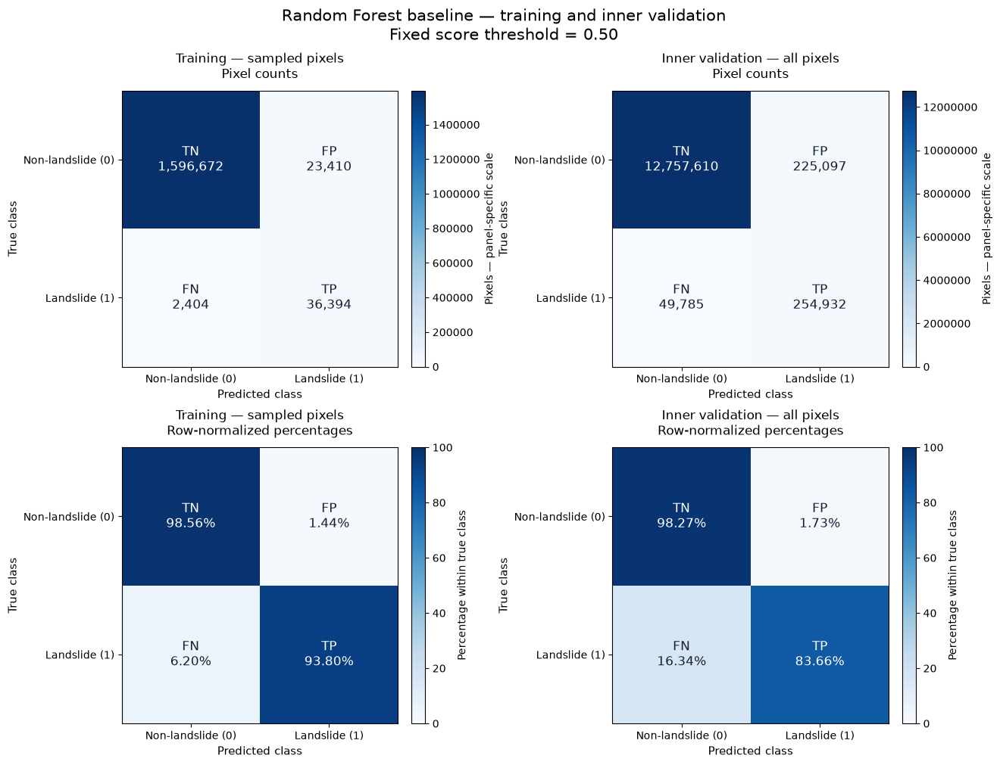

In [9]:
import matplotlib.pyplot as plt
import numpy as np

rf_cm_classes = ["Non-landslide (0)", "Landslide (1)"]
rf_cm_cell_names = np.array([["TN", "FP"], ["FN", "TP"]])

rf_cm_sources = [
    ("Training — sampled pixels", rf_baseline_training_metrics),
    ("Inner validation — all pixels", rf_baseline_validation_metrics)
]

rf_cm_figure, rf_cm_axes = plt.subplots(
    2, 2,
    figsize=(13, 10),
    constrained_layout=True
)

for rf_col, (rf_title, rf_metrics_dict) in enumerate(rf_cm_sources):
    rf_cm = np.array([
        [rf_metrics_dict["TN"], rf_metrics_dict["FP"]],
        [rf_metrics_dict["FN"], rf_metrics_dict["TP"]]
    ], dtype=np.int64)

    rf_row_totals = rf_cm.sum(axis=1, keepdims=True)

    rf_cm_percent = np.divide(
        rf_cm,
        rf_row_totals,
        out=np.zeros_like(rf_cm, dtype=float),
        where=rf_row_totals != 0
    ) * 100

    for rf_row, rf_values in enumerate([rf_cm, rf_cm_percent]):
        rf_ax = rf_cm_axes[rf_row, rf_col]

        # Count panels have individual scales.
        # Percentage panels share the fixed 0–100% scale.
        rf_vmax = float(rf_cm.max()) if rf_row == 0 else 100.0

        rf_image_plot = rf_ax.imshow(
            rf_values,
            cmap="Blues",
            vmin=0,
            vmax=rf_vmax
        )

        rf_ax.set_xticks([0, 1], labels=rf_cm_classes)
        rf_ax.set_yticks([0, 1], labels=rf_cm_classes)
        rf_ax.tick_params(axis="both", labelsize=10)
        rf_ax.set_xlabel("Predicted class", fontsize=11)
        rf_ax.set_ylabel("True class", fontsize=11)

        rf_panel_label = (
            "Pixel counts" if rf_row == 0
            else "Row-normalized percentages"
        )
        rf_ax.set_title(
            f"{rf_title}\n{rf_panel_label}",
            fontsize=12,
            fontweight="normal",
            pad=12
        )

        for rf_i in range(2):
            for rf_j in range(2):
                rf_value = rf_values[rf_i, rf_j]

                rf_value_label = (
                    f"{int(rf_value):,}"
                    if rf_row == 0 else f"{rf_value:.2f}%"
                )

                rf_ax.text(
                    rf_j, rf_i,
                    f"{rf_cm_cell_names[rf_i, rf_j]}\n{rf_value_label}",
                    ha="center",
                    va="center",
                    fontsize=12,
                    color="white" if rf_value > 0.55 * rf_vmax
                    else "#172033"
                )

        rf_colorbar = rf_cm_figure.colorbar(
            rf_image_plot, ax=rf_ax, fraction=0.046, pad=0.04
        )

        if rf_row == 0:
            rf_colorbar.set_label(
                "Pixels — panel-specific scale", fontsize=10
            )
            rf_colorbar.formatter.set_scientific(False)
            rf_colorbar.update_ticks()
        else:
            rf_colorbar.set_label(
                "Percentage within true class", fontsize=10
            )

rf_cm_figure.suptitle(
    "Random Forest baseline — training and inner validation\n"
    f"Fixed score threshold = {rf_baseline_threshold:.2f}",
    fontsize=15,
    fontweight="normal"
)

rf_baseline_figures_dir = rf_validation_cache_dir / "figures"
rf_baseline_figures_dir.mkdir(parents=True, exist_ok=True)

rf_cm_figure.savefig(
    rf_baseline_figures_dir / "baseline_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)
rf_cm_figure.savefig(
    rf_baseline_figures_dir / "baseline_confusion_matrices.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Compare the baseline’s apparent training performance with its first inner-validation performance.
Result: At threshold 0.50, landslide recall declined from 93.80% to 83.66%. Validation missed 49,785 landslide pixels and produced 225,097 false positives; validation precision was 53.11%. These are results from one inner split.

Calculating curves: Training — sampled pixels
Calculating curves: Inner validation — all pixels
ROC and PR curves saved.


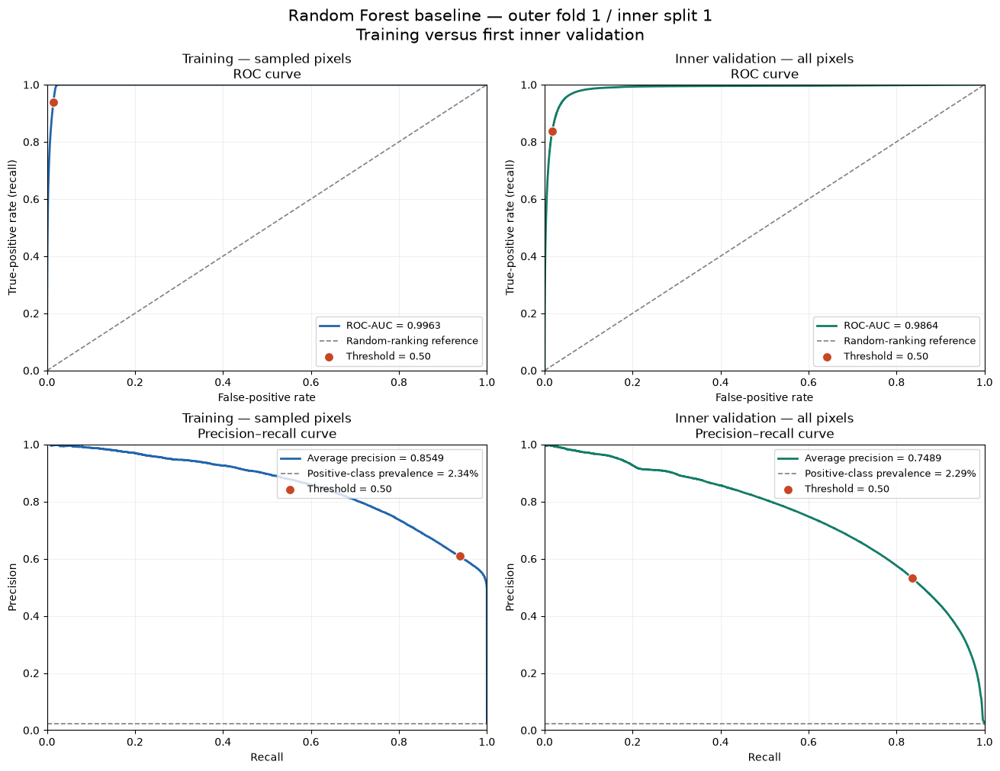

In [10]:
from sklearn.metrics import roc_curve, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np
import joblib

# Verify that previous evaluation objects are available.
rf_required_objects = [
    "rf_y_inner_train",
    "rf_baseline_train_scores",
    "rf_baseline_validation_y",
    "rf_baseline_validation_scores",
    "rf_baseline_training_metrics",
    "rf_baseline_validation_metrics",
    "rf_validation_signature",
    "rf_validation_cache_dir",
    "rf_baseline_figures_dir",
    "rf_baseline_threshold"
]

rf_missing_objects = [
    name for name in rf_required_objects if name not in globals()
]

if rf_missing_objects:
    raise RuntimeError(
        "Previous evaluation objects are missing: "
        + ", ".join(rf_missing_objects)
        + ". Run the earlier cells that load their saved checkpoints."
    )

rf_curve_path = (
    rf_validation_cache_dir / "baseline_roc_pr_curves_v1.joblib"
)

rf_curve_sources = [
    (
        "Training — sampled pixels",
        rf_y_inner_train,
        rf_baseline_train_scores,
        rf_baseline_training_metrics
    ),
    (
        "Inner validation — all pixels",
        rf_baseline_validation_y,
        rf_baseline_validation_scores,
        rf_baseline_validation_metrics
    )
]

if rf_curve_path.is_file():
    rf_curve_bundle = joblib.load(rf_curve_path)

    if rf_curve_bundle["signature"] != rf_validation_signature:
        raise ValueError("Curve checkpoint signature mismatch.")

    rf_baseline_curves = rf_curve_bundle["curves"]
    print("Loaded saved ROC and PR curves.")

else:
    rf_baseline_curves = []

    for rf_title, rf_y, rf_scores, rf_metrics_dict in rf_curve_sources:
        print(f"Calculating curves: {rf_title}", flush=True)

        rf_fpr, rf_tpr, _ = roc_curve(
            rf_y, rf_scores,
            pos_label=1,
            drop_intermediate=True
        )

        # Remove redundant PR points to reduce plotting/storage cost.
        # All pixels are included; no subsampling is performed.
        rf_precision, rf_recall, _ = precision_recall_curve(
            rf_y, rf_scores,
            pos_label=1,
            drop_intermediate=True
        )

        rf_baseline_curves.append({
            "fpr": rf_fpr,
            "tpr": rf_tpr,
            "precision": rf_precision,
            "recall": rf_recall,
            "prevalence": float(np.mean(np.asarray(rf_y) == 1))
        })

    rf_curve_bundle = {
        "signature": rf_validation_signature,
        "curves": rf_baseline_curves
    }

    rf_curve_temporary_path = rf_curve_path.with_suffix(".tmp")
    joblib.dump(rf_curve_bundle, rf_curve_temporary_path)
    rf_curve_temporary_path.replace(rf_curve_path)
    print("ROC and PR curves saved.")


rf_curve_figure, rf_curve_axes = plt.subplots(
    2, 2,
    figsize=(13, 10),
    constrained_layout=True
)

for rf_col, (
    rf_title, rf_y, rf_scores, rf_metrics_dict
) in enumerate(rf_curve_sources):

    rf_curve = rf_baseline_curves[rf_col]
    rf_color = "#2166AC" if rf_col == 0 else "#137C66"

    # ROC: true-positive rate versus false-positive rate.
    rf_ax = rf_curve_axes[0, rf_col]

    rf_ax.plot(
        rf_curve["fpr"], rf_curve["tpr"],
        color=rf_color, linewidth=2,
        label=f"ROC-AUC = {rf_metrics_dict['ROC_AUC']:.4f}"
    )
    rf_ax.plot(
        [0, 1], [0, 1],
        color="gray", linestyle="--", linewidth=1.2,
        label="Random-ranking reference"
    )
    rf_ax.scatter(
        1 - rf_metrics_dict["Specificity"],
        rf_metrics_dict["Recall"],
        s=75, color="#C74724",
        edgecolors="white", linewidths=0.8,
        zorder=5,
        label=f"Threshold = {rf_baseline_threshold:.2f}"
    )

    rf_ax.set(
        xlabel="False-positive rate",
        ylabel="True-positive rate (recall)",
        title=f"{rf_title}\nROC curve",
        xlim=(0, 1),
        ylim=(0, 1)
    )
    rf_ax.legend(loc="lower right", fontsize=9, frameon=True)

    # PR: precision versus recall.
    rf_ax = rf_curve_axes[1, rf_col]

    rf_ax.plot(
        rf_curve["recall"], rf_curve["precision"],
        color=rf_color, linewidth=2,
        label=(
            "Average precision = "
            f"{rf_metrics_dict['Average_precision']:.4f}"
        )
    )
    rf_ax.axhline(
        rf_curve["prevalence"],
        color="gray", linestyle="--", linewidth=1.2,
        label=(
            "Positive-class prevalence = "
            f"{100 * rf_curve['prevalence']:.2f}%"
        )
    )
    rf_ax.scatter(
        rf_metrics_dict["Recall"],
        rf_metrics_dict["Precision"],
        s=75, color="#C74724",
        edgecolors="white", linewidths=0.8,
        zorder=5,
        label=f"Threshold = {rf_baseline_threshold:.2f}"
    )

    rf_ax.set(
        xlabel="Recall",
        ylabel="Precision",
        title=f"{rf_title}\nPrecision–recall curve",
        xlim=(0, 1),
        ylim=(0, 1)
    )
    rf_ax.legend(loc="upper right", fontsize=9, frameon=True)

for rf_ax in rf_curve_axes.flat:
    rf_ax.grid(alpha=0.18)
    rf_ax.tick_params(labelsize=10)
    rf_ax.title.set_fontweight("normal")

rf_curve_figure.suptitle(
    "Random Forest baseline — outer fold 1 / inner split 1\n"
    "Training versus first inner validation",
    fontsize=15,
    fontweight="normal"
)

rf_baseline_figures_dir.mkdir(parents=True, exist_ok=True)

rf_curve_figure.savefig(
    rf_baseline_figures_dir / "baseline_roc_pr_curves.png",
    dpi=200,
    bbox_inches="tight"
)
rf_curve_figure.savefig(
    rf_baseline_figures_dir / "baseline_roc_pr_curves.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Examine baseline ranking performance and the precision–recall trade-off across thresholds.
Result: First inner-validation ROC-AUC was 0.9864 and average precision was 0.7489. At threshold 0.50, recall was 83.66% and precision was 53.11%. Both curves show lower performance than training.

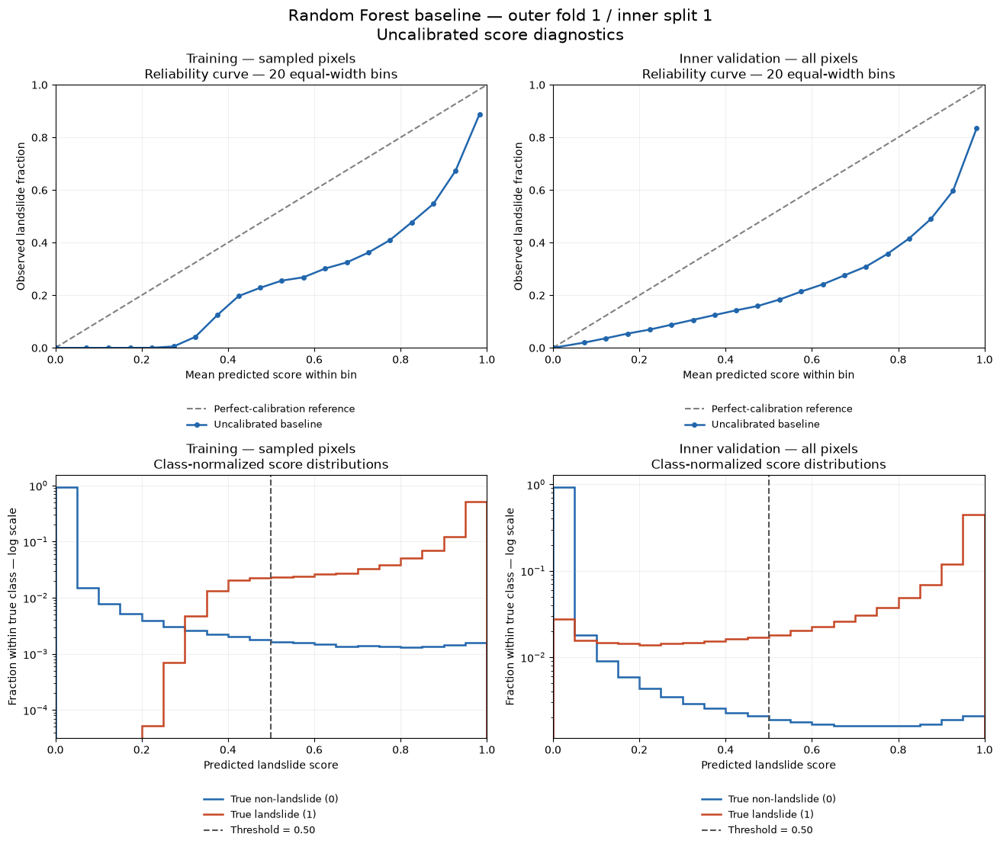

First inner-validation reliability table:


,Bin_lower,Bin_upper,Pixels,Landslide_pixels,Mean_score,Observed_landslide_fraction
0,0.00,0.05,12110084,8388,0.002407,0.000693
1,0.05,0.10,237431,4726,0.072129,0.019905
2,0.10,0.15,121941,4451,0.122808,0.036501
3,0.15,0.20,80893,4399,0.173542,0.054380
4,0.20,0.25,60770,4217,0.223974,0.069393
5,0.25,0.30,49455,4348,0.274132,0.087918
6,0.30,0.35,42404,4507,0.324601,0.106287
7,0.35,0.40,37689,4699,0.374620,0.124678
8,0.40,0.45,34546,4930,0.424650,0.142708
9,0.45,0.50,32182,5120,0.474547,0.159095


['C:\\Users\\hadid\\Ramen\\ds-ml-project-template\\artifacts\\random_forest\\checkpoints\\baseline_validation_d2dc7166fd47856ba4259a3f6e22e876d22bd817c747b0b20b9cb4acea440436\\baseline_score_diagnostics.joblib']

In [11]:
# Diagnostic binning settings, manually chosen.
rf_diagnostic_edges = np.linspace(0, 1, 21)
rf_diagnostic_batch_size = 65536

rf_score_diagnostics = []

for rf_title, rf_y, rf_scores, rf_metrics_dict in rf_curve_sources:
    rf_bin_counts = np.zeros(20, dtype=np.int64)
    rf_bin_positive_counts = np.zeros(20, dtype=np.int64)
    rf_bin_score_sums = np.zeros(20, dtype=np.float64)

    rf_class_histograms = np.zeros((2, 20), dtype=np.int64)

    for rf_start in range(0, len(rf_y), rf_diagnostic_batch_size):
        rf_stop = min(
            rf_start + rf_diagnostic_batch_size, len(rf_y)
        )

        rf_batch_y = np.asarray(rf_y[rf_start:rf_stop])
        rf_batch_scores = np.asarray(rf_scores[rf_start:rf_stop])

        # Score 1.0 belongs to the last bin.
        rf_bin_indices = np.clip(
            np.searchsorted(
                rf_diagnostic_edges,
                rf_batch_scores,
                side="right"
            ) - 1,
            0, 19
        )

        rf_bin_counts += np.bincount(
            rf_bin_indices, minlength=20
        )
        rf_bin_positive_counts += np.bincount(
            rf_bin_indices[rf_batch_y == 1], minlength=20
        )
        rf_bin_score_sums += np.bincount(
            rf_bin_indices,
            weights=rf_batch_scores,
            minlength=20
        )

        for rf_class in (0, 1):
            rf_class_histograms[rf_class] += np.bincount(
                rf_bin_indices[rf_batch_y == rf_class],
                minlength=20
            )

    rf_nonempty_bins = rf_bin_counts > 0

    rf_mean_scores = np.divide(
        rf_bin_score_sums,
        rf_bin_counts,
        out=np.full(20, np.nan),
        where=rf_nonempty_bins
    )
    rf_observed_fractions = np.divide(
        rf_bin_positive_counts,
        rf_bin_counts,
        out=np.full(20, np.nan),
        where=rf_nonempty_bins
    )

    rf_reliability_table = pd.DataFrame({
        "Bin_lower": rf_diagnostic_edges[:-1],
        "Bin_upper": rf_diagnostic_edges[1:],
        "Pixels": rf_bin_counts,
        "Landslide_pixels": rf_bin_positive_counts,
        "Mean_score": rf_mean_scores,
        "Observed_landslide_fraction": rf_observed_fractions
    })

    rf_score_diagnostics.append({
        "title": rf_title,
        "reliability": rf_reliability_table,
        "class_histograms": rf_class_histograms
    })


rf_diagnostic_figure, rf_diagnostic_axes = plt.subplots(
    2, 2, figsize=(13, 11), constrained_layout=True
)

for rf_col, rf_diagnostic in enumerate(rf_score_diagnostics):
    rf_table = rf_diagnostic["reliability"]

    # Reliability curve: predicted score versus observed frequency.
    rf_ax = rf_diagnostic_axes[0, rf_col]

    rf_ax.plot(
        [0, 1], [0, 1],
        linestyle="--", color="gray",
        label="Perfect-calibration reference"
    )
    rf_ax.plot(
        rf_table["Mean_score"],
        rf_table["Observed_landslide_fraction"],
        marker="o", markersize=4,
        linewidth=1.8, color="#2166AC",
        label="Uncalibrated baseline"
    )
    rf_ax.set(
        xlabel="Mean predicted score within bin",
        ylabel="Observed landslide fraction",
        title=f"{rf_diagnostic['title']}\nReliability curve — 20 equal-width bins",
        xlim=(0, 1),
        ylim=(0, 1)
    )
    rf_ax.legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.18),
        fontsize=9, frameon=False
    )

    # Normalize separately within each true class.
    rf_ax = rf_diagnostic_axes[1, rf_col]

    for rf_class, rf_label, rf_color in [
        (0, "True non-landslide (0)", "#2166AC"),
        (1, "True landslide (1)", "#C74724")
    ]:
        rf_counts = rf_diagnostic["class_histograms"][rf_class]
        rf_fractions = rf_counts / rf_counts.sum()

        rf_ax.stairs(
            rf_fractions,
            rf_diagnostic_edges,
            color=rf_color,
            linewidth=1.8,
            label=rf_label
        )

    rf_ax.axvline(
        rf_baseline_threshold,
        linestyle="--", color="#555555",
        label=f"Threshold = {rf_baseline_threshold:.2f}"
    )
    rf_ax.set_yscale("log")
    rf_ax.set(
        xlabel="Predicted landslide score",
        ylabel="Fraction within true class — log scale",
        title=f"{rf_diagnostic['title']}\nClass-normalized score distributions",
        xlim=(0, 1)
    )
    rf_ax.legend(
        loc="upper center", bbox_to_anchor=(0.5, -0.18),
        fontsize=9, frameon=False
    )

for rf_ax in rf_diagnostic_axes.flat:
    rf_ax.grid(alpha=0.18)
    rf_ax.tick_params(labelsize=10)
    rf_ax.title.set_fontweight("normal")

rf_diagnostic_figure.suptitle(
    "Random Forest baseline — outer fold 1 / inner split 1\n"
    "Uncalibrated score diagnostics",
    fontsize=15,
    fontweight="normal"
)

rf_diagnostic_figure.savefig(
    rf_baseline_figures_dir / "baseline_score_diagnostics.png",
    dpi=200, bbox_inches="tight"
)
rf_diagnostic_figure.savefig(
    rf_baseline_figures_dir / "baseline_score_diagnostics.pdf",
    bbox_inches="tight"
)

plt.show()

print("First inner-validation reliability table:")
display(rf_score_diagnostics[1]["reliability"].round(6))

joblib.dump(
    {
        "signature": rf_validation_signature,
        "bin_edges": rf_diagnostic_edges,
        "diagnostics": rf_score_diagnostics
    },
    rf_validation_cache_dir / "baseline_score_diagnostics.joblib"
)

Rationale: Check the calibration and class-score distributions of the uncalibrated Random Forest baseline on training data and the first inner-validation split.

Result: The reliability curves show that raw scores overestimate observed landslide frequencies. The validation table confirms this in all 20 bins: for example, a mean score of 0.8256 corresponds to an observed landslide fraction of 0.4162. Score distributions show separation between classes, but also overlap producing false negatives and false positives at threshold 0.50. These scores should not be interpreted as calibrated probabilities.

In [12]:
print("Saved selection settings")
print("------------------------")
print("Random seed:", RANDOM_STATE)
print("F-beta:", BETA)
print("Calibration fraction:", CALIBRATION_FRACTION)
print("Platt C:", PLATT_C)

rf_saved_thresholds = np.asarray(THRESHOLDS, dtype=float)

print("\nThreshold grid:")
print(rf_saved_thresholds)
print("Number of thresholds:", rf_saved_thresholds.size)

assert rf_saved_thresholds.ndim == 1
assert np.isfinite(rf_saved_thresholds).all()
assert np.all(
    (rf_saved_thresholds >= 0) & (rf_saved_thresholds <= 1)
)
assert np.all(np.diff(rf_saved_thresholds) > 0)


def rf_show_saved_structure(obj, label, depth=0):
    """Inspect keys and sizes without printing large arrays."""
    prefix = "  " * depth
    print(f"{prefix}{label}: {type(obj).__name__}")

    if isinstance(obj, dict):
        print(f"{prefix}Keys: {list(obj.keys())}")

        if depth < 3:
            for key, value in obj.items():
                if isinstance(value, (dict, list, tuple)):
                    if depth == 0:
                        # Inspect only the first outer-fold entry.
                        rf_show_saved_structure(value, str(key), depth + 1)
                        break
                    rf_show_saved_structure(value, str(key), depth + 1)
                else:
                    shape = getattr(value, "shape", None)
                    if shape is not None:
                        print(f"{prefix}  {key}: shape={shape}")
                    else:
                        print(f"{prefix}  {key}: {value}")

    elif isinstance(obj, (list, tuple)):
        print(f"{prefix}Length: {len(obj)}")
        if len(obj) and depth < 3:
            rf_show_saved_structure(obj[0], "First entry", depth + 1)


print("\nSaved calibration-split structure:")
rf_show_saved_structure(
    dt_calibration_splits_by_outer,
    "dt_calibration_splits_by_outer"
)

Saved selection settings
------------------------
Random seed: 43
F-beta: 2
Calibration fraction: 0.2
Platt C: 1000000.0

Threshold grid:
[0.001 0.005 0.01  0.02  0.03  0.04  0.05  0.06  0.07  0.08  0.09  0.1
 0.11  0.12  0.13  0.14  0.15  0.16  0.17  0.18  0.19  0.2   0.21  0.22
 0.23  0.24  0.25  0.26  0.27  0.28  0.29  0.3   0.31  0.32  0.33  0.34
 0.35  0.36  0.37  0.38  0.39  0.4   0.41  0.42  0.43  0.44  0.45  0.46
 0.47  0.48  0.49  0.5   0.51  0.52  0.53  0.54  0.55  0.56  0.57  0.58
 0.59  0.6   0.61  0.62  0.63  0.64  0.65  0.66  0.67  0.68  0.69  0.7
 0.71  0.72  0.73  0.74  0.75  0.76  0.77  0.78  0.79  0.8   0.81  0.82
 0.83  0.84  0.85  0.86  0.87  0.88  0.89  0.9   0.91  0.92  0.93  0.94
 0.95  0.96  0.97  0.98  0.99 ]
Number of thresholds: 101

Saved calibration-split structure:
dt_calibration_splits_by_outer: dict
Keys: [1, 2, 3, 4, 5]
  1: list
  Length: 3
    First entry: dict
    Keys: ['inner_fold', 'train_ids', 'fit_ids', 'calibration_ids', 'validation_ids']
     

Rationale: Inspect the restored threshold grid and calibration allocation before configuring RF selection.
Result: The saved protocol contains 101 thresholds and a 20% calibration allocation. The first inner split contains 1,296 fitting, 324 calibration and 811 validation images. These counts confirm the allocation sizes; full split-separation checks remain necessary.

In [13]:
from sklearn.model_selection import ParameterSampler
from collections import Counter

# Validate all restored nested and calibration splits.
def rf_checked_id_set(values):
    ids = np.asarray(values).astype(str).reshape(-1).tolist()
    if len(ids) != len(set(ids)):
        raise ValueError("Duplicate image IDs found in a saved split.")
    return set(ids)


rf_development_set = rf_checked_id_set(dev_ids)
rf_holdout_set = rf_checked_id_set(test_ids)
rf_outer_evaluation_coverage = Counter()

assert rf_development_set.isdisjoint(rf_holdout_set)
assert len(nested_splits) == 5

for rf_outer in nested_splits:
    rf_fold_number = int(rf_outer["outer_fold"])

    rf_outer_train_set = rf_checked_id_set(rf_outer["train_ids"])
    rf_outer_eval_set = rf_checked_id_set(rf_outer["evaluation_ids"])

    assert rf_outer_train_set.isdisjoint(rf_outer_eval_set)
    assert rf_outer_train_set | rf_outer_eval_set == rf_development_set

    rf_outer_evaluation_coverage.update(rf_outer_eval_set)

    rf_calibration_splits = dt_calibration_splits_by_outer[rf_fold_number]

    assert len(rf_outer["inner_splits"]) == 3
    assert len(rf_calibration_splits) == 3

    rf_inner_validation_coverage = Counter()

    for rf_inner, rf_calibration in zip(
        rf_outer["inner_splits"], rf_calibration_splits
    ):
        rf_train_set = rf_checked_id_set(rf_inner["train_ids"])
        rf_validation_set = rf_checked_id_set(
            rf_inner["validation_ids"]
        )
        rf_fit_set = rf_checked_id_set(rf_calibration["fit_ids"])
        rf_cal_set = rf_checked_id_set(
            rf_calibration["calibration_ids"]
        )

        assert rf_train_set.isdisjoint(rf_validation_set)
        assert rf_train_set | rf_validation_set == rf_outer_train_set

        assert rf_checked_id_set(
            rf_calibration["train_ids"]
        ) == rf_train_set
        assert rf_checked_id_set(
            rf_calibration["validation_ids"]
        ) == rf_validation_set

        assert rf_fit_set.isdisjoint(rf_cal_set)
        assert rf_fit_set | rf_cal_set == rf_train_set

        rf_inner_validation_coverage.update(rf_validation_set)

    assert set(rf_inner_validation_coverage) == rf_outer_train_set
    assert all(
        count == 1 for count in rf_inner_validation_coverage.values()
    )

assert set(rf_outer_evaluation_coverage) == rf_development_set
assert all(count == 1 for count in rf_outer_evaluation_coverage.values())

print("PASSED: all 5 outer folds and 15 inner splits.")
print("PASSED: calibration separation and validation coverage.")


# Fixed settings for this initial search stage.
rf_search_fixed_params = {
    "n_estimators": 100,
    "bootstrap": True,
    "ccp_alpha": 0.0,
    "oob_score": False,
    "random_state": int(RANDOM_STATE),
    "n_jobs": 2
}

rf_reference_settings = {
    "max_depth": 20,
    "min_samples_leaf": 2,
    "min_samples_split": 2,
    "max_features": "sqrt",
    "max_samples": 0.5,
    "criterion": "gini"
}

rf_search_candidates = []

# Controlled comparison: change only class_weight.
for rf_weight in (None, "balanced", "balanced_subsample"):
    rf_search_candidates.append({
        **rf_search_fixed_params,
        **rf_reference_settings,
        "class_weight": rf_weight
    })

rf_search_space = {
    "max_depth": [12, 20, 30],
    "min_samples_leaf": [1, 2, 5, 10],
    "min_samples_split": [2, 10],
    "max_features": ["sqrt", 0.5],
    "max_samples": [0.5, 0.8],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "criterion": ["gini", "entropy"]
}

# Generate a reproducible pool, keeping five distinct random candidates.
rf_random_pool = ParameterSampler(
    rf_search_space,
    n_iter=30,
    random_state=int(RANDOM_STATE)
)

for rf_random_settings in rf_random_pool:
    rf_candidate = {
        **rf_search_fixed_params,
        **rf_random_settings
    }

    if rf_candidate not in rf_search_candidates:
        rf_search_candidates.append(rf_candidate)

    if len(rf_search_candidates) == 8:
        break

assert len(rf_search_candidates) == 8

rf_search_candidate_table = pd.DataFrame([
    {
        "Candidate": index + 1,
        "Source": "Controlled reference" if index < 3 else "Random",
        **candidate
    }
    for index, candidate in enumerate(rf_search_candidates)
])

display(rf_search_candidate_table)

rf_initial_search_fits = len(rf_search_candidates) * 3 * 5
rf_reference_workload_hours = (
    rf_initial_search_fits
    * (
        rf_baseline_fit_seconds
        + rf_validation_prediction_seconds
    )
    / 3600
)

print("Initial search fits across five outer folds:", rf_initial_search_fits)
print(
    "Baseline-equivalent fit + prediction workload: "
    f"{rf_reference_workload_hours:.2f} hours"
)
print("Excludes I/O, metric calculations and later selection stages.")
print("No search models have been fitted by this cell.")

PASSED: all 5 outer folds and 15 inner splits.
PASSED: calibration separation and validation coverage.


,Candidate,Source,n_estimators,bootstrap,ccp_alpha,oob_score,random_state,n_jobs,max_depth,min_samples_leaf,min_samples_split,max_features,max_samples,criterion,class_weight
0,1,Controlled reference,100,True,0.0,False,43,2,20,2,2,sqrt,0.5,gini,NaN
1,2,Controlled reference,100,True,0.0,False,43,2,20,2,2,sqrt,0.5,gini,balanced
2,3,Controlled reference,100,True,0.0,False,43,2,20,2,2,sqrt,0.5,gini,balanced_subsample
3,4,Random,100,True,0.0,False,43,2,12,10,2,0.5,0.5,gini,balanced
4,5,Random,100,True,0.0,False,43,2,20,1,10,0.5,0.5,entropy,balanced
5,6,Random,100,True,0.0,False,43,2,20,2,10,sqrt,0.5,gini,NaN
6,7,Random,100,True,0.0,False,43,2,20,10,10,sqrt,0.8,gini,NaN
7,8,Random,100,True,0.0,False,43,2,20,1,10,0.5,0.5,entropy,NaN


Initial search fits across five outer folds: 120
Baseline-equivalent fit + prediction workload: 8.54 hours
Excludes I/O, metric calculations and later selection stages.
No search models have been fitted by this cell.


Rationale: Validate split integrity and define a reproducible initial RF search.
Result: All five outer folds and 15 inner splits passed the checks. Eight candidates were generated; none were fitted by this cell. The nominal workload is 120 fits.

In [14]:
def rf_threshold_metrics(y_true, scores, thresholds, beta=2):
    """Evaluate all thresholds using batched score-bin counts."""
    y_true = np.asarray(y_true).reshape(-1)
    scores = np.asarray(scores).reshape(-1)
    thresholds = np.asarray(thresholds, dtype=float)

    if y_true.size != scores.size:
        raise ValueError("Labels and scores have different lengths.")

    if (
        thresholds.ndim != 1
        or thresholds.size == 0
        or not np.isfinite(thresholds).all()
        or not np.all(np.diff(thresholds) > 0)
    ):
        raise ValueError("Thresholds must be finite and strictly increasing.")

    positive_bins = np.zeros(len(thresholds) + 1, dtype=np.int64)
    negative_bins = np.zeros(len(thresholds) + 1, dtype=np.int64)

    for start in range(0, y_true.size, 65536):
        batch_y = y_true[start:start + 65536]
        batch_scores = scores[start:start + 65536]

        if not np.isin(batch_y, [0, 1]).all():
            raise ValueError("Labels must be binary.")
        if (
            not np.isfinite(batch_scores).all()
            or np.any((batch_scores < 0) | (batch_scores > 1))
        ):
            raise ValueError("Invalid scores.")

        # side="right" preserves the rule: score >= threshold.
        bins = np.searchsorted(
            thresholds, batch_scores, side="right"
        )

        positive_bins += np.bincount(
            bins[batch_y == 1], minlength=len(thresholds) + 1
        )
        negative_bins += np.bincount(
            bins[batch_y == 0], minlength=len(thresholds) + 1
        )

    fn = np.cumsum(positive_bins)[:-1]
    tn = np.cumsum(negative_bins)[:-1]
    tp = positive_bins.sum() - fn
    fp = negative_bins.sum() - tn

    def safe_divide(numerator, denominator):
        return np.divide(
            numerator,
            denominator,
            out=np.zeros_like(denominator, dtype=float),
            where=denominator != 0
        )

    beta_squared = float(beta) ** 2

    table = pd.DataFrame({
        "Threshold": thresholds,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "F2": safe_divide(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "Precision": safe_divide(tp, tp + fp),
        "Recall": safe_divide(tp, tp + fn),
        "Specificity": safe_divide(tn, tn + fp),
        "IoU": safe_divide(tp, tp + fp + fn)
    })

    if positive_bins.sum() == 0:
        table["Recall"] = np.nan
    if negative_bins.sum() == 0:
        table["Specificity"] = np.nan

    return table


# Check the new function against the existing baseline evaluation.
rf_baseline_threshold_check = rf_threshold_metrics(
    rf_baseline_validation_y,
    rf_baseline_validation_scores,
    rf_saved_thresholds,
    beta=float(BETA)
)

rf_half_threshold_row = rf_baseline_threshold_check.loc[
    np.isclose(
        rf_baseline_threshold_check["Threshold"],
        rf_baseline_threshold,
        rtol=0,
        atol=1e-12
    )
]

assert len(rf_half_threshold_row) == 1
rf_half_threshold_row = rf_half_threshold_row.iloc[0]

for rf_metric_name in ["TN", "FP", "FN", "TP"]:
    assert int(rf_half_threshold_row[rf_metric_name]) == int(
        rf_baseline_validation_metrics[rf_metric_name]
    )

for rf_metric_name in [
    "F2", "Precision", "Recall", "Specificity", "IoU"
]:
    assert np.isclose(
        rf_half_threshold_row[rf_metric_name],
        rf_baseline_validation_metrics[rf_metric_name],
        rtol=0,
        atol=1e-12
    )

print("Thresholds evaluated:", len(rf_baseline_threshold_check))
print("PASSED: counts and metrics at 0.50 match the saved baseline.")
print("No new models were trained.")
print("\nBaseline consistency check — first inner validation:")
display(rf_half_threshold_row.to_frame("Value"))

Thresholds evaluated: 101
PASSED: counts and metrics at 0.50 match the saved baseline.
No new models were trained.

Baseline consistency check — first inner validation:


,Value
Threshold,5.000000e-01
TN,1.275761e+07
FP,2.250970e+05
FN,4.978500e+04
TP,2.549320e+05
F2,7.502868e-01
Precision,5.310762e-01
Recall,8.366189e-01
Specificity,9.826618e-01
IoU,4.811726e-01


Rationale: Verify the threshold-evaluation function against saved baseline results.
Result: All counts and checked metrics at threshold 0.50 matched the previous first inner-validation evaluation. No new models were trained or final threshold selected.

In [15]:
import platform

# Recreate the exact training table for outer fold 1 / inner split 1.
rf_search_outer_1 = nested_splits[0]
rf_search_inner_1 = rf_search_outer_1["inner_splits"][0]

rf_search_training_ids = np.asarray(
    rf_search_inner_1["train_ids"]
).astype(str)

rf_search_X, rf_search_y = rf_get_sampled_training_data(
    image_ids=rf_search_training_ids,
    sampled_patch_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples
)

# Hash the actual ordered training arrays.
rf_search_data_hasher = hashlib.sha256()

for rf_array in (rf_search_X, rf_search_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_search_data_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

rf_search_training_data_hash = rf_search_data_hasher.hexdigest()

rf_search_model_dir = (
    rf_checkpoint_dir / "initial_search" / "outer_1" / "inner_1"
)
rf_search_model_dir.mkdir(parents=True, exist_ok=True)

# Verify the original baseline against the current training arrays.
rf_baseline_check_hasher = hashlib.sha256(
    json.dumps(rf_baseline_metadata, sort_keys=True).encode("utf-8")
)

for rf_array in (rf_search_X, rf_search_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_baseline_check_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

assert (
    rf_search_training_ids.tolist()
    == rf_baseline_metadata["training_ids"]
)
assert rf_baseline_check_hasher.hexdigest() == rf_baseline_signature

rf_search_model_records = []
rf_search_fit_records = []

for rf_candidate_number, rf_params in enumerate(
    rf_search_candidates, start=1
):
    rf_model_metadata = {
        "stage": "initial_uncalibrated_search",
        "outer_fold": int(rf_search_outer_1["outer_fold"]),
        "inner_split": 1,
        "params": rf_params,
        "ordered_training_ids": rf_search_training_ids.tolist(),
        "training_data_hash": rf_search_training_data_hash,
        "X_shape": list(rf_search_X.shape),
        "X_dtype": str(rf_search_X.dtype),
        "y_dtype": str(rf_search_y.dtype),
        "features": list(FEATURE_NAMES),
        "python_version": platform.python_version(),
        "numpy_version": np.__version__,
        "sklearn_version": sklearn.__version__
    }

    rf_model_signature = hashlib.sha256(
        json.dumps(
            rf_model_metadata,
            sort_keys=True,
            default=lambda value: value.item()
        ).encode("utf-8")
    ).hexdigest()

    rf_model_path = (
        rf_search_model_dir / f"model_{rf_model_signature}.joblib"
    )

    print(
        f"\nCandidate {rf_candidate_number}/"
        f"{len(rf_search_candidates)}",
        flush=True
    )

    if rf_model_path.is_file():
        rf_model_bundle = joblib.load(rf_model_path)

        if rf_model_bundle["signature"] != rf_model_signature:
            raise ValueError("Search-model checkpoint mismatch.")

        rf_fit_status = "Loaded search checkpoint"

    else:
        # Reuse the verified baseline when all parameters match.
        if rf_params == rf_baseline_metadata["params"]:
            rf_verified_baseline = joblib.load(rf_baseline_path)

            if (
                rf_verified_baseline["signature"]
                != rf_baseline_signature
            ):
                raise ValueError("Original baseline checkpoint mismatch.")

            rf_candidate_model = rf_verified_baseline["model"]

            if rf_candidate_model.get_params() != (
                RandomForestClassifier(**rf_params).get_params()
            ):
                raise ValueError("Baseline model parameters do not match.")

            rf_candidate_fit_seconds = rf_verified_baseline["fit_seconds"]
            rf_fit_status = "Reused verified baseline"

        else:
            rf_candidate_model = RandomForestClassifier(**rf_params)

            print("Fitting...", flush=True)
            rf_fit_start = perf_counter()

            rf_candidate_model.fit(rf_search_X, rf_search_y)

            rf_candidate_fit_seconds = perf_counter() - rf_fit_start
            rf_fit_status = "New model fitted"

        rf_model_bundle = {
            "signature": rf_model_signature,
            "metadata": rf_model_metadata,
            "model": rf_candidate_model,
            "fit_seconds": rf_candidate_fit_seconds
        }

        rf_model_temporary_path = rf_model_path.with_suffix(".tmp")
        joblib.dump(rf_model_bundle, rf_model_temporary_path)
        rf_model_temporary_path.replace(rf_model_path)

        del rf_candidate_model

    rf_search_model_records.append({
        "candidate": rf_candidate_number,
        "signature": rf_model_signature,
        "model_path": str(rf_model_path),
        "params": dict(rf_params)
    })

    rf_search_fit_records.append({
        "Candidate": rf_candidate_number,
        "Trees": len(rf_model_bundle["model"].estimators_),
        "Original_fit_seconds": rf_model_bundle["fit_seconds"],
        "Status": rf_fit_status
    })

    print(
        f"{rf_fit_status}; original fitting time: "
        f"{rf_model_bundle['fit_seconds']:.2f} seconds",
        flush=True
    )

    # Keep checkpoints and records rather than all forests in memory.
    del rf_model_bundle

rf_search_first_inner_fit_table = pd.DataFrame(rf_search_fit_records)

rf_search_first_inner_fit_table.to_csv(
    rf_search_model_dir / "fitting_summary.csv", index=False
)

joblib.dump(
    rf_search_model_records,
    rf_search_model_dir / "model_records.joblib"
)

display(rf_search_first_inner_fit_table.round(2))

print("\nScope: outer fold 1 / inner split 1.")
print("This cell fits or restores models; it does not evaluate candidates.")
print("Candidate ranking requires all three inner-validation splits.")


Candidate 1/8
Fitting...
New model fitted; original fitting time: 203.65 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 74.48 seconds

Candidate 3/8
Reused verified baseline; original fitting time: 213.09 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 115.99 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 115.01 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 102.34 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 144.63 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 151.12 seconds


,Candidate,Trees,Original_fit_seconds,Status
0,1,100,203.65,New model fitted
1,2,100,74.48,New model fitted
2,3,100,213.09,Reused verified baseline
3,4,100,115.99,New model fitted
4,5,100,115.01,New model fitted
5,6,100,102.34,New model fitted
6,7,100,144.63,New model fitted
7,8,100,151.12,New model fitted



Scope: outer fold 1 / inner split 1.
This cell fits or restores models; it does not evaluate candidates.
Candidate ranking requires all three inner-validation splits.


Rationale: Fit the initial candidate configurations while reusing the verified baseline.
Result: All eight candidates are available for outer fold 1 / inner split 1. Seven new fits took 907.22 seconds in total; candidate 3 reused the baseline. Candidate performance has not yet been compared.

In [16]:
# Confirm that we are evaluating exactly the first inner-validation split.
rf_expected_validation_ids = sorted(
    np.asarray(
        nested_splits[0]["inner_splits"][0]["validation_ids"]
    ).astype(str).tolist(),
    key=int
)

assert rf_expected_validation_ids == rf_baseline_validation_ids
assert [item[0] for item in rf_validation_sources] == (
    rf_expected_validation_ids
)
assert len(rf_search_model_records) == 8

# Verify that the original source files have not changed.
for rf_source_record in rf_validation_metadata["sources"]:
    for rf_file_record in rf_source_record["files"]:
        rf_path = Path(rf_file_record["path"])
        rf_stat = rf_path.stat()

        if (
            rf_stat.st_size != rf_file_record["size"]
            or rf_stat.st_mtime_ns != rf_file_record["mtime_ns"]
        ):
            raise ValueError(f"Source file changed: {rf_path}")

rf_search_eval_dir = rf_search_model_dir / "validation"
rf_search_eval_dir.mkdir(parents=True, exist_ok=True)

# Shared labels follow the verified numeric image-ID order.
rf_search_validation_labels = rf_baseline_validation_y.reshape(
    len(rf_expected_validation_ids), 128 * 128
)

rf_shared_labels_path = rf_search_eval_dir / "shared_labels.joblib"

if not rf_shared_labels_path.is_file():
    joblib.dump(
        {
            "source_signature": rf_validation_signature,
            "image_ids": rf_expected_validation_ids,
            "labels": rf_search_validation_labels
        },
        rf_shared_labels_path
    )
else:
    rf_saved_labels = joblib.load(rf_shared_labels_path)
    assert rf_saved_labels["source_signature"] == rf_validation_signature
    assert rf_saved_labels["image_ids"] == rf_expected_validation_ids
    assert np.array_equal(
        rf_saved_labels["labels"], rf_search_validation_labels
    )
    del rf_saved_labels

rf_search_first_inner_results = []
rf_search_first_inner_threshold_tables = {}

for rf_record in rf_search_model_records:
    rf_candidate_number = rf_record["candidate"]

    rf_eval_metadata = {
        "model_signature": rf_record["signature"],
        "validation_source_signature": rf_validation_signature,
        "ordered_image_ids": rf_expected_validation_ids,
        "thresholds": rf_saved_thresholds.tolist(),
        "baseline_threshold": rf_baseline_threshold,
        "beta": float(BETA),
        "log_loss_epsilon": float(rf_log_loss_epsilon),
        "evaluation_code_version": 1
    }

    rf_eval_signature = hashlib.sha256(
        json.dumps(rf_eval_metadata, sort_keys=True).encode("utf-8")
    ).hexdigest()

    rf_candidate_eval_dir = rf_search_eval_dir / rf_eval_signature
    rf_candidate_eval_dir.mkdir(parents=True, exist_ok=True)
    rf_result_path = rf_candidate_eval_dir / "evaluation.joblib"

    print(f"\nCandidate {rf_candidate_number}/8", flush=True)

    if rf_result_path.is_file():
        rf_evaluation = joblib.load(rf_result_path)
        assert rf_evaluation["signature"] == rf_eval_signature
        print("Loaded completed evaluation.", flush=True)

    else:
        rf_bundle = joblib.load(rf_record["model_path"])
        assert rf_bundle["signature"] == rf_record["signature"]
        assert (
            rf_bundle["metadata"]["ordered_training_ids"]
            == rf_search_training_ids.tolist()
        )

        rf_model = rf_bundle["model"]
        rf_positive_column = np.flatnonzero(
            rf_model.classes_ == 1
        ).item()

        rf_reuse_baseline_scores = (
            rf_record["params"] == rf_baseline_metadata["params"]
            and rf_bundle["metadata"]["ordered_training_ids"]
            == rf_baseline_metadata["training_ids"]
        )

        rf_prediction_files = []

        if rf_reuse_baseline_scores:
            rf_candidate_scores = rf_baseline_validation_scores
            rf_candidate_prediction_seconds = (
                rf_validation_prediction_seconds
            )
            rf_prediction_origin = "Verified baseline predictions"
            print("Reusing baseline validation scores.", flush=True)

        else:
            rf_score_parts = []
            rf_candidate_prediction_seconds = 0.0

            for rf_start in range(0, len(rf_validation_sources), 25):
                rf_sources = rf_validation_sources[rf_start:rf_start + 25]
                rf_ids = [item[0] for item in rf_sources]
                rf_chunk_path = (
                    rf_candidate_eval_dir
                    / f"scores_{rf_start:04d}.joblib"
                )

                if rf_chunk_path.is_file():
                    rf_chunk = joblib.load(rf_chunk_path)
                    assert rf_chunk["signature"] == rf_eval_signature
                    assert rf_chunk["image_ids"] == rf_ids

                else:
                    rf_chunk_scores = []
                    rf_chunk_prediction_seconds = 0.0

                    for rf_image_id, rf_image_path, _ in rf_sources:
                        with h5py.File(rf_image_path, "r") as rf_file:
                            rf_image = np.asarray(rf_file["img"])

                        if (
                            rf_image.shape != (128, 128, 14)
                            or not np.isfinite(rf_image).all()
                        ):
                            raise ValueError(
                                f"Invalid image: {rf_image_id}"
                            )

                        rf_start_time = perf_counter()
                        rf_scores = rf_model.predict_proba(
                            rf_image.reshape(-1, 14)
                        )[:, rf_positive_column]

                        rf_chunk_prediction_seconds += (
                            perf_counter() - rf_start_time
                        )
                        rf_chunk_scores.append(rf_scores)

                    rf_chunk = {
                        "signature": rf_eval_signature,
                        "image_ids": rf_ids,
                        "scores": np.stack(rf_chunk_scores),
                        "prediction_seconds": rf_chunk_prediction_seconds
                    }

                    rf_temp = rf_chunk_path.with_suffix(".tmp")
                    joblib.dump(rf_chunk, rf_temp)
                    rf_temp.replace(rf_chunk_path)

                assert rf_chunk["scores"].shape == (
                    len(rf_ids), 128 * 128
                )

                rf_score_parts.append(rf_chunk["scores"])
                rf_candidate_prediction_seconds += (
                    rf_chunk["prediction_seconds"]
                )
                rf_prediction_files.append(str(rf_chunk_path))

                print(
                    f"  {rf_start + len(rf_ids)}/"
                    f"{len(rf_validation_sources)} images",
                    flush=True
                )

            rf_candidate_scores = np.concatenate(
                rf_score_parts
            ).reshape(-1)

            del rf_score_parts
            rf_prediction_origin = "Candidate prediction checkpoints"

        print("Calculating metrics and all thresholds...", flush=True)

        rf_candidate_metrics = rf_binary_metrics(
            rf_baseline_validation_y,
            rf_candidate_scores,
            threshold=rf_baseline_threshold,
            beta=float(BETA),
            log_loss_epsilon=rf_log_loss_epsilon
        )

        rf_candidate_threshold_table = rf_threshold_metrics(
            rf_baseline_validation_y,
            rf_candidate_scores,
            rf_saved_thresholds,
            beta=float(BETA)
        )

        # Cross-check the two calculation methods at threshold 0.50.
        rf_check_row = rf_candidate_threshold_table.loc[
            np.isclose(
                rf_candidate_threshold_table["Threshold"],
                rf_baseline_threshold,
                rtol=0, atol=1e-12
            )
        ].iloc[0]

        for rf_name in ["TN", "FP", "FN", "TP"]:
            assert int(rf_check_row[rf_name]) == int(
                rf_candidate_metrics[rf_name]
            )

        assert np.isclose(
            rf_check_row["F2"],
            rf_candidate_metrics["F2"],
            rtol=0, atol=1e-12
        )

        rf_evaluation = {
            "signature": rf_eval_signature,
            "metadata": rf_eval_metadata,
            "candidate": rf_candidate_number,
            "metrics_at_050": rf_candidate_metrics,
            "threshold_table": rf_candidate_threshold_table,
            "prediction_seconds": rf_candidate_prediction_seconds,
            "fit_seconds": rf_bundle["fit_seconds"],
            "prediction_origin": rf_prediction_origin,
            "prediction_files": rf_prediction_files,
            "baseline_scores_checkpoint": (
                str(rf_validation_cache_dir)
                if rf_reuse_baseline_scores else None
            ),
            "shared_labels_path": str(rf_shared_labels_path)
        }

        rf_temp = rf_result_path.with_suffix(".tmp")
        joblib.dump(rf_evaluation, rf_temp)
        rf_temp.replace(rf_result_path)

        del rf_candidate_scores, rf_model, rf_bundle

    rf_search_first_inner_threshold_tables[rf_candidate_number] = (
        rf_evaluation["threshold_table"]
    )

    rf_search_first_inner_results.append({
        "Candidate": rf_candidate_number,
        **rf_evaluation["metrics_at_050"],
        "Fit_seconds": rf_evaluation["fit_seconds"],
        "Prediction_seconds": rf_evaluation["prediction_seconds"],
        "Evaluation_path": str(rf_result_path)
    })

    print("Evaluation available and saved.", flush=True)

rf_search_first_inner_table = pd.DataFrame(
    rf_search_first_inner_results
)

rf_search_first_inner_table.to_csv(
    rf_search_eval_dir / "candidate_metrics_at_050.csv",
    index=False
)

rf_display_columns = [
    "Candidate", "Threshold",
    "F2", "Precision", "Recall", "Specificity", "IoU",
    "ROC_AUC", "Average_precision", "Brier_score", "Log_loss",
    "Fit_seconds", "Prediction_seconds"
]

display(
    rf_search_first_inner_table[rf_display_columns].round(6)
)

print("\nScope: outer fold 1 / inner validation 1.")
print("All 811 validation images were evaluated using every pixel.")
print("Displayed metrics use threshold 0.50.")
print("All 101 threshold results were saved for each candidate.")
print("No final candidate or threshold has been selected.")


Candidate 1/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and all thresholds...
Evaluation available and saved.

Candidate 2/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
 

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.645648,0.788742,0.617635,0.996117,0.529964,0.988621,0.782809,0.009437,0.033970,203.648844,47.620623
1,2,0.5,0.754634,0.465984,0.892910,0.975983,0.441320,0.988983,0.765907,0.019356,0.067951,74.481498,47.847300
2,3,0.5,0.750287,0.531076,0.836619,0.982662,0.481173,0.986416,0.748929,0.015192,0.054208,213.087882,43.121798
3,4,0.5,0.698590,0.339800,0.949133,0.956718,0.333723,0.988951,0.750352,0.033352,0.117116,115.992946,35.340886
4,5,0.5,0.763491,0.482081,0.893951,0.977458,0.456002,0.989425,0.772526,0.017948,0.063017,115.012330,39.565252
5,6,0.5,0.642939,0.792820,0.613924,0.996235,0.529048,0.988863,0.783235,0.009430,0.033858,102.343156,46.314389
6,7,0.5,0.637118,0.793355,0.607222,0.996288,0.524298,0.989187,0.783269,0.009458,0.033703,144.632289,47.682107
7,8,0.5,0.664078,0.775203,0.641103,0.995637,0.540600,0.988271,0.789432,0.009280,0.036081,151.122411,36.273414



Scope: outer fold 1 / inner validation 1.
All 811 validation images were evaluated using every pixel.
Displayed metrics use threshold 0.50.
All 101 threshold results were saved for each candidate.
No final candidate or threshold has been selected.


Rationale: Compare candidate behaviour on identical first inner-validation images.
Result: At threshold 0.50, candidate 5 achieved the highest F2 (0.7635), while candidate 4 achieved the highest recall (0.9491). These are single-split results; no candidate or final threshold has been selected.

In [17]:
def rf_fit_search_inner_split(
    outer_split,
    inner_position,
    candidates,
    sampled_ids,
    X_samples,
    y_samples,
    feature_names,
    checkpoint_root
):
    """Fit or restore all candidates for one saved inner-training split."""
    outer_number = int(outer_split["outer_fold"])
    inner_number = inner_position + 1
    inner_split = outer_split["inner_splits"][inner_position]

    training_ids = np.asarray(inner_split["train_ids"]).astype(str)
    validation_ids = np.asarray(
        inner_split["validation_ids"]
    ).astype(str)
    outer_evaluation_ids = np.asarray(
        outer_split["evaluation_ids"]
    ).astype(str)

    assert set(training_ids).isdisjoint(set(validation_ids))
    assert set(training_ids).isdisjoint(set(outer_evaluation_ids))
    assert (
        set(training_ids) | set(validation_ids)
        == set(np.asarray(outer_split["train_ids"]).astype(str))
    )

    X_train, y_train = rf_get_sampled_training_data(
        image_ids=training_ids,
        sampled_patch_ids=sampled_ids,
        X_samples=X_samples,
        y_samples=y_samples
    )

    assert X_train.shape[1] == len(feature_names)
    assert set(np.unique(y_train).tolist()) == {0, 1}

    data_hasher = hashlib.sha256()
    for array in (X_train, y_train):
        for start in range(0, len(array), 8192):
            data_hasher.update(array[start:start + 8192].tobytes())
    training_data_hash = data_hasher.hexdigest()

    model_dir = (
        Path(checkpoint_root)
        / "initial_search"
        / f"outer_{outer_number}"
        / f"inner_{inner_number}"
    )
    model_dir.mkdir(parents=True, exist_ok=True)

    model_records = []
    fitting_records = []

    print(f"Outer fold {outer_number} / inner split {inner_number}")
    print("Training images:", len(training_ids))
    print("Validation images, excluded from fitting:", len(validation_ids))
    print("Training table:", X_train.shape, flush=True)

    for candidate_number, params in enumerate(candidates, start=1):
        metadata = {
            "stage": "initial_uncalibrated_search",
            "outer_fold": outer_number,
            "inner_split": inner_number,
            "params": dict(params),
            "ordered_training_ids": training_ids.tolist(),
            "training_data_hash": training_data_hash,
            "X_shape": list(X_train.shape),
            "X_dtype": str(X_train.dtype),
            "y_dtype": str(y_train.dtype),
            "features": list(feature_names),
            "python_version": platform.python_version(),
            "numpy_version": np.__version__,
            "sklearn_version": sklearn.__version__
        }

        signature = hashlib.sha256(
            json.dumps(
                metadata,
                sort_keys=True,
                default=lambda value: value.item()
            ).encode("utf-8")
        ).hexdigest()

        model_path = model_dir / f"model_{signature}.joblib"

        print(
            f"\nCandidate {candidate_number}/{len(candidates)}",
            flush=True
        )

        if model_path.is_file():
            bundle = joblib.load(model_path)

            if bundle["signature"] != signature:
                raise ValueError("Model checkpoint signature mismatch.")

            status = "Loaded search checkpoint"

        else:
            model = RandomForestClassifier(**params)

            print("Fitting...", flush=True)
            fit_start = perf_counter()
            model.fit(X_train, y_train)
            fit_seconds = perf_counter() - fit_start

            bundle = {
                "signature": signature,
                "metadata": metadata,
                "model": model,
                "fit_seconds": fit_seconds
            }

            temporary_path = model_path.with_suffix(".tmp")
            joblib.dump(bundle, temporary_path)
            temporary_path.replace(model_path)

            status = "New model fitted"
            del model

        # Validate the restored or newly fitted estimator.
        assert bundle["model"].get_params() == (
            RandomForestClassifier(**params).get_params()
        )
        assert len(bundle["model"].estimators_) == params["n_estimators"]

        model_records.append({
            "candidate": candidate_number,
            "signature": signature,
            "model_path": str(model_path),
            "params": dict(params)
        })

        fitting_records.append({
            "Candidate": candidate_number,
            "Trees": len(bundle["model"].estimators_),
            "Original_fit_seconds": bundle["fit_seconds"],
            "Status": status
        })

        print(
            f"{status}; original fitting time: "
            f"{bundle['fit_seconds']:.2f} seconds",
            flush=True
        )
        del bundle

    fitting_table = pd.DataFrame(fitting_records)

    fitting_table.to_csv(model_dir / "fitting_summary.csv", index=False)
    joblib.dump(model_records, model_dir / "model_records.joblib")

    return model_records, fitting_table


# Keep first-inner-split results unchanged.
rf_outer1_inner2_model_records, rf_outer1_inner2_fit_table = (
    rf_fit_search_inner_split(
        outer_split=nested_splits[0],
        inner_position=1,  # Python index 1 = second inner split.
        candidates=rf_search_candidates,
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples,
        y_samples=rf_y_samples,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_checkpoint_dir
    )
)

display(rf_outer1_inner2_fit_table.round(2))

print("\nScope: outer fold 1 / inner split 2.")
print("This cell fits or restores models only.")
print("Second inner-validation performance has not been evaluated.")

Outer fold 1 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 103.23 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 72.94 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 89.33 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 116.48 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 116.06 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 103.10 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 143.02 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 148.35 seconds


,Candidate,Trees,Original_fit_seconds,Status
0,1,100,103.23,New model fitted
1,2,100,72.94,New model fitted
2,3,100,89.33,New model fitted
3,4,100,116.48,New model fitted
4,5,100,116.06,New model fitted
5,6,100,103.10,New model fitted
6,7,100,143.02,New model fitted
7,8,100,148.35,New model fitted



Scope: outer fold 1 / inner split 2.
This cell fits or restores models only.
Second inner-validation performance has not been evaluated.


Rationale: Fit the same eight configurations on the second inner-training split.
Result: All eight 100-tree models were fitted and saved. Their displayed fitting times total approximately 892.51 seconds. Second inner-validation performance has not yet been evaluated.

In [18]:
def rf_evaluate_search_inner_split(
    outer_split,
    inner_position,
    model_records,
    data_dir,
    thresholds,
    beta,
    reference_threshold,
    log_loss_epsilon,
    feature_names,
    chunk_size=25
):
    """Evaluate saved candidates on all pixels of one inner-validation split."""
    outer_number = int(outer_split["outer_fold"])
    inner_number = inner_position + 1
    inner_split = outer_split["inner_splits"][inner_position]

    training_ids = np.asarray(inner_split["train_ids"]).astype(str).tolist()
    validation_ids = sorted(
        np.asarray(inner_split["validation_ids"]).astype(str).tolist(),
        key=int
    )
    outer_eval_ids = set(
        np.asarray(outer_split["evaluation_ids"]).astype(str)
    )

    assert len(validation_ids) == len(set(validation_ids))
    assert set(validation_ids).isdisjoint(set(training_ids))
    assert set(validation_ids).isdisjoint(outer_eval_ids)
    assert (
        set(training_ids) | set(validation_ids)
        == set(np.asarray(outer_split["train_ids"]).astype(str))
    )

    sources = []
    source_records = []

    for image_id in validation_ids:
        image_path = (
            Path(data_dir) / "TrainData" / "img"
            / f"image_{image_id}.h5"
        )
        mask_path = (
            Path(data_dir) / "TrainData" / "mask"
            / f"mask_{image_id}.h5"
        )

        files = []
        for path in (image_path, mask_path):
            if not path.is_file():
                raise FileNotFoundError(path)
            stat = path.stat()
            files.append({
                "path": str(path.resolve()),
                "size": stat.st_size,
                "mtime_ns": stat.st_mtime_ns
            })

        sources.append((image_id, image_path, mask_path))
        source_records.append({"image_id": image_id, "files": files})

    source_metadata = {
        "sources": source_records,
        "features": list(feature_names),
        "image_shape": [128, 128, 14],
        "mask_shape": [128, 128]
    }
    source_signature = hashlib.sha256(
        json.dumps(source_metadata, sort_keys=True).encode("utf-8")
    ).hexdigest()

    evaluation_dir = (
        Path(model_records[0]["model_path"]).parent / "validation"
    )
    evaluation_dir.mkdir(parents=True, exist_ok=True)

    labels_path = evaluation_dir / f"labels_{source_signature}.joblib"

    if labels_path.is_file():
        label_bundle = joblib.load(labels_path)
        assert label_bundle["signature"] == source_signature
        assert label_bundle["image_ids"] == validation_ids
        labels = label_bundle["labels"]
        del label_bundle
        print("Loaded saved validation masks.", flush=True)
    else:
        masks = []
        for image_id, _, mask_path in sources:
            with h5py.File(mask_path, "r") as file:
                mask = np.asarray(file["mask"])

            if mask.shape != (128, 128) or not np.isin(mask, [0, 1]).all():
                raise ValueError(f"Invalid mask: {image_id}")

            masks.append(mask.reshape(-1).astype(np.uint8))

        labels = np.stack(masks)
        temporary_path = labels_path.with_suffix(".tmp")
        joblib.dump({
            "signature": source_signature,
            "source_metadata": source_metadata,
            "image_ids": validation_ids,
            "labels": labels
        }, temporary_path)
        temporary_path.replace(labels_path)
        del masks

    assert labels.shape == (len(validation_ids), 128 * 128)
    assert np.isin(labels, [0, 1]).all()

    result_rows = []
    threshold_tables = {}

    print(
        f"Outer fold {outer_number} / inner validation {inner_number}\n"
        f"Images: {len(validation_ids)}; pixels: {labels.size:,}",
        flush=True
    )

    for record in model_records:
        candidate_number = record["candidate"]

        evaluation_metadata = {
            "model_signature": record["signature"],
            "source_signature": source_signature,
            "thresholds": np.asarray(thresholds).tolist(),
            "reference_threshold": float(reference_threshold),
            "beta": float(beta),
            "log_loss_epsilon": float(log_loss_epsilon),
            "sklearn_version": sklearn.__version__,
            "evaluation_code_version": 1
        }
        signature = hashlib.sha256(
            json.dumps(evaluation_metadata, sort_keys=True).encode("utf-8")
        ).hexdigest()

        candidate_dir = evaluation_dir / signature
        candidate_dir.mkdir(parents=True, exist_ok=True)
        result_path = candidate_dir / "evaluation.joblib"

        print(
            f"\nCandidate {candidate_number}/{len(model_records)}",
            flush=True
        )

        if result_path.is_file():
            result = joblib.load(result_path)
            assert result["signature"] == signature
            print("Loaded completed evaluation.", flush=True)

        else:
            bundle = joblib.load(record["model_path"])
            assert bundle["signature"] == record["signature"]
            assert bundle["metadata"]["outer_fold"] == outer_number
            assert bundle["metadata"]["inner_split"] == inner_number
            assert (
                bundle["metadata"]["ordered_training_ids"] == training_ids
            )
            assert bundle["metadata"]["features"] == list(feature_names)

            model = bundle["model"]
            assert model.get_params() == (
                RandomForestClassifier(**record["params"]).get_params()
            )

            positive_column = np.flatnonzero(model.classes_ == 1).item()
            score_parts = []
            prediction_files = []
            prediction_seconds = 0.0

            for start in range(0, len(sources), chunk_size):
                chunk_sources = sources[start:start + chunk_size]
                chunk_ids = [item[0] for item in chunk_sources]
                chunk_path = candidate_dir / f"scores_{start:04d}.joblib"

                if chunk_path.is_file():
                    chunk = joblib.load(chunk_path)
                    assert chunk["signature"] == signature
                    assert chunk["image_ids"] == chunk_ids

                else:
                    score_rows = []
                    chunk_prediction_seconds = 0.0

                    for image_id, image_path, _ in chunk_sources:
                        with h5py.File(image_path, "r") as file:
                            image = np.asarray(file["img"])

                        if (
                            image.shape != (128, 128, len(feature_names))
                            or not np.isfinite(image).all()
                        ):
                            raise ValueError(f"Invalid image: {image_id}")

                        prediction_start = perf_counter()
                        scores = model.predict_proba(
                            image.reshape(-1, len(feature_names))
                        )[:, positive_column]
                        chunk_prediction_seconds += (
                            perf_counter() - prediction_start
                        )
                        score_rows.append(scores)

                    chunk = {
                        "signature": signature,
                        "image_ids": chunk_ids,
                        "scores": np.stack(score_rows),
                        "prediction_seconds": chunk_prediction_seconds
                    }

                    temporary_path = chunk_path.with_suffix(".tmp")
                    joblib.dump(chunk, temporary_path)
                    temporary_path.replace(chunk_path)

                assert chunk["scores"].shape == (
                    len(chunk_ids), 128 * 128
                )
                score_parts.append(chunk["scores"])
                prediction_files.append(str(chunk_path))
                prediction_seconds += chunk["prediction_seconds"]

                print(
                    f"  {start + len(chunk_ids)}/{len(sources)} images",
                    flush=True
                )

            scores = np.concatenate(score_parts).reshape(-1)
            del score_parts

            print("Calculating metrics and 101 thresholds...", flush=True)

            metrics = rf_binary_metrics(
                labels.reshape(-1),
                scores,
                threshold=reference_threshold,
                beta=beta,
                log_loss_epsilon=log_loss_epsilon
            )
            threshold_table = rf_threshold_metrics(
                labels.reshape(-1), scores, thresholds, beta=beta
            )

            check = threshold_table.loc[
                np.isclose(
                    threshold_table["Threshold"],
                    reference_threshold,
                    rtol=0, atol=1e-12
                )
            ]
            assert len(check) == 1
            check = check.iloc[0]

            for name in ["TN", "FP", "FN", "TP"]:
                assert int(check[name]) == int(metrics[name])

            for name in ["F2", "Precision", "Recall", "Specificity", "IoU"]:
                assert np.isclose(
                    check[name], metrics[name],
                    rtol=0, atol=1e-12,
                    equal_nan=True
                )

            result = {
                "signature": signature,
                "metadata": evaluation_metadata,
                "candidate": candidate_number,
                "image_ids": validation_ids,
                "metrics_at_050": metrics,
                "threshold_table": threshold_table,
                "fit_seconds": bundle["fit_seconds"],
                "prediction_seconds": prediction_seconds,
                "prediction_files": prediction_files,
                "shared_labels_path": str(labels_path)
            }

            temporary_path = result_path.with_suffix(".tmp")
            joblib.dump(result, temporary_path)
            temporary_path.replace(result_path)

            del scores, model, bundle

        threshold_tables[candidate_number] = result["threshold_table"]

        result_rows.append({
            "Candidate": candidate_number,
            **result["metrics_at_050"],
            "Fit_seconds": result["fit_seconds"],
            "Prediction_seconds": result["prediction_seconds"],
            "Evaluation_path": str(result_path)
        })

        print("Evaluation available and saved.", flush=True)

    summary = pd.DataFrame(result_rows)
    summary.to_csv(
        evaluation_dir / f"candidate_metrics_{source_signature}.csv",
        index=False
    )

    return summary, threshold_tables


# Evaluate only the second inner split; preserve first-split results.
(
    rf_outer1_inner2_validation_table,
    rf_outer1_inner2_threshold_tables
) = rf_evaluate_search_inner_split(
    outer_split=nested_splits[0],
    inner_position=1,
    model_records=rf_outer1_inner2_model_records,
    data_dir=DATA_DIR,
    thresholds=rf_saved_thresholds,
    beta=float(BETA),
    reference_threshold=rf_baseline_threshold,
    log_loss_epsilon=rf_log_loss_epsilon,
    feature_names=FEATURE_NAMES
)

display(
    rf_outer1_inner2_validation_table[rf_display_columns].round(6)
)

print("\nScope: outer fold 1 / inner validation 2.")
print("All validation pixels evaluated; all threshold results saved.")
print("No final candidate or threshold selected.")

Outer fold 1 / inner validation 2
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.628086,0.772627,0.600024,0.996205,0.509973,0.988093,0.761809,0.009123,0.032857,103.228375,47.511938
1,2,0.5,0.746011,0.458648,0.884566,0.977560,0.432747,0.988656,0.753216,0.018264,0.064379,72.940661,46.675787
2,3,0.5,0.741093,0.527398,0.824625,0.984118,0.474209,0.986119,0.737344,0.014189,0.051887,89.334420,41.379630
3,4,0.5,0.683587,0.324930,0.944117,0.957843,0.318798,0.988634,0.734762,0.032115,0.111691,116.476300,35.072092
4,5,0.5,0.756473,0.479017,0.884562,0.979323,0.450834,0.988820,0.762868,0.016773,0.060004,116.064240,38.752327
5,6,0.5,0.626091,0.775024,0.597391,0.996273,0.509106,0.988158,0.762063,0.009128,0.032831,103.098453,46.257202
6,7,0.5,0.620796,0.773334,0.591622,0.996273,0.504192,0.988464,0.759347,0.009179,0.032756,143.020913,47.499806
7,8,0.5,0.644625,0.764374,0.620330,0.995890,0.520751,0.987361,0.769557,0.008940,0.035395,148.347250,35.564330



Scope: outer fold 1 / inner validation 2.
All validation pixels evaluated; all threshold results saved.
No final candidate or threshold selected.


Rationale: Evaluate the same configurations on the second inner-validation split.
Result: At threshold 0.50, candidate 5 had the highest F2 (0.7565), while candidate 4 had the highest recall (0.9441). Results broadly follow the first-split pattern; no final candidate or threshold has been selected.

In [19]:
# Python index 2 selects the third inner split.
(
    rf_outer1_inner3_model_records,
    rf_outer1_inner3_fit_table
) = rf_fit_search_inner_split(
    outer_split=nested_splits[0],
    inner_position=2,
    candidates=rf_search_candidates,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer1_inner3_fit_table.round(2))

print("\nScope: outer fold 1 / inner split 3.")
print("This cell fits or restores models only.")
print("Third inner-validation performance has not been evaluated.")

Outer fold 1 / inner split 3
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 108.85 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 71.41 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 88.12 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 112.03 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 112.41 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 99.58 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 139.51 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 144.51 seconds


,Candidate,Trees,Original_fit_seconds,Status
0,1,100,108.85,New model fitted
1,2,100,71.41,New model fitted
2,3,100,88.12,New model fitted
3,4,100,112.03,New model fitted
4,5,100,112.41,New model fitted
5,6,100,99.58,New model fitted
6,7,100,139.51,New model fitted
7,8,100,144.51,New model fitted



Scope: outer fold 1 / inner split 3.
This cell fits or restores models only.
Third inner-validation performance has not been evaluated.


Rationale: Fit the same eight configurations on the third inner-training split.
Result: All eight 100-tree models were fitted and saved. Their displayed fitting times total 876.42 seconds. Third inner-validation performance has not yet been evaluated.

In [20]:
# Python index 2 selects the third inner-validation split.
(
    rf_outer1_inner3_validation_table,
    rf_outer1_inner3_threshold_tables
) = rf_evaluate_search_inner_split(
    outer_split=nested_splits[0],
    inner_position=2,
    model_records=rf_outer1_inner3_model_records,
    data_dir=DATA_DIR,
    thresholds=rf_saved_thresholds,
    beta=float(BETA),
    reference_threshold=rf_baseline_threshold,
    log_loss_epsilon=rf_log_loss_epsilon,
    feature_names=FEATURE_NAMES
)

display(
    rf_outer1_inner3_validation_table[rf_display_columns].round(6)
)

print("\nScope: outer fold 1 / inner validation 3.")
print("Displayed metrics use threshold 0.50.")
print("All validation pixels evaluated; all 101 threshold results saved.")
print("No final candidate or threshold selected.")

Outer fold 1 / inner validation 3
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.626277,0.838873,0.588962,0.996998,0.529107,0.989966,0.807678,0.009996,0.035119,108.846863,46.888389
1,2,0.5,0.782905,0.526843,0.891192,0.978762,0.495003,0.989953,0.791667,0.017540,0.061512,71.410472,46.225549
2,3,0.5,0.771891,0.594372,0.834176,0.984894,0.531565,0.987730,0.778254,0.014000,0.051218,88.119301,40.646822
3,4,0.5,0.734021,0.383187,0.951904,0.959341,0.375909,0.989981,0.781510,0.030772,0.106708,112.028068,34.795667
4,5,0.5,0.788298,0.540412,0.890405,0.979907,0.506708,0.990090,0.799435,0.016527,0.058666,112.411741,38.354015
5,6,0.5,0.623760,0.841221,0.585896,0.997066,0.527555,0.990061,0.807753,0.010013,0.035059,99.584423,45.574646
6,7,0.5,0.617582,0.842993,0.578885,0.997139,0.522546,0.990389,0.808169,0.010047,0.034919,139.514279,47.006061
7,8,0.5,0.645618,0.829471,0.611720,0.996663,0.543383,0.989088,0.813368,0.009752,0.037926,144.507231,35.162813



Scope: outer fold 1 / inner validation 3.
Displayed metrics use threshold 0.50.
All validation pixels evaluated; all 101 threshold results saved.
No final candidate or threshold selected.


Rationale: Complete candidate evaluation on the third inner-validation split.
Result: At threshold 0.50, candidate 5 achieved the highest F2 (0.7883), while candidate 4 achieved the highest recall (0.9519). All three inner splits are now available for joint candidate-and-threshold selection.

In [21]:
# Three completed inner-validation threshold tables.
rf_outer1_threshold_sources = [
    rf_search_first_inner_threshold_tables,
    rf_outer1_inner2_threshold_tables,
    rf_outer1_inner3_threshold_tables
]

rf_selection_tolerance = 1e-12
rf_expected_candidates = set(range(1, len(rf_search_candidates) + 1))
rf_all_threshold_rows = []
rf_reference_positive_counts = {}

for rf_inner_number, rf_tables in enumerate(
    rf_outer1_threshold_sources, start=1
):
    assert set(rf_tables) == rf_expected_candidates

    rf_expected_pixels = (
        len(
            nested_splits[0]["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ) * 128 * 128
    )

    for rf_candidate_number, rf_original_table in rf_tables.items():
        rf_table = rf_original_table.copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(),
            rf_saved_thresholds
        )

        rf_counts = rf_table[["TN", "FP", "FN", "TP"]].to_numpy()
        assert np.all(rf_counts >= 0)
        assert np.all(rf_counts.sum(axis=1) == rf_expected_pixels)

        rf_positive_counts = (
            rf_table["TP"] + rf_table["FN"]
        ).to_numpy()
        rf_negative_counts = (
            rf_table["TN"] + rf_table["FP"]
        ).to_numpy()

        assert np.all(rf_positive_counts == rf_positive_counts[0])
        assert np.all(rf_negative_counts == rf_negative_counts[0])

        if rf_inner_number not in rf_reference_positive_counts:
            rf_reference_positive_counts[rf_inner_number] = int(
                rf_positive_counts[0]
            )

        assert int(rf_positive_counts[0]) == (
            rf_reference_positive_counts[rf_inner_number]
        )

        assert np.isfinite(
            rf_table[["F2", "Precision", "Recall", "Specificity", "IoU"]]
            .to_numpy()
        ).all()

        rf_table.insert(0, "Inner_split", rf_inner_number)
        rf_table.insert(0, "Candidate", rf_candidate_number)
        rf_all_threshold_rows.append(rf_table)

rf_outer1_threshold_detail = pd.concat(
    rf_all_threshold_rows, ignore_index=True
)

rf_outer1_threshold_summary = (
    rf_outer1_threshold_detail
    .groupby(["Candidate", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)

assert (rf_outer1_threshold_summary["Inner_splits"] == 3).all()


def rf_keep_near_max(frame, column, tolerance=1e-12):
    """Retain numerical ties within an absolute tolerance."""
    maximum = frame[column].max()
    return frame.loc[
        np.isclose(
            frame[column], maximum,
            rtol=0, atol=tolerance
        )
    ]


# Select one shared threshold per candidate.
rf_candidate_selections = []

for rf_candidate_number in sorted(rf_expected_candidates):
    rf_candidate_rows = rf_outer1_threshold_summary.loc[
        rf_outer1_threshold_summary["Candidate"] == rf_candidate_number
    ]

    rf_tied_rows = rf_keep_near_max(
        rf_candidate_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_tied_rows = rf_keep_near_max(
        rf_tied_rows, "Mean_precision", rf_selection_tolerance
    )

    rf_selected_row = (
        rf_tied_rows.sort_values("Threshold", ascending=False).iloc[0]
        .to_dict()
    )
    rf_selected_row["Candidate"] = rf_candidate_number

    rf_reference_row = rf_candidate_rows.loc[
        np.isclose(
            rf_candidate_rows["Threshold"],
            rf_baseline_threshold,
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(rf_reference_row) == 1

    rf_selected_row["Mean_F2_at_050"] = float(
        rf_reference_row.iloc[0]["Mean_F2"]
    )
    rf_selected_row["F2_change_from_050"] = (
        rf_selected_row["Mean_F2"]
        - rf_selected_row["Mean_F2_at_050"]
    )

    rf_params = rf_search_candidates[rf_candidate_number - 1]
    rf_selected_row["min_samples_leaf"] = rf_params["min_samples_leaf"]
    rf_selected_row["max_depth"] = rf_params["max_depth"]

    rf_candidate_selections.append(rf_selected_row)

rf_remaining = pd.DataFrame(rf_candidate_selections)
rf_ranked_rows = []

# Rank candidates using the previously stated tie-breaking rules.
while not rf_remaining.empty:
    rf_ties = rf_keep_near_max(
        rf_remaining, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )
    rf_ties = rf_ties.loc[
        rf_ties["min_samples_leaf"] == rf_ties["min_samples_leaf"].max()
    ]
    rf_ties = rf_ties.loc[
        rf_ties["max_depth"] == rf_ties["max_depth"].min()
    ]

    rf_chosen = rf_ties.sort_values("Candidate").iloc[0].to_dict()
    rf_chosen["Candidate"] = int(rf_chosen["Candidate"])
    rf_chosen["Rank"] = len(rf_ranked_rows) + 1
    rf_ranked_rows.append(rf_chosen)

    rf_remaining = rf_remaining.loc[
        rf_remaining["Candidate"] != rf_chosen["Candidate"]
    ]

rf_outer1_initial_ranking = pd.DataFrame(rf_ranked_rows)

rf_selected_candidate_number = int(
    rf_outer1_initial_ranking.iloc[0]["Candidate"]
)
rf_selected_shared_threshold = float(
    rf_outer1_initial_ranking.iloc[0]["Threshold"]
)

# Retain fold-level metrics at each candidate's selected shared threshold.
rf_selected_fold_rows = []

for rf_selection in rf_candidate_selections:
    rf_rows = rf_outer1_threshold_detail.loc[
        (
            rf_outer1_threshold_detail["Candidate"]
            == rf_selection["Candidate"]
        )
        & np.isclose(
            rf_outer1_threshold_detail["Threshold"],
            rf_selection["Threshold"],
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(rf_rows) == 3
    rf_selected_fold_rows.append(rf_rows)

rf_outer1_selected_threshold_fold_results = pd.concat(
    rf_selected_fold_rows, ignore_index=True
)

rf_outer1_initial_selection = {
    "role": "outer_1_initial_uncalibrated_inner_selection",
    "candidate": rf_selected_candidate_number,
    "params": dict(
        rf_search_candidates[rf_selected_candidate_number - 1]
    ),
    "threshold": rf_selected_shared_threshold,
    "ranking": rf_outer1_initial_ranking,
    "threshold_summary": rf_outer1_threshold_summary,
    "threshold_detail": rf_outer1_threshold_detail,
    "selected_threshold_fold_results": (
        rf_outer1_selected_threshold_fold_results
    ),
    "candidate_settings": rf_search_candidates,
    "tie_tolerance": rf_selection_tolerance,
    "evaluation_paths": [
        table["Evaluation_path"].tolist()
        for table in [
            rf_search_first_inner_table,
            rf_outer1_inner2_validation_table,
            rf_outer1_inner3_validation_table
        ]
    ]
}

rf_selection_dir = (
    rf_checkpoint_dir / "initial_search" / "outer_1" / "selection"
)
rf_selection_dir.mkdir(parents=True, exist_ok=True)

rf_selection_signature = hashlib.sha256(
    (
        rf_outer1_threshold_detail.to_csv(index=False)
        + json.dumps(
            rf_search_candidates,
            sort_keys=True,
            default=lambda value: value.item()
        )
        + str(rf_selection_tolerance)
    ).encode("utf-8")
).hexdigest()

rf_outer1_initial_selection["signature"] = rf_selection_signature

joblib.dump(
    rf_outer1_initial_selection,
    rf_selection_dir / f"selection_{rf_selection_signature}.joblib"
)

rf_outer1_initial_ranking.to_csv(
    rf_selection_dir / f"ranking_{rf_selection_signature}.csv",
    index=False
)
rf_outer1_selected_threshold_fold_results.to_csv(
    rf_selection_dir / f"fold_results_{rf_selection_signature}.csv",
    index=False
)

rf_ranking_columns = [
    "Rank", "Candidate", "Threshold",
    "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU",
    "Mean_F2_at_050", "F2_change_from_050"
]

display(
    rf_outer1_initial_ranking[rf_ranking_columns].round(6)
)

print("\nInitial uncalibrated selection — outer fold 1:")
print("Candidate:", rf_selected_candidate_number)
print("Shared threshold:", rf_selected_shared_threshold)
print("Parameters:", rf_outer1_initial_selection["params"])
print("\nSD_F2 is descriptive; it is not a confidence interval.")
print("Inner-selection scores are not unbiased outer-evaluation results.")
print("No outer-evaluation or holdout images were used.")

,Rank,Candidate,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_F2_at_050,F2_change_from_050
0,1,8,0.17,0.771752,0.017526,0.542449,0.864022,0.982673,0.499609,0.651440,0.120312
1,2,5,0.56,0.771427,0.015150,0.532919,0.869307,0.981894,0.493308,0.769421,0.002006
2,3,7,0.17,0.765129,0.018948,0.539674,0.855685,0.982634,0.494412,0.625165,0.139964
3,4,1,0.17,0.765018,0.018676,0.538463,0.856328,0.982533,0.493576,0.633337,0.131681
4,5,6,0.17,0.764667,0.018869,0.538048,0.856045,0.982510,0.493138,0.630930,0.133737
5,6,2,0.58,0.764499,0.016849,0.523852,0.864494,0.981325,0.484027,0.761183,0.003316
6,7,4,0.81,0.759912,0.018060,0.515822,0.862602,0.980761,0.476644,0.705399,0.054512
7,8,3,0.42,0.756532,0.018084,0.512849,0.859336,0.980598,0.473082,0.754423,0.002108



Initial uncalibrated selection — outer fold 1:
Candidate: 8
Shared threshold: 0.17
Parameters: {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}

SD_F2 is descriptive; it is not a confidence interval.
Inner-selection scores are not unbiased outer-evaluation results.
No outer-evaluation or holdout images were used.


Rationale: Select one shared threshold per candidate using mean F2 across three inner-validation splits.
Result: Candidate 8 ranked first at threshold 0.17 with mean F2 0.771752. Candidate 5 was very close at 0.771427. This is an initial uncalibrated selection for outer fold 1, not an outer-evaluation result or the final project model.

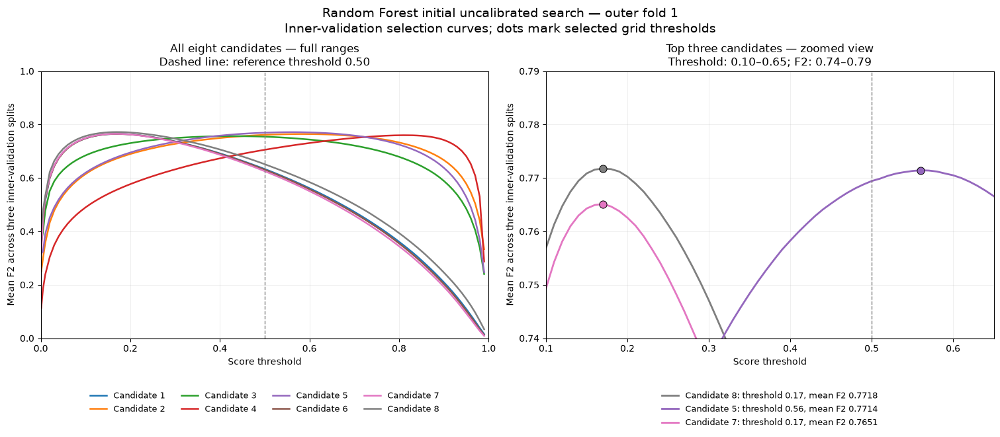

In [22]:
rf_threshold_figure, rf_threshold_axes = plt.subplots(
    1, 2,
    figsize=(15, 6.5),
    constrained_layout=True
)

rf_candidate_colors = {
    number: plt.get_cmap("tab10")(number - 1)
    for number in range(1, len(rf_search_candidates) + 1)
}

# Left: all candidates, full metric and threshold ranges.
rf_ax = rf_threshold_axes[0]

for rf_candidate_number in range(1, len(rf_search_candidates) + 1):
    rf_curve_data = (
        rf_outer1_threshold_summary.loc[
            rf_outer1_threshold_summary["Candidate"]
            == rf_candidate_number
        ]
        .sort_values("Threshold")
    )

    rf_ax.plot(
        rf_curve_data["Threshold"],
        rf_curve_data["Mean_F2"],
        color=rf_candidate_colors[rf_candidate_number],
        linewidth=1.8,
        label=f"Candidate {rf_candidate_number}"
    )

rf_ax.axvline(
    0.50,
    color="gray",
    linestyle="--",
    linewidth=1
)

rf_ax.set(
    xlabel="Score threshold",
    ylabel="Mean F2 across three inner-validation splits",
    title="All eight candidates — full ranges\n"
          "Dashed line: reference threshold 0.50",
    xlim=(0, 1),
    ylim=(0, 1)
)

rf_ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    ncol=4,
    fontsize=9,
    frameon=False
)

# Right: explicitly zoomed view of the three highest-ranked candidates.
rf_ax = rf_threshold_axes[1]

rf_top_three = (
    rf_outer1_initial_ranking.head(3)["Candidate"].astype(int).tolist()
)

for rf_candidate_number in rf_top_three:
    rf_curve_data = (
        rf_outer1_threshold_summary.loc[
            rf_outer1_threshold_summary["Candidate"]
            == rf_candidate_number
        ]
        .sort_values("Threshold")
    )

    rf_selected = rf_outer1_initial_ranking.loc[
        rf_outer1_initial_ranking["Candidate"] == rf_candidate_number
    ].iloc[0]

    rf_color = rf_candidate_colors[rf_candidate_number]

    rf_ax.plot(
        rf_curve_data["Threshold"],
        rf_curve_data["Mean_F2"],
        color=rf_color,
        linewidth=2,
        label=(
            f"Candidate {rf_candidate_number}: "
            f"threshold {rf_selected['Threshold']:.2f}, "
            f"mean F2 {rf_selected['Mean_F2']:.4f}"
        )
    )

    rf_ax.scatter(
        rf_selected["Threshold"],
        rf_selected["Mean_F2"],
        color=rf_color,
        edgecolors="black",
        linewidths=0.7,
        s=65,
        zorder=5
    )

rf_ax.axvline(
    0.50,
    color="gray",
    linestyle="--",
    linewidth=1
)

rf_ax.set(
    xlabel="Score threshold",
    ylabel="Mean F2 across three inner-validation splits",
    title="Top three candidates — zoomed view\n"
          "Threshold: 0.10–0.65; F2: 0.74–0.79",
    xlim=(0.10, 0.65),
    ylim=(0.74, 0.79)
)

rf_ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.17),
    fontsize=9,
    frameon=False
)

for rf_ax in rf_threshold_axes:
    rf_ax.grid(alpha=0.20)
    rf_ax.tick_params(labelsize=10)
    rf_ax.title.set_fontweight("normal")

rf_threshold_figure.suptitle(
    "Random Forest initial uncalibrated search — outer fold 1\n"
    "Inner-validation selection curves; dots mark selected grid thresholds",
    fontsize=14,
    fontweight="normal"
)

rf_selection_figures_dir = rf_selection_dir / "figures"
rf_selection_figures_dir.mkdir(parents=True, exist_ok=True)

rf_threshold_figure.savefig(
    rf_selection_figures_dir
    / f"threshold_comparison_{rf_selection_signature}.png",
    dpi=200,
    bbox_inches="tight"
)
rf_threshold_figure.savefig(
    rf_selection_figures_dir
    / f"threshold_comparison_{rf_selection_signature}.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Examine threshold sensitivity and compare the leading candidates after three-split aggregation.
Result: Candidate 8 peaks at threshold 0.17 with mean F2 0.771752; candidate 5 peaks at 0.56 with 0.771427. Their difference is only 0.000325. These are inner-selection results, not evidence of superior performance on unseen outer-evaluation images.

In [23]:
import copy

rf_tree_check_candidate = int(rf_outer1_initial_selection["candidate"])

rf_tree_check_source_records = [
    rf_search_model_records,
    rf_outer1_inner2_model_records,
    rf_outer1_inner3_model_records
]

rf_tree_check_records = {}
rf_tree_check_fit_rows = []

for rf_inner_position, rf_source_records in enumerate(
    rf_tree_check_source_records
):
    rf_inner_number = rf_inner_position + 1

    rf_matches = [
        record for record in rf_source_records
        if record["candidate"] == rf_tree_check_candidate
    ]
    assert len(rf_matches) == 1
    rf_source_record = rf_matches[0]

    rf_source_bundle = joblib.load(rf_source_record["model_path"])
    assert rf_source_bundle["signature"] == rf_source_record["signature"]

    rf_source_model = rf_source_bundle["model"]

    assert len(rf_source_model.estimators_) == 100
    assert rf_source_model.get_params() == (
        RandomForestClassifier(
            **rf_outer1_initial_selection["params"]
        ).get_params()
    )

    rf_training_ids = np.asarray(
        nested_splits[0]["inner_splits"][
            rf_inner_position
        ]["train_ids"]
    ).astype(str)

    assert rf_source_bundle["metadata"]["ordered_training_ids"] == (
        rf_training_ids.tolist()
    )

    rf_tree_X, rf_tree_y = rf_get_sampled_training_data(
        image_ids=rf_training_ids,
        sampled_patch_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples,
        y_samples=rf_y_samples
    )

    rf_data_hasher = hashlib.sha256()
    for rf_array in (rf_tree_X, rf_tree_y):
        for rf_start in range(0, len(rf_array), 8192):
            rf_data_hasher.update(
                rf_array[rf_start:rf_start + 8192].tobytes()
            )

    assert rf_data_hasher.hexdigest() == (
        rf_source_bundle["metadata"]["training_data_hash"]
    )

    rf_tree_check_records[rf_inner_number] = {
        100: {
            **rf_source_record,
            "n_estimators": 100
        }
    }

    print(f"\nInner split {rf_inner_number}/3", flush=True)

    for rf_tree_count in (50, 200):
        rf_tree_metadata = copy.deepcopy(rf_source_bundle["metadata"])
        rf_tree_metadata["stage"] = "number_of_trees_check"
        rf_tree_metadata["params"]["n_estimators"] = rf_tree_count
        rf_tree_metadata["source_100_tree_signature"] = (
            rf_source_record["signature"]
        )
        rf_tree_metadata["construction"] = (
            "first_50_trees" if rf_tree_count == 50
            else "extend_100_to_200_with_identical_training_data"
        )

        rf_tree_signature = hashlib.sha256(
            json.dumps(
                rf_tree_metadata,
                sort_keys=True,
                default=lambda value: value.item()
            ).encode("utf-8")
        ).hexdigest()

        rf_tree_dir = (
            rf_checkpoint_dir / "tree_count_check" / "outer_1"
            / f"inner_{rf_inner_number}"
        )
        rf_tree_dir.mkdir(parents=True, exist_ok=True)

        rf_tree_path = rf_tree_dir / f"model_{rf_tree_signature}.joblib"

        if rf_tree_path.is_file():
            rf_tree_bundle = joblib.load(rf_tree_path)
            assert rf_tree_bundle["signature"] == rf_tree_signature
            rf_tree_status = "Loaded checkpoint"

        else:
            rf_tree_model = copy.deepcopy(rf_source_model)

            if rf_tree_count == 50:
                rf_tree_model.estimators_ = (
                    rf_tree_model.estimators_[:50]
                )
                rf_tree_model.set_params(n_estimators=50)
                rf_incremental_fit_seconds = 0.0
                rf_tree_status = "Derived first 50 trees"

            else:
                rf_tree_model.set_params(
                    n_estimators=200,
                    warm_start=True
                )

                print(
                    "Adding 100 trees to the existing 100...",
                    flush=True
                )
                rf_start_time = perf_counter()
                rf_tree_model.fit(rf_tree_X, rf_tree_y)
                rf_incremental_fit_seconds = (
                    perf_counter() - rf_start_time
                )

                # Return the fitted estimator to the usual setting.
                rf_tree_model.set_params(warm_start=False)
                rf_tree_status = "Extended to 200 trees"

            rf_tree_bundle = {
                "signature": rf_tree_signature,
                "metadata": rf_tree_metadata,
                "model": rf_tree_model,
                "source_100_fit_seconds": rf_source_bundle["fit_seconds"],
                "incremental_fit_seconds": rf_incremental_fit_seconds
            }

            rf_temporary_path = rf_tree_path.with_suffix(".tmp")
            joblib.dump(rf_tree_bundle, rf_temporary_path)
            rf_temporary_path.replace(rf_tree_path)
            del rf_tree_model

        assert len(rf_tree_bundle["model"].estimators_) == rf_tree_count
        assert rf_tree_bundle["model"].get_params() == (
            RandomForestClassifier(
                **rf_tree_metadata["params"]
            ).get_params()
        )

        rf_tree_check_records[rf_inner_number][rf_tree_count] = {
            "candidate": rf_tree_check_candidate,
            "n_estimators": rf_tree_count,
            "signature": rf_tree_signature,
            "model_path": str(rf_tree_path),
            "params": dict(rf_tree_metadata["params"])
        }

        rf_tree_check_fit_rows.append({
            "Inner_split": rf_inner_number,
            "Trees": rf_tree_count,
            "Additional_fit_seconds": (
                rf_tree_bundle["incremental_fit_seconds"]
            ),
            "Status": rf_tree_status
        })

        print(
            f"{rf_tree_count} trees: {rf_tree_status}",
            flush=True
        )
        del rf_tree_bundle

    del rf_source_model, rf_source_bundle, rf_tree_X, rf_tree_y

rf_tree_check_fit_table = pd.DataFrame(rf_tree_check_fit_rows)

rf_tree_check_root = rf_checkpoint_dir / "tree_count_check" / "outer_1"
joblib.dump(
    rf_tree_check_records,
    rf_tree_check_root / "model_records.joblib"
)
rf_tree_check_fit_table.to_csv(
    rf_tree_check_root / "additional_fitting_times.csv",
    index=False
)

display(rf_tree_check_fit_table.round(2))

print("\n100-tree models were reused without refitting.")
print("Additional_fit_seconds measures only new fitting work.")
print("A derived 50-tree model does not have a separately measured fit time.")
print("Validation comparison of 50, 100 and 200 trees is the next step.")


Inner split 1/3
50 trees: Derived first 50 trees
Adding 100 trees to the existing 100...
200 trees: Extended to 200 trees

Inner split 2/3
50 trees: Derived first 50 trees
Adding 100 trees to the existing 100...
200 trees: Extended to 200 trees

Inner split 3/3
50 trees: Derived first 50 trees
Adding 100 trees to the existing 100...
200 trees: Extended to 200 trees


,Inner_split,Trees,Additional_fit_seconds,Status
0,1,50,0.00,Derived first 50 trees
1,1,200,148.66,Extended to 200 trees
2,2,50,0.00,Derived first 50 trees
3,2,200,147.57,Extended to 200 trees
4,3,50,0.00,Derived first 50 trees
5,3,200,146.95,Extended to 200 trees



100-tree models were reused without refitting.
Additional_fit_seconds measures only new fitting work.
A derived 50-tree model does not have a separately measured fit time.
Validation comparison of 50, 100 and 200 trees is the next step.


Rationale: Prepare a controlled comparison of 50, 100 and 200 trees while preserving training data and other settings.
Result: All three forest sizes are available for all three inner splits. Extending the forests to 200 trees required approximately 443.18 seconds of additional fitting. Validation performance has not yet been compared.

In [24]:
rf_tree_existing_tables = [
    rf_search_first_inner_table,
    rf_outer1_inner2_validation_table,
    rf_outer1_inner3_validation_table
]

rf_tree_validation_rows = []
rf_tree_threshold_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_ids = sorted(
        np.asarray(
            nested_splits[0]["inner_splits"][
                rf_inner_position
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )

    # Locate the completed 100-tree evaluation for the selected candidate.
    rf_existing_row = rf_tree_existing_tables[rf_inner_position].loc[
        rf_tree_existing_tables[rf_inner_position]["Candidate"]
        == rf_tree_check_candidate
    ]
    assert len(rf_existing_row) == 1

    rf_existing_result = joblib.load(
        rf_existing_row.iloc[0]["Evaluation_path"]
    )
    rf_label_bundle = joblib.load(
        rf_existing_result["shared_labels_path"]
    )

    assert rf_label_bundle["image_ids"] == rf_ids
    rf_labels = np.asarray(rf_label_bundle["labels"]).reshape(
        len(rf_ids), 128 * 128
    )

    # Verify masks against their current source files and record source identity.
    rf_sources = []
    rf_source_records = []

    for rf_row_number, rf_image_id in enumerate(rf_ids):
        rf_image_path = (
            Path(DATA_DIR) / "TrainData" / "img"
            / f"image_{rf_image_id}.h5"
        )
        rf_mask_path = (
            Path(DATA_DIR) / "TrainData" / "mask"
            / f"mask_{rf_image_id}.h5"
        )

        with h5py.File(rf_mask_path, "r") as rf_file:
            rf_mask = np.asarray(rf_file["mask"])

        assert rf_mask.shape == (128, 128)
        assert np.array_equal(
            rf_mask.reshape(-1), rf_labels[rf_row_number]
        )

        rf_sources.append((rf_image_id, rf_image_path))
        rf_source_records.append({
            "image_id": rf_image_id,
            "files": [
                {
                    "path": str(path.resolve()),
                    "size": path.stat().st_size,
                    "mtime_ns": path.stat().st_mtime_ns
                }
                for path in (rf_image_path, rf_mask_path)
            ]
        })

    # Reuse completed 100-tree metrics and threshold results.
    rf_existing_thresholds = rf_existing_result["threshold_table"].copy()
    assert np.array_equal(
        rf_existing_thresholds["Threshold"].to_numpy(),
        rf_saved_thresholds
    )

    rf_existing_thresholds["Trees"] = 100
    rf_existing_thresholds["Inner_split"] = rf_inner_number
    rf_tree_threshold_parts.append(rf_existing_thresholds)

    rf_tree_validation_rows.append({
        "Inner_split": rf_inner_number,
        "Trees": 100,
        **rf_existing_result["metrics_at_050"],
        "Prediction_seconds": rf_existing_result["prediction_seconds"]
    })

    for rf_tree_count in (50, 200):
        rf_record = rf_tree_check_records[rf_inner_number][rf_tree_count]

        rf_eval_metadata = {
            "model_signature": rf_record["signature"],
            "sources": rf_source_records,
            "thresholds": rf_saved_thresholds.tolist(),
            "beta": float(BETA),
            "reference_threshold": rf_baseline_threshold,
            "log_loss_epsilon": float(rf_log_loss_epsilon),
            "sklearn_version": sklearn.__version__,
            "evaluation_code_version": 1
        }

        rf_signature = hashlib.sha256(
            json.dumps(rf_eval_metadata, sort_keys=True).encode("utf-8")
        ).hexdigest()

        rf_eval_dir = (
            rf_tree_check_root / f"inner_{rf_inner_number}"
            / "validation" / rf_signature
        )
        rf_eval_dir.mkdir(parents=True, exist_ok=True)
        rf_result_path = rf_eval_dir / "evaluation.joblib"

        print(
            f"\nInner split {rf_inner_number}/3 — "
            f"{rf_tree_count} trees",
            flush=True
        )

        if rf_result_path.is_file():
            rf_result = joblib.load(rf_result_path)
            assert rf_result["signature"] == rf_signature
            print("Loaded completed evaluation.", flush=True)

        else:
            rf_bundle = joblib.load(rf_record["model_path"])
            assert rf_bundle["signature"] == rf_record["signature"]
            assert rf_bundle["metadata"]["inner_split"] == rf_inner_number

            rf_model = rf_bundle["model"]
            assert len(rf_model.estimators_) == rf_tree_count

            rf_positive_column = np.flatnonzero(
                rf_model.classes_ == 1
            ).item()

            rf_score_parts = []
            rf_score_files = []
            rf_prediction_seconds = 0.0

            for rf_start in range(0, len(rf_sources), 25):
                rf_chunk_sources = rf_sources[rf_start:rf_start + 25]
                rf_chunk_ids = [item[0] for item in rf_chunk_sources]
                rf_chunk_path = (
                    rf_eval_dir / f"scores_{rf_start:04d}.joblib"
                )

                if rf_chunk_path.is_file():
                    rf_chunk = joblib.load(rf_chunk_path)
                    assert rf_chunk["signature"] == rf_signature
                    assert rf_chunk["image_ids"] == rf_chunk_ids

                else:
                    rf_scores_list = []
                    rf_chunk_seconds = 0.0

                    for rf_image_id, rf_image_path in rf_chunk_sources:
                        with h5py.File(rf_image_path, "r") as rf_file:
                            rf_image = np.asarray(rf_file["img"])

                        if (
                            rf_image.shape != (128, 128, 14)
                            or not np.isfinite(rf_image).all()
                        ):
                            raise ValueError(
                                f"Invalid image: {rf_image_id}"
                            )

                        rf_start_time = perf_counter()
                        rf_image_scores = rf_model.predict_proba(
                            rf_image.reshape(-1, 14)
                        )[:, rf_positive_column]
                        rf_chunk_seconds += (
                            perf_counter() - rf_start_time
                        )
                        rf_scores_list.append(rf_image_scores)

                    rf_chunk = {
                        "signature": rf_signature,
                        "image_ids": rf_chunk_ids,
                        "scores": np.stack(rf_scores_list),
                        "prediction_seconds": rf_chunk_seconds
                    }

                    rf_temp = rf_chunk_path.with_suffix(".tmp")
                    joblib.dump(rf_chunk, rf_temp)
                    rf_temp.replace(rf_chunk_path)

                assert rf_chunk["scores"].shape == (
                    len(rf_chunk_ids), 128 * 128
                )
                rf_score_parts.append(rf_chunk["scores"])
                rf_score_files.append(str(rf_chunk_path))
                rf_prediction_seconds += rf_chunk["prediction_seconds"]

                print(
                    f"  {rf_start + len(rf_chunk_ids)}/{len(rf_ids)} images",
                    flush=True
                )

            rf_scores = np.concatenate(rf_score_parts).reshape(-1)
            del rf_score_parts

            rf_metrics = rf_binary_metrics(
                rf_labels.reshape(-1), rf_scores,
                threshold=rf_baseline_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )
            rf_threshold_table = rf_threshold_metrics(
                rf_labels.reshape(-1), rf_scores,
                rf_saved_thresholds,
                beta=float(BETA)
            )

            rf_result = {
                "signature": rf_signature,
                "metadata": rf_eval_metadata,
                "image_ids": rf_ids,
                "metrics_at_050": rf_metrics,
                "threshold_table": rf_threshold_table,
                "prediction_seconds": rf_prediction_seconds,
                "prediction_files": rf_score_files,
                "shared_labels_path": rf_existing_result["shared_labels_path"]
            }

            rf_temp = rf_result_path.with_suffix(".tmp")
            joblib.dump(rf_result, rf_temp)
            rf_temp.replace(rf_result_path)
            del rf_scores, rf_model, rf_bundle

        rf_table = rf_result["threshold_table"].copy()
        rf_table["Trees"] = rf_tree_count
        rf_table["Inner_split"] = rf_inner_number
        rf_tree_threshold_parts.append(rf_table)

        rf_tree_validation_rows.append({
            "Inner_split": rf_inner_number,
            "Trees": rf_tree_count,
            **rf_result["metrics_at_050"],
            "Prediction_seconds": rf_result["prediction_seconds"]
        })

    del rf_labels, rf_label_bundle


rf_tree_threshold_detail = pd.concat(
    rf_tree_threshold_parts, ignore_index=True
)

rf_tree_threshold_summary = (
    rf_tree_threshold_detail
    .groupby(["Trees", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_tree_threshold_summary["Inner_splits"] == 3).all()

rf_tree_selected_rows = []

for rf_tree_count in (50, 100, 200):
    rf_rows = rf_tree_threshold_summary.loc[
        rf_tree_threshold_summary["Trees"] == rf_tree_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )
    rf_best = (
        rf_ties.sort_values("Threshold", ascending=False).iloc[0]
        .to_dict()
    )

    rf_tree_selected_rows.append(rf_best)

rf_tree_count_comparison = (
    pd.DataFrame(rf_tree_selected_rows)
    .sort_values("Trees")
    .reset_index(drop=True)
)
rf_tree_count_comparison["Trees"] = (
    rf_tree_count_comparison["Trees"].astype(int)
)

# Verify that the reused 100-tree result reproduces the original selection.
rf_100_row = rf_tree_count_comparison.loc[
    rf_tree_count_comparison["Trees"] == 100
].iloc[0]

rf_original_row = rf_outer1_initial_ranking.loc[
    rf_outer1_initial_ranking["Candidate"] == rf_tree_check_candidate
].iloc[0]

assert np.isclose(
    rf_100_row["Mean_F2"], rf_original_row["Mean_F2"],
    rtol=0, atol=rf_selection_tolerance
)
assert np.isclose(
    rf_100_row["Threshold"], rf_original_row["Threshold"],
    rtol=0, atol=rf_selection_tolerance
)

rf_tree_ties = rf_keep_near_max(
    rf_tree_count_comparison, "Mean_F2", rf_selection_tolerance
)
rf_tree_ties = rf_keep_near_max(
    rf_tree_ties, "Mean_precision", rf_selection_tolerance
)
rf_tree_count_selected = int(
    rf_tree_ties.sort_values("Trees").iloc[0]["Trees"]
)

joblib.dump(
    {
        "candidate": rf_tree_check_candidate,
        "comparison": rf_tree_count_comparison,
        "threshold_detail": rf_tree_threshold_detail,
        "threshold_summary": rf_tree_threshold_summary,
        "metrics_at_050": pd.DataFrame(rf_tree_validation_rows),
        "selected_tree_count": rf_tree_count_selected,
        "tie_tolerance": rf_selection_tolerance
    },
    rf_tree_check_root / "tree_count_comparison.joblib"
)

rf_tree_count_comparison.to_csv(
    rf_tree_check_root / "tree_count_comparison.csv",
    index=False
)

display(rf_tree_count_comparison.round(6))

print("\nSelected tree count within this inner comparison:",
      rf_tree_count_selected)
print("100-tree results reproduced the original selection.")
print("SD_F2 is descriptive, not a confidence interval.")
print("No outer-evaluation or holdout images were used.")


Inner split 1/3 — 50 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Inner split 1/3 — 200 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 imag

,Trees,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,50,0.17,3.0,0.769692,0.017474,0.539596,0.862619,0.982501,0.496714
1,100,0.17,3.0,0.771752,0.017526,0.542449,0.864022,0.982673,0.499609
2,200,0.17,3.0,0.772925,0.017635,0.543835,0.864989,0.982750,0.501110



Selected tree count within this inner comparison: 200
100-tree results reproduced the original selection.
SD_F2 is descriptive, not a confidence interval.
No outer-evaluation or holdout images were used.


Rationale: Assess the benefit of increasing tree count while holding other settings and training data fixed.
Result: The 200-tree forest achieved the highest mean inner-validation F2, 0.772925, at threshold 0.17. Its improvement over 100 trees was small: 0.001173. It is selected for this development path; outer-evaluation performance remains unknown.

In [25]:
# Verify the selected configuration before the sample-size comparison.
assert rf_tree_count_selected == 200

rf_sample_check_params = dict(rf_outer1_initial_selection["params"])
rf_sample_check_params["n_estimators"] = int(rf_tree_count_selected)

assert rf_X_samples.shape[1] == 1024
assert rf_y_samples.shape == rf_X_samples.shape[:-1]

rf_sample_check_ids = np.asarray(rf_sampled_patch_ids).astype(str)

# Choose a reproducible, label-independent subset for each image.
rf_sample512_indices = np.empty(
    (len(rf_sample_check_ids), 512),
    dtype=np.intp
)

for rf_row, rf_image_id in enumerate(rf_sample_check_ids):
    rf_image_rng = np.random.default_rng(
        np.random.SeedSequence([
            int(RANDOM_STATE),
            int(rf_image_id),
            512
        ])
    )

    rf_sample512_indices[rf_row] = np.sort(
        rf_image_rng.choice(1024, size=512, replace=False)
    )

assert np.all(np.diff(rf_sample512_indices, axis=1) > 0)

# Select matching feature rows and labels.
rf_sample_rows = np.arange(len(rf_sample_check_ids))[:, None]

rf_X_samples512 = rf_X_samples[
    rf_sample_rows, rf_sample512_indices
]
rf_y_samples512 = rf_y_samples[
    rf_sample_rows, rf_sample512_indices
]

assert rf_X_samples512.shape == (
    len(rf_sample_check_ids), 512, len(FEATURE_NAMES)
)
assert rf_y_samples512.shape == (len(rf_sample_check_ids), 512)

rf_sample_check_root = rf_checkpoint_dir / "sample_size_check"
rf_sample_check_root.mkdir(parents=True, exist_ok=True)

# Retain exact sample positions and their ordered image IDs.
rf_sample512_subset_signature = hashlib.sha256(
    rf_sample_check_ids.tobytes()
    + rf_sample512_indices.tobytes()
).hexdigest()

rf_subset_path = (
    rf_sample_check_root
    / f"subset_512_{rf_sample512_subset_signature}.joblib"
)

if not rf_subset_path.is_file():
    rf_subset_temp = rf_subset_path.with_suffix(".tmp")
    joblib.dump(
        {
            "ordered_image_ids": rf_sample_check_ids.tolist(),
            "sample_positions": rf_sample512_indices,
            "seed": int(RANDOM_STATE),
            "method": "uniform subset without replacement per image",
            "source_samples_per_image": 1024,
            "selected_samples_per_image": 512,
            "signature": rf_sample512_subset_signature
        },
        rf_subset_temp
    )
    rf_subset_temp.replace(rf_subset_path)

rf_sample512_model_records = {}
rf_sample512_fitting_tables = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_fit_table = rf_fit_search_inner_split(
        outer_split=nested_splits[0],
        inner_position=rf_inner_position,
        candidates=[rf_sample_check_params],
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples512,
        y_samples=rf_y_samples512,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_sample_check_root / "512_pixels"
    )

    rf_sample512_model_records[rf_inner_number] = rf_records

    # This is one fixed configuration, not a new candidate search.
    rf_fit_table = rf_fit_table.drop(columns=["Candidate"]).copy()
    rf_fit_table.insert(0, "Inner_split", rf_inner_number)
    rf_fit_table.insert(1, "Source_candidate", rf_tree_check_candidate)
    rf_fit_table.insert(2, "Samples_per_image", 512)

    rf_sample512_fitting_tables.append(rf_fit_table)

rf_sample512_fitting_summary = pd.concat(
    rf_sample512_fitting_tables,
    ignore_index=True
)

joblib.dump(
    {
        "params": rf_sample_check_params,
        "subset_path": str(rf_subset_path),
        "model_records": rf_sample512_model_records,
        "fitting_summary": rf_sample512_fitting_summary
    },
    rf_sample_check_root / "sample512_fitting_records.joblib"
)

rf_sample512_fitting_summary.to_csv(
    rf_sample_check_root / "sample512_fitting_summary.csv",
    index=False
)

display(rf_sample512_fitting_summary.round(2))

print("\nScope: outer fold 1 / all three inner-training splits.")
print("Configuration: selected candidate settings with 200 trees.")
print("Only sampled training-pixel count changed: 1024 → 512.")
print("Sample-size validation comparison has not started.")

Outer fold 1 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (829440, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 127.92 seconds
Outer fold 1 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 152.67 seconds
Outer fold 1 / inner split 3
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 129.21 seconds


,Inner_split,Source_candidate,Samples_per_image,Trees,Original_fit_seconds,Status
0,1,8,512,200,127.92,New model fitted
1,2,8,512,200,152.67,New model fitted
2,3,8,512,200,129.21,New model fitted



Scope: outer fold 1 / all three inner-training splits.
Configuration: selected candidate settings with 200 trees.
Only sampled training-pixel count changed: 1024 → 512.
Sample-size validation comparison has not started.


Rationale: Prepare a controlled comparison of 512 versus 1,024 sampled training pixels per image.
Result: Three 200-tree models using 512 samples per image were fitted and saved. Their displayed fitting times total 409.80 seconds. Validation performance has not yet been compared.

In [26]:
rf_sample512_validation_tables = {}
rf_sample512_threshold_tables = {}
rf_sample_comparison_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_summary, rf_threshold_tables = rf_evaluate_search_inner_split(
        outer_split=nested_splits[0],
        inner_position=rf_inner_position,
        model_records=rf_sample512_model_records[rf_inner_number],
        data_dir=DATA_DIR,
        thresholds=rf_saved_thresholds,
        beta=float(BETA),
        reference_threshold=rf_baseline_threshold,
        log_loss_epsilon=rf_log_loss_epsilon,
        feature_names=FEATURE_NAMES
    )

    rf_sample512_validation_tables[rf_inner_number] = rf_summary
    rf_sample512_threshold_tables[rf_inner_number] = rf_threshold_tables

    # One fixed configuration is evaluated in this experiment.
    assert len(rf_summary) == 1
    assert set(rf_threshold_tables) == {1}

    rf_current_result = joblib.load(
        rf_summary.iloc[0]["Evaluation_path"]
    )
    rf_current_labels = joblib.load(
        rf_current_result["shared_labels_path"]
    )

    # Confirm compatibility with the saved 1024-sample / 200-tree evaluation.
    rf_reference_model_signature = (
        rf_tree_check_records[rf_inner_number][200]["signature"]
    )

    rf_reference_matches = []

    for rf_path in (
        rf_tree_check_root / f"inner_{rf_inner_number}" / "validation"
    ).glob("*/evaluation.joblib"):
        rf_reference_result = joblib.load(rf_path)
        rf_metadata = rf_reference_result["metadata"]

        if (
            rf_metadata["model_signature"]
            == rf_reference_model_signature
            and rf_metadata["sources"]
            == rf_current_labels["source_metadata"]["sources"]
            and rf_metadata["thresholds"]
            == rf_saved_thresholds.tolist()
            and rf_metadata["beta"] == float(BETA)
            and rf_metadata["reference_threshold"]
            == rf_baseline_threshold
            and rf_metadata["log_loss_epsilon"]
            == float(rf_log_loss_epsilon)
        ):
            rf_reference_matches.append(rf_reference_result)

    assert len(rf_reference_matches) == 1, (
        "A unique, source-matched 1024-sample evaluation was not found."
    )

    rf_reference_result = rf_reference_matches[0]
    rf_reference_labels = joblib.load(
        rf_reference_result["shared_labels_path"]
    )

    assert (
        rf_current_labels["image_ids"]
        == rf_reference_labels["image_ids"]
    )
    assert np.array_equal(
        rf_current_labels["labels"],
        rf_reference_labels["labels"]
    )

    for rf_samples, rf_table in [
        (512, rf_threshold_tables[1]),
        (1024, rf_reference_result["threshold_table"])
    ]:
        rf_part = rf_table.copy()

        assert np.array_equal(
            rf_part["Threshold"].to_numpy(),
            rf_saved_thresholds
        )

        rf_part["Samples_per_image"] = rf_samples
        rf_part["Inner_split"] = rf_inner_number
        rf_sample_comparison_parts.append(rf_part)

    del rf_current_labels, rf_reference_labels, rf_reference_matches


rf_sample_threshold_detail = pd.concat(
    rf_sample_comparison_parts, ignore_index=True
)

rf_sample_threshold_summary = (
    rf_sample_threshold_detail
    .groupby(["Samples_per_image", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)

assert (rf_sample_threshold_summary["Inner_splits"] == 3).all()

rf_sample_selected_rows = []

for rf_sample_count in (512, 1024):
    rf_rows = rf_sample_threshold_summary.loc[
        rf_sample_threshold_summary["Samples_per_image"]
        == rf_sample_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_best_row = (
        rf_ties.sort_values("Threshold", ascending=False).iloc[0]
        .to_dict()
    )
    rf_sample_selected_rows.append(rf_best_row)

rf_sample_size_comparison = (
    pd.DataFrame(rf_sample_selected_rows)
    .sort_values("Samples_per_image")
    .reset_index(drop=True)
)
rf_sample_size_comparison["Samples_per_image"] = (
    rf_sample_size_comparison["Samples_per_image"].astype(int)
)

# Verify reuse of the earlier 200-tree / 1024-sample result.
rf_1024_row = rf_sample_size_comparison.loc[
    rf_sample_size_comparison["Samples_per_image"] == 1024
].iloc[0]

rf_previous_200_row = rf_tree_count_comparison.loc[
    rf_tree_count_comparison["Trees"] == 200
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_1024_row[rf_column],
        rf_previous_200_row[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_sample_ties = rf_keep_near_max(
    rf_sample_size_comparison, "Mean_F2", rf_selection_tolerance
)
rf_sample_ties = rf_keep_near_max(
    rf_sample_ties, "Mean_precision", rf_selection_tolerance
)

rf_selected_samples_per_image = int(
    rf_sample_ties.sort_values("Samples_per_image").iloc[0][
        "Samples_per_image"
    ]
)

rf_sample_size_comparison.to_csv(
    rf_sample_check_root / "sample_size_comparison.csv",
    index=False
)

joblib.dump(
    {
        "params": rf_sample_check_params,
        "comparison": rf_sample_size_comparison,
        "threshold_detail": rf_sample_threshold_detail,
        "threshold_summary": rf_sample_threshold_summary,
        "sample512_validation_tables": rf_sample512_validation_tables,
        "sample512_threshold_tables": rf_sample512_threshold_tables,
        "selected_samples_per_image": rf_selected_samples_per_image,
        "subset_path": str(rf_subset_path),
        "tie_tolerance": rf_selection_tolerance
    },
    rf_sample_check_root / "sample_size_comparison.joblib"
)

display(rf_sample_size_comparison.round(6))

print("\nTrees: 200; other RF settings unchanged.")
print("Selected samples per image:", rf_selected_samples_per_image)
print("Verified identical validation image order, masks and source metadata.")
print("1024-sample results reproduced the previous comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("No outer-evaluation or holdout images were used.")

Outer fold 1 / inner validation 1
Images: 811; pixels: 13,287,424

Candidate 1/1
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.
Outer fold 1 / inner validation 2
Images: 810; pixels: 13,271,040

Candidate 1/1
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325

,Samples_per_image,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,512,0.17,3.0,0.768032,0.018386,0.538314,0.860996,0.982433,0.49505
1,1024,0.17,3.0,0.772925,0.017635,0.543835,0.864989,0.982750,0.50111



Trees: 200; other RF settings unchanged.
Selected samples per image: 1024
Verified identical validation image order, masks and source metadata.
1024-sample results reproduced the previous comparison.
SD_F2 is descriptive, not a confidence interval.
No outer-evaluation or holdout images were used.


Rationale: Assess whether halving sampled training pixels preserves performance while reducing fitting cost.
Result: With 200 trees, 1,024 samples per image achieved mean inner-validation F2 of 0.772925 versus 0.768032 for 512 samples. Both selected threshold 0.17. Retain 1,024 samples for this development path.

In [27]:
# Record the current working configuration.
# This is not the locked final pipeline.
rf_outer1_working_spec = {
    "params": {
        **rf_outer1_initial_selection["params"],
        "n_estimators": int(rf_tree_count_selected)
    },
    "samples_per_image": int(rf_selected_samples_per_image),
    "uncalibrated_reference_threshold": float(
        rf_sample_size_comparison.loc[
            rf_sample_size_comparison["Samples_per_image"]
            == rf_selected_samples_per_image,
            "Threshold"
        ].iloc[0]
    )
}

print("Current working configuration:")
print(rf_outer1_working_spec)


def rf_inspect_saved_calibration(obj, label, depth=0):
    """Inspect metadata without printing large models or prediction arrays."""
    prefix = "  " * depth
    print(f"{prefix}{label}: {type(obj).__name__}")

    if isinstance(obj, pd.DataFrame):
        print(f"{prefix}Shape: {obj.shape}")
        print(f"{prefix}Columns: {list(obj.columns)}")

    elif isinstance(obj, dict):
        print(f"{prefix}Keys: {list(obj.keys())}")

        if depth < 2:
            for key, value in obj.items():
                rf_inspect_saved_calibration(
                    value, str(key), depth + 1
                )

    elif isinstance(obj, (list, tuple)):
        print(f"{prefix}Length: {len(obj)}")
        if len(obj) and depth < 2:
            rf_inspect_saved_calibration(
                obj[0], "First entry", depth + 1
            )

    elif hasattr(obj, "shape"):
        print(f"{prefix}Shape: {obj.shape}")

    elif obj is None or isinstance(
        obj, (str, int, float, bool, np.generic)
    ):
        print(f"{prefix}Value: {obj}")

    elif hasattr(obj, "get_params"):
        print(f"{prefix}Estimator class: {type(obj).__name__}")
        if hasattr(obj, "n_features_in_"):
            print(f"{prefix}Input features: {obj.n_features_in_}")


print("\nSaved DT pipeline-selection structure — outer fold 1:")
rf_inspect_saved_calibration(
    dt_pipeline_results_by_outer[1],
    "Pipeline selection"
)

print("\nSaved fitted DT bundle structure — outer fold 1:")
rf_inspect_saved_calibration(
    dt_fitted_bundles_by_outer[1],
    "Fitted bundle"
)

Current working configuration:
{'params': {'n_estimators': 200, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}, 'samples_per_image': 1024, 'uncalibrated_reference_threshold': 0.17}

Saved DT pipeline-selection structure — outer fold 1:
Pipeline selection: dict
Keys: ['selected', 'ranking']
  selected: dict
  Keys: ['Method', 'Threshold', 'mean_F2', 'sd_F2', 'mean_precision', 'mean_recall', 'mean_specificity', 'mean_IoU', 'pixels_per_patch', 'method_priority']
    Method: str
    Value: Uncalibrated — all training patches
    Threshold: float
    Value: 0.91
    mean_F2: float
    Value: 0.7276418859518038
    sd_F2: float
    Value: 0.01516783417400455
    mean_precision: float
    Value: 0.5015503594563343
    mean_recall: float
    Value: 0.8204585747421627
    mean_specificity: float
    Val

In [28]:
print("Previous DT calibration comparison — outer fold 1:")
print(
    dt_pipeline_results_by_outer[1]["ranking"].to_string(index=False)
)

print("\nSaved DT fitted-bundle fields:")
rf_previous_bundle = dt_fitted_bundles_by_outer[1]

for rf_key, rf_value in rf_previous_bundle.items():
    print(f"{rf_key}: {type(rf_value).__name__}")

    if isinstance(rf_value, dict):
        print("  Keys:", list(rf_value.keys()))

    elif isinstance(rf_value, str):
        print("  Value:", rf_value)

Previous DT calibration comparison — outer fold 1:
                             Method  Threshold  mean_F2    sd_F2  mean_precision  mean_recall  mean_specificity  mean_IoU  pixels_per_patch  method_priority
Uncalibrated — all training patches      0.910 0.727642 0.015168        0.501550     0.820459          0.980630  0.451963              1024                0
Uncalibrated — all training patches      0.920 0.727241 0.015763        0.519534     0.808302          0.982249  0.462601              1024                0
Uncalibrated — all training patches      0.900 0.726676 0.016030        0.483116     0.831995          0.978855  0.440175              1024                0
Uncalibrated — all training patches      0.890 0.726144 0.016542        0.472326     0.839134          0.977730  0.433186              1024                0
Uncalibrated — all training patches      0.930 0.725431 0.015592        0.538456     0.794706          0.983819  0.472738              1024                0
Uncalib

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.exceptions import ConvergenceWarning
import warnings

rf_calibration_params = dict(rf_outer1_working_spec["params"])
assert rf_calibration_params["n_estimators"] == 200
assert rf_outer1_working_spec["samples_per_image"] == 1024

rf_calibration_root = (
    rf_checkpoint_dir / "calibration_comparison" / "outer_1"
)
rf_calibration_root.mkdir(parents=True, exist_ok=True)

rf_calibration_bundle_records = {}
rf_calibration_preparation_rows = []

for rf_inner_position, rf_saved_split in enumerate(
    dt_calibration_splits_by_outer[1]
):
    rf_inner_number = rf_inner_position + 1

    rf_fit_ids = np.asarray(
        rf_saved_split["fit_ids"]
    ).astype(str)
    rf_cal_ids = np.asarray(
        rf_saved_split["calibration_ids"]
    ).astype(str)
    rf_validation_ids = np.asarray(
        rf_saved_split["validation_ids"]
    ).astype(str)

    rf_original_inner = nested_splits[0]["inner_splits"][rf_inner_position]
    rf_training_set = set(
        np.asarray(rf_original_inner["train_ids"]).astype(str)
    )

    assert set(rf_fit_ids).isdisjoint(set(rf_cal_ids))
    assert set(rf_fit_ids) | set(rf_cal_ids) == rf_training_set
    assert set(rf_validation_ids) == set(
        np.asarray(rf_original_inner["validation_ids"]).astype(str)
    )
    assert rf_training_set.isdisjoint(set(rf_validation_ids))

    rf_X_fit, rf_y_fit = rf_get_sampled_training_data(
        rf_fit_ids, rf_sampled_patch_ids,
        rf_X_samples, rf_y_samples
    )
    rf_X_cal, rf_y_cal = rf_get_sampled_training_data(
        rf_cal_ids, rf_sampled_patch_ids,
        rf_X_samples, rf_y_samples
    )

    assert set(np.unique(rf_y_fit).tolist()) == {0, 1}
    assert set(np.unique(rf_y_cal).tolist()) == {0, 1}

    rf_calibration_data_hasher = hashlib.sha256()
    for rf_array in (rf_X_fit, rf_y_fit, rf_X_cal, rf_y_cal):
        for rf_start in range(0, len(rf_array), 8192):
            rf_calibration_data_hasher.update(
                rf_array[rf_start:rf_start + 8192].tobytes()
            )

    rf_calibration_metadata = {
        "outer_fold": 1,
        "inner_split": rf_inner_number,
        "params": rf_calibration_params,
        "fit_ids": rf_fit_ids.tolist(),
        "calibration_ids": rf_cal_ids.tolist(),
        "validation_ids": rf_validation_ids.tolist(),
        "features": list(FEATURE_NAMES),
        "samples_per_image": 1024,
        "data_hash": rf_calibration_data_hasher.hexdigest(),
        "calibrator_input": "raw_positive_class_score_no_logit",
        "calibration_sampling": "saved_uniform_sampled_pixels",
        "sigmoid": {
            "C": float(PLATT_C),
            "solver": "lbfgs",
            "max_iter": 2000,
            "class_weight": None,
            "random_state": int(RANDOM_STATE)
        },
        "isotonic": {
            "increasing": True,
            "out_of_bounds": "clip"
        },
        "python_version": platform.python_version(),
        "numpy_version": np.__version__,
        "sklearn_version": sklearn.__version__
    }

    rf_calibration_signature = hashlib.sha256(
        json.dumps(
            rf_calibration_metadata,
            sort_keys=True,
            default=lambda value: value.item()
        ).encode("utf-8")
    ).hexdigest()

    rf_cal_dir = (
        rf_calibration_root / f"inner_{rf_inner_number}"
        / rf_calibration_signature
    )
    rf_cal_dir.mkdir(parents=True, exist_ok=True)

    rf_base_path = rf_cal_dir / "base_forest.joblib"
    rf_calibrators_path = rf_cal_dir / "calibrators.joblib"

    print(f"\nInner split {rf_inner_number}/3", flush=True)

    if rf_base_path.is_file():
        rf_base_bundle = joblib.load(rf_base_path)
        assert rf_base_bundle["signature"] == rf_calibration_signature
        print("Loaded fitting-side forest.", flush=True)

    else:
        rf_base_model = RandomForestClassifier(**rf_calibration_params)

        print("Training fitting-side forest...", flush=True)
        rf_start_time = perf_counter()
        rf_base_model.fit(rf_X_fit, rf_y_fit)
        rf_base_fit_seconds = perf_counter() - rf_start_time

        rf_base_bundle = {
            "signature": rf_calibration_signature,
            "metadata": rf_calibration_metadata,
            "model": rf_base_model,
            "fit_seconds": rf_base_fit_seconds
        }

        rf_temp = rf_base_path.with_suffix(".tmp")
        joblib.dump(rf_base_bundle, rf_temp)
        rf_temp.replace(rf_base_path)
        del rf_base_model

    assert rf_base_bundle["model"].get_params() == (
        RandomForestClassifier(**rf_calibration_params).get_params()
    )

    if rf_calibrators_path.is_file():
        rf_calibrator_bundle = joblib.load(rf_calibrators_path)
        assert rf_calibrator_bundle["signature"] == rf_calibration_signature
        print("Loaded sigmoid and isotonic calibrators.", flush=True)

    else:
        rf_model = rf_base_bundle["model"]
        rf_positive_column = np.flatnonzero(
            rf_model.classes_ == 1
        ).item()

        rf_cal_scores = np.empty(len(rf_y_cal), dtype=np.float64)

        rf_start_time = perf_counter()
        for rf_start in range(0, len(rf_y_cal), 65536):
            rf_stop = min(rf_start + 65536, len(rf_y_cal))
            rf_cal_scores[rf_start:rf_stop] = rf_model.predict_proba(
                rf_X_cal[rf_start:rf_stop]
            )[:, rf_positive_column]
        rf_cal_prediction_seconds = perf_counter() - rf_start_time

        assert np.isfinite(rf_cal_scores).all()
        assert np.all((rf_cal_scores >= 0) & (rf_cal_scores <= 1))

        rf_sigmoid = LogisticRegression(
            **rf_calibration_metadata["sigmoid"]
        )

        rf_start_time = perf_counter()
        with warnings.catch_warnings(record=True) as rf_warnings:
            warnings.simplefilter("always")
            rf_sigmoid.fit(rf_cal_scores.reshape(-1, 1), rf_y_cal)

        for rf_warning in rf_warnings:
            print(
                f"{rf_warning.category.__name__}: {rf_warning.message}"
            )
        if any(
            issubclass(item.category, ConvergenceWarning)
            for item in rf_warnings
        ):
            raise RuntimeError(
                "Sigmoid fitting did not converge. "
                "The base forest is saved; inspect this warning before continuing."
            )

        rf_sigmoid_fit_seconds = perf_counter() - rf_start_time

        rf_isotonic = IsotonicRegression(
            **rf_calibration_metadata["isotonic"]
        )
        rf_start_time = perf_counter()
        rf_isotonic.fit(rf_cal_scores, rf_y_cal)
        rf_isotonic_fit_seconds = perf_counter() - rf_start_time

        rf_calibrator_bundle = {
            "signature": rf_calibration_signature,
            "metadata": rf_calibration_metadata,
            "sigmoid": rf_sigmoid,
            "isotonic": rf_isotonic,
            "calibration_scores": rf_cal_scores,
            "calibration_labels": rf_y_cal.copy(),
            "prediction_seconds": rf_cal_prediction_seconds,
            "sigmoid_fit_seconds": rf_sigmoid_fit_seconds,
            "isotonic_fit_seconds": rf_isotonic_fit_seconds
        }

        rf_temp = rf_calibrators_path.with_suffix(".tmp")
        joblib.dump(rf_calibrator_bundle, rf_temp)
        rf_temp.replace(rf_calibrators_path)
        print("Both calibrators fitted and saved.", flush=True)

        del rf_model, rf_sigmoid, rf_isotonic, rf_cal_scores

    rf_calibration_bundle_records[rf_inner_number] = {
        "signature": rf_calibration_signature,
        "base_model_path": str(rf_base_path),
        "calibrators_path": str(rf_calibrators_path)
    }

    rf_calibration_preparation_rows.append({
        "Inner_split": rf_inner_number,
        "Fit_images": len(rf_fit_ids),
        "Calibration_images": len(rf_cal_ids),
        "Fit_pixels": len(rf_y_fit),
        "Calibration_pixels": len(rf_y_cal),
        "Calibration_landslide_fraction": float(np.mean(rf_y_cal)),
        "Forest_fit_seconds": rf_base_bundle["fit_seconds"],
        "Sigmoid_fit_seconds": (
            rf_calibrator_bundle["sigmoid_fit_seconds"]
        ),
        "Isotonic_fit_seconds": (
            rf_calibrator_bundle["isotonic_fit_seconds"]
        ),
        "Sigmoid_slope": float(
            rf_calibrator_bundle["sigmoid"].coef_[0, 0]
        ),
        "Isotonic_knots": len(
            rf_calibrator_bundle["isotonic"].X_thresholds_
        )
    })

    del rf_base_bundle, rf_calibrator_bundle
    del rf_X_fit, rf_y_fit, rf_X_cal, rf_y_cal

rf_calibration_preparation_table = pd.DataFrame(
    rf_calibration_preparation_rows
)

joblib.dump(
    rf_calibration_bundle_records,
    rf_calibration_root / "bundle_records.joblib"
)
rf_calibration_preparation_table.to_csv(
    rf_calibration_root / "preparation_summary.csv",
    index=False
)

display(rf_calibration_preparation_table.round(6))

print("\nBoth sigmoid and isotonic were prepared for all three inner splits.")
print("Calibration uses sampled pixels from separate calibration images.")
print("No inner-validation performance was evaluated by this cell.")


Inner split 1/3
Training fitting-side forest...
Both calibrators fitted and saved.

Inner split 2/3
Training fitting-side forest...
Both calibrators fitted and saved.

Inner split 3/3
Training fitting-side forest...
Both calibrators fitted and saved.


,Inner_split,Fit_images,Calibration_images,Fit_pixels,Calibration_pixels,Calibration_landslide_fraction,Forest_fit_seconds,Sigmoid_fit_seconds,Isotonic_fit_seconds,Sigmoid_slope,Isotonic_knots
0,1,1296,324,1327104,331776,0.025511,313.212334,0.086845,0.020602,10.609637,158
1,2,1296,325,1327104,332800,0.024426,226.327054,0.092017,0.021038,10.612638,166
2,3,1296,325,1327104,332800,0.022082,268.615655,0.101024,0.021625,11.432798,169



Both sigmoid and isotonic were prepared for all three inner splits.
Calibration uses sampled pixels from separate calibration images.
No inner-validation performance was evaluated by this cell.


Rationale: Fit calibrators using separate calibration images while keeping inner-validation images excluded.
Result: Both sigmoid and isotonic calibrators were fitted and saved for all three inner splits. Base-forest fitting took approximately 808.16 seconds in total. Calibration effectiveness remains unevaluated.

In [30]:
rf_calibration_method_names = [
    "Raw — all training images",
    "Raw — fit images only",
    "Sigmoid",
    "Isotonic"
]

rf_calibration_metric_rows = []
rf_calibration_threshold_parts = []
rf_calibration_evaluation_records = {}

for rf_inner_number in range(1, 4):
    rf_record = rf_calibration_bundle_records[rf_inner_number]

    rf_base_bundle = joblib.load(rf_record["base_model_path"])
    rf_cal_bundle = joblib.load(rf_record["calibrators_path"])

    assert rf_base_bundle["signature"] == rf_record["signature"]
    assert rf_cal_bundle["signature"] == rf_record["signature"]
    assert rf_base_bundle["metadata"] == rf_cal_bundle["metadata"]

    rf_cal_metadata = rf_cal_bundle["metadata"]

    rf_ids = sorted(
        np.asarray(
            nested_splits[0]["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )
    assert set(rf_ids) == set(rf_cal_metadata["validation_ids"])
    assert set(rf_ids).isdisjoint(set(rf_cal_metadata["fit_ids"]))
    assert set(rf_ids).isdisjoint(set(rf_cal_metadata["calibration_ids"]))

    # Read verified source metadata for the current validation images.
    rf_sources = []
    rf_source_records = []

    for rf_image_id in rf_ids:
        rf_image_path = (
            Path(DATA_DIR) / "TrainData" / "img"
            / f"image_{rf_image_id}.h5"
        )
        rf_mask_path = (
            Path(DATA_DIR) / "TrainData" / "mask"
            / f"mask_{rf_image_id}.h5"
        )

        rf_sources.append((rf_image_id, rf_image_path, rf_mask_path))
        rf_source_records.append({
            "image_id": rf_image_id,
            "files": [
                {
                    "path": str(path.resolve()),
                    "size": path.stat().st_size,
                    "mtime_ns": path.stat().st_mtime_ns
                }
                for path in (rf_image_path, rf_mask_path)
            ]
        })

    # Reuse the source-matched 200-tree / 1024-sample full-training result.
    rf_full_model_signature = (
        rf_tree_check_records[rf_inner_number][200]["signature"]
    )
    rf_full_matches = []

    for rf_path in (
        rf_tree_check_root / f"inner_{rf_inner_number}" / "validation"
    ).glob("*/evaluation.joblib"):
        rf_saved = joblib.load(rf_path)
        rf_saved_metadata = rf_saved["metadata"]

        if (
            rf_saved_metadata["model_signature"] == rf_full_model_signature
            and rf_saved_metadata["sources"] == rf_source_records
            and rf_saved_metadata["thresholds"]
            == rf_saved_thresholds.tolist()
            and rf_saved_metadata["reference_threshold"]
            == rf_baseline_threshold
            and rf_saved_metadata["beta"] == float(BETA)
            and rf_saved_metadata["log_loss_epsilon"]
            == float(rf_log_loss_epsilon)
        ):
            rf_full_matches.append((rf_path, rf_saved))

    assert len(rf_full_matches) == 1
    rf_full_result_path, rf_full_result = rf_full_matches[0]

    rf_label_bundle = joblib.load(
        rf_full_result["shared_labels_path"]
    )
    assert rf_label_bundle["image_ids"] == rf_ids

    rf_labels = np.asarray(rf_label_bundle["labels"]).reshape(
        len(rf_ids), 128 * 128
    )

    for rf_row_number, (_, _, rf_mask_path) in enumerate(rf_sources):
        with h5py.File(rf_mask_path, "r") as rf_file:
            rf_mask = np.asarray(rf_file["mask"])

        assert rf_mask.shape == (128, 128)
        assert np.array_equal(
            rf_mask.reshape(-1), rf_labels[rf_row_number]
        )

    rf_eval_metadata = {
        "calibration_bundle_signature": rf_record["signature"],
        "sources": rf_source_records,
        "thresholds": rf_saved_thresholds.tolist(),
        "reference_threshold": rf_baseline_threshold,
        "beta": float(BETA),
        "log_loss_epsilon": float(rf_log_loss_epsilon),
        "methods": rf_calibration_method_names[1:],
        "sklearn_version": sklearn.__version__,
        "evaluation_code_version": 1
    }

    rf_eval_signature = hashlib.sha256(
        json.dumps(rf_eval_metadata, sort_keys=True).encode("utf-8")
    ).hexdigest()

    rf_eval_dir = (
        Path(rf_record["base_model_path"]).parent
        / "validation" / rf_eval_signature
    )
    rf_eval_dir.mkdir(parents=True, exist_ok=True)
    rf_result_path = rf_eval_dir / "evaluation.joblib"

    print(f"\nInner validation {rf_inner_number}/3", flush=True)

    if rf_result_path.is_file():
        rf_result = joblib.load(rf_result_path)
        assert rf_result["signature"] == rf_eval_signature
        print("Loaded completed calibration evaluation.", flush=True)

    else:
        rf_model = rf_base_bundle["model"]
        rf_sigmoid = rf_cal_bundle["sigmoid"]
        rf_isotonic = rf_cal_bundle["isotonic"]

        rf_positive_column = np.flatnonzero(
            rf_model.classes_ == 1
        ).item()
        rf_sigmoid_positive_column = np.flatnonzero(
            rf_sigmoid.classes_ == 1
        ).item()

        rf_score_parts = {
            method: [] for method in rf_calibration_method_names[1:]
        }
        rf_chunk_paths = []
        rf_prediction_seconds = 0.0
        rf_transformation_seconds = 0.0

        for rf_start in range(0, len(rf_sources), 25):
            rf_chunk_sources = rf_sources[rf_start:rf_start + 25]
            rf_chunk_ids = [item[0] for item in rf_chunk_sources]
            rf_chunk_path = rf_eval_dir / f"scores_{rf_start:04d}.joblib"

            if rf_chunk_path.is_file():
                rf_chunk = joblib.load(rf_chunk_path)
                assert rf_chunk["signature"] == rf_eval_signature
                assert rf_chunk["image_ids"] == rf_chunk_ids

            else:
                rf_raw_rows = []
                rf_chunk_prediction_seconds = 0.0

                for rf_image_id, rf_image_path, _ in rf_chunk_sources:
                    with h5py.File(rf_image_path, "r") as rf_file:
                        rf_image = np.asarray(rf_file["img"])

                    if (
                        rf_image.shape != (128, 128, 14)
                        or not np.isfinite(rf_image).all()
                    ):
                        raise ValueError(f"Invalid image: {rf_image_id}")

                    rf_start_time = perf_counter()
                    rf_raw_scores = rf_model.predict_proba(
                        rf_image.reshape(-1, 14)
                    )[:, rf_positive_column]
                    rf_chunk_prediction_seconds += (
                        perf_counter() - rf_start_time
                    )
                    rf_raw_rows.append(rf_raw_scores)

                rf_raw_matrix = np.stack(rf_raw_rows)
                rf_flat_raw = rf_raw_matrix.reshape(-1)

                rf_start_time = perf_counter()
                rf_sigmoid_matrix = rf_sigmoid.predict_proba(
                    rf_flat_raw.reshape(-1, 1)
                )[:, rf_sigmoid_positive_column].reshape(rf_raw_matrix.shape)
                rf_isotonic_matrix = rf_isotonic.predict(
                    rf_flat_raw
                ).reshape(rf_raw_matrix.shape)
                rf_chunk_transformation_seconds = (
                    perf_counter() - rf_start_time
                )

                rf_chunk = {
                    "signature": rf_eval_signature,
                    "image_ids": rf_chunk_ids,
                    "scores": {
                        "Raw — fit images only": rf_raw_matrix,
                        "Sigmoid": rf_sigmoid_matrix,
                        "Isotonic": rf_isotonic_matrix
                    },
                    "prediction_seconds": rf_chunk_prediction_seconds,
                    "transformation_seconds": (
                        rf_chunk_transformation_seconds
                    )
                }

                rf_temp = rf_chunk_path.with_suffix(".tmp")
                joblib.dump(rf_chunk, rf_temp)
                rf_temp.replace(rf_chunk_path)

            for rf_method in rf_score_parts:
                assert rf_chunk["scores"][rf_method].shape == (
                    len(rf_chunk_ids), 128 * 128
                )
                rf_score_parts[rf_method].append(
                    rf_chunk["scores"][rf_method]
                )

            rf_chunk_paths.append(str(rf_chunk_path))
            rf_prediction_seconds += rf_chunk["prediction_seconds"]
            rf_transformation_seconds += rf_chunk["transformation_seconds"]

            print(
                f"  {rf_start + len(rf_chunk_ids)}/{len(rf_ids)} images",
                flush=True
            )

        rf_method_metrics = {}
        rf_method_threshold_tables = {}

        for rf_method in rf_calibration_method_names[1:]:
            print(f"Calculating metrics: {rf_method}", flush=True)
            rf_scores = np.concatenate(
                rf_score_parts[rf_method]
            ).reshape(-1)

            rf_method_metrics[rf_method] = rf_binary_metrics(
                rf_labels.reshape(-1),
                rf_scores,
                threshold=rf_baseline_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )
            rf_method_threshold_tables[rf_method] = rf_threshold_metrics(
                rf_labels.reshape(-1),
                rf_scores,
                rf_saved_thresholds,
                beta=float(BETA)
            )
            del rf_scores

        rf_result = {
            "signature": rf_eval_signature,
            "metadata": rf_eval_metadata,
            "image_ids": rf_ids,
            "metrics_at_050": rf_method_metrics,
            "threshold_tables": rf_method_threshold_tables,
            "prediction_files": rf_chunk_paths,
            "shared_labels_path": rf_full_result["shared_labels_path"],
            "base_prediction_seconds": rf_prediction_seconds,
            "combined_transformation_seconds": rf_transformation_seconds
        }

        rf_temp = rf_result_path.with_suffix(".tmp")
        joblib.dump(rf_result, rf_temp)
        rf_temp.replace(rf_result_path)

        del rf_score_parts, rf_model, rf_sigmoid, rf_isotonic

    # Add the reused full-training alternative.
    rf_all_metrics = {
        "Raw — all training images": rf_full_result["metrics_at_050"],
        **rf_result["metrics_at_050"]
    }
    rf_all_threshold_tables = {
        "Raw — all training images": rf_full_result["threshold_table"],
        **rf_result["threshold_tables"]
    }

    for rf_method in rf_calibration_method_names:
        rf_metrics = rf_all_metrics[rf_method]
        rf_table = rf_all_threshold_tables[rf_method].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == rf_labels.size
        )

        rf_check = rf_table.loc[
            np.isclose(
                rf_table["Threshold"], rf_baseline_threshold,
                rtol=0, atol=rf_selection_tolerance
            )
        ]
        assert len(rf_check) == 1
        rf_check = rf_check.iloc[0]

        for rf_name in ["TN", "FP", "FN", "TP"]:
            assert int(rf_check[rf_name]) == int(rf_metrics[rf_name])

        for rf_name in ["F2", "Precision", "Recall", "Specificity", "IoU"]:
            assert np.isclose(
                rf_check[rf_name], rf_metrics[rf_name],
                rtol=0, atol=rf_selection_tolerance,
                equal_nan=True
            )

        rf_calibration_metric_rows.append({
            "Inner_split": rf_inner_number,
            "Method": rf_method,
            **rf_metrics
        })

        rf_table["Inner_split"] = rf_inner_number
        rf_table["Method"] = rf_method
        rf_calibration_threshold_parts.append(rf_table)

    rf_calibration_evaluation_records[rf_inner_number] = {
        "calibration_evaluation_path": str(rf_result_path),
        "full_training_evaluation_path": str(rf_full_result_path)
    }

    del rf_base_bundle, rf_cal_bundle, rf_labels, rf_label_bundle
    del rf_full_matches

rf_calibration_validation_metrics = pd.DataFrame(
    rf_calibration_metric_rows
)
rf_calibration_threshold_detail = pd.concat(
    rf_calibration_threshold_parts, ignore_index=True
)

joblib.dump(
    {
        "metrics_at_050": rf_calibration_validation_metrics,
        "threshold_detail": rf_calibration_threshold_detail,
        "evaluation_records": rf_calibration_evaluation_records
    },
    rf_calibration_root / "validation_comparison.joblib"
)

rf_calibration_validation_metrics.to_csv(
    rf_calibration_root / "validation_metrics_at_050.csv",
    index=False
)

print("\nClassification results at threshold 0.50:")
display(
    rf_calibration_validation_metrics[[
        "Inner_split", "Method", "F2",
        "Precision", "Recall", "Specificity", "IoU",
        "Predicted_positive_pixels"
    ]].round(6)
)

print("\nScore-quality results:")
display(
    rf_calibration_validation_metrics[[
        "Inner_split", "Method",
        "ROC_AUC", "Average_precision",
        "Brier_score", "Log_loss", "Score_min", "Score_max"
    ]].round(6)
)

print("\nAll four alternatives are included, including isotonic.")
print("Displayed classification metrics use threshold 0.50.")
print("All 101 threshold results were saved for every alternative.")
print("A shared threshold per method will be selected across three splits next.")
print("No outer-evaluation or holdout images were used.")


Inner validation 1/3
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics: Raw — fit images only
Calculating metrics: Sigmoid
Calculating metrics: Isotonic

Inner validation 2/3
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 

,Inner_split,Method,F2,Precision,Recall,Specificity,IoU,Predicted_positive_pixels
0,1,Raw — all training images,0.664187,0.776620,0.640988,0.995673,0.541207,251500
1,1,Raw — fit images only,0.656056,0.777964,0.631323,0.995771,0.534937,247280
2,1,Sigmoid,0.655137,0.778905,0.630106,0.995802,0.534506,246505
3,1,Isotonic,0.670927,0.762527,0.651365,0.995239,0.541516,260295
4,2,Raw — all training images,0.644535,0.764916,0.620137,0.995904,0.520865,226374
5,2,Raw — fit images only,0.641344,0.760921,0.617100,0.995833,0.516881,226448
6,2,Sigmoid,0.639970,0.762133,0.615312,0.995873,0.516183,225433
7,2,Isotonic,0.673651,0.726066,0.661709,0.994634,0.529514,254474
8,3,Raw — all training images,0.645830,0.830843,0.611773,0.996695,0.544013,252593
9,3,Raw — fit images only,0.638779,0.831819,0.603751,0.996761,0.538069,248988



Score-quality results:


,Inner_split,Method,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max
0,1,Raw — all training images,0.989315,0.791119,0.009246,0.034339,0.000000,1.000000
1,1,Raw — fit images only,0.988890,0.786997,0.009338,0.034902,0.000000,1.000000
2,1,Sigmoid,0.988890,0.786997,0.010088,0.041240,0.004864,0.994977
3,1,Isotonic,0.988846,0.778523,0.009386,0.032911,0.000077,1.000000
4,2,Raw — all training images,0.988495,0.771629,0.008908,0.033685,0.000000,1.000000
5,2,Raw — fit images only,0.988062,0.766460,0.009024,0.034349,0.000000,1.000000
6,2,Sigmoid,0.988062,0.766460,0.009749,0.040103,0.004818,0.994944
7,2,Isotonic,0.987945,0.756718,0.009048,0.032235,0.000125,1.000000
8,3,Raw — all training images,0.990126,0.815518,0.009714,0.036053,0.000000,1.000000
9,3,Raw — fit images only,0.989929,0.812506,0.009817,0.036479,0.000000,1.000000



All four alternatives are included, including isotonic.
Displayed classification metrics use threshold 0.50.
All 101 threshold results were saved for every alternative.
A shared threshold per method will be selected across three splits next.
No outer-evaluation or holdout images were used.


Rationale: Compare calibration effects separately from the reduced forest-training allocation.
Result: Isotonic reduced log loss in all three splits but did not consistently improve Brier score. Sigmoid increased both losses relative to the same forest’s raw scores. All methods predicted positive pixels at threshold 0.50; method-specific threshold selection remains pending.

In [31]:
rf_method_priority = {
    "Raw — all training images": 0,
    "Raw — fit images only": 1,
    "Sigmoid": 2,
    "Isotonic": 3
}

# Validate completeness and label-count consistency.
assert set(rf_calibration_threshold_detail["Method"]) == set(
    rf_method_priority
)
assert set(rf_calibration_threshold_detail["Inner_split"]) == {1, 2, 3}

for rf_inner_number in (1, 2, 3):
    rf_expected_pixels = (
        len(
            nested_splits[0]["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ) * 128 * 128
    )

    rf_positive_reference = None

    for rf_method in rf_method_priority:
        rf_rows = (
            rf_calibration_threshold_detail.loc[
                (
                    rf_calibration_threshold_detail["Inner_split"]
                    == rf_inner_number
                )
                & (
                    rf_calibration_threshold_detail["Method"]
                    == rf_method
                )
            ]
            .sort_values("Threshold")
        )

        assert np.array_equal(
            rf_rows["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_rows[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == rf_expected_pixels
        )

        rf_positives = (rf_rows["TP"] + rf_rows["FN"]).to_numpy()
        assert np.all(rf_positives == rf_positives[0])

        if rf_positive_reference is None:
            rf_positive_reference = int(rf_positives[0])
        assert int(rf_positives[0]) == rf_positive_reference

        # Predicted-positive counts must not increase with threshold.
        assert np.all(np.diff(rf_rows["TP"].to_numpy()) <= 0)
        assert np.all(np.diff(rf_rows["FP"].to_numpy()) <= 0)

rf_pipeline_threshold_summary = (
    rf_calibration_threshold_detail
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_pipeline_threshold_summary["Inner_splits"] == 3).all()

# These score-quality metrics do not depend on the classification threshold.
rf_pipeline_score_summary = (
    rf_calibration_validation_metrics
    .groupby("Method", as_index=False)
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Mean_average_precision=("Average_precision", "mean"),
        Mean_Brier=("Brier_score", "mean"),
        Mean_log_loss=("Log_loss", "mean")
    )
)

rf_pipeline_selected_rows = []

for rf_method, rf_priority in rf_method_priority.items():
    rf_rows = rf_pipeline_threshold_summary.loc[
        rf_pipeline_threshold_summary["Method"] == rf_method
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_selected_row = (
        rf_ties.sort_values("Threshold", ascending=False).iloc[0]
        .to_dict()
    )
    rf_selected_row["Method_priority"] = rf_priority
    rf_pipeline_selected_rows.append(rf_selected_row)

rf_pipeline_remaining = pd.DataFrame(rf_pipeline_selected_rows)
rf_pipeline_ranked_rows = []

while not rf_pipeline_remaining.empty:
    rf_ties = rf_keep_near_max(
        rf_pipeline_remaining, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_selected_row = (
        rf_ties.sort_values("Method_priority").iloc[0].to_dict()
    )
    rf_selected_row["Rank"] = len(rf_pipeline_ranked_rows) + 1
    rf_pipeline_ranked_rows.append(rf_selected_row)

    rf_pipeline_remaining = rf_pipeline_remaining.loc[
        rf_pipeline_remaining["Method"] != rf_selected_row["Method"]
    ]

rf_outer1_pipeline_ranking = pd.DataFrame(
    rf_pipeline_ranked_rows
).merge(
    rf_pipeline_score_summary,
    on="Method",
    how="left",
    validate="one_to_one"
).sort_values("Rank")

# Confirm that the full-training raw option reproduces the prior result.
rf_full_raw_row = rf_outer1_pipeline_ranking.loc[
    rf_outer1_pipeline_ranking["Method"]
    == "Raw — all training images"
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_full_raw_row[rf_column],
        rf_1024_row[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

# Retain the three split-level results at each method's shared threshold.
rf_pipeline_selected_fold_parts = []

for rf_row in rf_pipeline_selected_rows:
    rf_fold_rows = rf_calibration_threshold_detail.loc[
        (rf_calibration_threshold_detail["Method"] == rf_row["Method"])
        & np.isclose(
            rf_calibration_threshold_detail["Threshold"],
            rf_row["Threshold"],
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(rf_fold_rows) == 3
    rf_pipeline_selected_fold_parts.append(rf_fold_rows)

rf_outer1_pipeline_fold_results = pd.concat(
    rf_pipeline_selected_fold_parts, ignore_index=True
)

rf_pipeline_best = rf_outer1_pipeline_ranking.iloc[0]

rf_outer1_pipeline_selection = {
    "role": "outer_1_training_side_pipeline_selection",
    "method": rf_pipeline_best["Method"],
    "threshold": float(rf_pipeline_best["Threshold"]),
    "params": dict(rf_outer1_working_spec["params"]),
    "samples_per_image": int(rf_selected_samples_per_image),
    "ranking": rf_outer1_pipeline_ranking,
    "selected_threshold_fold_results": rf_outer1_pipeline_fold_results,
    "threshold_summary": rf_pipeline_threshold_summary,
    "score_summary": rf_pipeline_score_summary,
    "evaluation_records": rf_calibration_evaluation_records,
    "calibrator_input": "raw_positive_class_score_no_logit",
    "tie_tolerance": rf_selection_tolerance,
    "method_priority": rf_method_priority
}

rf_pipeline_selection_signature = hashlib.sha256(
    (
        rf_calibration_threshold_detail.to_csv(index=False)
        + rf_calibration_validation_metrics.to_csv(index=False)
        + json.dumps(
            {
                "params": rf_outer1_working_spec["params"],
                "method_priority": rf_method_priority,
                "tie_tolerance": rf_selection_tolerance
            },
            sort_keys=True,
            default=lambda value: value.item()
        )
    ).encode("utf-8")
).hexdigest()

rf_outer1_pipeline_selection["signature"] = (
    rf_pipeline_selection_signature
)

joblib.dump(
    rf_outer1_pipeline_selection,
    rf_calibration_root
    / f"pipeline_selection_{rf_pipeline_selection_signature}.joblib"
)

rf_outer1_pipeline_ranking.to_csv(
    rf_calibration_root
    / f"pipeline_ranking_{rf_pipeline_selection_signature}.csv",
    index=False
)
rf_outer1_pipeline_fold_results.to_csv(
    rf_calibration_root
    / f"selected_threshold_fold_results_{rf_pipeline_selection_signature}.csv",
    index=False
)

print("Classification comparison at each method's selected shared threshold:")
display(
    rf_outer1_pipeline_ranking[[
        "Rank", "Method", "Threshold",
        "Mean_F2", "SD_F2",
        "Mean_precision", "Mean_recall",
        "Mean_specificity", "Mean_IoU"
    ]].round(6)
)

print("\nThreshold-independent score-quality comparison:")
display(
    rf_outer1_pipeline_ranking[[
        "Rank", "Method",
        "Mean_ROC_AUC", "Mean_average_precision",
        "Mean_Brier", "Mean_log_loss"
    ]].round(6)
)

print("\nTraining-side selection for outer fold 1:")
print("Method:", rf_outer1_pipeline_selection["method"])
print("Threshold:", rf_outer1_pipeline_selection["threshold"])
print("Trees:", rf_outer1_pipeline_selection["params"]["n_estimators"])
print("Samples per image:", rf_selected_samples_per_image)
print("Full-training raw results reproduced the previous comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("This is not an outer-evaluation result or the final project model.")

Classification comparison at each method's selected shared threshold:


,Rank,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,1,Raw — all training images,0.17,0.772925,0.017635,0.543835,0.864989,0.982750,0.501110
1,2,Isotonic,0.15,0.770352,0.019190,0.539953,0.862819,0.982531,0.497294
2,3,Sigmoid,0.03,0.770096,0.018421,0.546593,0.858873,0.983063,0.501392
3,4,Raw — fit images only,0.17,0.770084,0.018557,0.542720,0.861404,0.982738,0.498930



Threshold-independent score-quality comparison:


,Rank,Method,Mean_ROC_AUC,Mean_average_precision,Mean_Brier,Mean_log_loss
0,1,Raw — all training images,0.989312,0.792756,0.009289,0.034693
1,2,Isotonic,0.988899,0.779757,0.009382,0.032979
2,3,Sigmoid,0.988960,0.788654,0.010191,0.041746
3,4,Raw — fit images only,0.988960,0.788654,0.009393,0.035243



Training-side selection for outer fold 1:
Method: Raw — all training images
Threshold: 0.17
Trees: 200
Samples per image: 1024
Full-training raw results reproduced the previous comparison.
SD_F2 is descriptive, not a confidence interval.
This is not an outer-evaluation result or the final project model.


Rationale: Compare all four alternatives at their independently selected shared inner-validation thresholds.
Result: The full-training uncalibrated option achieved the highest mean F2, 0.772925, at threshold 0.17. Isotonic achieved the lowest mean log loss. Differences are small, and outer-evaluation performance remains unknown.

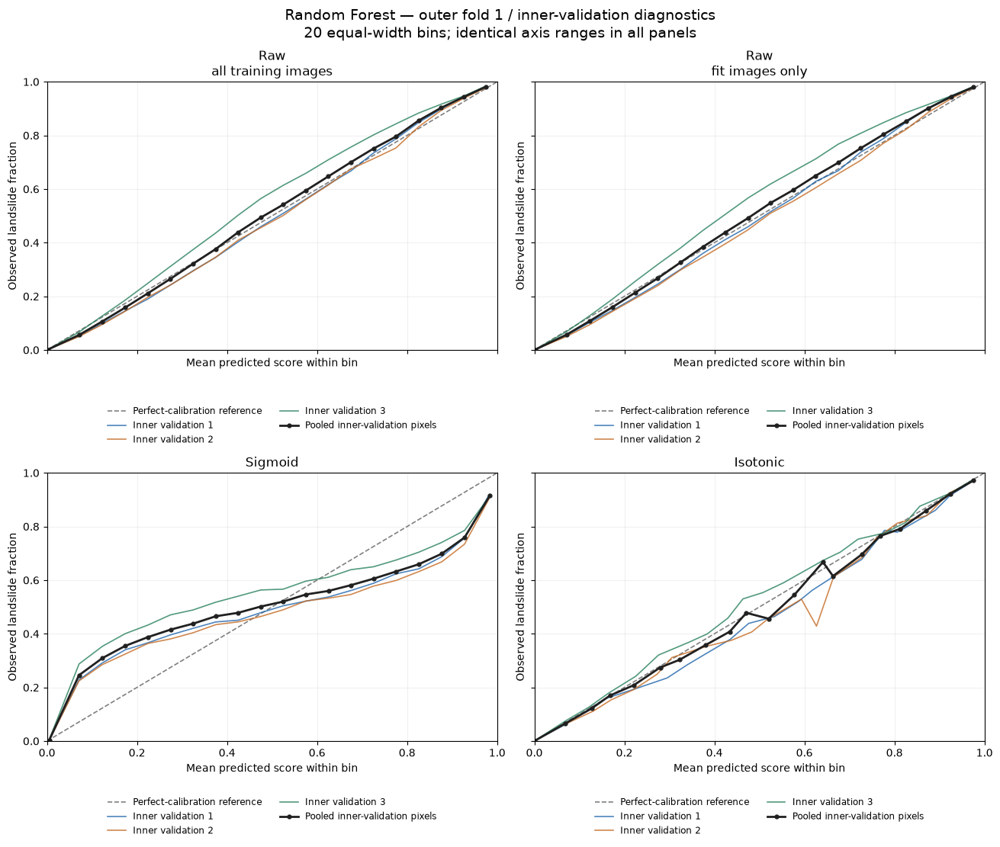


Raw — all training images — pooled bin counts and frequencies:


,Bin_lower,Bin_upper,Pixels,Mean_score,Observed_landslide_fraction
0,0.00,0.05,37342331,0.001691,0.001186
1,0.05,0.10,606432,0.071432,0.056087
2,0.10,0.15,314737,0.122994,0.106645
3,0.15,0.20,210698,0.173576,0.157871
4,0.20,0.25,155762,0.223914,0.211091
5,0.25,0.30,123597,0.274247,0.265225
6,0.30,0.35,103130,0.324330,0.321197
7,0.35,0.40,89393,0.374459,0.375924
8,0.40,0.45,79488,0.424629,0.438758
9,0.45,0.50,73469,0.474707,0.493487



Raw — fit images only — pooled bin counts and frequencies:


,Bin_lower,Bin_upper,Pixels,Mean_score,Observed_landslide_fraction
0,0.00,0.05,37334454,0.001720,0.001217
1,0.05,0.10,611075,0.071440,0.056906
2,0.10,0.15,319879,0.123025,0.107888
3,0.15,0.20,212428,0.173575,0.159654
4,0.20,0.25,157367,0.223891,0.213564
5,0.25,0.30,124261,0.274134,0.267357
6,0.30,0.35,103465,0.324363,0.325878
7,0.35,0.40,89769,0.374464,0.384309
8,0.40,0.45,80720,0.424558,0.438801
9,0.45,0.50,73370,0.474744,0.491700



Sigmoid — pooled bin counts and frequencies:


,Bin_lower,Bin_upper,Pixels,Mean_score,Observed_landslide_fraction
0,0.00,0.05,38553658,0.005179,0.004245
1,0.05,0.10,185587,0.071092,0.245481
2,0.10,0.15,91323,0.122961,0.309166
3,0.15,0.20,61611,0.173721,0.354677
4,0.20,0.25,46922,0.224064,0.387388
5,0.25,0.30,38851,0.274393,0.415408
6,0.30,0.35,33753,0.324498,0.437680
7,0.35,0.40,30361,0.374838,0.465202
8,0.40,0.45,27991,0.424730,0.478261
9,0.45,0.50,26642,0.474913,0.501501



Isotonic — pooled bin counts and frequencies:


,Bin_lower,Bin_upper,Pixels,Mean_score,Observed_landslide_fraction
0,0.00,0.05,37490376,0.001388,0.001389
1,0.05,0.10,532134,0.068112,0.065172
2,0.10,0.15,326846,0.127184,0.121378
3,0.15,0.20,109465,0.167834,0.169525
4,0.20,0.25,166901,0.221152,0.208435
5,0.25,0.30,147294,0.279564,0.274295
6,0.30,0.35,64060,0.322658,0.302966
7,0.35,0.40,56528,0.380961,0.358424
8,0.40,0.45,98371,0.433953,0.407742
9,0.45,0.50,58553,0.470981,0.477994


In [32]:
#Reliability curves
rf_pipeline_reliability_edges = np.linspace(0, 1, 21)
rf_pipeline_reliability_tables = {}
rf_pipeline_reliability_input_signatures = {}

for rf_inner_number in (1, 2, 3):
    rf_paths = rf_calibration_evaluation_records[rf_inner_number]

    rf_full_result = joblib.load(
        rf_paths["full_training_evaluation_path"]
    )
    rf_cal_result = joblib.load(
        rf_paths["calibration_evaluation_path"]
    )
    rf_label_bundle = joblib.load(
        rf_cal_result["shared_labels_path"]
    )

    rf_ids = rf_label_bundle["image_ids"]
    rf_labels = np.asarray(rf_label_bundle["labels"]).reshape(
        len(rf_ids), 128 * 128
    )

    assert rf_cal_result["image_ids"] == rf_ids
    assert rf_full_result["image_ids"] == rf_ids

    rf_pipeline_reliability_input_signatures[rf_inner_number] = {
        "full_training": rf_full_result["signature"],
        "calibration": rf_cal_result["signature"]
    }

    for rf_method in rf_calibration_method_names:
        rf_counts = np.zeros(20, dtype=np.int64)
        rf_positive_counts = np.zeros(20, dtype=np.int64)
        rf_score_sums = np.zeros(20, dtype=np.float64)

        rf_is_full_raw = rf_method == "Raw — all training images"

        rf_result = rf_full_result if rf_is_full_raw else rf_cal_result
        rf_score_paths = rf_result["prediction_files"]

        rf_image_offset = 0

        for rf_score_path in rf_score_paths:
            rf_chunk = joblib.load(rf_score_path)

            assert rf_chunk["signature"] == rf_result["signature"]
            rf_chunk_ids = rf_chunk["image_ids"]
            rf_image_stop = rf_image_offset + len(rf_chunk_ids)

            assert rf_chunk_ids == rf_ids[rf_image_offset:rf_image_stop]

            rf_scores = (
                rf_chunk["scores"]
                if rf_is_full_raw
                else rf_chunk["scores"][rf_method]
            )
            assert rf_scores.shape == (len(rf_chunk_ids), 128 * 128)

            rf_y = rf_labels[
                rf_image_offset:rf_image_stop
            ].reshape(-1)
            rf_scores = np.asarray(rf_scores).reshape(-1)

            assert np.isfinite(rf_scores).all()
            assert np.all((rf_scores >= 0) & (rf_scores <= 1))

            rf_bins = np.clip(
                np.searchsorted(
                    rf_pipeline_reliability_edges,
                    rf_scores,
                    side="right"
                ) - 1,
                0, 19
            )

            rf_counts += np.bincount(rf_bins, minlength=20)
            rf_positive_counts += np.bincount(
                rf_bins[rf_y == 1], minlength=20
            )
            rf_score_sums += np.bincount(
                rf_bins, weights=rf_scores, minlength=20
            )

            rf_image_offset = rf_image_stop

        assert rf_image_offset == len(rf_ids)
        assert rf_counts.sum() == rf_labels.size
        assert rf_positive_counts.sum() == np.sum(rf_labels == 1)

        rf_pipeline_reliability_tables[
            (rf_method, rf_inner_number)
        ] = pd.DataFrame({
            "Bin_lower": rf_pipeline_reliability_edges[:-1],
            "Bin_upper": rf_pipeline_reliability_edges[1:],
            "Pixels": rf_counts,
            "Landslide_pixels": rf_positive_counts,
            "Score_sum": rf_score_sums
        })

    del rf_labels, rf_label_bundle


def rf_finish_reliability_table(table):
    """Convert bin totals to mean scores and observed fractions."""
    result = table.copy()
    nonempty = result["Pixels"].to_numpy() > 0

    result["Mean_score"] = np.divide(
        result["Score_sum"].to_numpy(),
        result["Pixels"].to_numpy(),
        out=np.full(len(result), np.nan),
        where=nonempty
    )
    result["Observed_landslide_fraction"] = np.divide(
        result["Landslide_pixels"].to_numpy(),
        result["Pixels"].to_numpy(),
        out=np.full(len(result), np.nan),
        where=nonempty
    )
    return result


rf_pipeline_pooled_reliability = {}

for rf_method in rf_calibration_method_names:
    rf_tables = [
        rf_pipeline_reliability_tables[(rf_method, inner)]
        for inner in (1, 2, 3)
    ]

    rf_pooled = rf_tables[0][["Bin_lower", "Bin_upper"]].copy()

    for rf_column in ["Pixels", "Landslide_pixels", "Score_sum"]:
        rf_pooled[rf_column] = sum(
            table[rf_column].to_numpy() for table in rf_tables
        )

    rf_pipeline_pooled_reliability[rf_method] = (
        rf_finish_reliability_table(rf_pooled)
    )

    for rf_inner_number in (1, 2, 3):
        rf_key = (rf_method, rf_inner_number)
        rf_pipeline_reliability_tables[rf_key] = (
            rf_finish_reliability_table(
                rf_pipeline_reliability_tables[rf_key]
            )
        )


rf_reliability_figure, rf_reliability_axes = plt.subplots(
    2, 2, figsize=(13, 11),
    sharex=True, sharey=True,
    constrained_layout=True
)

rf_inner_colors = {
    1: "#2166AC",
    2: "#C46B24",
    3: "#27805C"
}

for rf_ax, rf_method in zip(
    rf_reliability_axes.flat,
    rf_calibration_method_names
):
    rf_ax.plot(
        [0, 1], [0, 1],
        color="gray", linestyle="--", linewidth=1.2,
        label="Perfect-calibration reference"
    )

    for rf_inner_number in (1, 2, 3):
        rf_table = rf_pipeline_reliability_tables[
            (rf_method, rf_inner_number)
        ]

        rf_ax.plot(
            rf_table["Mean_score"],
            rf_table["Observed_landslide_fraction"],
            color=rf_inner_colors[rf_inner_number],
            linewidth=1.2, alpha=0.8,
            label=f"Inner validation {rf_inner_number}"
        )

    rf_pooled = rf_pipeline_pooled_reliability[rf_method]
    rf_ax.plot(
        rf_pooled["Mean_score"],
        rf_pooled["Observed_landslide_fraction"],
        color="#202020", linewidth=2,
        marker="o", markersize=3.5,
        label="Pooled inner-validation pixels"
    )

    rf_ax.set(
        title=rf_method.replace(" — ", "\n"),
        xlabel="Mean predicted score within bin",
        ylabel="Observed landslide fraction",
        xlim=(0, 1),
        ylim=(0, 1)
    )
    rf_ax.grid(alpha=0.18)
    rf_ax.title.set_fontweight("normal")
    rf_ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2, fontsize=8.5,
        frameon=False
    )

rf_reliability_figure.suptitle(
    "Random Forest — outer fold 1 / inner-validation diagnostics\n"
    "20 equal-width bins; identical axis ranges in all panels",
    fontsize=14,
    fontweight="normal"
)

rf_calibration_figures_dir = rf_calibration_root / "figures"
rf_calibration_figures_dir.mkdir(parents=True, exist_ok=True)

rf_reliability_figure.savefig(
    rf_calibration_figures_dir / "pipeline_reliability_comparison.png",
    dpi=200, bbox_inches="tight"
)
rf_reliability_figure.savefig(
    rf_calibration_figures_dir / "pipeline_reliability_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

joblib.dump(
    {
        "bin_edges": rf_pipeline_reliability_edges,
        "input_signatures": rf_pipeline_reliability_input_signatures,
        "per_inner_split": rf_pipeline_reliability_tables,
        "pooled": rf_pipeline_pooled_reliability,
        "role": "training_side_inner_validation_diagnostics"
    },
    rf_calibration_root / "pipeline_reliability_diagnostics.joblib"
)

for rf_method in rf_calibration_method_names:
    print(f"\n{rf_method} — pooled bin counts and frequencies:")
    display(
        rf_pipeline_pooled_reliability[rf_method][[
            "Bin_lower", "Bin_upper", "Pixels",
            "Mean_score", "Observed_landslide_fraction"
        ]].round(6)
    )

Rationale: Examine score calibration across all three inner-validation splits and verify pooled patterns against bin tables.
Result: The tuned raw-score alternatives are reasonably close to the diagonal in the displayed bins. Sigmoid introduces a systematic curved mismatch; isotonic is generally close but shows local and split-level variation. These diagnostics support retaining the current F2-based selection, without establishing perfect calibration or outer-evaluation performance.

In [33]:
rf_learning_fractions = (0.25, 0.50, 1.00)
rf_learning_params = dict(rf_outer1_working_spec["params"])
rf_learning_threshold = float(rf_outer1_pipeline_selection["threshold"])

assert rf_outer1_pipeline_selection["method"] == (
    "Raw — all training images"
)

rf_learning_root = rf_checkpoint_dir / "learning_curve" / "outer_1"
rf_learning_root.mkdir(parents=True, exist_ok=True)

rf_learning_model_records = {}
rf_learning_fit_rows = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1
    rf_inner_split = nested_splits[0]["inner_splits"][rf_inner_position]

    rf_all_training_ids = np.asarray(
        rf_inner_split["train_ids"]
    ).astype(str)
    rf_validation_id_set = set(
        np.asarray(rf_inner_split["validation_ids"]).astype(str)
    )

    # A fixed image ordering produces nested training subsets.
    rf_learning_rng = np.random.default_rng(
        np.random.SeedSequence([
            int(RANDOM_STATE), 1, rf_inner_number, 25050
        ])
    )
    rf_image_order = rf_learning_rng.permutation(
        len(rf_all_training_ids)
    )

    rf_learning_model_records[rf_inner_number] = {}

    for rf_fraction in rf_learning_fractions:
        rf_image_count = (
            len(rf_all_training_ids)
            if rf_fraction == 1.0
            else max(1, int(np.floor(
                rf_fraction * len(rf_all_training_ids)
            )))
        )

        # Preserve original split order within each selected subset.
        rf_selected_positions = np.sort(
            rf_image_order[:rf_image_count]
        )
        rf_subset_ids = rf_all_training_ids[rf_selected_positions]

        assert set(rf_subset_ids).isdisjoint(rf_validation_id_set)

        print(
            f"\nInner split {rf_inner_number}/3 — "
            f"{rf_fraction:.0%}: {rf_image_count} training images",
            flush=True
        )

        if rf_fraction == 1.0:
            rf_reference = rf_tree_check_records[rf_inner_number][200]
            rf_bundle = joblib.load(rf_reference["model_path"])

            assert rf_bundle["signature"] == rf_reference["signature"]
            assert rf_bundle["metadata"]["ordered_training_ids"] == (
                rf_subset_ids.tolist()
            )
            assert rf_bundle["model"].get_params() == (
                RandomForestClassifier(**rf_learning_params).get_params()
            )

            rf_model_path = Path(rf_reference["model_path"])
            rf_model_signature = rf_reference["signature"]
            rf_fit_seconds = (
                rf_bundle["source_100_fit_seconds"]
                + rf_bundle["incremental_fit_seconds"]
            )
            rf_status = "Reused existing 200-tree model"

        else:
            rf_X_learning, rf_y_learning = rf_get_sampled_training_data(
                rf_subset_ids,
                rf_sampled_patch_ids,
                rf_X_samples,
                rf_y_samples
            )
            assert set(np.unique(rf_y_learning).tolist()) == {0, 1}

            rf_data_hasher = hashlib.sha256()
            for rf_array in (rf_X_learning, rf_y_learning):
                for rf_start in range(0, len(rf_array), 8192):
                    rf_data_hasher.update(
                        rf_array[rf_start:rf_start + 8192].tobytes()
                    )

            rf_metadata = {
                "role": "training_image_learning_curve",
                "outer_fold": 1,
                "inner_split": rf_inner_number,
                "fraction": rf_fraction,
                "ordered_training_ids": rf_subset_ids.tolist(),
                "params": rf_learning_params,
                "features": list(FEATURE_NAMES),
                "samples_per_image": 1024,
                "data_hash": rf_data_hasher.hexdigest(),
                "python_version": platform.python_version(),
                "numpy_version": np.__version__,
                "sklearn_version": sklearn.__version__
            }

            rf_model_signature = hashlib.sha256(
                json.dumps(
                    rf_metadata,
                    sort_keys=True,
                    default=lambda value: value.item()
                ).encode("utf-8")
            ).hexdigest()

            rf_model_dir = rf_learning_root / f"inner_{rf_inner_number}"
            rf_model_dir.mkdir(parents=True, exist_ok=True)
            rf_model_path = (
                rf_model_dir / f"model_{rf_model_signature}.joblib"
            )

            if rf_model_path.is_file():
                rf_bundle = joblib.load(rf_model_path)
                assert rf_bundle["signature"] == rf_model_signature
                rf_fit_seconds = rf_bundle["fit_seconds"]
                rf_status = "Loaded checkpoint"

            else:
                rf_model = RandomForestClassifier(**rf_learning_params)

                rf_start_time = perf_counter()
                rf_model.fit(rf_X_learning, rf_y_learning)
                rf_fit_seconds = perf_counter() - rf_start_time

                rf_bundle = {
                    "signature": rf_model_signature,
                    "metadata": rf_metadata,
                    "model": rf_model,
                    "fit_seconds": rf_fit_seconds
                }

                rf_temp = rf_model_path.with_suffix(".tmp")
                joblib.dump(rf_bundle, rf_temp)
                rf_temp.replace(rf_model_path)
                rf_status = "New model fitted"
                del rf_model

            assert rf_bundle["model"].get_params() == (
                RandomForestClassifier(**rf_learning_params).get_params()
            )
            del rf_X_learning, rf_y_learning

        rf_learning_model_records[rf_inner_number][rf_fraction] = {
            "signature": rf_model_signature,
            "model_path": str(rf_model_path),
            "training_ids": rf_subset_ids.tolist(),
            "fraction": rf_fraction,
            "training_images": rf_image_count,
            "params": dict(rf_learning_params)
        }

        rf_learning_fit_rows.append({
            "Inner_split": rf_inner_number,
            "Training_fraction": rf_fraction,
            "Training_images": rf_image_count,
            "Training_pixels": rf_image_count * 1024,
            "Recorded_fit_seconds": rf_fit_seconds,
            "Status": rf_status
        })

        print(f"{rf_status}: {rf_fit_seconds:.2f} seconds", flush=True)
        del rf_bundle

rf_learning_fit_table = pd.DataFrame(rf_learning_fit_rows)

joblib.dump(
    {
        "model_records": rf_learning_model_records,
        "fitting_table": rf_learning_fit_table,
        "fixed_threshold": rf_learning_threshold,
        "fractions": rf_learning_fractions
    },
    rf_learning_root / "learning_curve_preparation.joblib"
)
rf_learning_fit_table.to_csv(
    rf_learning_root / "fitting_summary.csv",
    index=False
)

display(rf_learning_fit_table.round(2))

print("\nModels prepared; learning-curve performance is not yet evaluated.")
print("The 100% fitting time includes the original fit and tree extension.")
print("Reused models incurred no new fitting in this cell.")
print("No outer-evaluation or holdout images were used.")


Inner split 1/3 — 25%: 405 training images
New model fitted: 54.97 seconds

Inner split 1/3 — 50%: 810 training images
New model fitted: 124.42 seconds

Inner split 1/3 — 100%: 1620 training images
Reused existing 200-tree model: 299.78 seconds

Inner split 2/3 — 25%: 405 training images
New model fitted: 56.63 seconds

Inner split 2/3 — 50%: 810 training images
New model fitted: 127.44 seconds

Inner split 2/3 — 100%: 1621 training images
Reused existing 200-tree model: 295.92 seconds

Inner split 3/3 — 25%: 405 training images
New model fitted: 52.52 seconds

Inner split 3/3 — 50%: 810 training images
New model fitted: 125.74 seconds

Inner split 3/3 — 100%: 1621 training images
Reused existing 200-tree model: 291.46 seconds


,Inner_split,Training_fraction,Training_images,Training_pixels,Recorded_fit_seconds,Status
0,1,0.25,405,414720,54.97,New model fitted
1,1,0.50,810,829440,124.42,New model fitted
2,1,1.00,1620,1658880,299.78,Reused existing 200-tree model
3,2,0.25,405,414720,56.63,New model fitted
4,2,0.50,810,829440,127.44,New model fitted
5,2,1.00,1621,1659904,295.92,Reused existing 200-tree model
6,3,0.25,405,414720,52.52,New model fitted
7,3,0.50,810,829440,125.74,New model fitted
8,3,1.00,1621,1659904,291.46,Reused existing 200-tree model



Models prepared; learning-curve performance is not yet evaluated.
The 100% fitting time includes the original fit and tree extension.
Reused models incurred no new fitting in this cell.
No outer-evaluation or holdout images were used.


In [34]:
rf_learning_evaluation_rows = []
rf_learning_evaluation_records = {}

for rf_inner_number in (1, 2, 3):
    # Reference validation data and completed full-size evaluation.
    rf_full_result_path = (
        rf_calibration_evaluation_records[rf_inner_number][
            "full_training_evaluation_path"
        ]
    )
    rf_full_result = joblib.load(rf_full_result_path)
    rf_source_records = rf_full_result["metadata"]["sources"]

    for rf_source in rf_source_records:
        for rf_file_record in rf_source["files"]:
            rf_path = Path(rf_file_record["path"])
            rf_stat = rf_path.stat()
            assert rf_stat.st_size == rf_file_record["size"]
            assert rf_stat.st_mtime_ns == rf_file_record["mtime_ns"]

    rf_label_bundle = joblib.load(
        rf_full_result["shared_labels_path"]
    )
    rf_validation_ids = rf_label_bundle["image_ids"]
    rf_validation_y = np.asarray(rf_label_bundle["labels"]).reshape(-1)

    rf_expected_ids = sorted(
        np.asarray(
            nested_splits[0]["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )
    assert rf_validation_ids == rf_expected_ids
    assert rf_validation_y.size == len(rf_expected_ids) * 128 * 128

    rf_learning_evaluation_records[rf_inner_number] = {}

    for rf_fraction in rf_learning_fractions:
        rf_record = rf_learning_model_records[
            rf_inner_number
        ][rf_fraction]

        rf_training_ids = np.asarray(
            rf_record["training_ids"]
        ).astype(str)
        assert set(rf_training_ids).isdisjoint(set(rf_validation_ids))

        rf_X_train, rf_y_train = rf_get_sampled_training_data(
            rf_training_ids,
            rf_sampled_patch_ids,
            rf_X_samples,
            rf_y_samples
        )

        rf_training_hasher = hashlib.sha256()
        for rf_array in (rf_X_train, rf_y_train):
            for rf_start in range(0, len(rf_array), 8192):
                rf_training_hasher.update(
                    rf_array[rf_start:rf_start + 8192].tobytes()
                )

        rf_bundle = joblib.load(rf_record["model_path"])
        assert rf_bundle["signature"] == rf_record["signature"]
        assert rf_bundle["metadata"]["ordered_training_ids"] == (
            rf_training_ids.tolist()
        )

        rf_saved_data_hash = (
            rf_bundle["metadata"]["training_data_hash"]
            if rf_fraction == 1.0
            else rf_bundle["metadata"]["data_hash"]
        )
        assert rf_training_hasher.hexdigest() == rf_saved_data_hash

        rf_model = rf_bundle["model"]
        assert rf_model.get_params() == (
            RandomForestClassifier(**rf_learning_params).get_params()
        )

        rf_eval_metadata = {
            "model_signature": rf_record["signature"],
            "training_data_hash": rf_saved_data_hash,
            "validation_sources": rf_source_records,
            "threshold": rf_learning_threshold,
            "beta": float(BETA),
            "log_loss_epsilon": float(rf_log_loss_epsilon),
            "sklearn_version": sklearn.__version__,
            "evaluation_code_version": 1
        }

        rf_signature = hashlib.sha256(
            json.dumps(rf_eval_metadata, sort_keys=True).encode("utf-8")
        ).hexdigest()

        rf_eval_dir = (
            rf_learning_root / f"inner_{rf_inner_number}"
            / "evaluation" / rf_signature
        )
        rf_eval_dir.mkdir(parents=True, exist_ok=True)
        rf_result_path = rf_eval_dir / "evaluation.joblib"

        print(
            f"\nInner split {rf_inner_number}/3 — "
            f"{rf_fraction:.0%} training images",
            flush=True
        )

        if rf_result_path.is_file():
            rf_result = joblib.load(rf_result_path)
            assert rf_result["signature"] == rf_signature
            print("Loaded completed evaluation.", flush=True)

        else:
            rf_positive_column = np.flatnonzero(
                rf_model.classes_ == 1
            ).item()

            # Training predictions are saved separately for restartability.
            rf_train_score_path = rf_eval_dir / "training_scores.joblib"

            if rf_train_score_path.is_file():
                rf_train_cache = joblib.load(rf_train_score_path)
                assert rf_train_cache["signature"] == rf_signature
                rf_training_scores = rf_train_cache["scores"]
                rf_training_prediction_seconds = (
                    rf_train_cache["prediction_seconds"]
                )
                del rf_train_cache

            else:
                rf_training_scores = np.empty(
                    len(rf_y_train), dtype=np.float64
                )

                rf_start_time = perf_counter()
                for rf_start in range(0, len(rf_y_train), 65536):
                    rf_stop = min(rf_start + 65536, len(rf_y_train))
                    rf_training_scores[rf_start:rf_stop] = (
                        rf_model.predict_proba(
                            rf_X_train[rf_start:rf_stop]
                        )[:, rf_positive_column]
                    )
                rf_training_prediction_seconds = (
                    perf_counter() - rf_start_time
                )

                rf_temp = rf_train_score_path.with_suffix(".tmp")
                joblib.dump({
                    "signature": rf_signature,
                    "training_ids": rf_training_ids.tolist(),
                    "scores": rf_training_scores,
                    "prediction_seconds": rf_training_prediction_seconds
                }, rf_temp)
                rf_temp.replace(rf_train_score_path)

            assert rf_training_scores.shape == rf_y_train.shape

            rf_training_metrics = rf_binary_metrics(
                rf_y_train, rf_training_scores,
                threshold=rf_learning_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )
            del rf_training_scores

            if rf_fraction == 1.0:
                # Reuse ranking/probability metrics and the saved threshold row.
                assert (
                    rf_full_result["metadata"]["model_signature"]
                    == rf_record["signature"]
                )
                rf_threshold_row = rf_full_result["threshold_table"].loc[
                    np.isclose(
                        rf_full_result["threshold_table"]["Threshold"],
                        rf_learning_threshold,
                        rtol=0, atol=rf_selection_tolerance
                    )
                ]
                assert len(rf_threshold_row) == 1
                rf_threshold_row = rf_threshold_row.iloc[0]

                rf_validation_metrics = dict(
                    rf_full_result["metrics_at_050"]
                )
                for rf_name in [
                    "TN", "FP", "FN", "TP",
                    "F2", "Precision", "Recall", "Specificity", "IoU"
                ]:
                    rf_validation_metrics[rf_name] = (
                        int(rf_threshold_row[rf_name])
                        if rf_name in ["TN", "FP", "FN", "TP"]
                        else float(rf_threshold_row[rf_name])
                    )

                rf_validation_metrics["Threshold"] = rf_learning_threshold
                rf_validation_metrics["Predicted_positive_pixels"] = (
                    rf_validation_metrics["TP"] + rf_validation_metrics["FP"]
                )
                rf_validation_metrics["Accuracy"] = (
                    rf_validation_metrics["TN"] + rf_validation_metrics["TP"]
                ) / rf_validation_metrics["Pixels"]

                rf_prediction_files = rf_full_result["prediction_files"]
                rf_validation_prediction_seconds = (
                    rf_full_result["prediction_seconds"]
                )
                rf_validation_origin = "Reused full-size evaluation"

            else:
                rf_score_parts = []
                rf_prediction_files = []
                rf_validation_prediction_seconds = 0.0

                for rf_start in range(0, len(rf_validation_ids), 25):
                    rf_chunk_ids = rf_validation_ids[rf_start:rf_start + 25]
                    rf_chunk_path = (
                        rf_eval_dir / f"validation_scores_{rf_start:04d}.joblib"
                    )

                    if rf_chunk_path.is_file():
                        rf_chunk = joblib.load(rf_chunk_path)
                        assert rf_chunk["signature"] == rf_signature
                        assert rf_chunk["image_ids"] == rf_chunk_ids

                    else:
                        rf_score_rows = []
                        rf_chunk_seconds = 0.0

                        for rf_image_id in rf_chunk_ids:
                            rf_path = (
                                Path(DATA_DIR) / "TrainData" / "img"
                                / f"image_{rf_image_id}.h5"
                            )
                            with h5py.File(rf_path, "r") as rf_file:
                                rf_image = np.asarray(rf_file["img"])

                            if (
                                rf_image.shape != (128, 128, 14)
                                or not np.isfinite(rf_image).all()
                            ):
                                raise ValueError(
                                    f"Invalid image: {rf_image_id}"
                                )

                            rf_start_time = perf_counter()
                            rf_score_rows.append(
                                rf_model.predict_proba(
                                    rf_image.reshape(-1, 14)
                                )[:, rf_positive_column]
                            )
                            rf_chunk_seconds += (
                                perf_counter() - rf_start_time
                            )

                        rf_chunk = {
                            "signature": rf_signature,
                            "image_ids": rf_chunk_ids,
                            "scores": np.stack(rf_score_rows),
                            "prediction_seconds": rf_chunk_seconds
                        }
                        rf_temp = rf_chunk_path.with_suffix(".tmp")
                        joblib.dump(rf_chunk, rf_temp)
                        rf_temp.replace(rf_chunk_path)

                    assert rf_chunk["scores"].shape == (
                        len(rf_chunk_ids), 128 * 128
                    )
                    rf_score_parts.append(rf_chunk["scores"])
                    rf_prediction_files.append(str(rf_chunk_path))
                    rf_validation_prediction_seconds += (
                        rf_chunk["prediction_seconds"]
                    )

                    print(
                        f"  {rf_start + len(rf_chunk_ids)}/"
                        f"{len(rf_validation_ids)} validation images",
                        flush=True
                    )

                rf_validation_scores = np.concatenate(
                    rf_score_parts
                ).reshape(-1)
                del rf_score_parts

                rf_validation_metrics = rf_binary_metrics(
                    rf_validation_y, rf_validation_scores,
                    threshold=rf_learning_threshold,
                    beta=float(BETA),
                    log_loss_epsilon=rf_log_loss_epsilon
                )
                rf_validation_origin = "Learning-curve prediction checkpoints"
                del rf_validation_scores

            rf_result = {
                "signature": rf_signature,
                "metadata": rf_eval_metadata,
                "training_metrics": rf_training_metrics,
                "validation_metrics": rf_validation_metrics,
                "training_scores_path": str(rf_train_score_path),
                "validation_prediction_files": rf_prediction_files,
                "validation_origin": rf_validation_origin,
                "shared_labels_path": rf_full_result["shared_labels_path"],
                "training_prediction_seconds": rf_training_prediction_seconds,
                "validation_prediction_seconds": (
                    rf_validation_prediction_seconds
                )
            }

            rf_temp = rf_result_path.with_suffix(".tmp")
            joblib.dump(rf_result, rf_temp)
            rf_temp.replace(rf_result_path)

        rf_train_metrics = rf_result["training_metrics"]
        rf_val_metrics = rf_result["validation_metrics"]

        rf_learning_evaluation_rows.append({
            "Inner_split": rf_inner_number,
            "Training_fraction": rf_fraction,
            "Training_images": len(rf_training_ids),
            "Threshold": rf_learning_threshold,
            "Training_F2": rf_train_metrics["F2"],
            "Validation_F2": rf_val_metrics["F2"],
            "F2_gap": rf_train_metrics["F2"] - rf_val_metrics["F2"],
            "Training_precision": rf_train_metrics["Precision"],
            "Validation_precision": rf_val_metrics["Precision"],
            "Training_recall": rf_train_metrics["Recall"],
            "Validation_recall": rf_val_metrics["Recall"]
        })

        rf_learning_evaluation_records[rf_inner_number][rf_fraction] = (
            str(rf_result_path)
        )

        del rf_X_train, rf_y_train, rf_model, rf_bundle

    del rf_validation_y, rf_label_bundle


rf_learning_per_split = pd.DataFrame(rf_learning_evaluation_rows)

rf_learning_summary = (
    rf_learning_per_split
    .groupby("Training_fraction", as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Training_images_min=("Training_images", "min"),
        Training_images_max=("Training_images", "max"),
        Mean_training_F2=("Training_F2", "mean"),
        Mean_validation_F2=("Validation_F2", "mean"),
        SD_validation_F2=("Validation_F2", "std"),
        Mean_F2_gap=("F2_gap", "mean"),
        Mean_validation_precision=("Validation_precision", "mean"),
        Mean_validation_recall=("Validation_recall", "mean")
    )
)

assert (rf_learning_summary["Inner_splits"] == 3).all()

rf_full_learning_row = rf_learning_summary.loc[
    rf_learning_summary["Training_fraction"] == 1.0
].iloc[0]

assert np.isclose(
    rf_full_learning_row["Mean_validation_F2"],
    rf_outer1_pipeline_ranking.loc[
        rf_outer1_pipeline_ranking["Method"]
        == "Raw — all training images",
        "Mean_F2"
    ].iloc[0],
    rtol=0, atol=rf_selection_tolerance
)

joblib.dump(
    {
        "per_split": rf_learning_per_split,
        "summary": rf_learning_summary,
        "evaluation_records": rf_learning_evaluation_records,
        "fixed_threshold": rf_learning_threshold
    },
    rf_learning_root / "learning_curve_results.joblib"
)

rf_learning_per_split.to_csv(
    rf_learning_root / "learning_curve_per_split.csv", index=False
)
rf_learning_summary.to_csv(
    rf_learning_root / "learning_curve_summary.csv", index=False
)

print("\nResults by inner split:")
display(rf_learning_per_split.round(6))

print("\nThree-split summary:")
display(rf_learning_summary.round(6))

print("\nThreshold fixed at:", rf_learning_threshold)
print("Training: sampled pixels used for fitting.")
print("Validation: every pixel of the corresponding validation images.")
print("100% validation results reproduced the prior selection.")
print("SD is descriptive; these are training-side diagnostic results.")


Inner split 1/3 — 25% training images
  25/811 validation images
  50/811 validation images
  75/811 validation images
  100/811 validation images
  125/811 validation images
  150/811 validation images
  175/811 validation images
  200/811 validation images
  225/811 validation images
  250/811 validation images
  275/811 validation images
  300/811 validation images
  325/811 validation images
  350/811 validation images
  375/811 validation images
  400/811 validation images
  425/811 validation images
  450/811 validation images
  475/811 validation images
  500/811 validation images
  525/811 validation images
  550/811 validation images
  575/811 validation images
  600/811 validation images
  625/811 validation images
  650/811 validation images
  675/811 validation images
  700/811 validation images
  725/811 validation images
  750/811 validation images
  775/811 validation images
  800/811 validation images
  811/811 validation images

Inner split 1/3 — 50% training images
 

,Inner_split,Training_fraction,Training_images,Threshold,Training_F2,Validation_F2,F2_gap,Training_precision,Validation_precision,Training_recall,Validation_recall
0,1,0.25,405,0.17,0.912721,0.751222,0.161499,0.676713,0.497319,0.999901,0.861133
1,1,0.50,810,0.17,0.914078,0.758247,0.155831,0.680473,0.508912,0.999894,0.864084
2,1,1.00,1620,0.17,0.911132,0.768824,0.142309,0.672562,0.524877,0.999794,0.869899
3,2,0.25,405,0.17,0.916856,0.740300,0.176556,0.688200,0.482881,0.999911,0.854131
4,2,0.50,810,0.17,0.913703,0.748817,0.164886,0.679506,0.500142,0.999855,0.855109
5,2,1.00,1621,0.17,0.912015,0.757701,0.154314,0.674867,0.511806,0.999852,0.861133
6,3,0.25,405,0.17,0.914042,0.771681,0.142361,0.680176,0.565670,1.000000,0.848979
7,3,0.50,810,0.17,0.912785,0.785607,0.127179,0.677023,0.585958,0.999829,0.858756
8,3,1.00,1621,0.17,0.907760,0.792249,0.115511,0.663632,0.594823,0.999699,0.863936



Three-split summary:


,Training_fraction,Inner_splits,Training_images_min,Training_images_max,Mean_training_F2,Mean_validation_F2,SD_validation_F2,Mean_F2_gap,Mean_validation_precision,Mean_validation_recall
0,0.25,3,405,405,0.914539,0.754401,0.015931,0.160139,0.515290,0.854748
1,0.50,3,810,810,0.913522,0.764224,0.019109,0.149298,0.531671,0.859316
2,1.00,3,1620,1621,0.910302,0.772925,0.017635,0.137378,0.543835,0.864989



Threshold fixed at: 0.17
Training: sampled pixels used for fitting.
Validation: every pixel of the corresponding validation images.
100% validation results reproduced the prior selection.
SD is descriptive; these are training-side diagnostic results.


Rationale: Examine how training-image count affects learning and the training–validation gap.
Result: Mean validation F2 increased from 0.754401 to 0.772925 as training images increased from 405 to approximately 1,621. Precision and recall improved, while the mean F2 gap narrowed from 0.160139 to 0.137378. A substantial gap remains, and performance saturation has not been established.

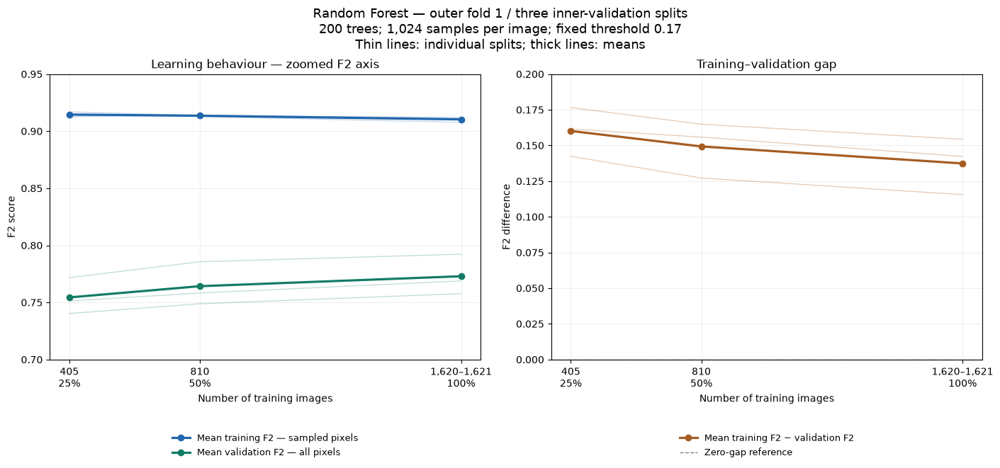

In [35]:
import matplotlib.pyplot as plt
import numpy as np

rf_lc_summary = rf_learning_summary.sort_values(
    "Training_fraction"
).copy()

rf_lc_mean_images = (
    rf_learning_per_split
    .groupby("Training_fraction")["Training_images"]
    .mean()
    .reindex(rf_lc_summary["Training_fraction"])
    .to_numpy()
)

rf_lc_figure, rf_lc_axes = plt.subplots(
    1, 2,
    figsize=(14, 6.5),
    constrained_layout=True
)

rf_train_color = "#2166AC"
rf_validation_color = "#137C66"
rf_gap_color = "#A65C21"

# Individual inner-split results.
for rf_inner_number in (1, 2, 3):
    rf_rows = (
        rf_learning_per_split.loc[
            rf_learning_per_split["Inner_split"] == rf_inner_number
        ]
        .sort_values("Training_fraction")
    )

    rf_lc_axes[0].plot(
        rf_rows["Training_images"],
        rf_rows["Training_F2"],
        color=rf_train_color,
        linewidth=1,
        alpha=0.25
    )
    rf_lc_axes[0].plot(
        rf_rows["Training_images"],
        rf_rows["Validation_F2"],
        color=rf_validation_color,
        linewidth=1,
        alpha=0.25
    )
    rf_lc_axes[1].plot(
        rf_rows["Training_images"],
        rf_rows["F2_gap"],
        color=rf_gap_color,
        linewidth=1,
        alpha=0.30
    )

# Mean training and validation performance.
rf_lc_axes[0].plot(
    rf_lc_mean_images,
    rf_lc_summary["Mean_training_F2"],
    color=rf_train_color,
    marker="o",
    linewidth=2.3,
    label="Mean training F2 — sampled pixels"
)
rf_lc_axes[0].plot(
    rf_lc_mean_images,
    rf_lc_summary["Mean_validation_F2"],
    color=rf_validation_color,
    marker="o",
    linewidth=2.3,
    label="Mean validation F2 — all pixels"
)

rf_lc_axes[0].set(
    title="Learning behaviour — zoomed F2 axis",
    xlabel="Number of training images",
    ylabel="F2 score",
    ylim=(0.70, 0.95)
)

# Mean generalization gap.
rf_lc_axes[1].plot(
    rf_lc_mean_images,
    rf_lc_summary["Mean_F2_gap"],
    color=rf_gap_color,
    marker="o",
    linewidth=2.3,
    label="Mean training F2 − validation F2"
)
rf_lc_axes[1].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1,
    label="Zero-gap reference"
)

rf_lc_axes[1].set(
    title="Training–validation gap",
    xlabel="Number of training images",
    ylabel="F2 difference",
    ylim=(0, 0.20)
)

rf_lc_tick_labels = [
    f"405\n25%",
    f"810\n50%",
    f"1,620–1,621\n100%"
]

for rf_ax in rf_lc_axes:
    rf_ax.set_xticks(rf_lc_mean_images, labels=rf_lc_tick_labels)
    rf_ax.tick_params(labelsize=10)
    rf_ax.grid(alpha=0.20)
    rf_ax.title.set_fontweight("normal")
    rf_ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.23),
        fontsize=9,
        frameon=False
    )

rf_lc_figure.suptitle(
    "Random Forest — outer fold 1 / three inner-validation splits\n"
    "200 trees; 1,024 samples per image; fixed threshold 0.17\n"
    "Thin lines: individual splits; thick lines: means",
    fontsize=13,
    fontweight="normal"
)

rf_learning_figures_dir = rf_learning_root / "figures"
rf_learning_figures_dir.mkdir(parents=True, exist_ok=True)

rf_lc_figure.savefig(
    rf_learning_figures_dir / "training_image_learning_curve.png",
    dpi=200,
    bbox_inches="tight"
)
rf_lc_figure.savefig(
    rf_learning_figures_dir / "training_image_learning_curve.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Visualize how training-image count affects performance and the training–validation gap.
Result: Mean validation F2 increased from 0.7544 to 0.7729, while the mean F2 gap narrowed from 0.1601 to 0.1374. More training images helped, but a substantial gap remains and saturation has not been established.

In [36]:
# Prepare the locked outer-fold-1 model.
rf_outer1_split = nested_splits[0]

assert rf_outer1_pipeline_selection["method"] == (
    "Raw — all training images"
)

rf_outer1_train_ids = np.asarray(
    rf_outer1_split["train_ids"]
).astype(str)

rf_outer1_evaluation_ids = np.asarray(
    rf_outer1_split["evaluation_ids"]
).astype(str)

assert len(np.unique(rf_outer1_train_ids)) == len(rf_outer1_train_ids)
assert len(np.unique(rf_outer1_evaluation_ids)) == (
    len(rf_outer1_evaluation_ids)
)
assert set(rf_outer1_train_ids).isdisjoint(
    set(rf_outer1_evaluation_ids)
)
assert (
    set(rf_outer1_train_ids) | set(rf_outer1_evaluation_ids)
    == set(np.asarray(dev_ids).astype(str))
)
assert set(rf_outer1_train_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer1_training_X, rf_outer1_training_y = (
    rf_get_sampled_training_data(
        rf_outer1_train_ids,
        rf_sampled_patch_ids,
        rf_X_samples,
        rf_y_samples
    )
)

assert rf_outer1_training_X.shape == (
    len(rf_outer1_train_ids) * 1024,
    len(FEATURE_NAMES)
)
assert set(np.unique(rf_outer1_training_y).tolist()) == {0, 1}

rf_outer1_training_hasher = hashlib.sha256()

for rf_array in (rf_outer1_training_X, rf_outer1_training_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_outer1_training_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

rf_outer1_locked_spec = {
    "role": "locked_outer_fold_1_specification",
    "outer_fold": int(rf_outer1_split["outer_fold"]),
    "selection_signature": rf_outer1_pipeline_selection["signature"],
    "params": dict(rf_outer1_pipeline_selection["params"]),
    "probability_method": "uncalibrated",
    "threshold": float(rf_outer1_pipeline_selection["threshold"]),
    "samples_per_image": int(
        rf_outer1_pipeline_selection["samples_per_image"]
    ),
    "ordered_training_ids": rf_outer1_train_ids.tolist(),
    "evaluation_ids": rf_outer1_evaluation_ids.tolist(),
    "training_data_hash": rf_outer1_training_hasher.hexdigest(),
    "features": list(FEATURE_NAMES),
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_log_loss_epsilon),
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__
}

rf_outer1_locked_json = json.dumps(
    rf_outer1_locked_spec,
    sort_keys=True,
    indent=2,
    default=lambda value: value.item()
)

rf_outer1_locked_signature = hashlib.sha256(
    rf_outer1_locked_json.encode("utf-8")
).hexdigest()

rf_outer1_model_dir = (
    rf_checkpoint_dir / "outer_models" / "outer_1"
    / rf_outer1_locked_signature
)
rf_outer1_model_dir.mkdir(parents=True, exist_ok=True)

rf_outer1_spec_path = rf_outer1_model_dir / "locked_specification.json"
rf_outer1_model_path = rf_outer1_model_dir / "fitted_model.joblib"

# Persist the specification before fitting or outer evaluation.
if rf_outer1_spec_path.is_file():
    assert rf_outer1_spec_path.read_text(
        encoding="utf-8"
    ) == rf_outer1_locked_json
else:
    rf_temp = rf_outer1_spec_path.with_suffix(".tmp")
    rf_temp.write_text(rf_outer1_locked_json, encoding="utf-8")
    rf_temp.replace(rf_outer1_spec_path)

if rf_outer1_model_path.is_file():
    rf_outer1_model_bundle = joblib.load(rf_outer1_model_path)
    assert rf_outer1_model_bundle["signature"] == (
        rf_outer1_locked_signature
    )
    print("Loaded matching outer-fold-1 model checkpoint.")

else:
    rf_outer1_model = RandomForestClassifier(
        **rf_outer1_locked_spec["params"]
    )

    print(
        f"Training outer-fold-1 model on "
        f"{len(rf_outer1_train_ids)} images...",
        flush=True
    )

    rf_start_time = perf_counter()
    rf_outer1_model.fit(
        rf_outer1_training_X, rf_outer1_training_y
    )
    rf_outer1_fit_seconds = perf_counter() - rf_start_time

    rf_outer1_model_bundle = {
        "signature": rf_outer1_locked_signature,
        "specification": rf_outer1_locked_spec,
        "model": rf_outer1_model,
        "fit_seconds": rf_outer1_fit_seconds
    }

    rf_temp = rf_outer1_model_path.with_suffix(".tmp")
    joblib.dump(rf_outer1_model_bundle, rf_temp)
    rf_temp.replace(rf_outer1_model_path)

rf_outer1_model = rf_outer1_model_bundle["model"]

assert rf_outer1_model.get_params() == (
    RandomForestClassifier(
        **rf_outer1_locked_spec["params"]
    ).get_params()
)
assert len(rf_outer1_model.estimators_) == 200

print("\nOuter fold:", rf_outer1_locked_spec["outer_fold"])
print("Training images:", len(rf_outer1_train_ids))
print("Sampled training pixels:", len(rf_outer1_training_y))
print("Reserved outer-evaluation images:", len(rf_outer1_evaluation_ids))
print("Locked threshold:", rf_outer1_locked_spec["threshold"])
print("Probability method:", rf_outer1_locked_spec["probability_method"])
print(
    "Original fitting time:",
    round(rf_outer1_model_bundle["fit_seconds"], 2),
    "seconds"
)
print("Model checkpoint:", rf_outer1_model_path)
print("Outer-evaluation predictions have not been calculated by this cell.")

Training outer-fold-1 model on 2431 images...

Outer fold: 1
Training images: 2431
Sampled training pixels: 2489344
Reserved outer-evaluation images: 608
Locked threshold: 0.17
Probability method: uncalibrated
Original fitting time: 471.41 seconds
Model checkpoint: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\outer_models\outer_1\edee337f8414261e1f3f58ca88fa14e8ba897545459782e759e7224f0d3ca482\fitted_model.joblib
Outer-evaluation predictions have not been calculated by this cell.


Rationale: Fit the locked pipeline on all outer-fold-1 training images before outer evaluation.
Result: The model was fitted on 2,431 images containing 2,489,344 sampled pixels in 471.41 seconds and saved. The uncalibrated score threshold is locked at 0.17; outer-evaluation performance remains unknown.

In [37]:
# Verify the locked model and evaluation membership.
assert rf_outer1_model_bundle["signature"] == rf_outer1_locked_signature
assert rf_outer1_locked_spec["probability_method"] == "uncalibrated"

rf_outer1_eval_ids = sorted(
    rf_outer1_locked_spec["evaluation_ids"],
    key=int
)

assert set(rf_outer1_eval_ids) == set(
    np.asarray(nested_splits[0]["evaluation_ids"]).astype(str)
)
assert set(rf_outer1_eval_ids).isdisjoint(
    set(rf_outer1_locked_spec["ordered_training_ids"])
)
assert set(rf_outer1_eval_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer1_eval_sources = []
rf_outer1_source_records = []

for rf_image_id in rf_outer1_eval_ids:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    rf_files = []
    for rf_path in (rf_image_path, rf_mask_path):
        if not rf_path.is_file():
            raise FileNotFoundError(rf_path)
        rf_stat = rf_path.stat()
        rf_files.append({
            "path": str(rf_path.resolve()),
            "size": rf_stat.st_size,
            "mtime_ns": rf_stat.st_mtime_ns
        })

    rf_outer1_eval_sources.append(
        (rf_image_id, rf_image_path, rf_mask_path)
    )
    rf_outer1_source_records.append({
        "image_id": rf_image_id,
        "files": rf_files
    })

rf_outer1_evaluation_metadata = {
    "role": "outer_fold_1_evaluation",
    "locked_model_signature": rf_outer1_locked_signature,
    "sources": rf_outer1_source_records,
    "ordered_image_ids": rf_outer1_eval_ids,
    "threshold": rf_outer1_locked_spec["threshold"],
    "beta": rf_outer1_locked_spec["beta"],
    "log_loss_epsilon": rf_outer1_locked_spec["log_loss_epsilon"],
    "sklearn_version": sklearn.__version__,
    "evaluation_code_version": 1
}

rf_outer1_evaluation_signature = hashlib.sha256(
    json.dumps(
        rf_outer1_evaluation_metadata,
        sort_keys=True
    ).encode("utf-8")
).hexdigest()

rf_outer1_evaluation_dir = (
    rf_outer1_model_dir / "outer_evaluation"
    / rf_outer1_evaluation_signature
)
rf_outer1_evaluation_dir.mkdir(parents=True, exist_ok=True)

rf_outer1_evaluation_path = (
    rf_outer1_evaluation_dir / "evaluation.joblib"
)

if rf_outer1_evaluation_path.is_file():
    rf_outer1_evaluation = joblib.load(rf_outer1_evaluation_path)
    assert rf_outer1_evaluation["signature"] == (
        rf_outer1_evaluation_signature
    )
    print("Loaded completed outer-fold-1 evaluation.")

else:
    rf_positive_column = np.flatnonzero(
        rf_outer1_model.classes_ == 1
    ).item()

    rf_score_parts = []
    rf_label_parts = []
    rf_per_image_records = []
    rf_chunk_files = []
    rf_prediction_seconds = 0.0

    print(
        f"Evaluating {len(rf_outer1_eval_ids)} outer images...",
        flush=True
    )

    for rf_start in range(0, len(rf_outer1_eval_sources), 25):
        rf_sources = rf_outer1_eval_sources[rf_start:rf_start + 25]
        rf_chunk_ids = [item[0] for item in rf_sources]
        rf_chunk_path = (
            rf_outer1_evaluation_dir / f"images_{rf_start:04d}.joblib"
        )

        if rf_chunk_path.is_file():
            rf_chunk = joblib.load(rf_chunk_path)
            assert rf_chunk["signature"] == rf_outer1_evaluation_signature
            assert rf_chunk["image_ids"] == rf_chunk_ids

        else:
            rf_chunk_scores = []
            rf_chunk_labels = []
            rf_chunk_records = []
            rf_chunk_prediction_seconds = 0.0

            for rf_image_id, rf_image_path, rf_mask_path in rf_sources:
                with h5py.File(rf_image_path, "r") as rf_file:
                    rf_image = np.asarray(rf_file["img"])

                with h5py.File(rf_mask_path, "r") as rf_file:
                    rf_mask = np.asarray(rf_file["mask"])

                if (
                    rf_image.shape != (128, 128, 14)
                    or not np.isfinite(rf_image).all()
                ):
                    raise ValueError(f"Invalid image: {rf_image_id}")

                if (
                    rf_mask.shape != (128, 128)
                    or not np.isin(rf_mask, [0, 1]).all()
                ):
                    raise ValueError(f"Invalid mask: {rf_image_id}")

                rf_y_image = rf_mask.reshape(-1).astype(np.uint8)

                rf_start_time = perf_counter()
                rf_scores_image = rf_outer1_model.predict_proba(
                    rf_image.reshape(-1, 14)
                )[:, rf_positive_column]
                rf_chunk_prediction_seconds += (
                    perf_counter() - rf_start_time
                )

                if (
                    not np.isfinite(rf_scores_image).all()
                    or np.any(
                        (rf_scores_image < 0) | (rf_scores_image > 1)
                    )
                ):
                    raise ValueError(f"Invalid scores: {rf_image_id}")

                rf_prediction = (
                    rf_scores_image >= rf_outer1_locked_spec["threshold"]
                ).astype(np.uint8)

                rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
                    rf_y_image, rf_prediction, labels=[0, 1]
                ).ravel()

                rf_clipped = np.clip(
                    rf_scores_image,
                    rf_log_loss_epsilon,
                    1 - rf_log_loss_epsilon
                )

                rf_chunk_records.append({
                    "image_id": rf_image_id,
                    "outer_fold": 1,
                    "threshold": rf_outer1_locked_spec["threshold"],
                    "TN": int(rf_tn),
                    "FP": int(rf_fp),
                    "FN": int(rf_fn),
                    "TP": int(rf_tp),
                    "pixels": int(rf_y_image.size),
                    "positive_pixels": int(rf_y_image.sum()),
                    "predicted_positive_pixels": int(rf_prediction.sum()),
                    "squared_error_sum": float(np.sum(
                        (rf_scores_image - rf_y_image) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        rf_y_image * np.log(rf_clipped)
                        + (1 - rf_y_image) * np.log1p(-rf_clipped)
                    ))
                })

                rf_chunk_scores.append(rf_scores_image)
                rf_chunk_labels.append(rf_y_image)

            rf_chunk = {
                "signature": rf_outer1_evaluation_signature,
                "image_ids": rf_chunk_ids,
                "scores": np.stack(rf_chunk_scores),
                "labels": np.stack(rf_chunk_labels),
                "per_image_records": rf_chunk_records,
                "prediction_seconds": rf_chunk_prediction_seconds
            }

            rf_temp = rf_chunk_path.with_suffix(".tmp")
            joblib.dump(rf_chunk, rf_temp)
            rf_temp.replace(rf_chunk_path)

        assert rf_chunk["scores"].shape == (
            len(rf_chunk_ids), 128 * 128
        )
        assert rf_chunk["labels"].shape == rf_chunk["scores"].shape

        rf_score_parts.append(rf_chunk["scores"])
        rf_label_parts.append(rf_chunk["labels"])
        rf_per_image_records.extend(rf_chunk["per_image_records"])
        rf_prediction_seconds += rf_chunk["prediction_seconds"]
        rf_chunk_files.append(str(rf_chunk_path))

        print(
            f"{rf_start + len(rf_chunk_ids)}/"
            f"{len(rf_outer1_eval_ids)} images saved or restored",
            flush=True
        )

    rf_outer_scores = np.concatenate(rf_score_parts).reshape(-1)
    rf_outer_labels = np.concatenate(rf_label_parts).reshape(-1)
    rf_outer_per_image = pd.DataFrame(rf_per_image_records)

    assert rf_outer_per_image["image_id"].tolist() == rf_outer1_eval_ids
    assert rf_outer_per_image["image_id"].is_unique
    assert rf_outer_labels.size == len(rf_outer1_eval_ids) * 128 * 128

    rf_outer_metrics = rf_binary_metrics(
        rf_outer_labels,
        rf_outer_scores,
        threshold=rf_outer1_locked_spec["threshold"],
        beta=rf_outer1_locked_spec["beta"],
        log_loss_epsilon=rf_outer1_locked_spec["log_loss_epsilon"]
    )

    # Verify aggregate metrics against retained per-image records.
    for rf_name in ["TN", "FP", "FN", "TP"]:
        assert int(rf_outer_per_image[rf_name].sum()) == (
            rf_outer_metrics[rf_name]
        )

    assert np.isclose(
        rf_outer_per_image["squared_error_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Brier_score"],
        rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_outer_per_image["log_loss_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Log_loss"],
        rtol=0, atol=1e-12
    )

    rf_outer1_evaluation = {
        "signature": rf_outer1_evaluation_signature,
        "metadata": rf_outer1_evaluation_metadata,
        "model_path": str(rf_outer1_model_path),
        "specification_path": str(rf_outer1_spec_path),
        "image_ids": rf_outer1_eval_ids,
        "metrics": rf_outer_metrics,
        "per_image": rf_outer_per_image,
        "prediction_files": rf_chunk_files,
        "prediction_seconds": rf_prediction_seconds
    }

    rf_temp = rf_outer1_evaluation_path.with_suffix(".tmp")
    joblib.dump(rf_outer1_evaluation, rf_temp)
    rf_temp.replace(rf_outer1_evaluation_path)

    del rf_score_parts, rf_label_parts
    del rf_outer_scores, rf_outer_labels

rf_outer1_per_image = rf_outer1_evaluation["per_image"]
rf_outer1_metrics = rf_outer1_evaluation["metrics"]

rf_outer1_metrics_table = pd.DataFrame.from_dict(
    rf_outer1_metrics,
    orient="index",
    columns=["Outer_fold_1"]
)

rf_outer1_metrics_table.to_csv(
    rf_outer1_evaluation_dir / "outer_fold_1_metrics.csv"
)
rf_outer1_per_image.to_csv(
    rf_outer1_evaluation_dir / "outer_fold_1_per_image.csv",
    index=False
)

display(rf_outer1_metrics_table.round(6))

print(
    "\nOriginal prediction time:",
    round(rf_outer1_evaluation["prediction_seconds"], 2),
    "seconds"
)
print("Prediction time excludes file reading and metric calculations.")
print("Evaluation role: outer fold 1 — all pixels.")
print("The locked settings and threshold were not changed.")
print("Secondary holdout images were not evaluated.")

Evaluating 608 outer images...
25/608 images saved or restored
50/608 images saved or restored
75/608 images saved or restored
100/608 images saved or restored
125/608 images saved or restored
150/608 images saved or restored
175/608 images saved or restored
200/608 images saved or restored
225/608 images saved or restored
250/608 images saved or restored
275/608 images saved or restored
300/608 images saved or restored
325/608 images saved or restored
350/608 images saved or restored
375/608 images saved or restored
400/608 images saved or restored
425/608 images saved or restored
450/608 images saved or restored
475/608 images saved or restored
500/608 images saved or restored
525/608 images saved or restored
550/608 images saved or restored
575/608 images saved or restored
600/608 images saved or restored
608/608 images saved or restored


,Outer_fold_1
Threshold,1.700000e-01
Pixels,9.961472e+06
Positive_pixels,2.504240e+05
Predicted_positive_pixels,3.952660e+05
TN,9.530966e+06
FP,1.800820e+05
FN,3.524000e+04
TP,2.151840e+05
F2,7.701860e-01
Precision,5.444030e-01



Original prediction time: 75.02 seconds
Prediction time excludes file reading and metric calculations.
Evaluation role: outer fold 1 — all pixels.
The locked settings and threshold were not changed.
Secondary holdout images were not evaluated.


Rationale: Evaluate the locked pipeline on outer-fold-1 images excluded from that fold’s training and selection.
Result: Across 608 complete images, F2 was 0.770186, recall 0.859279 and precision 0.544403. The model missed 35,240 landslide pixels and produced 180,082 false positives. Four outer folds remain; the secondary holdout was not used.

In [38]:
# Preserve outer-fold-1 results in a fold-specific registry.
if "rf_outer_evaluations_by_fold" not in globals():
    rf_outer_evaluations_by_fold = {}

if 1 in rf_outer_evaluations_by_fold:
    assert rf_outer_evaluations_by_fold[1]["signature"] == (
        rf_outer1_evaluation["signature"]
    )
else:
    rf_outer_evaluations_by_fold[1] = rf_outer1_evaluation

# Keep the original initial-search candidates unchanged.
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer2_split = nested_splits[1]
assert int(rf_outer2_split["outer_fold"]) == 2

rf_outer2_training_ids = set(
    np.asarray(rf_outer2_split["train_ids"]).astype(str)
)
rf_outer2_evaluation_ids = set(
    np.asarray(rf_outer2_split["evaluation_ids"]).astype(str)
)

assert rf_outer2_training_ids.isdisjoint(rf_outer2_evaluation_ids)
assert (
    rf_outer2_training_ids | rf_outer2_evaluation_ids
    == set(np.asarray(dev_ids).astype(str))
)
assert rf_outer2_training_ids.isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer2_search_model_records = {}
rf_outer2_fitting_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer2_split,
        inner_position=rf_inner_position,
        candidates=rf_search_candidates,
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples,
        y_samples=rf_y_samples,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_checkpoint_dir
    )

    rf_outer2_search_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.copy()
    rf_table.insert(0, "Outer_fold", 2)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_outer2_fitting_parts.append(rf_table)

rf_outer2_initial_fitting_table = pd.concat(
    rf_outer2_fitting_parts,
    ignore_index=True
)

assert len(rf_outer2_initial_fitting_table) == 24
assert (
    rf_outer2_initial_fitting_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer2_search_dir = (
    rf_checkpoint_dir / "initial_search" / "outer_2"
)
rf_outer2_search_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "outer_fold": 2,
        "candidate_settings": rf_search_candidates,
        "model_records": rf_outer2_search_model_records,
        "fitting_table": rf_outer2_initial_fitting_table
    },
    rf_outer2_search_dir / "initial_fitting_records.joblib"
)

rf_outer2_initial_fitting_table.to_csv(
    rf_outer2_search_dir / "initial_fitting_summary.csv",
    index=False
)

display(rf_outer2_initial_fitting_table.round(2))

print("\nScope: outer fold 2 / three inner-training splits.")
print("Eight original candidates per split; 24 models in total.")
print("This cell fits or restores models only.")
print("Outer-fold-2 evaluation images have not been predicted.")
print("Outer-fold-1 results were preserved.")

Outer fold 2 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (1658880, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 102.76 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 72.88 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 89.06 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 115.31 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 115.10 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 102.03 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 139.36 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 144.06 seconds
Outer fold 2 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 99.35 seconds

Candidate 

,Outer_fold,Inner_split,Candidate,Trees,Original_fit_seconds,Status
0,2,1,1,100,102.76,New model fitted
1,2,1,2,100,72.88,New model fitted
2,2,1,3,100,89.06,New model fitted
3,2,1,4,100,115.31,New model fitted
4,2,1,5,100,115.10,New model fitted
5,2,1,6,100,102.03,New model fitted
6,2,1,7,100,139.36,New model fitted
7,2,1,8,100,144.06,New model fitted
8,2,2,1,100,99.35,New model fitted
9,2,2,2,100,72.22,New model fitted



Scope: outer fold 2 / three inner-training splits.
Eight original candidates per split; 24 models in total.
This cell fits or restores models only.
Outer-fold-2 evaluation images have not been predicted.
Outer-fold-1 results were preserved.


Rationale: Fit the original eight configurations independently within outer fold 2.
Result: All 24 initial 100-tree models were fitted and saved. Displayed fitting times total approximately 2,739.84 seconds. Inner-validation performance and outer-fold-2 performance remain unevaluated.

In [39]:
# Evaluate the three inner-validation splits of outer fold 2.
assert int(rf_outer2_split["outer_fold"]) == 2

assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer2_inner_validation_tables = {}
rf_outer2_inner_threshold_tables = {}
rf_outer2_validation_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1
    rf_model_records = rf_outer2_search_model_records[rf_inner_number]

    assert len(rf_model_records) == len(rf_search_candidates)

    # Confirm candidate identities before evaluation.
    for rf_record in rf_model_records:
        rf_candidate_number = int(rf_record["candidate"])
        assert rf_record["params"] == (
            rf_search_candidates[rf_candidate_number - 1]
        )

    rf_summary, rf_threshold_tables = (
        rf_evaluate_search_inner_split(
            outer_split=rf_outer2_split,
            inner_position=rf_inner_position,
            model_records=rf_model_records,
            data_dir=DATA_DIR,
            thresholds=rf_saved_thresholds,
            beta=float(BETA),
            reference_threshold=rf_baseline_threshold,
            log_loss_epsilon=rf_log_loss_epsilon,
            feature_names=FEATURE_NAMES
        )
    )

    assert len(rf_summary) == len(rf_search_candidates)
    assert set(rf_threshold_tables) == set(
        range(1, len(rf_search_candidates) + 1)
    )

    rf_outer2_inner_validation_tables[rf_inner_number] = rf_summary
    rf_outer2_inner_threshold_tables[rf_inner_number] = rf_threshold_tables

    rf_summary_with_split = rf_summary.copy()
    rf_summary_with_split.insert(0, "Outer_fold", 2)
    rf_summary_with_split.insert(1, "Inner_split", rf_inner_number)
    rf_outer2_validation_parts.append(rf_summary_with_split)

    # Save progress after each completed inner split.
    rf_progress_path = (
        rf_outer2_search_dir / "inner_validation_progress.joblib"
    )
    rf_progress_temp = rf_progress_path.with_suffix(".tmp")

    joblib.dump(
        {
            "outer_fold": 2,
            "candidate_settings": rf_search_candidates,
            "validation_tables": rf_outer2_inner_validation_tables,
            "threshold_tables": rf_outer2_inner_threshold_tables
        },
        rf_progress_temp
    )
    rf_progress_temp.replace(rf_progress_path)

    print(
        f"\nOuter fold 2 / inner validation {rf_inner_number}"
        " — results at threshold 0.50:"
    )
    display(rf_summary[rf_display_columns].round(6))


rf_outer2_initial_validation_table = pd.concat(
    rf_outer2_validation_parts,
    ignore_index=True
)

assert len(rf_outer2_initial_validation_table) == 24
assert (
    rf_outer2_initial_validation_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer2_initial_validation_table.to_csv(
    rf_outer2_search_dir / "initial_validation_metrics_at_050.csv",
    index=False
)

rf_complete_path = (
    rf_outer2_search_dir / "initial_validation_results.joblib"
)
rf_complete_temp = rf_complete_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 2,
        "candidate_settings": rf_search_candidates,
        "validation_tables": rf_outer2_inner_validation_tables,
        "threshold_tables": rf_outer2_inner_threshold_tables,
        "combined_metrics_at_050": rf_outer2_initial_validation_table
    },
    rf_complete_temp
)
rf_complete_temp.replace(rf_complete_path)

print("\nCompleted: outer fold 2 / all three inner-validation splits.")
print("Eight candidates evaluated in each split using all validation pixels.")
print("All 101 threshold results are saved.")
print("No candidate or shared threshold has been selected for outer fold 2.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")

Outer fold 2 / inner validation 1
Images: 811; pixels: 13,287,424

Candidate 1/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.631259,0.798623,0.599833,0.996407,0.521027,0.988614,0.778320,0.009596,0.034294,102.758583,56.531677
1,2,0.5,0.751125,0.473248,0.880354,0.976722,0.444650,0.988652,0.760114,0.018901,0.065703,72.884246,47.392486
2,3,0.5,0.743571,0.539518,0.821220,0.983349,0.482811,0.986435,0.745275,0.014942,0.053407,89.057289,41.907735
3,4,0.5,0.700021,0.344299,0.943798,0.957300,0.337382,0.988520,0.745597,0.032309,0.111675,115.312822,35.173269
4,5,0.5,0.759634,0.491059,0.879952,0.978334,0.460227,0.988696,0.768762,0.017550,0.062065,115.104741,39.357069
5,6,0.5,0.628979,0.800621,0.596982,0.996468,0.519718,0.988649,0.777689,0.009612,0.034284,102.033001,46.612287
6,7,0.5,0.623116,0.800767,0.590373,0.996511,0.514761,0.989059,0.777909,0.009635,0.034062,139.362576,48.082371
7,8,0.5,0.649906,0.788217,0.622594,0.996026,0.533371,0.987501,0.783992,0.009448,0.037581,144.059893,36.508155


Outer fold 2 / inner validation 2
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.621663,0.815590,0.586783,0.996756,0.518050,0.987946,0.783844,0.009845,0.035459,99.350288,48.829379
1,2,0.5,0.755501,0.477704,0.884021,0.976370,0.449531,0.988335,0.771837,0.019159,0.066831,72.223622,46.811103
2,3,0.5,0.747738,0.546135,0.823760,0.983263,0.488998,0.985754,0.757214,0.015054,0.054444,88.495746,41.374431
3,4,0.5,0.692859,0.334151,0.947011,0.953865,0.328018,0.988070,0.754464,0.034630,0.118613,115.276986,37.290695
4,5,0.5,0.769077,0.506533,0.883570,0.978956,0.474839,0.988855,0.781969,0.017255,0.061400,114.301318,39.277224
5,6,0.5,0.618460,0.818621,0.582833,0.996843,0.516176,0.988097,0.783535,0.009864,0.035463,101.408698,45.924214
6,7,0.5,0.613417,0.814342,0.577777,0.996780,0.510528,0.988521,0.782697,0.009912,0.035264,141.588055,47.103098
7,8,0.5,0.639249,0.808051,0.607521,0.996472,0.530904,0.987298,0.791509,0.009608,0.038301,234.552950,35.994382


Outer fold 2 / inner validation 3
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.643054,0.806079,0.612105,0.996318,0.533538,0.989603,0.795103,0.009709,0.034317,102.457688,60.551864
1,2,0.5,0.770019,0.491771,0.896886,0.976821,0.465455,0.989907,0.783516,0.018627,0.065010,72.961327,47.199560
2,3,0.5,0.766648,0.559993,0.844565,0.983405,0.507671,0.987531,0.769196,0.014665,0.052547,89.109505,42.023961
3,4,0.5,0.716375,0.360653,0.950833,0.957848,0.354050,0.989830,0.768540,0.031966,0.110785,116.264920,35.235343
4,5,0.5,0.776174,0.506873,0.895060,0.978224,0.478440,0.990095,0.790000,0.017403,0.060913,116.235182,40.026096
5,6,0.5,0.640984,0.807930,0.609499,0.996377,0.532361,0.989686,0.795452,0.009711,0.034262,103.022868,46.120508
6,7,0.5,0.636700,0.809814,0.604399,0.996450,0.529272,0.990072,0.795662,0.009722,0.034023,143.288886,47.095485
7,8,0.5,0.660654,0.796488,0.633639,0.995951,0.545346,0.988780,0.799913,0.009552,0.036898,148.740843,35.643720



Completed: outer fold 2 / all three inner-validation splits.
Eight candidates evaluated in each split using all validation pixels.
All 101 threshold results are saved.
No candidate or shared threshold has been selected for outer fold 2.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Compare the eight candidates across all three inner-validation splits of outer fold 2.
Result: At threshold 0.50, candidate 5 achieved the highest F2 in all three splits. All 101 threshold results are saved; candidate-and-threshold selection remains pending.

In [40]:
rf_outer2_threshold_parts = []
rf_outer2_expected_candidates = set(
    range(1, len(rf_search_candidates) + 1)
)

for rf_inner_number in (1, 2, 3):
    rf_tables = rf_outer2_inner_threshold_tables[rf_inner_number]
    assert set(rf_tables) == rf_outer2_expected_candidates

    rf_expected_pixels = (
        len(
            rf_outer2_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ) * 128 * 128
    )

    rf_positive_reference = None

    for rf_candidate_number, rf_original_table in rf_tables.items():
        rf_table = rf_original_table.copy().sort_values("Threshold")

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].to_numpy() >= 0
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == rf_expected_pixels
        )

        rf_positives = (rf_table["TP"] + rf_table["FN"]).to_numpy()
        assert np.all(rf_positives == rf_positives[0])

        if rf_positive_reference is None:
            rf_positive_reference = int(rf_positives[0])
        assert int(rf_positives[0]) == rf_positive_reference

        assert np.isfinite(
            rf_table[["F2", "Precision", "Recall", "Specificity", "IoU"]]
            .to_numpy()
        ).all()

        rf_table.insert(0, "Inner_split", rf_inner_number)
        rf_table.insert(0, "Candidate", rf_candidate_number)
        rf_outer2_threshold_parts.append(rf_table)

rf_outer2_threshold_detail = pd.concat(
    rf_outer2_threshold_parts, ignore_index=True
)

rf_outer2_threshold_summary = (
    rf_outer2_threshold_detail
    .groupby(["Candidate", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)

assert (rf_outer2_threshold_summary["Inner_splits"] == 3).all()

rf_outer2_candidate_selections = []

for rf_candidate_number in sorted(rf_outer2_expected_candidates):
    rf_rows = rf_outer2_threshold_summary.loc[
        rf_outer2_threshold_summary["Candidate"] == rf_candidate_number
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_selected = (
        rf_ties.sort_values("Threshold", ascending=False).iloc[0]
        .to_dict()
    )
    rf_selected["Candidate"] = rf_candidate_number

    rf_reference = rf_rows.loc[
        np.isclose(
            rf_rows["Threshold"], rf_baseline_threshold,
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(rf_reference) == 1

    rf_selected["Mean_F2_at_050"] = float(
        rf_reference.iloc[0]["Mean_F2"]
    )
    rf_selected["F2_change_from_050"] = (
        rf_selected["Mean_F2"] - rf_selected["Mean_F2_at_050"]
    )

    rf_params = rf_search_candidates[rf_candidate_number - 1]
    rf_selected["min_samples_leaf"] = rf_params["min_samples_leaf"]
    rf_selected["max_depth"] = rf_params["max_depth"]

    rf_outer2_candidate_selections.append(rf_selected)

rf_outer2_remaining = pd.DataFrame(rf_outer2_candidate_selections)
rf_outer2_ranked_rows = []

while not rf_outer2_remaining.empty:
    rf_ties = rf_keep_near_max(
        rf_outer2_remaining, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )
    rf_ties = rf_ties.loc[
        rf_ties["min_samples_leaf"] == rf_ties["min_samples_leaf"].max()
    ]
    rf_ties = rf_ties.loc[
        rf_ties["max_depth"] == rf_ties["max_depth"].min()
    ]

    rf_chosen = rf_ties.sort_values("Candidate").iloc[0].to_dict()
    rf_chosen["Candidate"] = int(rf_chosen["Candidate"])
    rf_chosen["Rank"] = len(rf_outer2_ranked_rows) + 1
    rf_outer2_ranked_rows.append(rf_chosen)

    rf_outer2_remaining = rf_outer2_remaining.loc[
        rf_outer2_remaining["Candidate"] != rf_chosen["Candidate"]
    ]

rf_outer2_initial_ranking = pd.DataFrame(rf_outer2_ranked_rows)

rf_outer2_selected_fold_parts = []

for rf_selection in rf_outer2_candidate_selections:
    rf_rows = rf_outer2_threshold_detail.loc[
        (
            rf_outer2_threshold_detail["Candidate"]
            == rf_selection["Candidate"]
        )
        & np.isclose(
            rf_outer2_threshold_detail["Threshold"],
            rf_selection["Threshold"],
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(rf_rows) == 3
    rf_outer2_selected_fold_parts.append(rf_rows)

rf_outer2_selected_threshold_fold_results = pd.concat(
    rf_outer2_selected_fold_parts, ignore_index=True
)

rf_outer2_best_candidate = int(
    rf_outer2_initial_ranking.iloc[0]["Candidate"]
)

rf_outer2_initial_selection = {
    "role": "outer_2_initial_uncalibrated_inner_selection",
    "candidate": rf_outer2_best_candidate,
    "params": dict(rf_search_candidates[rf_outer2_best_candidate - 1]),
    "threshold": float(rf_outer2_initial_ranking.iloc[0]["Threshold"]),
    "ranking": rf_outer2_initial_ranking,
    "threshold_summary": rf_outer2_threshold_summary,
    "threshold_detail": rf_outer2_threshold_detail,
    "selected_threshold_fold_results": (
        rf_outer2_selected_threshold_fold_results
    ),
    "candidate_settings": rf_search_candidates,
    "tie_tolerance": rf_selection_tolerance,
    "evaluation_paths": {
        inner: table["Evaluation_path"].tolist()
        for inner, table in rf_outer2_inner_validation_tables.items()
    }
}

rf_outer2_selection_signature = hashlib.sha256(
    (
        rf_outer2_threshold_detail.to_csv(index=False)
        + json.dumps(
            rf_search_candidates,
            sort_keys=True,
            default=lambda value: value.item()
        )
        + str(rf_selection_tolerance)
    ).encode("utf-8")
).hexdigest()

rf_outer2_initial_selection["signature"] = (
    rf_outer2_selection_signature
)

rf_outer2_selection_dir = rf_outer2_search_dir / "selection"
rf_outer2_selection_dir.mkdir(parents=True, exist_ok=True)

rf_selection_path = (
    rf_outer2_selection_dir
    / f"selection_{rf_outer2_selection_signature}.joblib"
)
rf_temp = rf_selection_path.with_suffix(".tmp")
joblib.dump(rf_outer2_initial_selection, rf_temp)
rf_temp.replace(rf_selection_path)

rf_outer2_initial_ranking.to_csv(
    rf_outer2_selection_dir
    / f"ranking_{rf_outer2_selection_signature}.csv",
    index=False
)
rf_outer2_selected_threshold_fold_results.to_csv(
    rf_outer2_selection_dir
    / f"fold_results_{rf_outer2_selection_signature}.csv",
    index=False
)

display(
    rf_outer2_initial_ranking[rf_ranking_columns].round(6)
)

print("\nInitial uncalibrated selection — outer fold 2:")
print("Candidate:", rf_outer2_initial_selection["candidate"])
print("Shared threshold:", rf_outer2_initial_selection["threshold"])
print("Parameters:", rf_outer2_initial_selection["params"])
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")

,Rank,Candidate,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_F2_at_050,F2_change_from_050
0,1,8,0.17,0.770458,0.007049,0.543457,0.860298,0.982367,0.499412,0.649936,0.120521
1,2,5,0.56,0.770039,0.008262,0.534892,0.865163,0.981642,0.493746,0.768295,0.001744
2,3,7,0.17,0.764847,0.008663,0.541247,0.852956,0.982359,0.495095,0.624411,0.140436
3,4,1,0.17,0.764545,0.008597,0.539976,0.853272,0.982262,0.494137,0.631992,0.132552
4,5,6,0.17,0.764296,0.008917,0.539927,0.852918,0.982266,0.493980,0.629474,0.134822
5,6,2,0.59,0.762274,0.010650,0.526709,0.858241,0.981185,0.484604,0.758882,0.003392
6,7,4,0.81,0.756303,0.010495,0.511830,0.858875,0.980011,0.472174,0.703085,0.053218
7,8,3,0.43,0.754562,0.011403,0.514957,0.853902,0.980376,0.473323,0.752652,0.001910



Initial uncalibrated selection — outer fold 2:
Candidate: 8
Shared threshold: 0.17
Parameters: {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}
SD_F2 is descriptive, not a confidence interval.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Select each candidate’s shared threshold using mean F2 across outer-fold-2 inner splits.
Result: Candidate 8 ranked first at threshold 0.17 with mean F2 0.770458. Candidate 5 was very close at 0.770039. This is an initial 100-tree, uncalibrated selection; outer-fold-2 performance remains unknown.

In [41]:
def rf_prepare_tree_count_check(
    outer_split,
    initial_selection,
    source_records_by_inner,
    sampled_ids,
    X_samples,
    y_samples,
    checkpoint_root
):
    """Prepare nested 50/100/200-tree forests for one outer fold."""
    outer_number = int(outer_split["outer_fold"])
    selected_candidate = int(initial_selection["candidate"])

    root = (
        Path(checkpoint_root) / "tree_count_check"
        / f"outer_{outer_number}"
    )
    root.mkdir(parents=True, exist_ok=True)

    records_by_inner = {}
    fitting_rows = []

    for inner_position in range(3):
        inner_number = inner_position + 1

        matches = [
            record for record in source_records_by_inner[inner_number]
            if record["candidate"] == selected_candidate
        ]
        assert len(matches) == 1
        source_record = matches[0]

        source_bundle = joblib.load(source_record["model_path"])
        assert source_bundle["signature"] == source_record["signature"]

        source_model = source_bundle["model"]
        assert len(source_model.estimators_) == 100
        assert source_model.get_params() == (
            RandomForestClassifier(
                **initial_selection["params"]
            ).get_params()
        )

        training_ids = np.asarray(
            outer_split["inner_splits"][inner_position]["train_ids"]
        ).astype(str)

        assert source_bundle["metadata"]["outer_fold"] == outer_number
        assert source_bundle["metadata"]["inner_split"] == inner_number
        assert source_bundle["metadata"]["ordered_training_ids"] == (
            training_ids.tolist()
        )

        X_train, y_train = rf_get_sampled_training_data(
            training_ids, sampled_ids, X_samples, y_samples
        )

        data_hasher = hashlib.sha256()
        for array in (X_train, y_train):
            for start in range(0, len(array), 8192):
                data_hasher.update(array[start:start + 8192].tobytes())

        assert data_hasher.hexdigest() == (
            source_bundle["metadata"]["training_data_hash"]
        )

        records_by_inner[inner_number] = {
            100: {**source_record, "n_estimators": 100}
        }

        print(
            f"\nOuter fold {outer_number} / inner split {inner_number}",
            flush=True
        )

        for tree_count in (50, 200):
            metadata = copy.deepcopy(source_bundle["metadata"])
            metadata["stage"] = "number_of_trees_check"
            metadata["params"]["n_estimators"] = tree_count
            metadata["source_100_tree_signature"] = source_record["signature"]
            metadata["construction"] = (
                "first_50_trees" if tree_count == 50
                else "extend_100_to_200_with_identical_training_data"
            )

            signature = hashlib.sha256(
                json.dumps(
                    metadata,
                    sort_keys=True,
                    default=lambda value: value.item()
                ).encode("utf-8")
            ).hexdigest()

            model_dir = root / f"inner_{inner_number}"
            model_dir.mkdir(parents=True, exist_ok=True)
            model_path = model_dir / f"model_{signature}.joblib"

            if model_path.is_file():
                bundle = joblib.load(model_path)
                assert bundle["signature"] == signature
                status = "Loaded checkpoint"

            else:
                model = copy.deepcopy(source_model)

                if tree_count == 50:
                    model.estimators_ = model.estimators_[:50]
                    model.set_params(n_estimators=50)
                    incremental_seconds = 0.0
                    status = "Derived first 50 trees"

                else:
                    model.set_params(n_estimators=200, warm_start=True)

                    print("Adding 100 trees...", flush=True)
                    start_time = perf_counter()
                    model.fit(X_train, y_train)
                    incremental_seconds = perf_counter() - start_time

                    model.set_params(warm_start=False)
                    status = "Extended to 200 trees"

                bundle = {
                    "signature": signature,
                    "metadata": metadata,
                    "model": model,
                    "source_100_fit_seconds": source_bundle["fit_seconds"],
                    "incremental_fit_seconds": incremental_seconds
                }

                temporary_path = model_path.with_suffix(".tmp")
                joblib.dump(bundle, temporary_path)
                temporary_path.replace(model_path)
                del model

            assert len(bundle["model"].estimators_) == tree_count
            assert bundle["model"].get_params() == (
                RandomForestClassifier(**metadata["params"]).get_params()
            )

            records_by_inner[inner_number][tree_count] = {
                "candidate": selected_candidate,
                "n_estimators": tree_count,
                "signature": signature,
                "model_path": str(model_path),
                "params": dict(metadata["params"])
            }

            fitting_rows.append({
                "Outer_fold": outer_number,
                "Inner_split": inner_number,
                "Trees": tree_count,
                "Additional_fit_seconds": bundle["incremental_fit_seconds"],
                "Status": status
            })

            print(f"{tree_count} trees: {status}", flush=True)
            del bundle

        del source_model, source_bundle, X_train, y_train

    fitting_table = pd.DataFrame(fitting_rows)

    joblib.dump(records_by_inner, root / "model_records.joblib")
    fitting_table.to_csv(root / "additional_fitting_times.csv", index=False)

    return records_by_inner, fitting_table, root


(
    rf_outer2_tree_check_records,
    rf_outer2_tree_fit_table,
    rf_outer2_tree_check_root
) = rf_prepare_tree_count_check(
    outer_split=rf_outer2_split,
    initial_selection=rf_outer2_initial_selection,
    source_records_by_inner=rf_outer2_search_model_records,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer2_tree_fit_table.round(2))

print("\nScope: outer fold 2 / three inner-training splits.")
print("100-tree models were reused without refitting.")
print("Zero additional fitting time for 50 trees means prefix extraction.")
print("Tree-count validation comparison has not started.")
print("Outer-fold-1 records remain unchanged.")


Outer fold 2 / inner split 1
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 2 / inner split 2
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 2 / inner split 3
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees


,Outer_fold,Inner_split,Trees,Additional_fit_seconds,Status
0,2,1,50,0.00,Derived first 50 trees
1,2,1,200,197.29,Extended to 200 trees
2,2,2,50,0.00,Derived first 50 trees
3,2,2,200,142.17,Extended to 200 trees
4,2,3,50,0.00,Derived first 50 trees
5,2,3,200,144.86,Extended to 200 trees



Scope: outer fold 2 / three inner-training splits.
100-tree models were reused without refitting.
Zero additional fitting time for 50 trees means prefix extraction.
Tree-count validation comparison has not started.
Outer-fold-1 records remain unchanged.


Rationale: Prepare a controlled tree-count comparison within outer fold 2.
Result: All three forest sizes are available across the three inner splits. Extending the forests to 200 trees required approximately 484.32 seconds of additional fitting. Validation comparison remains pending.

In [42]:
def rf_evaluate_saved_forest(
    model_record,
    shared_labels_path,
    output_root,
    thresholds,
    reference_threshold,
    beta,
    log_loss_epsilon
):
    """Evaluate a saved raw-score forest on source-verified validation images."""
    label_bundle = joblib.load(shared_labels_path)
    image_ids = label_bundle["image_ids"]
    labels = np.asarray(label_bundle["labels"]).reshape(
        len(image_ids), 128 * 128
    )
    source_records = label_bundle["source_metadata"]["sources"]

    assert [item["image_id"] for item in source_records] == image_ids
    assert np.isin(labels, [0, 1]).all()

    for source in source_records:
        for file_record in source["files"]:
            path = Path(file_record["path"])
            stat = path.stat()
            assert stat.st_size == file_record["size"]
            assert stat.st_mtime_ns == file_record["mtime_ns"]

    bundle = joblib.load(model_record["model_path"])
    assert bundle["signature"] == model_record["signature"]
    assert set(bundle["metadata"]["ordered_training_ids"]).isdisjoint(
        set(image_ids)
    )

    model = bundle["model"]
    assert model.get_params() == (
        RandomForestClassifier(**model_record["params"]).get_params()
    )
    assert bundle["metadata"]["features"] == list(FEATURE_NAMES)

    metadata = {
        "model_signature": model_record["signature"],
        "sources": source_records,
        "thresholds": np.asarray(thresholds).tolist(),
        "reference_threshold": float(reference_threshold),
        "beta": float(beta),
        "log_loss_epsilon": float(log_loss_epsilon),
        "sklearn_version": sklearn.__version__,
        "evaluation_code_version": 1
    }
    signature = hashlib.sha256(
        json.dumps(metadata, sort_keys=True).encode("utf-8")
    ).hexdigest()

    evaluation_dir = Path(output_root) / signature
    evaluation_dir.mkdir(parents=True, exist_ok=True)
    result_path = evaluation_dir / "evaluation.joblib"

    if result_path.is_file():
        result = joblib.load(result_path)
        assert result["signature"] == signature
        assert result["image_ids"] == image_ids
        print("Loaded completed evaluation.", flush=True)
        return result, str(result_path)

    positive_column = np.flatnonzero(model.classes_ == 1).item()
    score_parts = []
    prediction_files = []
    prediction_seconds = 0.0

    for start in range(0, len(image_ids), 25):
        chunk_ids = image_ids[start:start + 25]
        chunk_path = evaluation_dir / f"scores_{start:04d}.joblib"

        if chunk_path.is_file():
            chunk = joblib.load(chunk_path)
            assert chunk["signature"] == signature
            assert chunk["image_ids"] == chunk_ids

        else:
            score_rows = []
            chunk_seconds = 0.0

            for source in source_records[start:start + 25]:
                image_path = Path(source["files"][0]["path"])

                with h5py.File(image_path, "r") as file:
                    image = np.asarray(file["img"])

                if (
                    image.shape != (128, 128, 14)
                    or not np.isfinite(image).all()
                ):
                    raise ValueError(f"Invalid image: {image_path}")

                start_time = perf_counter()
                score_rows.append(
                    model.predict_proba(
                        image.reshape(-1, 14)
                    )[:, positive_column]
                )
                chunk_seconds += perf_counter() - start_time

            chunk = {
                "signature": signature,
                "image_ids": chunk_ids,
                "scores": np.stack(score_rows),
                "prediction_seconds": chunk_seconds
            }
            temporary_path = chunk_path.with_suffix(".tmp")
            joblib.dump(chunk, temporary_path)
            temporary_path.replace(chunk_path)

        assert chunk["scores"].shape == (len(chunk_ids), 128 * 128)

        score_parts.append(chunk["scores"])
        prediction_files.append(str(chunk_path))
        prediction_seconds += chunk["prediction_seconds"]

        print(
            f"  {start + len(chunk_ids)}/{len(image_ids)} images",
            flush=True
        )

    scores = np.concatenate(score_parts).reshape(-1)
    del score_parts

    metrics = rf_binary_metrics(
        labels.reshape(-1), scores,
        threshold=reference_threshold,
        beta=beta,
        log_loss_epsilon=log_loss_epsilon
    )
    threshold_table = rf_threshold_metrics(
        labels.reshape(-1), scores, thresholds, beta=beta
    )

    check = threshold_table.loc[
        np.isclose(
            threshold_table["Threshold"],
            reference_threshold,
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(check) == 1

    for name in ["TN", "FP", "FN", "TP"]:
        assert int(check.iloc[0][name]) == int(metrics[name])

    result = {
        "signature": signature,
        "metadata": metadata,
        "image_ids": image_ids,
        "metrics_at_050": metrics,
        "threshold_table": threshold_table,
        "prediction_seconds": prediction_seconds,
        "prediction_files": prediction_files,
        "shared_labels_path": str(shared_labels_path)
    }

    temporary_path = result_path.with_suffix(".tmp")
    joblib.dump(result, temporary_path)
    temporary_path.replace(result_path)

    return result, str(result_path)


rf_outer2_tree_threshold_parts = []
rf_outer2_tree_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_rows = rf_outer2_inner_validation_tables[
        rf_inner_number
    ].loc[
        rf_outer2_inner_validation_tables[rf_inner_number]["Candidate"]
        == rf_outer2_initial_selection["candidate"]
    ]
    assert len(rf_reference_rows) == 1

    rf_reference_path = rf_reference_rows.iloc[0]["Evaluation_path"]
    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer2_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )
    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer2_tree_check_records[rf_inner_number][100]["signature"]
    )

    rf_outer2_tree_evaluation_paths[rf_inner_number] = {
        100: str(rf_reference_path)
    }

    for rf_tree_count in (50, 100, 200):
        print(
            f"\nOuter fold 2 / inner validation {rf_inner_number}"
            f" / {rf_tree_count} trees",
            flush=True
        )

        if rf_tree_count == 100:
            rf_result = rf_reference_result
            print("Reused saved 100-tree evaluation.", flush=True)

        else:
            rf_result, rf_result_path = rf_evaluate_saved_forest(
                model_record=rf_outer2_tree_check_records[
                    rf_inner_number
                ][rf_tree_count],
                shared_labels_path=rf_reference_result[
                    "shared_labels_path"
                ],
                output_root=(
                    rf_outer2_tree_check_root
                    / f"inner_{rf_inner_number}" / "validation"
                ),
                thresholds=rf_saved_thresholds,
                reference_threshold=rf_baseline_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )
            rf_outer2_tree_evaluation_paths[
                rf_inner_number
            ][rf_tree_count] = rf_result_path

        rf_table = rf_result["threshold_table"].copy()
        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        rf_table["Trees"] = rf_tree_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer2_tree_threshold_parts.append(rf_table)


rf_outer2_tree_threshold_detail = pd.concat(
    rf_outer2_tree_threshold_parts, ignore_index=True
)

rf_outer2_tree_threshold_summary = (
    rf_outer2_tree_threshold_detail
    .groupby(["Trees", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer2_tree_threshold_summary["Inner_splits"] == 3).all()

rf_outer2_tree_selected_rows = []

for rf_tree_count in (50, 100, 200):
    rf_rows = rf_outer2_tree_threshold_summary.loc[
        rf_outer2_tree_threshold_summary["Trees"] == rf_tree_count
    ]
    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )
    rf_outer2_tree_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer2_tree_count_comparison = pd.DataFrame(
    rf_outer2_tree_selected_rows
).sort_values("Trees")
rf_outer2_tree_count_comparison["Trees"] = (
    rf_outer2_tree_count_comparison["Trees"].astype(int)
)

rf_100_check = rf_outer2_tree_count_comparison.loc[
    rf_outer2_tree_count_comparison["Trees"] == 100
].iloc[0]
rf_original_check = rf_outer2_initial_ranking.iloc[0]

for rf_column in ["Threshold", "Mean_F2", "SD_F2"]:
    assert np.isclose(
        rf_100_check[rf_column],
        rf_original_check[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer2_tree_count_comparison, "Mean_F2", rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)
rf_outer2_selected_tree_count = int(
    rf_ties.sort_values("Trees").iloc[0]["Trees"]
)

joblib.dump(
    {
        "comparison": rf_outer2_tree_count_comparison,
        "threshold_detail": rf_outer2_tree_threshold_detail,
        "threshold_summary": rf_outer2_tree_threshold_summary,
        "evaluation_paths": rf_outer2_tree_evaluation_paths,
        "selected_tree_count": rf_outer2_selected_tree_count
    },
    rf_outer2_tree_check_root / "tree_count_comparison.joblib"
)
rf_outer2_tree_count_comparison.to_csv(
    rf_outer2_tree_check_root / "tree_count_comparison.csv",
    index=False
)

display(rf_outer2_tree_count_comparison.round(6))

print("\nSelected tree count:", rf_outer2_selected_tree_count)
print("100-tree results reproduced the initial selection.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")


Outer fold 2 / inner validation 1 / 50 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 2 / inner validation 1 / 100 trees
Reused saved 100-tree evaluation.

Outer fold 2 / inner validation 1 / 200 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images

,Trees,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,50,0.17,3.0,0.768043,0.007029,0.540290,0.858522,0.982177,0.496144
1,100,0.17,3.0,0.770458,0.007049,0.543457,0.860298,0.982367,0.499412
2,200,0.17,3.0,0.771559,0.006863,0.545070,0.861004,0.982467,0.501011



Selected tree count: 200
100-tree results reproduced the initial selection.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Assess tree-count effects using three inner-validation splits within outer fold 2.
Result: The 200-tree forest achieved the highest mean F2, 0.771559, at threshold 0.17. Its improvement over 100 trees was 0.001101. Outer-fold-2 evaluation remains pending.

In [43]:
# Validate the existing label-independent 512-pixel subsets.
assert rf_X_samples512.shape == (
    len(rf_sampled_patch_ids), 512, len(FEATURE_NAMES)
)
assert rf_y_samples512.shape == (
    len(rf_sampled_patch_ids), 512
)
assert rf_sample512_indices.shape == (
    len(rf_sampled_patch_ids), 512
)

rf_check_rows = np.arange(len(rf_sampled_patch_ids))[:, None]

assert np.array_equal(
    rf_X_samples512,
    rf_X_samples[rf_check_rows, rf_sample512_indices]
)
assert np.array_equal(
    rf_y_samples512,
    rf_y_samples[rf_check_rows, rf_sample512_indices]
)

rf_outer2_sample_params = dict(rf_outer2_initial_selection["params"])
rf_outer2_sample_params["n_estimators"] = int(
    rf_outer2_selected_tree_count
)

rf_outer2_sample_root = (
    rf_checkpoint_dir / "sample_size_check" / "outer_2"
)
rf_outer2_sample_root.mkdir(parents=True, exist_ok=True)

rf_outer2_sample512_model_records = {}
rf_outer2_sample512_fit_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer2_split,
        inner_position=rf_inner_position,
        candidates=[rf_outer2_sample_params],
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples512,
        y_samples=rf_y_samples512,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_outer2_sample_root / "512_pixels"
    )

    rf_outer2_sample512_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.drop(columns=["Candidate"]).copy()
    rf_table.insert(0, "Outer_fold", 2)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_table.insert(
        2, "Source_candidate",
        rf_outer2_initial_selection["candidate"]
    )
    rf_table.insert(3, "Samples_per_image", 512)

    rf_outer2_sample512_fit_parts.append(rf_table)

rf_outer2_sample512_fit_table = pd.concat(
    rf_outer2_sample512_fit_parts,
    ignore_index=True
)

rf_outer2_sample_fitting_path = (
    rf_outer2_sample_root / "sample512_fitting_records.joblib"
)
rf_temp = rf_outer2_sample_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 2,
        "params": rf_outer2_sample_params,
        "subset_path": str(rf_subset_path),
        "subset_signature": rf_sample512_subset_signature,
        "model_records": rf_outer2_sample512_model_records,
        "fitting_table": rf_outer2_sample512_fit_table
    },
    rf_temp
)
rf_temp.replace(rf_outer2_sample_fitting_path)

rf_outer2_sample512_fit_table.to_csv(
    rf_outer2_sample_root / "sample512_fitting_summary.csv",
    index=False
)

display(rf_outer2_sample512_fit_table.round(2))

print("\nScope: outer fold 2 / three inner-training splits.")
print("Trees:", rf_outer2_selected_tree_count)
print("Training samples per image: 512.")
print("Other selected RF settings are unchanged.")
print("1024-sample models were not refitted.")
print("Sample-size validation comparison has not started.")

Outer fold 2 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (829440, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 126.52 seconds
Outer fold 2 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 124.76 seconds
Outer fold 2 / inner split 3
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 128.56 seconds


,Outer_fold,Inner_split,Source_candidate,Samples_per_image,Trees,Original_fit_seconds,Status
0,2,1,8,512,200,126.52,New model fitted
1,2,2,8,512,200,124.76,New model fitted
2,2,3,8,512,200,128.56,New model fitted



Scope: outer fold 2 / three inner-training splits.
Trees: 200
Training samples per image: 512.
Other selected RF settings are unchanged.
1024-sample models were not refitted.
Sample-size validation comparison has not started.


Rationale: Prepare a controlled training-sample-size comparison within outer fold 2.
Result: Three 200-tree models using 512 samples per image were fitted and saved. Their displayed fitting times total 379.84 seconds. Validation comparison remains pending.

In [44]:
rf_outer2_sample_threshold_parts = []
rf_outer2_sample_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    # Reuse the completed evaluation at the selected tree count.
    rf_reference_path = rf_outer2_tree_evaluation_paths[
        rf_inner_number
    ][rf_outer2_selected_tree_count]

    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer2_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )
    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer2_tree_check_records[
            rf_inner_number
        ][rf_outer2_selected_tree_count]["signature"]
    )

    rf_records = rf_outer2_sample512_model_records[rf_inner_number]
    assert len(rf_records) == 1
    assert rf_records[0]["params"] == rf_outer2_sample_params

    print(
        f"\nOuter fold 2 / inner validation {rf_inner_number}"
        " — 512 samples per image",
        flush=True
    )

    rf_result512, rf_result512_path = rf_evaluate_saved_forest(
        model_record=rf_records[0],
        shared_labels_path=rf_reference_result["shared_labels_path"],
        output_root=(
            rf_outer2_sample_root / "validation"
            / f"inner_{rf_inner_number}"
        ),
        thresholds=rf_saved_thresholds,
        reference_threshold=rf_baseline_threshold,
        beta=float(BETA),
        log_loss_epsilon=rf_log_loss_epsilon
    )

    # Confirm identical evaluation images and source-file identities.
    assert rf_result512["image_ids"] == rf_reference_result["image_ids"]
    assert (
        rf_result512["metadata"]["sources"]
        == rf_reference_result["metadata"]["sources"]
    )

    rf_outer2_sample_evaluation_paths[rf_inner_number] = {
        512: rf_result512_path,
        1024: str(rf_reference_path)
    }

    for rf_sample_count, rf_result in [
        (512, rf_result512),
        (1024, rf_reference_result)
    ]:
        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_table["Samples_per_image"] = rf_sample_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer2_sample_threshold_parts.append(rf_table)


rf_outer2_sample_threshold_detail = pd.concat(
    rf_outer2_sample_threshold_parts, ignore_index=True
)

rf_outer2_sample_threshold_summary = (
    rf_outer2_sample_threshold_detail
    .groupby(["Samples_per_image", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer2_sample_threshold_summary["Inner_splits"] == 3).all()

rf_outer2_sample_selected_rows = []

for rf_sample_count in (512, 1024):
    rf_rows = rf_outer2_sample_threshold_summary.loc[
        rf_outer2_sample_threshold_summary["Samples_per_image"]
        == rf_sample_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer2_sample_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer2_sample_size_comparison = pd.DataFrame(
    rf_outer2_sample_selected_rows
).sort_values("Samples_per_image")

rf_outer2_sample_size_comparison["Samples_per_image"] = (
    rf_outer2_sample_size_comparison["Samples_per_image"].astype(int)
)

# Verify that the reused 1024-sample result matches the tree-count check.
rf_1024_check = rf_outer2_sample_size_comparison.loc[
    rf_outer2_sample_size_comparison["Samples_per_image"] == 1024
].iloc[0]

rf_tree_reference = rf_outer2_tree_count_comparison.loc[
    rf_outer2_tree_count_comparison["Trees"]
    == rf_outer2_selected_tree_count
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_1024_check[rf_column],
        rf_tree_reference[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer2_sample_size_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer2_selected_samples_per_image = int(
    rf_ties.sort_values("Samples_per_image").iloc[0][
        "Samples_per_image"
    ]
)

rf_outer2_sample_result_path = (
    rf_outer2_sample_root / "sample_size_comparison.joblib"
)
rf_temp = rf_outer2_sample_result_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 2,
        "params": rf_outer2_sample_params,
        "comparison": rf_outer2_sample_size_comparison,
        "threshold_detail": rf_outer2_sample_threshold_detail,
        "threshold_summary": rf_outer2_sample_threshold_summary,
        "evaluation_paths": rf_outer2_sample_evaluation_paths,
        "selected_samples_per_image": (
            rf_outer2_selected_samples_per_image
        ),
        "subset_path": str(rf_subset_path),
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_outer2_sample_result_path)

rf_outer2_sample_size_comparison.to_csv(
    rf_outer2_sample_root / "sample_size_comparison.csv",
    index=False
)

display(rf_outer2_sample_size_comparison.round(6))

print("\nTrees:", rf_outer2_selected_tree_count)
print("Other RF settings unchanged.")
print("Selected samples per image:", rf_outer2_selected_samples_per_image)
print("Identical validation images and source metadata verified.")
print("1024-sample results reproduced the previous tree-count comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")


Outer fold 2 / inner validation 1 — 512 samples per image
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 2 / inner validation 2 — 512 samples per image
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  50

,Samples_per_image,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,512,0.17,3.0,0.767737,0.007381,0.539483,0.858555,0.982119,0.495476
1,1024,0.17,3.0,0.771559,0.006863,0.545070,0.861004,0.982467,0.501011



Trees: 200
Other RF settings unchanged.
Selected samples per image: 1024
Identical validation images and source metadata verified.
1024-sample results reproduced the previous tree-count comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Assess whether reducing training samples to 512 per image preserves performance within outer fold 2.
Result: With 200 trees, 1,024 samples achieved mean inner-validation F2 of 0.771559 versus 0.767737 for 512 samples. Both selected threshold 0.17. Retain 1,024 samples for this fold’s next selection stage.

In [45]:
def rf_prepare_calibration_for_outer(
    outer_split,
    saved_calibration_splits,
    params,
    sampled_ids,
    X_samples,
    y_samples,
    feature_names,
    samples_per_image,
    platt_c,
    random_state,
    checkpoint_root
):
    """Fit separate base forests and calibrators for one outer fold."""
    outer_number = int(outer_split["outer_fold"])
    root = (
        Path(checkpoint_root) / "calibration_comparison"
        / f"outer_{outer_number}"
    )
    root.mkdir(parents=True, exist_ok=True)

    assert len(saved_calibration_splits) == 3
    assert X_samples.shape[1] == samples_per_image

    records = {}
    preparation_rows = []

    for inner_position, saved_split in enumerate(saved_calibration_splits):
        inner_number = inner_position + 1
        original_inner = outer_split["inner_splits"][inner_position]

        fit_ids = np.asarray(saved_split["fit_ids"]).astype(str)
        cal_ids = np.asarray(saved_split["calibration_ids"]).astype(str)
        validation_ids = np.asarray(
            saved_split["validation_ids"]
        ).astype(str)

        training_set = set(
            np.asarray(original_inner["train_ids"]).astype(str)
        )

        assert set(fit_ids).isdisjoint(set(cal_ids))
        assert set(fit_ids) | set(cal_ids) == training_set
        assert set(validation_ids) == set(
            np.asarray(original_inner["validation_ids"]).astype(str)
        )
        assert training_set.isdisjoint(set(validation_ids))

        X_fit, y_fit = rf_get_sampled_training_data(
            fit_ids, sampled_ids, X_samples, y_samples
        )
        X_cal, y_cal = rf_get_sampled_training_data(
            cal_ids, sampled_ids, X_samples, y_samples
        )

        assert set(np.unique(y_fit).tolist()) == {0, 1}
        assert set(np.unique(y_cal).tolist()) == {0, 1}

        data_hasher = hashlib.sha256()
        for array in (X_fit, y_fit, X_cal, y_cal):
            for start in range(0, len(array), 8192):
                data_hasher.update(array[start:start + 8192].tobytes())

        metadata = {
            "outer_fold": outer_number,
            "inner_split": inner_number,
            "params": dict(params),
            "fit_ids": fit_ids.tolist(),
            "calibration_ids": cal_ids.tolist(),
            "validation_ids": validation_ids.tolist(),
            "features": list(feature_names),
            "samples_per_image": int(samples_per_image),
            "data_hash": data_hasher.hexdigest(),
            "calibrator_input": "raw_positive_class_score_no_logit",
            "calibration_sampling": "saved_uniform_sampled_pixels",
            "sigmoid": {
                "C": float(platt_c),
                "solver": "lbfgs",
                "max_iter": 2000,
                "class_weight": None,
                "random_state": int(random_state)
            },
            "isotonic": {
                "increasing": True,
                "out_of_bounds": "clip"
            },
            "python_version": platform.python_version(),
            "numpy_version": np.__version__,
            "sklearn_version": sklearn.__version__
        }

        signature = hashlib.sha256(
            json.dumps(
                metadata,
                sort_keys=True,
                default=lambda value: value.item()
            ).encode("utf-8")
        ).hexdigest()

        model_dir = root / f"inner_{inner_number}" / signature
        model_dir.mkdir(parents=True, exist_ok=True)

        base_path = model_dir / "base_forest.joblib"
        calibrators_path = model_dir / "calibrators.joblib"

        print(
            f"\nOuter fold {outer_number} / inner split {inner_number}",
            flush=True
        )

        if base_path.is_file():
            base_bundle = joblib.load(base_path)
            assert base_bundle["signature"] == signature
            print("Loaded fitting-side forest.", flush=True)

        else:
            model = RandomForestClassifier(**params)

            print("Training fitting-side forest...", flush=True)
            start_time = perf_counter()
            model.fit(X_fit, y_fit)
            fit_seconds = perf_counter() - start_time

            base_bundle = {
                "signature": signature,
                "metadata": metadata,
                "model": model,
                "fit_seconds": fit_seconds
            }

            temporary_path = base_path.with_suffix(".tmp")
            joblib.dump(base_bundle, temporary_path)
            temporary_path.replace(base_path)
            del model

        assert base_bundle["model"].get_params() == (
            RandomForestClassifier(**params).get_params()
        )

        if calibrators_path.is_file():
            cal_bundle = joblib.load(calibrators_path)
            assert cal_bundle["signature"] == signature
            print("Loaded sigmoid and isotonic calibrators.", flush=True)

        else:
            model = base_bundle["model"]
            positive_column = np.flatnonzero(model.classes_ == 1).item()
            cal_scores = np.empty(len(y_cal), dtype=np.float64)

            start_time = perf_counter()
            for start in range(0, len(y_cal), 65536):
                stop = min(start + 65536, len(y_cal))
                cal_scores[start:stop] = model.predict_proba(
                    X_cal[start:stop]
                )[:, positive_column]
            prediction_seconds = perf_counter() - start_time

            assert np.isfinite(cal_scores).all()
            assert np.all((cal_scores >= 0) & (cal_scores <= 1))

            sigmoid = LogisticRegression(**metadata["sigmoid"])

            start_time = perf_counter()
            with warnings.catch_warnings(record=True) as caught_warnings:
                warnings.simplefilter("always")
                sigmoid.fit(cal_scores.reshape(-1, 1), y_cal)

            for warning in caught_warnings:
                print(f"{warning.category.__name__}: {warning.message}")

            if any(
                issubclass(item.category, ConvergenceWarning)
                for item in caught_warnings
            ):
                raise RuntimeError(
                    "Sigmoid did not converge. The base forest is saved; "
                    "inspect the warning before continuing."
                )

            sigmoid_fit_seconds = perf_counter() - start_time

            isotonic = IsotonicRegression(**metadata["isotonic"])
            start_time = perf_counter()
            isotonic.fit(cal_scores, y_cal)
            isotonic_fit_seconds = perf_counter() - start_time

            cal_bundle = {
                "signature": signature,
                "metadata": metadata,
                "sigmoid": sigmoid,
                "isotonic": isotonic,
                "calibration_scores": cal_scores,
                "calibration_labels": y_cal.copy(),
                "prediction_seconds": prediction_seconds,
                "sigmoid_fit_seconds": sigmoid_fit_seconds,
                "isotonic_fit_seconds": isotonic_fit_seconds
            }

            temporary_path = calibrators_path.with_suffix(".tmp")
            joblib.dump(cal_bundle, temporary_path)
            temporary_path.replace(calibrators_path)

            print("Both calibrators fitted and saved.", flush=True)
            del model, sigmoid, isotonic, cal_scores

        records[inner_number] = {
            "signature": signature,
            "base_model_path": str(base_path),
            "calibrators_path": str(calibrators_path)
        }

        preparation_rows.append({
            "Inner_split": inner_number,
            "Fit_images": len(fit_ids),
            "Calibration_images": len(cal_ids),
            "Fit_pixels": len(y_fit),
            "Calibration_pixels": len(y_cal),
            "Calibration_landslide_fraction": float(np.mean(y_cal)),
            "Forest_fit_seconds": base_bundle["fit_seconds"],
            "Sigmoid_fit_seconds": cal_bundle["sigmoid_fit_seconds"],
            "Isotonic_fit_seconds": cal_bundle["isotonic_fit_seconds"],
            "Sigmoid_slope": float(cal_bundle["sigmoid"].coef_[0, 0]),
            "Isotonic_knots": len(
                cal_bundle["isotonic"].X_thresholds_
            )
        })

        del base_bundle, cal_bundle, X_fit, y_fit, X_cal, y_cal

    preparation_table = pd.DataFrame(preparation_rows)
    joblib.dump(records, root / "bundle_records.joblib")
    preparation_table.to_csv(root / "preparation_summary.csv", index=False)

    return records, preparation_table, root


rf_outer2_working_params = dict(rf_outer2_initial_selection["params"])
rf_outer2_working_params["n_estimators"] = int(
    rf_outer2_selected_tree_count
)

assert rf_outer2_selected_samples_per_image == 1024

(
    rf_outer2_calibration_bundle_records,
    rf_outer2_calibration_preparation_table,
    rf_outer2_calibration_root
) = rf_prepare_calibration_for_outer(
    outer_split=rf_outer2_split,
    saved_calibration_splits=dt_calibration_splits_by_outer[2],
    params=rf_outer2_working_params,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    samples_per_image=rf_outer2_selected_samples_per_image,
    platt_c=PLATT_C,
    random_state=RANDOM_STATE,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer2_calibration_preparation_table.round(6))

print("\nScope: outer fold 2 / three inner-training splits.")
print("Sigmoid and isotonic prepared using separate calibration images.")
print("Inner-validation performance has not been evaluated by this cell.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")


Outer fold 2 / inner split 1
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 2 / inner split 2
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 2 / inner split 3
Training fitting-side forest...
Both calibrators fitted and saved.


,Inner_split,Fit_images,Calibration_images,Fit_pixels,Calibration_pixels,Calibration_landslide_fraction,Forest_fit_seconds,Sigmoid_fit_seconds,Isotonic_fit_seconds,Sigmoid_slope,Isotonic_knots
0,1,1296,324,1327104,331776,0.025159,222.831173,0.090815,0.020614,10.716547,154
1,2,1296,325,1327104,332800,0.019615,296.700642,0.104426,0.020989,10.658720,152
2,3,1296,325,1327104,332800,0.022263,221.336637,0.095702,0.019557,11.088350,164



Scope: outer fold 2 / three inner-training splits.
Sigmoid and isotonic prepared using separate calibration images.
Inner-validation performance has not been evaluated by this cell.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Fit calibrators on images separate from forest fitting within outer fold 2.
Result: Sigmoid and isotonic calibrators were fitted and saved for all three inner splits. Base-forest fitting totalled approximately 740.87 seconds. Validation effectiveness remains unevaluated.

In [46]:
def rf_evaluate_calibration_outer(
    outer_split,
    calibration_records,
    full_training_evaluation_paths,
    output_root,
    thresholds,
    reference_threshold,
    beta,
    log_loss_epsilon
):
    """Compare raw and calibrated scores on unchanged inner-validation images."""
    outer_number = int(outer_split["outer_fold"])
    methods = [
        "Raw — all training images",
        "Raw — fit images only",
        "Sigmoid",
        "Isotonic"
    ]

    metric_rows = []
    threshold_parts = []
    evaluation_records = {}

    for inner_number in (1, 2, 3):
        record = calibration_records[inner_number]
        base_bundle = joblib.load(record["base_model_path"])
        cal_bundle = joblib.load(record["calibrators_path"])

        assert base_bundle["signature"] == record["signature"]
        assert cal_bundle["signature"] == record["signature"]
        assert base_bundle["metadata"] == cal_bundle["metadata"]

        cal_metadata = cal_bundle["metadata"]
        assert cal_metadata["outer_fold"] == outer_number
        assert cal_metadata["inner_split"] == inner_number

        full_path = full_training_evaluation_paths[inner_number]
        full_result = joblib.load(full_path)
        label_bundle = joblib.load(full_result["shared_labels_path"])

        ids = sorted(
            np.asarray(
                outer_split["inner_splits"][
                    inner_number - 1
                ]["validation_ids"]
            ).astype(str).tolist(),
            key=int
        )

        assert full_result["image_ids"] == ids
        assert label_bundle["image_ids"] == ids
        assert set(cal_metadata["validation_ids"]) == set(ids)
        assert set(cal_metadata["fit_ids"]).isdisjoint(set(ids))
        assert set(cal_metadata["calibration_ids"]).isdisjoint(set(ids))

        labels = np.asarray(label_bundle["labels"]).reshape(
            len(ids), 128 * 128
        )
        assert np.isin(labels, [0, 1]).all()

        sources = full_result["metadata"]["sources"]
        assert [item["image_id"] for item in sources] == ids

        # Verify the source identities used by the cached labels/evaluation.
        for source in sources:
            for file_record in source["files"]:
                path = Path(file_record["path"])
                stat = path.stat()
                assert stat.st_size == file_record["size"]
                assert stat.st_mtime_ns == file_record["mtime_ns"]

        assert np.array_equal(
            full_result["threshold_table"]["Threshold"].to_numpy(),
            np.asarray(thresholds)
        )
        assert full_result["metadata"]["beta"] == float(beta)
        assert full_result["metadata"]["log_loss_epsilon"] == float(
            log_loss_epsilon
        )

        metadata = {
            "outer_fold": outer_number,
            "inner_split": inner_number,
            "calibration_bundle_signature": record["signature"],
            "full_training_evaluation_signature": full_result["signature"],
            "sources": sources,
            "thresholds": np.asarray(thresholds).tolist(),
            "reference_threshold": float(reference_threshold),
            "beta": float(beta),
            "log_loss_epsilon": float(log_loss_epsilon),
            "sklearn_version": sklearn.__version__,
            "evaluation_code_version": 1
        }

        signature = hashlib.sha256(
            json.dumps(metadata, sort_keys=True).encode("utf-8")
        ).hexdigest()

        evaluation_dir = (
            Path(output_root) / f"inner_{inner_number}"
            / "validation" / signature
        )
        evaluation_dir.mkdir(parents=True, exist_ok=True)
        result_path = evaluation_dir / "evaluation.joblib"

        print(
            f"\nOuter fold {outer_number} / inner validation {inner_number}",
            flush=True
        )

        if result_path.is_file():
            result = joblib.load(result_path)
            assert result["signature"] == signature
            print("Loaded completed calibration evaluation.", flush=True)

        else:
            model = base_bundle["model"]
            assert model.get_params() == (
                RandomForestClassifier(
                    **cal_metadata["params"]
                ).get_params()
            )

            sigmoid = cal_bundle["sigmoid"]
            isotonic = cal_bundle["isotonic"]

            positive_column = np.flatnonzero(model.classes_ == 1).item()
            sigmoid_column = np.flatnonzero(
                sigmoid.classes_ == 1
            ).item()

            score_parts = {method: [] for method in methods[1:]}
            prediction_files = []
            prediction_seconds = 0.0
            transformation_seconds = 0.0

            for start in range(0, len(ids), 25):
                chunk_ids = ids[start:start + 25]
                chunk_path = evaluation_dir / f"scores_{start:04d}.joblib"

                if chunk_path.is_file():
                    chunk = joblib.load(chunk_path)
                    assert chunk["signature"] == signature
                    assert chunk["image_ids"] == chunk_ids

                else:
                    raw_rows = []
                    chunk_prediction_seconds = 0.0

                    for source in sources[start:start + 25]:
                        image_path = Path(source["files"][0]["path"])
                        with h5py.File(image_path, "r") as file:
                            image = np.asarray(file["img"])

                        if (
                            image.shape != (128, 128, 14)
                            or not np.isfinite(image).all()
                        ):
                            raise ValueError(f"Invalid image: {image_path}")

                        start_time = perf_counter()
                        raw_rows.append(
                            model.predict_proba(
                                image.reshape(-1, 14)
                            )[:, positive_column]
                        )
                        chunk_prediction_seconds += (
                            perf_counter() - start_time
                        )

                    raw_matrix = np.stack(raw_rows)
                    flat_raw = raw_matrix.reshape(-1)

                    start_time = perf_counter()
                    sigmoid_matrix = sigmoid.predict_proba(
                        flat_raw.reshape(-1, 1)
                    )[:, sigmoid_column].reshape(raw_matrix.shape)
                    isotonic_matrix = isotonic.predict(
                        flat_raw
                    ).reshape(raw_matrix.shape)
                    chunk_transformation_seconds = (
                        perf_counter() - start_time
                    )

                    chunk = {
                        "signature": signature,
                        "image_ids": chunk_ids,
                        "scores": {
                            "Raw — fit images only": raw_matrix,
                            "Sigmoid": sigmoid_matrix,
                            "Isotonic": isotonic_matrix
                        },
                        "prediction_seconds": chunk_prediction_seconds,
                        "transformation_seconds": (
                            chunk_transformation_seconds
                        )
                    }

                    temporary_path = chunk_path.with_suffix(".tmp")
                    joblib.dump(chunk, temporary_path)
                    temporary_path.replace(chunk_path)

                for method in methods[1:]:
                    assert chunk["scores"][method].shape == (
                        len(chunk_ids), 128 * 128
                    )
                    score_parts[method].append(chunk["scores"][method])

                prediction_files.append(str(chunk_path))
                prediction_seconds += chunk["prediction_seconds"]
                transformation_seconds += chunk["transformation_seconds"]

                print(
                    f"  {start + len(chunk_ids)}/{len(ids)} images",
                    flush=True
                )

            method_metrics = {}
            method_threshold_tables = {}

            for method in methods[1:]:
                print(f"Calculating metrics: {method}", flush=True)
                scores = np.concatenate(score_parts[method]).reshape(-1)

                method_metrics[method] = rf_binary_metrics(
                    labels.reshape(-1),
                    scores,
                    threshold=reference_threshold,
                    beta=beta,
                    log_loss_epsilon=log_loss_epsilon
                )
                method_threshold_tables[method] = rf_threshold_metrics(
                    labels.reshape(-1), scores, thresholds, beta=beta
                )
                del scores

            result = {
                "signature": signature,
                "metadata": metadata,
                "image_ids": ids,
                "metrics_at_050": method_metrics,
                "threshold_tables": method_threshold_tables,
                "prediction_files": prediction_files,
                "shared_labels_path": full_result["shared_labels_path"],
                "base_prediction_seconds": prediction_seconds,
                "combined_transformation_seconds": transformation_seconds
            }

            temporary_path = result_path.with_suffix(".tmp")
            joblib.dump(result, temporary_path)
            temporary_path.replace(result_path)
            del score_parts, model, sigmoid, isotonic

        all_metrics = {
            methods[0]: full_result["metrics_at_050"],
            **result["metrics_at_050"]
        }
        all_tables = {
            methods[0]: full_result["threshold_table"],
            **result["threshold_tables"]
        }

        for method in methods:
            metrics = all_metrics[method]
            table = all_tables[method].copy()

            assert np.array_equal(
                table["Threshold"].to_numpy(), np.asarray(thresholds)
            )
            assert np.all(
                table[["TN", "FP", "FN", "TP"]].sum(axis=1)
                == labels.size
            )

            check = table.loc[
                np.isclose(
                    table["Threshold"], reference_threshold,
                    rtol=0, atol=1e-12
                )
            ]
            assert len(check) == 1

            for name in ["TN", "FP", "FN", "TP"]:
                assert int(check.iloc[0][name]) == int(metrics[name])

            for name in ["F2", "Precision", "Recall", "Specificity", "IoU"]:
                assert np.isclose(
                    check.iloc[0][name], metrics[name],
                    rtol=0, atol=1e-12,
                    equal_nan=True
                )

            metric_rows.append({
                "Inner_split": inner_number,
                "Method": method,
                **metrics
            })

            table["Inner_split"] = inner_number
            table["Method"] = method
            threshold_parts.append(table)

        evaluation_records[inner_number] = {
            "calibration_evaluation_path": str(result_path),
            "full_training_evaluation_path": str(full_path)
        }

        del base_bundle, cal_bundle, labels, label_bundle

    metrics_table = pd.DataFrame(metric_rows)
    threshold_detail = pd.concat(threshold_parts, ignore_index=True)

    summary_path = Path(output_root) / "validation_comparison.joblib"
    temporary_path = summary_path.with_suffix(".tmp")

    joblib.dump({
        "metrics_at_050": metrics_table,
        "threshold_detail": threshold_detail,
        "evaluation_records": evaluation_records
    }, temporary_path)
    temporary_path.replace(summary_path)

    metrics_table.to_csv(
        Path(output_root) / "validation_metrics_at_050.csv",
        index=False
    )

    return metrics_table, threshold_detail, evaluation_records


rf_outer2_full_training_evaluation_paths = {
    inner: rf_outer2_sample_evaluation_paths[
        inner
    ][rf_outer2_selected_samples_per_image]
    for inner in (1, 2, 3)
}

(
    rf_outer2_calibration_validation_metrics,
    rf_outer2_calibration_threshold_detail,
    rf_outer2_calibration_evaluation_records
) = rf_evaluate_calibration_outer(
    outer_split=rf_outer2_split,
    calibration_records=rf_outer2_calibration_bundle_records,
    full_training_evaluation_paths=rf_outer2_full_training_evaluation_paths,
    output_root=rf_outer2_calibration_root,
    thresholds=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    beta=float(BETA),
    log_loss_epsilon=rf_log_loss_epsilon
)

print("\nClassification results at threshold 0.50:")
display(
    rf_outer2_calibration_validation_metrics[[
        "Inner_split", "Method", "F2",
        "Precision", "Recall", "Specificity", "IoU",
        "Predicted_positive_pixels"
    ]].round(6)
)

print("\nScore-quality results:")
display(
    rf_outer2_calibration_validation_metrics[[
        "Inner_split", "Method",
        "ROC_AUC", "Average_precision",
        "Brier_score", "Log_loss", "Score_min", "Score_max"
    ]].round(6)
)

print("\nScope: outer fold 2 / all three inner-validation splits.")
print("All four alternatives, including isotonic, are included.")
print("All 101 threshold results are saved.")
print("No final method or shared threshold has been selected for this fold.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")


Outer fold 2 / inner validation 1
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics: Raw — fit images only
Calculating metrics: Sigmoid
Calculating metrics: Isotonic

Outer fold 2 / inner validation 2
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
 

,Inner_split,Method,F2,Precision,Recall,Specificity,IoU,Predicted_positive_pixels
0,1,Raw — all training images,0.649959,0.789752,0.622416,0.996064,0.533942,243003
1,1,Raw — fit images only,0.644617,0.789534,0.616335,0.996097,0.529363,240695
2,1,Sigmoid,0.647097,0.787462,0.619491,0.996028,0.530748,242564
3,1,Isotonic,0.653812,0.781402,0.628169,0.995825,0.534280,247870
4,2,Raw — all training images,0.639267,0.809540,0.607332,0.996507,0.531401,237598
5,2,Raw — fit images only,0.640352,0.804147,0.609324,0.996372,0.530584,239976
6,2,Sigmoid,0.626283,0.816057,0.591873,0.996738,0.522205,229701
7,2,Isotonic,0.660210,0.785536,0.634887,0.995762,0.541096,255968
8,3,Raw — all training images,0.660450,0.797171,0.633296,0.995971,0.545412,257217
9,3,Raw — fit images only,0.653537,0.798292,0.625195,0.996050,0.539906,253570



Score-quality results:


,Inner_split,Method,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max
0,1,Raw — all training images,0.988740,0.785816,0.009414,0.035518,0.000000,1.000000
1,1,Raw — fit images only,0.988199,0.782477,0.009494,0.036248,0.000000,1.000000
2,1,Sigmoid,0.988199,0.782477,0.010293,0.042545,0.004885,0.995504
3,1,Isotonic,0.988000,0.774585,0.009506,0.033599,0.000194,1.000000
4,2,Raw — all training images,0.988445,0.793674,0.009566,0.036365,0.000000,1.000000
5,2,Raw — fit images only,0.988397,0.791226,0.009622,0.036452,0.000000,1.000000
6,2,Sigmoid,0.988397,0.791226,0.010465,0.042606,0.003840,0.993942
7,2,Isotonic,0.988310,0.780817,0.009625,0.034071,0.000064,1.000000
8,3,Raw — all training images,0.989841,0.801753,0.009520,0.035044,0.000000,1.000000
9,3,Raw — fit images only,0.989664,0.799552,0.009574,0.035381,0.000000,1.000000



Scope: outer fold 2 / all three inner-validation splits.
All four alternatives, including isotonic, are included.
All 101 threshold results are saved.
No final method or shared threshold has been selected for this fold.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Compare calibration effects and probability-score quality within outer fold 2.
Result: At threshold 0.50, isotonic had the highest F2 in all three inner splits and the lowest log loss. Sigmoid increased Brier score and log loss relative to the same forest’s raw scores. Method-specific threshold selection remains pending.

In [47]:
rf_outer2_method_priority = {
    "Raw — all training images": 0,
    "Raw — fit images only": 1,
    "Sigmoid": 2,
    "Isotonic": 3
}

assert set(rf_outer2_calibration_threshold_detail["Method"]) == set(
    rf_outer2_method_priority
)
assert set(rf_outer2_calibration_threshold_detail["Inner_split"]) == {
    1, 2, 3
}

# Validate completeness and consistency before aggregation.
for rf_inner_number in (1, 2, 3):
    rf_expected_pixels = (
        len(
            rf_outer2_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ) * 128 * 128
    )
    rf_positive_reference = None

    for rf_method in rf_outer2_method_priority:
        rf_rows = (
            rf_outer2_calibration_threshold_detail.loc[
                (
                    rf_outer2_calibration_threshold_detail["Inner_split"]
                    == rf_inner_number
                )
                & (
                    rf_outer2_calibration_threshold_detail["Method"]
                    == rf_method
                )
            ]
            .sort_values("Threshold")
        )

        assert np.array_equal(
            rf_rows["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_rows[["TN", "FP", "FN", "TP"]].to_numpy() >= 0
        )
        assert np.all(
            rf_rows[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == rf_expected_pixels
        )

        rf_positives = (rf_rows["TP"] + rf_rows["FN"]).to_numpy()
        assert np.all(rf_positives == rf_positives[0])

        if rf_positive_reference is None:
            rf_positive_reference = int(rf_positives[0])
        assert int(rf_positives[0]) == rf_positive_reference

        assert np.all(np.diff(rf_rows["TP"].to_numpy()) <= 0)
        assert np.all(np.diff(rf_rows["FP"].to_numpy()) <= 0)

        assert np.isfinite(
            rf_rows[["F2", "Precision", "Recall", "Specificity", "IoU"]]
            .to_numpy()
        ).all()


rf_outer2_pipeline_threshold_summary = (
    rf_outer2_calibration_threshold_detail
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer2_pipeline_threshold_summary["Inner_splits"] == 3).all()

rf_outer2_pipeline_score_summary = (
    rf_outer2_calibration_validation_metrics
    .groupby("Method", as_index=False)
    .agg(
        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Mean_average_precision=("Average_precision", "mean"),
        Mean_Brier=("Brier_score", "mean"),
        Mean_log_loss=("Log_loss", "mean")
    )
)

rf_outer2_pipeline_selected_rows = []

for rf_method, rf_priority in rf_outer2_method_priority.items():
    rf_rows = rf_outer2_pipeline_threshold_summary.loc[
        rf_outer2_pipeline_threshold_summary["Method"] == rf_method
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_selected = (
        rf_ties.sort_values("Threshold", ascending=False).iloc[0]
        .to_dict()
    )
    rf_selected["Method_priority"] = rf_priority
    rf_outer2_pipeline_selected_rows.append(rf_selected)

rf_outer2_pipeline_remaining = pd.DataFrame(
    rf_outer2_pipeline_selected_rows
)
rf_outer2_pipeline_ranked_rows = []

while not rf_outer2_pipeline_remaining.empty:
    rf_ties = rf_keep_near_max(
        rf_outer2_pipeline_remaining, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_selected = (
        rf_ties.sort_values("Method_priority").iloc[0].to_dict()
    )
    rf_selected["Rank"] = len(rf_outer2_pipeline_ranked_rows) + 1
    rf_outer2_pipeline_ranked_rows.append(rf_selected)

    rf_outer2_pipeline_remaining = rf_outer2_pipeline_remaining.loc[
        rf_outer2_pipeline_remaining["Method"] != rf_selected["Method"]
    ]

rf_outer2_pipeline_ranking = pd.DataFrame(
    rf_outer2_pipeline_ranked_rows
).merge(
    rf_outer2_pipeline_score_summary,
    on="Method",
    how="left",
    validate="one_to_one"
).sort_values("Rank")

# Confirm reproduction of the selected full-training raw result.
rf_outer2_raw_check = rf_outer2_pipeline_ranking.loc[
    rf_outer2_pipeline_ranking["Method"]
    == "Raw — all training images"
].iloc[0]

rf_outer2_sample_reference = rf_outer2_sample_size_comparison.loc[
    rf_outer2_sample_size_comparison["Samples_per_image"]
    == rf_outer2_selected_samples_per_image
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_outer2_raw_check[rf_column],
        rf_outer2_sample_reference[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_outer2_pipeline_fold_parts = []

for rf_selected in rf_outer2_pipeline_selected_rows:
    rf_rows = rf_outer2_calibration_threshold_detail.loc[
        (
            rf_outer2_calibration_threshold_detail["Method"]
            == rf_selected["Method"]
        )
        & np.isclose(
            rf_outer2_calibration_threshold_detail["Threshold"],
            rf_selected["Threshold"],
            rtol=0, atol=rf_selection_tolerance
        )
    ]
    assert len(rf_rows) == 3
    rf_outer2_pipeline_fold_parts.append(rf_rows)

rf_outer2_pipeline_fold_results = pd.concat(
    rf_outer2_pipeline_fold_parts, ignore_index=True
)

rf_outer2_best_pipeline = rf_outer2_pipeline_ranking.iloc[0]

rf_outer2_pipeline_selection = {
    "role": "outer_2_training_side_pipeline_selection",
    "method": rf_outer2_best_pipeline["Method"],
    "threshold": float(rf_outer2_best_pipeline["Threshold"]),
    "params": dict(rf_outer2_working_params),
    "samples_per_image": int(rf_outer2_selected_samples_per_image),
    "ranking": rf_outer2_pipeline_ranking,
    "selected_threshold_fold_results": rf_outer2_pipeline_fold_results,
    "threshold_summary": rf_outer2_pipeline_threshold_summary,
    "score_summary": rf_outer2_pipeline_score_summary,
    "evaluation_records": rf_outer2_calibration_evaluation_records,
    "calibrator_input": "raw_positive_class_score_no_logit",
    "tie_tolerance": rf_selection_tolerance,
    "method_priority": rf_outer2_method_priority
}

rf_outer2_pipeline_selection_signature = hashlib.sha256(
    (
        rf_outer2_calibration_threshold_detail.to_csv(index=False)
        + rf_outer2_calibration_validation_metrics.to_csv(index=False)
        + json.dumps(
            {
                "params": rf_outer2_working_params,
                "method_priority": rf_outer2_method_priority,
                "tie_tolerance": rf_selection_tolerance
            },
            sort_keys=True,
            default=lambda value: value.item()
        )
    ).encode("utf-8")
).hexdigest()

rf_outer2_pipeline_selection["signature"] = (
    rf_outer2_pipeline_selection_signature
)

rf_output_path = (
    rf_outer2_calibration_root
    / f"pipeline_selection_{rf_outer2_pipeline_selection_signature}.joblib"
)
rf_temp = rf_output_path.with_suffix(".tmp")
joblib.dump(rf_outer2_pipeline_selection, rf_temp)
rf_temp.replace(rf_output_path)

rf_outer2_pipeline_ranking.to_csv(
    rf_outer2_calibration_root
    / f"pipeline_ranking_{rf_outer2_pipeline_selection_signature}.csv",
    index=False
)
rf_outer2_pipeline_fold_results.to_csv(
    rf_outer2_calibration_root
    / f"selected_fold_results_{rf_outer2_pipeline_selection_signature}.csv",
    index=False
)

print("Classification at each method's selected shared threshold:")
display(
    rf_outer2_pipeline_ranking[[
        "Rank", "Method", "Threshold",
        "Mean_F2", "SD_F2", "Mean_precision",
        "Mean_recall", "Mean_specificity", "Mean_IoU"
    ]].round(6)
)

print("\nThreshold-independent score quality:")
display(
    rf_outer2_pipeline_ranking[[
        "Rank", "Method", "Mean_ROC_AUC",
        "Mean_average_precision", "Mean_Brier", "Mean_log_loss"
    ]].round(6)
)

print("\nTraining-side selection for outer fold 2:")
print("Method:", rf_outer2_pipeline_selection["method"])
print("Threshold:", rf_outer2_pipeline_selection["threshold"])
print("Trees:", rf_outer2_pipeline_selection["params"]["n_estimators"])
print("Samples per image:", rf_outer2_selected_samples_per_image)
print("Full-training raw results reproduced the previous comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-2 evaluation images and the secondary holdout were not used.")

Classification at each method's selected shared threshold:


,Rank,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,1,Raw — all training images,0.17,0.771559,0.006863,0.545070,0.861004,0.982467,0.501011
1,2,Raw — fit images only,0.17,0.769846,0.007722,0.542135,0.860189,0.982273,0.498258
2,3,Sigmoid,0.03,0.769415,0.007905,0.551957,0.853660,0.983076,0.504147
3,4,Isotonic,0.15,0.769313,0.007530,0.541351,0.860339,0.982141,0.497274



Threshold-independent score quality:


,Rank,Method,Mean_ROC_AUC,Mean_average_precision,Mean_Brier,Mean_log_loss
0,1,Raw — all training images,0.989009,0.793748,0.009500,0.035642
1,2,Raw — fit images only,0.988753,0.791085,0.009563,0.036027
2,3,Sigmoid,0.988753,0.791085,0.010395,0.042587
3,4,Isotonic,0.988637,0.782336,0.009570,0.033673



Training-side selection for outer fold 2:
Method: Raw — all training images
Threshold: 0.17
Trees: 200
Samples per image: 1024
Full-training raw results reproduced the previous comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-2 evaluation images and the secondary holdout were not used.


Rationale: Compare the four methods at their selected shared inner-validation thresholds.
Result: The full-training raw-score option achieved the highest mean F2, 0.771559, at threshold 0.17. Isotonic achieved the lowest log loss. Outer-fold-2 evaluation remains pending.

In [48]:
# Prepare and lock the outer-fold-2 specification.
assert int(rf_outer2_split["outer_fold"]) == 2
assert rf_outer2_pipeline_selection["method"] == (
    "Raw — all training images"
)

rf_outer2_train_ids = np.asarray(
    rf_outer2_split["train_ids"]
).astype(str)

rf_outer2_eval_ids_reserved = np.asarray(
    rf_outer2_split["evaluation_ids"]
).astype(str)

assert len(np.unique(rf_outer2_train_ids)) == len(rf_outer2_train_ids)
assert len(np.unique(rf_outer2_eval_ids_reserved)) == (
    len(rf_outer2_eval_ids_reserved)
)
assert set(rf_outer2_train_ids).isdisjoint(
    set(rf_outer2_eval_ids_reserved)
)
assert (
    set(rf_outer2_train_ids) | set(rf_outer2_eval_ids_reserved)
    == set(np.asarray(dev_ids).astype(str))
)
assert set(rf_outer2_train_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer2_training_X, rf_outer2_training_y = (
    rf_get_sampled_training_data(
        rf_outer2_train_ids,
        rf_sampled_patch_ids,
        rf_X_samples,
        rf_y_samples
    )
)

assert rf_outer2_training_X.shape == (
    len(rf_outer2_train_ids)
    * rf_outer2_pipeline_selection["samples_per_image"],
    len(FEATURE_NAMES)
)
assert set(np.unique(rf_outer2_training_y).tolist()) == {0, 1}

rf_outer2_training_hasher = hashlib.sha256()

for rf_array in (rf_outer2_training_X, rf_outer2_training_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_outer2_training_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

rf_outer2_locked_spec = {
    "role": "locked_outer_fold_2_specification",
    "outer_fold": 2,
    "selection_signature": rf_outer2_pipeline_selection["signature"],
    "params": dict(rf_outer2_pipeline_selection["params"]),
    "probability_method": "uncalibrated",
    "threshold": float(rf_outer2_pipeline_selection["threshold"]),
    "samples_per_image": int(
        rf_outer2_pipeline_selection["samples_per_image"]
    ),
    "ordered_training_ids": rf_outer2_train_ids.tolist(),
    "evaluation_ids": rf_outer2_eval_ids_reserved.tolist(),
    "training_data_hash": rf_outer2_training_hasher.hexdigest(),
    "features": list(FEATURE_NAMES),
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_log_loss_epsilon),
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__
}

rf_outer2_locked_json = json.dumps(
    rf_outer2_locked_spec,
    sort_keys=True,
    indent=2,
    default=lambda value: value.item()
)

rf_outer2_locked_signature = hashlib.sha256(
    rf_outer2_locked_json.encode("utf-8")
).hexdigest()

rf_outer2_model_dir = (
    rf_checkpoint_dir / "outer_models" / "outer_2"
    / rf_outer2_locked_signature
)
rf_outer2_model_dir.mkdir(parents=True, exist_ok=True)

rf_outer2_spec_path = rf_outer2_model_dir / "locked_specification.json"
rf_outer2_model_path = rf_outer2_model_dir / "fitted_model.joblib"

# Save the locked specification before fitting or outer evaluation.
if rf_outer2_spec_path.is_file():
    assert rf_outer2_spec_path.read_text(
        encoding="utf-8"
    ) == rf_outer2_locked_json
else:
    rf_temp = rf_outer2_spec_path.with_suffix(".tmp")
    rf_temp.write_text(rf_outer2_locked_json, encoding="utf-8")
    rf_temp.replace(rf_outer2_spec_path)

if rf_outer2_model_path.is_file():
    rf_outer2_model_bundle = joblib.load(rf_outer2_model_path)
    assert rf_outer2_model_bundle["signature"] == (
        rf_outer2_locked_signature
    )
    print("Loaded matching outer-fold-2 model checkpoint.")

else:
    rf_outer2_model = RandomForestClassifier(
        **rf_outer2_locked_spec["params"]
    )

    print(
        f"Training outer-fold-2 model on "
        f"{len(rf_outer2_train_ids)} images...",
        flush=True
    )

    rf_start_time = perf_counter()
    rf_outer2_model.fit(
        rf_outer2_training_X, rf_outer2_training_y
    )
    rf_outer2_fit_seconds = perf_counter() - rf_start_time

    rf_outer2_model_bundle = {
        "signature": rf_outer2_locked_signature,
        "specification": rf_outer2_locked_spec,
        "model": rf_outer2_model,
        "fit_seconds": rf_outer2_fit_seconds
    }

    rf_temp = rf_outer2_model_path.with_suffix(".tmp")
    joblib.dump(rf_outer2_model_bundle, rf_temp)
    rf_temp.replace(rf_outer2_model_path)

rf_outer2_model = rf_outer2_model_bundle["model"]

assert rf_outer2_model.get_params() == (
    RandomForestClassifier(
        **rf_outer2_locked_spec["params"]
    ).get_params()
)
assert len(rf_outer2_model.estimators_) == (
    rf_outer2_locked_spec["params"]["n_estimators"]
)

print("\nOuter fold:", rf_outer2_locked_spec["outer_fold"])
print("Training images:", len(rf_outer2_train_ids))
print("Sampled training pixels:", len(rf_outer2_training_y))
print("Reserved outer-evaluation images:", len(rf_outer2_eval_ids_reserved))
print("Locked threshold:", rf_outer2_locked_spec["threshold"])
print("Probability method:", rf_outer2_locked_spec["probability_method"])
print(
    "Original fitting time:",
    round(rf_outer2_model_bundle["fit_seconds"], 2),
    "seconds"
)
print("Model checkpoint:", rf_outer2_model_path)
print("Outer-evaluation predictions have not been calculated by this cell.")
print("Outer-fold-1 results remain unchanged.")

Training outer-fold-2 model on 2431 images...

Outer fold: 2
Training images: 2431
Sampled training pixels: 2489344
Reserved outer-evaluation images: 608
Locked threshold: 0.17
Probability method: uncalibrated
Original fitting time: 681.41 seconds
Model checkpoint: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\outer_models\outer_2\447bb356d0691f7a51b838bf91b21f9beb6e448b90244fe94097aa1d1d1fc3df\fitted_model.joblib
Outer-evaluation predictions have not been calculated by this cell.
Outer-fold-1 results remain unchanged.


Rationale: Fit the independently selected pipeline on all outer-fold-2 training images.
Result: The model was fitted on 2,431 images containing 2,489,344 sampled pixels in 681.41 seconds and saved. Outer-fold-2 performance remains unknown.

In [49]:
assert rf_outer2_model_bundle["signature"] == rf_outer2_locked_signature
assert rf_outer2_locked_spec["probability_method"] == "uncalibrated"

rf_outer2_eval_ids = sorted(
    rf_outer2_locked_spec["evaluation_ids"], key=int
)

assert set(rf_outer2_eval_ids) == set(
    np.asarray(rf_outer2_split["evaluation_ids"]).astype(str)
)
assert set(rf_outer2_eval_ids).isdisjoint(
    set(rf_outer2_locked_spec["ordered_training_ids"])
)
assert set(rf_outer2_eval_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer2_eval_sources = []
rf_outer2_source_records = []

for rf_image_id in rf_outer2_eval_ids:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    rf_files = []
    for rf_path in (rf_image_path, rf_mask_path):
        if not rf_path.is_file():
            raise FileNotFoundError(rf_path)
        rf_stat = rf_path.stat()
        rf_files.append({
            "path": str(rf_path.resolve()),
            "size": rf_stat.st_size,
            "mtime_ns": rf_stat.st_mtime_ns
        })

    rf_outer2_eval_sources.append(
        (rf_image_id, rf_image_path, rf_mask_path)
    )
    rf_outer2_source_records.append({
        "image_id": rf_image_id,
        "files": rf_files
    })

rf_outer2_evaluation_metadata = {
    "role": "outer_fold_2_evaluation",
    "locked_model_signature": rf_outer2_locked_signature,
    "sources": rf_outer2_source_records,
    "ordered_image_ids": rf_outer2_eval_ids,
    "threshold": rf_outer2_locked_spec["threshold"],
    "beta": rf_outer2_locked_spec["beta"],
    "log_loss_epsilon": rf_outer2_locked_spec["log_loss_epsilon"],
    "sklearn_version": sklearn.__version__,
    "evaluation_code_version": 1
}

rf_outer2_evaluation_signature = hashlib.sha256(
    json.dumps(
        rf_outer2_evaluation_metadata, sort_keys=True
    ).encode("utf-8")
).hexdigest()

rf_outer2_evaluation_dir = (
    rf_outer2_model_dir / "outer_evaluation"
    / rf_outer2_evaluation_signature
)
rf_outer2_evaluation_dir.mkdir(parents=True, exist_ok=True)

rf_outer2_evaluation_path = (
    rf_outer2_evaluation_dir / "evaluation.joblib"
)

if rf_outer2_evaluation_path.is_file():
    rf_outer2_evaluation = joblib.load(rf_outer2_evaluation_path)
    assert rf_outer2_evaluation["signature"] == (
        rf_outer2_evaluation_signature
    )
    print("Loaded completed outer-fold-2 evaluation.")

else:
    rf_positive_column = np.flatnonzero(
        rf_outer2_model.classes_ == 1
    ).item()

    rf_score_parts = []
    rf_label_parts = []
    rf_per_image_records = []
    rf_chunk_files = []
    rf_prediction_seconds = 0.0

    print(
        f"Evaluating {len(rf_outer2_eval_ids)} outer images...",
        flush=True
    )

    for rf_start in range(0, len(rf_outer2_eval_sources), 25):
        rf_sources = rf_outer2_eval_sources[rf_start:rf_start + 25]
        rf_chunk_ids = [item[0] for item in rf_sources]
        rf_chunk_path = (
            rf_outer2_evaluation_dir / f"images_{rf_start:04d}.joblib"
        )

        if rf_chunk_path.is_file():
            rf_chunk = joblib.load(rf_chunk_path)
            assert rf_chunk["signature"] == rf_outer2_evaluation_signature
            assert rf_chunk["image_ids"] == rf_chunk_ids

        else:
            rf_chunk_scores = []
            rf_chunk_labels = []
            rf_chunk_records = []
            rf_chunk_prediction_seconds = 0.0

            for rf_image_id, rf_image_path, rf_mask_path in rf_sources:
                with h5py.File(rf_image_path, "r") as rf_file:
                    rf_image = np.asarray(rf_file["img"])

                with h5py.File(rf_mask_path, "r") as rf_file:
                    rf_mask = np.asarray(rf_file["mask"])

                if (
                    rf_image.shape != (128, 128, 14)
                    or not np.isfinite(rf_image).all()
                ):
                    raise ValueError(f"Invalid image: {rf_image_id}")

                if (
                    rf_mask.shape != (128, 128)
                    or not np.isin(rf_mask, [0, 1]).all()
                ):
                    raise ValueError(f"Invalid mask: {rf_image_id}")

                rf_y_image = rf_mask.reshape(-1).astype(np.uint8)

                rf_start_time = perf_counter()
                rf_scores_image = rf_outer2_model.predict_proba(
                    rf_image.reshape(-1, 14)
                )[:, rf_positive_column]
                rf_chunk_prediction_seconds += (
                    perf_counter() - rf_start_time
                )

                if (
                    not np.isfinite(rf_scores_image).all()
                    or np.any(
                        (rf_scores_image < 0) | (rf_scores_image > 1)
                    )
                ):
                    raise ValueError(f"Invalid scores: {rf_image_id}")

                rf_prediction = (
                    rf_scores_image >= rf_outer2_locked_spec["threshold"]
                ).astype(np.uint8)

                rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
                    rf_y_image, rf_prediction, labels=[0, 1]
                ).ravel()

                rf_epsilon = rf_outer2_locked_spec["log_loss_epsilon"]
                rf_clipped = np.clip(
                    rf_scores_image, rf_epsilon, 1 - rf_epsilon
                )

                rf_chunk_records.append({
                    "image_id": rf_image_id,
                    "outer_fold": 2,
                    "threshold": rf_outer2_locked_spec["threshold"],
                    "TN": int(rf_tn),
                    "FP": int(rf_fp),
                    "FN": int(rf_fn),
                    "TP": int(rf_tp),
                    "pixels": int(rf_y_image.size),
                    "positive_pixels": int(rf_y_image.sum()),
                    "predicted_positive_pixels": int(rf_prediction.sum()),
                    "squared_error_sum": float(np.sum(
                        (rf_scores_image - rf_y_image) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        rf_y_image * np.log(rf_clipped)
                        + (1 - rf_y_image) * np.log1p(-rf_clipped)
                    ))
                })

                rf_chunk_scores.append(rf_scores_image)
                rf_chunk_labels.append(rf_y_image)

            rf_chunk = {
                "signature": rf_outer2_evaluation_signature,
                "image_ids": rf_chunk_ids,
                "scores": np.stack(rf_chunk_scores),
                "labels": np.stack(rf_chunk_labels),
                "per_image_records": rf_chunk_records,
                "prediction_seconds": rf_chunk_prediction_seconds
            }

            rf_temp = rf_chunk_path.with_suffix(".tmp")
            joblib.dump(rf_chunk, rf_temp)
            rf_temp.replace(rf_chunk_path)

        assert rf_chunk["scores"].shape == (
            len(rf_chunk_ids), 128 * 128
        )
        assert rf_chunk["labels"].shape == rf_chunk["scores"].shape

        rf_score_parts.append(rf_chunk["scores"])
        rf_label_parts.append(rf_chunk["labels"])
        rf_per_image_records.extend(rf_chunk["per_image_records"])
        rf_prediction_seconds += rf_chunk["prediction_seconds"]
        rf_chunk_files.append(str(rf_chunk_path))

        print(
            f"{rf_start + len(rf_chunk_ids)}/"
            f"{len(rf_outer2_eval_ids)} images saved or restored",
            flush=True
        )

    rf_outer_scores = np.concatenate(rf_score_parts).reshape(-1)
    rf_outer_labels = np.concatenate(rf_label_parts).reshape(-1)
    rf_outer_per_image = pd.DataFrame(rf_per_image_records)

    assert rf_outer_per_image["image_id"].tolist() == rf_outer2_eval_ids
    assert rf_outer_per_image["image_id"].is_unique
    assert rf_outer_labels.size == len(rf_outer2_eval_ids) * 128 * 128

    rf_outer_metrics = rf_binary_metrics(
        rf_outer_labels,
        rf_outer_scores,
        threshold=rf_outer2_locked_spec["threshold"],
        beta=rf_outer2_locked_spec["beta"],
        log_loss_epsilon=rf_outer2_locked_spec["log_loss_epsilon"]
    )

    for rf_name in ["TN", "FP", "FN", "TP"]:
        assert int(rf_outer_per_image[rf_name].sum()) == (
            rf_outer_metrics[rf_name]
        )

    assert np.isclose(
        rf_outer_per_image["squared_error_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Brier_score"],
        rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_outer_per_image["log_loss_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Log_loss"],
        rtol=0, atol=1e-12
    )

    rf_outer2_evaluation = {
        "signature": rf_outer2_evaluation_signature,
        "metadata": rf_outer2_evaluation_metadata,
        "model_path": str(rf_outer2_model_path),
        "specification_path": str(rf_outer2_spec_path),
        "image_ids": rf_outer2_eval_ids,
        "metrics": rf_outer_metrics,
        "per_image": rf_outer_per_image,
        "prediction_files": rf_chunk_files,
        "prediction_seconds": rf_prediction_seconds
    }

    rf_temp = rf_outer2_evaluation_path.with_suffix(".tmp")
    joblib.dump(rf_outer2_evaluation, rf_temp)
    rf_temp.replace(rf_outer2_evaluation_path)

    del rf_score_parts, rf_label_parts, rf_outer_scores, rf_outer_labels


rf_outer2_per_image = rf_outer2_evaluation["per_image"]
rf_outer2_metrics = rf_outer2_evaluation["metrics"]

# Check that outer evaluation images occur in only one completed fold.
assert set(rf_outer2_evaluation["image_ids"]).isdisjoint(
    set(rf_outer_evaluations_by_fold[1]["image_ids"])
)

if 2 in rf_outer_evaluations_by_fold:
    assert rf_outer_evaluations_by_fold[2]["signature"] == (
        rf_outer2_evaluation["signature"]
    )
else:
    rf_outer_evaluations_by_fold[2] = rf_outer2_evaluation

rf_outer2_metrics_table = pd.DataFrame.from_dict(
    rf_outer2_metrics,
    orient="index",
    columns=["Outer_fold_2"]
)

rf_outer2_metrics_table.to_csv(
    rf_outer2_evaluation_dir / "outer_fold_2_metrics.csv"
)
rf_outer2_per_image.to_csv(
    rf_outer2_evaluation_dir / "outer_fold_2_per_image.csv",
    index=False
)

joblib.dump(
    rf_outer_evaluations_by_fold,
    rf_checkpoint_dir / "completed_outer_evaluations.joblib"
)

display(rf_outer2_metrics_table.round(6))

print(
    "\nOriginal prediction time:",
    round(rf_outer2_evaluation["prediction_seconds"], 2),
    "seconds"
)
print("Prediction time excludes file reading and metric calculations.")
print("Evaluation role: outer fold 2 — all pixels.")
print("Locked settings and threshold were not changed.")
print("Completed outer folds:", sorted(rf_outer_evaluations_by_fold))
print("Secondary holdout images were not evaluated.")

Evaluating 608 outer images...
25/608 images saved or restored
50/608 images saved or restored
75/608 images saved or restored
100/608 images saved or restored
125/608 images saved or restored
150/608 images saved or restored
175/608 images saved or restored
200/608 images saved or restored
225/608 images saved or restored
250/608 images saved or restored
275/608 images saved or restored
300/608 images saved or restored
325/608 images saved or restored
350/608 images saved or restored
375/608 images saved or restored
400/608 images saved or restored
425/608 images saved or restored
450/608 images saved or restored
475/608 images saved or restored
500/608 images saved or restored
525/608 images saved or restored
550/608 images saved or restored
575/608 images saved or restored
600/608 images saved or restored
608/608 images saved or restored


,Outer_fold_2
Threshold,1.700000e-01
Pixels,9.961472e+06
Positive_pixels,2.285940e+05
Predicted_positive_pixels,3.494930e+05
TN,9.579817e+06
FP,1.530610e+05
FN,3.216200e+04
TP,1.964320e+05
F2,7.771060e-01
Precision,5.620480e-01



Original prediction time: 52.3 seconds
Prediction time excludes file reading and metric calculations.
Evaluation role: outer fold 2 — all pixels.
Locked settings and threshold were not changed.
Completed outer folds: [1, 2]
Secondary holdout images were not evaluated.


Rationale: Assess the independently selected, locked pipeline on outer-fold-2 images.
Result: Outer-fold-2 F2 was 0.777106, recall 0.859305 and precision 0.562048. The model missed 32,162 landslide pixels and produced 153,061 false positives. Two of five outer folds are complete.
Visualization Decision: Retain the metrics and per-image records; construct the complete outer-CV

In [50]:
# Preserve the completed outer evaluations.
assert {1, 2}.issubset(rf_outer_evaluations_by_fold)
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer3_split = nested_splits[2]
assert int(rf_outer3_split["outer_fold"]) == 3

rf_outer3_training_ids = set(
    np.asarray(rf_outer3_split["train_ids"]).astype(str)
)
rf_outer3_evaluation_ids = set(
    np.asarray(rf_outer3_split["evaluation_ids"]).astype(str)
)

assert rf_outer3_training_ids.isdisjoint(rf_outer3_evaluation_ids)
assert (
    rf_outer3_training_ids | rf_outer3_evaluation_ids
    == set(np.asarray(dev_ids).astype(str))
)
assert rf_outer3_training_ids.isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

# Each image belongs to only one outer-evaluation fold.
for rf_completed_fold in (1, 2):
    assert rf_outer3_evaluation_ids.isdisjoint(
        set(
            rf_outer_evaluations_by_fold[
                rf_completed_fold
            ]["image_ids"]
        )
    )

rf_outer3_search_model_records = {}
rf_outer3_fitting_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer3_split,
        inner_position=rf_inner_position,
        candidates=rf_search_candidates,
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples,
        y_samples=rf_y_samples,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_checkpoint_dir
    )

    rf_outer3_search_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.copy()
    rf_table.insert(0, "Outer_fold", 3)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_outer3_fitting_parts.append(rf_table)

rf_outer3_initial_fitting_table = pd.concat(
    rf_outer3_fitting_parts, ignore_index=True
)

assert len(rf_outer3_initial_fitting_table) == 24
assert (
    rf_outer3_initial_fitting_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer3_search_dir = (
    rf_checkpoint_dir / "initial_search" / "outer_3"
)
rf_outer3_search_dir.mkdir(parents=True, exist_ok=True)

rf_fitting_path = (
    rf_outer3_search_dir / "initial_fitting_records.joblib"
)
rf_temp = rf_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 3,
        "candidate_settings": rf_search_candidates,
        "model_records": rf_outer3_search_model_records,
        "fitting_table": rf_outer3_initial_fitting_table
    },
    rf_temp
)
rf_temp.replace(rf_fitting_path)

rf_outer3_initial_fitting_table.to_csv(
    rf_outer3_search_dir / "initial_fitting_summary.csv",
    index=False
)

display(rf_outer3_initial_fitting_table.round(2))

print("\nScope: outer fold 3 / three inner-training splits.")
print("Eight original candidates per split; 24 models in total.")
print("This cell fits or restores models only.")
print("Outer-fold-3 evaluation images have not been predicted.")
print("Completed outer-fold-1 and outer-fold-2 results remain unchanged.")

Outer fold 3 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (1658880, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 97.94 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 71.20 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 86.48 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 110.47 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 109.49 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 96.19 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 132.71 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 138.94 seconds
Outer fold 3 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 98.34 seconds

Candidate 2/

,Outer_fold,Inner_split,Candidate,Trees,Original_fit_seconds,Status
0,3,1,1,100,97.94,New model fitted
1,3,1,2,100,71.20,New model fitted
2,3,1,3,100,86.48,New model fitted
3,3,1,4,100,110.47,New model fitted
4,3,1,5,100,109.49,New model fitted
5,3,1,6,100,96.19,New model fitted
6,3,1,7,100,132.71,New model fitted
7,3,1,8,100,138.94,New model fitted
8,3,2,1,100,98.34,New model fitted
9,3,2,2,100,70.48,New model fitted



Scope: outer fold 3 / three inner-training splits.
Eight original candidates per split; 24 models in total.
This cell fits or restores models only.
Outer-fold-3 evaluation images have not been predicted.
Completed outer-fold-1 and outer-fold-2 results remain unchanged.


Rationale: Fit the original eight configurations independently within outer fold 3.
Result: All 24 initial 100-tree models were fitted and saved. Displayed fitting times total 2,615.36 seconds. Inner-validation and outer-evaluation performance remain unevaluated for this fold.

In [51]:
assert int(rf_outer3_split["outer_fold"]) == 3
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer3_inner_validation_tables = {}
rf_outer3_inner_threshold_tables = {}
rf_outer3_validation_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1
    rf_model_records = rf_outer3_search_model_records[rf_inner_number]

    assert len(rf_model_records) == len(rf_search_candidates)

    for rf_record in rf_model_records:
        rf_candidate_number = int(rf_record["candidate"])
        assert rf_record["params"] == (
            rf_search_candidates[rf_candidate_number - 1]
        )

    rf_summary, rf_threshold_tables = (
        rf_evaluate_search_inner_split(
            outer_split=rf_outer3_split,
            inner_position=rf_inner_position,
            model_records=rf_model_records,
            data_dir=DATA_DIR,
            thresholds=rf_saved_thresholds,
            beta=float(BETA),
            reference_threshold=rf_baseline_threshold,
            log_loss_epsilon=rf_log_loss_epsilon,
            feature_names=FEATURE_NAMES
        )
    )

    assert len(rf_summary) == len(rf_search_candidates)
    assert set(rf_threshold_tables) == set(
        range(1, len(rf_search_candidates) + 1)
    )

    rf_outer3_inner_validation_tables[rf_inner_number] = rf_summary
    rf_outer3_inner_threshold_tables[rf_inner_number] = rf_threshold_tables

    rf_summary_with_split = rf_summary.copy()
    rf_summary_with_split.insert(0, "Outer_fold", 3)
    rf_summary_with_split.insert(1, "Inner_split", rf_inner_number)
    rf_outer3_validation_parts.append(rf_summary_with_split)

    # Save progress after each completed inner split.
    rf_progress_path = (
        rf_outer3_search_dir / "inner_validation_progress.joblib"
    )
    rf_progress_temp = rf_progress_path.with_suffix(".tmp")

    joblib.dump(
        {
            "outer_fold": 3,
            "candidate_settings": rf_search_candidates,
            "validation_tables": rf_outer3_inner_validation_tables,
            "threshold_tables": rf_outer3_inner_threshold_tables
        },
        rf_progress_temp
    )
    rf_progress_temp.replace(rf_progress_path)

    print(
        f"\nOuter fold 3 / inner validation {rf_inner_number}"
        " — results at threshold 0.50:"
    )
    display(rf_summary[rf_display_columns].round(6))


rf_outer3_initial_validation_table = pd.concat(
    rf_outer3_validation_parts,
    ignore_index=True
)

assert len(rf_outer3_initial_validation_table) == 24
assert (
    rf_outer3_initial_validation_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer3_initial_validation_table.to_csv(
    rf_outer3_search_dir / "initial_validation_metrics_at_050.csv",
    index=False
)

rf_complete_path = (
    rf_outer3_search_dir / "initial_validation_results.joblib"
)
rf_complete_temp = rf_complete_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 3,
        "candidate_settings": rf_search_candidates,
        "validation_tables": rf_outer3_inner_validation_tables,
        "threshold_tables": rf_outer3_inner_threshold_tables,
        "combined_metrics_at_050": rf_outer3_initial_validation_table
    },
    rf_complete_temp
)
rf_complete_temp.replace(rf_complete_path)

print("\nCompleted: outer fold 3 / all three inner-validation splits.")
print("Eight candidates evaluated per split using all validation pixels.")
print("All 101 threshold results are saved.")
print("No candidate or shared threshold has been selected for this fold.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")

Outer fold 3 / inner validation 1
Images: 811; pixels: 13,287,424

Candidate 1/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.643492,0.799842,0.613510,0.996533,0.531855,0.988847,0.786771,0.009005,0.032562,97.940277,45.733815
1,2,0.5,0.754380,0.475652,0.883864,0.977996,0.447673,0.989163,0.772928,0.017982,0.063050,71.198321,45.940609
2,3,0.5,0.748960,0.545124,0.826195,0.984431,0.489042,0.986765,0.758233,0.013993,0.050679,86.484453,40.674044
3,4,0.5,0.697526,0.340977,0.944413,0.958778,0.334268,0.989107,0.762338,0.031355,0.108795,110.471841,34.270338
4,5,0.5,0.764042,0.493215,0.885616,0.979449,0.463678,0.989308,0.781332,0.016676,0.059049,109.492524,38.295925
5,6,0.5,0.641413,0.803815,0.610573,0.996635,0.531385,0.988997,0.787159,0.008999,0.032480,96.192706,44.938783
6,7,0.5,0.636901,0.800738,0.605908,0.996595,0.526519,0.989347,0.786174,0.009039,0.032322,132.709222,46.405236
7,8,0.5,0.659170,0.792933,0.632495,0.996270,0.542835,0.987990,0.793605,0.008825,0.035337,138.936635,34.850705


Outer fold 3 / inner validation 2
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.636393,0.807725,0.604346,0.996464,0.528338,0.989194,0.792391,0.009571,0.034072,98.342532,50.121383
1,2,0.5,0.774982,0.506102,0.893680,0.978562,0.477360,0.989636,0.782083,0.017635,0.062646,70.482702,46.508196
2,3,0.5,0.766009,0.575791,0.834969,0.984879,0.516959,0.987198,0.769638,0.013851,0.050237,89.757936,41.414001
3,4,0.5,0.723596,0.371489,0.948302,0.960562,0.364115,0.989705,0.769248,0.030171,0.106199,113.377360,33.692396
4,5,0.5,0.780629,0.519405,0.892895,0.979692,0.488942,0.989887,0.788536,0.016533,0.059126,116.800028,38.920819
5,6,0.5,0.632873,0.809494,0.600137,0.996528,0.525866,0.989300,0.792396,0.009587,0.034070,101.162085,45.563920
6,7,0.5,0.627958,0.810793,0.594446,0.996590,0.522030,0.989648,0.792611,0.009607,0.033855,142.495847,46.650829
7,8,0.5,0.656854,0.799177,0.628857,0.996116,0.543043,0.988534,0.799308,0.009354,0.036789,147.302973,35.101210


Outer fold 3 / inner validation 3
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.638298,0.818076,0.605056,0.996456,0.533300,0.988929,0.794694,0.010186,0.036179,108.468480,48.800032
1,2,0.5,0.766178,0.486691,0.894613,0.975146,0.460301,0.989204,0.781259,0.019965,0.069378,75.413806,46.184048
2,3,0.5,0.760169,0.552112,0.839232,0.982067,0.499303,0.987081,0.766523,0.015790,0.056130,88.410237,41.393708
3,4,0.5,0.709790,0.351233,0.953010,0.953631,0.345254,0.988946,0.763322,0.034906,0.120661,113.878993,34.143687
4,5,0.5,0.774907,0.506454,0.893280,0.977070,0.477559,0.989488,0.790252,0.018371,0.064613,117.137152,38.850801
5,6,0.5,0.634137,0.820751,0.600030,0.996548,0.530510,0.989056,0.794683,0.010206,0.036137,103.715821,45.683923
6,7,0.5,0.630075,0.821741,0.595359,0.996598,0.527263,0.989413,0.795233,0.010218,0.035932,139.999325,46.186038
7,8,0.5,0.655911,0.808820,0.626310,0.996100,0.545547,0.988295,0.800890,0.009990,0.038913,145.188219,35.383893



Completed: outer fold 3 / all three inner-validation splits.
Eight candidates evaluated per split using all validation pixels.
All 101 threshold results are saved.
No candidate or shared threshold has been selected for this fold.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Compare the original candidates across all three inner-validation splits of outer fold 3.
Result: At threshold 0.50, candidate 5 achieved the highest F2 in all three splits. Candidate 8 had the highest average precision and lowest Brier score. All threshold results are saved; candidate-and-threshold selection remains pending.

In [52]:
def rf_select_initial_candidates(
    outer_split,
    threshold_tables_by_inner,
    validation_tables_by_inner,
    candidates,
    threshold_grid,
    reference_threshold,
    tolerance,
    output_dir
):
    """Select candidate/threshold using mean F2 across three inner splits."""
    outer_number = int(outer_split["outer_fold"])
    expected_candidates = set(range(1, len(candidates) + 1))
    parts = []

    assert set(threshold_tables_by_inner) == {1, 2, 3}
    assert set(validation_tables_by_inner) == {1, 2, 3}

    for inner_number in (1, 2, 3):
        tables = threshold_tables_by_inner[inner_number]
        assert set(tables) == expected_candidates

        expected_pixels = (
            len(
                outer_split["inner_splits"][
                    inner_number - 1
                ]["validation_ids"]
            ) * 128 * 128
        )
        positive_reference = None

        for candidate_number, original_table in tables.items():
            table = original_table.copy().sort_values("Threshold")

            assert np.array_equal(
                table["Threshold"].to_numpy(),
                np.asarray(threshold_grid)
            )
            assert np.all(
                table[["TN", "FP", "FN", "TP"]].to_numpy() >= 0
            )
            assert np.all(
                table[["TN", "FP", "FN", "TP"]].sum(axis=1)
                == expected_pixels
            )

            positives = (table["TP"] + table["FN"]).to_numpy()
            assert np.all(positives == positives[0])

            if positive_reference is None:
                positive_reference = int(positives[0])
            assert int(positives[0]) == positive_reference

            assert np.all(np.diff(table["TP"].to_numpy()) <= 0)
            assert np.all(np.diff(table["FP"].to_numpy()) <= 0)
            assert np.isfinite(
                table[["F2", "Precision", "Recall", "Specificity", "IoU"]]
                .to_numpy()
            ).all()

            table.insert(0, "Inner_split", inner_number)
            table.insert(0, "Candidate", candidate_number)
            parts.append(table)

    detail = pd.concat(parts, ignore_index=True)

    summary = (
        detail.groupby(["Candidate", "Threshold"], as_index=False)
        .agg(
            Inner_splits=("Inner_split", "nunique"),
            Mean_F2=("F2", "mean"),
            SD_F2=("F2", "std"),
            Mean_precision=("Precision", "mean"),
            Mean_recall=("Recall", "mean"),
            Mean_specificity=("Specificity", "mean"),
            Mean_IoU=("IoU", "mean")
        )
    )
    assert (summary["Inner_splits"] == 3).all()

    selected_rows = []
    selected_fold_parts = []

    for candidate_number in sorted(expected_candidates):
        rows = summary.loc[summary["Candidate"] == candidate_number]

        ties = rf_keep_near_max(rows, "Mean_F2", tolerance)
        ties = rf_keep_near_max(ties, "Mean_precision", tolerance)
        selected = (
            ties.sort_values("Threshold", ascending=False).iloc[0]
            .to_dict()
        )
        selected["Candidate"] = candidate_number

        reference = rows.loc[
            np.isclose(
                rows["Threshold"], reference_threshold,
                rtol=0, atol=tolerance
            )
        ]
        assert len(reference) == 1

        selected["Mean_F2_at_050"] = float(reference.iloc[0]["Mean_F2"])
        selected["F2_change_from_050"] = (
            selected["Mean_F2"] - selected["Mean_F2_at_050"]
        )
        selected["min_samples_leaf"] = candidates[
            candidate_number - 1
        ]["min_samples_leaf"]
        selected["max_depth"] = candidates[
            candidate_number - 1
        ]["max_depth"]

        selected_rows.append(selected)

        fold_rows = detail.loc[
            (detail["Candidate"] == candidate_number)
            & np.isclose(
                detail["Threshold"], selected["Threshold"],
                rtol=0, atol=tolerance
            )
        ]
        assert len(fold_rows) == 3
        selected_fold_parts.append(fold_rows)

    remaining = pd.DataFrame(selected_rows)
    ranked_rows = []

    while not remaining.empty:
        ties = rf_keep_near_max(remaining, "Mean_F2", tolerance)
        ties = rf_keep_near_max(ties, "Mean_precision", tolerance)
        ties = ties.loc[
            ties["min_samples_leaf"] == ties["min_samples_leaf"].max()
        ]
        ties = ties.loc[ties["max_depth"] == ties["max_depth"].min()]

        chosen = ties.sort_values("Candidate").iloc[0].to_dict()
        chosen["Candidate"] = int(chosen["Candidate"])
        chosen["Rank"] = len(ranked_rows) + 1
        ranked_rows.append(chosen)

        remaining = remaining.loc[
            remaining["Candidate"] != chosen["Candidate"]
        ]

    ranking = pd.DataFrame(ranked_rows)
    fold_results = pd.concat(selected_fold_parts, ignore_index=True)
    best = ranking.iloc[0]
    best_candidate = int(best["Candidate"])

    selection = {
        "role": f"outer_{outer_number}_initial_uncalibrated_inner_selection",
        "candidate": best_candidate,
        "params": dict(candidates[best_candidate - 1]),
        "threshold": float(best["Threshold"]),
        "ranking": ranking,
        "threshold_summary": summary,
        "threshold_detail": detail,
        "selected_threshold_fold_results": fold_results,
        "candidate_settings": candidates,
        "tie_tolerance": tolerance,
        "evaluation_paths": {
            inner: table["Evaluation_path"].tolist()
            for inner, table in validation_tables_by_inner.items()
        }
    }

    signature = hashlib.sha256(
        (
            str(outer_number)
            + detail.to_csv(index=False)
            + json.dumps(
                candidates,
                sort_keys=True,
                default=lambda value: value.item()
            )
            + str(tolerance)
        ).encode("utf-8")
    ).hexdigest()
    selection["signature"] = signature

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    output_path = output_dir / f"selection_{signature}.joblib"
    temporary_path = output_path.with_suffix(".tmp")
    joblib.dump(selection, temporary_path)
    temporary_path.replace(output_path)

    ranking.to_csv(output_dir / f"ranking_{signature}.csv", index=False)
    fold_results.to_csv(
        output_dir / f"fold_results_{signature}.csv", index=False
    )

    return selection


rf_outer3_initial_selection = rf_select_initial_candidates(
    outer_split=rf_outer3_split,
    threshold_tables_by_inner=rf_outer3_inner_threshold_tables,
    validation_tables_by_inner=rf_outer3_inner_validation_tables,
    candidates=rf_search_candidates,
    threshold_grid=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    tolerance=rf_selection_tolerance,
    output_dir=rf_outer3_search_dir / "selection"
)

rf_outer3_initial_ranking = rf_outer3_initial_selection["ranking"]

display(
    rf_outer3_initial_ranking[rf_ranking_columns].round(6)
)

print("\nInitial uncalibrated selection — outer fold 3:")
print("Candidate:", rf_outer3_initial_selection["candidate"])
print("Shared threshold:", rf_outer3_initial_selection["threshold"])
print("Parameters:", rf_outer3_initial_selection["params"])
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")

,Rank,Candidate,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_F2_at_050,F2_change_from_050
0,1,8,0.17,0.776068,0.006921,0.547297,0.866729,0.982450,0.504816,0.657312,0.118756
1,2,5,0.56,0.775265,0.007860,0.539146,0.870638,0.981778,0.499184,0.773193,0.002073
2,3,7,0.17,0.769829,0.007336,0.544280,0.859015,0.982390,0.499605,0.631645,0.138185
3,4,6,0.17,0.769551,0.006980,0.542997,0.859378,0.982296,0.498643,0.636141,0.133410
4,5,1,0.17,0.769432,0.007544,0.543234,0.859037,0.982320,0.498739,0.639394,0.130038
5,6,2,0.58,0.768187,0.009363,0.529421,0.865897,0.981143,0.489329,0.765180,0.003007
6,7,4,0.81,0.763993,0.009287,0.522993,0.863605,0.980688,0.483092,0.710304,0.053688
7,8,3,0.43,0.760431,0.009507,0.524425,0.856974,0.980944,0.482224,0.758379,0.002051



Initial uncalibrated selection — outer fold 3:
Candidate: 8
Shared threshold: 0.17
Parameters: {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}
SD_F2 is descriptive, not a confidence interval.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Select a shared threshold per candidate using three inner-validation splits within outer fold 3.
Result: Candidate 8 ranked first at threshold 0.17 with mean F2 0.776068. Candidate 5 was close at 0.775265. This is an initial 100-tree selection; outer-fold-3 performance remains unknown.

In [53]:
(
    rf_outer3_tree_check_records,
    rf_outer3_tree_fit_table,
    rf_outer3_tree_check_root
) = rf_prepare_tree_count_check(
    outer_split=rf_outer3_split,
    initial_selection=rf_outer3_initial_selection,
    source_records_by_inner=rf_outer3_search_model_records,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer3_tree_fit_table.round(2))

print("\nScope: outer fold 3 / three inner-training splits.")
print("100-tree models were reused without refitting.")
print("Zero additional fitting time for 50 trees means prefix extraction.")
print("Tree-count validation comparison has not started.")
print("Previously completed outer-fold results remain unchanged.")


Outer fold 3 / inner split 1
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 3 / inner split 2
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 3 / inner split 3
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees


,Outer_fold,Inner_split,Trees,Additional_fit_seconds,Status
0,3,1,50,0.00,Derived first 50 trees
1,3,1,200,141.78,Extended to 200 trees
2,3,2,50,0.00,Derived first 50 trees
3,3,2,200,144.56,Extended to 200 trees
4,3,3,50,0.00,Derived first 50 trees
5,3,3,200,143.01,Extended to 200 trees



Scope: outer fold 3 / three inner-training splits.
100-tree models were reused without refitting.
Zero additional fitting time for 50 trees means prefix extraction.
Tree-count validation comparison has not started.
Previously completed outer-fold results remain unchanged.


Rationale: Prepare a controlled tree-count comparison within outer fold 3.
Result: All three forest sizes are available across the three inner splits. Extending the forests to 200 trees required 429.35 seconds of additional fitting. Validation comparison remains pending.

In [54]:
rf_outer3_tree_threshold_parts = []
rf_outer3_tree_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_rows = rf_outer3_inner_validation_tables[
        rf_inner_number
    ].loc[
        rf_outer3_inner_validation_tables[rf_inner_number]["Candidate"]
        == rf_outer3_initial_selection["candidate"]
    ]
    assert len(rf_reference_rows) == 1

    rf_reference_path = rf_reference_rows.iloc[0]["Evaluation_path"]
    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer3_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )
    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer3_tree_check_records[rf_inner_number][100]["signature"]
    )

    rf_outer3_tree_evaluation_paths[rf_inner_number] = {
        100: str(rf_reference_path)
    }

    for rf_tree_count in (50, 100, 200):
        print(
            f"\nOuter fold 3 / inner validation {rf_inner_number}"
            f" / {rf_tree_count} trees",
            flush=True
        )

        if rf_tree_count == 100:
            rf_result = rf_reference_result
            print("Reused saved 100-tree evaluation.", flush=True)

        else:
            rf_result, rf_result_path = rf_evaluate_saved_forest(
                model_record=rf_outer3_tree_check_records[
                    rf_inner_number
                ][rf_tree_count],
                shared_labels_path=rf_reference_result[
                    "shared_labels_path"
                ],
                output_root=(
                    rf_outer3_tree_check_root
                    / f"inner_{rf_inner_number}" / "validation"
                ),
                thresholds=rf_saved_thresholds,
                reference_threshold=rf_baseline_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )

            rf_outer3_tree_evaluation_paths[
                rf_inner_number
            ][rf_tree_count] = rf_result_path

        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_table["Trees"] = rf_tree_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer3_tree_threshold_parts.append(rf_table)


rf_outer3_tree_threshold_detail = pd.concat(
    rf_outer3_tree_threshold_parts, ignore_index=True
)

rf_outer3_tree_threshold_summary = (
    rf_outer3_tree_threshold_detail
    .groupby(["Trees", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer3_tree_threshold_summary["Inner_splits"] == 3).all()

rf_outer3_tree_selected_rows = []

for rf_tree_count in (50, 100, 200):
    rf_rows = rf_outer3_tree_threshold_summary.loc[
        rf_outer3_tree_threshold_summary["Trees"] == rf_tree_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer3_tree_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer3_tree_count_comparison = pd.DataFrame(
    rf_outer3_tree_selected_rows
).sort_values("Trees")

rf_outer3_tree_count_comparison["Trees"] = (
    rf_outer3_tree_count_comparison["Trees"].astype(int)
)

# Confirm exact reproduction of the original 100-tree selection.
rf_100_check = rf_outer3_tree_count_comparison.loc[
    rf_outer3_tree_count_comparison["Trees"] == 100
].iloc[0]

rf_original_check = rf_outer3_initial_ranking.iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_100_check[rf_column],
        rf_original_check[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer3_tree_count_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer3_selected_tree_count = int(
    rf_ties.sort_values("Trees").iloc[0]["Trees"]
)

rf_tree_comparison_path = (
    rf_outer3_tree_check_root / "tree_count_comparison.joblib"
)
rf_temp = rf_tree_comparison_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 3,
        "comparison": rf_outer3_tree_count_comparison,
        "threshold_detail": rf_outer3_tree_threshold_detail,
        "threshold_summary": rf_outer3_tree_threshold_summary,
        "evaluation_paths": rf_outer3_tree_evaluation_paths,
        "selected_tree_count": rf_outer3_selected_tree_count,
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_tree_comparison_path)

rf_outer3_tree_count_comparison.to_csv(
    rf_outer3_tree_check_root / "tree_count_comparison.csv",
    index=False
)

display(rf_outer3_tree_count_comparison.round(6))

print("\nSelected tree count:", rf_outer3_selected_tree_count)
print("100-tree results reproduced the initial selection.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")


Outer fold 3 / inner validation 1 / 50 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 3 / inner validation 1 / 100 trees
Reused saved 100-tree evaluation.

Outer fold 3 / inner validation 1 / 200 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images

,Trees,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,50,0.17,3.0,0.773870,0.007105,0.544565,0.865015,0.982290,0.501918
1,100,0.17,3.0,0.776068,0.006921,0.547297,0.866729,0.982450,0.504816
2,200,0.17,3.0,0.777139,0.006745,0.548765,0.867474,0.982538,0.506319



Selected tree count: 200
100-tree results reproduced the initial selection.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Compare forest sizes using three inner-validation splits within outer fold 3.
Result: The 200-tree forest achieved the highest mean F2, 0.777139, at threshold 0.17. The gain over 100 trees was 0.001071. Outer-fold-3 performance remains unknown.

In [55]:
# Verify the existing reproducible 512-pixel subsets.
assert rf_X_samples512.shape == (
    len(rf_sampled_patch_ids), 512, len(FEATURE_NAMES)
)
assert rf_y_samples512.shape == (
    len(rf_sampled_patch_ids), 512
)
assert rf_sample512_indices.shape == (
    len(rf_sampled_patch_ids), 512
)

rf_check_rows = np.arange(len(rf_sampled_patch_ids))[:, None]

assert np.array_equal(
    rf_X_samples512,
    rf_X_samples[rf_check_rows, rf_sample512_indices]
)
assert np.array_equal(
    rf_y_samples512,
    rf_y_samples[rf_check_rows, rf_sample512_indices]
)

rf_outer3_sample_params = dict(rf_outer3_initial_selection["params"])
rf_outer3_sample_params["n_estimators"] = int(
    rf_outer3_selected_tree_count
)

rf_outer3_sample_root = (
    rf_checkpoint_dir / "sample_size_check" / "outer_3"
)
rf_outer3_sample_root.mkdir(parents=True, exist_ok=True)

rf_outer3_sample512_model_records = {}
rf_outer3_sample512_fit_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer3_split,
        inner_position=rf_inner_position,
        candidates=[rf_outer3_sample_params],
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples512,
        y_samples=rf_y_samples512,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_outer3_sample_root / "512_pixels"
    )

    rf_outer3_sample512_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.drop(columns=["Candidate"]).copy()
    rf_table.insert(0, "Outer_fold", 3)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_table.insert(
        2, "Source_candidate",
        rf_outer3_initial_selection["candidate"]
    )
    rf_table.insert(3, "Samples_per_image", 512)

    rf_outer3_sample512_fit_parts.append(rf_table)

rf_outer3_sample512_fit_table = pd.concat(
    rf_outer3_sample512_fit_parts, ignore_index=True
)

rf_fitting_path = (
    rf_outer3_sample_root / "sample512_fitting_records.joblib"
)
rf_temp = rf_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 3,
        "params": rf_outer3_sample_params,
        "subset_path": str(rf_subset_path),
        "subset_signature": rf_sample512_subset_signature,
        "model_records": rf_outer3_sample512_model_records,
        "fitting_table": rf_outer3_sample512_fit_table
    },
    rf_temp
)
rf_temp.replace(rf_fitting_path)

rf_outer3_sample512_fit_table.to_csv(
    rf_outer3_sample_root / "sample512_fitting_summary.csv",
    index=False
)

display(rf_outer3_sample512_fit_table.round(2))

print("\nScope: outer fold 3 / three inner-training splits.")
print("Trees:", rf_outer3_selected_tree_count)
print("Training samples per image: 512.")
print("Other selected RF settings are unchanged.")
print("1024-sample models were not refitted.")
print("Sample-size validation comparison has not started.")

Outer fold 3 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (829440, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 124.44 seconds
Outer fold 3 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 153.18 seconds
Outer fold 3 / inner split 3
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 128.40 seconds


,Outer_fold,Inner_split,Source_candidate,Samples_per_image,Trees,Original_fit_seconds,Status
0,3,1,8,512,200,124.44,New model fitted
1,3,2,8,512,200,153.18,New model fitted
2,3,3,8,512,200,128.40,New model fitted



Scope: outer fold 3 / three inner-training splits.
Trees: 200
Training samples per image: 512.
Other selected RF settings are unchanged.
1024-sample models were not refitted.
Sample-size validation comparison has not started.


Rationale: Prepare a controlled sample-size comparison within outer fold 3.
Result: Three 200-tree models using 512 samples per image were fitted and saved. Their displayed fitting times total 406.02 seconds. Validation comparison remains pending.

In [56]:
rf_outer3_sample_threshold_parts = []
rf_outer3_sample_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_path = rf_outer3_tree_evaluation_paths[
        rf_inner_number
    ][rf_outer3_selected_tree_count]

    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer3_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )

    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer3_tree_check_records[
            rf_inner_number
        ][rf_outer3_selected_tree_count]["signature"]
    )

    rf_records = rf_outer3_sample512_model_records[rf_inner_number]
    assert len(rf_records) == 1
    assert rf_records[0]["params"] == rf_outer3_sample_params

    print(
        f"\nOuter fold 3 / inner validation {rf_inner_number}"
        " — 512 samples per image",
        flush=True
    )

    rf_result512, rf_result512_path = rf_evaluate_saved_forest(
        model_record=rf_records[0],
        shared_labels_path=rf_reference_result["shared_labels_path"],
        output_root=(
            rf_outer3_sample_root / "validation"
            / f"inner_{rf_inner_number}"
        ),
        thresholds=rf_saved_thresholds,
        reference_threshold=rf_baseline_threshold,
        beta=float(BETA),
        log_loss_epsilon=rf_log_loss_epsilon
    )

    assert rf_result512["image_ids"] == rf_reference_result["image_ids"]
    assert (
        rf_result512["metadata"]["sources"]
        == rf_reference_result["metadata"]["sources"]
    )

    rf_outer3_sample_evaluation_paths[rf_inner_number] = {
        512: rf_result512_path,
        1024: str(rf_reference_path)
    }

    rf_positive_reference = None

    for rf_sample_count, rf_result in [
        (512, rf_result512),
        (1024, rf_reference_result)
    ]:
        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_positives = (rf_table["TP"] + rf_table["FN"]).to_numpy()
        assert np.all(rf_positives == rf_positives[0])

        if rf_positive_reference is None:
            rf_positive_reference = int(rf_positives[0])
        assert int(rf_positives[0]) == rf_positive_reference

        rf_table["Samples_per_image"] = rf_sample_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer3_sample_threshold_parts.append(rf_table)


rf_outer3_sample_threshold_detail = pd.concat(
    rf_outer3_sample_threshold_parts, ignore_index=True
)

rf_outer3_sample_threshold_summary = (
    rf_outer3_sample_threshold_detail
    .groupby(["Samples_per_image", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer3_sample_threshold_summary["Inner_splits"] == 3).all()

rf_outer3_sample_selected_rows = []

for rf_sample_count in (512, 1024):
    rf_rows = rf_outer3_sample_threshold_summary.loc[
        rf_outer3_sample_threshold_summary["Samples_per_image"]
        == rf_sample_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer3_sample_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer3_sample_size_comparison = pd.DataFrame(
    rf_outer3_sample_selected_rows
).sort_values("Samples_per_image")

rf_outer3_sample_size_comparison["Samples_per_image"] = (
    rf_outer3_sample_size_comparison["Samples_per_image"].astype(int)
)

# Reproduce the earlier result for the selected forest size.
rf_1024_check = rf_outer3_sample_size_comparison.loc[
    rf_outer3_sample_size_comparison["Samples_per_image"] == 1024
].iloc[0]

rf_tree_reference = rf_outer3_tree_count_comparison.loc[
    rf_outer3_tree_count_comparison["Trees"]
    == rf_outer3_selected_tree_count
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_1024_check[rf_column],
        rf_tree_reference[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer3_sample_size_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer3_selected_samples_per_image = int(
    rf_ties.sort_values("Samples_per_image").iloc[0][
        "Samples_per_image"
    ]
)

rf_result_path = rf_outer3_sample_root / "sample_size_comparison.joblib"
rf_temp = rf_result_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 3,
        "params": rf_outer3_sample_params,
        "comparison": rf_outer3_sample_size_comparison,
        "threshold_detail": rf_outer3_sample_threshold_detail,
        "threshold_summary": rf_outer3_sample_threshold_summary,
        "evaluation_paths": rf_outer3_sample_evaluation_paths,
        "selected_samples_per_image": (
            rf_outer3_selected_samples_per_image
        ),
        "subset_path": str(rf_subset_path),
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_result_path)

rf_outer3_sample_size_comparison.to_csv(
    rf_outer3_sample_root / "sample_size_comparison.csv",
    index=False
)

display(rf_outer3_sample_size_comparison.round(6))

print("\nTrees:", rf_outer3_selected_tree_count)
print("Other RF settings unchanged.")
print("Selected samples per image:", rf_outer3_selected_samples_per_image)
print("Identical validation images and source metadata verified.")
print("1024-sample results reproduced the previous tree-count comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")


Outer fold 3 / inner validation 1 — 512 samples per image
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 3 / inner validation 2 — 512 samples per image
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  50

,Samples_per_image,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,512,0.17,3.0,0.772961,0.006974,0.544739,0.863481,0.982332,0.501549
1,1024,0.17,3.0,0.777139,0.006745,0.548765,0.867474,0.982538,0.506319



Trees: 200
Other RF settings unchanged.
Selected samples per image: 1024
Identical validation images and source metadata verified.
1024-sample results reproduced the previous tree-count comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Compare training sample sizes while holding the forest configuration and validation images fixed.
Result: Within outer fold 3, 1,024 samples achieved mean inner-validation F2 of 0.777139 versus 0.772961 for 512 samples. Both selected threshold 0.17. Retain 1,024 samples for the next selection stage.

In [57]:
rf_outer3_working_params = dict(rf_outer3_initial_selection["params"])
rf_outer3_working_params["n_estimators"] = int(
    rf_outer3_selected_tree_count
)

assert rf_outer3_selected_samples_per_image == 1024

(
    rf_outer3_calibration_bundle_records,
    rf_outer3_calibration_preparation_table,
    rf_outer3_calibration_root
) = rf_prepare_calibration_for_outer(
    outer_split=rf_outer3_split,
    saved_calibration_splits=dt_calibration_splits_by_outer[3],
    params=rf_outer3_working_params,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    samples_per_image=rf_outer3_selected_samples_per_image,
    platt_c=PLATT_C,
    random_state=RANDOM_STATE,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer3_calibration_preparation_table.round(6))

print("\nScope: outer fold 3 / three inner-training splits.")
print("Sigmoid and isotonic prepared using separate calibration images.")
print("Inner-validation performance has not been evaluated by this cell.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")


Outer fold 3 / inner split 1
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 3 / inner split 2
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 3 / inner split 3
Training fitting-side forest...
Both calibrators fitted and saved.


,Inner_split,Fit_images,Calibration_images,Fit_pixels,Calibration_pixels,Calibration_landslide_fraction,Forest_fit_seconds,Sigmoid_fit_seconds,Isotonic_fit_seconds,Sigmoid_slope,Isotonic_knots
0,1,1296,324,1327104,331776,0.026430,216.181662,0.081887,0.020753,10.810967,178
1,2,1296,325,1327104,332800,0.024997,228.005162,0.080043,0.020629,10.803892,160
2,3,1296,325,1327104,332800,0.021343,224.311054,0.094165,0.019341,11.326086,160



Scope: outer fold 3 / three inner-training splits.
Sigmoid and isotonic prepared using separate calibration images.
Inner-validation performance has not been evaluated by this cell.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Fit calibrators using images separate from forest fitting within outer fold 3.
Result: Sigmoid and isotonic calibrators were fitted and saved for all three inner splits. Forest fitting totalled approximately 668.50 seconds. Validation effectiveness remains unevaluated.

In [58]:
rf_outer3_full_training_evaluation_paths = {
    inner: rf_outer3_sample_evaluation_paths[
        inner
    ][rf_outer3_selected_samples_per_image]
    for inner in (1, 2, 3)
}

(
    rf_outer3_calibration_validation_metrics,
    rf_outer3_calibration_threshold_detail,
    rf_outer3_calibration_evaluation_records
) = rf_evaluate_calibration_outer(
    outer_split=rf_outer3_split,
    calibration_records=rf_outer3_calibration_bundle_records,
    full_training_evaluation_paths=rf_outer3_full_training_evaluation_paths,
    output_root=rf_outer3_calibration_root,
    thresholds=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    beta=float(BETA),
    log_loss_epsilon=rf_log_loss_epsilon
)

print("\nClassification results at threshold 0.50:")
display(
    rf_outer3_calibration_validation_metrics[[
        "Inner_split", "Method", "F2",
        "Precision", "Recall", "Specificity", "IoU",
        "Predicted_positive_pixels"
    ]].round(6)
)

print("\nScore-quality results:")
display(
    rf_outer3_calibration_validation_metrics[[
        "Inner_split", "Method",
        "ROC_AUC", "Average_precision",
        "Brier_score", "Log_loss", "Score_min", "Score_max"
    ]].round(6)
)

print("\nScope: outer fold 3 / all three inner-validation splits.")
print("All four alternatives, including isotonic, are included.")
print("All 101 threshold results are saved.")
print("No final method or shared threshold has been selected for this fold.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")


Outer fold 3 / inner validation 1
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics: Raw — fit images only
Calculating metrics: Sigmoid
Calculating metrics: Isotonic

Outer fold 3 / inner validation 2
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
 

,Inner_split,Method,F2,Precision,Recall,Specificity,IoU,Predicted_positive_pixels
0,1,Raw — all training images,0.659018,0.793512,0.632229,0.996285,0.542910,233805
1,1,Raw — fit images only,0.654720,0.787238,0.628280,0.996165,0.537082,234196
2,1,Sigmoid,0.659840,0.781845,0.635064,0.995998,0.539470,238358
3,1,Isotonic,0.674688,0.764065,0.655518,0.995429,0.545167,251760
4,2,Raw — all training images,0.656957,0.799528,0.628919,0.996124,0.543252,250449
5,2,Raw — fit images only,0.650937,0.800534,0.621884,0.996191,0.538450,247336
6,2,Sigmoid,0.654220,0.797908,0.626036,0.996102,0.540357,249807
7,2,Isotonic,0.666426,0.787731,0.641721,0.995749,0.547113,259374
8,3,Raw — all training images,0.656023,0.810225,0.626228,0.996136,0.546123,263254
9,3,Raw — fit images only,0.652843,0.811909,0.622361,0.996202,0.543936,261086



Score-quality results:


,Inner_split,Method,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max
0,1,Raw — all training images,0.989126,0.795474,0.008794,0.033531,0.000000,1.000000
1,1,Raw — fit images only,0.988644,0.788518,0.008975,0.034350,0.000000,1.000000
2,1,Sigmoid,0.988644,0.788518,0.009620,0.039755,0.004905,0.995924
3,1,Isotonic,0.988610,0.782033,0.009000,0.031866,0.000132,1.000000
4,2,Raw — all training images,0.989749,0.801181,0.009324,0.034700,0.000000,1.000000
5,2,Raw — fit images only,0.989460,0.798603,0.009397,0.035142,0.000000,1.000000
6,2,Sigmoid,0.989460,0.798603,0.010277,0.041977,0.004744,0.995755
7,2,Isotonic,0.989432,0.790966,0.009384,0.032905,0.000073,1.000000
8,3,Raw — all training images,0.989330,0.802790,0.009949,0.036972,0.000000,1.000000
9,3,Raw — fit images only,0.988881,0.799678,0.010028,0.037632,0.000000,1.000000



Scope: outer fold 3 / all three inner-validation splits.
All four alternatives, including isotonic, are included.
All 101 threshold results are saved.
No final method or shared threshold has been selected for this fold.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Compare classification behaviour and score quality before method-specific threshold selection.
Result: At threshold 0.50, isotonic had the highest F2 in splits 1–2 and sigmoid in split 3. Isotonic had the lowest log loss, while the full-training raw option had the lowest Brier score in all three splits.

In [59]:
def rf_select_calibration_pipeline(
    outer_split,
    threshold_detail,
    validation_metrics,
    evaluation_records,
    params,
    samples_per_image,
    threshold_grid,
    raw_reference_row,
    tolerance,
    output_root
):
    """Select a method and shared threshold using three inner splits."""
    outer_number = int(outer_split["outer_fold"])

    method_priority = {
        "Raw — all training images": 0,
        "Raw — fit images only": 1,
        "Sigmoid": 2,
        "Isotonic": 3
    }

    assert set(threshold_detail["Method"]) == set(method_priority)
    assert set(threshold_detail["Inner_split"]) == {1, 2, 3}

    for inner_number in (1, 2, 3):
        expected_pixels = (
            len(
                outer_split["inner_splits"][
                    inner_number - 1
                ]["validation_ids"]
            ) * 128 * 128
        )
        positive_reference = None

        for method in method_priority:
            rows = (
                threshold_detail.loc[
                    (threshold_detail["Inner_split"] == inner_number)
                    & (threshold_detail["Method"] == method)
                ]
                .sort_values("Threshold")
            )

            assert np.array_equal(
                rows["Threshold"].to_numpy(),
                np.asarray(threshold_grid)
            )
            assert np.all(
                rows[["TN", "FP", "FN", "TP"]].to_numpy() >= 0
            )
            assert np.all(
                rows[["TN", "FP", "FN", "TP"]].sum(axis=1)
                == expected_pixels
            )

            positives = (rows["TP"] + rows["FN"]).to_numpy()
            assert np.all(positives == positives[0])

            if positive_reference is None:
                positive_reference = int(positives[0])
            assert int(positives[0]) == positive_reference

            assert np.all(np.diff(rows["TP"].to_numpy()) <= 0)
            assert np.all(np.diff(rows["FP"].to_numpy()) <= 0)
            assert np.isfinite(
                rows[["F2", "Precision", "Recall", "Specificity", "IoU"]]
                .to_numpy()
            ).all()

    assert len(validation_metrics) == 12
    assert not validation_metrics.duplicated(
        ["Inner_split", "Method"]
    ).any()

    threshold_summary = (
        threshold_detail
        .groupby(["Method", "Threshold"], as_index=False)
        .agg(
            Inner_splits=("Inner_split", "nunique"),
            Mean_F2=("F2", "mean"),
            SD_F2=("F2", "std"),
            Mean_precision=("Precision", "mean"),
            Mean_recall=("Recall", "mean"),
            Mean_specificity=("Specificity", "mean"),
            Mean_IoU=("IoU", "mean")
        )
    )
    assert (threshold_summary["Inner_splits"] == 3).all()

    score_summary = (
        validation_metrics.groupby("Method", as_index=False)
        .agg(
            Mean_ROC_AUC=("ROC_AUC", "mean"),
            Mean_average_precision=("Average_precision", "mean"),
            Mean_Brier=("Brier_score", "mean"),
            Mean_log_loss=("Log_loss", "mean")
        )
    )

    selected_rows = []
    selected_fold_parts = []

    for method, priority in method_priority.items():
        rows = threshold_summary.loc[
            threshold_summary["Method"] == method
        ]

        ties = rf_keep_near_max(rows, "Mean_F2", tolerance)
        ties = rf_keep_near_max(ties, "Mean_precision", tolerance)
        selected = (
            ties.sort_values("Threshold", ascending=False).iloc[0]
            .to_dict()
        )
        selected["Method_priority"] = priority
        selected_rows.append(selected)

        fold_rows = threshold_detail.loc[
            (threshold_detail["Method"] == method)
            & np.isclose(
                threshold_detail["Threshold"],
                selected["Threshold"],
                rtol=0, atol=tolerance
            )
        ]
        assert len(fold_rows) == 3
        selected_fold_parts.append(fold_rows)

    remaining = pd.DataFrame(selected_rows)
    ranked_rows = []

    while not remaining.empty:
        ties = rf_keep_near_max(remaining, "Mean_F2", tolerance)
        ties = rf_keep_near_max(ties, "Mean_precision", tolerance)

        selected = (
            ties.sort_values("Method_priority").iloc[0].to_dict()
        )
        selected["Rank"] = len(ranked_rows) + 1
        ranked_rows.append(selected)

        remaining = remaining.loc[
            remaining["Method"] != selected["Method"]
        ]

    ranking = (
        pd.DataFrame(ranked_rows)
        .merge(
            score_summary,
            on="Method",
            how="left",
            validate="one_to_one"
        )
        .sort_values("Rank")
    )
    fold_results = pd.concat(selected_fold_parts, ignore_index=True)

    # Reproduce the earlier full-training raw comparison.
    raw_row = ranking.loc[
        ranking["Method"] == "Raw — all training images"
    ].iloc[0]

    for column in [
        "Threshold", "Mean_F2", "SD_F2",
        "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
    ]:
        assert np.isclose(
            raw_row[column],
            raw_reference_row[column],
            rtol=0, atol=tolerance
        )

    best = ranking.iloc[0]

    selection = {
        "role": f"outer_{outer_number}_training_side_pipeline_selection",
        "method": best["Method"],
        "threshold": float(best["Threshold"]),
        "params": dict(params),
        "samples_per_image": int(samples_per_image),
        "ranking": ranking,
        "selected_threshold_fold_results": fold_results,
        "threshold_summary": threshold_summary,
        "score_summary": score_summary,
        "evaluation_records": evaluation_records,
        "calibrator_input": "raw_positive_class_score_no_logit",
        "tie_tolerance": tolerance,
        "method_priority": method_priority
    }

    signature = hashlib.sha256(
        (
            str(outer_number)
            + threshold_detail.to_csv(index=False)
            + validation_metrics.to_csv(index=False)
            + json.dumps(
                {
                    "params": params,
                    "samples_per_image": int(samples_per_image),
                    "method_priority": method_priority,
                    "tie_tolerance": tolerance
                },
                sort_keys=True,
                default=lambda value: value.item()
            )
        ).encode("utf-8")
    ).hexdigest()
    selection["signature"] = signature

    output_root = Path(output_root)
    output_root.mkdir(parents=True, exist_ok=True)

    output_path = output_root / f"pipeline_selection_{signature}.joblib"
    temporary_path = output_path.with_suffix(".tmp")
    joblib.dump(selection, temporary_path)
    temporary_path.replace(output_path)

    ranking.to_csv(
        output_root / f"pipeline_ranking_{signature}.csv", index=False
    )
    fold_results.to_csv(
        output_root / f"selected_fold_results_{signature}.csv", index=False
    )

    return selection


rf_outer3_raw_reference_row = rf_outer3_sample_size_comparison.loc[
    rf_outer3_sample_size_comparison["Samples_per_image"]
    == rf_outer3_selected_samples_per_image
].iloc[0]

rf_outer3_pipeline_selection = rf_select_calibration_pipeline(
    outer_split=rf_outer3_split,
    threshold_detail=rf_outer3_calibration_threshold_detail,
    validation_metrics=rf_outer3_calibration_validation_metrics,
    evaluation_records=rf_outer3_calibration_evaluation_records,
    params=rf_outer3_working_params,
    samples_per_image=rf_outer3_selected_samples_per_image,
    threshold_grid=rf_saved_thresholds,
    raw_reference_row=rf_outer3_raw_reference_row,
    tolerance=rf_selection_tolerance,
    output_root=rf_outer3_calibration_root
)

rf_outer3_pipeline_ranking = rf_outer3_pipeline_selection["ranking"]

print("Classification at each method's selected shared threshold:")
display(
    rf_outer3_pipeline_ranking[[
        "Rank", "Method", "Threshold",
        "Mean_F2", "SD_F2", "Mean_precision",
        "Mean_recall", "Mean_specificity", "Mean_IoU"
    ]].round(6)
)

print("\nThreshold-independent score quality:")
display(
    rf_outer3_pipeline_ranking[[
        "Rank", "Method", "Mean_ROC_AUC",
        "Mean_average_precision", "Mean_Brier", "Mean_log_loss"
    ]].round(6)
)

print("\nTraining-side selection for outer fold 3:")
print("Method:", rf_outer3_pipeline_selection["method"])
print("Threshold:", rf_outer3_pipeline_selection["threshold"])
print("Trees:", rf_outer3_pipeline_selection["params"]["n_estimators"])
print("Samples per image:", rf_outer3_selected_samples_per_image)
print("Full-training raw results reproduced the previous comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-3 evaluation images and the secondary holdout were not used.")

Classification at each method's selected shared threshold:


,Rank,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,1,Raw — all training images,0.17,0.777139,0.006745,0.548765,0.867474,0.982538,0.506319
1,2,Raw — fit images only,0.17,0.773839,0.008833,0.544415,0.865206,0.982277,0.501821
2,3,Sigmoid,0.03,0.773784,0.008788,0.546569,0.863831,0.982457,0.503156
3,4,Isotonic,0.16,0.773722,0.008685,0.549227,0.861920,0.982691,0.504757



Threshold-independent score quality:


,Rank,Method,Mean_ROC_AUC,Mean_average_precision,Mean_Brier,Mean_log_loss
0,1,Raw — all training images,0.989402,0.799815,0.009356,0.035068
1,2,Raw — fit images only,0.988995,0.795599,0.009467,0.035708
2,3,Sigmoid,0.988995,0.795599,0.010249,0.042056
3,4,Isotonic,0.988938,0.787890,0.009466,0.033342



Training-side selection for outer fold 3:
Method: Raw — all training images
Threshold: 0.17
Trees: 200
Samples per image: 1024
Full-training raw results reproduced the previous comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-3 evaluation images and the secondary holdout were not used.


Rationale: Compare methods at their selected shared inner-validation thresholds.
Result: The full-training raw-score option achieved the highest mean F2, 0.777139, at threshold 0.17. Isotonic achieved the lowest log loss. Outer-fold-3 performance remains unknown.

In [60]:
assert int(rf_outer3_split["outer_fold"]) == 3
assert rf_outer3_pipeline_selection["method"] == (
    "Raw — all training images"
)

rf_outer3_train_ids = np.asarray(
    rf_outer3_split["train_ids"]
).astype(str)

rf_outer3_eval_ids_reserved = np.asarray(
    rf_outer3_split["evaluation_ids"]
).astype(str)

assert len(np.unique(rf_outer3_train_ids)) == len(rf_outer3_train_ids)
assert len(np.unique(rf_outer3_eval_ids_reserved)) == (
    len(rf_outer3_eval_ids_reserved)
)
assert set(rf_outer3_train_ids).isdisjoint(
    set(rf_outer3_eval_ids_reserved)
)
assert (
    set(rf_outer3_train_ids) | set(rf_outer3_eval_ids_reserved)
    == set(np.asarray(dev_ids).astype(str))
)
assert set(rf_outer3_train_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer3_training_X, rf_outer3_training_y = (
    rf_get_sampled_training_data(
        rf_outer3_train_ids,
        rf_sampled_patch_ids,
        rf_X_samples,
        rf_y_samples
    )
)

assert rf_outer3_training_X.shape == (
    len(rf_outer3_train_ids)
    * rf_outer3_pipeline_selection["samples_per_image"],
    len(FEATURE_NAMES)
)
assert set(np.unique(rf_outer3_training_y).tolist()) == {0, 1}

rf_outer3_training_hasher = hashlib.sha256()

for rf_array in (rf_outer3_training_X, rf_outer3_training_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_outer3_training_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

rf_outer3_locked_spec = {
    "role": "locked_outer_fold_3_specification",
    "outer_fold": 3,
    "selection_signature": rf_outer3_pipeline_selection["signature"],
    "params": dict(rf_outer3_pipeline_selection["params"]),
    "probability_method": "uncalibrated",
    "threshold": float(rf_outer3_pipeline_selection["threshold"]),
    "samples_per_image": int(
        rf_outer3_pipeline_selection["samples_per_image"]
    ),
    "ordered_training_ids": rf_outer3_train_ids.tolist(),
    "evaluation_ids": rf_outer3_eval_ids_reserved.tolist(),
    "training_data_hash": rf_outer3_training_hasher.hexdigest(),
    "features": list(FEATURE_NAMES),
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_log_loss_epsilon),
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__
}

rf_outer3_locked_json = json.dumps(
    rf_outer3_locked_spec,
    sort_keys=True,
    indent=2,
    default=lambda value: value.item()
)

rf_outer3_locked_signature = hashlib.sha256(
    rf_outer3_locked_json.encode("utf-8")
).hexdigest()

rf_outer3_model_dir = (
    rf_checkpoint_dir / "outer_models" / "outer_3"
    / rf_outer3_locked_signature
)
rf_outer3_model_dir.mkdir(parents=True, exist_ok=True)

rf_outer3_spec_path = rf_outer3_model_dir / "locked_specification.json"
rf_outer3_model_path = rf_outer3_model_dir / "fitted_model.joblib"

# Persist the specification before fitting or outer evaluation.
if rf_outer3_spec_path.is_file():
    assert rf_outer3_spec_path.read_text(
        encoding="utf-8"
    ) == rf_outer3_locked_json
else:
    rf_temp = rf_outer3_spec_path.with_suffix(".tmp")
    rf_temp.write_text(rf_outer3_locked_json, encoding="utf-8")
    rf_temp.replace(rf_outer3_spec_path)

if rf_outer3_model_path.is_file():
    rf_outer3_model_bundle = joblib.load(rf_outer3_model_path)
    assert rf_outer3_model_bundle["signature"] == (
        rf_outer3_locked_signature
    )
    print("Loaded matching outer-fold-3 model checkpoint.")

else:
    rf_outer3_model = RandomForestClassifier(
        **rf_outer3_locked_spec["params"]
    )

    print(
        f"Training outer-fold-3 model on "
        f"{len(rf_outer3_train_ids)} images...",
        flush=True
    )

    rf_start_time = perf_counter()
    rf_outer3_model.fit(
        rf_outer3_training_X, rf_outer3_training_y
    )
    rf_outer3_fit_seconds = perf_counter() - rf_start_time

    rf_outer3_model_bundle = {
        "signature": rf_outer3_locked_signature,
        "specification": rf_outer3_locked_spec,
        "model": rf_outer3_model,
        "fit_seconds": rf_outer3_fit_seconds
    }

    rf_temp = rf_outer3_model_path.with_suffix(".tmp")
    joblib.dump(rf_outer3_model_bundle, rf_temp)
    rf_temp.replace(rf_outer3_model_path)

rf_outer3_model = rf_outer3_model_bundle["model"]

assert rf_outer3_model.get_params() == (
    RandomForestClassifier(
        **rf_outer3_locked_spec["params"]
    ).get_params()
)
assert len(rf_outer3_model.estimators_) == (
    rf_outer3_locked_spec["params"]["n_estimators"]
)

print("\nOuter fold:", rf_outer3_locked_spec["outer_fold"])
print("Training images:", len(rf_outer3_train_ids))
print("Sampled training pixels:", len(rf_outer3_training_y))
print("Reserved outer-evaluation images:", len(rf_outer3_eval_ids_reserved))
print("Locked threshold:", rf_outer3_locked_spec["threshold"])
print("Probability method:", rf_outer3_locked_spec["probability_method"])
print(
    "Original fitting time:",
    round(rf_outer3_model_bundle["fit_seconds"], 2),
    "seconds"
)
print("Model checkpoint:", rf_outer3_model_path)
print("Outer-evaluation predictions have not been calculated by this cell.")
print("Previously completed outer-fold results remain unchanged.")

Training outer-fold-3 model on 2431 images...

Outer fold: 3
Training images: 2431
Sampled training pixels: 2489344
Reserved outer-evaluation images: 608
Locked threshold: 0.17
Probability method: uncalibrated
Original fitting time: 467.49 seconds
Model checkpoint: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\outer_models\outer_3\1b91250c44b37237883d8c944322227be8f603c131b40a8d45395a29d52341e7\fitted_model.joblib
Outer-evaluation predictions have not been calculated by this cell.
Previously completed outer-fold results remain unchanged.


Rationale: Fit the selected, locked pipeline on all outer-fold-3 training images.
Result: The model was fitted on 2,431 images containing 2,489,344 sampled pixels in 467.49 seconds and saved. Outer-fold-3 performance remains unknown.

In [61]:
assert rf_outer3_model_bundle["signature"] == rf_outer3_locked_signature
assert rf_outer3_locked_spec["probability_method"] == "uncalibrated"

rf_outer3_eval_ids = sorted(
    rf_outer3_locked_spec["evaluation_ids"], key=int
)

assert set(rf_outer3_eval_ids) == set(
    np.asarray(rf_outer3_split["evaluation_ids"]).astype(str)
)
assert set(rf_outer3_eval_ids).isdisjoint(
    set(rf_outer3_locked_spec["ordered_training_ids"])
)
assert set(rf_outer3_eval_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

for rf_completed_fold in (1, 2):
    assert set(rf_outer3_eval_ids).isdisjoint(
        set(rf_outer_evaluations_by_fold[rf_completed_fold]["image_ids"])
    )

rf_outer3_eval_sources = []
rf_outer3_source_records = []

for rf_image_id in rf_outer3_eval_ids:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    rf_files = []
    for rf_path in (rf_image_path, rf_mask_path):
        if not rf_path.is_file():
            raise FileNotFoundError(rf_path)
        rf_stat = rf_path.stat()
        rf_files.append({
            "path": str(rf_path.resolve()),
            "size": rf_stat.st_size,
            "mtime_ns": rf_stat.st_mtime_ns
        })

    rf_outer3_eval_sources.append(
        (rf_image_id, rf_image_path, rf_mask_path)
    )
    rf_outer3_source_records.append({
        "image_id": rf_image_id,
        "files": rf_files
    })

rf_outer3_evaluation_metadata = {
    "role": "outer_fold_3_evaluation",
    "locked_model_signature": rf_outer3_locked_signature,
    "sources": rf_outer3_source_records,
    "ordered_image_ids": rf_outer3_eval_ids,
    "threshold": rf_outer3_locked_spec["threshold"],
    "beta": rf_outer3_locked_spec["beta"],
    "log_loss_epsilon": rf_outer3_locked_spec["log_loss_epsilon"],
    "sklearn_version": sklearn.__version__,
    "evaluation_code_version": 1
}

rf_outer3_evaluation_signature = hashlib.sha256(
    json.dumps(
        rf_outer3_evaluation_metadata, sort_keys=True
    ).encode("utf-8")
).hexdigest()

rf_outer3_evaluation_dir = (
    rf_outer3_model_dir / "outer_evaluation"
    / rf_outer3_evaluation_signature
)
rf_outer3_evaluation_dir.mkdir(parents=True, exist_ok=True)

rf_outer3_evaluation_path = (
    rf_outer3_evaluation_dir / "evaluation.joblib"
)

if rf_outer3_evaluation_path.is_file():
    rf_outer3_evaluation = joblib.load(rf_outer3_evaluation_path)
    assert rf_outer3_evaluation["signature"] == (
        rf_outer3_evaluation_signature
    )
    print("Loaded completed outer-fold-3 evaluation.")

else:
    rf_positive_column = np.flatnonzero(
        rf_outer3_model.classes_ == 1
    ).item()

    rf_score_parts = []
    rf_label_parts = []
    rf_per_image_records = []
    rf_chunk_files = []
    rf_prediction_seconds = 0.0

    print(
        f"Evaluating {len(rf_outer3_eval_ids)} outer images...",
        flush=True
    )

    for rf_start in range(0, len(rf_outer3_eval_sources), 25):
        rf_sources = rf_outer3_eval_sources[rf_start:rf_start + 25]
        rf_chunk_ids = [item[0] for item in rf_sources]
        rf_chunk_path = (
            rf_outer3_evaluation_dir / f"images_{rf_start:04d}.joblib"
        )

        if rf_chunk_path.is_file():
            rf_chunk = joblib.load(rf_chunk_path)
            assert rf_chunk["signature"] == rf_outer3_evaluation_signature
            assert rf_chunk["image_ids"] == rf_chunk_ids

        else:
            rf_chunk_scores = []
            rf_chunk_labels = []
            rf_chunk_records = []
            rf_chunk_prediction_seconds = 0.0

            for rf_image_id, rf_image_path, rf_mask_path in rf_sources:
                with h5py.File(rf_image_path, "r") as rf_file:
                    rf_image = np.asarray(rf_file["img"])

                with h5py.File(rf_mask_path, "r") as rf_file:
                    rf_mask = np.asarray(rf_file["mask"])

                if (
                    rf_image.shape != (128, 128, 14)
                    or not np.isfinite(rf_image).all()
                ):
                    raise ValueError(f"Invalid image: {rf_image_id}")

                if (
                    rf_mask.shape != (128, 128)
                    or not np.isin(rf_mask, [0, 1]).all()
                ):
                    raise ValueError(f"Invalid mask: {rf_image_id}")

                rf_y_image = rf_mask.reshape(-1).astype(np.uint8)

                rf_start_time = perf_counter()
                rf_scores_image = rf_outer3_model.predict_proba(
                    rf_image.reshape(-1, 14)
                )[:, rf_positive_column]
                rf_chunk_prediction_seconds += (
                    perf_counter() - rf_start_time
                )

                if (
                    not np.isfinite(rf_scores_image).all()
                    or np.any(
                        (rf_scores_image < 0) | (rf_scores_image > 1)
                    )
                ):
                    raise ValueError(f"Invalid scores: {rf_image_id}")

                rf_prediction = (
                    rf_scores_image >= rf_outer3_locked_spec["threshold"]
                ).astype(np.uint8)

                rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
                    rf_y_image, rf_prediction, labels=[0, 1]
                ).ravel()

                rf_epsilon = rf_outer3_locked_spec["log_loss_epsilon"]
                rf_clipped = np.clip(
                    rf_scores_image, rf_epsilon, 1 - rf_epsilon
                )

                rf_chunk_records.append({
                    "image_id": rf_image_id,
                    "outer_fold": 3,
                    "threshold": rf_outer3_locked_spec["threshold"],
                    "TN": int(rf_tn),
                    "FP": int(rf_fp),
                    "FN": int(rf_fn),
                    "TP": int(rf_tp),
                    "pixels": int(rf_y_image.size),
                    "positive_pixels": int(rf_y_image.sum()),
                    "predicted_positive_pixels": int(rf_prediction.sum()),
                    "squared_error_sum": float(np.sum(
                        (rf_scores_image - rf_y_image) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        rf_y_image * np.log(rf_clipped)
                        + (1 - rf_y_image) * np.log1p(-rf_clipped)
                    ))
                })

                rf_chunk_scores.append(rf_scores_image)
                rf_chunk_labels.append(rf_y_image)

            rf_chunk = {
                "signature": rf_outer3_evaluation_signature,
                "image_ids": rf_chunk_ids,
                "scores": np.stack(rf_chunk_scores),
                "labels": np.stack(rf_chunk_labels),
                "per_image_records": rf_chunk_records,
                "prediction_seconds": rf_chunk_prediction_seconds
            }

            rf_temp = rf_chunk_path.with_suffix(".tmp")
            joblib.dump(rf_chunk, rf_temp)
            rf_temp.replace(rf_chunk_path)

        assert rf_chunk["scores"].shape == (
            len(rf_chunk_ids), 128 * 128
        )
        assert rf_chunk["labels"].shape == rf_chunk["scores"].shape

        rf_score_parts.append(rf_chunk["scores"])
        rf_label_parts.append(rf_chunk["labels"])
        rf_per_image_records.extend(rf_chunk["per_image_records"])
        rf_prediction_seconds += rf_chunk["prediction_seconds"]
        rf_chunk_files.append(str(rf_chunk_path))

        print(
            f"{rf_start + len(rf_chunk_ids)}/"
            f"{len(rf_outer3_eval_ids)} images saved or restored",
            flush=True
        )

    rf_outer_scores = np.concatenate(rf_score_parts).reshape(-1)
    rf_outer_labels = np.concatenate(rf_label_parts).reshape(-1)
    rf_outer_per_image = pd.DataFrame(rf_per_image_records)

    assert rf_outer_per_image["image_id"].tolist() == rf_outer3_eval_ids
    assert rf_outer_per_image["image_id"].is_unique
    assert rf_outer_labels.size == len(rf_outer3_eval_ids) * 128 * 128

    rf_outer_metrics = rf_binary_metrics(
        rf_outer_labels,
        rf_outer_scores,
        threshold=rf_outer3_locked_spec["threshold"],
        beta=rf_outer3_locked_spec["beta"],
        log_loss_epsilon=rf_outer3_locked_spec["log_loss_epsilon"]
    )

    for rf_name in ["TN", "FP", "FN", "TP"]:
        assert int(rf_outer_per_image[rf_name].sum()) == (
            rf_outer_metrics[rf_name]
        )

    assert np.isclose(
        rf_outer_per_image["squared_error_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Brier_score"],
        rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_outer_per_image["log_loss_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Log_loss"],
        rtol=0, atol=1e-12
    )

    rf_outer3_evaluation = {
        "signature": rf_outer3_evaluation_signature,
        "metadata": rf_outer3_evaluation_metadata,
        "model_path": str(rf_outer3_model_path),
        "specification_path": str(rf_outer3_spec_path),
        "image_ids": rf_outer3_eval_ids,
        "metrics": rf_outer_metrics,
        "per_image": rf_outer_per_image,
        "prediction_files": rf_chunk_files,
        "prediction_seconds": rf_prediction_seconds
    }

    rf_temp = rf_outer3_evaluation_path.with_suffix(".tmp")
    joblib.dump(rf_outer3_evaluation, rf_temp)
    rf_temp.replace(rf_outer3_evaluation_path)

    del rf_score_parts, rf_label_parts, rf_outer_scores, rf_outer_labels


rf_outer3_per_image = rf_outer3_evaluation["per_image"]
rf_outer3_metrics = rf_outer3_evaluation["metrics"]

if 3 in rf_outer_evaluations_by_fold:
    assert rf_outer_evaluations_by_fold[3]["signature"] == (
        rf_outer3_evaluation["signature"]
    )
else:
    rf_outer_evaluations_by_fold[3] = rf_outer3_evaluation

rf_outer3_metrics_table = pd.DataFrame.from_dict(
    rf_outer3_metrics,
    orient="index",
    columns=["Outer_fold_3"]
)

rf_outer3_metrics_table.to_csv(
    rf_outer3_evaluation_dir / "outer_fold_3_metrics.csv"
)
rf_outer3_per_image.to_csv(
    rf_outer3_evaluation_dir / "outer_fold_3_per_image.csv",
    index=False
)

rf_registry_path = (
    rf_checkpoint_dir / "completed_outer_evaluations.joblib"
)
rf_temp = rf_registry_path.with_suffix(".tmp")
joblib.dump(rf_outer_evaluations_by_fold, rf_temp)
rf_temp.replace(rf_registry_path)

display(rf_outer3_metrics_table.round(6))

print(
    "\nOriginal prediction time:",
    round(rf_outer3_evaluation["prediction_seconds"], 2),
    "seconds"
)
print("Prediction time excludes file reading and metric calculations.")
print("Evaluation role: outer fold 3 — all pixels.")
print("Locked settings and threshold were not changed.")
print("Completed outer folds:", sorted(rf_outer_evaluations_by_fold))
print("Secondary holdout images were not evaluated.")

Evaluating 608 outer images...
25/608 images saved or restored
50/608 images saved or restored
75/608 images saved or restored
100/608 images saved or restored
125/608 images saved or restored
150/608 images saved or restored
175/608 images saved or restored
200/608 images saved or restored
225/608 images saved or restored
250/608 images saved or restored
275/608 images saved or restored
300/608 images saved or restored
325/608 images saved or restored
350/608 images saved or restored
375/608 images saved or restored
400/608 images saved or restored
425/608 images saved or restored
450/608 images saved or restored
475/608 images saved or restored
500/608 images saved or restored
525/608 images saved or restored
550/608 images saved or restored
575/608 images saved or restored
600/608 images saved or restored
608/608 images saved or restored


,Outer_fold_3
Threshold,1.700000e-01
Pixels,9.961472e+06
Positive_pixels,2.249680e+05
Predicted_positive_pixels,3.741360e+05
TN,9.555479e+06
FP,1.810250e+05
FN,3.185700e+04
TP,1.931110e+05
F2,7.578880e-01
Precision,5.161520e-01



Original prediction time: 53.4 seconds
Prediction time excludes file reading and metric calculations.
Evaluation role: outer fold 3 — all pixels.
Locked settings and threshold were not changed.
Completed outer folds: [1, 2, 3]
Secondary holdout images were not evaluated.


Rationale: Evaluate the locked pipeline on outer-fold-3 images excluded from that fold’s training and selection.
Result: F2 was 0.757888, recall 0.858393 and precision 0.516152. The model missed 31,857 landslide pixels and produced 181,025 false positives. Three of five outer folds are complete.

In [62]:
assert {1, 2, 3}.issubset(rf_outer_evaluations_by_fold)
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer4_split = nested_splits[3]
assert int(rf_outer4_split["outer_fold"]) == 4

rf_outer4_training_ids = set(
    np.asarray(rf_outer4_split["train_ids"]).astype(str)
)
rf_outer4_evaluation_ids = set(
    np.asarray(rf_outer4_split["evaluation_ids"]).astype(str)
)

assert rf_outer4_training_ids.isdisjoint(rf_outer4_evaluation_ids)
assert (
    rf_outer4_training_ids | rf_outer4_evaluation_ids
    == set(np.asarray(dev_ids).astype(str))
)
assert rf_outer4_training_ids.isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

for rf_completed_fold in (1, 2, 3):
    assert rf_outer4_evaluation_ids.isdisjoint(
        set(
            rf_outer_evaluations_by_fold[
                rf_completed_fold
            ]["image_ids"]
        )
    )

rf_outer4_search_model_records = {}
rf_outer4_fitting_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer4_split,
        inner_position=rf_inner_position,
        candidates=rf_search_candidates,
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples,
        y_samples=rf_y_samples,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_checkpoint_dir
    )

    rf_outer4_search_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.copy()
    rf_table.insert(0, "Outer_fold", 4)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_outer4_fitting_parts.append(rf_table)

rf_outer4_initial_fitting_table = pd.concat(
    rf_outer4_fitting_parts, ignore_index=True
)

assert len(rf_outer4_initial_fitting_table) == 24
assert (
    rf_outer4_initial_fitting_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer4_search_dir = (
    rf_checkpoint_dir / "initial_search" / "outer_4"
)
rf_outer4_search_dir.mkdir(parents=True, exist_ok=True)

rf_fitting_path = (
    rf_outer4_search_dir / "initial_fitting_records.joblib"
)
rf_temp = rf_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 4,
        "candidate_settings": rf_search_candidates,
        "model_records": rf_outer4_search_model_records,
        "fitting_table": rf_outer4_initial_fitting_table
    },
    rf_temp
)
rf_temp.replace(rf_fitting_path)

rf_outer4_initial_fitting_table.to_csv(
    rf_outer4_search_dir / "initial_fitting_summary.csv",
    index=False
)

display(rf_outer4_initial_fitting_table.round(2))

print("\nScope: outer fold 4 / three inner-training splits.")
print("Eight original candidates per split; 24 models in total.")
print("This cell fits or restores models only.")
print("Outer-fold-4 evaluation images have not been predicted.")
print("Previously completed outer-fold results remain unchanged.")

Outer fold 4 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (1658880, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 99.56 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 71.35 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 87.19 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 111.89 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 114.29 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 99.15 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 138.70 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 143.55 seconds
Outer fold 4 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 97.71 seconds

Candidate 2/

,Outer_fold,Inner_split,Candidate,Trees,Original_fit_seconds,Status
0,4,1,1,100,99.56,New model fitted
1,4,1,2,100,71.35,New model fitted
2,4,1,3,100,87.19,New model fitted
3,4,1,4,100,111.89,New model fitted
4,4,1,5,100,114.29,New model fitted
5,4,1,6,100,99.15,New model fitted
6,4,1,7,100,138.70,New model fitted
7,4,1,8,100,143.55,New model fitted
8,4,2,1,100,97.71,New model fitted
9,4,2,2,100,72.53,New model fitted



Scope: outer fold 4 / three inner-training splits.
Eight original candidates per split; 24 models in total.
This cell fits or restores models only.
Outer-fold-4 evaluation images have not been predicted.
Previously completed outer-fold results remain unchanged.


Rationale: Fit the original eight configurations independently within outer fold 4.
Result: All 24 initial 100-tree models were fitted and saved. Displayed fitting times total 2,672.25 seconds. Inner-validation and outer-evaluation performance remain unevaluated for this fold.

In [63]:
assert int(rf_outer4_split["outer_fold"]) == 4
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer4_inner_validation_tables = {}
rf_outer4_inner_threshold_tables = {}
rf_outer4_validation_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1
    rf_model_records = rf_outer4_search_model_records[rf_inner_number]

    assert len(rf_model_records) == len(rf_search_candidates)

    for rf_record in rf_model_records:
        rf_candidate_number = int(rf_record["candidate"])
        assert rf_record["params"] == (
            rf_search_candidates[rf_candidate_number - 1]
        )

    rf_summary, rf_threshold_tables = (
        rf_evaluate_search_inner_split(
            outer_split=rf_outer4_split,
            inner_position=rf_inner_position,
            model_records=rf_model_records,
            data_dir=DATA_DIR,
            thresholds=rf_saved_thresholds,
            beta=float(BETA),
            reference_threshold=rf_baseline_threshold,
            log_loss_epsilon=rf_log_loss_epsilon,
            feature_names=FEATURE_NAMES
        )
    )

    assert len(rf_summary) == len(rf_search_candidates)
    assert set(rf_threshold_tables) == set(
        range(1, len(rf_search_candidates) + 1)
    )

    rf_outer4_inner_validation_tables[rf_inner_number] = rf_summary
    rf_outer4_inner_threshold_tables[rf_inner_number] = rf_threshold_tables

    rf_summary_with_split = rf_summary.copy()
    rf_summary_with_split.insert(0, "Outer_fold", 4)
    rf_summary_with_split.insert(1, "Inner_split", rf_inner_number)
    rf_outer4_validation_parts.append(rf_summary_with_split)

    # Preserve progress after every completed inner split.
    rf_progress_path = (
        rf_outer4_search_dir / "inner_validation_progress.joblib"
    )
    rf_progress_temp = rf_progress_path.with_suffix(".tmp")

    joblib.dump(
        {
            "outer_fold": 4,
            "candidate_settings": rf_search_candidates,
            "validation_tables": rf_outer4_inner_validation_tables,
            "threshold_tables": rf_outer4_inner_threshold_tables
        },
        rf_progress_temp
    )
    rf_progress_temp.replace(rf_progress_path)

    print(
        f"\nOuter fold 4 / inner validation {rf_inner_number}"
        " — results at threshold 0.50:"
    )
    display(rf_summary[rf_display_columns].round(6))


rf_outer4_initial_validation_table = pd.concat(
    rf_outer4_validation_parts,
    ignore_index=True
)

assert len(rf_outer4_initial_validation_table) == 24
assert (
    rf_outer4_initial_validation_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer4_initial_validation_table.to_csv(
    rf_outer4_search_dir / "initial_validation_metrics_at_050.csv",
    index=False
)

rf_complete_path = (
    rf_outer4_search_dir / "initial_validation_results.joblib"
)
rf_complete_temp = rf_complete_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 4,
        "candidate_settings": rf_search_candidates,
        "validation_tables": rf_outer4_inner_validation_tables,
        "threshold_tables": rf_outer4_inner_threshold_tables,
        "combined_metrics_at_050": rf_outer4_initial_validation_table
    },
    rf_complete_temp
)
rf_complete_temp.replace(rf_complete_path)

print("\nCompleted: outer fold 4 / all three inner-validation splits.")
print("Eight candidates evaluated per split using all validation pixels.")
print("All 101 threshold results are saved.")
print("No candidate or shared threshold has been selected for this fold.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")

Outer fold 4 / inner validation 1
Images: 811; pixels: 13,287,424

Candidate 1/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.634816,0.803349,0.603181,0.996367,0.525578,0.988422,0.785406,0.009827,0.035201,99.557608,50.390660
1,2,0.5,0.762307,0.481451,0.892462,0.976351,0.455052,0.989134,0.779217,0.019165,0.067263,71.353822,46.658775
2,3,0.5,0.758039,0.549173,0.837689,0.983081,0.496356,0.986865,0.766594,0.015045,0.053920,87.189045,41.315988
3,4,0.5,0.699491,0.340084,0.950658,0.954615,0.334185,0.988965,0.764505,0.034206,0.118072,111.893492,34.455772
4,5,0.5,0.772216,0.502916,0.891569,0.978319,0.473929,0.989460,0.786577,0.017638,0.062542,114.294234,39.355625
5,6,0.5,0.633807,0.804638,0.601862,0.996405,0.525126,0.988585,0.786033,0.009830,0.035172,99.153307,46.114049
6,7,0.5,0.628887,0.805582,0.596195,0.996460,0.521202,0.988968,0.786199,0.009841,0.034954,138.702291,47.050577
7,8,0.5,0.651459,0.795418,0.623259,0.996056,0.537152,0.988059,0.792360,0.009605,0.037399,143.551735,35.384980


Outer fold 4 / inner validation 2
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.617689,0.795285,0.585028,0.996290,0.508458,0.987914,0.770259,0.010120,0.036073,97.705103,46.907801
1,2,0.5,0.753839,0.476017,0.882622,0.976066,0.447677,0.988153,0.753016,0.019492,0.068369,72.530088,46.239652
2,3,0.5,0.745859,0.540022,0.824419,0.982701,0.484320,0.985779,0.735939,0.015510,0.055902,85.662946,43.822443
3,4,0.5,0.701279,0.344932,0.945467,0.955766,0.338204,0.988318,0.741613,0.033384,0.115679,114.317011,34.104029
4,5,0.5,0.761174,0.491728,0.881998,0.977541,0.461375,0.988546,0.762619,0.018128,0.063998,114.058047,39.381376
5,6,0.5,0.614691,0.797384,0.581389,0.996361,0.506555,0.988051,0.770126,0.010133,0.035950,98.753700,45.530831
6,7,0.5,0.609669,0.800017,0.575441,0.996456,0.503076,0.988432,0.770826,0.010143,0.035729,200.900518,46.504052
7,8,0.5,0.638781,0.786897,0.610072,0.995930,0.523570,0.987245,0.777704,0.009914,0.038935,143.572928,35.387344


Outer fold 4 / inner validation 3
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.623391,0.802951,0.590384,0.996709,0.515672,0.988020,0.774447,0.009334,0.033776,100.442542,47.821103
1,2,0.5,0.746123,0.462982,0.880787,0.976792,0.435681,0.988478,0.759880,0.018876,0.066094,72.862182,47.035551
2,3,0.5,0.739546,0.532350,0.819262,0.983651,0.476401,0.986295,0.744519,0.014654,0.052386,87.385372,41.065342
3,4,0.5,0.683886,0.325392,0.943855,0.955548,0.319213,0.988051,0.745507,0.033522,0.115344,114.768167,34.352529
4,5,0.5,0.752706,0.475452,0.881167,0.977916,0.446803,0.988574,0.767721,0.017786,0.062839,115.482837,43.521871
5,6,0.5,0.620416,0.806490,0.586582,0.996803,0.514209,0.988137,0.774906,0.009338,0.033734,100.099512,46.369493
6,7,0.5,0.614757,0.805974,0.580336,0.996826,0.509198,0.988606,0.774172,0.009368,0.033501,140.979411,47.302498
7,8,0.5,0.643678,0.794085,0.614576,0.996380,0.530096,0.987243,0.782773,0.009124,0.036567,147.047141,35.743495



Completed: outer fold 4 / all three inner-validation splits.
Eight candidates evaluated per split using all validation pixels.
All 101 threshold results are saved.
No candidate or shared threshold has been selected for this fold.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Compare all candidates across the three inner-validation splits of outer fold 4.
Result: At threshold 0.50, candidate 5 achieved the highest F2 in all three splits. Candidate 8 had the highest average precision and lowest Brier score. All 101 threshold results are saved; selection remains pending.

In [64]:
rf_outer4_initial_selection = rf_select_initial_candidates(
    outer_split=rf_outer4_split,
    threshold_tables_by_inner=rf_outer4_inner_threshold_tables,
    validation_tables_by_inner=rf_outer4_inner_validation_tables,
    candidates=rf_search_candidates,
    threshold_grid=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    tolerance=rf_selection_tolerance,
    output_dir=rf_outer4_search_dir / "selection"
)

rf_outer4_initial_ranking = rf_outer4_initial_selection["ranking"]

display(
    rf_outer4_initial_ranking[rf_ranking_columns].round(6)
)

print("\nInitial uncalibrated selection — outer fold 4:")
print("Candidate:", rf_outer4_initial_selection["candidate"])
print("Shared threshold:", rf_outer4_initial_selection["threshold"])
print("Parameters:", rf_outer4_initial_selection["params"])
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")

,Rank,Candidate,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_F2_at_050,F2_change_from_050
0,1,8,0.17,0.765452,0.005556,0.536162,0.857137,0.982228,0.492181,0.644639,0.120813
1,2,5,0.56,0.764670,0.009235,0.523960,0.863954,0.981185,0.484059,0.762032,0.002638
2,3,7,0.17,0.758919,0.005164,0.533013,0.848919,0.982173,0.486824,0.617771,0.141148
3,4,1,0.17,0.758296,0.005007,0.530658,0.849442,0.981993,0.485032,0.625299,0.132997
4,5,6,0.17,0.758230,0.005304,0.530620,0.849365,0.981992,0.484975,0.622971,0.135259
5,6,2,0.60,0.757779,0.008711,0.525091,0.852217,0.981524,0.481304,0.754090,0.003689
6,7,4,0.82,0.752650,0.009730,0.517376,0.849226,0.981013,0.473883,0.694885,0.057765
7,8,3,0.43,0.749544,0.008396,0.506441,0.851767,0.980100,0.465450,0.747815,0.001730



Initial uncalibrated selection — outer fold 4:
Candidate: 8
Shared threshold: 0.17
Parameters: {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}
SD_F2 is descriptive, not a confidence interval.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Select candidate-specific shared thresholds using three inner-validation splits within outer fold 4.
Result: Candidate 8 ranked first at threshold 0.17 with mean F2 0.765452. Candidate 5 was close at 0.764670. This is an initial 100-tree selection; outer-fold-4 performance remains unknown.

In [65]:
(
    rf_outer4_tree_check_records,
    rf_outer4_tree_fit_table,
    rf_outer4_tree_check_root
) = rf_prepare_tree_count_check(
    outer_split=rf_outer4_split,
    initial_selection=rf_outer4_initial_selection,
    source_records_by_inner=rf_outer4_search_model_records,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer4_tree_fit_table.round(2))

print("\nScope: outer fold 4 / three inner-training splits.")
print("100-tree models were reused without refitting.")
print("Zero additional fitting time for 50 trees means prefix extraction.")
print("Tree-count validation comparison has not started.")
print("Previously completed outer-fold results remain unchanged.")


Outer fold 4 / inner split 1
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 4 / inner split 2
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 4 / inner split 3
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees


,Outer_fold,Inner_split,Trees,Additional_fit_seconds,Status
0,4,1,50,0.00,Derived first 50 trees
1,4,1,200,147.32,Extended to 200 trees
2,4,2,50,0.00,Derived first 50 trees
3,4,2,200,139.81,Extended to 200 trees
4,4,3,50,0.00,Derived first 50 trees
5,4,3,200,145.26,Extended to 200 trees



Scope: outer fold 4 / three inner-training splits.
100-tree models were reused without refitting.
Zero additional fitting time for 50 trees means prefix extraction.
Tree-count validation comparison has not started.
Previously completed outer-fold results remain unchanged.


Rationale: Prepare a controlled tree-count comparison within outer fold 4.
Result: All three forest sizes are available across the three inner splits. Extending the forests to 200 trees required 432.39 seconds of additional fitting. Validation comparison remains pending.

In [66]:
rf_outer4_tree_threshold_parts = []
rf_outer4_tree_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_rows = rf_outer4_inner_validation_tables[
        rf_inner_number
    ].loc[
        rf_outer4_inner_validation_tables[rf_inner_number]["Candidate"]
        == rf_outer4_initial_selection["candidate"]
    ]
    assert len(rf_reference_rows) == 1

    rf_reference_path = rf_reference_rows.iloc[0]["Evaluation_path"]
    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer4_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )

    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer4_tree_check_records[rf_inner_number][100]["signature"]
    )

    rf_outer4_tree_evaluation_paths[rf_inner_number] = {
        100: str(rf_reference_path)
    }

    for rf_tree_count in (50, 100, 200):
        print(
            f"\nOuter fold 4 / inner validation {rf_inner_number}"
            f" / {rf_tree_count} trees",
            flush=True
        )

        if rf_tree_count == 100:
            rf_result = rf_reference_result
            print("Reused saved 100-tree evaluation.", flush=True)

        else:
            rf_result, rf_result_path = rf_evaluate_saved_forest(
                model_record=rf_outer4_tree_check_records[
                    rf_inner_number
                ][rf_tree_count],
                shared_labels_path=rf_reference_result[
                    "shared_labels_path"
                ],
                output_root=(
                    rf_outer4_tree_check_root
                    / f"inner_{rf_inner_number}" / "validation"
                ),
                thresholds=rf_saved_thresholds,
                reference_threshold=rf_baseline_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )

            rf_outer4_tree_evaluation_paths[
                rf_inner_number
            ][rf_tree_count] = rf_result_path

        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_table["Trees"] = rf_tree_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer4_tree_threshold_parts.append(rf_table)


rf_outer4_tree_threshold_detail = pd.concat(
    rf_outer4_tree_threshold_parts, ignore_index=True
)

rf_outer4_tree_threshold_summary = (
    rf_outer4_tree_threshold_detail
    .groupby(["Trees", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer4_tree_threshold_summary["Inner_splits"] == 3).all()

rf_outer4_tree_selected_rows = []

for rf_tree_count in (50, 100, 200):
    rf_rows = rf_outer4_tree_threshold_summary.loc[
        rf_outer4_tree_threshold_summary["Trees"] == rf_tree_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer4_tree_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer4_tree_count_comparison = pd.DataFrame(
    rf_outer4_tree_selected_rows
).sort_values("Trees")

rf_outer4_tree_count_comparison["Trees"] = (
    rf_outer4_tree_count_comparison["Trees"].astype(int)
)

# Verify reproduction of the initial 100-tree selection.
rf_100_check = rf_outer4_tree_count_comparison.loc[
    rf_outer4_tree_count_comparison["Trees"] == 100
].iloc[0]

rf_original_check = rf_outer4_initial_ranking.iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_100_check[rf_column],
        rf_original_check[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer4_tree_count_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer4_selected_tree_count = int(
    rf_ties.sort_values("Trees").iloc[0]["Trees"]
)

rf_tree_comparison_path = (
    rf_outer4_tree_check_root / "tree_count_comparison.joblib"
)
rf_temp = rf_tree_comparison_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 4,
        "comparison": rf_outer4_tree_count_comparison,
        "threshold_detail": rf_outer4_tree_threshold_detail,
        "threshold_summary": rf_outer4_tree_threshold_summary,
        "evaluation_paths": rf_outer4_tree_evaluation_paths,
        "selected_tree_count": rf_outer4_selected_tree_count,
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_tree_comparison_path)

rf_outer4_tree_count_comparison.to_csv(
    rf_outer4_tree_check_root / "tree_count_comparison.csv",
    index=False
)

display(rf_outer4_tree_count_comparison.round(6))

print("\nSelected tree count:", rf_outer4_selected_tree_count)
print("100-tree results reproduced the initial selection.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")


Outer fold 4 / inner validation 1 / 50 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 4 / inner validation 1 / 100 trees
Reused saved 100-tree evaluation.

Outer fold 4 / inner validation 1 / 200 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images

,Trees,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,50,0.17,3.0,0.763185,0.005979,0.533043,0.855584,0.982037,0.489047
1,100,0.17,3.0,0.765452,0.005556,0.536162,0.857137,0.982228,0.492181
2,200,0.17,3.0,0.766463,0.005918,0.537616,0.857797,0.982318,0.493627



Selected tree count: 200
100-tree results reproduced the initial selection.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Compare forest sizes using three inner-validation splits within outer fold 4.
Result: The 200-tree forest achieved the highest mean F2, 0.766463, at threshold 0.17. The gain over 100 trees was 0.001011. Outer-fold-4 performance remains unknown.

In [67]:
assert rf_X_samples512.shape == (
    len(rf_sampled_patch_ids), 512, len(FEATURE_NAMES)
)
assert rf_y_samples512.shape == (
    len(rf_sampled_patch_ids), 512
)

rf_check_rows = np.arange(len(rf_sampled_patch_ids))[:, None]

assert np.array_equal(
    rf_X_samples512,
    rf_X_samples[rf_check_rows, rf_sample512_indices]
)
assert np.array_equal(
    rf_y_samples512,
    rf_y_samples[rf_check_rows, rf_sample512_indices]
)

rf_outer4_sample_params = dict(rf_outer4_initial_selection["params"])
rf_outer4_sample_params["n_estimators"] = int(
    rf_outer4_selected_tree_count
)

rf_outer4_sample_root = (
    rf_checkpoint_dir / "sample_size_check" / "outer_4"
)
rf_outer4_sample_root.mkdir(parents=True, exist_ok=True)

rf_outer4_sample512_model_records = {}
rf_outer4_sample512_fit_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer4_split,
        inner_position=rf_inner_position,
        candidates=[rf_outer4_sample_params],
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples512,
        y_samples=rf_y_samples512,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_outer4_sample_root / "512_pixels"
    )

    rf_outer4_sample512_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.drop(columns=["Candidate"]).copy()
    rf_table.insert(0, "Outer_fold", 4)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_table.insert(
        2, "Source_candidate",
        rf_outer4_initial_selection["candidate"]
    )
    rf_table.insert(3, "Samples_per_image", 512)
    rf_outer4_sample512_fit_parts.append(rf_table)

rf_outer4_sample512_fit_table = pd.concat(
    rf_outer4_sample512_fit_parts, ignore_index=True
)

rf_fitting_path = (
    rf_outer4_sample_root / "sample512_fitting_records.joblib"
)
rf_temp = rf_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 4,
        "params": rf_outer4_sample_params,
        "subset_path": str(rf_subset_path),
        "subset_signature": rf_sample512_subset_signature,
        "model_records": rf_outer4_sample512_model_records,
        "fitting_table": rf_outer4_sample512_fit_table
    },
    rf_temp
)
rf_temp.replace(rf_fitting_path)

rf_outer4_sample512_fit_table.to_csv(
    rf_outer4_sample_root / "sample512_fitting_summary.csv",
    index=False
)

display(rf_outer4_sample512_fit_table.round(2))

print("\nScope: outer fold 4 / three inner-training splits.")
print("Trees:", rf_outer4_selected_tree_count)
print("Training samples per image: 512.")
print("Other selected RF settings are unchanged.")
print("1024-sample models were not refitted.")
print("Sample-size validation comparison has not started.")

Outer fold 4 / inner split 1
Training images: 1620
Validation images, excluded from fitting: 811
Training table: (829440, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 125.81 seconds
Outer fold 4 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 125.54 seconds
Outer fold 4 / inner split 3
Training images: 1621
Validation images, excluded from fitting: 810
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 125.11 seconds


,Outer_fold,Inner_split,Source_candidate,Samples_per_image,Trees,Original_fit_seconds,Status
0,4,1,8,512,200,125.81,New model fitted
1,4,2,8,512,200,125.54,New model fitted
2,4,3,8,512,200,125.11,New model fitted



Scope: outer fold 4 / three inner-training splits.
Trees: 200
Training samples per image: 512.
Other selected RF settings are unchanged.
1024-sample models were not refitted.
Sample-size validation comparison has not started.


Rationale: Prepare a controlled sample-size comparison within outer fold 4.
Result: Three 200-tree models using 512 samples per image were fitted and saved. Their displayed fitting times total 376.46 seconds. Validation comparison remains pending.

In [68]:
rf_outer4_sample_threshold_parts = []
rf_outer4_sample_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_path = rf_outer4_tree_evaluation_paths[
        rf_inner_number
    ][rf_outer4_selected_tree_count]

    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer4_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )

    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer4_tree_check_records[
            rf_inner_number
        ][rf_outer4_selected_tree_count]["signature"]
    )

    rf_records = rf_outer4_sample512_model_records[rf_inner_number]
    assert len(rf_records) == 1
    assert rf_records[0]["params"] == rf_outer4_sample_params

    print(
        f"\nOuter fold 4 / inner validation {rf_inner_number}"
        " — 512 samples per image",
        flush=True
    )

    rf_result512, rf_result512_path = rf_evaluate_saved_forest(
        model_record=rf_records[0],
        shared_labels_path=rf_reference_result["shared_labels_path"],
        output_root=(
            rf_outer4_sample_root / "validation"
            / f"inner_{rf_inner_number}"
        ),
        thresholds=rf_saved_thresholds,
        reference_threshold=rf_baseline_threshold,
        beta=float(BETA),
        log_loss_epsilon=rf_log_loss_epsilon
    )

    assert rf_result512["image_ids"] == rf_reference_result["image_ids"]
    assert (
        rf_result512["metadata"]["sources"]
        == rf_reference_result["metadata"]["sources"]
    )

    rf_outer4_sample_evaluation_paths[rf_inner_number] = {
        512: rf_result512_path,
        1024: str(rf_reference_path)
    }

    rf_positive_reference = None

    for rf_sample_count, rf_result in [
        (512, rf_result512),
        (1024, rf_reference_result)
    ]:
        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_positives = (rf_table["TP"] + rf_table["FN"]).to_numpy()
        assert np.all(rf_positives == rf_positives[0])

        if rf_positive_reference is None:
            rf_positive_reference = int(rf_positives[0])
        assert int(rf_positives[0]) == rf_positive_reference

        rf_table["Samples_per_image"] = rf_sample_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer4_sample_threshold_parts.append(rf_table)


rf_outer4_sample_threshold_detail = pd.concat(
    rf_outer4_sample_threshold_parts, ignore_index=True
)

rf_outer4_sample_threshold_summary = (
    rf_outer4_sample_threshold_detail
    .groupby(["Samples_per_image", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer4_sample_threshold_summary["Inner_splits"] == 3).all()

rf_outer4_sample_selected_rows = []

for rf_sample_count in (512, 1024):
    rf_rows = rf_outer4_sample_threshold_summary.loc[
        rf_outer4_sample_threshold_summary["Samples_per_image"]
        == rf_sample_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer4_sample_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer4_sample_size_comparison = pd.DataFrame(
    rf_outer4_sample_selected_rows
).sort_values("Samples_per_image")

rf_outer4_sample_size_comparison["Samples_per_image"] = (
    rf_outer4_sample_size_comparison["Samples_per_image"].astype(int)
)

# Confirm reuse of the previously evaluated 1024-sample result.
rf_1024_check = rf_outer4_sample_size_comparison.loc[
    rf_outer4_sample_size_comparison["Samples_per_image"] == 1024
].iloc[0]

rf_tree_reference = rf_outer4_tree_count_comparison.loc[
    rf_outer4_tree_count_comparison["Trees"]
    == rf_outer4_selected_tree_count
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_1024_check[rf_column],
        rf_tree_reference[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer4_sample_size_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer4_selected_samples_per_image = int(
    rf_ties.sort_values("Samples_per_image").iloc[0][
        "Samples_per_image"
    ]
)

rf_result_path = rf_outer4_sample_root / "sample_size_comparison.joblib"
rf_temp = rf_result_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 4,
        "params": rf_outer4_sample_params,
        "comparison": rf_outer4_sample_size_comparison,
        "threshold_detail": rf_outer4_sample_threshold_detail,
        "threshold_summary": rf_outer4_sample_threshold_summary,
        "evaluation_paths": rf_outer4_sample_evaluation_paths,
        "selected_samples_per_image": (
            rf_outer4_selected_samples_per_image
        ),
        "subset_path": str(rf_subset_path),
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_result_path)

rf_outer4_sample_size_comparison.to_csv(
    rf_outer4_sample_root / "sample_size_comparison.csv",
    index=False
)

display(rf_outer4_sample_size_comparison.round(6))

print("\nTrees:", rf_outer4_selected_tree_count)
print("Other RF settings unchanged.")
print("Selected samples per image:", rf_outer4_selected_samples_per_image)
print("Identical validation images and source metadata verified.")
print("1024-sample results reproduced the previous tree-count comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")


Outer fold 4 / inner validation 1 — 512 samples per image
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 4 / inner validation 2 — 512 samples per image
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  50

,Samples_per_image,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,512,0.18,3.0,0.762036,0.005930,0.542870,0.847633,0.982894,0.494608
1,1024,0.17,3.0,0.766463,0.005918,0.537616,0.857797,0.982318,0.493627



Trees: 200
Other RF settings unchanged.
Selected samples per image: 1024
Identical validation images and source metadata verified.
1024-sample results reproduced the previous tree-count comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Compare training sample sizes at their selected shared inner-validation thresholds.
Result: Within outer fold 4, 1,024 samples achieved mean F2 0.766463 at threshold 0.17, versus 0.762036 for 512 samples at 0.18. The 512-sample option had slightly higher precision and IoU, but lower recall and F2.

In [69]:
rf_outer4_working_params = dict(rf_outer4_initial_selection["params"])
rf_outer4_working_params["n_estimators"] = int(
    rf_outer4_selected_tree_count
)

assert rf_outer4_selected_samples_per_image == 1024

(
    rf_outer4_calibration_bundle_records,
    rf_outer4_calibration_preparation_table,
    rf_outer4_calibration_root
) = rf_prepare_calibration_for_outer(
    outer_split=rf_outer4_split,
    saved_calibration_splits=dt_calibration_splits_by_outer[4],
    params=rf_outer4_working_params,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    samples_per_image=rf_outer4_selected_samples_per_image,
    platt_c=PLATT_C,
    random_state=RANDOM_STATE,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer4_calibration_preparation_table.round(6))

print("\nScope: outer fold 4 / three inner-training splits.")
print("Sigmoid and isotonic prepared using separate calibration images.")
print("Inner-validation performance has not been evaluated by this cell.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")


Outer fold 4 / inner split 1
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 4 / inner split 2
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 4 / inner split 3
Training fitting-side forest...
Both calibrators fitted and saved.


,Inner_split,Fit_images,Calibration_images,Fit_pixels,Calibration_pixels,Calibration_landslide_fraction,Forest_fit_seconds,Sigmoid_fit_seconds,Isotonic_fit_seconds,Sigmoid_slope,Isotonic_knots
0,1,1296,324,1327104,331776,0.024477,221.642419,0.090378,0.019794,10.787134,177
1,2,1296,325,1327104,332800,0.021659,219.826876,0.100280,0.019491,11.042954,141
2,3,1296,325,1327104,332800,0.024928,221.981839,0.086281,0.019987,11.075348,160



Scope: outer fold 4 / three inner-training splits.
Sigmoid and isotonic prepared using separate calibration images.
Inner-validation performance has not been evaluated by this cell.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Fit calibrators using images separate from forest fitting within outer fold 4.
Result: Sigmoid and isotonic calibrators were fitted and saved for all three inner splits. Forest fitting totalled approximately 663.45 seconds. Validation effectiveness remains unevaluated.

In [70]:
rf_outer4_full_training_evaluation_paths = {
    inner: rf_outer4_sample_evaluation_paths[
        inner
    ][rf_outer4_selected_samples_per_image]
    for inner in (1, 2, 3)
}

(
    rf_outer4_calibration_validation_metrics,
    rf_outer4_calibration_threshold_detail,
    rf_outer4_calibration_evaluation_records
) = rf_evaluate_calibration_outer(
    outer_split=rf_outer4_split,
    calibration_records=rf_outer4_calibration_bundle_records,
    full_training_evaluation_paths=rf_outer4_full_training_evaluation_paths,
    output_root=rf_outer4_calibration_root,
    thresholds=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    beta=float(BETA),
    log_loss_epsilon=rf_log_loss_epsilon
)

print("\nClassification results at threshold 0.50:")
display(
    rf_outer4_calibration_validation_metrics[[
        "Inner_split", "Method", "F2",
        "Precision", "Recall", "Specificity", "IoU",
        "Predicted_positive_pixels"
    ]].round(6)
)

print("\nScore-quality results:")
display(
    rf_outer4_calibration_validation_metrics[[
        "Inner_split", "Method",
        "ROC_AUC", "Average_precision",
        "Brier_score", "Log_loss", "Score_min", "Score_max"
    ]].round(6)
)

print("\nScope: outer fold 4 / all three inner-validation splits.")
print("All four alternatives, including isotonic, are included.")
print("All 101 threshold results are saved.")
print("No final method or shared threshold has been selected for this fold.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")


Outer fold 4 / inner validation 1
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics: Raw — fit images only
Calculating metrics: Sigmoid
Calculating metrics: Isotonic

Outer fold 4 / inner validation 2
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
 

,Inner_split,Method,F2,Precision,Recall,Specificity,IoU,Predicted_positive_pixels
0,1,Raw — all training images,0.652596,0.796075,0.624459,0.996064,0.538344,250278
1,1,Raw — fit images only,0.646365,0.795068,0.617492,0.996084,0.532706,247799
2,1,Sigmoid,0.652382,0.789891,0.625174,0.995909,0.536034,252526
3,1,Isotonic,0.685357,0.758185,0.669285,0.994748,0.551550,281649
4,2,Raw — all training images,0.639633,0.787626,0.610934,0.995942,0.524528,247493
5,2,Raw — fit images only,0.636604,0.786093,0.607712,0.995926,0.521477,246668
6,2,Sigmoid,0.642894,0.781301,0.615629,0.995755,0.525135,251414
7,2,Isotonic,0.627390,0.793212,0.596229,0.996171,0.516021,239835
8,3,Raw — all training images,0.643579,0.795311,0.614281,0.996409,0.530422,227677
9,3,Raw — fit images only,0.635316,0.799492,0.604293,0.996557,0.524764,222804



Score-quality results:


,Inner_split,Method,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max
0,1,Raw — all training images,0.989005,0.794632,0.009562,0.035761,0.000000,1.000000
1,1,Raw — fit images only,0.988449,0.790048,0.009679,0.036551,0.000000,1.000000
2,1,Sigmoid,0.988449,0.790048,0.010464,0.042984,0.005037,0.995935
3,1,Isotonic,0.988430,0.782416,0.009698,0.034272,0.000172,1.000000
4,2,Raw — all training images,0.988391,0.779747,0.009877,0.036973,0.000000,1.000000
5,2,Raw — fit images only,0.988039,0.776687,0.009948,0.037481,0.000000,1.000000
6,2,Sigmoid,0.988039,0.776687,0.010844,0.044430,0.004414,0.996404
7,2,Isotonic,0.987981,0.766993,0.009963,0.035301,0.000126,1.000000
8,3,Raw — all training images,0.988524,0.784327,0.009100,0.034567,0.000000,1.000000
9,3,Raw — fit images only,0.988093,0.781486,0.009165,0.035122,0.000000,1.000000



Scope: outer fold 4 / all three inner-validation splits.
All four alternatives, including isotonic, are included.
All 101 threshold results are saved.
No final method or shared threshold has been selected for this fold.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Compare classification behaviour and score quality before method-specific threshold selection.
Result: At threshold 0.50, isotonic had the highest F2 in splits 1 and 3, while sigmoid led in split 2. Isotonic had the lowest log loss, and the full-training raw option had the lowest Brier score in all three splits.

In [71]:
rf_outer4_raw_reference_row = rf_outer4_sample_size_comparison.loc[
    rf_outer4_sample_size_comparison["Samples_per_image"]
    == rf_outer4_selected_samples_per_image
].iloc[0]

rf_outer4_pipeline_selection = rf_select_calibration_pipeline(
    outer_split=rf_outer4_split,
    threshold_detail=rf_outer4_calibration_threshold_detail,
    validation_metrics=rf_outer4_calibration_validation_metrics,
    evaluation_records=rf_outer4_calibration_evaluation_records,
    params=rf_outer4_working_params,
    samples_per_image=rf_outer4_selected_samples_per_image,
    threshold_grid=rf_saved_thresholds,
    raw_reference_row=rf_outer4_raw_reference_row,
    tolerance=rf_selection_tolerance,
    output_root=rf_outer4_calibration_root
)

rf_outer4_pipeline_ranking = rf_outer4_pipeline_selection["ranking"]

print("Classification at each method's selected shared threshold:")
display(
    rf_outer4_pipeline_ranking[[
        "Rank", "Method", "Threshold",
        "Mean_F2", "SD_F2", "Mean_precision",
        "Mean_recall", "Mean_specificity", "Mean_IoU"
    ]].round(6)
)

print("\nThreshold-independent score quality:")
display(
    rf_outer4_pipeline_ranking[[
        "Rank", "Method", "Mean_ROC_AUC",
        "Mean_average_precision", "Mean_Brier", "Mean_log_loss"
    ]].round(6)
)

print("\nTraining-side selection for outer fold 4:")
print("Method:", rf_outer4_pipeline_selection["method"])
print("Threshold:", rf_outer4_pipeline_selection["threshold"])
print("Trees:", rf_outer4_pipeline_selection["params"]["n_estimators"])
print("Samples per image:", rf_outer4_selected_samples_per_image)
print("Full-training raw results reproduced the previous comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-4 evaluation images and the secondary holdout were not used.")

Classification at each method's selected shared threshold:


,Rank,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,1,Raw — all training images,0.17,0.766463,0.005918,0.537616,0.857797,0.982318,0.493627
1,2,Raw — fit images only,0.17,0.764171,0.005184,0.537788,0.854087,0.982405,0.492542
2,3,Sigmoid,0.03,0.764130,0.005365,0.537140,0.854525,0.982351,0.492102
3,4,Isotonic,0.17,0.764106,0.005429,0.529256,0.859514,0.981668,0.487112



Threshold-independent score quality:


,Rank,Method,Mean_ROC_AUC,Mean_average_precision,Mean_Brier,Mean_log_loss
0,1,Raw — all training images,0.988640,0.786236,0.009513,0.035767
1,2,Raw — fit images only,0.988193,0.782741,0.009598,0.036385
2,3,Sigmoid,0.988193,0.782740,0.010377,0.042773
3,4,Isotonic,0.988144,0.773933,0.009622,0.034085



Training-side selection for outer fold 4:
Method: Raw — all training images
Threshold: 0.17
Trees: 200
Samples per image: 1024
Full-training raw results reproduced the previous comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-4 evaluation images and the secondary holdout were not used.


Rationale: Compare methods at their selected shared inner-validation thresholds.
Result: The full-training raw-score option achieved the highest mean F2, 0.766463, at threshold 0.17. Isotonic achieved the lowest log loss. Outer-fold-4 performance remains unknown.

In [72]:
assert int(rf_outer4_split["outer_fold"]) == 4
assert rf_outer4_pipeline_selection["method"] == (
    "Raw — all training images"
)

rf_outer4_train_ids = np.asarray(
    rf_outer4_split["train_ids"]
).astype(str)

rf_outer4_eval_ids_reserved = np.asarray(
    rf_outer4_split["evaluation_ids"]
).astype(str)

assert len(np.unique(rf_outer4_train_ids)) == len(rf_outer4_train_ids)
assert len(np.unique(rf_outer4_eval_ids_reserved)) == (
    len(rf_outer4_eval_ids_reserved)
)
assert set(rf_outer4_train_ids).isdisjoint(
    set(rf_outer4_eval_ids_reserved)
)
assert (
    set(rf_outer4_train_ids) | set(rf_outer4_eval_ids_reserved)
    == set(np.asarray(dev_ids).astype(str))
)
assert set(rf_outer4_train_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer4_training_X, rf_outer4_training_y = (
    rf_get_sampled_training_data(
        rf_outer4_train_ids,
        rf_sampled_patch_ids,
        rf_X_samples,
        rf_y_samples
    )
)

assert rf_outer4_training_X.shape == (
    len(rf_outer4_train_ids)
    * rf_outer4_pipeline_selection["samples_per_image"],
    len(FEATURE_NAMES)
)
assert set(np.unique(rf_outer4_training_y).tolist()) == {0, 1}

rf_outer4_training_hasher = hashlib.sha256()

for rf_array in (rf_outer4_training_X, rf_outer4_training_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_outer4_training_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

rf_outer4_locked_spec = {
    "role": "locked_outer_fold_4_specification",
    "outer_fold": 4,
    "selection_signature": rf_outer4_pipeline_selection["signature"],
    "params": dict(rf_outer4_pipeline_selection["params"]),
    "probability_method": "uncalibrated",
    "threshold": float(rf_outer4_pipeline_selection["threshold"]),
    "samples_per_image": int(
        rf_outer4_pipeline_selection["samples_per_image"]
    ),
    "ordered_training_ids": rf_outer4_train_ids.tolist(),
    "evaluation_ids": rf_outer4_eval_ids_reserved.tolist(),
    "training_data_hash": rf_outer4_training_hasher.hexdigest(),
    "features": list(FEATURE_NAMES),
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_log_loss_epsilon),
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__
}

rf_outer4_locked_json = json.dumps(
    rf_outer4_locked_spec,
    sort_keys=True,
    indent=2,
    default=lambda value: value.item()
)

rf_outer4_locked_signature = hashlib.sha256(
    rf_outer4_locked_json.encode("utf-8")
).hexdigest()

rf_outer4_model_dir = (
    rf_checkpoint_dir / "outer_models" / "outer_4"
    / rf_outer4_locked_signature
)
rf_outer4_model_dir.mkdir(parents=True, exist_ok=True)

rf_outer4_spec_path = rf_outer4_model_dir / "locked_specification.json"
rf_outer4_model_path = rf_outer4_model_dir / "fitted_model.joblib"

# Persist the specification before fitting or outer evaluation.
if rf_outer4_spec_path.is_file():
    assert rf_outer4_spec_path.read_text(
        encoding="utf-8"
    ) == rf_outer4_locked_json
else:
    rf_temp = rf_outer4_spec_path.with_suffix(".tmp")
    rf_temp.write_text(rf_outer4_locked_json, encoding="utf-8")
    rf_temp.replace(rf_outer4_spec_path)

if rf_outer4_model_path.is_file():
    rf_outer4_model_bundle = joblib.load(rf_outer4_model_path)
    assert rf_outer4_model_bundle["signature"] == (
        rf_outer4_locked_signature
    )
    print("Loaded matching outer-fold-4 model checkpoint.")

else:
    rf_outer4_model = RandomForestClassifier(
        **rf_outer4_locked_spec["params"]
    )

    print(
        f"Training outer-fold-4 model on "
        f"{len(rf_outer4_train_ids)} images...",
        flush=True
    )

    rf_start_time = perf_counter()
    rf_outer4_model.fit(
        rf_outer4_training_X, rf_outer4_training_y
    )
    rf_outer4_fit_seconds = perf_counter() - rf_start_time

    rf_outer4_model_bundle = {
        "signature": rf_outer4_locked_signature,
        "specification": rf_outer4_locked_spec,
        "model": rf_outer4_model,
        "fit_seconds": rf_outer4_fit_seconds
    }

    rf_temp = rf_outer4_model_path.with_suffix(".tmp")
    joblib.dump(rf_outer4_model_bundle, rf_temp)
    rf_temp.replace(rf_outer4_model_path)

rf_outer4_model = rf_outer4_model_bundle["model"]

assert rf_outer4_model.get_params() == (
    RandomForestClassifier(
        **rf_outer4_locked_spec["params"]
    ).get_params()
)
assert len(rf_outer4_model.estimators_) == (
    rf_outer4_locked_spec["params"]["n_estimators"]
)

print("\nOuter fold:", rf_outer4_locked_spec["outer_fold"])
print("Training images:", len(rf_outer4_train_ids))
print("Sampled training pixels:", len(rf_outer4_training_y))
print("Reserved outer-evaluation images:", len(rf_outer4_eval_ids_reserved))
print("Locked threshold:", rf_outer4_locked_spec["threshold"])
print("Probability method:", rf_outer4_locked_spec["probability_method"])
print(
    "Original fitting time:",
    round(rf_outer4_model_bundle["fit_seconds"], 2),
    "seconds"
)
print("Model checkpoint:", rf_outer4_model_path)
print("Outer-evaluation predictions have not been calculated by this cell.")
print("Previously completed outer-fold results remain unchanged.")

Training outer-fold-4 model on 2431 images...

Outer fold: 4
Training images: 2431
Sampled training pixels: 2489344
Reserved outer-evaluation images: 608
Locked threshold: 0.17
Probability method: uncalibrated
Original fitting time: 654.51 seconds
Model checkpoint: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\outer_models\outer_4\70c544784dfe0a62c6275652a27a1265fdc3b48ed48ccf4e743c24f15fcdcfa0\fitted_model.joblib
Outer-evaluation predictions have not been calculated by this cell.
Previously completed outer-fold results remain unchanged.


Rationale: Fit the independently selected, locked pipeline on all outer-fold-4 training images.
Result: The model was fitted on 2,431 images containing 2,489,344 sampled pixels in 654.51 seconds and saved. Outer-fold-4 performance remains unknown.

In [73]:
assert rf_outer4_model_bundle["signature"] == rf_outer4_locked_signature
assert rf_outer4_locked_spec["probability_method"] == "uncalibrated"

rf_outer4_eval_ids = sorted(
    rf_outer4_locked_spec["evaluation_ids"], key=int
)

assert set(rf_outer4_eval_ids) == set(
    np.asarray(rf_outer4_split["evaluation_ids"]).astype(str)
)
assert set(rf_outer4_eval_ids).isdisjoint(
    set(rf_outer4_locked_spec["ordered_training_ids"])
)
assert set(rf_outer4_eval_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

for rf_completed_fold in (1, 2, 3):
    assert set(rf_outer4_eval_ids).isdisjoint(
        set(rf_outer_evaluations_by_fold[rf_completed_fold]["image_ids"])
    )

rf_outer4_eval_sources = []
rf_outer4_source_records = []

for rf_image_id in rf_outer4_eval_ids:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    rf_files = []
    for rf_path in (rf_image_path, rf_mask_path):
        if not rf_path.is_file():
            raise FileNotFoundError(rf_path)
        rf_stat = rf_path.stat()
        rf_files.append({
            "path": str(rf_path.resolve()),
            "size": rf_stat.st_size,
            "mtime_ns": rf_stat.st_mtime_ns
        })

    rf_outer4_eval_sources.append(
        (rf_image_id, rf_image_path, rf_mask_path)
    )
    rf_outer4_source_records.append({
        "image_id": rf_image_id,
        "files": rf_files
    })

rf_outer4_evaluation_metadata = {
    "role": "outer_fold_4_evaluation",
    "locked_model_signature": rf_outer4_locked_signature,
    "sources": rf_outer4_source_records,
    "ordered_image_ids": rf_outer4_eval_ids,
    "threshold": rf_outer4_locked_spec["threshold"],
    "beta": rf_outer4_locked_spec["beta"],
    "log_loss_epsilon": rf_outer4_locked_spec["log_loss_epsilon"],
    "sklearn_version": sklearn.__version__,
    "evaluation_code_version": 1
}

rf_outer4_evaluation_signature = hashlib.sha256(
    json.dumps(
        rf_outer4_evaluation_metadata, sort_keys=True
    ).encode("utf-8")
).hexdigest()

rf_outer4_evaluation_dir = (
    rf_outer4_model_dir / "outer_evaluation"
    / rf_outer4_evaluation_signature
)
rf_outer4_evaluation_dir.mkdir(parents=True, exist_ok=True)

rf_outer4_evaluation_path = (
    rf_outer4_evaluation_dir / "evaluation.joblib"
)

if rf_outer4_evaluation_path.is_file():
    rf_outer4_evaluation = joblib.load(rf_outer4_evaluation_path)
    assert rf_outer4_evaluation["signature"] == (
        rf_outer4_evaluation_signature
    )
    print("Loaded completed outer-fold-4 evaluation.")

else:
    rf_positive_column = np.flatnonzero(
        rf_outer4_model.classes_ == 1
    ).item()

    rf_score_parts = []
    rf_label_parts = []
    rf_per_image_records = []
    rf_chunk_files = []
    rf_prediction_seconds = 0.0

    print(
        f"Evaluating {len(rf_outer4_eval_ids)} outer images...",
        flush=True
    )

    for rf_start in range(0, len(rf_outer4_eval_sources), 25):
        rf_sources = rf_outer4_eval_sources[rf_start:rf_start + 25]
        rf_chunk_ids = [item[0] for item in rf_sources]
        rf_chunk_path = (
            rf_outer4_evaluation_dir / f"images_{rf_start:04d}.joblib"
        )

        if rf_chunk_path.is_file():
            rf_chunk = joblib.load(rf_chunk_path)
            assert rf_chunk["signature"] == rf_outer4_evaluation_signature
            assert rf_chunk["image_ids"] == rf_chunk_ids

        else:
            rf_chunk_scores = []
            rf_chunk_labels = []
            rf_chunk_records = []
            rf_chunk_prediction_seconds = 0.0

            for rf_image_id, rf_image_path, rf_mask_path in rf_sources:
                with h5py.File(rf_image_path, "r") as rf_file:
                    rf_image = np.asarray(rf_file["img"])

                with h5py.File(rf_mask_path, "r") as rf_file:
                    rf_mask = np.asarray(rf_file["mask"])

                if (
                    rf_image.shape != (128, 128, 14)
                    or not np.isfinite(rf_image).all()
                ):
                    raise ValueError(f"Invalid image: {rf_image_id}")

                if (
                    rf_mask.shape != (128, 128)
                    or not np.isin(rf_mask, [0, 1]).all()
                ):
                    raise ValueError(f"Invalid mask: {rf_image_id}")

                rf_y_image = rf_mask.reshape(-1).astype(np.uint8)

                rf_start_time = perf_counter()
                rf_scores_image = rf_outer4_model.predict_proba(
                    rf_image.reshape(-1, 14)
                )[:, rf_positive_column]
                rf_chunk_prediction_seconds += (
                    perf_counter() - rf_start_time
                )

                if (
                    not np.isfinite(rf_scores_image).all()
                    or np.any(
                        (rf_scores_image < 0) | (rf_scores_image > 1)
                    )
                ):
                    raise ValueError(f"Invalid scores: {rf_image_id}")

                rf_prediction = (
                    rf_scores_image >= rf_outer4_locked_spec["threshold"]
                ).astype(np.uint8)

                rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
                    rf_y_image, rf_prediction, labels=[0, 1]
                ).ravel()

                rf_epsilon = rf_outer4_locked_spec["log_loss_epsilon"]
                rf_clipped = np.clip(
                    rf_scores_image, rf_epsilon, 1 - rf_epsilon
                )

                rf_chunk_records.append({
                    "image_id": rf_image_id,
                    "outer_fold": 4,
                    "threshold": rf_outer4_locked_spec["threshold"],
                    "TN": int(rf_tn),
                    "FP": int(rf_fp),
                    "FN": int(rf_fn),
                    "TP": int(rf_tp),
                    "pixels": int(rf_y_image.size),
                    "positive_pixels": int(rf_y_image.sum()),
                    "predicted_positive_pixels": int(rf_prediction.sum()),
                    "squared_error_sum": float(np.sum(
                        (rf_scores_image - rf_y_image) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        rf_y_image * np.log(rf_clipped)
                        + (1 - rf_y_image) * np.log1p(-rf_clipped)
                    ))
                })

                rf_chunk_scores.append(rf_scores_image)
                rf_chunk_labels.append(rf_y_image)

            rf_chunk = {
                "signature": rf_outer4_evaluation_signature,
                "image_ids": rf_chunk_ids,
                "scores": np.stack(rf_chunk_scores),
                "labels": np.stack(rf_chunk_labels),
                "per_image_records": rf_chunk_records,
                "prediction_seconds": rf_chunk_prediction_seconds
            }

            rf_temp = rf_chunk_path.with_suffix(".tmp")
            joblib.dump(rf_chunk, rf_temp)
            rf_temp.replace(rf_chunk_path)

        assert rf_chunk["scores"].shape == (
            len(rf_chunk_ids), 128 * 128
        )
        assert rf_chunk["labels"].shape == rf_chunk["scores"].shape

        rf_score_parts.append(rf_chunk["scores"])
        rf_label_parts.append(rf_chunk["labels"])
        rf_per_image_records.extend(rf_chunk["per_image_records"])
        rf_prediction_seconds += rf_chunk["prediction_seconds"]
        rf_chunk_files.append(str(rf_chunk_path))

        print(
            f"{rf_start + len(rf_chunk_ids)}/"
            f"{len(rf_outer4_eval_ids)} images saved or restored",
            flush=True
        )

    rf_outer_scores = np.concatenate(rf_score_parts).reshape(-1)
    rf_outer_labels = np.concatenate(rf_label_parts).reshape(-1)
    rf_outer_per_image = pd.DataFrame(rf_per_image_records)

    assert rf_outer_per_image["image_id"].tolist() == rf_outer4_eval_ids
    assert rf_outer_per_image["image_id"].is_unique
    assert rf_outer_labels.size == len(rf_outer4_eval_ids) * 128 * 128

    rf_outer_metrics = rf_binary_metrics(
        rf_outer_labels,
        rf_outer_scores,
        threshold=rf_outer4_locked_spec["threshold"],
        beta=rf_outer4_locked_spec["beta"],
        log_loss_epsilon=rf_outer4_locked_spec["log_loss_epsilon"]
    )

    for rf_name in ["TN", "FP", "FN", "TP"]:
        assert int(rf_outer_per_image[rf_name].sum()) == (
            rf_outer_metrics[rf_name]
        )

    assert np.isclose(
        rf_outer_per_image["squared_error_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Brier_score"],
        rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_outer_per_image["log_loss_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Log_loss"],
        rtol=0, atol=1e-12
    )

    rf_outer4_evaluation = {
        "signature": rf_outer4_evaluation_signature,
        "metadata": rf_outer4_evaluation_metadata,
        "model_path": str(rf_outer4_model_path),
        "specification_path": str(rf_outer4_spec_path),
        "image_ids": rf_outer4_eval_ids,
        "metrics": rf_outer_metrics,
        "per_image": rf_outer_per_image,
        "prediction_files": rf_chunk_files,
        "prediction_seconds": rf_prediction_seconds
    }

    rf_temp = rf_outer4_evaluation_path.with_suffix(".tmp")
    joblib.dump(rf_outer4_evaluation, rf_temp)
    rf_temp.replace(rf_outer4_evaluation_path)

    del rf_score_parts, rf_label_parts, rf_outer_scores, rf_outer_labels


rf_outer4_per_image = rf_outer4_evaluation["per_image"]
rf_outer4_metrics = rf_outer4_evaluation["metrics"]

if 4 in rf_outer_evaluations_by_fold:
    assert rf_outer_evaluations_by_fold[4]["signature"] == (
        rf_outer4_evaluation["signature"]
    )
else:
    rf_outer_evaluations_by_fold[4] = rf_outer4_evaluation

rf_outer4_metrics_table = pd.DataFrame.from_dict(
    rf_outer4_metrics,
    orient="index",
    columns=["Outer_fold_4"]
)

rf_outer4_metrics_table.to_csv(
    rf_outer4_evaluation_dir / "outer_fold_4_metrics.csv"
)
rf_outer4_per_image.to_csv(
    rf_outer4_evaluation_dir / "outer_fold_4_per_image.csv",
    index=False
)

rf_registry_path = (
    rf_checkpoint_dir / "completed_outer_evaluations.joblib"
)
rf_temp = rf_registry_path.with_suffix(".tmp")
joblib.dump(rf_outer_evaluations_by_fold, rf_temp)
rf_temp.replace(rf_registry_path)

display(rf_outer4_metrics_table.round(6))

print(
    "\nOriginal prediction time:",
    round(rf_outer4_evaluation["prediction_seconds"], 2),
    "seconds"
)
print("Prediction time excludes file reading and metric calculations.")
print("Evaluation role: outer fold 4 — all pixels.")
print("Locked settings and threshold were not changed.")
print("Completed outer folds:", sorted(rf_outer_evaluations_by_fold))
print("Secondary holdout images were not evaluated.")

Evaluating 608 outer images...
25/608 images saved or restored
50/608 images saved or restored
75/608 images saved or restored
100/608 images saved or restored
125/608 images saved or restored
150/608 images saved or restored
175/608 images saved or restored
200/608 images saved or restored
225/608 images saved or restored
250/608 images saved or restored
275/608 images saved or restored
300/608 images saved or restored
325/608 images saved or restored
350/608 images saved or restored
375/608 images saved or restored
400/608 images saved or restored
425/608 images saved or restored
450/608 images saved or restored
475/608 images saved or restored
500/608 images saved or restored
525/608 images saved or restored
550/608 images saved or restored
575/608 images saved or restored
600/608 images saved or restored
608/608 images saved or restored


,Outer_fold_4
Threshold,1.700000e-01
Pixels,9.961472e+06
Positive_pixels,2.445030e+05
Predicted_positive_pixels,3.733940e+05
TN,9.559414e+06
FP,1.575550e+05
FN,2.866400e+04
TP,2.158390e+05
F2,7.985720e-01
Precision,5.780460e-01



Original prediction time: 53.68 seconds
Prediction time excludes file reading and metric calculations.
Evaluation role: outer fold 4 — all pixels.
Locked settings and threshold were not changed.
Completed outer folds: [1, 2, 3, 4]
Secondary holdout images were not evaluated.


Rationale: Evaluate the locked pipeline on outer-fold-4 images excluded from that fold’s training and selection.
Result: F2 was 0.798572, recall 0.882766 and precision 0.578046. The model missed 28,664 landslide pixels and produced 157,555 false positives. Four of five outer folds are complete.

In [74]:
assert {1, 2, 3, 4}.issubset(rf_outer_evaluations_by_fold)
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer5_split = nested_splits[4]
assert int(rf_outer5_split["outer_fold"]) == 5

rf_outer5_training_ids = set(
    np.asarray(rf_outer5_split["train_ids"]).astype(str)
)
rf_outer5_evaluation_ids = set(
    np.asarray(rf_outer5_split["evaluation_ids"]).astype(str)
)

assert rf_outer5_training_ids.isdisjoint(rf_outer5_evaluation_ids)
assert (
    rf_outer5_training_ids | rf_outer5_evaluation_ids
    == set(np.asarray(dev_ids).astype(str))
)
assert rf_outer5_training_ids.isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

for rf_completed_fold in (1, 2, 3, 4):
    assert rf_outer5_evaluation_ids.isdisjoint(
        set(
            rf_outer_evaluations_by_fold[
                rf_completed_fold
            ]["image_ids"]
        )
    )

rf_outer5_search_model_records = {}
rf_outer5_fitting_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer5_split,
        inner_position=rf_inner_position,
        candidates=rf_search_candidates,
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples,
        y_samples=rf_y_samples,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_checkpoint_dir
    )

    rf_outer5_search_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.copy()
    rf_table.insert(0, "Outer_fold", 5)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_outer5_fitting_parts.append(rf_table)

rf_outer5_initial_fitting_table = pd.concat(
    rf_outer5_fitting_parts, ignore_index=True
)

assert len(rf_outer5_initial_fitting_table) == 24
assert (
    rf_outer5_initial_fitting_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer5_search_dir = (
    rf_checkpoint_dir / "initial_search" / "outer_5"
)
rf_outer5_search_dir.mkdir(parents=True, exist_ok=True)

rf_fitting_path = (
    rf_outer5_search_dir / "initial_fitting_records.joblib"
)
rf_temp = rf_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 5,
        "candidate_settings": rf_search_candidates,
        "model_records": rf_outer5_search_model_records,
        "fitting_table": rf_outer5_initial_fitting_table
    },
    rf_temp
)
rf_temp.replace(rf_fitting_path)

rf_outer5_initial_fitting_table.to_csv(
    rf_outer5_search_dir / "initial_fitting_summary.csv",
    index=False
)

display(rf_outer5_initial_fitting_table.round(2))

print("\nScope: outer fold 5 / three inner-training splits.")
print("Eight original candidates per split; 24 models in total.")
print("This cell fits or restores models only.")
print("Outer-fold-5 evaluation images have not been predicted.")
print("Previously completed outer-fold results remain unchanged.")

Outer fold 5 / inner split 1
Training images: 1621
Validation images, excluded from fitting: 811
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 98.82 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 70.21 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 86.67 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 112.14 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 112.60 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 99.14 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 137.77 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 141.57 seconds
Outer fold 5 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 811
Training table: (1659904, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 97.16 seconds

Candidate 2/

,Outer_fold,Inner_split,Candidate,Trees,Original_fit_seconds,Status
0,5,1,1,100,98.82,New model fitted
1,5,1,2,100,70.21,New model fitted
2,5,1,3,100,86.67,New model fitted
3,5,1,4,100,112.14,New model fitted
4,5,1,5,100,112.60,New model fitted
5,5,1,6,100,99.14,New model fitted
6,5,1,7,100,137.77,New model fitted
7,5,1,8,100,141.57,New model fitted
8,5,2,1,100,97.16,New model fitted
9,5,2,2,100,70.10,New model fitted



Scope: outer fold 5 / three inner-training splits.
Eight original candidates per split; 24 models in total.
This cell fits or restores models only.
Outer-fold-5 evaluation images have not been predicted.
Previously completed outer-fold results remain unchanged.


Rationale: Fit the original eight configurations independently within outer fold 5.
Result: All 24 initial 100-tree models were fitted and saved. Displayed fitting times total 2,581.48 seconds. Inner-validation and outer-evaluation performance remain unevaluated for this fold.

In [75]:
assert int(rf_outer5_split["outer_fold"]) == 5
assert rf_search_candidates == (
    rf_outer1_initial_selection["candidate_settings"]
)

rf_outer5_inner_validation_tables = {}
rf_outer5_inner_threshold_tables = {}
rf_outer5_validation_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1
    rf_model_records = rf_outer5_search_model_records[rf_inner_number]

    assert len(rf_model_records) == len(rf_search_candidates)

    for rf_record in rf_model_records:
        rf_candidate_number = int(rf_record["candidate"])
        assert rf_record["params"] == (
            rf_search_candidates[rf_candidate_number - 1]
        )

    rf_summary, rf_threshold_tables = (
        rf_evaluate_search_inner_split(
            outer_split=rf_outer5_split,
            inner_position=rf_inner_position,
            model_records=rf_model_records,
            data_dir=DATA_DIR,
            thresholds=rf_saved_thresholds,
            beta=float(BETA),
            reference_threshold=rf_baseline_threshold,
            log_loss_epsilon=rf_log_loss_epsilon,
            feature_names=FEATURE_NAMES
        )
    )

    assert len(rf_summary) == len(rf_search_candidates)
    assert set(rf_threshold_tables) == set(
        range(1, len(rf_search_candidates) + 1)
    )

    rf_outer5_inner_validation_tables[rf_inner_number] = rf_summary
    rf_outer5_inner_threshold_tables[rf_inner_number] = rf_threshold_tables

    rf_summary_with_split = rf_summary.copy()
    rf_summary_with_split.insert(0, "Outer_fold", 5)
    rf_summary_with_split.insert(1, "Inner_split", rf_inner_number)
    rf_outer5_validation_parts.append(rf_summary_with_split)

    # Save progress after each completed inner split.
    rf_progress_path = (
        rf_outer5_search_dir / "inner_validation_progress.joblib"
    )
    rf_progress_temp = rf_progress_path.with_suffix(".tmp")

    joblib.dump(
        {
            "outer_fold": 5,
            "candidate_settings": rf_search_candidates,
            "validation_tables": rf_outer5_inner_validation_tables,
            "threshold_tables": rf_outer5_inner_threshold_tables
        },
        rf_progress_temp
    )
    rf_progress_temp.replace(rf_progress_path)

    print(
        f"\nOuter fold 5 / inner validation {rf_inner_number}"
        " — results at threshold 0.50:"
    )
    display(rf_summary[rf_display_columns].round(6))


rf_outer5_initial_validation_table = pd.concat(
    rf_outer5_validation_parts, ignore_index=True
)

assert len(rf_outer5_initial_validation_table) == 24
assert (
    rf_outer5_initial_validation_table
    .groupby("Inner_split")["Candidate"]
    .nunique()
    .eq(8)
    .all()
)

rf_outer5_initial_validation_table.to_csv(
    rf_outer5_search_dir / "initial_validation_metrics_at_050.csv",
    index=False
)

rf_complete_path = (
    rf_outer5_search_dir / "initial_validation_results.joblib"
)
rf_complete_temp = rf_complete_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 5,
        "candidate_settings": rf_search_candidates,
        "validation_tables": rf_outer5_inner_validation_tables,
        "threshold_tables": rf_outer5_inner_threshold_tables,
        "combined_metrics_at_050": rf_outer5_initial_validation_table
    },
    rf_complete_temp
)
rf_complete_temp.replace(rf_complete_path)

print("\nCompleted: outer fold 5 / all three inner-validation splits.")
print("Eight candidates evaluated per split using all validation pixels.")
print("All 101 threshold results are saved.")
print("No candidate or shared threshold has been selected for this fold.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")

Outer fold 5 / inner validation 1
Images: 811; pixels: 13,287,424

Candidate 1/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.635368,0.795681,0.604899,0.996180,0.523573,0.988451,0.779349,0.009910,0.035285,98.816300,47.724816
1,2,0.5,0.758627,0.477566,0.889500,0.976067,0.450821,0.988801,0.766796,0.019468,0.068100,70.210118,46.912814
2,3,0.5,0.754739,0.548603,0.832987,0.983142,0.494239,0.986692,0.754642,0.015169,0.054628,86.674852,41.540939
3,4,0.5,0.699887,0.342204,0.947468,0.955205,0.335833,0.988692,0.752654,0.033687,0.116450,112.141833,35.166441
4,5,0.5,0.766039,0.492644,0.889438,0.977470,0.464216,0.989069,0.774434,0.018128,0.063916,112.604252,39.556580
5,6,0.5,0.632430,0.796211,0.601497,0.996213,0.521250,0.988456,0.778661,0.009927,0.035294,99.140357,55.402834
6,7,0.5,0.627054,0.794631,0.595650,0.996214,0.516187,0.988832,0.778664,0.009959,0.035106,137.773961,47.753770
7,8,0.5,0.654984,0.785156,0.628917,0.995767,0.536576,0.987602,0.786035,0.009721,0.038252,141.572775,35.993044


Outer fold 5 / inner validation 2
Images: 811; pixels: 13,287,424

Candidate 1/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.637031,0.822944,0.602977,0.996729,0.533735,0.988793,0.796059,0.009745,0.034954,97.157034,47.511039
1,2,0.5,0.765870,0.490428,0.890971,0.976662,0.462662,0.988976,0.779320,0.018931,0.066554,70.102533,46.523493
2,3,0.5,0.759920,0.556459,0.836371,0.983194,0.501827,0.986412,0.767293,0.014919,0.054354,85.565355,41.328093
3,4,0.5,0.714492,0.359455,0.948770,0.957378,0.352611,0.989009,0.769184,0.032698,0.113505,112.509710,35.146616
4,5,0.5,0.774960,0.510307,0.890405,0.978460,0.480148,0.989513,0.787885,0.017382,0.061360,111.860681,39.382515
5,6,0.5,0.632951,0.824468,0.598211,0.996789,0.530630,0.988949,0.795708,0.009769,0.034854,97.799416,45.743135
6,7,0.5,0.628990,0.825828,0.593618,0.996844,0.527567,0.989397,0.796502,0.009781,0.034655,136.356666,46.708003
7,8,0.5,0.655537,0.812741,0.625300,0.996368,0.546557,0.988228,0.802396,0.009540,0.037637,141.954600,35.755214


Outer fold 5 / inner validation 3
Images: 810; pixels: 13,271,040

Candidate 1/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  425/810 images
  450/810 images
  475/810 images
  500/810 images
  525/810 images
  550/810 images
  575/810 images
  600/810 images
  625/810 images
  650/810 images
  675/810 images
  700/810 images
  725/810 images
  750/810 images
  775/810 images
  800/810 images
  810/810 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/810 images
  50/810 images
  75/810 images
  100/810 images
  125/810 images
  150/810 images
  175/810 images
  200/810 images
  225/810 images
  250/810 images
  275/810 images
  300/810 images
  325/810 images
  350/810 images
  375/810 images
  400/810 images
  4

,Candidate,Threshold,F2,Precision,Recall,Specificity,IoU,ROC_AUC,Average_precision,Brier_score,Log_loss,Fit_seconds,Prediction_seconds
0,1,0.5,0.633275,0.803597,0.601408,0.996568,0.524337,0.988448,0.781681,0.009420,0.033986,98.542634,47.341066
1,2,0.5,0.759358,0.482816,0.886264,0.977835,0.454646,0.989171,0.771420,0.018057,0.063442,71.986452,170.427766
2,3,0.5,0.753026,0.555283,0.826617,0.984543,0.497356,0.986650,0.757606,0.014017,0.050841,86.235007,40.942395
3,4,0.5,0.701420,0.344310,0.946962,0.957896,0.337796,0.989332,0.761719,0.031772,0.109853,114.061495,34.916082
4,5,0.5,0.767426,0.501448,0.884748,0.979462,0.470701,0.989346,0.779075,0.016747,0.059523,114.401113,38.836635
5,6,0.5,0.631776,0.805296,0.599483,0.996616,0.523592,0.988586,0.782065,0.009421,0.033898,100.501824,45.417840
6,7,0.5,0.626137,0.806942,0.592924,0.996688,0.519263,0.989035,0.782435,0.009437,0.033656,139.392417,46.781357
7,8,0.5,0.651079,0.793898,0.623058,0.996223,0.536309,0.987719,0.790276,0.009190,0.036591,144.132498,35.073293



Completed: outer fold 5 / all three inner-validation splits.
Eight candidates evaluated per split using all validation pixels.
All 101 threshold results are saved.
No candidate or shared threshold has been selected for this fold.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Compare all candidates across the three inner-validation splits of outer fold 5.
Result: At threshold 0.50, candidate 5 achieved the highest F2 in all three splits. Candidate 8 had the highest average precision and lowest Brier score. All 101 threshold results are saved; selection remains pending.

In [76]:
rf_outer5_initial_selection = rf_select_initial_candidates(
    outer_split=rf_outer5_split,
    threshold_tables_by_inner=rf_outer5_inner_threshold_tables,
    validation_tables_by_inner=rf_outer5_inner_validation_tables,
    candidates=rf_search_candidates,
    threshold_grid=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    tolerance=rf_selection_tolerance,
    output_dir=rf_outer5_search_dir / "selection"
)

rf_outer5_initial_ranking = rf_outer5_initial_selection["ranking"]

display(
    rf_outer5_initial_ranking[rf_ranking_columns].round(6)
)

print("\nInitial uncalibrated selection — outer fold 5:")
print("Candidate:", rf_outer5_initial_selection["candidate"])
print("Shared threshold:", rf_outer5_initial_selection["threshold"])
print("Parameters:", rf_outer5_initial_selection["params"])
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")

,Rank,Candidate,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_F2_at_050,F2_change_from_050
0,1,8,0.17,0.772231,0.006548,0.542938,0.863427,0.982282,0.500016,0.653867,0.118364
1,2,5,0.56,0.771587,0.004229,0.534983,0.867550,0.981605,0.494580,0.769475,0.002112
2,3,7,0.17,0.765603,0.007586,0.539603,0.855238,0.982211,0.494452,0.627394,0.138210
3,4,1,0.17,0.764976,0.007789,0.537953,0.855299,0.982092,0.493088,0.635225,0.129751
4,5,6,0.17,0.764888,0.008167,0.538036,0.855111,0.982102,0.493100,0.632386,0.132503
5,6,2,0.59,0.764424,0.003233,0.529176,0.860021,0.981338,0.487210,0.761285,0.003139
6,7,4,0.82,0.760623,0.003375,0.526242,0.855948,0.981205,0.483427,0.705267,0.055356
7,8,3,0.43,0.757809,0.003729,0.519650,0.855886,0.980706,0.477840,0.755895,0.001915



Initial uncalibrated selection — outer fold 5:
Candidate: 8
Shared threshold: 0.17
Parameters: {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}
SD_F2 is descriptive, not a confidence interval.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Select a candidate and shared threshold using the three inner-validation splits.
Result: Candidate 8 was selected at threshold 0.17. The screenshot does not show its mean F2 or the ranking table. This is an initial 100-tree selection.

In [77]:
(
    rf_outer5_tree_check_records,
    rf_outer5_tree_fit_table,
    rf_outer5_tree_check_root
) = rf_prepare_tree_count_check(
    outer_split=rf_outer5_split,
    initial_selection=rf_outer5_initial_selection,
    source_records_by_inner=rf_outer5_search_model_records,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer5_tree_fit_table.round(2))

print("\nScope: outer fold 5 / three inner-training splits.")
print("100-tree models were reused without refitting.")
print("Zero additional fitting time for 50 trees means prefix extraction.")
print("Tree-count validation comparison has not started.")
print("Previously completed outer-fold results remain unchanged.")


Outer fold 5 / inner split 1
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 5 / inner split 2
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 5 / inner split 3
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees


,Outer_fold,Inner_split,Trees,Additional_fit_seconds,Status
0,5,1,50,0.00,Derived first 50 trees
1,5,1,200,162.94,Extended to 200 trees
2,5,2,50,0.00,Derived first 50 trees
3,5,2,200,139.18,Extended to 200 trees
4,5,3,50,0.00,Derived first 50 trees
5,5,3,200,171.23,Extended to 200 trees



Scope: outer fold 5 / three inner-training splits.
100-tree models were reused without refitting.
Zero additional fitting time for 50 trees means prefix extraction.
Tree-count validation comparison has not started.
Previously completed outer-fold results remain unchanged.


Rationale: Prepare a controlled tree-count comparison within outer fold 5.
Result: All three forest sizes are available across the three inner splits. Extending the forests to 200 trees required 473.35 seconds of additional fitting. Validation comparison remains pending.

In [78]:
rf_outer5_tree_threshold_parts = []
rf_outer5_tree_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_rows = rf_outer5_inner_validation_tables[
        rf_inner_number
    ].loc[
        rf_outer5_inner_validation_tables[rf_inner_number]["Candidate"]
        == rf_outer5_initial_selection["candidate"]
    ]
    assert len(rf_reference_rows) == 1

    rf_reference_path = rf_reference_rows.iloc[0]["Evaluation_path"]
    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer5_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )

    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer5_tree_check_records[rf_inner_number][100]["signature"]
    )

    rf_outer5_tree_evaluation_paths[rf_inner_number] = {
        100: str(rf_reference_path)
    }

    for rf_tree_count in (50, 100, 200):
        print(
            f"\nOuter fold 5 / inner validation {rf_inner_number}"
            f" / {rf_tree_count} trees",
            flush=True
        )

        if rf_tree_count == 100:
            rf_result = rf_reference_result
            print("Reused saved 100-tree evaluation.", flush=True)

        else:
            rf_result, rf_result_path = rf_evaluate_saved_forest(
                model_record=rf_outer5_tree_check_records[
                    rf_inner_number
                ][rf_tree_count],
                shared_labels_path=rf_reference_result[
                    "shared_labels_path"
                ],
                output_root=(
                    rf_outer5_tree_check_root
                    / f"inner_{rf_inner_number}" / "validation"
                ),
                thresholds=rf_saved_thresholds,
                reference_threshold=rf_baseline_threshold,
                beta=float(BETA),
                log_loss_epsilon=rf_log_loss_epsilon
            )

            rf_outer5_tree_evaluation_paths[
                rf_inner_number
            ][rf_tree_count] = rf_result_path

        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_table["Trees"] = rf_tree_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer5_tree_threshold_parts.append(rf_table)


rf_outer5_tree_threshold_detail = pd.concat(
    rf_outer5_tree_threshold_parts, ignore_index=True
)

rf_outer5_tree_threshold_summary = (
    rf_outer5_tree_threshold_detail
    .groupby(["Trees", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer5_tree_threshold_summary["Inner_splits"] == 3).all()

rf_outer5_tree_selected_rows = []

for rf_tree_count in (50, 100, 200):
    rf_rows = rf_outer5_tree_threshold_summary.loc[
        rf_outer5_tree_threshold_summary["Trees"] == rf_tree_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer5_tree_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer5_tree_count_comparison = pd.DataFrame(
    rf_outer5_tree_selected_rows
).sort_values("Trees")

rf_outer5_tree_count_comparison["Trees"] = (
    rf_outer5_tree_count_comparison["Trees"].astype(int)
)

# Reproduce the original 100-tree selection.
rf_100_check = rf_outer5_tree_count_comparison.loc[
    rf_outer5_tree_count_comparison["Trees"] == 100
].iloc[0]

rf_original_check = rf_outer5_initial_ranking.iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_100_check[rf_column],
        rf_original_check[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer5_tree_count_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer5_selected_tree_count = int(
    rf_ties.sort_values("Trees").iloc[0]["Trees"]
)

rf_output_path = (
    rf_outer5_tree_check_root / "tree_count_comparison.joblib"
)
rf_temp = rf_output_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 5,
        "comparison": rf_outer5_tree_count_comparison,
        "threshold_detail": rf_outer5_tree_threshold_detail,
        "threshold_summary": rf_outer5_tree_threshold_summary,
        "evaluation_paths": rf_outer5_tree_evaluation_paths,
        "selected_tree_count": rf_outer5_selected_tree_count,
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_output_path)

rf_outer5_tree_count_comparison.to_csv(
    rf_outer5_tree_check_root / "tree_count_comparison.csv",
    index=False
)

display(rf_outer5_tree_count_comparison.round(6))

print("\nSelected tree count:", rf_outer5_selected_tree_count)
print("100-tree results reproduced the initial selection.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")


Outer fold 5 / inner validation 1 / 50 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 5 / inner validation 1 / 100 trees
Reused saved 100-tree evaluation.

Outer fold 5 / inner validation 1 / 200 trees
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images

,Trees,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,50,0.17,3.0,0.770047,0.006608,0.541055,0.861203,0.982193,0.497677
1,100,0.17,3.0,0.772231,0.006548,0.542938,0.863427,0.982282,0.500016
2,200,0.17,3.0,0.773219,0.006375,0.544134,0.864221,0.982351,0.501294



Selected tree count: 200
100-tree results reproduced the initial selection.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Compare forest sizes using three inner-validation splits within outer fold 5.
Result: The 200-tree forest achieved the highest mean F2, 0.773219, at threshold 0.17. Its gain over 100 trees was 0.000988.

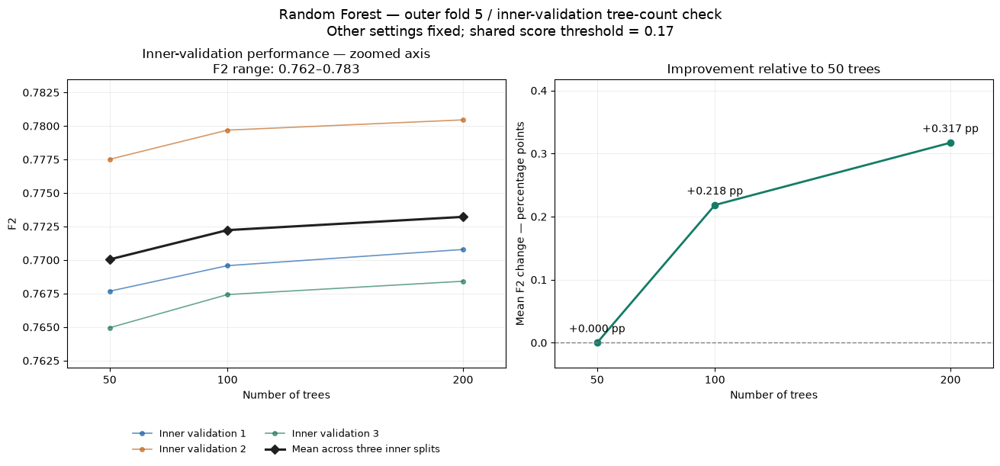

In [79]:
rf_tree_plot_table = rf_outer5_tree_count_comparison.sort_values(
    "Trees"
).copy()

# Recover each split's F2 at the shared threshold selected for that tree count.
rf_tree_plot_fold_parts = []

for _, rf_selected_row in rf_tree_plot_table.iterrows():
    rf_rows = rf_outer5_tree_threshold_detail.loc[
        (
            rf_outer5_tree_threshold_detail["Trees"]
            == int(rf_selected_row["Trees"])
        )
        & np.isclose(
            rf_outer5_tree_threshold_detail["Threshold"],
            rf_selected_row["Threshold"],
            rtol=0,
            atol=rf_selection_tolerance
        )
    ].copy()

    assert len(rf_rows) == 3
    assert set(rf_rows["Inner_split"]) == {1, 2, 3}
    rf_tree_plot_fold_parts.append(rf_rows)

rf_tree_plot_fold_data = pd.concat(
    rf_tree_plot_fold_parts, ignore_index=True
)

rf_tree_plot_counts = rf_tree_plot_table["Trees"].to_numpy()
rf_tree_plot_means = rf_tree_plot_table["Mean_F2"].to_numpy()

# Percentage-point change, calculated from the saved mean F2 values.
rf_tree_plot_gain_pp = (
    rf_tree_plot_means - rf_tree_plot_means[0]
) * 100

rf_tree_figure, rf_tree_axes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    constrained_layout=True
)

rf_split_colors = {
    1: "#2166AC",
    2: "#C46B24",
    3: "#27805C"
}

for rf_inner_number in (1, 2, 3):
    rf_rows = (
        rf_tree_plot_fold_data.loc[
            rf_tree_plot_fold_data["Inner_split"] == rf_inner_number
        ]
        .sort_values("Trees")
    )

    rf_tree_axes[0].plot(
        rf_rows["Trees"],
        rf_rows["F2"],
        marker="o",
        markersize=4,
        linewidth=1.2,
        alpha=0.7,
        color=rf_split_colors[rf_inner_number],
        label=f"Inner validation {rf_inner_number}"
    )

rf_tree_axes[0].plot(
    rf_tree_plot_counts,
    rf_tree_plot_means,
    color="#202020",
    marker="D",
    markersize=6,
    linewidth=2.2,
    label="Mean across three inner splits"
)

# Zoom around the actual split-level results; disclose the limits.
rf_tree_ymin = max(
    0, float(rf_tree_plot_fold_data["F2"].min()) - 0.003
)
rf_tree_ymax = min(
    1, float(rf_tree_plot_fold_data["F2"].max()) + 0.003
)

rf_tree_axes[0].set(
    xlabel="Number of trees",
    ylabel="F2",
    title=(
        "Inner-validation performance — zoomed axis\n"
        f"F2 range: {rf_tree_ymin:.3f}–{rf_tree_ymax:.3f}"
    ),
    ylim=(rf_tree_ymin, rf_tree_ymax)
)

rf_tree_axes[0].legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=2,
    fontsize=9,
    frameon=False
)

rf_tree_axes[1].plot(
    rf_tree_plot_counts,
    rf_tree_plot_gain_pp,
    marker="o",
    linewidth=2,
    color="#137C66"
)

for rf_trees, rf_gain in zip(
    rf_tree_plot_counts, rf_tree_plot_gain_pp
):
    rf_tree_axes[1].annotate(
        f"{rf_gain:+.3f} pp",
        (rf_trees, rf_gain),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

rf_tree_axes[1].axhline(
    0, color="gray", linestyle="--", linewidth=1
)

rf_tree_axes[1].set(
    xlabel="Number of trees",
    ylabel="Mean F2 change — percentage points",
    title="Improvement relative to 50 trees",
    ylim=(-0.04, max(0.10, float(rf_tree_plot_gain_pp.max()) + 0.10))
)

for rf_ax in rf_tree_axes:
    rf_ax.set_xticks(rf_tree_plot_counts)
    rf_ax.margins(x=0.12)
    rf_ax.grid(alpha=0.20)
    rf_ax.title.set_fontweight("normal")
    rf_ax.tick_params(labelsize=10)

rf_tree_figure.suptitle(
    "Random Forest — outer fold 5 / inner-validation tree-count check\n"
    "Other settings fixed; shared score threshold = 0.17",
    fontsize=13,
    fontweight="normal"
)

rf_outer5_tree_figures_dir = rf_outer5_tree_check_root / "figures"
rf_outer5_tree_figures_dir.mkdir(parents=True, exist_ok=True)

rf_tree_figure.savefig(
    rf_outer5_tree_figures_dir / "tree_count_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
rf_tree_figure.savefig(
    rf_outer5_tree_figures_dir / "tree_count_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Visualize tree-count sensitivity while holding other settings and the threshold fixed.
Result: F2 increased in all three inner splits. Mean F2 rose from 0.770047 with 50 trees to 0.773219 with 200 trees, with a small additional gain of 0.000988 beyond 100 trees.

In [80]:
assert rf_X_samples512.shape == (
    len(rf_sampled_patch_ids), 512, len(FEATURE_NAMES)
)
assert rf_y_samples512.shape == (
    len(rf_sampled_patch_ids), 512
)

rf_check_rows = np.arange(len(rf_sampled_patch_ids))[:, None]

assert np.array_equal(
    rf_X_samples512,
    rf_X_samples[rf_check_rows, rf_sample512_indices]
)
assert np.array_equal(
    rf_y_samples512,
    rf_y_samples[rf_check_rows, rf_sample512_indices]
)

rf_outer5_sample_params = dict(rf_outer5_initial_selection["params"])
rf_outer5_sample_params["n_estimators"] = int(
    rf_outer5_selected_tree_count
)

rf_outer5_sample_root = (
    rf_checkpoint_dir / "sample_size_check" / "outer_5"
)
rf_outer5_sample_root.mkdir(parents=True, exist_ok=True)

rf_outer5_sample512_model_records = {}
rf_outer5_sample512_fit_parts = []

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    rf_records, rf_table = rf_fit_search_inner_split(
        outer_split=rf_outer5_split,
        inner_position=rf_inner_position,
        candidates=[rf_outer5_sample_params],
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples512,
        y_samples=rf_y_samples512,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_outer5_sample_root / "512_pixels"
    )

    rf_outer5_sample512_model_records[rf_inner_number] = rf_records

    rf_table = rf_table.drop(columns=["Candidate"]).copy()
    rf_table.insert(0, "Outer_fold", 5)
    rf_table.insert(1, "Inner_split", rf_inner_number)
    rf_table.insert(
        2, "Source_candidate",
        rf_outer5_initial_selection["candidate"]
    )
    rf_table.insert(3, "Samples_per_image", 512)
    rf_outer5_sample512_fit_parts.append(rf_table)

rf_outer5_sample512_fit_table = pd.concat(
    rf_outer5_sample512_fit_parts, ignore_index=True
)

rf_fitting_path = (
    rf_outer5_sample_root / "sample512_fitting_records.joblib"
)
rf_temp = rf_fitting_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 5,
        "params": rf_outer5_sample_params,
        "subset_path": str(rf_subset_path),
        "subset_signature": rf_sample512_subset_signature,
        "model_records": rf_outer5_sample512_model_records,
        "fitting_table": rf_outer5_sample512_fit_table
    },
    rf_temp
)
rf_temp.replace(rf_fitting_path)

rf_outer5_sample512_fit_table.to_csv(
    rf_outer5_sample_root / "sample512_fitting_summary.csv",
    index=False
)

display(rf_outer5_sample512_fit_table.round(2))

print("\nScope: outer fold 5 / three inner-training splits.")
print("Trees:", rf_outer5_selected_tree_count)
print("Training samples per image: 512.")
print("Other selected RF settings are unchanged.")
print("1024-sample models were not refitted.")
print("Sample-size validation comparison has not started.")

Outer fold 5 / inner split 1
Training images: 1621
Validation images, excluded from fitting: 811
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 130.27 seconds
Outer fold 5 / inner split 2
Training images: 1621
Validation images, excluded from fitting: 811
Training table: (829952, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 121.69 seconds
Outer fold 5 / inner split 3
Training images: 1622
Validation images, excluded from fitting: 810
Training table: (830464, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 123.28 seconds


,Outer_fold,Inner_split,Source_candidate,Samples_per_image,Trees,Original_fit_seconds,Status
0,5,1,8,512,200,130.27,New model fitted
1,5,2,8,512,200,121.69,New model fitted
2,5,3,8,512,200,123.28,New model fitted



Scope: outer fold 5 / three inner-training splits.
Trees: 200
Training samples per image: 512.
Other selected RF settings are unchanged.
1024-sample models were not refitted.
Sample-size validation comparison has not started.


Rationale: Prepare a controlled sample-size comparison within outer fold 5.
Result: Three 200-tree models using 512 samples per image were fitted and saved. Their displayed fitting times total 375.24 seconds. Validation comparison remains pending.

In [81]:
rf_outer5_sample_threshold_parts = []
rf_outer5_sample_evaluation_paths = {}

for rf_inner_number in (1, 2, 3):
    rf_reference_path = rf_outer5_tree_evaluation_paths[
        rf_inner_number
    ][rf_outer5_selected_tree_count]

    rf_reference_result = joblib.load(rf_reference_path)

    rf_expected_ids = sorted(
        np.asarray(
            rf_outer5_split["inner_splits"][
                rf_inner_number - 1
            ]["validation_ids"]
        ).astype(str).tolist(),
        key=int
    )

    assert rf_reference_result["image_ids"] == rf_expected_ids
    assert rf_reference_result["metadata"]["model_signature"] == (
        rf_outer5_tree_check_records[
            rf_inner_number
        ][rf_outer5_selected_tree_count]["signature"]
    )

    rf_records = rf_outer5_sample512_model_records[rf_inner_number]
    assert len(rf_records) == 1
    assert rf_records[0]["params"] == rf_outer5_sample_params

    print(
        f"\nOuter fold 5 / inner validation {rf_inner_number}"
        " — 512 samples per image",
        flush=True
    )

    rf_result512, rf_result512_path = rf_evaluate_saved_forest(
        model_record=rf_records[0],
        shared_labels_path=rf_reference_result["shared_labels_path"],
        output_root=(
            rf_outer5_sample_root / "validation"
            / f"inner_{rf_inner_number}"
        ),
        thresholds=rf_saved_thresholds,
        reference_threshold=rf_baseline_threshold,
        beta=float(BETA),
        log_loss_epsilon=rf_log_loss_epsilon
    )

    assert rf_result512["image_ids"] == rf_reference_result["image_ids"]
    assert (
        rf_result512["metadata"]["sources"]
        == rf_reference_result["metadata"]["sources"]
    )

    rf_outer5_sample_evaluation_paths[rf_inner_number] = {
        512: rf_result512_path,
        1024: str(rf_reference_path)
    }

    rf_positive_reference = None

    for rf_sample_count, rf_result in [
        (512, rf_result512),
        (1024, rf_reference_result)
    ]:
        rf_table = rf_result["threshold_table"].copy()

        assert np.array_equal(
            rf_table["Threshold"].to_numpy(), rf_saved_thresholds
        )
        assert np.all(
            rf_table[["TN", "FP", "FN", "TP"]].sum(axis=1)
            == len(rf_expected_ids) * 128 * 128
        )

        rf_positives = (rf_table["TP"] + rf_table["FN"]).to_numpy()
        assert np.all(rf_positives == rf_positives[0])

        if rf_positive_reference is None:
            rf_positive_reference = int(rf_positives[0])
        assert int(rf_positives[0]) == rf_positive_reference

        rf_table["Samples_per_image"] = rf_sample_count
        rf_table["Inner_split"] = rf_inner_number
        rf_outer5_sample_threshold_parts.append(rf_table)


rf_outer5_sample_threshold_detail = pd.concat(
    rf_outer5_sample_threshold_parts, ignore_index=True
)

rf_outer5_sample_threshold_summary = (
    rf_outer5_sample_threshold_detail
    .groupby(["Samples_per_image", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)
assert (rf_outer5_sample_threshold_summary["Inner_splits"] == 3).all()

rf_outer5_sample_selected_rows = []

for rf_sample_count in (512, 1024):
    rf_rows = rf_outer5_sample_threshold_summary.loc[
        rf_outer5_sample_threshold_summary["Samples_per_image"]
        == rf_sample_count
    ]

    rf_ties = rf_keep_near_max(
        rf_rows, "Mean_F2", rf_selection_tolerance
    )
    rf_ties = rf_keep_near_max(
        rf_ties, "Mean_precision", rf_selection_tolerance
    )

    rf_outer5_sample_selected_rows.append(
        rf_ties.sort_values("Threshold", ascending=False)
        .iloc[0].to_dict()
    )

rf_outer5_sample_size_comparison = pd.DataFrame(
    rf_outer5_sample_selected_rows
).sort_values("Samples_per_image")

rf_outer5_sample_size_comparison["Samples_per_image"] = (
    rf_outer5_sample_size_comparison["Samples_per_image"].astype(int)
)

# Confirm reproduction of the earlier 1024-sample result.
rf_1024_check = rf_outer5_sample_size_comparison.loc[
    rf_outer5_sample_size_comparison["Samples_per_image"] == 1024
].iloc[0]

rf_tree_reference = rf_outer5_tree_count_comparison.loc[
    rf_outer5_tree_count_comparison["Trees"]
    == rf_outer5_selected_tree_count
].iloc[0]

for rf_column in [
    "Threshold", "Mean_F2", "SD_F2",
    "Mean_precision", "Mean_recall", "Mean_specificity", "Mean_IoU"
]:
    assert np.isclose(
        rf_1024_check[rf_column],
        rf_tree_reference[rf_column],
        rtol=0, atol=rf_selection_tolerance
    )

rf_ties = rf_keep_near_max(
    rf_outer5_sample_size_comparison,
    "Mean_F2",
    rf_selection_tolerance
)
rf_ties = rf_keep_near_max(
    rf_ties, "Mean_precision", rf_selection_tolerance
)

rf_outer5_selected_samples_per_image = int(
    rf_ties.sort_values("Samples_per_image").iloc[0][
        "Samples_per_image"
    ]
)

rf_result_path = rf_outer5_sample_root / "sample_size_comparison.joblib"
rf_temp = rf_result_path.with_suffix(".tmp")

joblib.dump(
    {
        "outer_fold": 5,
        "params": rf_outer5_sample_params,
        "comparison": rf_outer5_sample_size_comparison,
        "threshold_detail": rf_outer5_sample_threshold_detail,
        "threshold_summary": rf_outer5_sample_threshold_summary,
        "evaluation_paths": rf_outer5_sample_evaluation_paths,
        "selected_samples_per_image": (
            rf_outer5_selected_samples_per_image
        ),
        "subset_path": str(rf_subset_path),
        "tie_tolerance": rf_selection_tolerance
    },
    rf_temp
)
rf_temp.replace(rf_result_path)

rf_outer5_sample_size_comparison.to_csv(
    rf_outer5_sample_root / "sample_size_comparison.csv",
    index=False
)

display(rf_outer5_sample_size_comparison.round(6))

print("\nTrees:", rf_outer5_selected_tree_count)
print("Other RF settings unchanged.")
print("Selected samples per image:", rf_outer5_selected_samples_per_image)
print("Identical validation images and source metadata verified.")
print("1024-sample results reproduced the previous tree-count comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")


Outer fold 5 / inner validation 1 — 512 samples per image
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images

Outer fold 5 / inner validation 2 — 512 samples per image
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  50

,Samples_per_image,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,512,0.17,3.0,0.768948,0.006453,0.539934,0.860247,0.982131,0.496392
1,1024,0.17,3.0,0.773219,0.006375,0.544134,0.864221,0.982351,0.501294



Trees: 200
Other RF settings unchanged.
Selected samples per image: 1024
Identical validation images and source metadata verified.
1024-sample results reproduced the previous tree-count comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Compare training sample sizes with the forest configuration and validation images held fixed.
Result: Within outer fold 5, 1,024 samples achieved mean F2 0.773219 versus 0.768948 for 512 samples. Both selected threshold 0.17. Retain 1,024 samples for the next selection stage.

In [82]:
rf_outer5_working_params = dict(rf_outer5_initial_selection["params"])
rf_outer5_working_params["n_estimators"] = int(
    rf_outer5_selected_tree_count
)

assert rf_outer5_selected_samples_per_image == 1024

(
    rf_outer5_calibration_bundle_records,
    rf_outer5_calibration_preparation_table,
    rf_outer5_calibration_root
) = rf_prepare_calibration_for_outer(
    outer_split=rf_outer5_split,
    saved_calibration_splits=dt_calibration_splits_by_outer[5],
    params=rf_outer5_working_params,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    samples_per_image=rf_outer5_selected_samples_per_image,
    platt_c=PLATT_C,
    random_state=RANDOM_STATE,
    checkpoint_root=rf_checkpoint_dir
)

display(rf_outer5_calibration_preparation_table.round(6))

print("\nScope: outer fold 5 / three inner-training splits.")
print("Sigmoid and isotonic prepared using separate calibration images.")
print("Inner-validation performance has not been evaluated by this cell.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")


Outer fold 5 / inner split 1
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 5 / inner split 2
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 5 / inner split 3
Training fitting-side forest...
Both calibrators fitted and saved.


,Inner_split,Fit_images,Calibration_images,Fit_pixels,Calibration_pixels,Calibration_landslide_fraction,Forest_fit_seconds,Sigmoid_fit_seconds,Isotonic_fit_seconds,Sigmoid_slope,Isotonic_knots
0,1,1296,325,1327104,332800,0.024612,220.651394,0.088442,0.021094,10.745368,156
1,2,1296,325,1327104,332800,0.022993,218.213508,0.095432,0.020746,10.748188,152
2,3,1297,325,1328128,332800,0.025508,221.791641,0.081319,0.019317,10.802209,172



Scope: outer fold 5 / three inner-training splits.
Sigmoid and isotonic prepared using separate calibration images.
Inner-validation performance has not been evaluated by this cell.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Fit calibrators using images separate from forest fitting within outer fold 5.
Result: Sigmoid and isotonic calibrators were fitted and saved for all three inner splits. Forest fitting totalled approximately 660.66 seconds. Validation effectiveness remains unevaluated.

In [83]:
rf_outer5_full_training_evaluation_paths = {
    inner: rf_outer5_sample_evaluation_paths[
        inner
    ][rf_outer5_selected_samples_per_image]
    for inner in (1, 2, 3)
}

(
    rf_outer5_calibration_validation_metrics,
    rf_outer5_calibration_threshold_detail,
    rf_outer5_calibration_evaluation_records
) = rf_evaluate_calibration_outer(
    outer_split=rf_outer5_split,
    calibration_records=rf_outer5_calibration_bundle_records,
    full_training_evaluation_paths=rf_outer5_full_training_evaluation_paths,
    output_root=rf_outer5_calibration_root,
    thresholds=rf_saved_thresholds,
    reference_threshold=rf_baseline_threshold,
    beta=float(BETA),
    log_loss_epsilon=rf_log_loss_epsilon
)

print("\nClassification results at threshold 0.50:")
display(
    rf_outer5_calibration_validation_metrics[[
        "Inner_split", "Method", "F2",
        "Precision", "Recall", "Specificity", "IoU",
        "Predicted_positive_pixels"
    ]].round(6)
)

print("\nScore-quality results:")
display(
    rf_outer5_calibration_validation_metrics[[
        "Inner_split", "Method",
        "ROC_AUC", "Average_precision",
        "Brier_score", "Log_loss", "Score_min", "Score_max"
    ]].round(6)
)

print("\nScope: outer fold 5 / all three inner-validation splits.")
print("All four alternatives, including isotonic, are included.")
print("All 101 threshold results are saved.")
print("No final method or shared threshold has been selected for this fold.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")


Outer fold 5 / inner validation 1
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
  425/811 images
  450/811 images
  475/811 images
  500/811 images
  525/811 images
  550/811 images
  575/811 images
  600/811 images
  625/811 images
  650/811 images
  675/811 images
  700/811 images
  725/811 images
  750/811 images
  775/811 images
  800/811 images
  811/811 images
Calculating metrics: Raw — fit images only
Calculating metrics: Sigmoid
Calculating metrics: Isotonic

Outer fold 5 / inner validation 2
  25/811 images
  50/811 images
  75/811 images
  100/811 images
  125/811 images
  150/811 images
  175/811 images
  200/811 images
  225/811 images
  250/811 images
  275/811 images
  300/811 images
  325/811 images
  350/811 images
  375/811 images
  400/811 images
 

,Inner_split,Method,F2,Precision,Recall,Specificity,IoU,Predicted_positive_pixels
0,1,Raw — all training images,0.655179,0.786657,0.628901,0.995805,0.537266,255003
1,1,Raw — fit images only,0.649182,0.787117,0.621935,0.995863,0.532384,252031
2,1,Sigmoid,0.651028,0.785541,0.624302,0.995808,0.533391,253498
3,1,Isotonic,0.656718,0.780082,0.631742,0.995620,0.536238,258314
4,2,Raw — all training images,0.655791,0.814009,0.625401,0.996398,0.547207,251033
5,2,Raw — fit images only,0.649612,0.812947,0.618543,0.996412,0.541479,248604
6,2,Sigmoid,0.650512,0.812222,0.619669,0.996388,0.542019,249279
7,2,Isotonic,0.673467,0.790681,0.649399,0.995666,0.554134,268356
8,3,Raw — all training images,0.652191,0.795195,0.624131,0.996247,0.537698,237646
9,3,Raw — fit images only,0.648024,0.795009,0.619395,0.996271,0.534095,235898



Score-quality results:


,Inner_split,Method,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max
0,1,Raw — all training images,0.988671,0.787739,0.009688,0.036393,0.000000,1.000000
1,1,Raw — fit images only,0.988449,0.785084,0.009761,0.036780,0.000000,1.000000
2,1,Sigmoid,0.988449,0.785084,0.010587,0.043292,0.004771,0.995525
3,1,Isotonic,0.988399,0.776010,0.009765,0.034357,0.000083,1.000000
4,2,Raw — all training images,0.989267,0.804206,0.009505,0.035818,0.000000,1.000000
5,2,Raw — fit images only,0.989022,0.800066,0.009620,0.036260,0.000000,1.000000
6,2,Sigmoid,0.989022,0.800066,0.010375,0.042510,0.004683,0.995454
7,2,Isotonic,0.988983,0.791647,0.009599,0.034240,0.000083,1.000000
8,3,Raw — all training images,0.988988,0.792164,0.009154,0.034505,0.000000,1.000000
9,3,Raw — fit images only,0.988597,0.788781,0.009244,0.035155,0.000000,1.000000



Scope: outer fold 5 / all three inner-validation splits.
All four alternatives, including isotonic, are included.
All 101 threshold results are saved.
No final method or shared threshold has been selected for this fold.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Compare classification behaviour and score quality before method-specific threshold selection.
Result: At threshold 0.50, isotonic achieved the highest F2 and lowest log loss in all three inner splits. The full-training raw option had the lowest Brier score. Final method-and-threshold selection remains pending.

In [84]:
rf_outer5_raw_reference_row = rf_outer5_sample_size_comparison.loc[
    rf_outer5_sample_size_comparison["Samples_per_image"]
    == rf_outer5_selected_samples_per_image
].iloc[0]

rf_outer5_pipeline_selection = rf_select_calibration_pipeline(
    outer_split=rf_outer5_split,
    threshold_detail=rf_outer5_calibration_threshold_detail,
    validation_metrics=rf_outer5_calibration_validation_metrics,
    evaluation_records=rf_outer5_calibration_evaluation_records,
    params=rf_outer5_working_params,
    samples_per_image=rf_outer5_selected_samples_per_image,
    threshold_grid=rf_saved_thresholds,
    raw_reference_row=rf_outer5_raw_reference_row,
    tolerance=rf_selection_tolerance,
    output_root=rf_outer5_calibration_root
)

rf_outer5_pipeline_ranking = rf_outer5_pipeline_selection["ranking"]

print("Classification at each method's selected shared threshold:")
display(
    rf_outer5_pipeline_ranking[[
        "Rank", "Method", "Threshold",
        "Mean_F2", "SD_F2", "Mean_precision",
        "Mean_recall", "Mean_specificity", "Mean_IoU"
    ]].round(6)
)

print("\nThreshold-independent score quality:")
display(
    rf_outer5_pipeline_ranking[[
        "Rank", "Method", "Mean_ROC_AUC",
        "Mean_average_precision", "Mean_Brier", "Mean_log_loss"
    ]].round(6)
)

print("\nTraining-side selection for outer fold 5:")
print("Method:", rf_outer5_pipeline_selection["method"])
print("Threshold:", rf_outer5_pipeline_selection["threshold"])
print("Trees:", rf_outer5_pipeline_selection["params"]["n_estimators"])
print("Samples per image:", rf_outer5_selected_samples_per_image)
print("Full-training raw results reproduced the previous comparison.")
print("SD_F2 is descriptive, not a confidence interval.")
print("Outer-fold-5 evaluation images and the secondary holdout were not used.")

Classification at each method's selected shared threshold:


,Rank,Method,Threshold,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,1,Raw — all training images,0.17,0.773219,0.006375,0.544134,0.864221,0.982351,0.501294
1,2,Raw — fit images only,0.17,0.770696,0.006086,0.540696,0.862476,0.982141,0.497784
2,3,Sigmoid,0.03,0.770582,0.005905,0.545236,0.859465,0.982526,0.500600
3,4,Isotonic,0.15,0.770498,0.005857,0.540076,0.862541,0.982085,0.497249



Threshold-independent score quality:


,Rank,Method,Mean_ROC_AUC,Mean_average_precision,Mean_Brier,Mean_log_loss
0,1,Raw — all training images,0.988975,0.794703,0.009449,0.035572
1,2,Raw — fit images only,0.988689,0.791310,0.009542,0.036065
2,3,Sigmoid,0.988689,0.791310,0.010303,0.042260
3,4,Isotonic,0.988643,0.783015,0.009535,0.033743



Training-side selection for outer fold 5:
Method: Raw — all training images
Threshold: 0.17
Trees: 200
Samples per image: 1024
Full-training raw results reproduced the previous comparison.
SD_F2 is descriptive, not a confidence interval.
Outer-fold-5 evaluation images and the secondary holdout were not used.


Rationale: Compare methods at their selected shared inner-validation thresholds.
Result: The full-training raw-score option achieved the highest mean F2, 0.773219, at threshold 0.17. Isotonic achieved the lowest log loss. Outer-fold-5 performance remains unknown.

In [85]:
assert int(rf_outer5_split["outer_fold"]) == 5
assert rf_outer5_pipeline_selection["method"] == (
    "Raw — all training images"
)

rf_outer5_train_ids = np.asarray(
    rf_outer5_split["train_ids"]
).astype(str)

rf_outer5_eval_ids_reserved = np.asarray(
    rf_outer5_split["evaluation_ids"]
).astype(str)

assert len(np.unique(rf_outer5_train_ids)) == len(rf_outer5_train_ids)
assert len(np.unique(rf_outer5_eval_ids_reserved)) == (
    len(rf_outer5_eval_ids_reserved)
)
assert set(rf_outer5_train_ids).isdisjoint(
    set(rf_outer5_eval_ids_reserved)
)
assert (
    set(rf_outer5_train_ids) | set(rf_outer5_eval_ids_reserved)
    == set(np.asarray(dev_ids).astype(str))
)
assert set(rf_outer5_train_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_outer5_training_X, rf_outer5_training_y = (
    rf_get_sampled_training_data(
        rf_outer5_train_ids,
        rf_sampled_patch_ids,
        rf_X_samples,
        rf_y_samples
    )
)

assert rf_outer5_training_X.shape == (
    len(rf_outer5_train_ids)
    * rf_outer5_pipeline_selection["samples_per_image"],
    len(FEATURE_NAMES)
)
assert set(np.unique(rf_outer5_training_y).tolist()) == {0, 1}

rf_outer5_training_hasher = hashlib.sha256()

for rf_array in (rf_outer5_training_X, rf_outer5_training_y):
    for rf_start in range(0, len(rf_array), 8192):
        rf_outer5_training_hasher.update(
            rf_array[rf_start:rf_start + 8192].tobytes()
        )

rf_outer5_locked_spec = {
    "role": "locked_outer_fold_5_specification",
    "outer_fold": 5,
    "selection_signature": rf_outer5_pipeline_selection["signature"],
    "params": dict(rf_outer5_pipeline_selection["params"]),
    "probability_method": "uncalibrated",
    "threshold": float(rf_outer5_pipeline_selection["threshold"]),
    "samples_per_image": int(
        rf_outer5_pipeline_selection["samples_per_image"]
    ),
    "ordered_training_ids": rf_outer5_train_ids.tolist(),
    "evaluation_ids": rf_outer5_eval_ids_reserved.tolist(),
    "training_data_hash": rf_outer5_training_hasher.hexdigest(),
    "features": list(FEATURE_NAMES),
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_log_loss_epsilon),
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__
}

rf_outer5_locked_json = json.dumps(
    rf_outer5_locked_spec,
    sort_keys=True,
    indent=2,
    default=lambda value: value.item()
)

rf_outer5_locked_signature = hashlib.sha256(
    rf_outer5_locked_json.encode("utf-8")
).hexdigest()

rf_outer5_model_dir = (
    rf_checkpoint_dir / "outer_models" / "outer_5"
    / rf_outer5_locked_signature
)
rf_outer5_model_dir.mkdir(parents=True, exist_ok=True)

rf_outer5_spec_path = rf_outer5_model_dir / "locked_specification.json"
rf_outer5_model_path = rf_outer5_model_dir / "fitted_model.joblib"

# Persist the specification before fitting or outer evaluation.
if rf_outer5_spec_path.is_file():
    assert rf_outer5_spec_path.read_text(
        encoding="utf-8"
    ) == rf_outer5_locked_json
else:
    rf_temp = rf_outer5_spec_path.with_suffix(".tmp")
    rf_temp.write_text(rf_outer5_locked_json, encoding="utf-8")
    rf_temp.replace(rf_outer5_spec_path)

if rf_outer5_model_path.is_file():
    rf_outer5_model_bundle = joblib.load(rf_outer5_model_path)
    assert rf_outer5_model_bundle["signature"] == (
        rf_outer5_locked_signature
    )
    print("Loaded matching outer-fold-5 model checkpoint.")

else:
    rf_outer5_model = RandomForestClassifier(
        **rf_outer5_locked_spec["params"]
    )

    print(
        f"Training outer-fold-5 model on "
        f"{len(rf_outer5_train_ids)} images...",
        flush=True
    )

    rf_start_time = perf_counter()
    rf_outer5_model.fit(
        rf_outer5_training_X, rf_outer5_training_y
    )
    rf_outer5_fit_seconds = perf_counter() - rf_start_time

    rf_outer5_model_bundle = {
        "signature": rf_outer5_locked_signature,
        "specification": rf_outer5_locked_spec,
        "model": rf_outer5_model,
        "fit_seconds": rf_outer5_fit_seconds
    }

    rf_temp = rf_outer5_model_path.with_suffix(".tmp")
    joblib.dump(rf_outer5_model_bundle, rf_temp)
    rf_temp.replace(rf_outer5_model_path)

rf_outer5_model = rf_outer5_model_bundle["model"]

assert rf_outer5_model.get_params() == (
    RandomForestClassifier(
        **rf_outer5_locked_spec["params"]
    ).get_params()
)
assert len(rf_outer5_model.estimators_) == (
    rf_outer5_locked_spec["params"]["n_estimators"]
)

print("\nOuter fold:", rf_outer5_locked_spec["outer_fold"])
print("Training images:", len(rf_outer5_train_ids))
print("Sampled training pixels:", len(rf_outer5_training_y))
print("Reserved outer-evaluation images:", len(rf_outer5_eval_ids_reserved))
print("Locked threshold:", rf_outer5_locked_spec["threshold"])
print("Probability method:", rf_outer5_locked_spec["probability_method"])
print(
    "Original fitting time:",
    round(rf_outer5_model_bundle["fit_seconds"], 2),
    "seconds"
)
print("Model checkpoint:", rf_outer5_model_path)
print("Outer-evaluation predictions have not been calculated by this cell.")
print("Previously completed outer-fold results remain unchanged.")

Training outer-fold-5 model on 2432 images...

Outer fold: 5
Training images: 2432
Sampled training pixels: 2490368
Reserved outer-evaluation images: 607
Locked threshold: 0.17
Probability method: uncalibrated
Original fitting time: 539.62 seconds
Model checkpoint: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\outer_models\outer_5\e08bfc1de7d3fa24c4af171075b08990accbbc072668a9ef28f7678ef3d0c803\fitted_model.joblib
Outer-evaluation predictions have not been calculated by this cell.
Previously completed outer-fold results remain unchanged.


Rationale: Fit the selected, locked pipeline on all outer-fold-5 training images.
Result: The model was fitted on 2,432 images containing 2,490,368 sampled pixels in 539.62 seconds and saved. The 607 outer-evaluation images remain unevaluated.

In [86]:
assert rf_outer5_model_bundle["signature"] == rf_outer5_locked_signature
assert rf_outer5_locked_spec["probability_method"] == "uncalibrated"

rf_outer5_eval_ids = sorted(
    rf_outer5_locked_spec["evaluation_ids"], key=int
)

assert len(rf_outer5_eval_ids) == len(set(rf_outer5_eval_ids))
assert set(rf_outer5_eval_ids) == set(
    np.asarray(rf_outer5_split["evaluation_ids"]).astype(str)
)
assert set(rf_outer5_eval_ids).isdisjoint(
    set(rf_outer5_locked_spec["ordered_training_ids"])
)
assert set(rf_outer5_eval_ids).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

for rf_completed_fold in (1, 2, 3, 4):
    assert set(rf_outer5_eval_ids).isdisjoint(
        set(rf_outer_evaluations_by_fold[rf_completed_fold]["image_ids"])
    )

rf_outer5_eval_sources = []
rf_outer5_source_records = []

for rf_image_id in rf_outer5_eval_ids:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    rf_files = []
    for rf_path in (rf_image_path, rf_mask_path):
        if not rf_path.is_file():
            raise FileNotFoundError(rf_path)
        rf_stat = rf_path.stat()
        rf_files.append({
            "path": str(rf_path.resolve()),
            "size": rf_stat.st_size,
            "mtime_ns": rf_stat.st_mtime_ns
        })

    rf_outer5_eval_sources.append(
        (rf_image_id, rf_image_path, rf_mask_path)
    )
    rf_outer5_source_records.append({
        "image_id": rf_image_id,
        "files": rf_files
    })

rf_outer5_evaluation_metadata = {
    "role": "outer_fold_5_evaluation",
    "locked_model_signature": rf_outer5_locked_signature,
    "sources": rf_outer5_source_records,
    "ordered_image_ids": rf_outer5_eval_ids,
    "threshold": rf_outer5_locked_spec["threshold"],
    "beta": rf_outer5_locked_spec["beta"],
    "log_loss_epsilon": rf_outer5_locked_spec["log_loss_epsilon"],
    "sklearn_version": sklearn.__version__,
    "evaluation_code_version": 1
}

rf_outer5_evaluation_signature = hashlib.sha256(
    json.dumps(
        rf_outer5_evaluation_metadata, sort_keys=True
    ).encode("utf-8")
).hexdigest()

rf_outer5_evaluation_dir = (
    rf_outer5_model_dir / "outer_evaluation"
    / rf_outer5_evaluation_signature
)
rf_outer5_evaluation_dir.mkdir(parents=True, exist_ok=True)

rf_outer5_evaluation_path = (
    rf_outer5_evaluation_dir / "evaluation.joblib"
)

if rf_outer5_evaluation_path.is_file():
    rf_outer5_evaluation = joblib.load(rf_outer5_evaluation_path)
    assert rf_outer5_evaluation["signature"] == (
        rf_outer5_evaluation_signature
    )
    print("Loaded completed outer-fold-5 evaluation.")

else:
    rf_positive_column = np.flatnonzero(
        rf_outer5_model.classes_ == 1
    ).item()

    rf_score_parts = []
    rf_label_parts = []
    rf_per_image_records = []
    rf_chunk_files = []
    rf_prediction_seconds = 0.0

    print(
        f"Evaluating {len(rf_outer5_eval_ids)} outer images...",
        flush=True
    )

    for rf_start in range(0, len(rf_outer5_eval_sources), 25):
        rf_sources = rf_outer5_eval_sources[rf_start:rf_start + 25]
        rf_chunk_ids = [item[0] for item in rf_sources]
        rf_chunk_path = (
            rf_outer5_evaluation_dir / f"images_{rf_start:04d}.joblib"
        )

        if rf_chunk_path.is_file():
            rf_chunk = joblib.load(rf_chunk_path)
            assert rf_chunk["signature"] == rf_outer5_evaluation_signature
            assert rf_chunk["image_ids"] == rf_chunk_ids

        else:
            rf_chunk_scores = []
            rf_chunk_labels = []
            rf_chunk_records = []
            rf_chunk_prediction_seconds = 0.0

            for rf_image_id, rf_image_path, rf_mask_path in rf_sources:
                with h5py.File(rf_image_path, "r") as rf_file:
                    rf_image = np.asarray(rf_file["img"])

                with h5py.File(rf_mask_path, "r") as rf_file:
                    rf_mask = np.asarray(rf_file["mask"])

                if (
                    rf_image.shape != (128, 128, 14)
                    or not np.isfinite(rf_image).all()
                ):
                    raise ValueError(f"Invalid image: {rf_image_id}")

                if (
                    rf_mask.shape != (128, 128)
                    or not np.isin(rf_mask, [0, 1]).all()
                ):
                    raise ValueError(f"Invalid mask: {rf_image_id}")

                rf_y_image = rf_mask.reshape(-1).astype(np.uint8)

                rf_start_time = perf_counter()
                rf_scores_image = rf_outer5_model.predict_proba(
                    rf_image.reshape(-1, 14)
                )[:, rf_positive_column]
                rf_chunk_prediction_seconds += (
                    perf_counter() - rf_start_time
                )

                if (
                    not np.isfinite(rf_scores_image).all()
                    or np.any(
                        (rf_scores_image < 0) | (rf_scores_image > 1)
                    )
                ):
                    raise ValueError(f"Invalid scores: {rf_image_id}")

                rf_prediction = (
                    rf_scores_image >= rf_outer5_locked_spec["threshold"]
                ).astype(np.uint8)

                rf_tn, rf_fp, rf_fn, rf_tp = confusion_matrix(
                    rf_y_image, rf_prediction, labels=[0, 1]
                ).ravel()

                rf_epsilon = rf_outer5_locked_spec["log_loss_epsilon"]
                rf_clipped = np.clip(
                    rf_scores_image, rf_epsilon, 1 - rf_epsilon
                )

                rf_chunk_records.append({
                    "image_id": rf_image_id,
                    "outer_fold": 5,
                    "threshold": rf_outer5_locked_spec["threshold"],
                    "TN": int(rf_tn),
                    "FP": int(rf_fp),
                    "FN": int(rf_fn),
                    "TP": int(rf_tp),
                    "pixels": int(rf_y_image.size),
                    "positive_pixels": int(rf_y_image.sum()),
                    "predicted_positive_pixels": int(rf_prediction.sum()),
                    "squared_error_sum": float(np.sum(
                        (rf_scores_image - rf_y_image) ** 2
                    )),
                    "log_loss_sum": float(-np.sum(
                        rf_y_image * np.log(rf_clipped)
                        + (1 - rf_y_image) * np.log1p(-rf_clipped)
                    ))
                })

                rf_chunk_scores.append(rf_scores_image)
                rf_chunk_labels.append(rf_y_image)

            rf_chunk = {
                "signature": rf_outer5_evaluation_signature,
                "image_ids": rf_chunk_ids,
                "scores": np.stack(rf_chunk_scores),
                "labels": np.stack(rf_chunk_labels),
                "per_image_records": rf_chunk_records,
                "prediction_seconds": rf_chunk_prediction_seconds
            }

            rf_temp = rf_chunk_path.with_suffix(".tmp")
            joblib.dump(rf_chunk, rf_temp)
            rf_temp.replace(rf_chunk_path)

        assert rf_chunk["scores"].shape == (
            len(rf_chunk_ids), 128 * 128
        )
        assert rf_chunk["labels"].shape == rf_chunk["scores"].shape

        rf_score_parts.append(rf_chunk["scores"])
        rf_label_parts.append(rf_chunk["labels"])
        rf_per_image_records.extend(rf_chunk["per_image_records"])
        rf_prediction_seconds += rf_chunk["prediction_seconds"]
        rf_chunk_files.append(str(rf_chunk_path))

        print(
            f"{rf_start + len(rf_chunk_ids)}/"
            f"{len(rf_outer5_eval_ids)} images saved or restored",
            flush=True
        )

    rf_outer_scores = np.concatenate(rf_score_parts).reshape(-1)
    rf_outer_labels = np.concatenate(rf_label_parts).reshape(-1)
    rf_outer_per_image = pd.DataFrame(rf_per_image_records)

    assert rf_outer_per_image["image_id"].tolist() == rf_outer5_eval_ids
    assert rf_outer_per_image["image_id"].is_unique
    assert rf_outer_labels.size == len(rf_outer5_eval_ids) * 128 * 128

    rf_outer_metrics = rf_binary_metrics(
        rf_outer_labels,
        rf_outer_scores,
        threshold=rf_outer5_locked_spec["threshold"],
        beta=rf_outer5_locked_spec["beta"],
        log_loss_epsilon=rf_outer5_locked_spec["log_loss_epsilon"]
    )

    for rf_name in ["TN", "FP", "FN", "TP"]:
        assert int(rf_outer_per_image[rf_name].sum()) == (
            rf_outer_metrics[rf_name]
        )

    assert np.isclose(
        rf_outer_per_image["squared_error_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Brier_score"],
        rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_outer_per_image["log_loss_sum"].sum()
        / rf_outer_labels.size,
        rf_outer_metrics["Log_loss"],
        rtol=0, atol=1e-12
    )

    rf_outer5_evaluation = {
        "signature": rf_outer5_evaluation_signature,
        "metadata": rf_outer5_evaluation_metadata,
        "model_path": str(rf_outer5_model_path),
        "specification_path": str(rf_outer5_spec_path),
        "image_ids": rf_outer5_eval_ids,
        "metrics": rf_outer_metrics,
        "per_image": rf_outer_per_image,
        "prediction_files": rf_chunk_files,
        "prediction_seconds": rf_prediction_seconds
    }

    rf_temp = rf_outer5_evaluation_path.with_suffix(".tmp")
    joblib.dump(rf_outer5_evaluation, rf_temp)
    rf_temp.replace(rf_outer5_evaluation_path)

    del rf_score_parts, rf_label_parts, rf_outer_scores, rf_outer_labels


rf_outer5_per_image = rf_outer5_evaluation["per_image"]
rf_outer5_metrics = rf_outer5_evaluation["metrics"]

if 5 in rf_outer_evaluations_by_fold:
    assert rf_outer_evaluations_by_fold[5]["signature"] == (
        rf_outer5_evaluation["signature"]
    )
else:
    rf_outer_evaluations_by_fold[5] = rf_outer5_evaluation

# Verify that all development images were evaluated exactly once.
assert set(rf_outer_evaluations_by_fold) == {1, 2, 3, 4, 5}

rf_completed_eval_ids = [
    image_id
    for fold in (1, 2, 3, 4, 5)
    for image_id in rf_outer_evaluations_by_fold[fold]["image_ids"]
]

assert len(rf_completed_eval_ids) == len(set(rf_completed_eval_ids))
assert set(rf_completed_eval_ids) == set(
    np.asarray(dev_ids).astype(str)
)

rf_outer5_metrics_table = pd.DataFrame.from_dict(
    rf_outer5_metrics,
    orient="index",
    columns=["Outer_fold_5"]
)

rf_outer5_metrics_table.to_csv(
    rf_outer5_evaluation_dir / "outer_fold_5_metrics.csv"
)
rf_outer5_per_image.to_csv(
    rf_outer5_evaluation_dir / "outer_fold_5_per_image.csv",
    index=False
)

rf_registry_path = (
    rf_checkpoint_dir / "completed_outer_evaluations.joblib"
)
rf_temp = rf_registry_path.with_suffix(".tmp")
joblib.dump(rf_outer_evaluations_by_fold, rf_temp)
rf_temp.replace(rf_registry_path)

display(rf_outer5_metrics_table.round(6))

print(
    "\nOriginal prediction time:",
    round(rf_outer5_evaluation["prediction_seconds"], 2),
    "seconds"
)
print("Prediction time excludes file reading and metric calculations.")
print("Completed outer folds:", sorted(rf_outer_evaluations_by_fold))
print("PASSED: every development image evaluated exactly once.")
print("Locked settings and threshold were not changed.")
print("Secondary holdout images were not evaluated.")

Evaluating 607 outer images...
25/607 images saved or restored
50/607 images saved or restored
75/607 images saved or restored
100/607 images saved or restored
125/607 images saved or restored
150/607 images saved or restored
175/607 images saved or restored
200/607 images saved or restored
225/607 images saved or restored
250/607 images saved or restored
275/607 images saved or restored
300/607 images saved or restored
325/607 images saved or restored
350/607 images saved or restored
375/607 images saved or restored
400/607 images saved or restored
425/607 images saved or restored
450/607 images saved or restored
475/607 images saved or restored
500/607 images saved or restored
525/607 images saved or restored
550/607 images saved or restored
575/607 images saved or restored
600/607 images saved or restored
607/607 images saved or restored


,Outer_fold_5
Threshold,1.700000e-01
Pixels,9.945088e+06
Positive_pixels,2.289200e+05
Predicted_positive_pixels,3.667140e+05
TN,9.548519e+06
FP,1.676490e+05
FN,2.985500e+04
TP,1.990650e+05
F2,7.761460e-01
Precision,5.428340e-01



Original prediction time: 54.68 seconds
Prediction time excludes file reading and metric calculations.
Completed outer folds: [1, 2, 3, 4, 5]
PASSED: every development image evaluated exactly once.
Locked settings and threshold were not changed.
Secondary holdout images were not evaluated.


Rationale: Complete outer-fold assessment and verify development-image coverage.
Result: Outer-fold-5 F2 was 0.776146, recall 0.869583 and precision 0.542834. All five folds are complete, with every development image evaluated exactly once. The secondary holdout remains unevaluated.

In [87]:
assert set(rf_outer_evaluations_by_fold) == {1, 2, 3, 4, 5}

rf_summary_metric_names = [
    "F2", "Precision", "Recall", "Specificity", "IoU", "Accuracy",
    "ROC_AUC", "Average_precision", "Brier_score", "Log_loss"
]

rf_outer_summary_rows = []
rf_oof_image_parts = []
rf_outer_aggregation_sources = {}

for rf_fold in range(1, 6):
    rf_evaluation = rf_outer_evaluations_by_fold[rf_fold]
    rf_metadata = rf_evaluation["metadata"]
    rf_metrics = rf_evaluation["metrics"]
    rf_images = rf_evaluation["per_image"].copy()

    # Verify the locked specification and its identity.
    rf_spec_text = Path(
        rf_evaluation["specification_path"]
    ).read_text(encoding="utf-8")

    assert hashlib.sha256(
        rf_spec_text.encode("utf-8")
    ).hexdigest() == rf_metadata["locked_model_signature"]

    rf_spec = json.loads(rf_spec_text)
    assert rf_spec["outer_fold"] == rf_fold
    assert rf_spec["threshold"] == rf_metadata["threshold"]
    assert rf_spec["beta"] == float(BETA)
    assert rf_spec["log_loss_epsilon"] == float(rf_log_loss_epsilon)

    rf_expected_ids = set(
        np.asarray(
            nested_splits[rf_fold - 1]["evaluation_ids"]
        ).astype(str)
    )
    rf_images["image_id"] = rf_images["image_id"].astype(str)

    assert rf_images["image_id"].is_unique
    assert set(rf_images["image_id"]) == rf_expected_ids
    assert rf_images["image_id"].tolist() == rf_evaluation["image_ids"]
    assert rf_expected_ids.isdisjoint(set(rf_spec["ordered_training_ids"]))
    assert (rf_images["outer_fold"] == rf_fold).all()
    assert np.allclose(
        rf_images["threshold"],
        rf_spec["threshold"],
        rtol=0, atol=1e-12
    )

    assert (rf_images["pixels"] == 128 * 128).all()
    assert np.array_equal(
        rf_images[["TN", "FP", "FN", "TP"]].sum(axis=1).to_numpy(),
        rf_images["pixels"].to_numpy()
    )
    assert np.array_equal(
        (rf_images["TP"] + rf_images["FN"]).to_numpy(),
        rf_images["positive_pixels"].to_numpy()
    )
    assert np.array_equal(
        (rf_images["TP"] + rf_images["FP"]).to_numpy(),
        rf_images["predicted_positive_pixels"].to_numpy()
    )

    for rf_name in ["TN", "FP", "FN", "TP"]:
        assert int(rf_images[rf_name].sum()) == int(rf_metrics[rf_name])

    assert int(rf_images["pixels"].sum()) == int(rf_metrics["Pixels"])

    for rf_sum_column, rf_metric_name in [
        ("squared_error_sum", "Brier_score"),
        ("log_loss_sum", "Log_loss")
    ]:
        assert np.isclose(
            rf_images[rf_sum_column].sum() / rf_images["pixels"].sum(),
            rf_metrics[rf_metric_name],
            rtol=0, atol=1e-12
        )

    rf_outer_summary_rows.append({
        "Outer_fold": rf_fold,
        "Images": len(rf_images),
        "Threshold": rf_spec["threshold"],
        **{
            name: rf_metrics[name]
            for name in rf_summary_metric_names
        }
    })

    rf_oof_image_parts.append(rf_images)
    rf_outer_aggregation_sources[rf_fold] = rf_evaluation["signature"]


rf_outer_metrics_table = pd.DataFrame(rf_outer_summary_rows)

rf_outer_mean_sd = (
    rf_outer_metrics_table[rf_summary_metric_names]
    .agg(["mean", "std"])
    .T
    .rename(columns={
        "mean": "Mean_outer",
        "std": "SD_outer"
    })
)

rf_oof_per_image = pd.concat(rf_oof_image_parts, ignore_index=True)

# Numeric ID order without changing the global split definitions.
rf_oof_per_image = (
    rf_oof_per_image
    .assign(_numeric_id=rf_oof_per_image["image_id"].map(int))
    .sort_values("_numeric_id")
    .drop(columns="_numeric_id")
    .reset_index(drop=True)
)

assert rf_oof_per_image["image_id"].is_unique
assert len(rf_oof_per_image) == len(dev_ids) == 3039
assert set(rf_oof_per_image["image_id"]) == set(
    np.asarray(dev_ids).astype(str)
)
assert set(rf_oof_per_image["image_id"]).isdisjoint(
    set(np.asarray(test_ids).astype(str))
)

rf_pooled_counts = {
    name: int(rf_oof_per_image[name].sum())
    for name in ["TN", "FP", "FN", "TP"]
}

rf_tn = rf_pooled_counts["TN"]
rf_fp = rf_pooled_counts["FP"]
rf_fn = rf_pooled_counts["FN"]
rf_tp = rf_pooled_counts["TP"]
rf_total_pixels = int(rf_oof_per_image["pixels"].sum())

assert rf_total_pixels == 3039 * 128 * 128
assert rf_tn + rf_fp + rf_fn + rf_tp == rf_total_pixels

rf_beta_squared = float(BETA) ** 2

rf_pooled_oof_metrics = {
    "F2": (
        (1 + rf_beta_squared) * rf_tp
        / (
            (1 + rf_beta_squared) * rf_tp
            + rf_beta_squared * rf_fn + rf_fp
        )
    ),
    "Precision": rf_tp / (rf_tp + rf_fp),
    "Recall": rf_tp / (rf_tp + rf_fn),
    "Specificity": rf_tn / (rf_tn + rf_fp),
    "IoU": rf_tp / (rf_tp + rf_fp + rf_fn),
    "Accuracy": (rf_tp + rf_tn) / rf_total_pixels,
    "Brier_score": (
        rf_oof_per_image["squared_error_sum"].sum() / rf_total_pixels
    ),
    "Log_loss": (
        rf_oof_per_image["log_loss_sum"].sum() / rf_total_pixels
    )
}

rf_pooled_oof_metrics_table = pd.DataFrame.from_dict(
    rf_pooled_oof_metrics,
    orient="index",
    columns=["Pooled_OOF"]
)

rf_oof_summary_dir = rf_checkpoint_dir / "nested_cv_summary"
rf_oof_summary_dir.mkdir(parents=True, exist_ok=True)

rf_aggregation_signature = hashlib.sha256(
    json.dumps({
        "evaluation_signatures": rf_outer_aggregation_sources,
        "beta": float(BETA),
        "aggregation_code_version": 1
    }, sort_keys=True).encode("utf-8")
).hexdigest()

rf_aggregation_path = (
    rf_oof_summary_dir / f"summary_{rf_aggregation_signature}.joblib"
)
rf_temp = rf_aggregation_path.with_suffix(".tmp")

joblib.dump(
    {
        "signature": rf_aggregation_signature,
        "evaluation_signatures": rf_outer_aggregation_sources,
        "outer_metrics": rf_outer_metrics_table,
        "outer_mean_sd": rf_outer_mean_sd,
        "per_image": rf_oof_per_image,
        "pooled_counts": rf_pooled_counts,
        "pooled_metrics": rf_pooled_oof_metrics,
        "pooled_ranking_metrics_status": "pending exact score aggregation"
    },
    rf_temp
)
rf_temp.replace(rf_aggregation_path)

rf_outer_metrics_table.to_csv(
    rf_oof_summary_dir / "outer_fold_metrics.csv", index=False
)
rf_outer_mean_sd.to_csv(
    rf_oof_summary_dir / "outer_mean_sd.csv"
)
rf_oof_per_image.to_csv(
    rf_oof_summary_dir / "oof_per_image_results.csv", index=False
)
rf_pooled_oof_metrics_table.to_csv(
    rf_oof_summary_dir / "pooled_oof_metrics_partial.csv"
)

print("Five outer-fold results:")
display(rf_outer_metrics_table.round(6))

print("\nEqual-weight fold mean and descriptive SD:")
display(rf_outer_mean_sd.round(6))

print("\nPooled out-of-fold metrics:")
display(rf_pooled_oof_metrics_table.round(6))

print("\nPooled counts:", rf_pooled_counts)
print("Unique evaluated images:", len(rf_oof_per_image))
print("Total evaluated pixels:", rf_total_pixels)
print("PASSED: all development images evaluated exactly once.")
print("SD describes fold variation; it is not a confidence interval.")
print("Pooled ROC-AUC and average precision have not yet been calculated.")
print("Secondary holdout remains unevaluated.")

Five outer-fold results:


,Outer_fold,Images,Threshold,F2,Precision,Recall,Specificity,IoU,Accuracy,ROC_AUC,Average_precision,Brier_score,Log_loss
0,1,608,0.17,0.770186,0.544403,0.859279,0.981456,0.499840,0.978385,0.988437,0.795390,0.009964,0.037437
1,2,608,0.17,0.777106,0.562048,0.859305,0.984274,0.514685,0.981406,0.989261,0.794427,0.009080,0.034166
2,3,608,0.17,0.757888,0.516152,0.858393,0.981408,0.475651,0.978629,0.988448,0.771095,0.009548,0.035346
3,4,608,0.17,0.798572,0.578046,0.882766,0.983786,0.536835,0.981306,0.991738,0.827044,0.008904,0.032110
4,5,607,0.17,0.776146,0.542834,0.869583,0.982745,0.501968,0.980141,0.990003,0.800342,0.009035,0.033309



Equal-weight fold mean and descriptive SD:


,Mean_outer,SD_outer
F2,0.775979,0.014770
Precision,0.548697,0.023193
Recall,0.865865,0.010509
Specificity,0.982734,0.001311
IoU,0.505796,0.022368
Accuracy,0.979973,0.001431
ROC_AUC,0.989577,0.001371
Average_precision,0.797660,0.019949
Brier_score,0.009306,0.000441
Log_loss,0.034473,0.002036



Pooled out-of-fold metrics:


,Pooled_OOF
F2,0.776136
Precision,0.548483
Recall,0.865996
Specificity,0.982734
IoU,0.505573
Accuracy,0.979973
Brier_score,0.009306
Log_loss,0.034474



Pooled counts: {'TN': 47774195, 'FP': 839372, 'FN': 157778, 'TP': 1019631}
Unique evaluated images: 3039
Total evaluated pixels: 49790976
PASSED: all development images evaluated exactly once.
SD describes fold variation; it is not a confidence interval.
Pooled ROC-AUC and average precision have not yet been calculated.
Secondary holdout remains unevaluated.


Rationale: Summarize five-fold outer performance and verify complete, non-duplicated development-image coverage.
Result: Mean outer F2 was 0.775979 with descriptive SD 0.014770; pooled OOF F2 was 0.776136. Pooled recall was 0.865996 and precision was 0.548483. All 3,039 development images were evaluated exactly once.

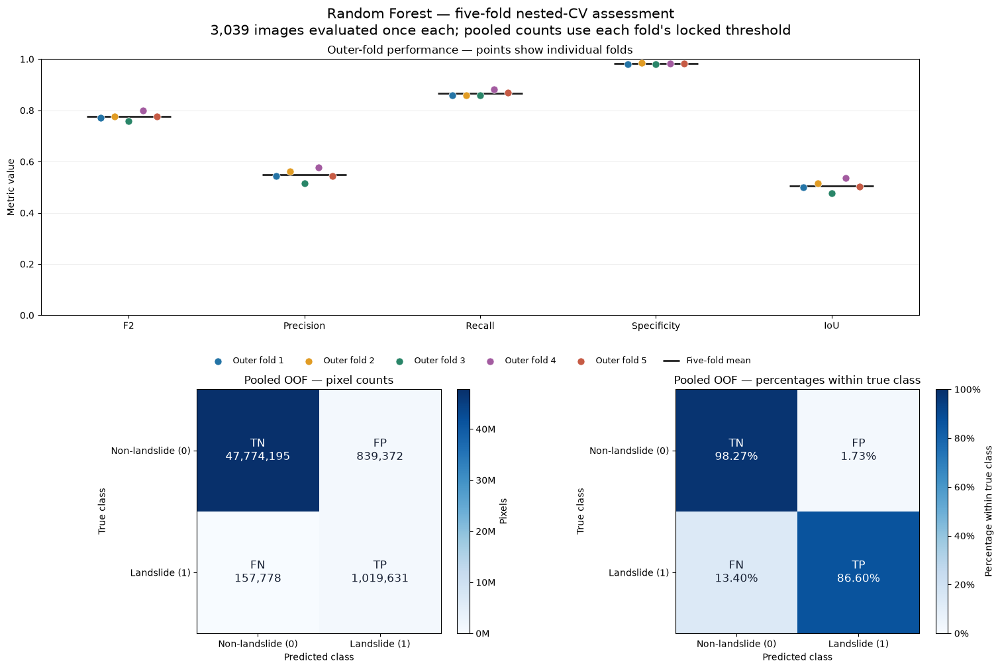

In [88]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

rf_plot_metrics = [
    ("F2", "F2"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("Specificity", "Specificity"),
    ("IoU", "IoU")
]

rf_fold_colors = [
    "#2474A6", "#E19C24", "#298568", "#A35BA0", "#C65B45"
]

rf_overview_figure = plt.figure(
    figsize=(15, 10),
    constrained_layout=True
)
rf_overview_grid = rf_overview_figure.add_gridspec(
    2, 2, height_ratios=[1.05, 1]
)

# Top panel: fold variation on a shared, full-range metric axis.
rf_metric_ax = rf_overview_figure.add_subplot(rf_overview_grid[0, :])
rf_offsets = np.linspace(-0.16, 0.16, 5)

for rf_fold_index, rf_fold in enumerate(range(1, 6)):
    rf_row = rf_outer_metrics_table.loc[
        rf_outer_metrics_table["Outer_fold"] == rf_fold
    ].iloc[0]

    rf_metric_ax.scatter(
        [
            index + rf_offsets[rf_fold_index]
            for index in range(len(rf_plot_metrics))
        ],
        [rf_row[column] for column, _ in rf_plot_metrics],
        s=65,
        color=rf_fold_colors[rf_fold_index],
        edgecolors="white",
        linewidths=0.6,
        zorder=3,
        label=f"Outer fold {rf_fold}"
    )

for rf_index, (rf_column, _) in enumerate(rf_plot_metrics):
    rf_mean = rf_outer_mean_sd.loc[rf_column, "Mean_outer"]

    rf_metric_ax.hlines(
        rf_mean,
        rf_index - 0.24,
        rf_index + 0.24,
        color="#222222",
        linewidth=2,
        label="Five-fold mean" if rf_index == 0 else None
    )

rf_metric_ax.set_xticks(
    range(len(rf_plot_metrics)),
    [label for _, label in rf_plot_metrics]
)
rf_metric_ax.set(
    ylabel="Metric value",
    ylim=(0, 1),
    xlim=(-0.5, len(rf_plot_metrics) - 0.5),
    title="Outer-fold performance — points show individual folds"
)
rf_metric_ax.grid(axis="y", alpha=0.20)
rf_metric_ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=6,
    fontsize=9,
    frameon=False
)

# Bottom panels: pooled counts and row-normalized percentages.
rf_cm = np.array([
    [rf_pooled_counts["TN"], rf_pooled_counts["FP"]],
    [rf_pooled_counts["FN"], rf_pooled_counts["TP"]]
], dtype=np.int64)

rf_cm_percent = (
    rf_cm / rf_cm.sum(axis=1, keepdims=True) * 100
)

rf_cm_names = np.array([["TN", "FP"], ["FN", "TP"]])
rf_class_labels = ["Non-landslide (0)", "Landslide (1)"]

for rf_column, (rf_values, rf_title, rf_vmax) in enumerate([
    (rf_cm, "Pooled OOF — pixel counts", float(rf_cm.max())),
    (rf_cm_percent, "Pooled OOF — percentages within true class", 100.0)
]):
    rf_ax = rf_overview_figure.add_subplot(
        rf_overview_grid[1, rf_column]
    )
    rf_im = rf_ax.imshow(
        rf_values,
        cmap="Blues",
        vmin=0,
        vmax=rf_vmax
    )

    rf_ax.set_xticks([0, 1], labels=rf_class_labels)
    rf_ax.set_yticks([0, 1], labels=rf_class_labels)
    rf_ax.set(
        xlabel="Predicted class",
        ylabel="True class",
        title=rf_title
    )

    for rf_i in range(2):
        for rf_j in range(2):
            rf_value = rf_values[rf_i, rf_j]
            rf_text = (
                f"{int(rf_value):,}"
                if rf_column == 0
                else f"{rf_value:.2f}%"
            )
            rf_ax.text(
                rf_j, rf_i,
                f"{rf_cm_names[rf_i, rf_j]}\n{rf_text}",
                ha="center",
                va="center",
                fontsize=12,
                color=(
                    "white" if rf_value > 0.55 * rf_vmax
                    else "#172033"
                )
            )

    rf_colorbar = rf_overview_figure.colorbar(
        rf_im, ax=rf_ax, fraction=0.046, pad=0.04
    )

    if rf_column == 0:
        rf_colorbar.set_label("Pixels")
        rf_colorbar.ax.yaxis.set_major_formatter(
            FuncFormatter(lambda value, position: f"{value / 1e6:g}M")
        )
    else:
        rf_colorbar.set_label("Percentage within true class")
        rf_colorbar.ax.yaxis.set_major_formatter(
            PercentFormatter(xmax=100)
        )

for rf_ax in rf_overview_figure.axes:
    rf_ax.tick_params(labelsize=10)

rf_metric_ax.title.set_fontweight("normal")

rf_overview_figure.suptitle(
    "Random Forest — five-fold nested-CV assessment\n"
    "3,039 images evaluated once each; pooled counts use each fold's locked threshold",
    fontsize=15,
    fontweight="normal"
)

rf_oof_figures_dir = rf_oof_summary_dir / "figures"
rf_oof_figures_dir.mkdir(parents=True, exist_ok=True)

rf_overview_figure.savefig(
    rf_oof_figures_dir / "outer_cv_performance_overview.png",
    dpi=220,
    bbox_inches="tight"
)
rf_overview_figure.savefig(
    rf_oof_figures_dir / "outer_cv_performance_overview.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Display fold-level variation and the pooled error burden together.
Result: Pooled recall was 86.60%, with 13.40% of landslide pixels missed. The non-landslide false-positive rate was 1.73%, producing 839,372 false positives and pooled precision of 54.85%. Mean outer F2 was 0.775979.

In [90]:
import sys
import shutil
import ctypes

rf_oof_pixel_count = int(rf_oof_per_image["pixels"].sum())

rf_score_storage_gib = (
    rf_oof_pixel_count * np.dtype(np.float64).itemsize / 1024**3
)
rf_label_storage_gib = (
    rf_oof_pixel_count * np.dtype(np.uint8).itemsize / 1024**3
)

print("OOF pixels:", f"{rf_oof_pixel_count:,}")
print(f"Float64 score array: {rf_score_storage_gib:.3f} GiB")
print(f"Uint8 label array: {rf_label_storage_gib:.3f} GiB")
print("Sorting and metric calculations require additional working memory.")

rf_available_ram_gib = None

if sys.platform == "win32":
    class RFMemoryStatus(ctypes.Structure):
        _fields_ = [
            ("dwLength", ctypes.c_ulong),
            ("dwMemoryLoad", ctypes.c_ulong),
            ("ullTotalPhys", ctypes.c_ulonglong),
            ("ullAvailPhys", ctypes.c_ulonglong),
            ("ullTotalPageFile", ctypes.c_ulonglong),
            ("ullAvailPageFile", ctypes.c_ulonglong),
            ("ullTotalVirtual", ctypes.c_ulonglong),
            ("ullAvailVirtual", ctypes.c_ulonglong),
            ("ullAvailExtendedVirtual", ctypes.c_ulonglong)
        ]

    rf_memory_status = RFMemoryStatus()
    rf_memory_status.dwLength = ctypes.sizeof(RFMemoryStatus)

    rf_memory_api = ctypes.windll.kernel32.GlobalMemoryStatusEx
    rf_memory_api.argtypes = [ctypes.POINTER(RFMemoryStatus)]
    rf_memory_api.restype = ctypes.c_int

    if not rf_memory_api(ctypes.byref(rf_memory_status)):
        raise ctypes.WinError()

    rf_available_ram_gib = rf_memory_status.ullAvailPhys / 1024**3

    print(
        f"\nTotal physical RAM: "
        f"{rf_memory_status.ullTotalPhys / 1024**3:.2f} GiB"
    )
    print(f"Currently available RAM: {rf_available_ram_gib:.2f} GiB")

else:
    print("\nAutomatic RAM inspection in this cell is Windows-specific.")

rf_disk_usage = shutil.disk_usage(rf_oof_summary_dir)
print(f"Free space on results drive: {rf_disk_usage.free / 1024**3:.2f} GiB")

print("\nNo scores were recomputed and no large arrays were loaded.")

OOF pixels: 49,790,976
Float64 score array: 0.371 GiB
Uint8 label array: 0.046 GiB
Sorting and metric calculations require additional working memory.

Total physical RAM: 63.71 GiB
Currently available RAM: 43.95 GiB
Free space on results drive: 1671.95 GiB

No scores were recomputed and no large arrays were loaded.


Rationale: Check resources before calculating exact pooled ranking metrics.
Result: Available RAM is 43.95 GiB, supporting direct calculation using all 49,790,976 OOF pixels. No predictions were recomputed.

In [91]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

rf_pooled_ranking_signature = hashlib.sha256(
    json.dumps({
        "outer_evaluation_signatures": rf_outer_aggregation_sources,
        "sklearn_version": sklearn.__version__,
        "score_dtype": "float64",
        "image_order": "numeric_image_id",
        "ranking_code_version": 1
    }, sort_keys=True).encode("utf-8")
).hexdigest()

rf_pooled_ranking_dir = (
    rf_oof_summary_dir / "exact_ranking" / rf_pooled_ranking_signature
)
rf_pooled_ranking_dir.mkdir(parents=True, exist_ok=True)

rf_pooled_ranking_path = rf_pooled_ranking_dir / "ranking_results.joblib"
rf_oof_scores_path = rf_pooled_ranking_dir / "oof_scores.npy"
rf_oof_labels_path = rf_pooled_ranking_dir / "oof_labels.npy"

if rf_pooled_ranking_path.is_file():
    rf_pooled_ranking_result = joblib.load(rf_pooled_ranking_path)

    assert rf_pooled_ranking_result["signature"] == (
        rf_pooled_ranking_signature
    )
    assert rf_oof_scores_path.is_file()
    assert rf_oof_labels_path.is_file()

    print("Loaded completed pooled ROC/PR calculations.")

else:
    rf_ordered_oof_ids = (
        rf_oof_per_image["image_id"].astype(str).tolist()
    )

    assert rf_ordered_oof_ids == sorted(rf_ordered_oof_ids, key=int)
    assert len(rf_ordered_oof_ids) == len(set(rf_ordered_oof_ids))

    rf_oof_id_to_row = {
        image_id: row
        for row, image_id in enumerate(rf_ordered_oof_ids)
    }

    # Disk-backed arrays retain the exact saved float64 scores.
    rf_scores_matrix = np.lib.format.open_memmap(
        rf_oof_scores_path,
        mode="w+",
        dtype=np.float64,
        shape=(len(rf_ordered_oof_ids), 128 * 128)
    )
    rf_labels_matrix = np.lib.format.open_memmap(
        rf_oof_labels_path,
        mode="w+",
        dtype=np.uint8,
        shape=(len(rf_ordered_oof_ids), 128 * 128)
    )

    rf_seen_oof_ids = set()
    rf_rebuilt_counts = {name: 0 for name in ["TN", "FP", "FN", "TP"]}

    for rf_fold in range(1, 6):
        rf_evaluation = rf_outer_evaluations_by_fold[rf_fold]
        rf_fold_seen_ids = []
        rf_fold_counts = {name: 0 for name in rf_rebuilt_counts}
        rf_threshold = float(rf_evaluation["metadata"]["threshold"])

        rf_expected_positive_counts = dict(zip(
            rf_evaluation["per_image"]["image_id"].astype(str),
            rf_evaluation["per_image"]["positive_pixels"].astype(int)
        ))

        for rf_path in rf_evaluation["prediction_files"]:
            rf_chunk = joblib.load(rf_path)

            assert rf_chunk["signature"] == rf_evaluation["signature"]

            rf_ids = rf_chunk["image_ids"]
            rf_scores = np.asarray(rf_chunk["scores"])
            rf_labels = np.asarray(rf_chunk["labels"])

            assert len(rf_ids) == len(set(rf_ids))
            assert set(rf_ids).isdisjoint(rf_seen_oof_ids)
            assert set(rf_ids).issubset(set(rf_evaluation["image_ids"]))
            assert rf_scores.shape == (len(rf_ids), 128 * 128)
            assert rf_labels.shape == rf_scores.shape
            assert rf_scores.dtype == np.float64
            assert np.isfinite(rf_scores).all()
            assert np.all((rf_scores >= 0) & (rf_scores <= 1))
            assert np.isin(rf_labels, [0, 1]).all()

            assert np.array_equal(
                rf_labels.sum(axis=1),
                np.array([
                    rf_expected_positive_counts[image_id]
                    for image_id in rf_ids
                ])
            )

            rf_rows = np.array(
                [rf_oof_id_to_row[image_id] for image_id in rf_ids],
                dtype=np.intp
            )

            rf_scores_matrix[rf_rows] = rf_scores
            rf_labels_matrix[rf_rows] = rf_labels

            rf_predictions = rf_scores >= rf_threshold
            rf_true_positive_class = rf_labels == 1

            rf_fold_counts["TP"] += int(np.count_nonzero(
                rf_predictions & rf_true_positive_class
            ))
            rf_fold_counts["FP"] += int(np.count_nonzero(
                rf_predictions & ~rf_true_positive_class
            ))
            rf_fold_counts["FN"] += int(np.count_nonzero(
                ~rf_predictions & rf_true_positive_class
            ))
            rf_fold_counts["TN"] += int(np.count_nonzero(
                ~rf_predictions & ~rf_true_positive_class
            ))

            rf_seen_oof_ids.update(rf_ids)
            rf_fold_seen_ids.extend(rf_ids)

        assert rf_fold_seen_ids == rf_evaluation["image_ids"]

        for rf_name in rf_fold_counts:
            assert rf_fold_counts[rf_name] == int(
                rf_evaluation["metrics"][rf_name]
            )
            rf_rebuilt_counts[rf_name] += rf_fold_counts[rf_name]

        print(
            f"Loaded and verified outer fold {rf_fold}/5.",
            flush=True
        )

    assert rf_seen_oof_ids == set(rf_ordered_oof_ids)
    assert rf_rebuilt_counts == rf_pooled_counts

    rf_scores_matrix.flush()
    rf_labels_matrix.flush()

    rf_flat_scores = rf_scores_matrix.reshape(-1)
    rf_flat_labels = rf_labels_matrix.reshape(-1)

    print("Calculating exact pooled ROC curve...", flush=True)

    rf_pooled_fpr, rf_pooled_tpr, rf_roc_thresholds = roc_curve(
        rf_flat_labels,
        rf_flat_scores,
        pos_label=1,
        drop_intermediate=True
    )
    rf_exact_pooled_auc = float(auc(rf_pooled_fpr, rf_pooled_tpr))
    del rf_roc_thresholds

    print("Calculating exact pooled precision–recall curve...", flush=True)

    rf_pooled_precision, rf_pooled_recall, rf_pr_thresholds = (
        precision_recall_curve(
            rf_flat_labels,
            rf_flat_scores,
            pos_label=1,
            drop_intermediate=True
        )
    )

    # Average precision uses recall-step weighting, not trapezoidal PR area.
    # Removing redundant equal-recall points does not change this sum.
    rf_exact_pooled_ap = float(-np.sum(
        np.diff(rf_pooled_recall) * rf_pooled_precision[:-1]
    ))
    del rf_pr_thresholds

    rf_pooled_prevalence = (
        (rf_pooled_counts["TP"] + rf_pooled_counts["FN"])
        / rf_flat_labels.size
    )

    assert 0 <= rf_exact_pooled_auc <= 1
    assert 0 <= rf_exact_pooled_ap <= 1
    assert np.isclose(
        rf_pooled_tpr[-1], 1.0, rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_pooled_fpr[-1], 1.0, rtol=0, atol=1e-12
    )
    assert np.isclose(
        rf_pooled_precision[0],
        rf_pooled_prevalence,
        rtol=0, atol=1e-12
    )

    rf_pooled_ranking_result = {
        "signature": rf_pooled_ranking_signature,
        "outer_evaluation_signatures": rf_outer_aggregation_sources,
        "ordered_image_ids": rf_ordered_oof_ids,
        "pixels": int(rf_flat_labels.size),
        "ROC_AUC": rf_exact_pooled_auc,
        "Average_precision": rf_exact_pooled_ap,
        "prevalence": rf_pooled_prevalence,
        "roc": {
            "fpr": rf_pooled_fpr,
            "tpr": rf_pooled_tpr
        },
        "pr": {
            "precision": rf_pooled_precision,
            "recall": rf_pooled_recall
        },
        "scores_path": str(rf_oof_scores_path),
        "labels_path": str(rf_oof_labels_path)
    }

    rf_temp = rf_pooled_ranking_path.with_suffix(".tmp")
    joblib.dump(rf_pooled_ranking_result, rf_temp)
    rf_temp.replace(rf_pooled_ranking_path)

    del rf_flat_scores, rf_flat_labels
    del rf_scores_matrix, rf_labels_matrix


rf_pooled_oof_metrics.update({
    "ROC_AUC": rf_pooled_ranking_result["ROC_AUC"],
    "Average_precision": rf_pooled_ranking_result["Average_precision"]
})

rf_complete_oof_comparison = rf_outer_mean_sd.copy()
rf_complete_oof_comparison["Pooled_OOF"] = pd.Series(
    rf_pooled_oof_metrics
)

rf_complete_oof_comparison.to_csv(
    rf_oof_summary_dir / "complete_outer_and_pooled_metrics.csv"
)

rf_complete_summary_path = (
    rf_oof_summary_dir / "complete_oof_summary.joblib"
)
rf_temp = rf_complete_summary_path.with_suffix(".tmp")

joblib.dump(
    {
        "aggregation_signature": rf_aggregation_signature,
        "ranking_signature": rf_pooled_ranking_signature,
        "outer_metrics": rf_outer_metrics_table,
        "outer_mean_sd": rf_outer_mean_sd,
        "pooled_metrics": rf_pooled_oof_metrics,
        "comparison": rf_complete_oof_comparison,
        "per_image": rf_oof_per_image,
        "pooled_counts": rf_pooled_counts,
        "ranking_results_path": str(rf_pooled_ranking_path)
    },
    rf_temp
)
rf_temp.replace(rf_complete_summary_path)

display(rf_complete_oof_comparison.round(6))

print(
    "\nOOF landslide prevalence:",
    f"{100 * rf_pooled_ranking_result['prevalence']:.4f}%"
)
print("All saved scores used at their original float64 precision.")
print("Pooled ranking metrics combine scores from five fitted models.")
print("They are distinct from the mean of within-fold ranking metrics.")
print("No models were trained and no predictions were recomputed.")
print("Secondary holdout remains unevaluated.")

Loaded and verified outer fold 1/5.
Loaded and verified outer fold 2/5.
Loaded and verified outer fold 3/5.
Loaded and verified outer fold 4/5.
Loaded and verified outer fold 5/5.
Calculating exact pooled ROC curve...
Calculating exact pooled precision–recall curve...


,Mean_outer,SD_outer,Pooled_OOF
F2,0.775979,0.014770,0.776136
Precision,0.548697,0.023193,0.548483
Recall,0.865865,0.010509,0.865996
Specificity,0.982734,0.001311,0.982734
IoU,0.505796,0.022368,0.505573
Accuracy,0.979973,0.001431,0.979973
ROC_AUC,0.989577,0.001371,0.989599
Average_precision,0.797660,0.019949,0.798033
Brier_score,0.009306,0.000441,0.009306
Log_loss,0.034473,0.002036,0.034474



OOF landslide prevalence: 2.3647%
All saved scores used at their original float64 precision.
Pooled ranking metrics combine scores from five fitted models.
They are distinct from the mean of within-fold ranking metrics.
No models were trained and no predictions were recomputed.
Secondary holdout remains unevaluated.


Rationale: Calculate exact pooled ranking metrics using every saved OOF score.
Result: Pooled ROC-AUC was 0.989599 and average precision was 0.798033 across 49,790,976 pixels. Landslide prevalence was 2.3647%. The secondary holdout remains unevaluated.

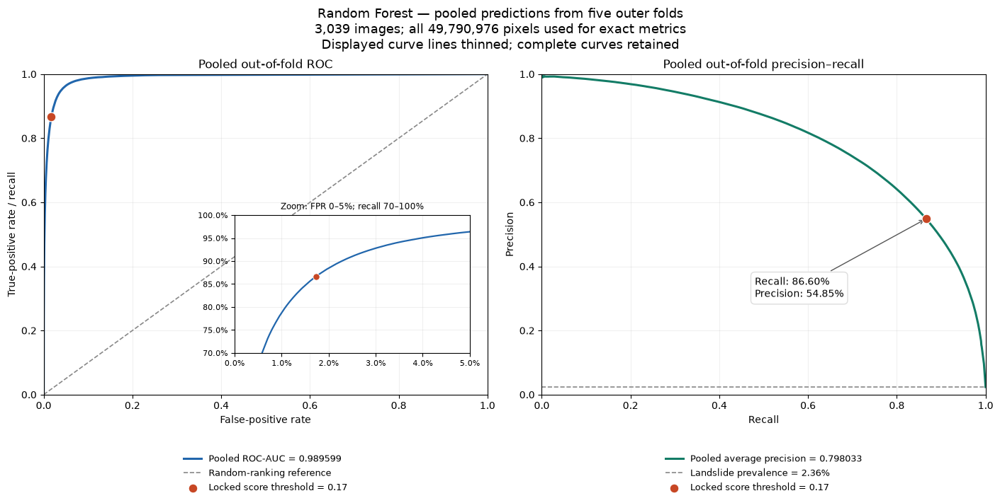

In [92]:
from matplotlib.ticker import PercentFormatter

rf_roc_data = rf_pooled_ranking_result["roc"]
rf_pr_data = rf_pooled_ranking_result["pr"]

rf_locked_thresholds = np.unique(
    rf_outer_metrics_table["Threshold"].to_numpy()
)
assert len(rf_locked_thresholds) == 1

rf_operating_threshold = float(rf_locked_thresholds[0])
rf_operating_recall = float(rf_pooled_oof_metrics["Recall"])
rf_operating_precision = float(rf_pooled_oof_metrics["Precision"])
rf_operating_fpr = 1 - float(rf_pooled_oof_metrics["Specificity"])


def rf_curve_display_indices(length, maximum_points=6000):
    """Thin only the displayed line; retain the exact saved curve separately."""
    if length <= maximum_points:
        return np.arange(length, dtype=np.intp)

    return np.unique(
        np.linspace(
            0, length - 1, maximum_points,
            dtype=np.intp
        )
    )


rf_roc_display = rf_curve_display_indices(len(rf_roc_data["fpr"]))
rf_pr_display = rf_curve_display_indices(len(rf_pr_data["recall"]))

rf_rank_figure, rf_rank_axes = plt.subplots(
    1, 2,
    figsize=(14, 7),
    constrained_layout=True
)

rf_roc_color = "#2166AC"
rf_pr_color = "#137C66"
rf_point_color = "#C74724"

# ROC panel.
rf_roc_ax = rf_rank_axes[0]

rf_roc_ax.plot(
    rf_roc_data["fpr"][rf_roc_display],
    rf_roc_data["tpr"][rf_roc_display],
    color=rf_roc_color,
    linewidth=2.2,
    label=(
        "Pooled ROC-AUC = "
        f"{rf_pooled_ranking_result['ROC_AUC']:.6f}"
    )
)
rf_roc_ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="#888888",
    linewidth=1.2,
    label="Random-ranking reference"
)
rf_roc_ax.scatter(
    rf_operating_fpr,
    rf_operating_recall,
    s=85,
    color=rf_point_color,
    edgecolors="white",
    linewidths=0.9,
    zorder=5,
    label=f"Locked score threshold = {rf_operating_threshold:.2f}"
)

rf_roc_ax.set(
    title="Pooled out-of-fold ROC",
    xlabel="False-positive rate",
    ylabel="True-positive rate / recall",
    xlim=(0, 1),
    ylim=(0, 1)
)
rf_roc_ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    fontsize=9,
    frameon=False
)

# Explicitly labelled ROC zoom.
rf_roc_inset = rf_roc_ax.inset_axes([0.43, 0.13, 0.53, 0.43])

rf_roc_inset.plot(
    rf_roc_data["fpr"][rf_roc_display],
    rf_roc_data["tpr"][rf_roc_display],
    color=rf_roc_color,
    linewidth=1.6
)
rf_roc_inset.scatter(
    rf_operating_fpr,
    rf_operating_recall,
    s=45,
    color=rf_point_color,
    edgecolors="white",
    linewidths=0.6,
    zorder=5
)
rf_roc_inset.set(
    xlim=(0, 0.05),
    ylim=(0.70, 1.0),
    title="Zoom: FPR 0–5%; recall 70–100%"
)
rf_roc_inset.xaxis.set_major_formatter(PercentFormatter(1))
rf_roc_inset.yaxis.set_major_formatter(PercentFormatter(1))
rf_roc_inset.tick_params(labelsize=8)
rf_roc_inset.title.set_fontsize(8.5)
rf_roc_inset.title.set_fontweight("normal")
rf_roc_inset.grid(alpha=0.18)

# Precision–recall panel.
rf_pr_ax = rf_rank_axes[1]

rf_pr_ax.plot(
    rf_pr_data["recall"][rf_pr_display],
    rf_pr_data["precision"][rf_pr_display],
    color=rf_pr_color,
    linewidth=2.2,
    label=(
        "Pooled average precision = "
        f"{rf_pooled_ranking_result['Average_precision']:.6f}"
    )
)
rf_pr_ax.axhline(
    rf_pooled_ranking_result["prevalence"],
    linestyle="--",
    color="#888888",
    linewidth=1.2,
    label=(
        "Landslide prevalence = "
        f"{100 * rf_pooled_ranking_result['prevalence']:.2f}%"
    )
)
rf_pr_ax.scatter(
    rf_operating_recall,
    rf_operating_precision,
    s=85,
    color=rf_point_color,
    edgecolors="white",
    linewidths=0.9,
    zorder=5,
    label=f"Locked score threshold = {rf_operating_threshold:.2f}"
)

rf_pr_ax.annotate(
    f"Recall: {100 * rf_operating_recall:.2f}%\n"
    f"Precision: {100 * rf_operating_precision:.2f}%",
    xy=(rf_operating_recall, rf_operating_precision),
    xytext=(0.48, 0.37),
    textcoords="axes fraction",
    fontsize=10,
    ha="left",
    va="top",
    arrowprops={
        "arrowstyle": "->",
        "color": "#555555",
        "linewidth": 1
    },
    bbox={
        "boxstyle": "round,pad=0.4",
        "facecolor": "white",
        "edgecolor": "#DDDDDD"
    }
)

rf_pr_ax.set(
    title="Pooled out-of-fold precision–recall",
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1)
)
rf_pr_ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    fontsize=9,
    frameon=False
)

for rf_ax in rf_rank_axes:
    rf_ax.grid(alpha=0.18)
    rf_ax.tick_params(labelsize=10)
    rf_ax.title.set_fontweight("normal")

rf_rank_figure.suptitle(
    "Random Forest — pooled predictions from five outer folds\n"
    "3,039 images; all 49,790,976 pixels used for exact metrics\n"
    "Displayed curve lines thinned; complete curves retained",
    fontsize=13,
    fontweight="normal"
)

rf_rank_figure.savefig(
    rf_oof_figures_dir / "pooled_oof_roc_pr.png",
    dpi=220,
    bbox_inches="tight"
)
rf_rank_figure.savefig(
    rf_oof_figures_dir / "pooled_oof_roc_pr.pdf",
    bbox_inches="tight"
)

plt.show()

Rationale: Assess discrimination and the precision–recall trade-off using pooled outer-fold predictions.
Result: ROC-AUC = 0.989599; AP = 0.798033; recall = 86.60% and precision = 54.85% at threshold 0.17.

In [93]:
# Whole-image bootstrap: pooled outer-fold evaluation
# No model fitting or new predictions.

import numpy as np
import pandas as pd
import joblib

rf_bootstrap_repeats = 2000
rf_bootstrap_seed = int(RANDOM_STATE)

rf_bootstrap_columns = [
    "TN", "FP", "FN", "TP",
    "pixels", "squared_error_sum", "log_loss_sum"
]

rf_bootstrap_images = rf_oof_per_image.copy()

assert len(rf_bootstrap_images) == 3039
assert rf_bootstrap_images["image_id"].is_unique
assert not rf_bootstrap_images[rf_bootstrap_columns].isna().any().any()

rf_bootstrap_values = rf_bootstrap_images[
    rf_bootstrap_columns
].to_numpy(dtype=np.float64)

assert np.isfinite(rf_bootstrap_values).all()
assert (rf_bootstrap_values >= 0).all()

# Check that per-image counts reproduce the pooled confusion matrix.
rf_bootstrap_totals = rf_bootstrap_values.sum(axis=0)

for rf_j, rf_name in enumerate(["TN", "FP", "FN", "TP"]):
    assert int(rf_bootstrap_totals[rf_j]) == int(
        rf_pooled_counts[rf_name]
    ), f"Pooled count mismatch: {rf_name}"

assert int(rf_bootstrap_totals[4]) == 49_790_976


def rf_metrics_from_bootstrap_totals(totals, beta=2):
    totals = np.atleast_2d(totals)
    tn, fp, fn, tp, pixels, squared_error, log_loss_sum = totals.T

    def safe_divide(numerator, denominator):
        return np.divide(
            numerator,
            denominator,
            out=np.full_like(numerator, np.nan, dtype=float),
            where=denominator > 0
        )

    beta_squared = beta ** 2

    return pd.DataFrame({
        "F2": safe_divide(
            (1 + beta_squared) * tp,
            (1 + beta_squared) * tp + beta_squared * fn + fp
        ),
        "Precision": safe_divide(tp, tp + fp),
        "Recall": safe_divide(tp, tp + fn),
        "Specificity": safe_divide(tn, tn + fp),
        "IoU": safe_divide(tp, tp + fp + fn),
        "Accuracy": safe_divide(tp + tn, pixels),
        "Brier_score": safe_divide(squared_error, pixels),
        "Log_loss": safe_divide(log_loss_sum, pixels)
    })


rf_bootstrap_rng = np.random.default_rng(rf_bootstrap_seed)
rf_bootstrap_n_images = len(rf_bootstrap_images)
rf_bootstrap_probabilities = np.full(
    rf_bootstrap_n_images,
    1.0 / rf_bootstrap_n_images
)

rf_bootstrap_batches = []

# Process small batches to keep memory use limited.
for rf_start in range(0, rf_bootstrap_repeats, 100):
    rf_batch_size = min(100, rf_bootstrap_repeats - rf_start)

    # Each row represents 3,039 whole-image draws with replacement.
    rf_image_weights = rf_bootstrap_rng.multinomial(
        n=rf_bootstrap_n_images,
        pvals=rf_bootstrap_probabilities,
        size=rf_batch_size
    )

    rf_resampled_totals = rf_image_weights @ rf_bootstrap_values

    rf_bootstrap_batches.append(
        rf_metrics_from_bootstrap_totals(
            rf_resampled_totals,
            beta=BETA
        )
    )

rf_oof_bootstrap_samples = pd.concat(
    rf_bootstrap_batches,
    ignore_index=True
)

assert np.isfinite(rf_oof_bootstrap_samples.to_numpy()).all()

rf_bootstrap_point_estimates = rf_metrics_from_bootstrap_totals(
    rf_bootstrap_totals,
    beta=BETA
).iloc[0]

rf_oof_bootstrap_ci = pd.DataFrame({
    "Pooled_estimate": rf_bootstrap_point_estimates,
    "CI_95_lower": rf_oof_bootstrap_samples.quantile(0.025),
    "CI_95_upper": rf_oof_bootstrap_samples.quantile(0.975)
})
rf_oof_bootstrap_ci.index.name = "Metric"

rf_bootstrap_save_dir = rf_oof_summary_dir / "image_bootstrap"
rf_bootstrap_save_dir.mkdir(parents=True, exist_ok=True)

rf_oof_bootstrap_ci.to_csv(
    rf_bootstrap_save_dir / "pooled_oof_image_bootstrap_ci.csv"
)

joblib.dump(
    {
        "role": "pooled_outer_fold_evaluation",
        "aggregation_signature": rf_aggregation_signature,
        "seed": rf_bootstrap_seed,
        "repeats": rf_bootstrap_repeats,
        "resampling_unit": "whole_image",
        "method": "percentile",
        "confidence_level": 0.95,
        "beta": float(BETA),
        "ordered_image_ids":
            rf_bootstrap_images["image_id"].tolist(),
        "samples": rf_oof_bootstrap_samples,
        "confidence_intervals": rf_oof_bootstrap_ci
    },
    rf_bootstrap_save_dir / "pooled_oof_image_bootstrap.joblib"
)

display(rf_oof_bootstrap_ci.round(6))
print("Bootstrap repetitions:", len(rf_oof_bootstrap_samples))
print("Resampling unit: whole image")
print("Saved to:", rf_bootstrap_save_dir)

,Pooled_estimate,CI_95_lower,CI_95_upper
Metric,,,
F2,0.776136,0.767513,0.784432
Precision,0.548483,0.533986,0.561823
Recall,0.865996,0.859071,0.872502
Specificity,0.982734,0.981797,0.983672
IoU,0.505573,0.492491,0.517951
Accuracy,0.979973,0.978961,0.981006
Brier_score,0.009306,0.008779,0.009804
Log_loss,0.034474,0.032706,0.036238


Bootstrap repetitions: 2000
Resampling unit: whole image
Saved to: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\nested_cv_summary\image_bootstrap


Rationale: Quantify uncertainty by resampling whole images, preserving within-image pixel dependence.
Result: Pooled F2 was 0.776136 (95% percentile bootstrap CI: 0.767513–0.784432). Recall was 86.60%, while precision was 54.85%, indicating substantial false-positive predictions. Intervals are conditional on the fitted models.

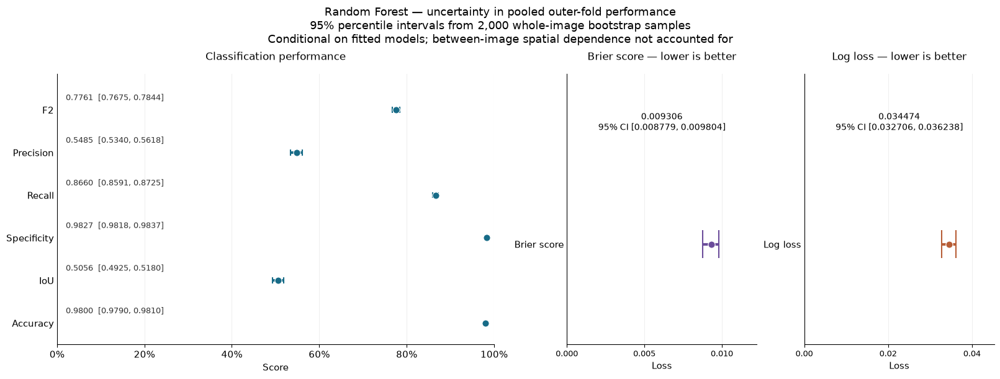

In [94]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rf_ci_plot = rf_oof_bootstrap_ci.copy()

rf_ci_groups = [
    (
        ["F2", "Precision", "Recall",
         "Specificity", "IoU", "Accuracy"],
        "Classification performance",
        "#176B87"
    ),
    (["Brier_score"], "Brier score — lower is better", "#6B4C9A"),
    (["Log_loss"], "Log loss — lower is better", "#B75D36")
]

rf_ci_labels = {
    "F2": "F2",
    "Precision": "Precision",
    "Recall": "Recall",
    "Specificity": "Specificity",
    "IoU": "IoU",
    "Accuracy": "Accuracy",
    "Brier_score": "Brier score",
    "Log_loss": "Log loss"
}

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "pdf.fonttype": 42
}):
    rf_ci_fig, rf_ci_axes = plt.subplots(
        1, 3,
        figsize=(16, 6),
        gridspec_kw={"width_ratios": [2.3, 1, 1]},
        constrained_layout=True
    )

    for rf_ax, (rf_metrics, rf_title, rf_color) in zip(
        rf_ci_axes, rf_ci_groups
    ):
        rf_data = rf_ci_plot.loc[rf_metrics]

        rf_points = rf_data["Pooled_estimate"].to_numpy()
        rf_lowers = rf_data["CI_95_lower"].to_numpy()
        rf_uppers = rf_data["CI_95_upper"].to_numpy()
        rf_y_positions = list(range(len(rf_metrics)))

        rf_ax.hlines(
            rf_y_positions, rf_lowers, rf_uppers,
            color=rf_color, linewidth=3, zorder=2
        )
        rf_ax.scatter(
            rf_points, rf_y_positions,
            color=rf_color, s=65,
            edgecolor="white", linewidth=0.8, zorder=3
        )

        for rf_y, rf_lo, rf_hi in zip(
            rf_y_positions, rf_lowers, rf_uppers
        ):
            rf_ax.vlines(
                [rf_lo, rf_hi],
                rf_y - 0.07, rf_y + 0.07,
                color=rf_color, linewidth=1.5
            )

        rf_ax.set_yticks(rf_y_positions)
        rf_ax.set_yticklabels(
            [rf_ci_labels[m] for m in rf_metrics]
        )
        rf_ax.set_ylim(len(rf_metrics) - 0.5, -0.85)
        rf_ax.set_title(rf_title, pad=16)
        rf_ax.set_axisbelow(True)
        rf_ax.grid(axis="x", alpha=0.20)
        rf_ax.spines[["top", "right"]].set_visible(False)
        rf_ax.tick_params(axis="y", length=0)

        if len(rf_metrics) > 1:
            rf_ax.set_xlim(0, 1)
            rf_ax.xaxis.set_major_formatter(PercentFormatter(1))
            rf_ax.set_xlabel("Score")

            for rf_y, rf_point, rf_lo, rf_hi in zip(
                rf_y_positions, rf_points, rf_lowers, rf_uppers
            ):
                rf_ax.text(
                    0.02, rf_y - 0.23,
                    f"{rf_point:.4f}  [{rf_lo:.4f}, {rf_hi:.4f}]",
                    fontsize=9, color="#333333"
                )
        else:
            # Separate scales, both starting at zero.
            rf_ax.set_xlim(0, float(rf_uppers.max()) * 1.25)
            rf_ax.set_xlabel("Loss")
            rf_ax.locator_params(axis="x", nbins=4)
            rf_ax.tick_params(axis="x", labelsize=9)
            rf_ax.text(
                0.5, 0.82,
                f"{rf_points[0]:.6f}\n"
                f"95% CI [{rf_lowers[0]:.6f}, "
                f"{rf_uppers[0]:.6f}]",
                transform=rf_ax.transAxes,
                ha="center", va="center", fontsize=10
            )

    rf_ci_fig.suptitle(
        "Random Forest — uncertainty in pooled outer-fold performance\n"
        "95% percentile intervals from 2,000 whole-image bootstrap samples\n"
        "Conditional on fitted models; between-image spatial dependence "
        "not accounted for",
        fontsize=13
    )

    rf_oof_figures_dir.mkdir(parents=True, exist_ok=True)

    for rf_extension in ["png", "pdf"]:
        rf_ci_fig.savefig(
            rf_oof_figures_dir
            / f"pooled_oof_bootstrap_intervals.{rf_extension}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Rationale: Visualize uncertainty in pooled outer-fold performance using whole-image bootstrap intervals.
Result: Recall remains high, while precision indicates substantial false positives. Intervals are conditional on the fitted models.

In [95]:
# Pooled outer-fold calibration diagnostic.
# Read saved predictions in batches; do not refit any model.

import numpy as np
import pandas as pd

rf_cal_scores = np.load(
    rf_pooled_ranking_result["scores_path"],
    mmap_mode="r"
)
rf_cal_labels = np.load(
    rf_pooled_ranking_result["labels_path"],
    mmap_mode="r"
)

assert rf_cal_scores.shape == rf_cal_labels.shape
assert rf_cal_scores.size == 49_790_976

rf_cal_n_bins = 20
rf_cal_edges = np.linspace(0.0, 1.0, rf_cal_n_bins + 1)

rf_cal_counts = np.zeros(rf_cal_n_bins, dtype=np.int64)
rf_cal_positive_counts = np.zeros(rf_cal_n_bins, dtype=np.int64)
rf_cal_score_sums = np.zeros(rf_cal_n_bins, dtype=np.float64)

rf_cal_scores_flat = rf_cal_scores.reshape(-1)
rf_cal_labels_flat = rf_cal_labels.reshape(-1)

for rf_cal_start in range(0, rf_cal_scores.size, 1_000_000):
    rf_cal_end = min(
        rf_cal_start + 1_000_000,
        rf_cal_scores.size
    )

    rf_cal_s = np.asarray(
        rf_cal_scores_flat[rf_cal_start:rf_cal_end]
    )
    rf_cal_y = np.asarray(
        rf_cal_labels_flat[rf_cal_start:rf_cal_end]
    )

    assert np.isfinite(rf_cal_s).all()
    assert ((rf_cal_s >= 0) & (rf_cal_s <= 1)).all()
    assert np.isin(rf_cal_y, [0, 1]).all()

    # Bins: [0, .05), [.05, .10), ..., [.95, 1].
    rf_cal_bin_ids = np.searchsorted(
        rf_cal_edges[1:-1],
        rf_cal_s,
        side="right"
    )

    rf_cal_counts += np.bincount(
        rf_cal_bin_ids,
        minlength=rf_cal_n_bins
    )
    rf_cal_positive_counts += np.bincount(
        rf_cal_bin_ids[rf_cal_y == 1],
        minlength=rf_cal_n_bins
    )
    rf_cal_score_sums += np.bincount(
        rf_cal_bin_ids,
        weights=rf_cal_s,
        minlength=rf_cal_n_bins
    )

rf_cal_nonempty = rf_cal_counts > 0

rf_cal_mean_scores = np.divide(
    rf_cal_score_sums,
    rf_cal_counts,
    out=np.full(rf_cal_n_bins, np.nan),
    where=rf_cal_nonempty
)
rf_cal_observed = np.divide(
    rf_cal_positive_counts,
    rf_cal_counts,
    out=np.full(rf_cal_n_bins, np.nan),
    where=rf_cal_nonempty
)

rf_oof_calibration_table = pd.DataFrame({
    "Bin_lower": rf_cal_edges[:-1],
    "Bin_upper": rf_cal_edges[1:],
    "Pixels": rf_cal_counts,
    "Positive_pixels": rf_cal_positive_counts,
    "Pixel_share": rf_cal_counts / rf_cal_counts.sum(),
    "Mean_score": rf_cal_mean_scores,
    "Observed_positive_fraction": rf_cal_observed,
    "Observed_minus_score":
        rf_cal_observed - rf_cal_mean_scores
})

assert int(rf_cal_counts.sum()) == 49_790_976
assert int(rf_cal_positive_counts.sum()) == int(
    rf_pooled_counts["TP"] + rf_pooled_counts["FN"]
)

rf_oof_calibration_table.to_csv(
    rf_oof_summary_dir / "pooled_oof_calibration_bins.csv",
    index=False
)

display(rf_oof_calibration_table.round(6))

,Bin_lower,Bin_upper,Pixels,Positive_pixels,Pixel_share,Mean_score,Observed_positive_fraction,Observed_minus_score
0,0.00,0.05,46673368,56189,0.937386,0.001669,0.001204,-0.000465
1,0.05,0.10,750484,42633,0.015073,0.071476,0.056807,-0.014668
2,0.10,0.15,391945,42125,0.007872,0.122967,0.107477,-0.015490
3,0.15,0.20,262163,41648,0.005265,0.173553,0.158863,-0.014690
4,0.20,0.25,194577,41027,0.003908,0.223929,0.210852,-0.013077
5,0.25,0.30,154154,40758,0.003096,0.274122,0.264398,-0.009724
6,0.30,0.35,129048,40813,0.002592,0.324214,0.316262,-0.007952
7,0.35,0.40,111511,42062,0.002240,0.374431,0.377200,0.002770
8,0.40,0.45,99867,42908,0.002006,0.424619,0.429651,0.005032
9,0.45,0.50,92710,45179,0.001862,0.474692,0.487315,0.012623


Rationale: Compare mean predicted scores with observed landslide frequencies in 20 equal-width bins.
Result: Scores overestimate observed frequencies below 0.35 and underestimate them above 0.35. The largest absolute bin-level gap is approximately 3.27 percentage points; 93.74% of pixels fall in the lowest bin.

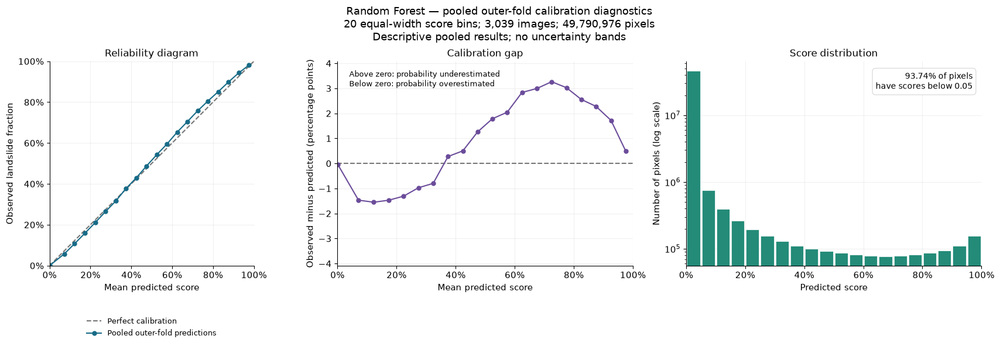

In [96]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rf_rel = rf_oof_calibration_table.loc[
    rf_oof_calibration_table["Pixels"] > 0
].copy()

rf_rel_x = rf_rel["Mean_score"].to_numpy()
rf_rel_y = rf_rel["Observed_positive_fraction"].to_numpy()
rf_rel_gap = 100 * rf_rel["Observed_minus_score"].to_numpy()

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 12,
    "pdf.fonttype": 42
}):
    rf_rel_fig, rf_rel_axes = plt.subplots(
        1, 3, figsize=(17, 5.8),
        constrained_layout=True
    )

    # 1. Reliability diagram
    rf_ax = rf_rel_axes[0]
    rf_ax.plot(
        [0, 1], [0, 1], "--",
        color="#777777", label="Perfect calibration"
    )
    rf_ax.plot(
        rf_rel_x, rf_rel_y, "o-",
        color="#176B87", markersize=5,
        label="Pooled outer-fold predictions"
    )
    rf_ax.set(
        xlim=(0, 1), ylim=(0, 1),
        xlabel="Mean predicted score",
        ylabel="Observed landslide fraction",
        title="Reliability diagram"
    )
    rf_ax.set_aspect("equal", adjustable="box")
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.yaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.22),
        frameon=False, fontsize=9
    )

    # 2. Calibration gap in percentage points
    rf_ax = rf_rel_axes[1]
    rf_ax.axhline(0, color="#777777", linestyle="--")
    rf_ax.plot(
        rf_rel_x, rf_rel_gap,
        "o-", color="#6B4C9A", markersize=5
    )
    rf_gap_limit = max(1.0, np.max(np.abs(rf_rel_gap)) * 1.25)
    rf_ax.set(
        xlim=(0, 1),
        ylim=(-rf_gap_limit, rf_gap_limit),
        xlabel="Mean predicted score",
        ylabel="Observed minus predicted (percentage points)",
        title="Calibration gap"
    )
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.text(
        0.04, 0.96,
        "Above zero: probability underestimated\n"
        "Below zero: probability overestimated",
        transform=rf_ax.transAxes,
        va="top", fontsize=9
    )

    # 3. Bin populations: log scale explicitly labelled
    rf_ax = rf_rel_axes[2]
    rf_centres = (
        rf_rel["Bin_lower"].to_numpy()
        + rf_rel["Bin_upper"].to_numpy()
    ) / 2
    rf_widths = (
        rf_rel["Bin_upper"].to_numpy()
        - rf_rel["Bin_lower"].to_numpy()
    )

    rf_ax.bar(
        rf_centres,
        rf_rel["Pixels"].to_numpy(),
        width=rf_widths * 0.88,
        color="#238B78",
        edgecolor="white",
        linewidth=0.5
    )
    rf_ax.set_yscale("log")
    rf_ax.set(
        xlim=(0, 1),
        xlabel="Predicted score",
        ylabel="Number of pixels (log scale)",
        title="Score distribution"
    )
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))

    rf_first_share = float(
        rf_oof_calibration_table.iloc[0]["Pixel_share"]
    )
    rf_ax.text(
        0.97, 0.95,
        f"{rf_first_share:.2%} of pixels\n"
        "have scores below 0.05",
        transform=rf_ax.transAxes,
        ha="right", va="top", fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white", edgecolor="#DDDDDD"
        )
    )

    for rf_ax in rf_rel_axes:
        rf_ax.set_axisbelow(True)
        rf_ax.grid(alpha=0.18)
        rf_ax.spines[["top", "right"]].set_visible(False)

    rf_rel_fig.suptitle(
        "Random Forest — pooled outer-fold calibration diagnostics\n"
        "20 equal-width score bins; 3,039 images; "
        "49,790,976 pixels\n"
        "Descriptive pooled results; no uncertainty bands",
        fontsize=13
    )

    rf_oof_figures_dir.mkdir(parents=True, exist_ok=True)

    for rf_ext in ["png", "pdf"]:
        rf_rel_fig.savefig(
            rf_oof_figures_dir
            / f"pooled_oof_calibration_diagnostics.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Rationale: Examine calibration together with score distribution and bin-level deviations.
Result: The pooled reliability curve is close to the diagonal, with systematic gaps ranging from approximately −1.55 to +3.27 percentage points. Most pixels (93.74%) have scores below 0.05.

In [97]:
# Image-level diagnostic using saved outer-fold predictions.
import numpy as np
import pandas as pd

rf_image_diagnostics = rf_oof_per_image.copy()

rf_image_diagnostics["Has_landslide"] = (
    rf_image_diagnostics["positive_pixels"] > 0
)
rf_image_diagnostics["FP_pixel_fraction"] = (
    rf_image_diagnostics["FP"] / rf_image_diagnostics["pixels"]
)
rf_image_diagnostics["Any_false_positive"] = (
    rf_image_diagnostics["FP"] > 0
)

rf_group_rows = []

for rf_has_landslide, rf_group_name in [
    (False, "Images without landslides"),
    (True, "Images with landslides")
]:
    rf_group = rf_image_diagnostics.loc[
        rf_image_diagnostics["Has_landslide"] == rf_has_landslide
    ]

    if rf_group.empty:
        continue

    rf_tn = int(rf_group["TN"].sum())
    rf_fp = int(rf_group["FP"].sum())
    rf_fn = int(rf_group["FN"].sum())
    rf_tp = int(rf_group["TP"].sum())
    rf_pixels = int(rf_group["pixels"].sum())

    rf_group_rows.append({
        "Group": rf_group_name,
        "Images": len(rf_group),
        "Pixels": rf_pixels,
        "Positive_pixels": int(rf_group["positive_pixels"].sum()),
        "TN": rf_tn,
        "FP": rf_fp,
        "FN": rf_fn,
        "TP": rf_tp,
        "Images_with_any_FP": int(
            rf_group["Any_false_positive"].sum()
        ),
        "Fraction_images_with_any_FP": float(
            rf_group["Any_false_positive"].mean()
        ),
        "FP_fraction_of_all_pixels": rf_fp / rf_pixels,
        "False_positive_rate": (
            rf_fp / (rf_tn + rf_fp)
            if rf_tn + rf_fp > 0 else np.nan
        ),
        "Median_image_FP_fraction": float(
            rf_group["FP_pixel_fraction"].median()
        ),
        "P90_image_FP_fraction": float(
            rf_group["FP_pixel_fraction"].quantile(0.90)
        ),
        "Recall": (
            rf_tp / (rf_tp + rf_fn)
            if rf_tp + rf_fn > 0 else np.nan
        ),
        "Precision": (
            rf_tp / (rf_tp + rf_fp)
            if rf_tp + rf_fp > 0 else np.nan
        )
    })

rf_image_group_summary = pd.DataFrame(rf_group_rows)

# Negative-image FP burden: descriptive pixel-count categories.
rf_negative_images = rf_image_diagnostics.loc[
    ~rf_image_diagnostics["Has_landslide"]
].copy()

rf_fp_bin_edges = [-0.5, 0.5, 10.5, 100.5, 1000.5, np.inf]
rf_fp_bin_labels = [
    "0", "1–10", "11–100", "101–1,000", ">1,000"
]

rf_negative_images["FP_count_group"] = pd.cut(
    rf_negative_images["FP"],
    bins=rf_fp_bin_edges,
    labels=rf_fp_bin_labels
)

rf_negative_fp_burden = (
    rf_negative_images["FP_count_group"]
    .value_counts(sort=False)
    .rename_axis("False_positive_pixels_per_image")
    .reset_index(name="Images")
)

rf_negative_fp_burden["Fraction_of_negative_images"] = (
    rf_negative_fp_burden["Images"] / len(rf_negative_images)
    if len(rf_negative_images) > 0 else np.nan
)

rf_image_group_summary.to_csv(
    rf_oof_summary_dir / "oof_image_group_summary.csv",
    index=False
)
rf_negative_fp_burden.to_csv(
    rf_oof_summary_dir / "oof_negative_image_fp_burden.csv",
    index=False
)

print("Outer-fold evaluation: image-group diagnostic")
display(rf_image_group_summary.round(6))

print("False-positive burden in images without landslides")
display(rf_negative_fp_burden.round(6))

Outer-fold evaluation: image-group diagnostic


,Group,Images,Pixels,Positive_pixels,TN,FP,FN,TP,Images_with_any_FP,Fraction_images_with_any_FP,FP_fraction_of_all_pixels,False_positive_rate,Median_image_FP_fraction,P90_image_FP_fraction,Recall,Precision
0,Images without landslides,1254,20545536,0,20464947,80589,0,0,891,0.710526,0.003922,0.003922,0.000549,0.009644,NaN,0.000000
1,Images with landslides,1785,29245440,1177409,27309248,758783,157778,1019631,1774,0.993838,0.025945,0.027034,0.015930,0.062610,0.865996,0.573337


False-positive burden in images without landslides


,False_positive_pixels_per_image,Images,Fraction_of_negative_images
0,0,363,0.289474
1,1–10,286,0.228070
2,11–100,420,0.334928
3,"101–1,000",179,0.142743
4,">1,000",6,0.004785


Rationale: Separate false-positive incidence from pixel-level error burden across images with and without landslides.
Result: Among 1,254 landslide-free images, 71.05% contained at least one false-positive pixel, but only 0.392% of their pixels were falsely classified. Overall, 85.25% had at most 100 false-positive pixels.

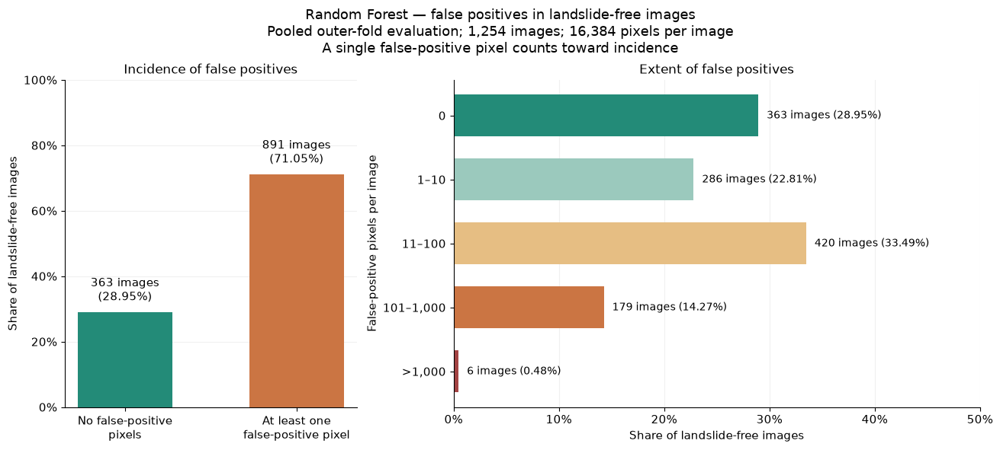

In [98]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rf_neg_plot = rf_negative_fp_burden.copy()
rf_neg_total = int(rf_neg_plot["Images"].sum())

assert rf_neg_total > 0
assert int(rf_neg_plot.iloc[0]["Images"]) == int(
    (rf_negative_images["FP"] == 0).sum()
)

rf_no_fp = int(rf_neg_plot.iloc[0]["Images"])
rf_any_fp = rf_neg_total - rf_no_fp

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 12,
    "pdf.fonttype": 42
}):
    rf_fp_fig, rf_fp_axes = plt.subplots(
        1, 2, figsize=(13, 5.8),
        gridspec_kw={"width_ratios": [1, 1.8]},
        constrained_layout=True
    )

    # Left: incidence of any false-positive pixel.
    rf_ax = rf_fp_axes[0]
    rf_incidence = np.array([rf_no_fp, rf_any_fp]) / rf_neg_total

    rf_bars = rf_ax.bar(
        ["No false-positive\npixels", "At least one\nfalse-positive pixel"],
        rf_incidence,
        color=["#238B78", "#CB7543"],
        width=0.55
    )

    for rf_bar, rf_count, rf_fraction in zip(
        rf_bars, [rf_no_fp, rf_any_fp], rf_incidence
    ):
        rf_ax.text(
            rf_bar.get_x() + rf_bar.get_width() / 2,
            rf_fraction + 0.025,
            f"{rf_count:,} images\n({rf_fraction:.2%})",
            ha="center", va="bottom", fontsize=11
        )

    rf_ax.set(
        ylim=(0, 1),
        ylabel="Share of landslide-free images",
        title="Incidence of false positives"
    )
    rf_ax.yaxis.set_major_formatter(PercentFormatter(1))

    # Right: false-positive pixel burden per negative image.
    rf_ax = rf_fp_axes[1]
    rf_positions = np.arange(len(rf_neg_plot))
    rf_fractions = (
        rf_neg_plot["Fraction_of_negative_images"].to_numpy()
    )

    rf_ax.barh(
        rf_positions,
        rf_fractions,
        color=["#238B78", "#9BC9BD", "#E6BE83",
               "#CB7543", "#A34343"],
        height=0.65
    )

    for rf_y, rf_count, rf_fraction in zip(
        rf_positions,
        rf_neg_plot["Images"],
        rf_fractions
    ):
        rf_ax.text(
            rf_fraction + 0.008, rf_y,
            f"{int(rf_count):,} images ({rf_fraction:.2%})",
            va="center", fontsize=10
        )

    rf_ax.set_yticks(rf_positions)
    rf_ax.set_yticklabels(
        rf_neg_plot["False_positive_pixels_per_image"].astype(str)
    )
    rf_ax.invert_yaxis()
    rf_ax.set(
        xlim=(0, 0.50),
        xlabel="Share of landslide-free images",
        ylabel="False-positive pixels per image",
        title="Extent of false positives"
    )
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))

    rf_fp_axes[0].grid(axis="y", alpha=0.18)
    rf_fp_axes[1].grid(axis="x", alpha=0.18)

    for rf_ax in rf_fp_axes:
        rf_ax.set_axisbelow(True)
        rf_ax.spines[["top", "right"]].set_visible(False)

    rf_fp_fig.suptitle(
        "Random Forest — false positives in landslide-free images\n"
        f"Pooled outer-fold evaluation; {rf_neg_total:,} images; "
        "16,384 pixels per image\n"
        "A single false-positive pixel counts toward incidence",
        fontsize=13
    )

    for rf_ext in ["png", "pdf"]:
        rf_fp_fig.savefig(
            rf_oof_figures_dir
            / f"oof_negative_image_false_positives.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Rationale: Distinguish the occurrence of false positives from their pixel-level extent.
Result: Although 71.05% of landslide-free images contain false positives, 85.25% contain at most 100 false-positive pixels. Only six images exceed 1,000.

In [99]:
# Impurity-based feature importance from the five saved outer models.
# No training or prediction.

import numpy as np
import pandas as pd
import joblib

rf_importance_rows = []

for rf_fold in sorted(rf_outer_evaluations_by_fold):
    rf_evaluation = rf_outer_evaluations_by_fold[rf_fold]
    rf_saved_bundle = joblib.load(rf_evaluation["model_path"])

    assert "model" in rf_saved_bundle, (
        f"Missing model in outer fold {rf_fold}"
    )

    rf_saved_model = rf_saved_bundle["model"]

    assert rf_saved_model.n_features_in_ == len(FEATURE_NAMES)
    assert len(rf_saved_model.feature_importances_) == len(FEATURE_NAMES)

    rf_fold_importances = np.asarray(
        rf_saved_model.feature_importances_,
        dtype=float
    )

    assert np.isfinite(rf_fold_importances).all()
    assert (rf_fold_importances >= 0).all()
    assert np.isclose(rf_fold_importances.sum(), 1.0)

    for rf_feature, rf_importance in zip(
        FEATURE_NAMES, rf_fold_importances
    ):
        rf_importance_rows.append({
            "Outer_fold": rf_fold,
            "Feature": rf_feature,
            "Impurity_importance": rf_importance
        })

    # Release the newly loaded copy.
    del rf_saved_model, rf_saved_bundle

rf_outer_feature_importance = pd.DataFrame(rf_importance_rows)

rf_feature_importance_summary = (
    rf_outer_feature_importance
    .groupby("Feature", sort=False)["Impurity_importance"]
    .agg(
        Mean="mean",
        SD_across_folds="std",
        Minimum="min",
        Maximum="max"
    )
    .sort_values("Mean", ascending=False)
)

rf_outer_feature_importance.to_csv(
    rf_oof_summary_dir / "outer_fold_impurity_importance.csv",
    index=False
)
rf_feature_importance_summary.to_csv(
    rf_oof_summary_dir / "impurity_importance_summary.csv"
)

display(rf_feature_importance_summary.round(6))

,Mean,SD_across_folds,Minimum,Maximum
Feature,,,,
B4,0.246617,0.000590,0.245720,0.247169
Slope,0.118027,0.001578,0.116279,0.119709
B3,0.107632,0.010846,0.092937,0.116825
B2,0.097715,0.011110,0.088064,0.114144
Elevation,0.087383,0.002360,0.085331,0.091349
B8,0.052189,0.001160,0.050676,0.053729
B7,0.051350,0.000566,0.050765,0.052022
B1,0.050003,0.000969,0.048318,0.050815
B5,0.042178,0.000396,0.041828,0.042799


Rationale: Summarize impurity-based feature importance across the five outer-fold forests.
Result: B4 has the highest mean importance (24.66%), followed by slope, B3, B2 and elevation. These five features account for approximately 65.75% of total importance.

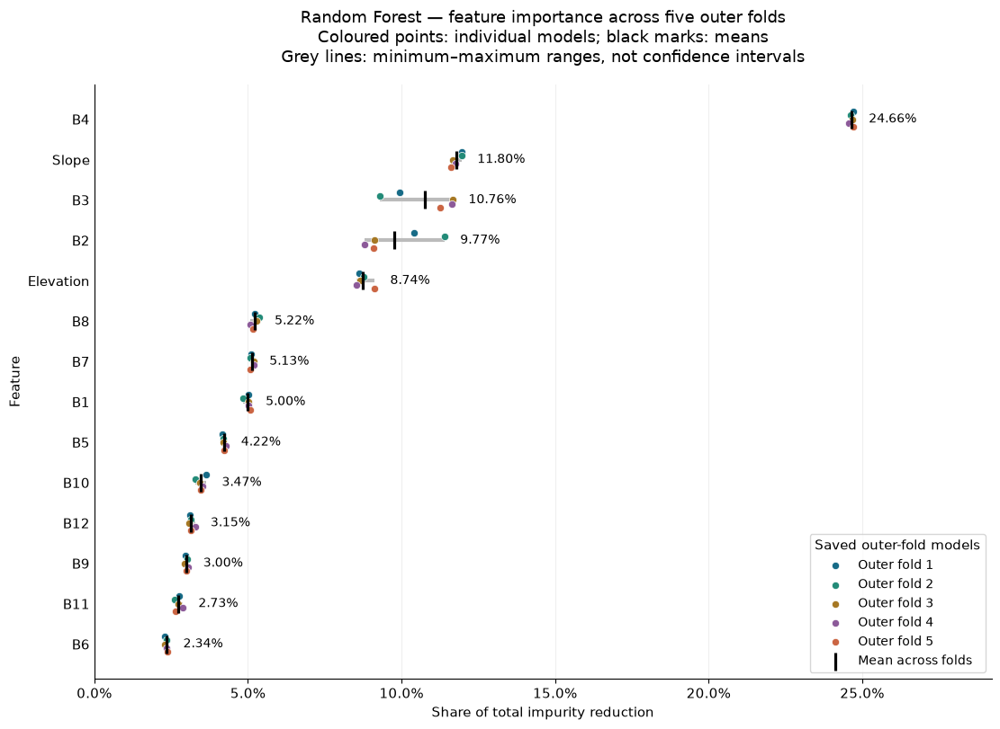

In [100]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rf_imp_order = rf_feature_importance_summary.index.tolist()
rf_imp_folds = sorted(
    rf_outer_feature_importance["Outer_fold"].unique()
)

rf_imp_colors = [
    "#176B87", "#238B78", "#A67824", "#8C5A99", "#CB6543"
]
rf_imp_offsets = np.linspace(-0.19, 0.19, len(rf_imp_folds))
rf_imp_y = np.arange(len(rf_imp_order))

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "pdf.fonttype": 42
}):
    rf_imp_fig, rf_imp_ax = plt.subplots(
        figsize=(11, 8),
        constrained_layout=True
    )

    rf_imp_summary = rf_feature_importance_summary.loc[rf_imp_order]

    rf_imp_ax.hlines(
        rf_imp_y,
        rf_imp_summary["Minimum"],
        rf_imp_summary["Maximum"],
        color="#BBBBBB",
        linewidth=3,
        zorder=1
    )

    for rf_fold, rf_offset, rf_color in zip(
        rf_imp_folds, rf_imp_offsets, rf_imp_colors
    ):
        rf_fold_values = (
            rf_outer_feature_importance.loc[
                rf_outer_feature_importance["Outer_fold"] == rf_fold
            ]
            .set_index("Feature")
            .loc[rf_imp_order, "Impurity_importance"]
            .to_numpy()
        )

        rf_imp_ax.scatter(
            rf_fold_values,
            rf_imp_y + rf_offset,
            s=35,
            color=rf_color,
            edgecolor="white",
            linewidth=0.5,
            label=f"Outer fold {rf_fold}",
            zorder=3
        )

    rf_imp_ax.scatter(
        rf_imp_summary["Mean"],
        rf_imp_y,
        marker="|",
        s=210,
        linewidths=2.3,
        color="black",
        label="Mean across folds",
        zorder=4
    )

    for rf_y, rf_mean, rf_max in zip(
        rf_imp_y,
        rf_imp_summary["Mean"],
        rf_imp_summary["Maximum"]
    ):
        rf_imp_ax.text(
            rf_max + 0.005,
            rf_y,
            f"{rf_mean:.2%}",
            va="center",
            fontsize=10
        )

    rf_imp_ax.set_yticks(rf_imp_y)
    rf_imp_ax.set_yticklabels(rf_imp_order)
    rf_imp_ax.invert_yaxis()
    rf_imp_ax.set_xlim(
        0,
        float(rf_imp_summary["Maximum"].max()) + 0.045
    )
    rf_imp_ax.xaxis.set_major_formatter(PercentFormatter(1))
    rf_imp_ax.set_xlabel("Share of total impurity reduction")
    rf_imp_ax.set_ylabel("Feature")
    rf_imp_ax.set_title(
        "Random Forest — feature importance across five outer folds\n"
        "Coloured points: individual models; black marks: means\n"
        "Grey lines: minimum–maximum ranges, not confidence intervals",
        pad=18
    )

    rf_imp_ax.set_axisbelow(True)
    rf_imp_ax.grid(axis="x", alpha=0.20)
    rf_imp_ax.spines[["top", "right"]].set_visible(False)
    rf_imp_ax.tick_params(axis="y", length=0)

    rf_imp_ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=10,
        title="Saved outer-fold models"
    )

    for rf_ext in ["png", "pdf"]:
        rf_imp_fig.savefig(
            rf_oof_figures_dir
            / f"outer_fold_impurity_feature_importance.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Rationale: Display feature importance and its variation across the five outer-fold models.
Result: B4 consistently ranks first and slope second. B2 and B3 show greater variation across folds. These are impurity-based contributions, not causal effects or accuracy gains.

In [101]:
# Prepare a reproducible channel-permutation diagnostic.
# No fitting or predictions in this cell.

import hashlib
import json
from pathlib import Path

rf_perm_images_per_fold = 30
rf_perm_repeats = 3
rf_perm_seed = int(RANDOM_STATE)

rf_perm_plan_rows = []
rf_perm_selected_ids = {}

for rf_fold in sorted(rf_outer_evaluations_by_fold):
    rf_eval = rf_outer_evaluations_by_fold[rf_fold]

    rf_available_ids = sorted(
        [str(x) for x in rf_eval["image_ids"]],
        key=int
    )
    assert len(set(rf_available_ids)) == len(rf_available_ids)
    assert len(rf_available_ids) >= rf_perm_images_per_fold

    rf_plan_rng = np.random.default_rng(
        np.random.SeedSequence([rf_perm_seed, int(rf_fold), 7301])
    )

    rf_selected_positions = rf_plan_rng.choice(
        len(rf_available_ids),
        size=rf_perm_images_per_fold,
        replace=False
    )

    rf_selected_ids = sorted(
        [rf_available_ids[i] for i in rf_selected_positions],
        key=int
    )
    rf_perm_selected_ids[int(rf_fold)] = rf_selected_ids

    for rf_image_id in rf_selected_ids:
        rf_img_path = (
            Path(DATA_DIR) / "TrainData" / "img"
            / f"image_{rf_image_id}.h5"
        )
        rf_mask_path = (
            Path(DATA_DIR) / "TrainData" / "mask"
            / f"mask_{rf_image_id}.h5"
        )

        assert rf_img_path.is_file(), rf_img_path
        assert rf_mask_path.is_file(), rf_mask_path

        rf_perm_plan_rows.append({
            "Outer_fold": int(rf_fold),
            "image_id": rf_image_id,
            "image_path": str(rf_img_path),
            "mask_path": str(rf_mask_path),
            "image_size": rf_img_path.stat().st_size,
            "image_mtime_ns": rf_img_path.stat().st_mtime_ns,
            "mask_size": rf_mask_path.stat().st_size,
            "mask_mtime_ns": rf_mask_path.stat().st_mtime_ns
        })

rf_perm_plan = pd.DataFrame(rf_perm_plan_rows)
assert rf_perm_plan["image_id"].is_unique

rf_perm_spec = {
    "role": "outer_fold_subset_channel_permutation_diagnostic",
    "seed": rf_perm_seed,
    "images_per_fold": rf_perm_images_per_fold,
    "repeats": rf_perm_repeats,
    "features": list(FEATURE_NAMES),
    "primary_metric": "F2",
    "beta": float(BETA),
    "selected_ids": rf_perm_selected_ids,
    "outer_evaluation_signatures": {
        str(k): v["signature"]
        for k, v in rf_outer_evaluations_by_fold.items()
    },
    "source_files": rf_perm_plan.to_dict(orient="records"),
    "method": (
        "Replace one complete feature channel using another "
        "selected image from the same outer evaluation fold; "
        "preserve within-channel pixel positions; "
        "exclude self-donors."
    )
}

rf_perm_signature = hashlib.sha256(
    json.dumps(
        rf_perm_spec,
        sort_keys=True,
        default=str
    ).encode("utf-8")
).hexdigest()

rf_perm_dir = (
    rf_oof_summary_dir / "channel_permutation" / rf_perm_signature
)
rf_perm_dir.mkdir(parents=True, exist_ok=True)

rf_perm_plan.to_csv(
    rf_perm_dir / "selected_images.csv",
    index=False
)
joblib.dump(
    {"signature": rf_perm_signature, "specification": rf_perm_spec},
    rf_perm_dir / "diagnostic_plan.joblib"
)

display(
    rf_perm_plan.groupby("Outer_fold")
    .agg(Selected_images=("image_id", "size"))
)
print("Total selected images:", len(rf_perm_plan))
print("Permutation repeats:", rf_perm_repeats)
print("Features:", len(FEATURE_NAMES))
print("Saved to:", rf_perm_dir)

,Selected_images
Outer_fold,
1,30
2,30
3,30
4,30
5,30


Total selected images: 150
Permutation repeats: 3
Features: 14
Saved to: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\nested_cv_summary\channel_permutation\6fd224882709c24e5394ba009e386c5f2c31f4bf7d6f6f54892b7cdb6fcc931e


In [102]:
import time
import h5py
import numpy as np
import pandas as pd
import joblib

rf_perm_pilot_fold = min(rf_perm_selected_ids)
rf_perm_pilot_ids = rf_perm_selected_ids[rf_perm_pilot_fold]
rf_perm_pilot_eval = rf_outer_evaluations_by_fold[rf_perm_pilot_fold]

rf_pilot_load_start = time.perf_counter()

rf_perm_pilot_bundle = joblib.load(
    rf_perm_pilot_eval["model_path"]
)
rf_perm_pilot_model = rf_perm_pilot_bundle["model"]

# The landslide class must be explicitly identified.
rf_pilot_classes = np.asarray(rf_perm_pilot_model.classes_)
assert np.array_equal(rf_pilot_classes, [0, 1])
rf_pilot_positive_column = int(
    np.flatnonzero(rf_pilot_classes == 1)[0]
)

rf_pilot_images = []
rf_pilot_labels = []

rf_pilot_plan = (
    rf_perm_plan.loc[
        rf_perm_plan["Outer_fold"] == rf_perm_pilot_fold
    ]
    .set_index("image_id")
)

for rf_image_id in rf_perm_pilot_ids:
    rf_source = rf_pilot_plan.loc[rf_image_id]

    # Verify that source files have not changed since preparation.
    for rf_kind in ["image", "mask"]:
        rf_path = Path(rf_source[f"{rf_kind}_path"])
        rf_stat = rf_path.stat()
        assert rf_stat.st_size == int(rf_source[f"{rf_kind}_size"])
        assert rf_stat.st_mtime_ns == int(
            rf_source[f"{rf_kind}_mtime_ns"]
        )

    with h5py.File(rf_source["image_path"], "r") as rf_file:
        rf_image = np.asarray(rf_file["img"], dtype=np.float32)

    with h5py.File(rf_source["mask_path"], "r") as rf_file:
        rf_label = np.asarray(rf_file["mask"])

    assert rf_image.shape == (128, 128, len(FEATURE_NAMES))
    assert rf_label.shape == (128, 128)
    assert np.isfinite(rf_image).all()
    assert np.isin(rf_label, [0, 1]).all()

    rf_pilot_images.append(rf_image)
    rf_pilot_labels.append(rf_label.astype(np.uint8))

rf_perm_pilot_X = np.stack(rf_pilot_images)
rf_perm_pilot_y = np.stack(rf_pilot_labels)
rf_perm_pilot_load_seconds = time.perf_counter() - rf_pilot_load_start

rf_perm_pilot_thresholds = (
    rf_oof_per_image.loc[
        rf_oof_per_image["outer_fold"] == rf_perm_pilot_fold,
        "threshold"
    ].unique()
)
assert len(rf_perm_pilot_thresholds) == 1
rf_perm_pilot_threshold = float(rf_perm_pilot_thresholds[0])

rf_pilot_predict_start = time.perf_counter()

rf_perm_pilot_scores = rf_perm_pilot_model.predict_proba(
    rf_perm_pilot_X.reshape(-1, len(FEATURE_NAMES))
)[:, rf_pilot_positive_column]

rf_perm_pilot_predict_seconds = (
    time.perf_counter() - rf_pilot_predict_start
)

rf_pilot_truth = rf_perm_pilot_y.reshape(-1).astype(bool)
rf_pilot_prediction = (
    rf_perm_pilot_scores >= rf_perm_pilot_threshold
)

rf_perm_pilot_counts = {
    "TN": int(np.count_nonzero(~rf_pilot_truth & ~rf_pilot_prediction)),
    "FP": int(np.count_nonzero(~rf_pilot_truth & rf_pilot_prediction)),
    "FN": int(np.count_nonzero(rf_pilot_truth & ~rf_pilot_prediction)),
    "TP": int(np.count_nonzero(rf_pilot_truth & rf_pilot_prediction))
}

rf_pilot_reference = rf_oof_per_image.loc[
    (rf_oof_per_image["outer_fold"] == rf_perm_pilot_fold)
    & rf_oof_per_image["image_id"].astype(str).isin(rf_perm_pilot_ids)
]
assert len(rf_pilot_reference) == len(rf_perm_pilot_ids)

for rf_count_name, rf_count_value in rf_perm_pilot_counts.items():
    assert rf_count_value == int(
        rf_pilot_reference[rf_count_name].sum()
    ), f"Saved prediction mismatch: {rf_count_name}"

rf_pilot_tp = rf_perm_pilot_counts["TP"]
rf_pilot_fp = rf_perm_pilot_counts["FP"]
rf_pilot_fn = rf_perm_pilot_counts["FN"]

rf_pilot_denominator = (
    (1 + BETA**2) * rf_pilot_tp
    + BETA**2 * rf_pilot_fn + rf_pilot_fp
)
rf_perm_pilot_f2 = (
    (1 + BETA**2) * rf_pilot_tp / rf_pilot_denominator
    if rf_pilot_denominator > 0 else 0.0
)

# Rough extrapolation: 5 baselines + 5 × 14 × 3 perturbations.
rf_perm_total_prediction_passes = (
    len(rf_perm_selected_ids)
    * (1 + len(FEATURE_NAMES) * rf_perm_repeats)
)
rf_perm_rough_prediction_minutes = (
    rf_perm_total_prediction_passes
    * rf_perm_pilot_predict_seconds / 60
)

rf_perm_pilot_result = {
    "signature": rf_perm_signature,
    "outer_fold": rf_perm_pilot_fold,
    "image_ids": rf_perm_pilot_ids,
    "threshold": rf_perm_pilot_threshold,
    "counts": rf_perm_pilot_counts,
    "F2": rf_perm_pilot_f2,
    "load_seconds": rf_perm_pilot_load_seconds,
    "prediction_seconds": rf_perm_pilot_predict_seconds,
    "rough_total_prediction_minutes": rf_perm_rough_prediction_minutes
}

joblib.dump(
    rf_perm_pilot_result,
    rf_perm_dir / "timing_pilot.joblib"
)

display(pd.DataFrame([rf_perm_pilot_result]).drop(
    columns=["signature", "image_ids", "counts"]
).round(4))

print("Prediction counts match the saved outer-fold results.")
print(
    "Rough prediction-only time for the full diagnostic:",
    round(rf_perm_rough_prediction_minutes, 1),
    "minutes"
)
print(
    "Timing is approximate; loading, altered prediction paths, "
    "and checkpoint saving can change the total."
)

,outer_fold,threshold,F2,load_seconds,prediction_seconds,rough_total_prediction_minutes
0,1,0.17,0.7655,0.2812,2.1495,7.7023


Prediction counts match the saved outer-fold results.
Rough prediction-only time for the full diagnostic: 7.7 minutes
Timing is approximate; loading, altered prediction paths, and checkpoint saving can change the total.


Rationale: Verify reproducibility and measure prediction speed before the full diagnostic.
Result: Prediction counts exactly match the saved results. One 30-image pass took 2.15 seconds, giving a rough prediction-only estimate of 7.7 minutes.

In [103]:
# Checkpointed whole-channel permutation diagnostic.
# Fixed models, fixed thresholds, no retraining.

import gc
import time
import h5py
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

rf_perm_results_dir = rf_perm_dir / "results"
rf_perm_results_dir.mkdir(parents=True, exist_ok=True)


def rf_perm_count_predictions(labels, scores, threshold):
    truth = np.asarray(labels).reshape(-1).astype(bool)
    predicted = np.asarray(scores).reshape(-1) >= threshold
    assert truth.shape == predicted.shape

    return {
        "TN": int(np.count_nonzero(~truth & ~predicted)),
        "FP": int(np.count_nonzero(~truth & predicted)),
        "FN": int(np.count_nonzero(truth & ~predicted)),
        "TP": int(np.count_nonzero(truth & predicted))
    }


def rf_perm_f2_from_counts(counts):
    tp, fp, fn = counts["TP"], counts["FP"], counts["FN"]
    denominator = (1 + BETA**2) * tp + BETA**2 * fn + fp
    return (
        (1 + BETA**2) * tp / denominator
        if denominator > 0 else 0.0
    )


def rf_perm_save_checkpoint(payload, destination):
    temporary = destination.with_suffix(".tmp")
    joblib.dump(payload, temporary)
    temporary.replace(destination)


rf_perm_all_rows = []
rf_perm_execution_start = time.perf_counter()

for rf_fold in sorted(rf_perm_selected_ids):
    rf_ids = rf_perm_selected_ids[rf_fold]
    rf_eval = rf_outer_evaluations_by_fold[rf_fold]

    rf_fold_reference = rf_oof_per_image.loc[
        (rf_oof_per_image["outer_fold"] == rf_fold)
        & rf_oof_per_image["image_id"].astype(str).isin(rf_ids)
    ]
    assert len(rf_fold_reference) == len(rf_ids)

    rf_threshold_values = rf_fold_reference["threshold"].unique()
    assert len(rf_threshold_values) == 1
    rf_threshold = float(rf_threshold_values[0])

    rf_baseline_counts = {
        name: int(rf_fold_reference[name].sum())
        for name in ["TN", "FP", "FN", "TP"]
    }
    rf_baseline_f2 = rf_perm_f2_from_counts(rf_baseline_counts)

    # Build repeat-specific donor permutations.
    # A random cyclic shift of a random ordering is a bijection
    # without self-donors.
    rf_donor_maps = {}

    for rf_repeat in range(1, rf_perm_repeats + 1):
        rf_donor_rng = np.random.default_rng(
            np.random.SeedSequence([
                rf_perm_seed, int(rf_fold), rf_repeat, 7302
            ])
        )
        rf_order = rf_donor_rng.permutation(len(rf_ids))
        rf_shift = int(rf_donor_rng.integers(1, len(rf_ids)))

        rf_donors = np.empty(len(rf_ids), dtype=int)
        rf_donors[rf_order] = np.roll(rf_order, rf_shift)

        assert np.array_equal(
            np.sort(rf_donors), np.arange(len(rf_ids))
        )
        assert np.all(rf_donors != np.arange(len(rf_ids)))
        rf_donor_maps[rf_repeat] = rf_donors

    rf_fold_paths = {
        (feature_index, repeat): (
            rf_perm_results_dir
            / f"fold_{rf_fold}_feature_{feature_index:02d}"
              f"_repeat_{repeat}.joblib"
        )
        for feature_index in range(len(FEATURE_NAMES))
        for repeat in range(1, rf_perm_repeats + 1)
    }

    rf_missing = [
        key for key, path in rf_fold_paths.items()
        if not path.exists()
    ]

    if rf_missing:
        rf_bundle = joblib.load(rf_eval["model_path"])
        rf_model = rf_bundle["model"]

        assert np.array_equal(rf_model.classes_, [0, 1])
        assert rf_model.n_features_in_ == len(FEATURE_NAMES)

        rf_fold_plan = (
            rf_perm_plan.loc[rf_perm_plan["Outer_fold"] == rf_fold]
            .set_index("image_id")
        )

        rf_images, rf_labels = [], []

        for rf_image_id in rf_ids:
            rf_source = rf_fold_plan.loc[rf_image_id]

            for rf_kind in ["image", "mask"]:
                rf_path = Path(rf_source[f"{rf_kind}_path"])
                rf_stat = rf_path.stat()
                assert rf_stat.st_size == int(
                    rf_source[f"{rf_kind}_size"]
                )
                assert rf_stat.st_mtime_ns == int(
                    rf_source[f"{rf_kind}_mtime_ns"]
                )

            with h5py.File(rf_source["image_path"], "r") as rf_file:
                rf_image = np.asarray(
                    rf_file["img"], dtype=np.float32
                )
            with h5py.File(rf_source["mask_path"], "r") as rf_file:
                rf_label = np.asarray(rf_file["mask"])

            assert rf_image.shape == (128, 128, len(FEATURE_NAMES))
            assert rf_label.shape == (128, 128)
            assert np.isfinite(rf_image).all()
            assert np.isin(rf_label, [0, 1]).all()

            rf_images.append(rf_image)
            rf_labels.append(rf_label.astype(np.uint8))

        rf_X_original = np.stack(rf_images)
        rf_y_original = np.stack(rf_labels)
        del rf_images, rf_labels

        # Verify the unmodified baseline before any perturbation.
        rf_baseline_scores = rf_model.predict_proba(
            rf_X_original.reshape(-1, len(FEATURE_NAMES))
        )[:, 1]

        rf_verified_counts = rf_perm_count_predictions(
            rf_y_original, rf_baseline_scores, rf_threshold
        )
        assert rf_verified_counts == rf_baseline_counts
        del rf_baseline_scores

        rf_X_changed = rf_X_original.copy()

        for rf_feature_index, rf_repeat in rf_missing:
            rf_feature = str(FEATURE_NAMES[rf_feature_index])
            rf_donors = rf_donor_maps[rf_repeat]
            rf_task_start = time.perf_counter()

            # Keep every other channel unchanged.
            rf_X_changed[..., rf_feature_index] = (
                rf_X_original[rf_donors, ..., rf_feature_index]
            )

            rf_changed_scores = rf_model.predict_proba(
                rf_X_changed.reshape(-1, len(FEATURE_NAMES))
            )[:, 1]

            rf_changed_counts = rf_perm_count_predictions(
                rf_y_original, rf_changed_scores, rf_threshold
            )
            rf_changed_f2 = rf_perm_f2_from_counts(
                rf_changed_counts
            )

            rf_row = {
                "signature": rf_perm_signature,
                "Outer_fold": int(rf_fold),
                "Feature": rf_feature,
                "Feature_index": int(rf_feature_index),
                "Repeat": int(rf_repeat),
                "Images": len(rf_ids),
                "Threshold": rf_threshold,
                "Baseline_F2": rf_baseline_f2,
                "Permuted_F2": rf_changed_f2,
                "F2_drop": rf_baseline_f2 - rf_changed_f2,
                "Baseline_counts": rf_baseline_counts,
                "Permuted_counts": rf_changed_counts,
                "Donor_indices": rf_donors.tolist(),
                "seconds": time.perf_counter() - rf_task_start
            }

            rf_perm_save_checkpoint(
                rf_row,
                rf_fold_paths[(rf_feature_index, rf_repeat)]
            )

            # Restore the channel before the next task.
            rf_X_changed[..., rf_feature_index] = (
                rf_X_original[..., rf_feature_index]
            )
            del rf_changed_scores

        del rf_model, rf_bundle
        del rf_X_original, rf_X_changed, rf_y_original
        gc.collect()

    # Load and validate both new and previously saved results.
    for (rf_feature_index, rf_repeat), rf_path in rf_fold_paths.items():
        rf_row = joblib.load(rf_path)

        assert rf_row["signature"] == rf_perm_signature
        assert rf_row["Outer_fold"] == int(rf_fold)
        assert rf_row["Feature_index"] == rf_feature_index
        assert rf_row["Feature"] == str(FEATURE_NAMES[rf_feature_index])
        assert rf_row["Repeat"] == rf_repeat
        assert rf_row["Baseline_counts"] == rf_baseline_counts
        assert rf_row["Threshold"] == rf_threshold
        assert rf_row["Donor_indices"] == (
            rf_donor_maps[rf_repeat].tolist()
        )

        rf_perm_all_rows.append(rf_row)

    print(
        f"Outer fold {rf_fold}: complete "
        f"({len(FEATURE_NAMES) * rf_perm_repeats} perturbations)",
        flush=True
    )

rf_channel_permutation_results = pd.DataFrame(rf_perm_all_rows)

assert len(rf_channel_permutation_results) == (
    len(rf_perm_selected_ids) * len(FEATURE_NAMES) * rf_perm_repeats
)
assert not rf_channel_permutation_results.duplicated(
    ["Outer_fold", "Feature", "Repeat"]
).any()

# Average repeats within each fold, then summarize across folds.
rf_perm_fold_means = (
    rf_channel_permutation_results
    .groupby(["Outer_fold", "Feature"], as_index=False)["F2_drop"]
    .mean()
)

rf_channel_permutation_summary = (
    rf_perm_fold_means.groupby("Feature")["F2_drop"]
    .agg(
        Mean_F2_drop="mean",
        SD_across_fold_means="std",
        Minimum_fold_mean="min",
        Maximum_fold_mean="max"
    )
    .sort_values("Mean_F2_drop", ascending=False)
)

rf_channel_permutation_summary.to_csv(
    rf_perm_dir / "channel_permutation_summary.csv"
)
rf_perm_fold_means.to_csv(
    rf_perm_dir / "channel_permutation_fold_means.csv",
    index=False
)
rf_perm_save_checkpoint(
    {
        "signature": rf_perm_signature,
        "results": rf_channel_permutation_results,
        "fold_means": rf_perm_fold_means,
        "summary": rf_channel_permutation_summary
    },
    rf_perm_dir / "complete_channel_permutation.joblib"
)

display(rf_channel_permutation_summary.round(6))
print(
    "Elapsed time for this execution:",
    round((time.perf_counter() - rf_perm_execution_start) / 60, 2),
    "minutes"
)

Outer fold 1: complete (42 perturbations)
Outer fold 2: complete (42 perturbations)
Outer fold 3: complete (42 perturbations)
Outer fold 4: complete (42 perturbations)
Outer fold 5: complete (42 perturbations)


,Mean_F2_drop,SD_across_fold_means,Minimum_fold_mean,Maximum_fold_mean
Feature,,,,
B4,0.240302,0.077220,0.178411,0.375341
Elevation,0.195588,0.101372,0.110973,0.351486
Slope,0.135318,0.039575,0.090390,0.183722
B12,0.095777,0.059313,0.039363,0.191134
B1,0.084917,0.045188,0.046094,0.154764
B7,0.083912,0.019711,0.060946,0.106228
B10,0.058572,0.055726,0.022398,0.156016
B8,0.044823,0.043751,0.021189,0.122499
B11,0.041612,0.031887,0.016208,0.096636


Elapsed time for this execution: 8.42 minutes


Rationale: Measure sensitivity of fixed outer-fold models to whole-channel perturbations.
Result: B4, elevation and slope produced the largest mean F2 drops: 24.03, 19.56 and 13.53 percentage points, respectively. All features had positive repeat-averaged drops in every evaluated fold.

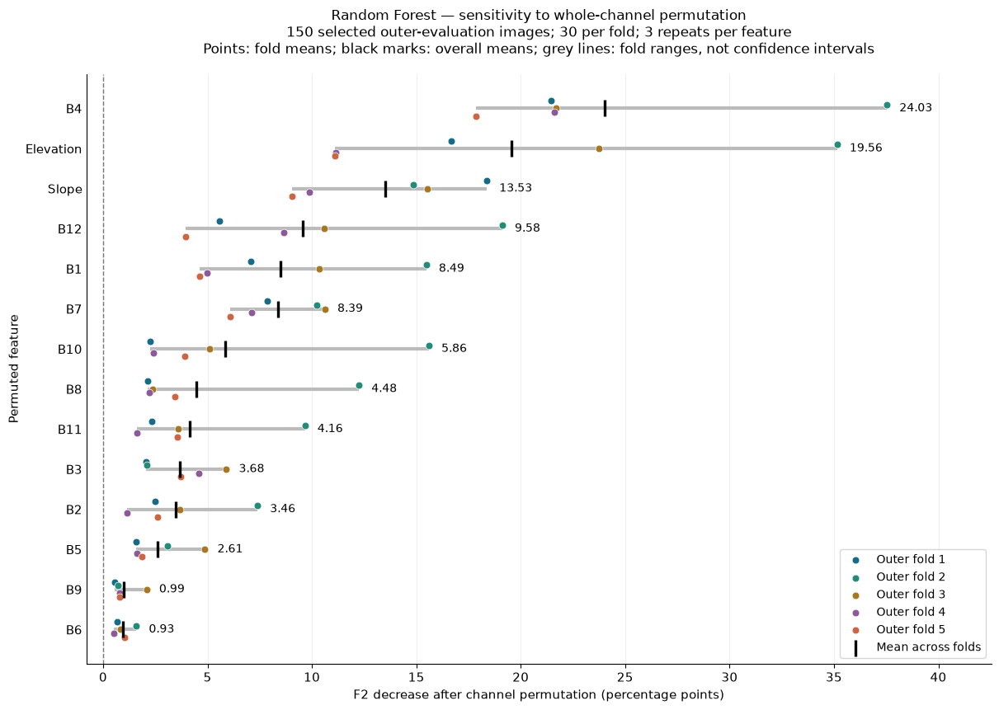

In [104]:
import numpy as np
import matplotlib.pyplot as plt

rf_perm_order = rf_channel_permutation_summary.index.tolist()
rf_perm_plot_summary = rf_channel_permutation_summary.loc[rf_perm_order]
rf_perm_plot_folds = sorted(rf_perm_fold_means["Outer_fold"].unique())

rf_perm_colors = [
    "#176B87", "#238B78", "#A67824", "#8C5A99", "#CB6543"
]
rf_perm_offsets = np.linspace(-0.19, 0.19, len(rf_perm_plot_folds))
rf_perm_y = np.arange(len(rf_perm_order))

with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42
}):
    rf_perm_fig, rf_perm_ax = plt.subplots(
        figsize=(12, 8.5),
        constrained_layout=True
    )

    rf_perm_ax.axvline(
        0, color="#777777", linestyle="--", linewidth=1
    )

    rf_perm_ax.hlines(
        rf_perm_y,
        100 * rf_perm_plot_summary["Minimum_fold_mean"],
        100 * rf_perm_plot_summary["Maximum_fold_mean"],
        color="#BBBBBB", linewidth=3, zorder=1
    )

    for rf_fold, rf_offset, rf_color in zip(
        rf_perm_plot_folds, rf_perm_offsets, rf_perm_colors
    ):
        rf_fold_drops = (
            rf_perm_fold_means.loc[
                rf_perm_fold_means["Outer_fold"] == rf_fold
            ]
            .set_index("Feature")
            .loc[rf_perm_order, "F2_drop"]
            .to_numpy()
        )

        rf_perm_ax.scatter(
            100 * rf_fold_drops,
            rf_perm_y + rf_offset,
            s=40, color=rf_color,
            edgecolor="white", linewidth=0.5,
            label=f"Outer fold {rf_fold}",
            zorder=3
        )

    rf_perm_ax.scatter(
        100 * rf_perm_plot_summary["Mean_F2_drop"],
        rf_perm_y,
        marker="|", s=220, linewidths=2.4,
        color="black", label="Mean across folds", zorder=4
    )

    for rf_y, rf_mean, rf_maximum in zip(
        rf_perm_y,
        rf_perm_plot_summary["Mean_F2_drop"],
        rf_perm_plot_summary["Maximum_fold_mean"]
    ):
        rf_perm_ax.text(
            100 * rf_maximum + 0.6,
            rf_y,
            f"{100 * rf_mean:.2f}",
            va="center", fontsize=10
        )

    rf_perm_min = min(
        0.0,
        float(rf_perm_plot_summary["Minimum_fold_mean"].min()) * 100
    )
    rf_perm_max = (
        float(rf_perm_plot_summary["Maximum_fold_mean"].max()) * 100
    )

    rf_perm_ax.set_xlim(rf_perm_min - 0.8, rf_perm_max + 5)
    rf_perm_ax.set_yticks(rf_perm_y)
    rf_perm_ax.set_yticklabels(rf_perm_order)
    rf_perm_ax.invert_yaxis()

    rf_perm_ax.set_xlabel(
        "F2 decrease after channel permutation (percentage points)"
    )
    rf_perm_ax.set_ylabel("Permuted feature")
    rf_perm_ax.set_title(
        "Random Forest — sensitivity to whole-channel permutation\n"
        "150 selected outer-evaluation images; 30 per fold; "
        "3 repeats per feature\n"
        "Points: fold means; black marks: overall means; "
        "grey lines: fold ranges, not confidence intervals",
        fontsize=12, pad=18
    )

    rf_perm_ax.grid(axis="x", alpha=0.20)
    rf_perm_ax.set_axisbelow(True)
    rf_perm_ax.spines[["top", "right"]].set_visible(False)
    rf_perm_ax.tick_params(axis="y", length=0)

    rf_perm_ax.legend(
        loc="lower right",
        frameon=True, fontsize=10
    )

    for rf_ext in ["png", "pdf"]:
        rf_perm_fig.savefig(
            rf_oof_figures_dir
            / f"outer_subset_channel_permutation_importance.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Rationale: Show model sensitivity to channel perturbation and its variation across outer-fold subsets.
Result: B4, elevation and slope produced the largest mean F2 decreases. Sensitivity varied across folds, particularly for B4 and elevation.

In [105]:
# Inspect restored final-development split objects.
# No new splits, training, or test evaluation.

rf_final_split_names = sorted(
    name for name in globals()
    if "final" in name.lower()
    and "split" in name.lower()
    and not name.startswith("rf_final_split")
)

print("Restored objects related to final splits:")
print(rf_final_split_names)

for rf_name in rf_final_split_names:
    rf_obj = globals()[rf_name]
    print(f"\n{rf_name}: {type(rf_obj).__name__}")

    if isinstance(rf_obj, dict):
        print("Top-level keys:", list(rf_obj.keys())[:15])

    elif isinstance(rf_obj, (list, tuple)):
        print("Number of entries:", len(rf_obj))

        if len(rf_obj) > 0:
            rf_first = rf_obj[0]
            print("First entry type:", type(rf_first).__name__)

            if isinstance(rf_first, dict):
                print("First entry keys:", list(rf_first.keys()))

                for rf_key, rf_value in rf_first.items():
                    if isinstance(
                        rf_value, (list, tuple, np.ndarray, pd.Index)
                    ):
                        print(f"  {rf_key}: {len(rf_value)} entries")
                    elif np.isscalar(rf_value):
                        print(f"  {rf_key}: {rf_value}")

print("\nDevelopment images:", len(dev_ids))
print("Secondary test images:", len(test_ids))

assert len(dev_ids) == 3039
assert len(test_ids) == 760
assert len(set(map(str, dev_ids))) == 3039
assert len(set(map(str, test_ids))) == 760
assert set(map(str, dev_ids)).isdisjoint(set(map(str, test_ids)))

print("Development/test IDs are unique and disjoint.")

Restored objects related to final splits:
['dt_final_calibration_splits', 'dt_final_inner_splits']

dt_final_calibration_splits: list
Number of entries: 3
First entry type: dict
First entry keys: ['inner_fold', 'train_ids', 'fit_ids', 'calibration_ids', 'validation_ids']
  inner_fold: 1
  train_ids: 2026 entries
  fit_ids: 1620 entries
  calibration_ids: 406 entries
  validation_ids: 1013 entries

dt_final_inner_splits: list
Number of entries: 3
First entry type: dict
First entry keys: ['train_ids', 'validation_ids']
  train_ids: 2026 entries
  validation_ids: 1013 entries

Development images: 3039
Secondary test images: 760
Development/test IDs are unique and disjoint.


In [106]:
import copy
from collections import Counter

rf_final_inner_splits = copy.deepcopy(dt_final_inner_splits)
rf_final_calibration_splits = copy.deepcopy(
    dt_final_calibration_splits
)

assert len(rf_final_inner_splits) == 3
assert len(rf_final_calibration_splits) == 3

rf_final_dev_set = set(map(str, dev_ids))
rf_final_test_set = set(map(str, test_ids))


def rf_checked_id_set(values, description):
    ids = list(map(str, values))
    assert len(ids) == len(set(ids)), (
        f"Duplicate IDs: {description}"
    )
    return set(ids)


rf_final_split_audit_rows = []
rf_final_validation_coverage = Counter()

rf_final_calibration_by_fold = {
    int(split["inner_fold"]): split
    for split in rf_final_calibration_splits
}
assert set(rf_final_calibration_by_fold) == {1, 2, 3}

for rf_inner_fold, rf_split in enumerate(
    rf_final_inner_splits, start=1
):
    rf_train = rf_checked_id_set(
        rf_split["train_ids"], f"fold {rf_inner_fold}: training"
    )
    rf_validation = rf_checked_id_set(
        rf_split["validation_ids"],
        f"fold {rf_inner_fold}: validation"
    )

    assert rf_train.isdisjoint(rf_validation)
    assert rf_train | rf_validation == rf_final_dev_set
    assert (rf_train | rf_validation).isdisjoint(
        rf_final_test_set
    )

    rf_cal_split = rf_final_calibration_by_fold[rf_inner_fold]

    rf_cal_train = rf_checked_id_set(
        rf_cal_split["train_ids"],
        f"fold {rf_inner_fold}: calibration training"
    )
    rf_fit = rf_checked_id_set(
        rf_cal_split["fit_ids"], f"fold {rf_inner_fold}: fit"
    )
    rf_calibration = rf_checked_id_set(
        rf_cal_split["calibration_ids"],
        f"fold {rf_inner_fold}: calibration"
    )
    rf_cal_validation = rf_checked_id_set(
        rf_cal_split["validation_ids"],
        f"fold {rf_inner_fold}: calibration validation"
    )

    assert rf_cal_train == rf_train
    assert rf_cal_validation == rf_validation
    assert rf_fit.isdisjoint(rf_calibration)
    assert rf_fit | rf_calibration == rf_train
    assert rf_fit.isdisjoint(rf_validation)
    assert rf_calibration.isdisjoint(rf_validation)

    rf_final_validation_coverage.update(rf_validation)

    rf_final_split_audit_rows.append({
        "Inner_fold": rf_inner_fold,
        "Training_images": len(rf_train),
        "Fit_images": len(rf_fit),
        "Calibration_images": len(rf_calibration),
        "Validation_images": len(rf_validation),
        "Disjoint_groups": True,
        "No_test_images": True
    })

assert set(rf_final_validation_coverage) == rf_final_dev_set
assert all(
    count == 1
    for count in rf_final_validation_coverage.values()
)

rf_final_split_audit = pd.DataFrame(rf_final_split_audit_rows)

rf_final_selection_dir = (
    rf_checkpoint_dir / "final_development_selection"
)
rf_final_selection_dir.mkdir(parents=True, exist_ok=True)

rf_final_split_audit.to_csv(
    rf_final_selection_dir / "split_audit.csv",
    index=False
)

joblib.dump(
    {
        "inner_splits": rf_final_inner_splits,
        "calibration_splits": rf_final_calibration_splits,
        "development_ids": list(map(str, dev_ids)),
        "secondary_test_ids": list(map(str, test_ids)),
        "audit": rf_final_split_audit
    },
    rf_final_selection_dir / "validated_splits.joblib"
)

display(rf_final_split_audit)
print(
    "Passed: every development image appears in validation "
    "exactly once across the three splits."
)
print("Passed: no secondary-test images enter these splits.")

,Inner_fold,Training_images,Fit_images,Calibration_images,Validation_images,Disjoint_groups,No_test_images
0,1,2026,1620,406,1013,True,True
1,2,2026,1620,406,1013,True,True
2,3,2026,1620,406,1013,True,True


Passed: every development image appears in validation exactly once across the three splits.
Passed: no secondary-test images enter these splits.


In [107]:
import inspect

rf_final_required_helpers = [
    "rf_fit_search_inner_split",
    "rf_evaluate_search_inner_split",
    "rf_select_initial_candidates",
    "rf_prepare_tree_count_check"
]

for rf_helper_name in rf_final_required_helpers:
    assert rf_helper_name in globals(), (
        f"Required helper is missing: {rf_helper_name}"
    )
    print(f"\n{rf_helper_name}")
    print(inspect.signature(globals()[rf_helper_name]))

print("\nExisting candidate objects:")

rf_final_candidate_names = sorted(
    name for name in globals()
    if name.startswith("rf_")
    and "candidate" in name.lower()
    and isinstance(globals()[name], (list, tuple, dict, pd.DataFrame))
)

for rf_object_name in rf_final_candidate_names:
    rf_object = globals()[rf_object_name]
    print(
        rf_object_name,
        "| type:", type(rf_object).__name__,
        "| length:", len(rf_object)
    )

    if isinstance(rf_object, (list, tuple)) and len(rf_object):
        print("First entry:", rf_object[0])
    elif isinstance(rf_object, pd.DataFrame):
        print("Columns:", rf_object.columns.tolist())
    elif isinstance(rf_object, dict):
        print("First keys:", list(rf_object.keys())[:8])


rf_fit_search_inner_split
(outer_split, inner_position, candidates, sampled_ids, X_samples, y_samples, feature_names, checkpoint_root)

rf_evaluate_search_inner_split
(outer_split, inner_position, model_records, data_dir, thresholds, beta, reference_threshold, log_loss_epsilon, feature_names, chunk_size=25)

rf_select_initial_candidates
(outer_split, threshold_tables_by_inner, validation_tables_by_inner, candidates, threshold_grid, reference_threshold, tolerance, output_dir)

rf_prepare_tree_count_check
(outer_split, initial_selection, source_records_by_inner, sampled_ids, X_samples, y_samples, checkpoint_root)

Existing candidate objects:
rf_candidate | type: dict | length: 13
First keys: ['n_estimators', 'bootstrap', 'ccp_alpha', 'oob_score', 'random_state', 'n_jobs', 'min_samples_split', 'min_samples_leaf']
rf_candidate_colors | type: dict | length: 8
First keys: [1, 2, 3, 4, 5, 6, 7, 8]
rf_candidate_metrics | type: dict | length: 20
First keys: ['Threshold', 'Pixels', 'Positive_pi

In [108]:
import inspect

for rf_helper_name in [
    "rf_fit_search_inner_split",
    "rf_evaluate_search_inner_split"
]:
    rf_source_lines = inspect.getsource(
        globals()[rf_helper_name]
    ).splitlines()

    rf_lines_to_show = set()

    for rf_line_number, rf_line in enumerate(rf_source_lines):
        if any(
            text in rf_line
            for text in [
                "inner_position",
                '["inner_splits"]',
                "['inner_splits']",
                "return "
            ]
        ):
            rf_lines_to_show.update(
                range(
                    max(0, rf_line_number - 1),
                    min(len(rf_source_lines), rf_line_number + 3)
                )
            )

    print(f"\n--- {rf_helper_name} ---")
    for rf_line_number in sorted(rf_lines_to_show):
        print(
            f"{rf_line_number + 1}: "
            f"{rf_source_lines[rf_line_number]}"
        )


--- rf_fit_search_inner_split ---
2:     outer_split,
3:     inner_position,
4:     candidates,
5:     sampled_ids,
12:     outer_number = int(outer_split["outer_fold"])
13:     inner_number = inner_position + 1
14:     inner_split = outer_split["inner_splits"][inner_position]
15: 
16:     training_ids = np.asarray(inner_split["train_ids"]).astype(str)
156: 
157:     return model_records, fitting_table

--- rf_evaluate_search_inner_split ---
2:     outer_split,
3:     inner_position,
4:     model_records,
5:     data_dir,
14:     outer_number = int(outer_split["outer_fold"])
15:     inner_number = inner_position + 1
16:     inner_split = outer_split["inner_splits"][inner_position]
17: 
18:     training_ids = np.asarray(inner_split["train_ids"]).astype(str).tolist()
299: 
300:     return summary, threshold_tables


In [109]:
# Final development-only selection: initial search, inner split 1.
# Reuse the original eight candidates and sampled training arrays.

import copy
import time

assert len(rf_search_candidates) == 8

rf_final_candidates = copy.deepcopy(rf_search_candidates)

# Adapter for the existing helpers.
# Fold number 0 is only a separate checkpoint identifier.
# This is NOT an additional outer evaluation fold.
rf_final_search_context = {
    "outer_fold": 0,
    "train_ids": list(map(str, dev_ids)),
    "evaluation_ids": [],
    "inner_splits": copy.deepcopy(rf_final_inner_splits)
}

rf_final_search_checkpoint_root = (
    rf_final_selection_dir / "search_checkpoints"
)
rf_final_search_checkpoint_root.mkdir(
    parents=True, exist_ok=True
)

if "rf_final_search_records_by_inner" not in globals():
    rf_final_search_records_by_inner = {}

if "rf_final_search_fit_tables" not in globals():
    rf_final_search_fit_tables = {}

rf_final_fit_start = time.perf_counter()

(
    rf_final_inner1_records,
    rf_final_inner1_fit_table
) = rf_fit_search_inner_split(
    outer_split=rf_final_search_context,
    inner_position=0,
    candidates=rf_final_candidates,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    checkpoint_root=rf_final_search_checkpoint_root
)

rf_final_search_records_by_inner[1] = rf_final_inner1_records
rf_final_search_fit_tables[1] = rf_final_inner1_fit_table

joblib.dump(
    {
        "role": "final_development_initial_search",
        "context": rf_final_search_context,
        "candidates": rf_final_candidates,
        "records_by_inner": rf_final_search_records_by_inner,
        "fit_tables": rf_final_search_fit_tables
    },
    rf_final_selection_dir / "initial_search_progress.joblib"
)

display(rf_final_inner1_fit_table)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_fit_start) / 60, 2),
    "minutes"
)
print("Completed: initial search training for inner split 1.")
print("No secondary-test images were used.")

Outer fold 0 / inner split 1
Training images: 2026
Validation images, excluded from fitting: 1013
Training table: (2074624, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 133.60 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 99.45 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 117.53 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 151.95 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 151.39 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 133.54 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 186.55 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 192.27 seconds


,Candidate,Trees,Original_fit_seconds,Status
0,1,100,133.596385,New model fitted
1,2,100,99.448951,New model fitted
2,3,100,117.529418,New model fitted
3,4,100,151.953324,New model fitted
4,5,100,151.392815,New model fitted
5,6,100,133.540890,New model fitted
6,7,100,186.545642,New model fitted
7,8,100,192.269728,New model fitted


Elapsed time: 19.45 minutes
Completed: initial search training for inner split 1.
No secondary-test images were used.


Rationale: Fit the original eight candidates for the first inner split of final development-only selection.
Result: All eight 100-tree forests were fitted successfully; total elapsed time was 19.45 minutes. Validation performance is not yet available.

In [110]:
# Final development selection: evaluate initial candidates,
# inner validation split 1.

import time

if "rf_final_search_validation_by_inner" not in globals():
    rf_final_search_validation_by_inner = {}

if "rf_final_search_thresholds_by_inner" not in globals():
    rf_final_search_thresholds_by_inner = {}

rf_final_validation_start = time.perf_counter()

(
    rf_final_inner1_validation,
    rf_final_inner1_threshold_tables
) = rf_evaluate_search_inner_split(
    outer_split=rf_final_search_context,
    inner_position=0,
    model_records=rf_final_inner1_records,
    data_dir=DATA_DIR,
    thresholds=THRESHOLDS,
    beta=BETA,
    reference_threshold=0.50,
    log_loss_epsilon=np.finfo(np.float64).eps,
    feature_names=FEATURE_NAMES,
    chunk_size=25
)

rf_final_search_validation_by_inner[1] = (
    rf_final_inner1_validation
)
rf_final_search_thresholds_by_inner[1] = (
    rf_final_inner1_threshold_tables
)

joblib.dump(
    {
        "role": "final_development_initial_search",
        "context": rf_final_search_context,
        "candidates": rf_final_candidates,
        "records_by_inner": rf_final_search_records_by_inner,
        "fit_tables": rf_final_search_fit_tables,
        "validation_by_inner": rf_final_search_validation_by_inner,
        "threshold_tables_by_inner":
            rf_final_search_thresholds_by_inner
    },
    rf_final_selection_dir / "initial_search_progress.joblib"
)

display(rf_final_inner1_validation)

print(
    "Evaluation elapsed time:",
    round((time.perf_counter() - rf_final_validation_start) / 60, 2),
    "minutes"
)
print("Completed: inner validation split 1.")
print("Reference threshold in the summary: 0.50.")
print("Full threshold-grid results are retained for later selection.")

Outer fold 0 / inner validation 1
Images: 1013; pixels: 16,596,992

Candidate 1/8
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150

,Candidate,Threshold,Pixels,Positive_pixels,Predicted_positive_pixels,TN,FP,FN,TP,F2,...,Accuracy,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max,Fit_seconds,Prediction_seconds,Evaluation_path
0,1,0.5,16596992,397265,295395,16143446,56281,158151,239114,0.634438,...,0.987080,0.988249,0.786463,0.009714,0.034905,0.0,1.000000,133.596385,61.902881,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
1,2,0.5,16596992,397265,731179,15821806,377921,44007,353258,0.761253,...,0.974578,0.988717,0.777405,0.018897,0.065947,0.0,0.999626,99.448951,61.664064,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
2,3,0.5,16596992,397265,605603,15925741,273986,65648,331617,0.755508,...,0.979536,0.986161,0.764961,0.014977,0.054035,0.0,0.998742,117.529418,54.841077,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
3,4,0.5,16596992,397265,1080199,15495508,704219,21285,375980,0.704278,...,0.956287,0.988641,0.763794,0.032839,0.113330,0.0,0.995997,151.953324,43.919814,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
4,5,0.5,16596992,397265,705994,15847170,352557,43828,353437,0.769997,...,0.976117,0.988877,0.785217,0.017526,0.062264,0.0,1.000000,151.392815,50.549385,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
5,6,0.5,16596992,397265,293534,16144180,55547,159278,237987,0.632072,...,0.987056,0.988362,0.786113,0.009728,0.034864,0.0,1.000000,133.540890,60.246797,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
6,7,0.5,16596992,397265,291385,16144766,54961,160841,236424,0.628638,...,0.986998,0.988782,0.786900,0.009736,0.034593,0.0,1.000000,186.545642,61.399832,C:\Users\hadid\Ramen\ds-ml-project-template\ar...
7,8,0.5,16596992,397265,310352,16137256,62471,149384,247881,0.652520,...,0.987235,0.987193,0.792781,0.009531,0.038501,0.0,1.000000,192.269728,46.958611,C:\Users\hadid\Ramen\ds-ml-project-template\ar...


Evaluation elapsed time: 9.98 minutes
Completed: inner validation split 1.
Reference threshold in the summary: 0.50.
Full threshold-grid results are retained for later selection.


Rationale: Evaluate all eight candidates on full-image inner-validation data.
Result: Candidate 5 achieved the highest F2 at the reference threshold of 0.50. Candidate 8 achieved the highest ROC-AUC and average precision, and the lowest Brier score. Final selection remains pending all three splits and threshold tuning.

In [111]:
# Final development selection: initial search, inner split 2.

import time

rf_final_fit_start = time.perf_counter()

(
    rf_final_inner2_records,
    rf_final_inner2_fit_table
) = rf_fit_search_inner_split(
    outer_split=rf_final_search_context,
    inner_position=1,  # Second split: zero-based indexing
    candidates=rf_final_candidates,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    checkpoint_root=rf_final_search_checkpoint_root
)

rf_final_search_records_by_inner[2] = rf_final_inner2_records
rf_final_search_fit_tables[2] = rf_final_inner2_fit_table

joblib.dump(
    {
        "role": "final_development_initial_search",
        "context": rf_final_search_context,
        "candidates": rf_final_candidates,
        "records_by_inner": rf_final_search_records_by_inner,
        "fit_tables": rf_final_search_fit_tables,
        "validation_by_inner": rf_final_search_validation_by_inner,
        "threshold_tables_by_inner":
            rf_final_search_thresholds_by_inner
    },
    rf_final_selection_dir / "initial_search_progress.joblib"
)

display(rf_final_inner2_fit_table)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_fit_start) / 60, 2),
    "minutes"
)
print("Completed: initial search training for inner split 2.")
print("No secondary-test images were used.")

Outer fold 0 / inner split 2
Training images: 2026
Validation images, excluded from fitting: 1013
Training table: (2074624, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 133.92 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 98.48 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 117.83 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 151.35 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 151.75 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 130.50 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 184.00 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 192.82 seconds


,Candidate,Trees,Original_fit_seconds,Status
0,1,100,133.918942,New model fitted
1,2,100,98.475628,New model fitted
2,3,100,117.828096,New model fitted
3,4,100,151.353957,New model fitted
4,5,100,151.748332,New model fitted
5,6,100,130.501871,New model fitted
6,7,100,183.996624,New model fitted
7,8,100,192.816609,New model fitted


Elapsed time: 19.36 minutes
Completed: initial search training for inner split 2.
No secondary-test images were used.


In [112]:
# Final development selection: inner validation split 2.

import time

rf_final_validation_start = time.perf_counter()

(
    rf_final_inner2_validation,
    rf_final_inner2_threshold_tables
) = rf_evaluate_search_inner_split(
    outer_split=rf_final_search_context,
    inner_position=1,
    model_records=rf_final_inner2_records,
    data_dir=DATA_DIR,
    thresholds=THRESHOLDS,
    beta=BETA,
    reference_threshold=0.50,
    log_loss_epsilon=np.finfo(np.float64).eps,
    feature_names=FEATURE_NAMES,
    chunk_size=25
)

rf_final_search_validation_by_inner[2] = (
    rf_final_inner2_validation
)
rf_final_search_thresholds_by_inner[2] = (
    rf_final_inner2_threshold_tables
)

joblib.dump(
    {
        "role": "final_development_initial_search",
        "context": rf_final_search_context,
        "candidates": rf_final_candidates,
        "records_by_inner": rf_final_search_records_by_inner,
        "fit_tables": rf_final_search_fit_tables,
        "validation_by_inner": rf_final_search_validation_by_inner,
        "threshold_tables_by_inner":
            rf_final_search_thresholds_by_inner
    },
    rf_final_selection_dir / "initial_search_progress.joblib"
)

# Compact display; the complete result remains saved.
rf_final_display_columns = [
    "Candidate", "Threshold", "Pixels", "Positive_pixels",
    "F2", "ROC_AUC", "Average_precision",
    "Brier_score", "Log_loss"
]

display(
    rf_final_inner2_validation[
        rf_final_display_columns
    ].round(6)
)

print(
    "Evaluation elapsed time:",
    round((time.perf_counter() - rf_final_validation_start) / 60, 2),
    "minutes"
)
print("Completed: inner validation split 2.")
print("Summary threshold: 0.50; full threshold grid retained.")
print("No secondary-test images were used.")

Outer fold 0 / inner validation 2
Images: 1013; pixels: 16,596,992

Candidate 1/8
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150

,Candidate,Threshold,Pixels,Positive_pixels,F2,ROC_AUC,Average_precision,Brier_score,Log_loss
0,1,0.5,16596992,404827,0.636074,0.988728,0.783388,0.009955,0.035384
1,2,0.5,16596992,404827,0.760694,0.988975,0.765864,0.019869,0.069788
2,3,0.5,16596992,404827,0.754301,0.986649,0.750550,0.015955,0.056710
3,4,0.5,16596992,404827,0.704428,0.988715,0.746055,0.034185,0.119062
4,5,0.5,16596992,404827,0.769173,0.989356,0.774616,0.018240,0.064196
5,6,0.5,16596992,404827,0.633083,0.988745,0.782596,0.009987,0.035442
6,7,0.5,16596992,404827,0.628998,0.989157,0.782855,0.010006,0.035218
7,8,0.5,16596992,404827,0.652509,0.988221,0.789765,0.009776,0.037660


Evaluation elapsed time: 9.99 minutes
Completed: inner validation split 2.
Summary threshold: 0.50; full threshold grid retained.
No secondary-test images were used.


Rationale: Evaluate the eight candidates on the second full-image inner-validation split.
Result: Candidate 5 led F2 at threshold 0.50 and ROC-AUC; candidate 8 led average precision. Evaluation took 9.99 minutes.

In [113]:
# Final development selection: initial search, inner split 3.

import time

rf_final_fit_start = time.perf_counter()

(
    rf_final_inner3_records,
    rf_final_inner3_fit_table
) = rf_fit_search_inner_split(
    outer_split=rf_final_search_context,
    inner_position=2,  # Third split: zero-based indexing
    candidates=rf_final_candidates,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    checkpoint_root=rf_final_search_checkpoint_root
)

rf_final_search_records_by_inner[3] = rf_final_inner3_records
rf_final_search_fit_tables[3] = rf_final_inner3_fit_table

joblib.dump(
    {
        "role": "final_development_initial_search",
        "context": rf_final_search_context,
        "candidates": rf_final_candidates,
        "records_by_inner": rf_final_search_records_by_inner,
        "fit_tables": rf_final_search_fit_tables,
        "validation_by_inner": rf_final_search_validation_by_inner,
        "threshold_tables_by_inner":
            rf_final_search_thresholds_by_inner
    },
    rf_final_selection_dir / "initial_search_progress.joblib"
)

display(rf_final_inner3_fit_table)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_fit_start) / 60, 2),
    "minutes"
)
print("Completed: initial search training for inner split 3.")
print("No secondary-test images were used.")

Outer fold 0 / inner split 3
Training images: 2026
Validation images, excluded from fitting: 1013
Training table: (2074624, 14)

Candidate 1/8
Fitting...
New model fitted; original fitting time: 254.07 seconds

Candidate 2/8
Fitting...
New model fitted; original fitting time: 97.33 seconds

Candidate 3/8
Fitting...
New model fitted; original fitting time: 115.99 seconds

Candidate 4/8
Fitting...
New model fitted; original fitting time: 151.69 seconds

Candidate 5/8
Fitting...
New model fitted; original fitting time: 152.68 seconds

Candidate 6/8
Fitting...
New model fitted; original fitting time: 131.45 seconds

Candidate 7/8
Fitting...
New model fitted; original fitting time: 183.23 seconds

Candidate 8/8
Fitting...
New model fitted; original fitting time: 191.26 seconds


,Candidate,Trees,Original_fit_seconds,Status
0,1,100,254.072166,New model fitted
1,2,100,97.330465,New model fitted
2,3,100,115.990635,New model fitted
3,4,100,151.691389,New model fitted
4,5,100,152.684668,New model fitted
5,6,100,131.449670,New model fitted
6,7,100,183.229747,New model fitted
7,8,100,191.259594,New model fitted


Elapsed time: 21.31 minutes
Completed: initial search training for inner split 3.
No secondary-test images were used.


In [114]:
# Final development selection: inner validation split 3.

import time

rf_final_validation_start = time.perf_counter()

(
    rf_final_inner3_validation,
    rf_final_inner3_threshold_tables
) = rf_evaluate_search_inner_split(
    outer_split=rf_final_search_context,
    inner_position=2,
    model_records=rf_final_inner3_records,
    data_dir=DATA_DIR,
    thresholds=THRESHOLDS,
    beta=BETA,
    reference_threshold=0.50,
    log_loss_epsilon=np.finfo(np.float64).eps,
    feature_names=FEATURE_NAMES,
    chunk_size=25
)

rf_final_search_validation_by_inner[3] = (
    rf_final_inner3_validation
)
rf_final_search_thresholds_by_inner[3] = (
    rf_final_inner3_threshold_tables
)

assert set(rf_final_search_records_by_inner) == {1, 2, 3}
assert set(rf_final_search_validation_by_inner) == {1, 2, 3}
assert set(rf_final_search_thresholds_by_inner) == {1, 2, 3}

joblib.dump(
    {
        "role": "final_development_initial_search",
        "context": rf_final_search_context,
        "candidates": rf_final_candidates,
        "records_by_inner": rf_final_search_records_by_inner,
        "fit_tables": rf_final_search_fit_tables,
        "validation_by_inner": rf_final_search_validation_by_inner,
        "threshold_tables_by_inner":
            rf_final_search_thresholds_by_inner
    },
    rf_final_selection_dir / "initial_search_progress.joblib"
)

rf_final_display_columns = [
    "Candidate", "Threshold", "Pixels", "Positive_pixels",
    "F2", "ROC_AUC", "Average_precision",
    "Brier_score", "Log_loss"
]

display(
    rf_final_inner3_validation[
        rf_final_display_columns
    ].round(6)
)

print(
    "Evaluation elapsed time:",
    round((time.perf_counter() - rf_final_validation_start) / 60, 2),
    "minutes"
)
print("Completed: inner validation split 3.")
print("Summary threshold: 0.50; full threshold grid retained.")
print("All three inner-validation results are now available.")
print("No secondary-test images were used.")

Outer fold 0 / inner validation 3
Images: 1013; pixels: 16,596,992

Candidate 1/8
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Candidate 2/8
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150

,Candidate,Threshold,Pixels,Positive_pixels,F2,ROC_AUC,Average_precision,Brier_score,Log_loss
0,1,0.5,16596992,375317,0.645865,0.990386,0.800012,0.008891,0.031630
1,2,0.5,16596992,375317,0.767477,0.990389,0.783390,0.018098,0.063558
2,3,0.5,16596992,375317,0.764349,0.988528,0.768567,0.014279,0.050491
3,4,0.5,16596992,375317,0.706462,0.990317,0.771539,0.031737,0.110628
4,5,0.5,16596992,375317,0.775821,0.990722,0.791574,0.016798,0.058925
5,6,0.5,16596992,375317,0.642956,0.990420,0.799758,0.008913,0.031665
6,7,0.5,16596992,375317,0.638984,0.990771,0.799996,0.008931,0.031520
7,8,0.5,16596992,375317,0.664445,0.989948,0.806067,0.008718,0.033268


Evaluation elapsed time: 9.96 minutes
Completed: inner validation split 3.
Summary threshold: 0.50; full threshold grid retained.
All three inner-validation results are now available.
No secondary-test images were used.


In [115]:
# Aggregate the three inner-validation splits and select
# the initial candidate + threshold using the existing rules.

assert set(rf_final_search_thresholds_by_inner) == {1, 2, 3}
assert set(rf_final_search_validation_by_inner) == {1, 2, 3}
assert len(rf_final_candidates) == 8

rf_final_initial_selection = rf_select_initial_candidates(
    outer_split=rf_final_search_context,
    threshold_tables_by_inner=rf_final_search_thresholds_by_inner,
    validation_tables_by_inner=rf_final_search_validation_by_inner,
    candidates=rf_final_candidates,
    threshold_grid=THRESHOLDS,
    reference_threshold=0.50,
    tolerance=1e-12,
    output_dir=rf_final_selection_dir / "initial_selection"
)

joblib.dump(
    {
        "role": "final_development_initial_selection",
        "selection": rf_final_initial_selection,
        "candidates": rf_final_candidates,
        "inner_splits": rf_final_inner_splits
    },
    rf_final_selection_dir / "initial_selection_result.joblib"
)

# Show the actual structure returned by the existing helper.
print("Returned object:", type(rf_final_initial_selection).__name__)

if isinstance(rf_final_initial_selection, dict):
    for rf_key, rf_value in rf_final_initial_selection.items():
        print(f"\n{rf_key}:")

        if isinstance(rf_value, pd.DataFrame):
            display(rf_value.round(6).head(12))
        elif isinstance(rf_value, pd.Series):
            display(rf_value)
        else:
            print(rf_value)
else:
    display(rf_final_initial_selection)

print("\nSelection used development inner-validation results only.")
print("No secondary-test images were used.")

Returned object: dict

role:
outer_0_initial_uncalibrated_inner_selection

candidate:
8

params:
{'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_samples': 0.5, 'max_features': 0.5, 'max_depth': 20, 'criterion': 'entropy', 'class_weight': None}

threshold:
0.17

ranking:


,Candidate,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_F2_at_050,F2_change_from_050,min_samples_leaf,max_depth,Rank
0,8,0.17,3.0,0.775060,0.005814,0.546864,0.865344,0.982626,0.503983,0.656492,0.118568,1.0,20.0,1
1,5,0.57,3.0,0.774601,0.004474,0.535983,0.871631,0.981722,0.496763,0.771664,0.002938,1.0,20.0,2
2,7,0.17,3.0,0.769022,0.005934,0.544287,0.857587,0.982596,0.499156,0.632207,0.136815,10.0,20.0,3
3,1,0.17,3.0,0.768875,0.005949,0.542931,0.858191,0.982491,0.498224,0.638792,0.130082,2.0,20.0,4
4,6,0.17,3.0,0.768180,0.006056,0.541557,0.857970,0.982398,0.496993,0.636037,0.132143,2.0,20.0,5
5,2,0.60,3.0,0.767176,0.004381,0.529760,0.863994,0.981421,0.488977,0.763142,0.004034,2.0,20.0,6
6,4,0.81,3.0,0.762278,0.005414,0.514167,0.866858,0.980156,0.476543,0.705056,0.057222,10.0,12.0,7
7,3,0.45,3.0,0.759210,0.005121,0.519858,0.857999,0.980800,0.478665,0.758052,0.001158,2.0,20.0,8



threshold_summary:


,Candidate,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU
0,1,0.001,3,0.377260,0.012767,0.108404,0.994041,0.801849,0.108332
1,1,0.005,3,0.436451,0.008084,0.134929,0.989377,0.846343,0.134732
2,1,0.010,3,0.523242,0.004560,0.182157,0.983916,0.893006,0.181613
3,1,0.020,3,0.606673,0.001760,0.241773,0.974325,0.925988,0.240240
4,1,0.030,3,0.650752,0.002940,0.282356,0.965791,0.940534,0.279559
5,1,0.040,3,0.679893,0.003928,0.314801,0.957540,0.949503,0.310467
6,1,0.050,3,0.700881,0.004449,0.342404,0.949393,0.955820,0.336268
7,1,0.060,3,0.716760,0.004705,0.366714,0.941449,0.960604,0.358538
8,1,0.070,3,0.729193,0.005051,0.388694,0.933704,0.964415,0.378255
9,1,0.080,3,0.738815,0.005259,0.408542,0.925991,0.967512,0.395624



threshold_detail:


,Candidate,Inner_split,Threshold,TN,FP,FN,TP,F2,Precision,Recall,Specificity,IoU
0,1,1,0.001,13116861,3082866,2941,394324,0.389168,0.113403,0.992597,0.809696,0.113307
1,1,1,0.005,13776139,2423588,5113,392152,0.445142,0.139271,0.987129,0.850393,0.139019
2,1,1,0.010,14492012,1707715,7675,389590,0.528420,0.185757,0.980680,0.894584,0.185080
3,1,1,0.020,15003294,1196433,11853,385412,0.607732,0.243647,0.970163,0.926145,0.241835
4,1,1,0.030,15233476,966251,15503,381762,0.649902,0.283204,0.960976,0.940354,0.279984
5,1,1,0.040,15377869,821858,18965,378300,0.678147,0.315208,0.952261,0.949267,0.310305
6,1,1,0.050,15481289,718438,22387,374878,0.698780,0.342882,0.943647,0.955651,0.336002
7,1,1,0.060,15559738,639989,25651,371614,0.714460,0.367352,0.935431,0.960494,0.358267
8,1,1,0.070,15621858,577869,28870,368395,0.726524,0.389315,0.927328,0.964328,0.377789
9,1,1,0.080,15672670,527057,32082,365183,0.735870,0.409288,0.919243,0.967465,0.395082



selected_threshold_fold_results:


,Candidate,Inner_split,Threshold,TN,FP,FN,TP,F2,Precision,Recall,Specificity,IoU
0,1,1,0.17,15918224,281503,59750,337515,0.764273,0.545243,0.849597,0.982623,0.497246
1,1,2,0.17,15890570,301595,56898,347929,0.766758,0.535668,0.859451,0.981374,0.492523
2,1,3,0.17,15953609,268066,50471,324846,0.775592,0.547882,0.865524,0.983475,0.504903
3,2,1,0.60,15900811,298916,56245,341020,0.764963,0.532897,0.858419,0.981548,0.489844
4,2,2,0.60,15876101,316064,55581,349246,0.764342,0.524937,0.862704,0.980480,0.484464
5,2,3,0.60,15933506,288169,48469,326848,0.772221,0.531445,0.870859,0.982236,0.492622
6,3,1,0.45,15892419,307308,58966,338299,0.756934,0.524001,0.851570,0.981030,0.480148
7,3,2,0.45,15863296,328869,57995,346832,0.755622,0.513292,0.856741,0.979690,0.472719
8,3,3,0.45,15924489,297186,50411,324906,0.765075,0.522280,0.865684,0.981680,0.483129
9,4,1,0.81,15875882,323845,54856,342409,0.759116,0.513932,0.861916,0.980009,0.474836



candidate_settings:
[{'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_samples': 0.5, 'criterion': 'gini', 'class_weight': None}, {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_samples': 0.5, 'criterion': 'gini', 'class_weight': 'balanced'}, {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_samples': 0.5, 'criterion': 'gini', 'class_weight': 'balanced_subsample'}, {'n_estimators': 100, 'bootstrap': True, 'ccp_alpha': 0.0, 'oob_score': False, 'random_state': 43, 'n_jobs': 2, 'min_samples_split': 2, 'min_samples_leaf': 10, 'max

Rationale: Jointly select the candidate and threshold using mean F2 across three development-only inner splits.
Result: Candidate 8 at threshold 0.17 achieved mean F2 = 0.775060 (SD = 0.005814), narrowly exceeding candidate 5 by 0.000459. This is a selection score, not an independent performance estimate.

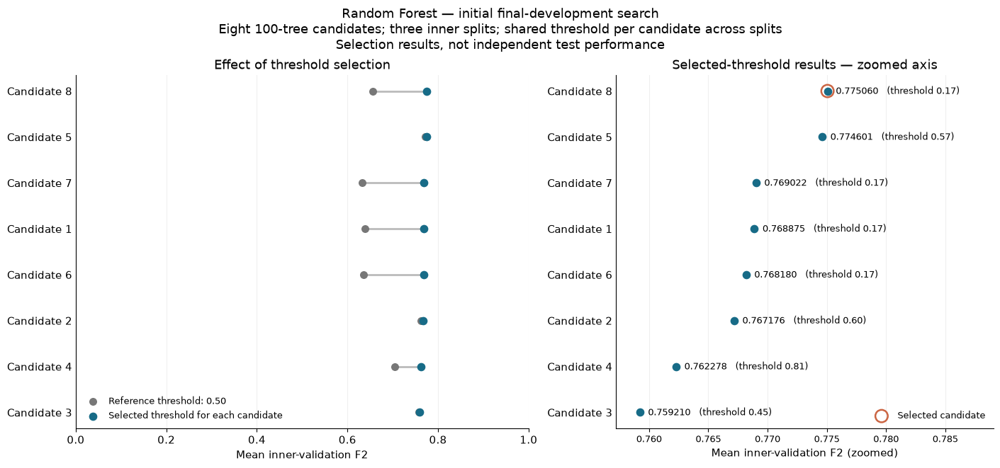

In [116]:
import numpy as np
import matplotlib.pyplot as plt

# Find the returned candidate summary by its columns.
rf_final_summary_matches = [
    value
    for value in rf_final_initial_selection.values()
    if isinstance(value, pd.DataFrame)
    and {
        "Candidate", "Threshold", "Mean_F2",
        "Mean_F2_at_050", "Rank"
    }.issubset(value.columns)
]

assert len(rf_final_summary_matches) == 1
rf_final_candidate_summary = (
    rf_final_summary_matches[0]
    .sort_values("Rank")
    .copy()
)

rf_search_y = np.arange(len(rf_final_candidate_summary))
rf_search_reference = (
    rf_final_candidate_summary["Mean_F2_at_050"].to_numpy()
)
rf_search_tuned = rf_final_candidate_summary["Mean_F2"].to_numpy()

rf_search_labels = [
    f"Candidate {int(row.Candidate)}"
    for row in rf_final_candidate_summary.itertuples()
]

with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42
}):
    rf_search_fig, rf_search_axes = plt.subplots(
        1, 2, figsize=(14, 6.5),
        gridspec_kw={"width_ratios": [1.2, 1]},
        constrained_layout=True
    )

    rf_ax = rf_search_axes[0]
    rf_ax.hlines(
        rf_search_y, rf_search_reference, rf_search_tuned,
        color="#BBBBBB", linewidth=2
    )
    rf_ax.scatter(
        rf_search_reference, rf_search_y,
        color="#777777", s=48,
        label="Reference threshold: 0.50", zorder=3
    )
    rf_ax.scatter(
        rf_search_tuned, rf_search_y,
        color="#176B87", s=55,
        label="Selected threshold for each candidate", zorder=4
    )
    rf_ax.set_xlim(0, 1)
    rf_ax.set_title("Effect of threshold selection")
    rf_ax.set_xlabel("Mean inner-validation F2")
    rf_ax.set_yticks(rf_search_y)
    rf_ax.set_yticklabels(rf_search_labels)
    rf_ax.invert_yaxis()
    rf_ax.legend(
        loc="lower left", frameon=False, fontsize=9
    )

    rf_ax = rf_search_axes[1]
    rf_ax.scatter(
        rf_search_tuned, rf_search_y,
        color="#176B87", s=55, zorder=3
    )
    rf_ax.scatter(
        rf_search_tuned[0], rf_search_y[0],
        facecolors="none", edgecolors="#CB6543",
        s=160, linewidths=1.8,
        label="Selected candidate", zorder=4
    )

    for rf_y, rf_row in zip(
        rf_search_y, rf_final_candidate_summary.itertuples()
    ):
        rf_ax.text(
            rf_row.Mean_F2 + 0.0007,
            rf_y,
            f"{rf_row.Mean_F2:.6f}   "
            f"(threshold {rf_row.Threshold:.2f})",
            va="center", fontsize=9
        )

    rf_ax.set_xlim(
        float(rf_search_tuned.min()) - 0.002,
        float(rf_search_tuned.max()) + 0.014
    )
    rf_ax.set_yticks(rf_search_y)
    rf_ax.set_yticklabels(rf_search_labels)
    rf_ax.invert_yaxis()
    rf_ax.set_title("Selected-threshold results — zoomed axis")
    rf_ax.set_xlabel("Mean inner-validation F2 (zoomed)")
    rf_ax.tick_params(axis="x", labelsize=9)
    rf_ax.legend(loc="lower right", frameon=False, fontsize=9)

    for rf_ax in rf_search_axes:
        rf_ax.set_axisbelow(True)
        rf_ax.grid(axis="x", alpha=0.20)
        rf_ax.spines[["top", "right"]].set_visible(False)
        rf_ax.tick_params(axis="y", length=0)

    rf_search_fig.suptitle(
        "Random Forest — initial final-development search\n"
        "Eight 100-tree candidates; three inner splits; "
        "shared threshold per candidate across splits\n"
        "Selection results, not independent test performance",
        fontsize=13
    )

    for rf_ext in ["png", "pdf"]:
        rf_search_fig.savefig(
            rf_oof_figures_dir
            / f"final_development_initial_candidate_comparison.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Rationale: Compare reference-threshold and selected-threshold performance across candidates.
Result: Threshold selection substantially improved several candidates. Candidate 8 ranked first, narrowly ahead of candidate 5. These are development-selection results, not test results.

In [117]:
# Final development selection: prepare tree-count comparison.
# Reuse the selected candidate's existing 100-tree models.

import time

rf_final_tree_start = time.perf_counter()

(
    rf_final_tree_records_by_inner,
    rf_final_tree_fit_table,
    rf_final_tree_root
) = rf_prepare_tree_count_check(
    outer_split=rf_final_search_context,
    initial_selection=rf_final_initial_selection,
    source_records_by_inner=rf_final_search_records_by_inner,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    checkpoint_root=rf_final_search_checkpoint_root
)

joblib.dump(
    {
        "role": "final_development_tree_count_check",
        "records_by_inner": rf_final_tree_records_by_inner,
        "fit_table": rf_final_tree_fit_table,
        "root": rf_final_tree_root
    },
    rf_final_selection_dir / "tree_count_preparation.joblib"
)

display(rf_final_tree_fit_table)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_tree_start) / 60, 2),
    "minutes"
)
print("Prepared tree counts: 50, 100 and 200.")
print("No secondary-test images were used.")


Outer fold 0 / inner split 1
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 0 / inner split 2
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees

Outer fold 0 / inner split 3
50 trees: Derived first 50 trees
Adding 100 trees...
200 trees: Extended to 200 trees


,Outer_fold,Inner_split,Trees,Additional_fit_seconds,Status
0,0,1,50,0.000000,Derived first 50 trees
1,0,1,200,193.269892,Extended to 200 trees
2,0,2,50,0.000000,Derived first 50 trees
3,0,2,200,193.210689,Extended to 200 trees
4,0,3,50,0.000000,Derived first 50 trees
5,0,3,200,191.729395,Extended to 200 trees


Elapsed time: 9.66 minutes
Prepared tree counts: 50, 100 and 200.
No secondary-test images were used.


In [119]:
# Final development selection: validate 50, 100 and 200 trees.
# No retraining.

import time
from pathlib import Path
import numpy as np
import pandas as pd
import joblib

rf_final_tree_eval_start = time.perf_counter()

if "rf_final_tree_evaluations" not in globals():
    rf_final_tree_evaluations = {}

rf_final_tree_evaluation_rows = []

for rf_inner in [1, 2, 3]:
    rf_final_tree_evaluations.setdefault(rf_inner, {})

    rf_reference_table = rf_final_search_validation_by_inner[rf_inner]
    rf_reference_row = rf_reference_table.loc[
        rf_reference_table["Candidate"] == 8
    ]
    assert len(rf_reference_row) == 1

    rf_reference_evaluation = joblib.load(
        Path(rf_reference_row.iloc[0]["Evaluation_path"])
    )
    rf_shared_labels_path = rf_reference_evaluation["shared_labels_path"]

    for rf_trees in [50, 100, 200]:
        rf_tree_record = (
            rf_final_tree_records_by_inner[rf_inner][rf_trees]
        )

        rf_tree_output_root = (
            Path(rf_final_tree_root)
            / "validation"
            / f"inner_{rf_inner}"
            / f"trees_{rf_trees}"
        )

        # Positional arguments match the existing helper.
        (
            rf_tree_evaluation,
            rf_tree_evaluation_path
        ) = rf_evaluate_saved_forest(
            rf_tree_record,
            rf_shared_labels_path,
            rf_tree_output_root,
            THRESHOLDS,
            0.50,
            BETA,
            np.finfo(np.float64).eps
        )

        rf_final_tree_evaluations[rf_inner][rf_trees] = {
            "result": rf_tree_evaluation,
            "path": str(rf_tree_evaluation_path)
        }

        rf_final_tree_evaluation_rows.append({
            "Inner_split": rf_inner,
            "Trees": rf_trees,
            "Evaluation_path": str(rf_tree_evaluation_path)
        })

        joblib.dump(
            {
                "role": "final_development_tree_count_validation",
                "evaluations": rf_final_tree_evaluations
            },
            rf_final_selection_dir
            / "tree_count_validation_progress.joblib"
        )

        print(
            f"Inner split {rf_inner}, {rf_trees} trees: "
            "evaluation complete",
            flush=True
        )

rf_final_tree_evaluation_index = pd.DataFrame(
    rf_final_tree_evaluation_rows
)

assert len(rf_final_tree_evaluation_index) == 9
assert not rf_final_tree_evaluation_index.duplicated(
    ["Inner_split", "Trees"]
).any()

rf_final_tree_evaluation_index.to_csv(
    rf_final_selection_dir / "tree_count_evaluation_index.csv",
    index=False
)

display(
    rf_final_tree_evaluation_index[
        ["Inner_split", "Trees"]
    ]
)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_tree_eval_start) / 60, 2),
    "minutes"
)
print("Completed: nine tree-count evaluations.")
print("All threshold tables are retained.")
print("No secondary-test images were used.")

  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Inner split 1, 50 trees: evaluation complete
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325

,Inner_split,Trees
0,1,50
1,1,100
2,1,200
3,2,50
4,2,100
5,2,200
6,3,50
7,3,100
8,3,200


Elapsed time: 10.26 minutes
Completed: nine tree-count evaluations.
All threshold tables are retained.
No secondary-test images were used.


In [120]:
# Select tree count and threshold from three inner-validation splits.

import numpy as np
import pandas as pd
import joblib

rf_final_tree_detail_parts = []

for rf_inner in [1, 2, 3]:
    for rf_trees in [50, 100, 200]:
        rf_result = rf_final_tree_evaluations[
            rf_inner
        ][rf_trees]["result"]

        rf_table = rf_result["threshold_table"].copy()

        assert {
            "Threshold", "F2", "Precision",
            "Recall", "Specificity", "IoU"
        }.issubset(rf_table.columns)

        assert len(rf_table) == len(THRESHOLDS)
        assert np.allclose(
            np.sort(rf_table["Threshold"].to_numpy()),
            np.sort(np.asarray(THRESHOLDS))
        )
        assert not rf_table["Threshold"].duplicated().any()

        rf_table["Inner_split"] = rf_inner
        rf_table["Trees"] = rf_trees
        rf_final_tree_detail_parts.append(rf_table)

rf_final_tree_threshold_detail = pd.concat(
    rf_final_tree_detail_parts,
    ignore_index=True
)

rf_final_tree_threshold_summary = (
    rf_final_tree_threshold_detail
    .groupby(["Trees", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)

assert (
    rf_final_tree_threshold_summary["Inner_splits"] == 3
).all()

# Within each tree count:
# maximum mean F2, then mean precision, then higher threshold.
rf_final_tree_selected_rows = []

for rf_trees in [50, 100, 200]:
    rf_options = rf_final_tree_threshold_summary.loc[
        rf_final_tree_threshold_summary["Trees"] == rf_trees
    ].copy()

    rf_options = rf_keep_near_max(
        rf_options, "Mean_F2", tolerance=1e-12
    )
    rf_options = rf_keep_near_max(
        rf_options, "Mean_precision", tolerance=1e-12
    )
    rf_chosen_row = (
        rf_options.sort_values("Threshold", ascending=False)
        .iloc[0]
    )
    rf_final_tree_selected_rows.append(rf_chosen_row)

rf_final_tree_comparison = pd.DataFrame(
    rf_final_tree_selected_rows
).reset_index(drop=True)

rf_final_tree_comparison["Trees"] = (
    rf_final_tree_comparison["Trees"].astype(int)
)
rf_final_tree_comparison["Inner_splits"] = (
    rf_final_tree_comparison["Inner_splits"].astype(int)
)

# Across tree counts:
# maximum mean F2, then mean precision, then fewer trees.
rf_tree_final_options = rf_keep_near_max(
    rf_final_tree_comparison, "Mean_F2", tolerance=1e-12
)
rf_tree_final_options = rf_keep_near_max(
    rf_tree_final_options, "Mean_precision", tolerance=1e-12
)

rf_final_tree_selected = (
    rf_tree_final_options.sort_values("Trees")
    .iloc[0]
    .to_dict()
)

rf_final_selected_n_estimators = int(
    rf_final_tree_selected["Trees"]
)
rf_final_tree_selected_threshold = float(
    rf_final_tree_selected["Threshold"]
)

rf_final_tree_comparison["Selected"] = (
    rf_final_tree_comparison["Trees"]
    == rf_final_selected_n_estimators
)

rf_final_tree_threshold_detail.to_csv(
    rf_final_selection_dir / "tree_count_threshold_detail.csv",
    index=False
)
rf_final_tree_threshold_summary.to_csv(
    rf_final_selection_dir / "tree_count_threshold_summary.csv",
    index=False
)
rf_final_tree_comparison.to_csv(
    rf_final_selection_dir / "tree_count_comparison.csv",
    index=False
)

joblib.dump(
    {
        "role": "final_development_tree_count_selection",
        "comparison": rf_final_tree_comparison,
        "selected": rf_final_tree_selected,
        "threshold_summary": rf_final_tree_threshold_summary,
        "threshold_detail": rf_final_tree_threshold_detail,
        "tie_tolerance": 1e-12
    },
    rf_final_selection_dir / "tree_count_selection.joblib"
)

display(
    rf_final_tree_comparison.sort_values("Trees").round(6)
)

print("Selected tree count:", rf_final_selected_n_estimators)
print(
    "Selected threshold at this stage:",
    rf_final_tree_selected_threshold
)
print("Selection used inner-validation results only.")

,Trees,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Selected
0,50,0.17,3,0.773180,0.005738,0.543869,0.864296,0.982435,0.501085,False
1,100,0.17,3,0.775060,0.005814,0.546864,0.865344,0.982626,0.503983,False
2,200,0.17,3,0.776134,0.005593,0.548394,0.866061,0.982720,0.505523,True


Selected tree count: 200
Selected threshold at this stage: 0.17
Selection used inner-validation results only.


Rationale: Select forest size using mean F2 across three inner-validation splits.
Result: The 200-tree forest at threshold 0.17 achieved the highest mean F2 (0.776134), improving on 100 trees by 0.107 percentage points. Gains diminished as tree count increased.

In [121]:
# Final development selection: fit the 512-pixel alternative.
# Keep candidate 8 settings and the selected 200 trees.

import copy
import time
import numpy as np
import joblib

assert rf_X_samples512.shape == (
    len(rf_sampled_patch_ids), 512, len(FEATURE_NAMES)
)
assert rf_y_samples512.shape == (
    len(rf_sampled_patch_ids), 512
)
assert rf_sample512_indices.shape == (
    len(rf_sampled_patch_ids), 512
)

# Verify that these are the original nested subsets.
for rf_row_index in range(len(rf_sampled_patch_ids)):
    rf_positions = rf_sample512_indices[rf_row_index]

    assert len(np.unique(rf_positions)) == 512
    assert np.array_equal(
        rf_X_samples512[rf_row_index],
        rf_X_samples[rf_row_index, rf_positions]
    )
    assert np.array_equal(
        rf_y_samples512[rf_row_index],
        rf_y_samples[rf_row_index, rf_positions]
    )

rf_final_sample512_params = copy.deepcopy(
    rf_final_candidates[7]  # Original candidate 8
)
rf_final_sample512_params["n_estimators"] = (
    rf_final_selected_n_estimators
)
assert rf_final_sample512_params["n_estimators"] == 200

# A one-candidate list: its local ID will be 1.
rf_final_sample512_candidates = [rf_final_sample512_params]

rf_final_sample512_root = (
    rf_final_selection_dir / "sample_size_512_checkpoints"
)
rf_final_sample512_root.mkdir(parents=True, exist_ok=True)

if "rf_final_sample512_records_by_inner" not in globals():
    rf_final_sample512_records_by_inner = {}

if "rf_final_sample512_fit_tables" not in globals():
    rf_final_sample512_fit_tables = {}

rf_final_sample512_start = time.perf_counter()

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    (
        rf_sample512_records,
        rf_sample512_fit_table
    ) = rf_fit_search_inner_split(
        outer_split=rf_final_search_context,
        inner_position=rf_inner_position,
        candidates=rf_final_sample512_candidates,
        sampled_ids=rf_sampled_patch_ids,
        X_samples=rf_X_samples512,
        y_samples=rf_y_samples512,
        feature_names=FEATURE_NAMES,
        checkpoint_root=rf_final_sample512_root
    )

    rf_final_sample512_records_by_inner[rf_inner_number] = (
        rf_sample512_records
    )
    rf_final_sample512_fit_tables[rf_inner_number] = (
        rf_sample512_fit_table
    )

    joblib.dump(
        {
            "role": "final_development_sample_size_check",
            "pixels_per_training_image": 512,
            "subset_signature": rf_sample512_subset_signature,
            "parameters": rf_final_sample512_params,
            "records_by_inner": rf_final_sample512_records_by_inner,
            "fit_tables": rf_final_sample512_fit_tables
        },
        rf_final_selection_dir / "sample512_training_progress.joblib"
    )

    print(f"\nInner split {rf_inner_number}:")
    display(rf_sample512_fit_table)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_sample512_start) / 60, 2),
    "minutes"
)
print("Completed: three 512-pixel, 200-tree training models.")
print("No secondary-test images were used.")

Outer fold 0 / inner split 1
Training images: 2026
Validation images, excluded from fitting: 1013
Training table: (1037312, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 205.25 seconds

Inner split 1:


,Candidate,Trees,Original_fit_seconds,Status
0,1,200,205.248744,New model fitted


Outer fold 0 / inner split 2
Training images: 2026
Validation images, excluded from fitting: 1013
Training table: (1037312, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 168.48 seconds

Inner split 2:


,Candidate,Trees,Original_fit_seconds,Status
0,1,200,168.481886,New model fitted


Outer fold 0 / inner split 3
Training images: 2026
Validation images, excluded from fitting: 1013
Training table: (1037312, 14)

Candidate 1/1
Fitting...
New model fitted; original fitting time: 168.43 seconds

Inner split 3:


,Candidate,Trees,Original_fit_seconds,Status
0,1,200,168.434872,New model fitted


Elapsed time: 9.04 minutes
Completed: three 512-pixel, 200-tree training models.
No secondary-test images were used.


In [122]:
# Validate the 512-pixel training alternative on full images.
# No retraining.

import time
import numpy as np
import pandas as pd
import joblib

if "rf_final_sample512_validation_by_inner" not in globals():
    rf_final_sample512_validation_by_inner = {}

if "rf_final_sample512_thresholds_by_inner" not in globals():
    rf_final_sample512_thresholds_by_inner = {}

rf_sample512_eval_start = time.perf_counter()

for rf_inner_position in range(3):
    rf_inner_number = rf_inner_position + 1

    (
        rf_sample512_validation,
        rf_sample512_threshold_tables
    ) = rf_evaluate_search_inner_split(
        outer_split=rf_final_search_context,
        inner_position=rf_inner_position,
        model_records=rf_final_sample512_records_by_inner[
            rf_inner_number
        ],
        data_dir=DATA_DIR,
        thresholds=THRESHOLDS,
        beta=BETA,
        reference_threshold=0.50,
        log_loss_epsilon=np.finfo(np.float64).eps,
        feature_names=FEATURE_NAMES,
        chunk_size=25
    )

    rf_final_sample512_validation_by_inner[rf_inner_number] = (
        rf_sample512_validation
    )
    rf_final_sample512_thresholds_by_inner[rf_inner_number] = (
        rf_sample512_threshold_tables
    )

    joblib.dump(
        {
            "role": "final_development_sample512_validation",
            "pixels_per_training_image": 512,
            "subset_signature": rf_sample512_subset_signature,
            "validation_by_inner":
                rf_final_sample512_validation_by_inner,
            "threshold_tables_by_inner":
                rf_final_sample512_thresholds_by_inner
        },
        rf_final_selection_dir / "sample512_validation_progress.joblib"
    )

    print(f"\nInner validation split {rf_inner_number}:")
    display(
        rf_sample512_validation[[
            "Candidate", "Threshold", "Pixels", "Positive_pixels",
            "F2", "ROC_AUC", "Average_precision",
            "Brier_score", "Log_loss"
        ]].round(6)
    )

assert set(rf_final_sample512_validation_by_inner) == {1, 2, 3}
assert set(rf_final_sample512_thresholds_by_inner) == {1, 2, 3}

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_sample512_eval_start) / 60, 2),
    "minutes"
)
print("Completed: full-image validation of all three 512-pixel models.")
print("Displayed threshold: 0.50; full threshold grid retained.")
print("No secondary-test images were used.")

Outer fold 0 / inner validation 1
Images: 1013; pixels: 16,596,992

Candidate 1/1
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Inner validation split 1:


,Candidate,Threshold,Pixels,Positive_pixels,F2,ROC_AUC,Average_precision,Brier_score,Log_loss
0,1,0.5,16596992,397265,0.646009,0.987669,0.790066,0.00962,0.037568


Outer fold 0 / inner validation 2
Images: 1013; pixels: 16,596,992

Candidate 1/1
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Inner validation split 2:


,Candidate,Threshold,Pixels,Positive_pixels,F2,ROC_AUC,Average_precision,Brier_score,Log_loss
0,1,0.5,16596992,404827,0.643672,0.988495,0.785264,0.00989,0.037149


Outer fold 0 / inner validation 3
Images: 1013; pixels: 16,596,992

Candidate 1/1
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics and 101 thresholds...
Evaluation available and saved.

Inner validation split 3:


,Candidate,Threshold,Pixels,Positive_pixels,F2,ROC_AUC,Average_precision,Brier_score,Log_loss
0,1,0.5,16596992,375317,0.656238,0.99025,0.802744,0.008811,0.032856


Elapsed time: 5.02 minutes
Completed: full-image validation of all three 512-pixel models.
Displayed threshold: 0.50; full threshold grid retained.
No secondary-test images were used.


In [123]:
# Select training sample size using mean inner-validation F2.
# No fitting or prediction.

import numpy as np
import pandas as pd
import joblib

rf_final_sample_detail_parts = []

for rf_inner in [1, 2, 3]:
    # One local candidate in the 512-pixel experiment.
    rf_512_tables = rf_final_sample512_thresholds_by_inner[rf_inner]
    assert len(rf_512_tables) == 1
    rf_512_table = next(iter(rf_512_tables.values())).copy()

    rf_1024_table = (
        rf_final_tree_evaluations[rf_inner][200]["result"]
        ["threshold_table"]
        .copy()
    )

    for rf_sample_size, rf_table in [
        (512, rf_512_table),
        (1024, rf_1024_table)
    ]:
        assert {
            "Threshold", "F2", "Precision",
            "Recall", "Specificity", "IoU"
        }.issubset(rf_table.columns)

        assert len(rf_table) == len(THRESHOLDS)
        assert not rf_table["Threshold"].duplicated().any()
        assert np.allclose(
            np.sort(rf_table["Threshold"].to_numpy()),
            np.sort(np.asarray(THRESHOLDS))
        )

        rf_table["Inner_split"] = rf_inner
        rf_table["Pixels_per_training_image"] = rf_sample_size
        rf_final_sample_detail_parts.append(rf_table)

rf_final_sample_threshold_detail = pd.concat(
    rf_final_sample_detail_parts,
    ignore_index=True
)

rf_final_sample_threshold_summary = (
    rf_final_sample_threshold_detail
    .groupby(
        ["Pixels_per_training_image", "Threshold"],
        as_index=False
    )
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)

assert (
    rf_final_sample_threshold_summary["Inner_splits"] == 3
).all()

rf_final_sample_selected_rows = []

for rf_sample_size in [512, 1024]:
    rf_options = rf_final_sample_threshold_summary.loc[
        rf_final_sample_threshold_summary[
            "Pixels_per_training_image"
        ] == rf_sample_size
    ].copy()

    rf_options = rf_keep_near_max(
        rf_options, "Mean_F2", tolerance=1e-12
    )
    rf_options = rf_keep_near_max(
        rf_options, "Mean_precision", tolerance=1e-12
    )

    rf_final_sample_selected_rows.append(
        rf_options.sort_values(
            "Threshold", ascending=False
        ).iloc[0]
    )

rf_final_sample_comparison = pd.DataFrame(
    rf_final_sample_selected_rows
).reset_index(drop=True)

for rf_column in ["Pixels_per_training_image", "Inner_splits"]:
    rf_final_sample_comparison[rf_column] = (
        rf_final_sample_comparison[rf_column].astype(int)
    )

# Verify that the 1,024-pixel result matches the preceding stage.
rf_1024_selected = rf_final_sample_comparison.loc[
    rf_final_sample_comparison["Pixels_per_training_image"] == 1024
].iloc[0]

assert np.isclose(
    rf_1024_selected["Mean_F2"],
    rf_final_tree_selected["Mean_F2"],
    atol=1e-12, rtol=0
)
assert np.isclose(
    rf_1024_selected["Threshold"],
    rf_final_tree_selected_threshold,
    atol=1e-12, rtol=0
)

# Across sample sizes: mean F2, then precision,
# then fewer training pixels if still tied.
rf_sample_options = rf_keep_near_max(
    rf_final_sample_comparison, "Mean_F2", tolerance=1e-12
)
rf_sample_options = rf_keep_near_max(
    rf_sample_options, "Mean_precision", tolerance=1e-12
)

rf_final_sample_selected = (
    rf_sample_options.sort_values("Pixels_per_training_image")
    .iloc[0]
    .to_dict()
)

rf_final_selected_pixels_per_image = int(
    rf_final_sample_selected["Pixels_per_training_image"]
)
rf_final_sample_selected_threshold = float(
    rf_final_sample_selected["Threshold"]
)

rf_final_sample_comparison["Selected"] = (
    rf_final_sample_comparison["Pixels_per_training_image"]
    == rf_final_selected_pixels_per_image
)

rf_final_sample_comparison.to_csv(
    rf_final_selection_dir / "sample_size_comparison.csv",
    index=False
)

joblib.dump(
    {
        "role": "final_development_sample_size_selection",
        "comparison": rf_final_sample_comparison,
        "selected": rf_final_sample_selected,
        "threshold_summary": rf_final_sample_threshold_summary,
        "threshold_detail": rf_final_sample_threshold_detail,
        "subset_signature": rf_sample512_subset_signature,
        "tie_tolerance": 1e-12
    },
    rf_final_selection_dir / "sample_size_selection.joblib"
)

display(rf_final_sample_comparison.round(6))

print(
    "Selected pixels per training image:",
    rf_final_selected_pixels_per_image
)
print(
    "Selected threshold at this stage:",
    rf_final_sample_selected_threshold
)
print("Both alternatives use 200 trees.")
print("No secondary-test images were used.")

,Pixels_per_training_image,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Selected
0,512,0.17,3,0.772199,0.006287,0.543733,0.862846,0.982458,0.500484,False
1,1024,0.17,3,0.776134,0.005593,0.548394,0.866061,0.982720,0.505523,True


Selected pixels per training image: 1024
Selected threshold at this stage: 0.17
Both alternatives use 200 trees.
No secondary-test images were used.


Rationale: Compare training-sample budgets under identical forest settings and threshold-selection rules.
Result: Using 1,024 pixels per image increased mean F2 from 0.772199 to 0.776134—a gain of 0.394 percentage points. Both selected threshold 0.17.

In [124]:
import inspect

rf_final_calibration_helpers = sorted(
    name for name in globals()
    if name.startswith("rf_")
    and "calib" in name.lower()
    and inspect.isfunction(globals()[name])
)

print("Existing calibration helpers:")

for rf_name in rf_final_calibration_helpers:
    rf_function = globals()[rf_name]

    print(f"\n{rf_name}")
    print(inspect.signature(rf_function))

    rf_source_lines = inspect.getsource(rf_function).splitlines()
    rf_show_lines = set()

    for rf_line_number, rf_line in enumerate(rf_source_lines):
        if any(
            text in rf_line
            for text in [
                "inner_position",
                "calibration_splits[",
                '["inner_splits"]',
                "return "
            ]
        ):
            rf_show_lines.update(
                range(
                    max(0, rf_line_number - 1),
                    min(len(rf_source_lines), rf_line_number + 3)
                )
            )

    for rf_line_number in sorted(rf_show_lines):
        print(
            f"{rf_line_number + 1}: "
            f"{rf_source_lines[rf_line_number]}"
        )

Existing calibration helpers:

rf_evaluate_calibration_outer
(outer_split, calibration_records, full_training_evaluation_paths, output_root, thresholds, reference_threshold, beta, log_loss_epsilon)
42:             np.asarray(
43:                 outer_split["inner_splits"][
44:                     inner_number - 1
45:                 ]["validation_ids"]
327: 
328:     return metrics_table, threshold_detail, evaluation_records

rf_inspect_saved_calibration
(obj, label, depth=0)

rf_prepare_calibration_for_outer
(outer_split, saved_calibration_splits, params, sampled_ids, X_samples, y_samples, feature_names, samples_per_image, platt_c, random_state, checkpoint_root)
27: 
28:     for inner_position, saved_split in enumerate(saved_calibration_splits):
29:         inner_number = inner_position + 1
30:         original_inner = outer_split["inner_splits"][inner_position]
31: 
32:         fit_ids = np.asarray(saved_split["fit_ids"]).astype(str)
233: 
234:     return records, preparation_table,

In [125]:
# Final development selection: prepare calibration alternatives.
# Fixed candidate 8, 200 trees, 1,024 sampled pixels per image.

import copy
import time
import joblib

assert rf_final_selected_n_estimators == 200
assert rf_final_selected_pixels_per_image == 1024

rf_final_calibration_params = copy.deepcopy(
    rf_final_candidates[7]
)
rf_final_calibration_params["n_estimators"] = (
    rf_final_selected_n_estimators
)

rf_final_calibration_start = time.perf_counter()

(
    rf_final_calibration_records,
    rf_final_calibration_preparation_table,
    rf_final_calibration_root
) = rf_prepare_calibration_for_outer(
    outer_split=rf_final_search_context,
    saved_calibration_splits=rf_final_calibration_splits,
    params=rf_final_calibration_params,
    sampled_ids=rf_sampled_patch_ids,
    X_samples=rf_X_samples,
    y_samples=rf_y_samples,
    feature_names=FEATURE_NAMES,
    samples_per_image=rf_final_selected_pixels_per_image,
    platt_c=PLATT_C,
    random_state=RANDOM_STATE,
    checkpoint_root=(
        rf_final_selection_dir / "calibration_checkpoints"
    )
)

joblib.dump(
    {
        "role": "final_development_calibration_preparation",
        "parameters": rf_final_calibration_params,
        "pixels_per_training_image":
            rf_final_selected_pixels_per_image,
        "calibration_splits": rf_final_calibration_splits,
        "records": rf_final_calibration_records,
        "preparation_table":
            rf_final_calibration_preparation_table,
        "root": rf_final_calibration_root
    },
    rf_final_selection_dir / "calibration_preparation.joblib"
)

display(rf_final_calibration_preparation_table)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_final_calibration_start) / 60, 2),
    "minutes"
)
print("Calibration alternatives prepared for all three inner splits.")
print("No inner-validation or secondary-test images used for fitting.")


Outer fold 0 / inner split 1
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 0 / inner split 2
Training fitting-side forest...
Both calibrators fitted and saved.

Outer fold 0 / inner split 3
Training fitting-side forest...
Both calibrators fitted and saved.


,Inner_split,Fit_images,Calibration_images,Fit_pixels,Calibration_pixels,Calibration_landslide_fraction,Forest_fit_seconds,Sigmoid_fit_seconds,Isotonic_fit_seconds,Sigmoid_slope,Isotonic_knots
0,1,1620,406,1658880,415744,0.024650,314.161928,0.111798,0.025908,10.685312,183
1,2,1620,406,1658880,415744,0.024847,300.147971,0.101599,0.027584,10.729614,164
2,3,1620,406,1658880,415744,0.024667,292.555769,0.110393,0.026923,10.680754,190


Elapsed time: 15.26 minutes
Calibration alternatives prepared for all three inner splits.
No inner-validation or secondary-test images used for fitting.


In [126]:
# Final development selection: evaluate calibration alternatives.
# Reuse the full-training, 200-tree evaluation for each split.

import time
from pathlib import Path
import numpy as np
import joblib

rf_final_full_training_evaluation_paths = {
    rf_inner: rf_final_tree_evaluations[rf_inner][200]["path"]
    for rf_inner in [1, 2, 3]
}

for rf_path in rf_final_full_training_evaluation_paths.values():
    assert Path(rf_path).is_file(), rf_path

rf_final_calibration_eval_start = time.perf_counter()

(
    rf_final_calibration_metrics,
    rf_final_calibration_threshold_detail,
    rf_final_calibration_evaluation_records
) = rf_evaluate_calibration_outer(
    outer_split=rf_final_search_context,
    calibration_records=rf_final_calibration_records,
    full_training_evaluation_paths=(
        rf_final_full_training_evaluation_paths
    ),
    output_root=(
        Path(rf_final_calibration_root) / "validation"
    ),
    thresholds=THRESHOLDS,
    reference_threshold=0.50,
    beta=BETA,
    log_loss_epsilon=np.finfo(np.float64).eps
)

joblib.dump(
    {
        "role": "final_development_calibration_validation",
        "metrics": rf_final_calibration_metrics,
        "threshold_detail": rf_final_calibration_threshold_detail,
        "evaluation_records":
            rf_final_calibration_evaluation_records,
        "full_training_evaluation_paths":
            rf_final_full_training_evaluation_paths
    },
    rf_final_selection_dir / "calibration_validation.joblib"
)

rf_final_calibration_metrics.to_csv(
    rf_final_selection_dir / "calibration_validation_metrics.csv",
    index=False
)
rf_final_calibration_threshold_detail.to_csv(
    rf_final_selection_dir / "calibration_threshold_detail.csv",
    index=False
)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 180
):
    display(rf_final_calibration_metrics.round(6))

print(
    "Elapsed time:",
    round(
        (time.perf_counter() - rf_final_calibration_eval_start) / 60,
        2
    ),
    "minutes"
)
print("Completed: calibration alternatives evaluated.")
print("Displayed reference threshold: 0.50.")
print("Full threshold-grid results are retained.")
print("No secondary-test images were used.")


Outer fold 0 / inner validation 1
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  150/1013 images
  175/1013 images
  200/1013 images
  225/1013 images
  250/1013 images
  275/1013 images
  300/1013 images
  325/1013 images
  350/1013 images
  375/1013 images
  400/1013 images
  425/1013 images
  450/1013 images
  475/1013 images
  500/1013 images
  525/1013 images
  550/1013 images
  575/1013 images
  600/1013 images
  625/1013 images
  650/1013 images
  675/1013 images
  700/1013 images
  725/1013 images
  750/1013 images
  775/1013 images
  800/1013 images
  825/1013 images
  850/1013 images
  875/1013 images
  900/1013 images
  925/1013 images
  950/1013 images
  975/1013 images
  1000/1013 images
  1013/1013 images
Calculating metrics: Raw — fit images only
Calculating metrics: Sigmoid
Calculating metrics: Isotonic

Outer fold 0 / inner validation 2
  25/1013 images
  50/1013 images
  75/1013 images
  100/1013 images
  125/1013 images
  15

,Inner_split,Method,Threshold,Pixels,Positive_pixels,Predicted_positive_pixels,TN,FP,FN,TP,F2,Precision,Recall,Specificity,IoU,Accuracy,ROC_AUC,Average_precision,Brier_score,Log_loss,Score_min,Score_max
0,1,Raw — all training images,0.5,16596992,397265,309730,16137953,61774,149309,247956,0.652932,0.800555,0.624158,0.996187,0.540163,0.987282,0.988435,0.794745,0.009493,0.036342,0.000000,1.000000
1,1,Raw — fit images only,0.5,16596992,397265,308520,16138004,61723,150468,246797,0.650294,0.799938,0.621240,0.996190,0.537698,0.987215,0.988086,0.792500,0.009551,0.036880,0.000000,1.000000
2,1,Sigmoid,0.5,16596992,397265,308490,16138021,61706,150481,246784,0.650270,0.799974,0.621208,0.996191,0.537690,0.987215,0.988086,0.792500,0.010356,0.042732,0.004758,0.995237
3,1,Isotonic,0.5,16596992,397265,325747,16129309,70418,141936,255329,0.666723,0.783826,0.642717,0.995653,0.545945,0.987205,0.988062,0.786166,0.009552,0.033974,0.000147,1.000000
4,2,Raw — all training images,0.5,16596992,404827,319971,16125581,66584,151440,253387,0.653302,0.791906,0.625914,0.995888,0.537508,0.986864,0.989256,0.791805,0.009731,0.035848,0.000000,1.000000
5,2,Raw — fit images only,0.5,16596992,404827,319037,16125789,66376,152166,252661,0.651744,0.791949,0.624121,0.995901,0.536204,0.986832,0.988906,0.788676,0.009809,0.036437,0.000000,1.000000
6,2,Sigmoid,0.5,16596992,404827,319280,16125676,66489,152036,252791,0.651998,0.791753,0.624442,0.995894,0.536351,0.986833,0.988906,0.788676,0.010596,0.043233,0.004676,0.995363
7,2,Isotonic,0.5,16596992,404827,334011,16118291,73874,144690,260137,0.665885,0.778828,0.642588,0.995438,0.543423,0.986831,0.988854,0.781292,0.009797,0.034368,0.000103,1.000000
8,3,Raw — all training images,0.5,16596992,375317,296707,16164104,57571,136181,239136,0.665015,0.805967,0.637157,0.996451,0.552420,0.988326,0.990734,0.808061,0.008680,0.031992,0.000000,1.000000
9,3,Raw — fit images only,0.5,16596992,375317,294018,16164776,56899,138198,237119,0.660393,0.806478,0.631783,0.996492,0.548612,0.988245,0.990593,0.806158,0.008732,0.032226,0.000000,1.000000


Elapsed time: 5.65 minutes
Completed: calibration alternatives evaluated.
Displayed reference threshold: 0.50.
Full threshold-grid results are retained.
No secondary-test images were used.


Rationale: Compare calibration alternatives on image-separated inner-validation data.
Result: Isotonic achieved the highest F2 at threshold 0.50 and the lowest log loss in all three splits. The full-training raw model had the lowest Brier score and highest average precision. Sigmoid worsened both probability-loss metrics relative to its raw counterpart.

In [127]:
# Select calibration method and threshold using development data only.

import numpy as np
import pandas as pd
import joblib

rf_cal_detail = rf_final_calibration_threshold_detail.copy()

assert {
    "Inner_split", "Method", "Threshold",
    "F2", "Precision", "Recall", "Specificity", "IoU"
}.issubset(rf_cal_detail.columns)

assert not rf_cal_detail.duplicated(
    ["Inner_split", "Method", "Threshold"]
).any()

rf_final_calibration_threshold_summary = (
    rf_cal_detail
    .groupby(["Method", "Threshold"], as_index=False)
    .agg(
        Inner_splits=("Inner_split", "nunique"),
        Mean_F2=("F2", "mean"),
        SD_F2=("F2", "std"),
        Mean_precision=("Precision", "mean"),
        Mean_recall=("Recall", "mean"),
        Mean_specificity=("Specificity", "mean"),
        Mean_IoU=("IoU", "mean")
    )
)

assert (
    rf_final_calibration_threshold_summary["Inner_splits"] == 3
).all()
assert rf_final_calibration_threshold_summary["Method"].nunique() == 4

rf_final_calibration_selected_rows = []

for rf_method, rf_options in (
    rf_final_calibration_threshold_summary.groupby("Method")
):
    assert len(rf_options) == len(THRESHOLDS)

    rf_options = rf_keep_near_max(
        rf_options, "Mean_F2", tolerance=1e-12
    )
    rf_options = rf_keep_near_max(
        rf_options, "Mean_precision", tolerance=1e-12
    )

    rf_final_calibration_selected_rows.append(
        rf_options.sort_values(
            "Threshold", ascending=False
        ).iloc[0]
    )

rf_final_calibration_comparison = pd.DataFrame(
    rf_final_calibration_selected_rows
).reset_index(drop=True)


def rf_final_calibration_priority(method):
    name = str(method).lower()

    if "raw" in name and "all" in name:
        return 0
    if "raw" in name and "fit" in name:
        return 1
    if "sigmoid" in name:
        return 2
    if "isotonic" in name:
        return 3

    raise ValueError(f"Unrecognized calibration method: {method}")


rf_final_calibration_comparison["Method_priority"] = (
    rf_final_calibration_comparison["Method"]
    .map(rf_final_calibration_priority)
)
assert set(
    rf_final_calibration_comparison["Method_priority"]
) == {0, 1, 2, 3}

# Probability losses do not depend on the decision threshold.
rf_cal_probability_summary = (
    rf_final_calibration_metrics
    .groupby("Method", as_index=False)
    .agg(
        Mean_Brier_score=("Brier_score", "mean"),
        Mean_Log_loss=("Log_loss", "mean")
    )
)

rf_final_calibration_comparison = (
    rf_final_calibration_comparison.merge(
        rf_cal_probability_summary,
        on="Method",
        validate="one_to_one"
    )
)

rf_cal_options = rf_keep_near_max(
    rf_final_calibration_comparison, "Mean_F2", tolerance=1e-12
)
rf_cal_options = rf_keep_near_max(
    rf_cal_options, "Mean_precision", tolerance=1e-12
)

rf_final_calibration_selected = (
    rf_cal_options.sort_values("Method_priority")
    .iloc[0]
    .to_dict()
)

rf_final_selected_method = str(
    rf_final_calibration_selected["Method"]
)
rf_final_selected_threshold = float(
    rf_final_calibration_selected["Threshold"]
)

rf_final_calibration_comparison["Selected"] = (
    rf_final_calibration_comparison["Method"]
    == rf_final_selected_method
)

rf_final_calibration_comparison = (
    rf_final_calibration_comparison
    .sort_values("Method_priority")
    .reset_index(drop=True)
)

rf_final_calibration_comparison.to_csv(
    rf_final_selection_dir / "calibration_method_comparison.csv",
    index=False
)

joblib.dump(
    {
        "role": "final_development_calibration_selection",
        "comparison": rf_final_calibration_comparison,
        "selected": rf_final_calibration_selected,
        "threshold_summary":
            rf_final_calibration_threshold_summary,
        "tie_tolerance": 1e-12
    },
    rf_final_selection_dir / "calibration_selection.joblib"
)

display(
    rf_final_calibration_comparison.drop(
        columns="Method_priority"
    ).round(6)
)

print("Selected method:", rf_final_selected_method)
print("Selected threshold:", rf_final_selected_threshold)
print("Selection used development inner-validation results only.")
print("No secondary-test images were used.")

,Method,Threshold,Inner_splits,Mean_F2,SD_F2,Mean_precision,Mean_recall,Mean_specificity,Mean_IoU,Mean_Brier_score,Mean_Log_loss,Selected
0,Raw — all training images,0.17,3,0.776134,0.005593,0.548394,0.866061,0.982720,0.505523,0.009301,0.034727,True
1,Raw — fit images only,0.17,3,0.773876,0.006075,0.545166,0.864582,0.982515,0.502279,0.009364,0.035181,False
2,Sigmoid,0.03,3,0.773744,0.006115,0.549671,0.861571,0.982897,0.505063,0.010119,0.041563,False
3,Isotonic,0.16,3,0.773457,0.006236,0.554286,0.858702,0.983230,0.507746,0.009353,0.032933,False


Selected method: Raw — all training images
Selected threshold: 0.17
Selection used development inner-validation results only.
No secondary-test images were used.


Rationale: Select calibration and threshold using mean F2 across three development-only inner splits.
Result: The full-training raw model at threshold 0.17 achieved the highest mean F2 (0.776134). Isotonic minimized log loss but did not maximize F2.

In [128]:
# Lock the selected specification and fit the final RF on all development images.
# Secondary-test data are not loaded.

import copy
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import sklearn
import joblib
from sklearn.ensemble import RandomForestClassifier

assert rf_final_selected_n_estimators == 200
assert rf_final_selected_pixels_per_image == 1024
assert "raw" in rf_final_selected_method.lower()
assert "all" in rf_final_selected_method.lower()

rf_final_model_params = copy.deepcopy(rf_final_candidates[7])
rf_final_model_params["n_estimators"] = (
    rf_final_selected_n_estimators
)

rf_final_training_ids = list(map(str, dev_ids))
rf_final_secondary_test_ids = list(map(str, test_ids))

assert len(rf_final_training_ids) == 3039
assert len(set(rf_final_training_ids)) == 3039
assert set(rf_final_training_ids).isdisjoint(
    rf_final_secondary_test_ids
)

rf_final_training_X, rf_final_training_y = (
    rf_get_sampled_training_data(
        rf_final_training_ids,
        rf_sampled_patch_ids,
        rf_X_samples,
        rf_y_samples
    )
)

assert rf_final_training_X.shape == (3_111_936, 14)
assert rf_final_training_y.shape == (3_111_936,)
assert np.isfinite(rf_final_training_X).all()
assert np.isin(rf_final_training_y, [0, 1]).all()

# Hash the actual training arrays, including shape and dtype.
rf_final_data_hasher = hashlib.sha256()

for rf_array in [rf_final_training_X, rf_final_training_y]:
    rf_contiguous = np.ascontiguousarray(rf_array)
    rf_final_data_hasher.update(
        str(rf_contiguous.shape).encode("utf-8")
    )
    rf_final_data_hasher.update(
        str(rf_contiguous.dtype).encode("utf-8")
    )
    rf_final_data_hasher.update(
        memoryview(rf_contiguous).cast("B")
    )

rf_final_training_data_hash = rf_final_data_hasher.hexdigest()

rf_final_locked_spec = {
    "role": "final_random_forest",
    "selection_data": "development_inner_validation_only",
    "original_candidate": 8,
    "parameters": rf_final_model_params,
    "features": list(FEATURE_NAMES),
    "training_image_ids": rf_final_training_ids,
    "secondary_test_image_ids": rf_final_secondary_test_ids,
    "pixels_per_training_image": 1024,
    "training_samples": int(len(rf_final_training_y)),
    "training_positive_samples": int(
        np.count_nonzero(rf_final_training_y == 1)
    ),
    "training_data_hash": rf_final_training_data_hash,
    "calibration": "none",
    "threshold": float(rf_final_selected_threshold),
    "primary_metric": "F2",
    "beta": float(BETA),
    "random_state": int(RANDOM_STATE),
    "sklearn_version": sklearn.__version__,
    "numpy_version": np.__version__,
    "code_version": 1
}

rf_final_spec_text = json.dumps(
    rf_final_locked_spec,
    sort_keys=True,
    indent=2,
    default=lambda value: (
        value.item() if isinstance(value, np.generic) else str(value)
    )
)

rf_final_model_signature = hashlib.sha256(
    rf_final_spec_text.encode("utf-8")
).hexdigest()

rf_final_model_dir = (
    rf_checkpoint_dir / "final_model" / rf_final_model_signature
)
rf_final_model_dir.mkdir(parents=True, exist_ok=True)

rf_final_model_path = rf_final_model_dir / "fitted_model.joblib"
rf_final_spec_path = (
    rf_final_model_dir / "locked_specification.json"
)

if rf_final_spec_path.exists():
    assert rf_final_spec_path.read_text(
        encoding="utf-8"
    ) == rf_final_spec_text
else:
    rf_final_spec_path.write_text(
        rf_final_spec_text,
        encoding="utf-8"
    )

if rf_final_model_path.exists():
    rf_final_model_bundle = joblib.load(rf_final_model_path)

    assert (
        rf_final_model_bundle["signature"]
        == rf_final_model_signature
    )
    rf_final_model = rf_final_model_bundle["model"]
    rf_final_training_status = "Loaded matching saved final model"

else:
    print(
        "Training final RF on 3,039 development images...",
        flush=True
    )
    rf_final_fit_start = time.perf_counter()

    rf_final_model = RandomForestClassifier(
        **rf_final_model_params
    )
    rf_final_model.fit(
        rf_final_training_X,
        rf_final_training_y
    )

    rf_final_fit_seconds = time.perf_counter() - rf_final_fit_start

    rf_final_model_bundle = {
        "signature": rf_final_model_signature,
        "metadata": rf_final_locked_spec,
        "model": rf_final_model,
        "fit_seconds": rf_final_fit_seconds
    }

    rf_final_model_temp = (
        rf_final_model_dir / "fitted_model.tmp"
    )
    joblib.dump(rf_final_model_bundle, rf_final_model_temp)
    rf_final_model_temp.replace(rf_final_model_path)

    rf_final_training_status = "New final model fitted and saved"

assert len(rf_final_model.estimators_) == 200
assert rf_final_model.n_features_in_ == 14
assert np.array_equal(rf_final_model.classes_, [0, 1])

for rf_param_name, rf_param_value in rf_final_model_params.items():
    assert (
        rf_final_model.get_params()[rf_param_name]
        == rf_param_value
    )

joblib.dump(
    {
        "signature": rf_final_model_signature,
        "model_path": str(rf_final_model_path),
        "specification_path": str(rf_final_spec_path),
        "threshold": float(rf_final_selected_threshold)
    },
    rf_checkpoint_dir / "final_model_registry.joblib"
)

print(rf_final_training_status)
print("Development images:", len(rf_final_training_ids))
print("Training pixels:", len(rf_final_training_y))
print("Trees:", len(rf_final_model.estimators_))
print("Calibration: none")
print("Locked threshold:", rf_final_selected_threshold)
print(
    "Original fitting time:",
    round(rf_final_model_bundle["fit_seconds"] / 60, 2),
    "minutes"
)
print("Saved model:", rf_final_model_path)
print("Secondary-test evaluation has not started.")

Training final RF on 3,039 development images...
New final model fitted and saved
Development images: 3039
Training pixels: 3111936
Trees: 200
Calibration: none
Locked threshold: 0.17
Original fitting time: 11.02 minutes
Saved model: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\final_model\f7fd67bbaa0d795945632fa997ef7afbf7a4220cf914f1ede25543fbfb4f97d2\fitted_model.joblib
Secondary-test evaluation has not started.


In [129]:
# Final RF: secondary-test evaluation on every pixel.
# Fixed model and threshold; no fitting or tuning.

import hashlib
import json
import time
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import joblib

rf_test_threshold = float(rf_final_locked_spec["threshold"])
rf_test_epsilon = np.finfo(np.float64).eps
rf_test_ids_ordered = sorted(
    list(map(str, test_ids)),
    key=int
)

assert len(rf_test_ids_ordered) == 760
assert len(set(rf_test_ids_ordered)) == 760
assert set(rf_test_ids_ordered).isdisjoint(
    set(rf_final_locked_spec["training_image_ids"])
)
assert np.array_equal(rf_final_model.classes_, [0, 1])

# Record and verify source files.
rf_test_sources = []

for rf_image_id in rf_test_ids_ordered:
    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    assert rf_image_path.is_file(), rf_image_path
    assert rf_mask_path.is_file(), rf_mask_path

    rf_source = {"image_id": rf_image_id}

    for rf_kind, rf_path in [
        ("image", rf_image_path), ("mask", rf_mask_path)
    ]:
        rf_stat = rf_path.stat()
        rf_source[f"{rf_kind}_path"] = str(rf_path)
        rf_source[f"{rf_kind}_size"] = rf_stat.st_size
        rf_source[f"{rf_kind}_mtime_ns"] = rf_stat.st_mtime_ns

    rf_test_sources.append(rf_source)

rf_test_metadata = {
    "role": "secondary_test_evaluation",
    "model_signature": rf_final_model_signature,
    "ordered_image_ids": rf_test_ids_ordered,
    "sources": rf_test_sources,
    "threshold": rf_test_threshold,
    "beta": float(BETA),
    "log_loss_epsilon": float(rf_test_epsilon),
    "code_version": 1
}

rf_test_signature = hashlib.sha256(
    json.dumps(rf_test_metadata, sort_keys=True).encode("utf-8")
).hexdigest()

rf_test_dir = (
    rf_final_model_dir / "secondary_test" / rf_test_signature
)
rf_test_dir.mkdir(parents=True, exist_ok=True)


def rf_test_save_atomic(payload, destination):
    temporary = destination.with_suffix(".tmp")
    joblib.dump(payload, temporary)
    temporary.replace(destination)


rf_test_start = time.perf_counter()
rf_test_prediction_files = []

for rf_start in range(0, len(rf_test_sources), 25):
    rf_chunk_sources = rf_test_sources[rf_start:rf_start + 25]
    rf_chunk_ids = [s["image_id"] for s in rf_chunk_sources]
    rf_chunk_path = rf_test_dir / f"images_{rf_start:04d}.joblib"

    if rf_chunk_path.exists():
        rf_chunk = joblib.load(rf_chunk_path)
        assert rf_chunk["signature"] == rf_test_signature
        assert rf_chunk["image_ids"] == rf_chunk_ids

    else:
        rf_chunk_images = []
        rf_chunk_labels = []

        for rf_source in rf_chunk_sources:
            for rf_kind in ["image", "mask"]:
                rf_path = Path(rf_source[f"{rf_kind}_path"])
                rf_stat = rf_path.stat()
                assert rf_stat.st_size == rf_source[f"{rf_kind}_size"]
                assert (
                    rf_stat.st_mtime_ns
                    == rf_source[f"{rf_kind}_mtime_ns"]
                )

            with h5py.File(rf_source["image_path"], "r") as rf_file:
                rf_image = np.asarray(
                    rf_file["img"], dtype=np.float32
                )
            with h5py.File(rf_source["mask_path"], "r") as rf_file:
                rf_label = np.asarray(rf_file["mask"])

            assert rf_image.shape == (128, 128, len(FEATURE_NAMES))
            assert rf_label.shape == (128, 128)
            assert np.isfinite(rf_image).all()
            assert np.isin(rf_label, [0, 1]).all()

            rf_chunk_images.append(rf_image)
            rf_chunk_labels.append(rf_label.astype(np.uint8))

        rf_chunk_X = np.stack(rf_chunk_images)
        rf_chunk_y = np.stack(rf_chunk_labels).reshape(
            len(rf_chunk_ids), -1
        )

        rf_predict_start = time.perf_counter()
        rf_chunk_scores = rf_final_model.predict_proba(
            rf_chunk_X.reshape(-1, len(FEATURE_NAMES))
        )[:, 1].reshape(len(rf_chunk_ids), -1)
        rf_predict_seconds = time.perf_counter() - rf_predict_start

        assert np.isfinite(rf_chunk_scores).all()
        assert (
            (rf_chunk_scores >= 0) & (rf_chunk_scores <= 1)
        ).all()

        rf_chunk_rows = []

        for rf_image_id, rf_y, rf_scores in zip(
            rf_chunk_ids, rf_chunk_y, rf_chunk_scores
        ):
            rf_truth = rf_y.astype(bool)
            rf_predicted = rf_scores >= rf_test_threshold
            rf_clipped = np.clip(
                rf_scores, rf_test_epsilon, 1 - rf_test_epsilon
            )

            rf_chunk_rows.append({
                "image_id": rf_image_id,
                "threshold": rf_test_threshold,
                "pixels": len(rf_y),
                "positive_pixels": int(rf_y.sum()),
                "predicted_positive_pixels": int(rf_predicted.sum()),
                "TN": int(np.count_nonzero(
                    ~rf_truth & ~rf_predicted
                )),
                "FP": int(np.count_nonzero(
                    ~rf_truth & rf_predicted
                )),
                "FN": int(np.count_nonzero(
                    rf_truth & ~rf_predicted
                )),
                "TP": int(np.count_nonzero(
                    rf_truth & rf_predicted
                )),
                "squared_error_sum": float(
                    np.square(rf_scores - rf_y).sum()
                ),
                "log_loss_sum": float(
                    -(
                        rf_y * np.log(rf_clipped)
                        + (1 - rf_y) * np.log1p(-rf_clipped)
                    ).sum()
                )
            })

        rf_chunk = {
            "signature": rf_test_signature,
            "image_ids": rf_chunk_ids,
            "scores": rf_chunk_scores,
            "labels": rf_chunk_y,
            "per_image": rf_chunk_rows,
            "prediction_seconds": rf_predict_seconds
        }
        rf_test_save_atomic(rf_chunk, rf_chunk_path)

        del rf_chunk_X, rf_chunk_images, rf_chunk_labels

    rf_test_prediction_files.append(str(rf_chunk_path))
    print(
        f"Completed {min(rf_start + 25, 760)}/760 images",
        flush=True
    )

# Assemble predictions in the recorded numeric image-ID order.
rf_test_score_parts = []
rf_test_label_parts = []
rf_test_image_rows = []
rf_test_loaded_ids = []
rf_test_prediction_seconds = 0.0

for rf_path in rf_test_prediction_files:
    rf_chunk = joblib.load(rf_path)
    assert rf_chunk["signature"] == rf_test_signature

    rf_test_loaded_ids.extend(rf_chunk["image_ids"])
    rf_test_score_parts.append(rf_chunk["scores"])
    rf_test_label_parts.append(rf_chunk["labels"])
    rf_test_image_rows.extend(rf_chunk["per_image"])
    rf_test_prediction_seconds += rf_chunk["prediction_seconds"]

assert rf_test_loaded_ids == rf_test_ids_ordered

rf_test_scores = np.concatenate(rf_test_score_parts, axis=0)
rf_test_labels = np.concatenate(rf_test_label_parts, axis=0)
rf_test_per_image = pd.DataFrame(rf_test_image_rows)

del rf_test_score_parts, rf_test_label_parts

assert rf_test_scores.shape == (760, 16384)
assert rf_test_labels.shape == rf_test_scores.shape
assert rf_test_per_image["image_id"].is_unique
assert rf_test_scores.size == 12_451_840

# Existing metric helper: same definitions as outer evaluation.
rf_test_metrics = rf_binary_metrics(
    rf_test_labels.reshape(-1),
    rf_test_scores.reshape(-1),
    rf_test_threshold,
    BETA,
    rf_test_epsilon
)

for rf_count_name in ["TN", "FP", "FN", "TP"]:
    assert int(rf_test_metrics[rf_count_name]) == int(
        rf_test_per_image[rf_count_name].sum()
    )

rf_test_scores_path = rf_test_dir / "scores.npy"
rf_test_labels_path = rf_test_dir / "labels.npy"

np.save(rf_test_scores_path, rf_test_scores)
np.save(rf_test_labels_path, rf_test_labels)

rf_test_per_image.to_csv(
    rf_test_dir / "per_image_results.csv",
    index=False
)
pd.Series(rf_test_metrics, name="Value").to_csv(
    rf_test_dir / "secondary_test_metrics.csv"
)

rf_test_evaluation = {
    "signature": rf_test_signature,
    "metadata": rf_test_metadata,
    "model_path": str(rf_final_model_path),
    "image_ids": rf_test_ids_ordered,
    "metrics": rf_test_metrics,
    "per_image": rf_test_per_image,
    "prediction_files": rf_test_prediction_files,
    "scores_path": str(rf_test_scores_path),
    "labels_path": str(rf_test_labels_path),
    "prediction_seconds": rf_test_prediction_seconds
}

rf_test_save_atomic(
    rf_test_evaluation,
    rf_test_dir / "evaluation.joblib"
)

rf_test_display_order = [
    "Pixels", "Positive_pixels", "Predicted_positive_pixels",
    "TN", "FP", "FN", "TP",
    "F2", "Precision", "Recall", "Specificity",
    "IoU", "Accuracy", "ROC_AUC", "Average_precision",
    "Brier_score", "Log_loss"
]

display(
    pd.Series(rf_test_metrics, name="Secondary_test")
    .reindex(rf_test_display_order)
    .to_frame()
    .round(6)
)

print(
    "Elapsed time:",
    round((time.perf_counter() - rf_test_start) / 60, 2),
    "minutes"
)
print("Locked threshold:", rf_test_threshold)
print("Saved evaluation:", rf_test_dir / "evaluation.joblib")

Completed 25/760 images
Completed 50/760 images
Completed 75/760 images
Completed 100/760 images
Completed 125/760 images
Completed 150/760 images
Completed 175/760 images
Completed 200/760 images
Completed 225/760 images
Completed 250/760 images
Completed 275/760 images
Completed 300/760 images
Completed 325/760 images
Completed 350/760 images
Completed 375/760 images
Completed 400/760 images
Completed 425/760 images
Completed 450/760 images
Completed 475/760 images
Completed 500/760 images
Completed 525/760 images
Completed 550/760 images
Completed 575/760 images
Completed 600/760 images
Completed 625/760 images
Completed 650/760 images
Completed 675/760 images
Completed 700/760 images
Completed 725/760 images
Completed 750/760 images
Completed 760/760 images


,Secondary_test
Pixels,1.245184e+07
Positive_pixels,2.653810e+05
Predicted_positive_pixels,4.266040e+05
TN,1.198808e+07
FP,1.983810e+05
FN,3.715800e+04
TP,2.282230e+05
F2,7.668120e-01
Precision,5.349760e-01
Recall,8.599820e-01


Elapsed time: 1.29 minutes
Locked threshold: 0.17
Saved evaluation: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\random_forest\checkpoints\final_model\f7fd67bbaa0d795945632fa997ef7afbf7a4220cf914f1ede25543fbfb4f97d2\secondary_test\81b374cc5253cd7adb5020be849083f3c21e62ded550bda481610af57fb8aed9\evaluation.joblib


Rationale: Evaluate the locked final forest on all secondary-test pixels.
Result: Test F2 was 0.766812, with recall of 86.00% and precision of 53.50%. False-positive predictions remain a substantial limitation.

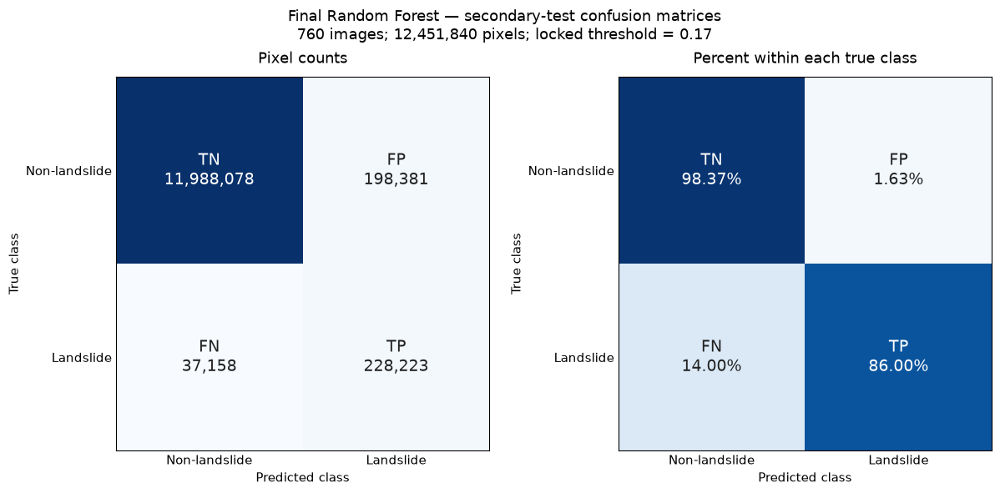

Exact pixel counts:
TN: 11,988,078
FP: 198,381
FN: 37,158
TP: 228,223


In [130]:
import numpy as np
import matplotlib.pyplot as plt

rf_test_cm = np.array([
    [rf_test_metrics["TN"], rf_test_metrics["FP"]],
    [rf_test_metrics["FN"], rf_test_metrics["TP"]]
], dtype=np.int64)

assert rf_test_cm.sum() == 12_451_840

rf_test_cm_percent = (
    100 * rf_test_cm / rf_test_cm.sum(axis=1, keepdims=True)
)

rf_test_figures_dir = rf_test_dir / "figures"
rf_test_figures_dir.mkdir(parents=True, exist_ok=True)

rf_cm_classes = ["Non-landslide", "Landslide"]
rf_cm_names = [["TN", "FP"], ["FN", "TP"]]

with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42
}):
    rf_cm_fig, rf_cm_axes = plt.subplots(
        1, 2, figsize=(12, 5.8),
        constrained_layout=True
    )

    for rf_ax, rf_values, rf_title, rf_is_percent in [
        (
            rf_cm_axes[0], rf_test_cm,
            "Pixel counts", False
        ),
        (
            rf_cm_axes[1], rf_test_cm_percent,
            "Percent within each true class", True
        )
    ]:
        rf_cm_image = rf_ax.imshow(
            rf_values,
            cmap="Blues",
            vmin=0,
            vmax=100 if rf_is_percent else rf_test_cm.max()
        )

        for rf_row in range(2):
            for rf_col in range(2):
                rf_value = rf_values[rf_row, rf_col]
                rf_text = (
                    f"{rf_value:.2f}%"
                    if rf_is_percent
                    else f"{int(rf_value):,}"
                )
                rf_limit = (
                    50 if rf_is_percent else rf_test_cm.max() / 2
                )

                rf_ax.text(
                    rf_col, rf_row,
                    f"{rf_cm_names[rf_row][rf_col]}\n{rf_text}",
                    ha="center", va="center",
                    fontsize=14,
                    color="white" if rf_value > rf_limit else "#222222"
                )

        rf_ax.set_xticks([0, 1], rf_cm_classes)
        rf_ax.set_yticks([0, 1], rf_cm_classes)
        rf_ax.set_xlabel("Predicted class")
        rf_ax.set_ylabel("True class")
        rf_ax.set_title(rf_title, pad=12)
        rf_ax.tick_params(length=0)

    rf_cm_fig.suptitle(
        "Final Random Forest — secondary-test confusion matrices\n"
        "760 images; 12,451,840 pixels; locked threshold = 0.17",
        fontsize=13
    )

    for rf_ext in ["png", "pdf"]:
        rf_cm_fig.savefig(
            rf_test_figures_dir
            / f"secondary_test_confusion_matrices.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

# Display exact integer counts without scientific notation.
print("Exact pixel counts:")
for rf_name in ["TN", "FP", "FN", "TP"]:
    print(f"{rf_name}: {int(rf_test_metrics[rf_name]):,}")

Rationale: Show exact classification counts and class-specific error rates on the secondary test set.
Result: The final model detected 86.00% of landslide pixels, missed 14.00%, and falsely labelled 1.63% of non-landslide pixels. Precision was 53.50%.

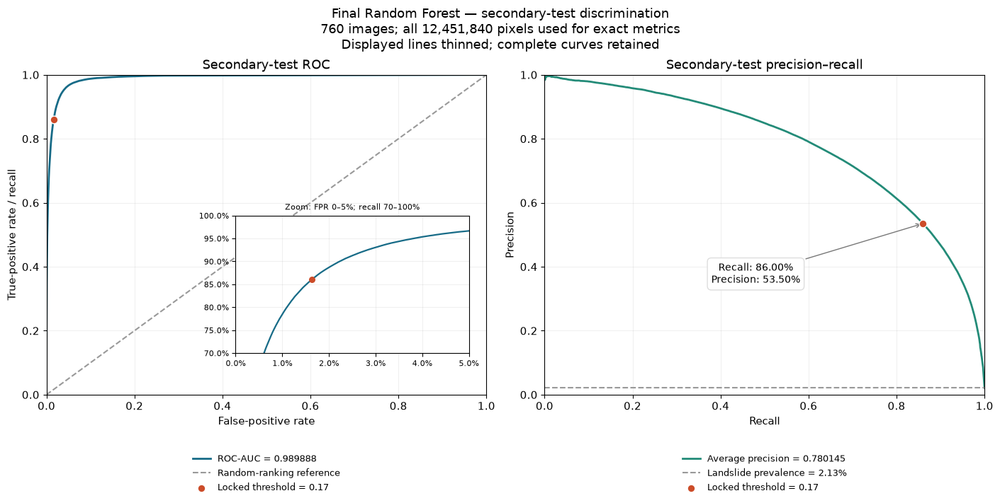

In [131]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_curve, precision_recall_curve, auc
import joblib

rf_test_y_flat = rf_test_labels.reshape(-1)
rf_test_s_flat = rf_test_scores.reshape(-1)

# Full-data curves; thinning is for display only.
rf_test_fpr, rf_test_tpr, _ = roc_curve(
    rf_test_y_flat,
    rf_test_s_flat,
    drop_intermediate=True
)

rf_test_pr_precision, rf_test_pr_recall, _ = precision_recall_curve(
    rf_test_y_flat,
    rf_test_s_flat,
    drop_intermediate=True
)

rf_test_curve_auc = auc(rf_test_fpr, rf_test_tpr)
rf_test_curve_ap = -np.sum(
    np.diff(rf_test_pr_recall) * rf_test_pr_precision[:-1]
)

assert np.isclose(
    rf_test_curve_auc, rf_test_metrics["ROC_AUC"],
    atol=1e-10, rtol=0
)
assert np.isclose(
    rf_test_curve_ap, rf_test_metrics["Average_precision"],
    atol=1e-10, rtol=0
)

rf_test_prevalence = float(rf_test_y_flat.mean())
rf_test_operating_fpr = 1 - rf_test_metrics["Specificity"]
rf_test_operating_recall = rf_test_metrics["Recall"]
rf_test_operating_precision = rf_test_metrics["Precision"]


def rf_test_display_indices(length, maximum_points=6000):
    if length <= maximum_points:
        return np.arange(length)
    return np.unique(
        np.linspace(0, length - 1, maximum_points, dtype=np.intp)
    )


rf_test_roc_indices = rf_test_display_indices(len(rf_test_fpr))
rf_test_pr_indices = rf_test_display_indices(
    len(rf_test_pr_precision)
)

joblib.dump(
    {
        "evaluation_signature": rf_test_signature,
        "ROC_AUC": rf_test_curve_auc,
        "Average_precision": rf_test_curve_ap,
        "prevalence": rf_test_prevalence,
        "roc": {"fpr": rf_test_fpr, "tpr": rf_test_tpr},
        "pr": {
            "precision": rf_test_pr_precision,
            "recall": rf_test_pr_recall
        }
    },
    rf_test_dir / "ranking_curves.joblib"
)

with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42
}):
    rf_test_curve_fig, rf_test_curve_axes = plt.subplots(
        1, 2, figsize=(14, 7),
        constrained_layout=True
    )

    rf_ax = rf_test_curve_axes[0]
    rf_ax.plot(
        rf_test_fpr[rf_test_roc_indices],
        rf_test_tpr[rf_test_roc_indices],
        color="#176B87", linewidth=2,
        label=f"ROC-AUC = {rf_test_curve_auc:.6f}"
    )
    rf_ax.plot(
        [0, 1], [0, 1], "--",
        color="#999999", label="Random-ranking reference"
    )
    rf_ax.scatter(
        rf_test_operating_fpr, rf_test_operating_recall,
        color="#CC4C29", s=60, edgecolor="white", zorder=5,
        label=f"Locked threshold = {rf_test_threshold:.2f}"
    )
    rf_ax.set(
        xlim=(0, 1), ylim=(0, 1),
        xlabel="False-positive rate",
        ylabel="True-positive rate / recall",
        title="Secondary-test ROC"
    )

    rf_inset = rf_ax.inset_axes([0.43, 0.13, 0.53, 0.43])
    rf_inset.plot(
        rf_test_fpr[rf_test_roc_indices],
        rf_test_tpr[rf_test_roc_indices],
        color="#176B87", linewidth=1.6
    )
    rf_inset.scatter(
        rf_test_operating_fpr, rf_test_operating_recall,
        color="#CC4C29", s=30, zorder=5
    )
    rf_inset.set(xlim=(0, 0.05), ylim=(0.70, 1))
    rf_inset.set_title(
        "Zoom: FPR 0–5%; recall 70–100%", fontsize=8
    )
    rf_inset.xaxis.set_major_formatter(PercentFormatter(1))
    rf_inset.yaxis.set_major_formatter(PercentFormatter(1))
    rf_inset.tick_params(labelsize=8)
    rf_inset.grid(alpha=0.18)

    rf_ax = rf_test_curve_axes[1]
    rf_ax.plot(
        rf_test_pr_recall[rf_test_pr_indices],
        rf_test_pr_precision[rf_test_pr_indices],
        color="#238B78", linewidth=2,
        label=f"Average precision = {rf_test_curve_ap:.6f}"
    )
    rf_ax.axhline(
        rf_test_prevalence,
        color="#999999", linestyle="--",
        label=f"Landslide prevalence = {rf_test_prevalence:.2%}"
    )
    rf_ax.scatter(
        rf_test_operating_recall, rf_test_operating_precision,
        color="#CC4C29", s=60, edgecolor="white", zorder=5,
        label=f"Locked threshold = {rf_test_threshold:.2f}"
    )
    rf_ax.annotate(
        f"Recall: {rf_test_operating_recall:.2%}\n"
        f"Precision: {rf_test_operating_precision:.2%}",
        xy=(rf_test_operating_recall, rf_test_operating_precision),
        xytext=(0.48, 0.35),
        textcoords="axes fraction",
        ha="center", fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white", edgecolor="#DDDDDD"
        ),
        arrowprops=dict(arrowstyle="->", color="#777777")
    )
    rf_ax.set(
        xlim=(0, 1), ylim=(0, 1),
        xlabel="Recall",
        ylabel="Precision",
        title="Secondary-test precision–recall"
    )

    for rf_ax in rf_test_curve_axes:
        rf_ax.grid(alpha=0.18)
        rf_ax.set_axisbelow(True)
        rf_ax.legend(
            loc="upper center",
            bbox_to_anchor=(0.5, -0.16),
            frameon=False, fontsize=9
        )

    rf_test_curve_fig.suptitle(
        "Final Random Forest — secondary-test discrimination\n"
        "760 images; all 12,451,840 pixels used for exact metrics\n"
        "Displayed lines thinned; complete curves retained",
        fontsize=13
    )

    for rf_ext in ["png", "pdf"]:
        rf_test_curve_fig.savefig(
            rf_test_figures_dir
            / f"secondary_test_roc_pr.{rf_ext}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()


Rationale: Assess final-model discrimination and the precision–recall trade-off on the secondary test set.
Result: ROC-AUC was 0.989888 and average precision was 0.780145. At the locked threshold, recall was 86.00% and precision was 53.50%.

In [132]:
# Secondary-test uncertainty: whole-image percentile bootstrap.
# Fixed final model and threshold.

import numpy as np
import pandas as pd
import joblib

rf_test_bootstrap_repeats = 2000
rf_test_bootstrap_seed = int(RANDOM_STATE)

rf_test_bootstrap_columns = [
    "TN", "FP", "FN", "TP",
    "pixels", "squared_error_sum", "log_loss_sum"
]

assert len(rf_test_per_image) == 760
assert rf_test_per_image["image_id"].is_unique

rf_test_bootstrap_values = rf_test_per_image[
    rf_test_bootstrap_columns
].to_numpy(dtype=np.float64)

assert np.isfinite(rf_test_bootstrap_values).all()
assert (rf_test_bootstrap_values >= 0).all()

rf_test_bootstrap_totals = rf_test_bootstrap_values.sum(axis=0)

for rf_index, rf_name in enumerate(["TN", "FP", "FN", "TP"]):
    assert int(rf_test_bootstrap_totals[rf_index]) == int(
        rf_test_metrics[rf_name]
    )

assert int(rf_test_bootstrap_totals[4]) == 12_451_840


def rf_test_metrics_from_totals(totals, beta=2):
    totals = np.atleast_2d(totals)
    tn, fp, fn, tp, pixels, squared_error, log_loss_sum = totals.T

    def divide(numerator, denominator):
        return np.divide(
            numerator,
            denominator,
            out=np.full_like(numerator, np.nan, dtype=float),
            where=denominator > 0
        )

    b2 = beta ** 2

    return pd.DataFrame({
        "F2": divide((1 + b2) * tp, (1 + b2) * tp + b2 * fn + fp),
        "Precision": divide(tp, tp + fp),
        "Recall": divide(tp, tp + fn),
        "Specificity": divide(tn, tn + fp),
        "IoU": divide(tp, tp + fp + fn),
        "Accuracy": divide(tp + tn, pixels),
        "Brier_score": divide(squared_error, pixels),
        "Log_loss": divide(log_loss_sum, pixels)
    })


rf_test_bootstrap_rng = np.random.default_rng(
    rf_test_bootstrap_seed
)
rf_test_bootstrap_batches = []

for rf_start in range(0, rf_test_bootstrap_repeats, 100):
    rf_batch_size = min(
        100, rf_test_bootstrap_repeats - rf_start
    )

    rf_weights = rf_test_bootstrap_rng.multinomial(
        n=760,
        pvals=np.full(760, 1 / 760),
        size=rf_batch_size
    )

    rf_test_bootstrap_batches.append(
        rf_test_metrics_from_totals(
            rf_weights @ rf_test_bootstrap_values,
            beta=BETA
        )
    )

rf_test_bootstrap_samples = pd.concat(
    rf_test_bootstrap_batches,
    ignore_index=True
)
assert np.isfinite(rf_test_bootstrap_samples.to_numpy()).all()

rf_test_bootstrap_points = rf_test_metrics_from_totals(
    rf_test_bootstrap_totals,
    beta=BETA
).iloc[0]

# Confirm consistency with the original test metrics.
for rf_metric, rf_value in rf_test_bootstrap_points.items():
    assert np.isclose(
        rf_value,
        rf_test_metrics[rf_metric],
        atol=1e-10,
        rtol=0
    ), f"Metric mismatch: {rf_metric}"

rf_test_bootstrap_ci = pd.DataFrame({
    "Test_estimate": rf_test_bootstrap_points,
    "CI_95_lower": rf_test_bootstrap_samples.quantile(0.025),
    "CI_95_upper": rf_test_bootstrap_samples.quantile(0.975)
})
rf_test_bootstrap_ci.index.name = "Metric"

rf_test_bootstrap_ci.to_csv(
    rf_test_dir / "whole_image_bootstrap_ci.csv"
)

joblib.dump(
    {
        "role": "secondary_test_whole_image_bootstrap",
        "evaluation_signature": rf_test_signature,
        "model_signature": rf_final_model_signature,
        "ordered_image_ids":
            rf_test_per_image["image_id"].tolist(),
        "seed": rf_test_bootstrap_seed,
        "repeats": rf_test_bootstrap_repeats,
        "method": "percentile",
        "confidence_level": 0.95,
        "resampling_unit": "whole_image",
        "threshold": rf_test_threshold,
        "beta": float(BETA),
        "samples": rf_test_bootstrap_samples,
        "confidence_intervals": rf_test_bootstrap_ci
    },
    rf_test_dir / "whole_image_bootstrap.joblib"
)

display(rf_test_bootstrap_ci.round(6))
print("Completed: 2,000 whole-image bootstrap repetitions.")
print("Final model and threshold remained fixed.")

,Test_estimate,CI_95_lower,CI_95_upper
Metric,,,
F2,0.766812,0.746788,0.787047
Precision,0.534976,0.501380,0.566496
Recall,0.859982,0.842749,0.876447
Specificity,0.983721,0.981729,0.985425
IoU,0.492112,0.461779,0.522252
Accuracy,0.981084,0.979031,0.982923
Brier_score,0.008786,0.007842,0.009814
Log_loss,0.032129,0.028894,0.035699


Completed: 2,000 whole-image bootstrap repetitions.
Final model and threshold remained fixed.


Rationale: Quantify secondary-test uncertainty by resampling whole images.
Result: Test F2 was 0.766812 (95% percentile CI: 0.746788–0.787047). Recall was 86.00% (84.27–87.64%) and precision was 53.50% (50.14–56.65%).

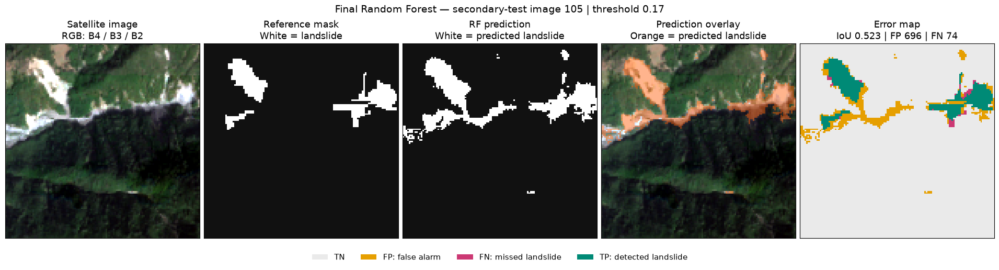

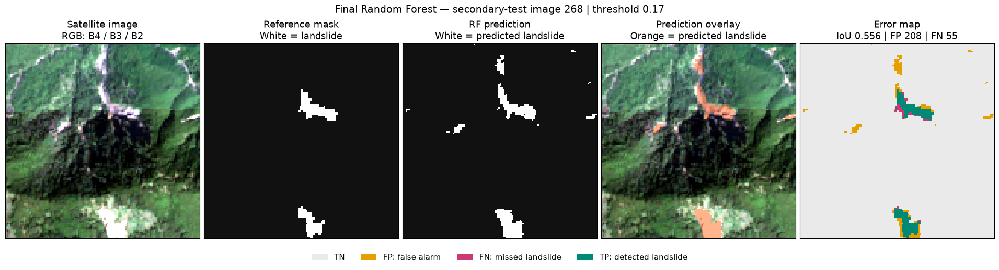

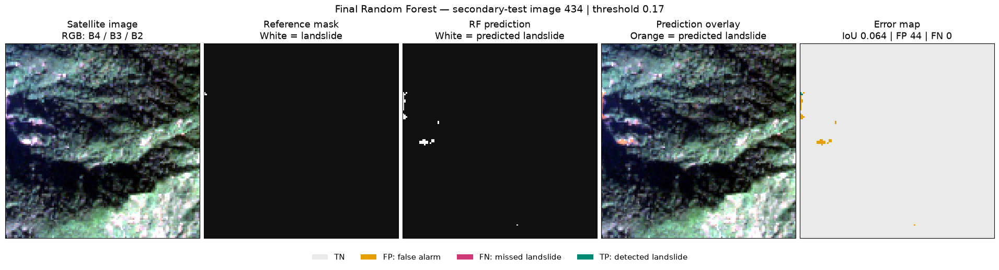

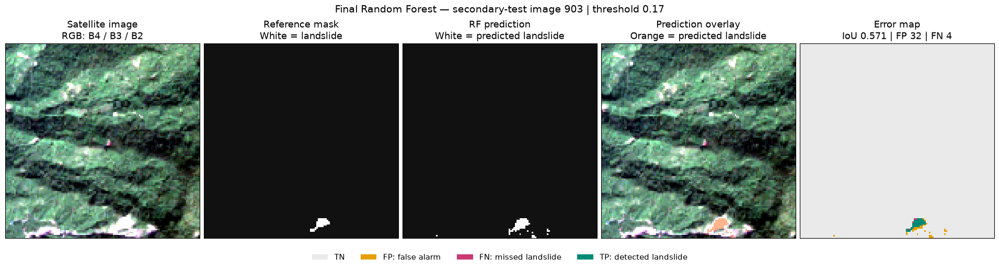

In [135]:
# Readable spatial examples with the satellite image.
# Saved predictions only; no fitting or prediction.

import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

rf_spatial_example_ids = ["105", "268", "434", "903"]
rf_test_id_to_row = {
    str(image_id): row
    for row, image_id in enumerate(rf_test_ids_ordered)
}

# Explicit display composition: R=B4, G=B3, B=B2.
rf_display_band_names = ["B4", "B3", "B2"]
rf_display_band_indices = [
    list(FEATURE_NAMES).index(name)
    for name in rf_display_band_names
]

rf_binary_display_cmap = ListedColormap(["#111111", "#FFFFFF"])
rf_error_display_cmap = ListedColormap([
    "#EAEAEA", "#E69F00", "#CC3974", "#008A76"
])
rf_error_display_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5], 4
)


def rf_make_display_rgb(image, indices):
    rgb = image[..., indices].astype(np.float64).copy()

    # Contrast stretch for display only.
    for channel in range(3):
        low, high = np.percentile(rgb[..., channel], [2, 98])
        if high > low:
            rgb[..., channel] = np.clip(
                (rgb[..., channel] - low) / (high - low), 0, 1
            )
        else:
            rgb[..., channel] = 0

    return rgb


for rf_image_id in rf_spatial_example_ids:
    assert rf_image_id in rf_test_id_to_row
    rf_index = rf_test_id_to_row[rf_image_id]

    rf_image_path = (
        Path(DATA_DIR) / "TrainData" / "img"
        / f"image_{rf_image_id}.h5"
    )
    rf_mask_path = (
        Path(DATA_DIR) / "TrainData" / "mask"
        / f"mask_{rf_image_id}.h5"
    )

    with h5py.File(rf_image_path, "r") as rf_file:
        rf_image = np.asarray(rf_file["img"], dtype=np.float32)

    with h5py.File(rf_mask_path, "r") as rf_file:
        rf_reference = np.asarray(rf_file["mask"])

    assert rf_image.shape == (128, 128, len(FEATURE_NAMES))
    assert np.isfinite(rf_image).all()
    assert np.isin(rf_reference, [0, 1]).all()

    rf_truth = rf_test_labels[rf_index].reshape(128, 128).astype(bool)
    assert np.array_equal(rf_truth, rf_reference.astype(bool))

    rf_prediction = (
        rf_test_scores[rf_index].reshape(128, 128)
        >= rf_test_threshold
    )
    rf_rgb = rf_make_display_rgb(
        rf_image, rf_display_band_indices
    )

    rf_errors = np.zeros((128, 128), dtype=np.uint8)
    rf_errors[~rf_truth & rf_prediction] = 1
    rf_errors[rf_truth & ~rf_prediction] = 2
    rf_errors[rf_truth & rf_prediction] = 3

    rf_tp = int(np.count_nonzero(rf_errors == 3))
    rf_fp = int(np.count_nonzero(rf_errors == 1))
    rf_fn = int(np.count_nonzero(rf_errors == 2))
    rf_union = rf_tp + rf_fp + rf_fn
    rf_iou = rf_tp / rf_union if rf_union else np.nan

    # Transparent orange overlay for predicted landslide pixels.
    rf_overlay = np.zeros((128, 128, 4), dtype=float)
    rf_overlay[..., :3] = [1.0, 0.35, 0.0]
    rf_overlay[..., 3] = rf_prediction.astype(float) * 0.45

    with plt.rc_context({"font.size": 11, "pdf.fonttype": 42}):
        rf_fig, rf_axes = plt.subplots(
            1, 5, figsize=(19, 4.8),
            constrained_layout=True
        )

        rf_axes[0].imshow(rf_rgb, interpolation="nearest")
        rf_axes[0].set_title("Satellite image\nRGB: B4 / B3 / B2")

        rf_axes[1].imshow(
            rf_truth, cmap=rf_binary_display_cmap,
            vmin=0, vmax=1, interpolation="nearest"
        )
        rf_axes[1].set_title("Reference mask\nWhite = landslide")

        rf_axes[2].imshow(
            rf_prediction, cmap=rf_binary_display_cmap,
            vmin=0, vmax=1, interpolation="nearest"
        )
        rf_axes[2].set_title("RF prediction\nWhite = predicted landslide")

        rf_axes[3].imshow(rf_rgb, interpolation="nearest")
        rf_axes[3].imshow(rf_overlay, interpolation="nearest")
        rf_axes[3].set_title("Prediction overlay\nOrange = predicted landslide")

        rf_axes[4].imshow(
            rf_errors,
            cmap=rf_error_display_cmap,
            norm=rf_error_display_norm,
            interpolation="nearest"
        )
        rf_axes[4].set_title(
            f"Error map\nIoU {rf_iou:.3f} | FP {rf_fp} | FN {rf_fn}"
        )

        for rf_ax in rf_axes:
            rf_ax.set_xticks([])
            rf_ax.set_yticks([])

        rf_fig.suptitle(
            f"Final Random Forest — secondary-test image {rf_image_id}"
            f" | threshold {rf_test_threshold:.2f}",
            fontsize=14
        )

        rf_fig.legend(
            handles=[
                Patch(facecolor="#EAEAEA", label="TN"),
                Patch(facecolor="#E69F00", label="FP: false alarm"),
                Patch(facecolor="#CC3974", label="FN: missed landslide"),
                Patch(facecolor="#008A76", label="TP: detected landslide")
            ],
            loc="lower center",
            bbox_to_anchor=(0.5, -0.06),
            ncol=4, frameon=False
        )

        for rf_extension in ["png", "pdf"]:
            rf_fig.savefig(
                rf_test_figures_dir
                / f"secondary_test_image_{rf_image_id}_with_rgb.{rf_extension}",
                dpi=220,
                bbox_inches="tight",
                facecolor="white"
            )

        plt.show()

Random Forest — results on the six fixed test images


,Image_ID,Reference_landslide_percent,TN,FP,FN,TP,Precision,Recall,F2,IoU
0,105,5.603027,14770,696,74,844,0.548052,0.919390,0.809670,0.522924
1,2684,0.744629,15865,397,62,60,0.131291,0.491803,0.317460,0.115607
2,3459,0.000000,16203,181,0,0,0.000000,NaN,0.000000,0.000000
3,1535,6.060791,15211,180,70,923,0.836809,0.929507,0.909360,0.786871
4,590,9.429932,13966,873,244,1301,0.598436,0.842071,0.778669,0.538048
5,3316,0.000000,16373,11,0,0,0.000000,NaN,0.000000,0.000000


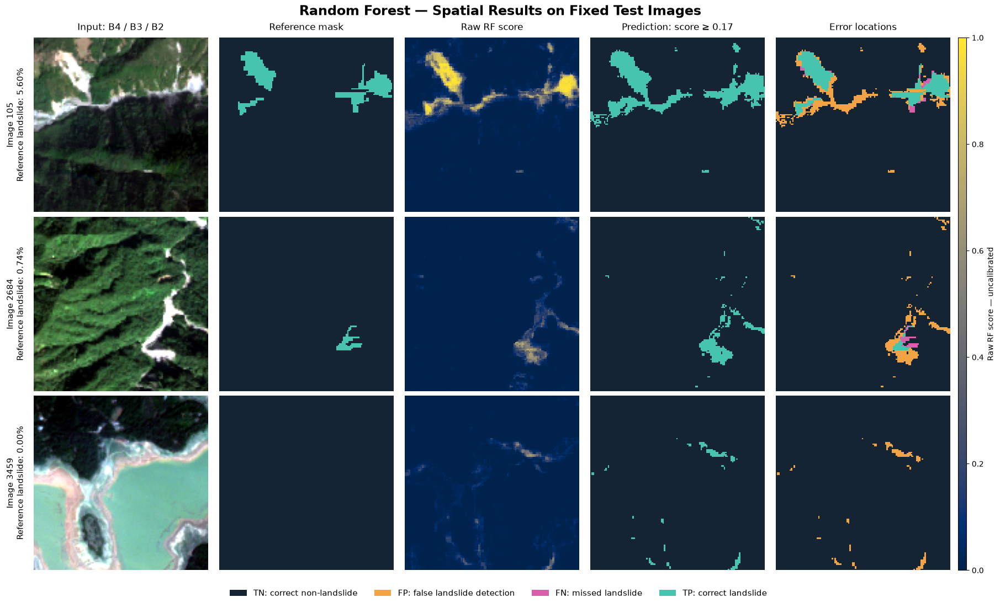

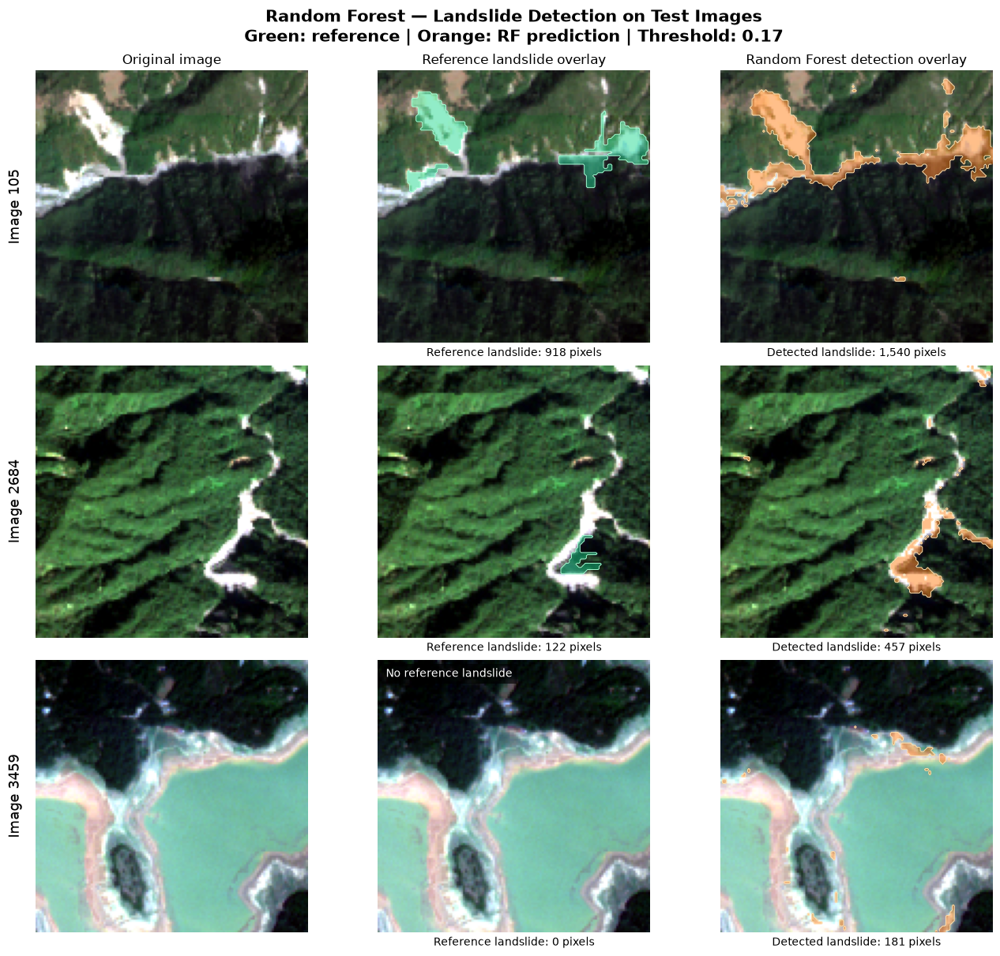

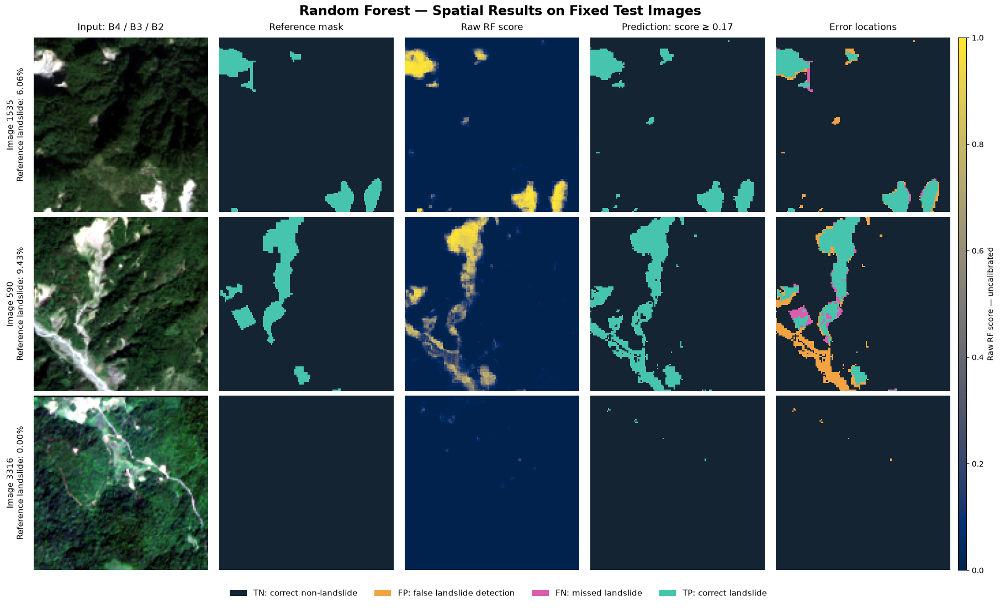

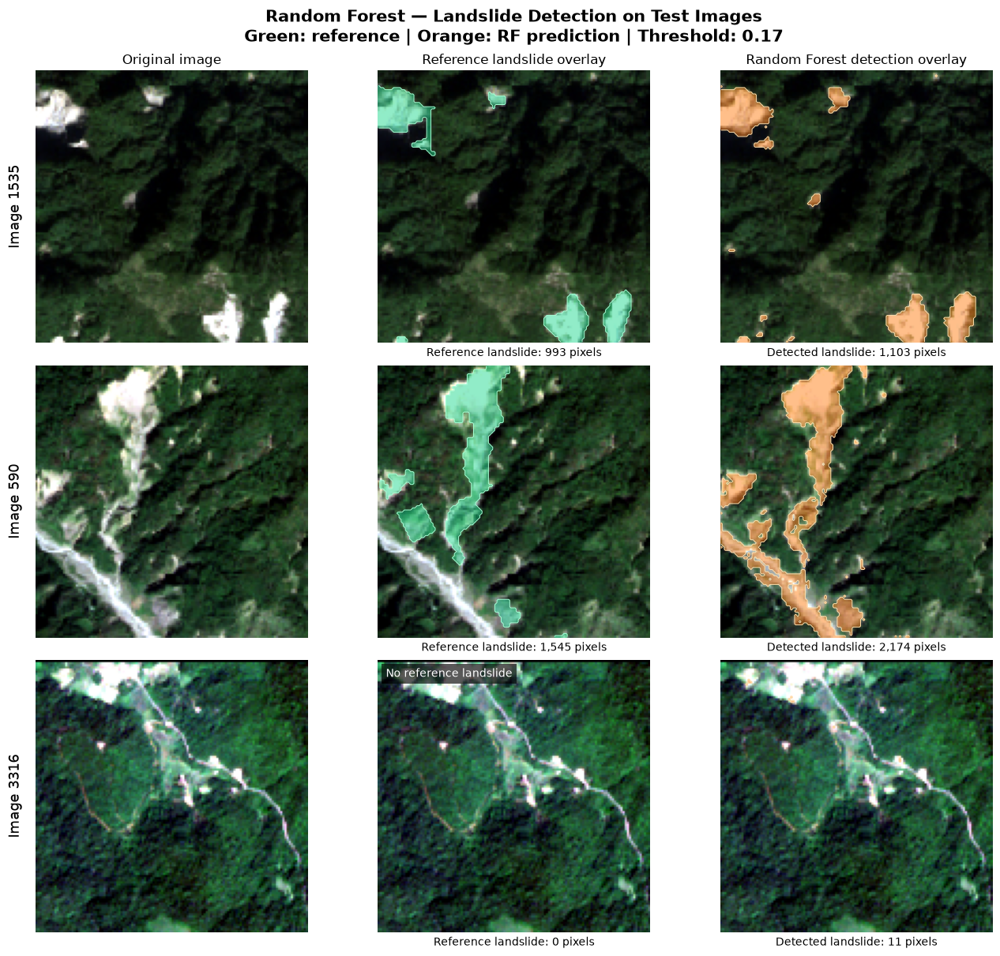

Saved: RF metric table and four figures.
Image IDs: 105, 2684, 3459, 1535, 590, 3316
No training or predictions were repeated.


In [136]:
# RF spatial results: the same six fixed test images.
# Restore saved predictions, then plot RF results only.

from pathlib import Path
import json

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# ---------------------------------------------------------
# 1. Restore the saved RF test evaluation.
# ---------------------------------------------------------
rf_project_path = Path.home() / "Ramen" / "ds-ml-project-template"
rf_checkpoint_path = (
    rf_project_path / "artifacts" / "random_forest" / "checkpoints"
)
rf_registry_path = rf_checkpoint_path / "final_model_registry.joblib"

assert rf_registry_path.is_file(), (
    f"Saved RF registry not found: {rf_registry_path}"
)

rf_registry = joblib.load(rf_registry_path)
rf_model_signature = rf_registry["signature"]
rf_model_directory = Path(rf_registry["model_path"]).parent

rf_matching_evaluations = []

for rf_path in (
    rf_model_directory / "secondary_test"
).glob("*/evaluation.joblib"):
    rf_saved_evaluation = joblib.load(rf_path)

    if (
        rf_saved_evaluation["metadata"]["model_signature"]
        == rf_model_signature
    ):
        rf_matching_evaluations.append(
            (rf_path, rf_saved_evaluation)
        )

assert len(rf_matching_evaluations) == 1, (
    "Expected exactly one matching RF test evaluation; "
    f"found {len(rf_matching_evaluations)}."
)

rf_evaluation_path, rf_saved_evaluation = rf_matching_evaluations[0]

rf_plot_scores = np.load(
    rf_saved_evaluation["scores_path"],
    mmap_mode="r"
)
rf_plot_labels = np.load(
    rf_saved_evaluation["labels_path"],
    mmap_mode="r"
)
rf_plot_threshold = float(
    rf_saved_evaluation["metadata"]["threshold"]
)
rf_plot_ids = list(map(str, rf_saved_evaluation["image_ids"]))
rf_plot_per_image = rf_saved_evaluation["per_image"].copy()

assert rf_plot_scores.shape == rf_plot_labels.shape == (760, 16384)
assert len(rf_plot_ids) == len(set(rf_plot_ids)) == 760

rf_fixed_ids = ["105", "2684", "3459", "1535", "590", "3316"]
rf_id_lookup = {
    image_id: position
    for position, image_id in enumerate(rf_plot_ids)
}
rf_source_lookup = {
    str(source["image_id"]): source
    for source in rf_saved_evaluation["metadata"]["sources"]
}

assert set(rf_fixed_ids).issubset(rf_id_lookup)
assert set(rf_fixed_ids).issubset(rf_source_lookup)

rf_plot_output = (
    rf_evaluation_path.parent / "figures" / "fixed_test_images"
)
rf_plot_output.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 2. Prepare the six images and verify saved predictions.
# ---------------------------------------------------------
rf_binary_cmap = ListedColormap(["#142432", "#47C4AD"])
rf_error_colors = ["#142432", "#F2A444", "#D95FAD", "#47C4AD"]
rf_error_cmap = ListedColormap(rf_error_colors)
rf_error_norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5], ncolors=4
)

rf_error_legend = [
    Patch(facecolor=color, label=label)
    for color, label in zip(
        rf_error_colors,
        [
            "TN: correct non-landslide",
            "FP: false landslide detection",
            "FN: missed landslide",
            "TP: correct landslide"
        ]
    )
]


def rf_fixed_rgb(image):
    rgb = image[:, :, [3, 2, 1]].astype(np.float64)
    lower = np.percentile(rgb, 2, axis=(0, 1))
    upper = np.percentile(rgb, 98, axis=(0, 1))
    return np.clip(
        (rgb - lower) / np.maximum(upper - lower, 1e-12),
        0, 1
    )


def rf_fixed_overlay(mask, color):
    overlay = np.zeros((*mask.shape, 4), dtype=float)
    overlay[..., :3] = color
    overlay[..., 3] = mask.astype(float) * 0.48
    return overlay


def rf_safe_ratio(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan


rf_fixed_records = []
rf_fixed_metric_rows = []

for rf_image_id in rf_fixed_ids:
    rf_position = rf_id_lookup[rf_image_id]
    rf_source = rf_source_lookup[rf_image_id]

    # Verify that source files have not changed.
    for rf_kind in ["image", "mask"]:
        rf_file_path = Path(rf_source[f"{rf_kind}_path"])
        rf_stat = rf_file_path.stat()
        assert rf_stat.st_size == rf_source[f"{rf_kind}_size"]
        assert rf_stat.st_mtime_ns == rf_source[f"{rf_kind}_mtime_ns"]

    with h5py.File(rf_source["image_path"], "r") as rf_file:
        rf_image = np.asarray(rf_file["img"], dtype=np.float32)

    with h5py.File(rf_source["mask_path"], "r") as rf_file:
        rf_mask = np.asarray(rf_file["mask"])

    assert rf_image.shape == (128, 128, 14)
    assert rf_mask.shape == (128, 128)
    assert np.isfinite(rf_image).all()
    assert np.isin(rf_mask, [0, 1]).all()

    rf_reference = rf_mask.astype(bool)
    assert np.array_equal(
        rf_reference,
        rf_plot_labels[rf_position].reshape(128, 128).astype(bool)
    )

    rf_score = rf_plot_scores[rf_position].reshape(128, 128)
    rf_prediction = rf_score >= rf_plot_threshold

    # Codes: TN=0, FP=1, FN=2, TP=3.
    rf_error = (
        2 * rf_reference.astype(np.uint8)
        + rf_prediction.astype(np.uint8)
    )
    rf_counts = {
        name: int(np.count_nonzero(rf_error == code))
        for code, name in enumerate(["TN", "FP", "FN", "TP"])
    }

    rf_saved_row = rf_plot_per_image.loc[
        rf_plot_per_image["image_id"].astype(str) == rf_image_id
    ]
    assert len(rf_saved_row) == 1

    for rf_name, rf_count in rf_counts.items():
        assert int(rf_saved_row.iloc[0][rf_name]) == rf_count

    rf_tp = rf_counts["TP"]
    rf_fp = rf_counts["FP"]
    rf_fn = rf_counts["FN"]

    rf_fixed_metric_rows.append({
        "Image_ID": rf_image_id,
        "Reference_landslide_percent": 100 * rf_reference.mean(),
        **rf_counts,
        "Precision": rf_safe_ratio(rf_tp, rf_tp + rf_fp),
        "Recall": rf_safe_ratio(rf_tp, rf_tp + rf_fn),
        "F2": rf_safe_ratio(
            5 * rf_tp, 5 * rf_tp + 4 * rf_fn + rf_fp
        ),
        "IoU": rf_safe_ratio(rf_tp, rf_tp + rf_fp + rf_fn)
    })

    rf_fixed_records.append({
        "id": rf_image_id,
        "rgb": rf_fixed_rgb(rf_image),
        "reference": rf_reference,
        "score": rf_score,
        "prediction": rf_prediction,
        "error": rf_error
    })

rf_fixed_image_metrics = pd.DataFrame(rf_fixed_metric_rows)
rf_fixed_image_metrics.to_csv(
    rf_plot_output / "rf_fixed_image_metrics.csv",
    index=False
)

print("Random Forest — results on the six fixed test images")
display(rf_fixed_image_metrics.round(6))

# ---------------------------------------------------------
# 3. Two diagnostic pages and two overlay pages.
# ---------------------------------------------------------
with plt.rc_context({
    "font.size": 10,
    "axes.titlesize": 12,
    "figure.facecolor": "white",
    "pdf.fonttype": 42
}):
    for rf_page_start in [0, 3]:
        rf_page = rf_fixed_records[rf_page_start:rf_page_start + 3]
        rf_page_number = rf_page_start // 3 + 1

        # A. RGB / reference / RF score / prediction / errors.
        rf_fig = plt.figure(
            figsize=(18, 11), constrained_layout=True
        )
        rf_grid = rf_fig.add_gridspec(
            4, 6,
            width_ratios=[1, 1, 1, 1, 1, 0.045],
            height_ratios=[1, 1, 1, 0.16]
        )

        rf_titles = [
            "Input: B4 / B3 / B2",
            "Reference mask",
            "Raw RF score",
            f"Prediction: score ≥ {rf_plot_threshold:.2f}",
            "Error locations"
        ]

        for rf_row, rf_record in enumerate(rf_page):
            rf_panels = [
                rf_record["rgb"], rf_record["reference"],
                rf_record["score"], rf_record["prediction"],
                rf_record["error"]
            ]

            for rf_col, rf_panel in enumerate(rf_panels):
                rf_ax = rf_fig.add_subplot(rf_grid[rf_row, rf_col])

                if rf_col == 0:
                    rf_ax.imshow(rf_panel)
                elif rf_col in [1, 3]:
                    rf_ax.imshow(
                        rf_panel, cmap=rf_binary_cmap,
                        vmin=0, vmax=1, interpolation="nearest"
                    )
                elif rf_col == 2:
                    rf_score_artist = rf_ax.imshow(
                        rf_panel, cmap="cividis",
                        vmin=0, vmax=1, interpolation="nearest"
                    )
                else:
                    rf_ax.imshow(
                        rf_panel, cmap=rf_error_cmap,
                        norm=rf_error_norm, interpolation="nearest"
                    )

                if rf_row == 0:
                    rf_ax.set_title(rf_titles[rf_col], pad=10)
                if rf_col == 0:
                    rf_ax.set_ylabel(
                        f"Image {rf_record['id']}\n"
                        "Reference landslide: "
                        f"{100 * rf_record['reference'].mean():.2f}%",
                        fontsize=11, labelpad=10
                    )

                rf_ax.set_xticks([])
                rf_ax.set_yticks([])
                for rf_spine in rf_ax.spines.values():
                    rf_spine.set_visible(False)

        rf_colorbar_ax = rf_fig.add_subplot(rf_grid[:3, 5])
        rf_fig.colorbar(
            rf_score_artist,
            cax=rf_colorbar_ax,
            label="Raw RF score — uncalibrated"
        )

        rf_legend_ax = rf_fig.add_subplot(rf_grid[3, :])
        rf_legend_ax.axis("off")
        rf_legend_ax.legend(
            handles=rf_error_legend,
            loc="center", ncol=4, frameon=False, fontsize=11
        )

        rf_fig.suptitle(
            "Random Forest — Spatial Results on Fixed Test Images",
            fontsize=17, fontweight="bold"
        )

        for rf_extension in ["png", "pdf"]:
            rf_fig.savefig(
                rf_plot_output
                / f"rf_spatial_results_page_{rf_page_number}.{rf_extension}",
                dpi=220, bbox_inches="tight", facecolor="white"
            )
        plt.show()

        # B. Original image / reference overlay / RF overlay.
        rf_fig, rf_axes = plt.subplots(
            3, 3, figsize=(13, 12),
            constrained_layout=True
        )

        for rf_row, rf_record in enumerate(rf_page):
            for rf_col in range(3):
                rf_axes[rf_row, rf_col].imshow(rf_record["rgb"])
                rf_axes[rf_row, rf_col].set_xticks([])
                rf_axes[rf_row, rf_col].set_yticks([])
                for rf_spine in rf_axes[rf_row, rf_col].spines.values():
                    rf_spine.set_visible(False)

            for rf_col, rf_mask, rf_color, rf_boundary in [
                (
                    1, rf_record["reference"],
                    (0.10, 0.85, 0.55), "#A4FFD4"
                ),
                (
                    2, rf_record["prediction"],
                    (1.00, 0.48, 0.05), "#FFE0AD"
                )
            ]:
                rf_axes[rf_row, rf_col].imshow(
                    rf_fixed_overlay(rf_mask, rf_color)
                )
                if rf_mask.any() and not rf_mask.all():
                    rf_axes[rf_row, rf_col].contour(
                        rf_mask.astype(float),
                        levels=[0.5],
                        colors=[rf_boundary],
                        linewidths=0.7
                    )

            rf_axes[rf_row, 0].set_ylabel(
                f"Image {rf_record['id']}", fontsize=13, labelpad=12
            )
            rf_axes[rf_row, 1].set_xlabel(
                f"Reference landslide: "
                f"{rf_record['reference'].sum():,} pixels"
            )
            rf_axes[rf_row, 2].set_xlabel(
                f"Detected landslide: "
                f"{rf_record['prediction'].sum():,} pixels"
            )

            if not rf_record["reference"].any():
                rf_axes[rf_row, 1].text(
                    0.03, 0.97, "No reference landslide",
                    transform=rf_axes[rf_row, 1].transAxes,
                    ha="left", va="top", color="white",
                    bbox=dict(
                        facecolor="black", alpha=0.65,
                        edgecolor="none", pad=4
                    )
                )

        rf_axes[0, 0].set_title("Original image")
        rf_axes[0, 1].set_title("Reference landslide overlay")
        rf_axes[0, 2].set_title("Random Forest detection overlay")

        rf_fig.suptitle(
            "Random Forest — Landslide Detection on Test Images\n"
            "Green: reference | Orange: RF prediction"
            f" | Threshold: {rf_plot_threshold:.2f}",
            fontsize=15, fontweight="bold"
        )

        for rf_extension in ["png", "pdf"]:
            rf_fig.savefig(
                rf_plot_output
                / f"rf_detection_overlays_page_{rf_page_number}.{rf_extension}",
                dpi=220, bbox_inches="tight", facecolor="white"
            )
        plt.show()

print("Saved: RF metric table and four figures.")
print("Image IDs:", ", ".join(rf_fixed_ids))
print("No training or predictions were repeated.")

Rationale: Assess RF on the six fixed test images using verified pixel counts.
Result: Image 1535 had the highest positive-example IoU (0.7869). Low-coverage image 2684 remained difficult, with precision of 13.13% and recall of 49.18%. Negative images 3459 and 3316 contained 181 and 11 false-positive pixels.

In [137]:
# RF secondary-test subgroup evaluation by reference landslide coverage.
# Uses saved per-image counts; no training or prediction.

import numpy as np
import pandas as pd

rf_coverage_images = rf_saved_evaluation["per_image"].copy()

assert len(rf_coverage_images) == 760
assert rf_coverage_images["image_id"].astype(str).is_unique
assert (rf_coverage_images["pixels"] == 16384).all()

rf_coverage_images["Reference_coverage_percent"] = (
    100
    * rf_coverage_images["positive_pixels"]
    / rf_coverage_images["pixels"]
)

rf_coverage_images["Coverage_group"] = pd.cut(
    rf_coverage_images["Reference_coverage_percent"],
    bins=[-np.inf, 0, 1, 5, 20, np.inf],
    labels=[
        "No landslide",
        ">0–1%",
        ">1–5%",
        ">5–20%",
        ">20%"
    ],
    right=True
)

assert rf_coverage_images["Coverage_group"].notna().all()


def rf_coverage_ratio(numerator, denominator):
    return numerator / denominator if denominator > 0 else np.nan


rf_coverage_rows = []

for rf_group_name in rf_coverage_images[
    "Coverage_group"
].cat.categories:
    rf_group = rf_coverage_images.loc[
        rf_coverage_images["Coverage_group"] == rf_group_name
    ]

    rf_tn, rf_fp, rf_fn, rf_tp = [
        int(rf_group[column].sum())
        for column in ["TN", "FP", "FN", "TP"]
    ]
    rf_pixels = int(rf_group["pixels"].sum())

    rf_coverage_rows.append({
        "Reference_coverage_group": str(rf_group_name),
        "Images": len(rf_group),
        "Pixels": rf_pixels,
        "Positive_pixels": int(
            rf_group["positive_pixels"].sum()
        ),
        "TN": rf_tn,
        "FP": rf_fp,
        "FN": rf_fn,
        "TP": rf_tp,
        "F2": rf_coverage_ratio(
            5 * rf_tp,
            5 * rf_tp + 4 * rf_fn + rf_fp
        ),
        "Precision": rf_coverage_ratio(
            rf_tp, rf_tp + rf_fp
        ),
        "Recall": rf_coverage_ratio(
            rf_tp, rf_tp + rf_fn
        ),
        "Specificity": rf_coverage_ratio(
            rf_tn, rf_tn + rf_fp
        ),
        "IoU": rf_coverage_ratio(
            rf_tp, rf_tp + rf_fp + rf_fn
        ),
        "FP_fraction_of_all_pixels": rf_coverage_ratio(
            rf_fp, rf_pixels
        ),
        "Images_with_any_FP": int(
            (rf_group["FP"] > 0).sum()
        ),
        "Fraction_images_with_any_FP": (
            float((rf_group["FP"] > 0).mean())
            if len(rf_group) else np.nan
        )
    })

rf_test_coverage_summary = pd.DataFrame(rf_coverage_rows)

assert int(rf_test_coverage_summary["Images"].sum()) == 760

for rf_count_name in ["TN", "FP", "FN", "TP"]:
    assert int(
        rf_test_coverage_summary[rf_count_name].sum()
    ) == int(rf_saved_evaluation["metrics"][rf_count_name])

rf_test_coverage_summary.to_csv(
    rf_evaluation_path.parent / "rf_test_coverage_groups.csv",
    index=False
)

rf_coverage_images.to_csv(
    rf_evaluation_path.parent / "rf_test_per_image_with_coverage.csv",
    index=False
)

with pd.option_context(
    "display.max_columns", None,
    "display.width", 200
):
    display(rf_test_coverage_summary.round(6))

print("All 760 test images are included exactly once.")
print("Grouped counts match the saved overall test counts.")
print("Model and threshold remained unchanged.")

,Reference_coverage_group,Images,Pixels,Positive_pixels,TN,FP,FN,TP,F2,Precision,Recall,Specificity,IoU,FP_fraction_of_all_pixels,Images_with_any_FP,Fraction_images_with_any_FP
0,No landslide,314,5144576,0,5127185,17391,0,0,0.000000,0.000000,NaN,0.996620,0.000000,0.003380,212,0.675159
1,>0–1%,158,2588672,11224,2550427,27021,2928,8296,0.517123,0.234901,0.739130,0.989516,0.216917,0.010438,156,0.987342
2,>1–5%,183,2998272,76306,2846968,74998,14307,61999,0.700996,0.452557,0.812505,0.974333,0.409764,0.025014,182,0.994536
3,>5–20%,97,1589248,142890,1378136,68222,18041,124849,0.816400,0.646648,0.873742,0.952832,0.591388,0.042927,97,1.000000
4,>20%,8,131072,34961,85362,10749,1882,33079,0.900491,0.754746,0.946169,0.888161,0.723671,0.082008,8,1.000000


All 760 test images are included exactly once.
Grouped counts match the saved overall test counts.
Model and threshold remained unchanged.


Rationale: Identify performance differences across reference-coverage groups using all secondary-test images.
Result: RF performed better in higher-coverage groups. The lowest positive-coverage group had precision of 23.49% and F2 of 0.5171. Across 314 negative images, false positives occupied 0.338% of pixels.

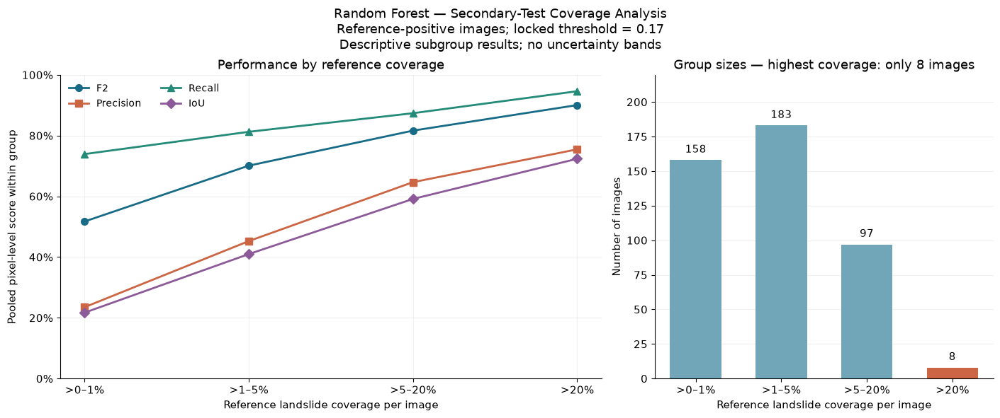

In [138]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rf_coverage_plot = rf_test_coverage_summary.loc[
    rf_test_coverage_summary["Reference_coverage_group"]
    != "No landslide"
].copy()

rf_coverage_x = np.arange(len(rf_coverage_plot))
rf_coverage_labels = rf_coverage_plot[
    "Reference_coverage_group"
].tolist()

with plt.rc_context({
    "font.size": 11,
    "pdf.fonttype": 42
}):
    rf_coverage_fig, rf_coverage_axes = plt.subplots(
        1, 2,
        figsize=(14, 5.8),
        gridspec_kw={"width_ratios": [1.6, 1]},
        constrained_layout=True
    )

    rf_ax = rf_coverage_axes[0]

    for rf_metric, rf_color, rf_marker in [
        ("F2", "#176B87", "o"),
        ("Precision", "#CB6543", "s"),
        ("Recall", "#238B78", "^"),
        ("IoU", "#8C5A99", "D")
    ]:
        rf_ax.plot(
            rf_coverage_x,
            rf_coverage_plot[rf_metric],
            color=rf_color,
            marker=rf_marker,
            markersize=7,
            linewidth=2,
            label=rf_metric
        )

    rf_ax.set_xticks(rf_coverage_x, rf_coverage_labels)
    rf_ax.set_ylim(0, 1)
    rf_ax.yaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.set_xlabel("Reference landslide coverage per image")
    rf_ax.set_ylabel("Pooled pixel-level score within group")
    rf_ax.set_title("Performance by reference coverage")
    rf_ax.legend(
        loc="upper left",
        ncol=2,
        frameon=False,
        fontsize=10
    )
    rf_ax.grid(alpha=0.18)

    rf_ax = rf_coverage_axes[1]
    rf_bars = rf_ax.bar(
        rf_coverage_x,
        rf_coverage_plot["Images"],
        color=["#70A6B8", "#70A6B8", "#70A6B8", "#CB6543"],
        width=0.6
    )
    rf_ax.bar_label(
        rf_bars,
        labels=[
            f"{int(count)}"
            for count in rf_coverage_plot["Images"]
        ],
        padding=5,
        fontsize=11
    )
    rf_ax.set_xticks(rf_coverage_x, rf_coverage_labels)
    rf_ax.set_ylim(
        0, float(rf_coverage_plot["Images"].max()) * 1.2
    )
    rf_ax.set_xlabel("Reference landslide coverage per image")
    rf_ax.set_ylabel("Number of images")
    rf_ax.set_title("Group sizes — highest coverage: only 8 images")
    rf_ax.grid(axis="y", alpha=0.18)

    for rf_ax in rf_coverage_axes:
        rf_ax.set_axisbelow(True)
        rf_ax.spines[["top", "right"]].set_visible(False)

    rf_coverage_fig.suptitle(
        "Random Forest — Secondary-Test Coverage Analysis\n"
        "Reference-positive images; locked threshold = 0.17\n"
        "Descriptive subgroup results; no uncertainty bands",
        fontsize=13
    )

    for rf_extension in ["png", "pdf"]:
        rf_coverage_fig.savefig(
            rf_plot_output
            / f"rf_secondary_test_coverage_analysis.{rf_extension}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

In [139]:
rf_high_coverage_images = (
    rf_coverage_images.loc[
        rf_coverage_images["Reference_coverage_percent"] > 20,
        [
            "image_id",
            "positive_pixels",
            "Reference_coverage_percent",
            "TN", "FP", "FN", "TP"
        ]
    ]
    .sort_values("Reference_coverage_percent", ascending=False)
    .copy()
)

assert len(rf_high_coverage_images) == 8

display(rf_high_coverage_images.round(4))

,image_id,positive_pixels,Reference_coverage_percent,TN,FP,FN,TP
147,684,7788,47.5342,7395,1201,346,7442
307,1538,4408,26.9043,10553,1423,108,4300
158,724,4055,24.7498,10426,1903,97,3958
419,2146,3924,23.9502,11158,1302,78,3846
114,518,3831,23.3826,11540,1013,112,3719
62,303,3811,23.2605,9838,2735,218,3593
497,2508,3762,22.9614,11980,642,839,2923
298,1497,3382,20.6421,12472,530,84,3298


,Bin_lower,Bin_upper,Pixels,Positive_pixels,Pixel_share,Mean_score,Observed_positive_fraction,Observed_minus_score
0,0.00,0.05,11725888,12913,0.941699,0.001603,0.001101,-0.000502
1,0.05,0.10,178871,10254,0.014365,0.071473,0.057326,-0.014147
2,0.10,0.15,93388,10008,0.007500,0.122927,0.107166,-0.015761
3,0.15,0.20,61479,9940,0.004937,0.173555,0.161681,-0.011873
4,0.20,0.25,45550,9860,0.003658,0.223887,0.216465,-0.007421
5,0.25,0.30,35506,9405,0.002851,0.274021,0.264885,-0.009136
6,0.30,0.35,29394,9381,0.002361,0.324342,0.319147,-0.005196
7,0.35,0.40,25334,9211,0.002035,0.374573,0.363583,-0.010991
8,0.40,0.45,23016,9736,0.001848,0.424605,0.423010,-0.001594
9,0.45,0.50,20839,9830,0.001674,0.474723,0.471712,-0.003011


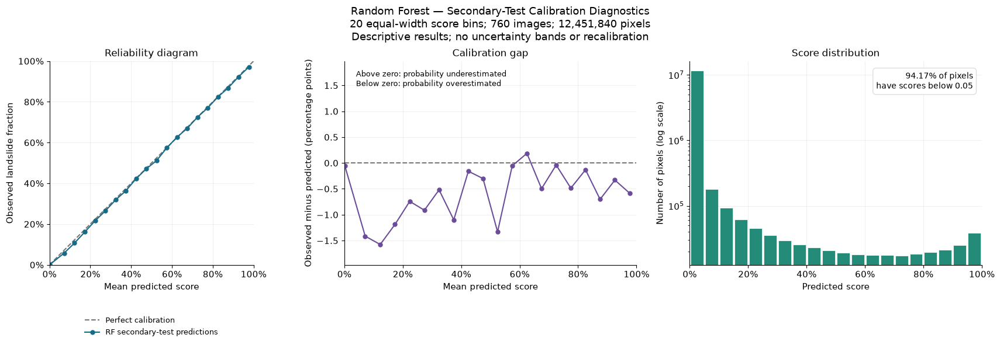

In [140]:
# RF secondary-test calibration diagnostics.
# No training, prediction or recalibration.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

rf_test_cal_bin_count = 20
rf_test_cal_edges = np.linspace(0, 1, rf_test_cal_bin_count + 1)

rf_test_cal_counts = np.zeros(20, dtype=np.int64)
rf_test_cal_positives = np.zeros(20, dtype=np.int64)
rf_test_cal_score_sums = np.zeros(20, dtype=np.float64)

rf_test_cal_scores_flat = rf_plot_scores.reshape(-1)
rf_test_cal_labels_flat = rf_plot_labels.reshape(-1)

for rf_start in range(0, rf_test_cal_scores_flat.size, 1_000_000):
    rf_stop = min(
        rf_start + 1_000_000,
        rf_test_cal_scores_flat.size
    )

    rf_scores_batch = np.asarray(
        rf_test_cal_scores_flat[rf_start:rf_stop]
    )
    rf_labels_batch = np.asarray(
        rf_test_cal_labels_flat[rf_start:rf_stop]
    )

    assert np.isfinite(rf_scores_batch).all()
    assert (
        (rf_scores_batch >= 0) & (rf_scores_batch <= 1)
    ).all()
    assert np.isin(rf_labels_batch, [0, 1]).all()

    rf_bin_ids = np.searchsorted(
        rf_test_cal_edges[1:-1],
        rf_scores_batch,
        side="right"
    )

    rf_test_cal_counts += np.bincount(
        rf_bin_ids, minlength=20
    )
    rf_test_cal_positives += np.bincount(
        rf_bin_ids[rf_labels_batch == 1], minlength=20
    )
    rf_test_cal_score_sums += np.bincount(
        rf_bin_ids,
        weights=rf_scores_batch,
        minlength=20
    )

rf_nonempty_bins = rf_test_cal_counts > 0

rf_test_cal_mean = np.divide(
    rf_test_cal_score_sums,
    rf_test_cal_counts,
    out=np.full(20, np.nan),
    where=rf_nonempty_bins
)
rf_test_cal_observed = np.divide(
    rf_test_cal_positives,
    rf_test_cal_counts,
    out=np.full(20, np.nan),
    where=rf_nonempty_bins
)

rf_test_calibration_table = pd.DataFrame({
    "Bin_lower": rf_test_cal_edges[:-1],
    "Bin_upper": rf_test_cal_edges[1:],
    "Pixels": rf_test_cal_counts,
    "Positive_pixels": rf_test_cal_positives,
    "Pixel_share": rf_test_cal_counts / rf_test_cal_counts.sum(),
    "Mean_score": rf_test_cal_mean,
    "Observed_positive_fraction": rf_test_cal_observed,
    "Observed_minus_score":
        rf_test_cal_observed - rf_test_cal_mean
})

assert rf_test_cal_counts.sum() == 12_451_840
assert rf_test_cal_positives.sum() == int(
    rf_saved_evaluation["metrics"]["TP"]
    + rf_saved_evaluation["metrics"]["FN"]
)

rf_test_calibration_table.to_csv(
    rf_evaluation_path.parent / "rf_test_calibration_bins.csv",
    index=False
)

display(rf_test_calibration_table.round(6))

rf_cal_plot = rf_test_calibration_table.loc[
    rf_nonempty_bins
].copy()

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 12,
    "pdf.fonttype": 42
}):
    rf_cal_fig, rf_cal_axes = plt.subplots(
        1, 3, figsize=(17, 5.8),
        constrained_layout=True
    )

    rf_ax = rf_cal_axes[0]
    rf_ax.plot(
        [0, 1], [0, 1], "--",
        color="#777777", label="Perfect calibration"
    )
    rf_ax.plot(
        rf_cal_plot["Mean_score"],
        rf_cal_plot["Observed_positive_fraction"],
        "o-", color="#176B87", markersize=5,
        label="RF secondary-test predictions"
    )
    rf_ax.set(
        xlim=(0, 1), ylim=(0, 1),
        xlabel="Mean predicted score",
        ylabel="Observed landslide fraction",
        title="Reliability diagram"
    )
    rf_ax.set_aspect("equal", adjustable="box")
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.yaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.22),
        frameon=False, fontsize=9
    )

    rf_ax = rf_cal_axes[1]
    rf_gap = 100 * rf_cal_plot["Observed_minus_score"]
    rf_gap_limit = max(1, float(np.abs(rf_gap).max()) * 1.25)

    rf_ax.axhline(0, color="#777777", linestyle="--")
    rf_ax.plot(
        rf_cal_plot["Mean_score"], rf_gap,
        "o-", color="#6B4C9A", markersize=5
    )
    rf_ax.set(
        xlim=(0, 1),
        ylim=(-rf_gap_limit, rf_gap_limit),
        xlabel="Mean predicted score",
        ylabel="Observed minus predicted (percentage points)",
        title="Calibration gap"
    )
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.text(
        0.04, 0.96,
        "Above zero: probability underestimated\n"
        "Below zero: probability overestimated",
        transform=rf_ax.transAxes,
        va="top", fontsize=9
    )

    rf_ax = rf_cal_axes[2]
    rf_centres = (
        rf_cal_plot["Bin_lower"] + rf_cal_plot["Bin_upper"]
    ) / 2

    rf_ax.bar(
        rf_centres,
        rf_cal_plot["Pixels"],
        width=0.044,
        color="#238B78",
        edgecolor="white",
        linewidth=0.5
    )
    rf_ax.set_yscale("log")
    rf_ax.set(
        xlim=(0, 1),
        xlabel="Predicted score",
        ylabel="Number of pixels (log scale)",
        title="Score distribution"
    )
    rf_ax.xaxis.set_major_formatter(PercentFormatter(1))
    rf_ax.text(
        0.97, 0.95,
        f"{rf_test_calibration_table.iloc[0]['Pixel_share']:.2%}"
        " of pixels\nhave scores below 0.05",
        transform=rf_ax.transAxes,
        ha="right", va="top", fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white", edgecolor="#DDDDDD"
        )
    )

    for rf_ax in rf_cal_axes:
        rf_ax.set_axisbelow(True)
        rf_ax.grid(alpha=0.18)
        rf_ax.spines[["top", "right"]].set_visible(False)

    rf_cal_fig.suptitle(
        "Random Forest — Secondary-Test Calibration Diagnostics\n"
        "20 equal-width score bins; 760 images; 12,451,840 pixels\n"
        "Descriptive results; no uncertainty bands or recalibration",
        fontsize=13
    )

    for rf_extension in ["png", "pdf"]:
        rf_cal_fig.savefig(
            rf_plot_output
            / f"rf_secondary_test_calibration.{rf_extension}",
            dpi=220,
            bbox_inches="tight",
            facecolor="white"
        )

    plt.show()

Result: RF scores were close to observed landslide frequencies, with a maximum bin-level difference of 1.58 percentage points. Probabilities were slightly overestimated in 19 of 20 intervals.

However, 94.17% of pixels scored below 0.05, so aggregate results mainly reflect low-score pixels. Close calibration does not eliminate false positives: precision at threshold 0.17 remained 53.50%.

These are descriptive test diagnostics; the model and threshold were unchanged.

In [141]:
# RF final consistency audit.
# Read saved artifacts; no fitting or prediction.

import json
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

rf_audit_registry = joblib.load(rf_registry_path)

rf_audit_spec = json.loads(
    Path(rf_audit_registry["specification_path"]).read_text(
        encoding="utf-8"
    )
)

rf_audit_bundle = joblib.load(
    rf_audit_registry["model_path"]
)
rf_audit_model = rf_audit_bundle["model"]

rf_audit_train_ids = list(map(
    str, rf_audit_spec["training_image_ids"]
))
rf_audit_test_ids = list(map(
    str, rf_audit_spec["secondary_test_image_ids"]
))

rf_audit_counts = rf_saved_evaluation["per_image"][
    ["TN", "FP", "FN", "TP"]
].sum()

rf_audit_threshold = float(rf_audit_spec["threshold"])
rf_audit_metrics = rf_saved_evaluation["metrics"]

rf_audit_summary_dir = rf_checkpoint_path / "nested_cv_summary"

rf_audit_required_files = {
    "Outer-fold summary":
        rf_audit_summary_dir / "complete_oof_summary.joblib",
    "Outer image-bootstrap":
        rf_audit_summary_dir / "image_bootstrap"
        / "pooled_oof_image_bootstrap.joblib",
    "Test evaluation":
        rf_evaluation_path,
    "Test image-bootstrap":
        rf_evaluation_path.parent / "whole_image_bootstrap.joblib",
    "Test calibration":
        rf_evaluation_path.parent / "rf_test_calibration_bins.csv",
    "Test coverage groups":
        rf_evaluation_path.parent / "rf_test_coverage_groups.csv",
    "Six fixed-image results":
        rf_plot_output / "rf_fixed_image_metrics.csv"
}

rf_audit_fixed_table = pd.read_csv(
    rf_audit_required_files["Six fixed-image results"],
    dtype={"Image_ID": str}
)

rf_audit_bootstrap = joblib.load(
    rf_audit_required_files["Test image-bootstrap"]
)

rf_audit_checks = {
    "Model signature matches registry and test evaluation": (
        rf_audit_bundle["signature"]
        == rf_audit_registry["signature"]
        == rf_saved_evaluation["metadata"]["model_signature"]
    ),
    "3,039 unique training images; 760 unique test images": (
        len(rf_audit_train_ids)
        == len(set(rf_audit_train_ids)) == 3039
        and len(rf_audit_test_ids)
        == len(set(rf_audit_test_ids)) == 760
    ),
    "Training and test image IDs are disjoint": (
        set(rf_audit_train_ids).isdisjoint(rf_audit_test_ids)
    ),
    "Saved test-array order matches locked test IDs": (
        set(rf_plot_ids) == set(rf_audit_test_ids)
        and rf_plot_ids == list(map(
            str, rf_saved_evaluation["metadata"]["ordered_image_ids"]
        ))
        and rf_plot_scores.shape == rf_plot_labels.shape == (760, 16384)
    ),
    "200 trees, 14 features and locked parameters match": (
        len(rf_audit_model.estimators_) == 200
        and rf_audit_model.n_features_in_ == 14
        and all(
            rf_audit_model.get_params()[name] == value
            for name, value in rf_audit_spec["parameters"].items()
        )
    ),
    "No calibration; threshold 0.17 preserved": (
        rf_audit_spec["calibration"] == "none"
        and rf_audit_threshold == 0.17
        and float(
            rf_saved_evaluation["metadata"]["threshold"]
        ) == rf_audit_threshold
    ),
    "Per-image counts reproduce overall test counts": all(
        int(rf_audit_counts[name]) == int(rf_audit_metrics[name])
        for name in ["TN", "FP", "FN", "TP"]
    ),
    "Six fixed image IDs and order are correct": (
        rf_audit_fixed_table["Image_ID"].tolist()
        == ["105", "2684", "3459", "1535", "590", "3316"]
    ),
    "Test bootstrap belongs to this evaluation": (
        rf_audit_bootstrap["evaluation_signature"]
        == rf_saved_evaluation["signature"]
        and rf_audit_bootstrap["repeats"] == 2000
        and rf_audit_bootstrap["resampling_unit"] == "whole_image"
    ),
    "Required result files exist": all(
        path.is_file()
        for path in rf_audit_required_files.values()
    )
}

rf_final_audit_table = pd.DataFrame({
    "Check": list(rf_audit_checks),
    "Passed": list(rf_audit_checks.values())
})

display(rf_final_audit_table)

rf_final_audit_table.to_csv(
    rf_evaluation_path.parent / "rf_final_consistency_audit.csv",
    index=False
)

rf_audit_failed = rf_final_audit_table.loc[
    ~rf_final_audit_table["Passed"], "Check"
].tolist()

if rf_audit_failed:
    print("Checks requiring attention:", rf_audit_failed)
else:
    print("All listed consistency checks passed.")

del rf_audit_model, rf_audit_bundle

,Check,Passed
0,Model signature matches registry and test eval...,True
1,"3,039 unique training images; 760 unique test ...",True
2,Training and test image IDs are disjoint,True
3,Saved test-array order matches locked test IDs,True
4,"200 trees, 14 features and locked parameters m...",True
5,No calibration; threshold 0.17 preserved,True
6,Per-image counts reproduce overall test counts,True
7,Six fixed image IDs and order are correct,True
8,Test bootstrap belongs to this evaluation,True
9,Required result files exist,True


All listed consistency checks passed.


Random Forest — Final Summary
Method and selection. Random Forest was evaluated using five outer folds and three inner folds, keeping complete images separate between training and evaluation. Training used uniformly sampled pixels; evaluation used all pixels. The primary selection metric was F2, with β = 2 and no specificity constraint.

Selected configuration. The final model used 200 trees, maximum depth 20, minimum leaf size 1, minimum split size 10, seven candidate features per split, entropy criterion, bootstrap sampling with max_samples=0.5, and no class weighting. Training used 1,024 pixels per image. Inner validation selected no additional calibration and a decision threshold of 0.17.
| Metric | Pooled outer-fold evaluation | Secondary test |
|---|---:|---:|
| F2 | 0.776136 | 0.766812 |
| Precision | 0.548483 | 0.534976 |
| Recall | 0.865996 | 0.859982 |
| Specificity | 0.982734 | 0.983721 |
| IoU | 0.505573 | 0.492112 |
| ROC-AUC | 0.989599 | 0.989888 |
| Average precision | 0.798033 | 0.780145 |
| Brier score | 0.009306 | 0.008786 |
| Log loss | 0.034474 | 0.032129 |


The final forest was trained on 3,111,936 sampled pixels from all 3,039 development images. Secondary-test evaluation covered 12,451,840 pixels from 760 images.

Uncertainty. The secondary-test F2 had a 95% whole-image bootstrap interval of 0.746788–0.787047. Recall was 86.00% [84.27–87.64%], while precision was 53.50% [50.14–56.65%]. These intervals are conditional on the fitted model and exclude retraining uncertainty and dependence between images.

Interpretation. RF detected most reference landslide pixels, but false positives remained substantial: approximately 46.50% of predicted-positive pixels were incorrect. Performance was weaker in images with very small landslide coverage. In reference-negative test images, false positives occupied 0.338% of pixels.

Diagnostics. B4 had the highest impurity importance. Whole-channel permutation on 150 selected outer-evaluation images produced the largest mean F2 decreases for B4, elevation and slope. These are diagnostic associations, not causal effects. Test calibration showed small bin-level discrepancies, with a maximum absolute gap of approximately 1.58 percentage points.

Spatial assessment and limitations. RF results were inspected on fixed test images 105, 2684, 3459, 1535, 590 and 3316. These illustrative examples do not estimate average performance. The test set had previously been inspected for other methods, so its results are secondary rather than fresh independent confirmation. Generalization to new geographic regions remains unverified. All ten final consistency checks passed.

In [142]:
# RF handoff: preserve paths and verified settings.
# No training, predictions or copying of large arrays.

from pathlib import Path
from datetime import datetime
import json
import joblib
import numpy as np
import pandas as pd

assert rf_final_audit_table["Passed"].all()

rf_handoff_timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)
rf_handoff_dir = (
    rf_project_path / "artifacts"
    / f"rf_handoff_{rf_handoff_timestamp}"
)
rf_handoff_dir.mkdir(parents=True, exist_ok=False)

rf_handoff_spec = json.loads(
    Path(rf_registry["specification_path"]).read_text(
        encoding="utf-8"
    )
)

rf_handoff_selection_dir = (
    rf_checkpoint_path / "final_development_selection"
)
rf_handoff_splits_path = (
    rf_handoff_selection_dir / "validated_splits.joblib"
)
assert rf_handoff_splits_path.is_file()

rf_handoff_splits = joblib.load(rf_handoff_splits_path)

assert set(map(str, rf_handoff_splits["development_ids"])) == set(
    rf_handoff_spec["training_image_ids"]
)
assert set(map(str, rf_handoff_splits["secondary_test_ids"])) == set(
    rf_plot_ids
)

rf_handoff_paths = {
    "model_registry": str(rf_registry_path),
    "final_model": str(rf_registry["model_path"]),
    "locked_specification": str(rf_registry["specification_path"]),
    "test_evaluation": str(rf_evaluation_path),
    "test_scores": str(rf_saved_evaluation["scores_path"]),
    "test_labels": str(rf_saved_evaluation["labels_path"]),
    "test_bootstrap": str(
        rf_evaluation_path.parent / "whole_image_bootstrap.joblib"
    ),
    "outer_summary": str(
        rf_checkpoint_path / "nested_cv_summary"
        / "complete_oof_summary.joblib"
    ),
    "validated_final_splits": str(rf_handoff_splits_path),
    "final_selection_directory": str(rf_handoff_selection_dir),
    "fixed_image_figures": str(rf_plot_output),
    "data_directory": str(
        Path(
            rf_saved_evaluation["metadata"]["sources"][0]["image_path"]
        ).parents[2]
    )
}

for rf_key, rf_path in rf_handoff_paths.items():
    assert Path(rf_path).exists(), f"Missing {rf_key}: {rf_path}"

rf_handoff_state = {
    "model_signature": rf_registry["signature"],
    "evaluation_signature": rf_saved_evaluation["signature"],
    "specification": rf_handoff_spec,
    "paths": rf_handoff_paths,
    "final_inner_splits": rf_handoff_splits["inner_splits"],
    "final_calibration_splits":
        rf_handoff_splits["calibration_splits"],
    "development_ids": rf_handoff_splits["development_ids"],
    "test_ids": rf_plot_ids,
    "test_metrics": rf_saved_evaluation["metrics"],
    "fixed_image_ids": [
        "105", "2684", "3459", "1535", "590", "3316"
    ],
    "consistency_audit": rf_final_audit_table
}

joblib.dump(
    rf_handoff_state,
    rf_handoff_dir / "rf_handoff_state.joblib"
)

(rf_handoff_dir / "paths.json").write_text(
    json.dumps(rf_handoff_paths, indent=2),
    encoding="utf-8"
)

rf_final_audit_table.to_csv(
    rf_handoff_dir / "consistency_audit.csv",
    index=False
)

rf_handoff_note = """
PROJECT HANDOFF — RANDOM FOREST COMPLETED

Project:
Landslide4Sense pixel classification, not future forecasting.
Images: 128 x 128 x 14. Labels: 0 non-landslide, 1 landslide.
Features: B1–B12, Slope, Elevation.
Terrain inputs are scaled; do not assign physical units.
3,039 development images; 760 secondary-test images.
Primary metric: F2, beta=2. No specificity constraint.
Random state: 43.
Keep complete images separate between training and evaluation.

RF completed:
Five outer folds with three inner folds.
Staged selection: eight initial candidates, tree count,
training sample size, calibration method and threshold.
Selected: candidate 8, 200 trees, depth 20, leaf size 1,
minimum split size 10, max_features=0.5, entropy,
bootstrap=True, max_samples=0.5, class_weight=None.
1,024 uniformly sampled training pixels per image.
No additional calibration. Locked threshold: 0.17.
Final fitting: all 3,039 development images, 3,111,936 pixels.

Results:
Pooled outer F2: 0.776136.
Secondary-test F2: 0.766812.
Test precision: 0.534976; recall: 0.859982.
Test specificity: 0.983721; IoU: 0.492112.
Test ROC-AUC: 0.989888; AP: 0.780145.
Brier: 0.008786; log loss: 0.032129.
Test F2 image-bootstrap CI: 0.746788–0.787047.
Bootstrap intervals condition on fitted models and exclude
retraining uncertainty and between-image dependence.

Diagnostics completed:
ROC/PR, confusion matrices, whole-image bootstrap,
outer and test calibration, coverage groups,
negative-image false positives, learning diagnostic,
impurity importance and whole-channel permutation.
Ten final consistency checks passed.

Spatial examples — keep these exact IDs and order:
105, 2684, 3459, 1535, 590, 3316.
Display each classifier separately.
Compare classifiers after completing the planned methods.
RGB: B4/B3/B2, per-channel 2nd–98th percentile stretching.
Maintain consistent image orientation, scales and color meanings.

Interpretation:
High recall with substantial false positives.
Small-coverage images remain difficult.
Importance is diagnostic, not causal.
Test results are secondary because this holdout was previously
inspected for other methods. Do not tune on test results.
Geographic generalization remains unverified.

Next:
HistGradientBoostingClassifier.
Set a compact search budget before computation.
Reuse original development/test IDs and saved image-level splits.
Reuse saved training samples; verify their IDs and shape first.
Do not use a random pixel-level validation split for early stopping.
Measure fitting and full-image prediction time before estimating runtime.
XGBoost is optional depending on measured time and report deadline.

Files:
rf_handoff_state.joblib contains settings, metrics, final splits
and paths to the existing artifacts.
paths.json lists the original artifact locations.
Large arrays and models remain in their original folders.
Keep those folders; this handoff is not a self-contained backup.
Notebook helper functions are not serialized.
Save the RF notebook with its code and outputs.

Communication:
Complete runnable cells, step by step.
Interpret actual outputs only after receiving them.
Short English Result paragraphs.
Clear Persian explanations.
Preserve existing results and avoid unnecessary reruns.
"""

(rf_handoff_dir / "CHAT_HANDOFF_RF.txt").write_text(
    rf_handoff_note.strip(),
    encoding="utf-8"
)

# Verify the newly written handoff.
rf_handoff_check = joblib.load(
    rf_handoff_dir / "rf_handoff_state.joblib"
)
assert rf_handoff_check["model_signature"] == rf_registry["signature"]
assert len(rf_handoff_check["development_ids"]) == 3039
assert len(rf_handoff_check["test_ids"]) == 760

print("RF handoff saved and verified.")
print("Folder:", rf_handoff_dir)
print("Next-chat note:", rf_handoff_dir / "CHAT_HANDOFF_RF.txt")
print("Keep the original artifact folders.")
print("Save the RF notebook now with Ctrl+S.")

RF handoff saved and verified.
Folder: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\rf_handoff_20261020_171504_586654
Next-chat note: C:\Users\hadid\Ramen\ds-ml-project-template\artifacts\rf_handoff_20261020_171504_586654\CHAT_HANDOFF_RF.txt
Keep the original artifact folders.
Save the RF notebook now with Ctrl+S.
